# Notebook 18: Real Books

**References:** Nasdaq. *Nasdaq TotalView-ITCH 5.0*, data feed specification. Cont, R., Kukanov, A. and Stoikov, S. (2014). The price impact of order book events. *Journal of Financial Econometrics* 12(1), 47-88. Lee, C. M. C. and Ready, M. J. (1991). Inferring trade direction from intraday data. *Journal of Finance* 46(2), 733-746. Easley, D., Lopez de Prado, M. M. and O'Hara, M. (2012). Flow toxicity and liquidity in a high-frequency world. *Review of Financial Studies* 25(5), 1457-1493. Andersen, T. G. and Bondarenko, O. (2014). VPIN and the flash crash. *Journal of Financial Markets* 17, 1-46. Large, J. (2007). Measuring the resiliency of an electronic limit order book. *Journal of Financial Markets* 10(1), 1-25. Gould, M. D. and Bonart, J. (2016). Queue imbalance as a one-tick-ahead price predictor in a limit order book. *Market Microstructure and Liquidity* 2(2), 1650006. Cont, R. and de Larrard, A. (2013). Price dynamics in a Markovian limit order market. *SIAM Journal on Financial Mathematics* 4(1), 1-25. Avellaneda, M., Reed, J. and Stoikov, S. (2011). Forecasting prices from level-I quotes in the presence of hidden liquidity. *Algorithmic Finance* 1(1), 35-45. Gould, M. D., Porter, M. A., Williams, S., McDonald, M., Fenn, D. J. and Howison, S. D. (2013). Limit order books. *Quantitative Finance* 13(11), 1709-1742.

Notebooks 01 to 17 are simulated. Notebook 14 measured the signals that order books are said to carry (the queue imbalance and the next move of the mid, order flow imbalance, the rules that sign trades, VPIN, resilience, order-to-trade ratios) against truths that the simulator knows. This notebook makes the same measurements, with the same study classes, on real order books: five Nasdaq stocks on 2019-03-27, order by order, and again on a second day that nobody looked at until the code was frozen. It is a measurement and not a test of one hypothesis, and it has no strategy.

1. **Which of notebook 14's findings are the simulator's, and do they appear on real books?** The queue imbalance and the next move, the queue race, order flow imbalance, VPIN against its own null, order-to-trade ratios, resilience. Section 2, which leads.
2. **Which are the estimator's, true on any stream?** The quote rule at lag 0, bulk volume classification, the look-ahead trap of pairing a sample with the change that has just happened. Section 3.
3. **What does a price-level feed lose?** The same real stream, degraded to what a feed of price levels would give: one event a changed level, batches of 1, 50 and 100 ms, trades shifted in time. Section 4.
4. **What must the simulator's model be to look like a real day, and does it then?** Section 5: each stock's day calibrated, the fitted model simulated beside the day, fact by fact.

Section 0 comes first and is not about a market: the collectors of this notebook, fed the simulator's own stream through the path that real frames take, give the figures notebook 14 printed. Section 1 is the tape (what a day of each stock holds), sections 2 to 5 are the four questions, section 6 is the second day, section 7 is what the two reviews of the run asked for after it, with one count that came with the correction of the library (it judges nothing), and section 8 the conclusions and limitations.

**The data.** Nasdaq TotalView-ITCH 5.0 is Nasdaq's direct feed of its order books: one binary message for every order added, executed in full or in part, canceled, deleted or replaced, with a timestamp in nanoseconds, a reference number for the order and the stock's locate code, besides the trades against non-displayed orders, the opening and closing crosses and the system's events. A day is one gzipped file for all the stocks, about 13 GB. Two days are used: **2019-03-27**, which everything here was built on, and **2019-07-30**, the held-out day. The five stocks that are reported are **INTC, MSFT, CSCO, AAPL and AMZN**, named before any of their order flow was read; **NVDA** (a wide spread) and **CMCSA** (a spread of one cent almost all of the day) are the two exploration stocks, on which the code and its settings were built and which are never reported as results. No stock is labeled by regime. A figure that comes from NVDA or CMCSA says so.

**How a day becomes frames.** `lob.itch` reads the file and writes, for one stock, what LOBSTER, a service that does the same for Nasdaq's feed, writes: the messages (time, type, order, size, price, direction) and the book after each of them, ten levels deep, odd lots included; and, where LOBSTER's files leave something out, more: the nanosecond, the match number of an execution, whether a row is half of a replace, the aggressive order an execution belongs to (executions at one nanosecond with consecutive match numbers are one aggressive order), and a table of its own for the trades against non-displayed orders. `lob.feeds` turns the frames into the stream of events that the study classes of `lob.studies` take: one event for each add, cancel or aggressive order, with the touch before and after it, and the once-a-unit samples taken from the book before the event that opens the unit, as notebook 14 takes them. **The conversion was checked** against two decoders written separately from it (the scout's and the design review's, which did not read `lob.itch`): the touch after every message agrees across the three at every one of NVDA's 1,038,109 rows in trading hours, and across two at every one of CMCSA's 924,487 (exploration stocks); every invariant that has a required count of 0 is 0 (an execute, cancel or delete that names no live order, a crossed or locked book, a non-printing execution with no printed half); a round trip of ITCH bytes written by hand through `lob.itch` and `lob.feeds` gives the simulator's own events to 1e-9 for each of notebook 14's five models; and section 1 prints the conversion's counts for every stock and day it reads, every one of the 80 required counts being 0 on each day. The checks before the freeze are of the exploration stocks and of the code. After the first run, the review of the run, outside the notebook, decoded and replayed the raw messages of all ten stock-days (the five reported stocks on both days) with code that shares nothing with `lob.itch` and `lob.feeds`: on those 14.66 million rows the time, type and best quotes agreed at every row and the ten levels at all 11,903 sampled rows, and the second day's five extracts are byte for byte what an independent pass over the day's file gives. That check is the review's, and no cell of the notebook prints it.

**The discipline, which stands in for held-out seeds.** The simulator's findings were measured on seeds 101 and up, which nothing was chosen on. A day of one stock has no seeds, so the notebook does the next thing it can:

- *The stocks and the settings were fixed before the reported stocks were read.* Every setting (the session, the tape, how a replace counts, the spread classes, the baselines, the intervals, VPIN's buckets and nulls, the half hours, the ladder's rungs, the calibration's burn-in) was chosen from NVDA, CMCSA and the simulator's seeds 1 to 8, and is a named constant of the setup cell.
- *The freeze.* On 2026-11-15 at 09:32:55 (+08:00), when the code had passed its audit, a SHA-256 of each of the 50 code cells and of `lob/itch.py`, `lob/feeds.py` and `lob/ladder.py` was recorded (the combined hash begins `2b220ac5`); only then were the five reported stocks converted and the second day opened. The first run read both days on that code (50 of 50 code cells, no error, no stock-day refused), and **every verdict of this notebook was first read from it** and none was changed afterward. Two reviews of that run, outside the notebook, found no error that changes a verdict. After them 17 of the 50 code cells were changed, in the words of labels and in how figures are drawn and in nothing in those cells that reads data, computes a figure or judges a rule (33 are as frozen, byte for byte), and the limitations list each with what the first run printed or drew there. Section 7, "After the run", was added: nine measurements, which judge nothing (eight that the reviews asked for after the verdicts were read, and one, item i, that counts the rows touched by the correction told next). The notebook was run four times: the first on the frozen code, the second after the 17 cells were changed and section 7 was added, the third after two of the 17 were changed again in drawing and wording, and the fourth after the correction of the library, told next (the limitations give the times). After the third run a mechanical sweep of the library's tests found two defects with one cause in `lob/ladder.py` (an execution with a price was read at its own price where the book falls at the level of its order), and the library was corrected; that is a deviation of another kind than the 17, because it changes what the library computes. **The outputs shown are the fourth run's.** The first three runs computed the batch rungs and `levels` with the defect, so the ladder's verdicts were first read from figures it touched; the fourth run prints the ladder's verdict table and the exploration inputs above it exactly as the first run printed them. The correction moved ten printed counts of the reported stocks on the first day, each by 1 or 2 (a plain difference of the figures before and after), and some printed figures of the exploration stocks (NVDA and CMCSA: counts on `levels` and on the batch rungs, and on `levels` a rate and accuracies, all listed in the limitations), and no rate, lift, R2, accuracy, VPIN, share or verdict of a reported stock at any printed digit, and no printed figure of a measurement of the second day (the second day's cells print no count of the rungs). Every other figure of a measurement that a frozen cell printed in the first run is printed the same in the fourth (the times and the memory figures differ). The limitations tell the correction once in full, list every figure it moved, before and after, and give the comparison's counts. The first run's notebook and the reviews are kept with the project's records, outside the notebook (HANDOFF.md, section 3W.14).
- *The held-out day.* 2019-07-30 is read by nobody until the code is frozen, and then only for the five reported stocks. Section 6 runs the same code on it with no retuning (the frozen code; the outputs shown carry the listed deviations of labels and drawing and the corrected `lob/ladder.py`), and judges every prediction on each stock and each day; a prediction **held on both days** only where its rule passes on both.
- *What one day can and cannot show.* Uncertainty within a day is shown as the thirteen half-hour values of each figure and as a block bootstrap, which is labeled as assuming exchangeable blocks (they are not: the first half hour has 1.24 to 1.86 times the median half hour's events a second on the reported stocks' first day, as section 1 prints). The five stocks share each day's market factor, so a spread across stocks is shown and never called a standard error, no two stocks are said to differ, and a figure is a figure of that stock on that day and nothing wider. Nothing here says the simulator matches a market.

**What real order flow has that the simulator's does not.** Each of these changes what is measured, and the notebook says which figure each touches.

- *Hidden executions.* A trade against a non-displayed order (ITCH's `P`) carries 'B' as its side whatever its aggressor, so its side is not a side. A hidden execution inside a run of displayed executions takes that run's aggressor; a run of hidden executions alone stays unsigned. Every flow figure names its tape: `signed` (the displayed executions and the hidden ones a run signs: the default), `none` (the displayed executions alone, beside it wherever the two differ) and `unknown` (each unsigned run as a trade of no side: for rates only). The hidden and the unsigned shares of executed shares are printed beside each stock, and no accuracy "against the true side" includes unsigned volume.
- *Priced executions.* An execution with a price (ITCH's `C`) that prints is a cent off its order's displayed price: on each of the ten stock-days no printable one is more than a cent away. The conversion also counts, over the whole file, the `C` messages priced more than a cent from their order's displayed price (`c_price_over_a_cent`): 0 on seven of the ten stock-days and 1 (AMZN, first day), 15 (AAPL, second day) and 23 (AMZN, second day) on the other three. None of those prints as an execution and none is in the session; Table 7g in section 7 lists them, and the count is not one of the required counts. A priced execution is shown apart wherever a quote rule is scored, and the quote rule at lag 0 is checked at the resting price, where it must have no miss at all (100.00% to two decimals is not accepted: one miss in 20,000 fills rounds to it).
- *Replaces.* A replace is a deletion and a new order at one nanosecond. Counted as two events it gives the studies a state that never existed, so every study counts a replace as one change of the book, and an order-to-trade ratio counts it as one message with two beside it. The run showed one exception. `lob.feeds` passes a replace's new order a second time, as an event that changes nothing (its echo), and the imbalance's strict design, which is meant to read only at an event that leaves the mid alone, takes a reading at that echo when the replace moves the mid. It was found after the verdicts and left as run; the limitations name it and Table 7a in section 7 measures it. It was left as run, while the defect of `lob/ladder.py` was corrected, because correcting it would move the figures the imbalance's rules were set on; the limitations give the reason for each.
- *Odd lots.* The touch and the levels count every displayed order, an order of 1 to 99 shares included, and sizes are shares; the simulator's lot is 5.
- *The tick against the spread.* The tick is a cent whatever the stock. A stock whose spread is one cent nearly all day and one whose spread is many cents are different settings for every figure that depends on distance in ticks, so every figure that depends on the spread is split by the spread at the reading, and resilience's reach (3 ticks) is printed in spreads.

**How to read it.**

- *The unit* is one second, the only unit; unit 0 begins at 09:30:00. The studies run from the opening cross and reset at a cross or a halt only. **The session** is 09:40:00 to 15:50:00, ten minutes after the open (its burst, and VPIN's calibration fills) and ten before the close; the calibration of section 5 reads 09:30 to 16:00.
- *Half-hour strips.* Wherever a figure has a strip it is the thirteen half hours from 09:30 (the first and the last are twenty minutes of the session), and the figure's table says so. A strip is printed only where a half hour has enough to show: a resilience strip needs 30 episodes in a half hour.
- *The block bootstrap* resamples the half hours with replacement (1,000 draws, generator seed 1) and **assumes exchangeable blocks**, which the unequal blocks contradict: its standard error is never the uncertainty of the stock. Where another standard error is printed beside it (the standard deviation of a figure's own half-hour values over their root, as in the strips of VPIN and of the order-to-trade ratio), it is a different calculation over the same 13 half hours and no truer. For the imbalance's lift the column printed beside the bootstrap's as "se, hit less day baseline" is **not** the lift's standard error: the first run's label, "se, strip", and its captions said it was, and the review of the run showed that it is not. The paired lift's standard error is Table 7b in section 7.
- *Spread classes.* The imbalance's hit rate, its reversal rate and its lifts are tabulated for a spread of one tick, two ticks and three or more **at the reading**, with the better of the reversal rate and 50% taken **within each class**, and a class with under 200 readings is shown as a count only. A pooled lift is never a figure of a stock.
- *Three rates beside every figure:* events, changes of the mid and aggressive orders a second, so that a reader can see what is being set beside what.
- *The simulator beside each real figure* is notebook 14's, quoted from its saved output with its seeds. A figure near the simulator's is a description; nothing is called a match.
- *Cell numbers* in the text and in the printed lines ("cell 83") are the numbers of the files the notebook is built from, in name order (`NN_name`: 11 is the tape's run cell, 38 VPIN's origins, 77 the calibration's facts, 83 the second day's verdicts, 84 its headline figure, 86 and 87 its tables), and not the notebook's own cell index or execution count; each cell is also known by what it prints.

**There is no backtest in this notebook, and so no scorecard and no signal chart** (the figures of notebooks that run strategies); the figures here are strips and tables of measurements.

**It does not run without the data.** The Nasdaq files are not in the repository (`data/itch/` is ignored by git). The setup cell sets a flag from whether the frames or the raw extracts are there, and with the data absent every cell that needs it prints one line saying so and the notebook finishes without error, so that `make notebooks-check` passes on a clone. Section 0 needs no market data and still runs, in full.

**What is run.** Section 0, reproducing notebook 14's figures on the feed. Section 1, the tape of each stock and day: events, aggressive orders, the hidden and unsigned shares, the time at each spread class, the three rates, the conversion's checks. Section 2, the simulator's findings on real books. Section 3, what is the estimator's. Section 4, the ladder. Section 5, the calibration. Section 6, the second day. Section 7, after the run: measurements that the reviews of the run asked for, and one count that came with the correction of the library, judged by no rule. Section 8, the conclusions: every prediction's verdict a stock and a day, and what the notebook cannot say.

**The predictions** are in the cell that follows the setup, written before any reported stock was read, from the two exploration stocks and the simulator; each is judged a stock and a day by a rule that the setup cell implements (ten tests; that cell lists the changes made to their rules before the freeze), and the conclusions count, a test at a time, the stocks that pass on each day and on both.

**In short** (written after the run, from the figures the cells printed). A figure is one stock's on one day, and where both days are given it reads first day | second day (2019-03-27 | 2019-07-30). Nothing is pooled, no count is across tests, and the five stocks share each day's market factor, so a count of stocks is not a count of independent results.

*Section 0.* The collectors of the setup cell, fed the simulator's own stream through the path that real frames take, gave 28 figures equal to the digits notebook 14 printed (the last line of section 0): the imbalance, order flow imbalance and signing. That shows that the collectors and the feed give notebook 14's figures on the simulator's own stream, so a real day's figure is not a difference of method in anything that stream contains. It shows nothing about a market, nothing about VPIN, resilience or order-to-trade ratios, which section 0 does not reproduce, and nothing about what a real stream has that the simulator's lacks: the simulator has no replace, so section 0 could not see the replace's echo, a difference of method on real books only that was found after the verdicts (Table 7a).

*Section 1, the tape.* One tick holds 99.8 | 99.5% of the session on INTC, 89.8 | 79.9% on MSFT, 99.6 | 99.2% on CSCO, 20.7 | 54.2% on AAPL and 0.0 | 0.0% on AMZN, whose median spread was 52 ticks on the first day. Events a second are 57.54 | 30.91 (INTC), 86.37 | 47.47 (MSFT), 44.86 | 21.12 (CSCO), 78.73 | 48.06 (AAPL) and 49.51 | 14.52 (AMZN), and changes of the mid a second 0.515 | 0.301, 2.899 | 1.260, 0.463 | 0.192, 6.246 | 2.763 and 3.808 | 1.913. Hidden executions are 8.6 to 25.6% of the executed shares on the first day and 10.5 to 26.3% on the second, and unsigned ones 6.6 to 18.2% and 6.5 to 17.9%. Every one of the 80 required conversion counts is 0 on each day. The count of `C` executions priced more than a cent from their order is 1 (AMZN, first day), 15 (AAPL, second day) and 23 (AMZN, second day), executions that do not print (Table 7g). The second day was quieter, with events a second 0.29 (AMZN) to 0.61 (AAPL) of the first day's (ratios of two printed figures), and that says nothing about why.

*Section 2, the imbalance and the queue race.* At one tick the lift of the imbalance over the reversal rate is -1.5 | +0.2 points on INTC, +0.0 | +1.8 on MSFT, +0.0 | +0.3 on CSCO and +11.9 | +6.1 on AAPL. On MSFT's first day, CSCO's two days and INTC's second the one-tick hit rate and reversal rate are one figure read twice (the two calls differ at 0.4% to 1.9% of the readings). Where they are not, the lift is -1.49 on INTC's first day (interval -2.30 to -0.76), +1.79 on MSFT's second (+0.19 to +3.43) and +6.10 on AAPL's second (+4.11 to +7.93), and the rule passes none of the three. The one-tick lift's verdicts of INTC's first day and MSFT's second day sit on their line (each interval has one end inside -1 to +1 and one outside it), and AAPL's +6.1 on the second day is a mixture of +32.02 in readings whose scored change came within 1 ms, -0.15 from 1 ms to under 100 ms and -3.48 at 100 ms or more (Table 7c). The simulator's ordering, a one-tick lift under the wider classes' and a one-tick reversal rate above the two-tick one, appears on INTC, MSFT and CSCO on both days in the classes as a whole, and on all three the larger two-tick lift sits in two-tick readings whose scored change came within 1 ms (most of INTC's and CSCO's, and 55.0 | 43.3% of MSFT's), while MSFT's two-tick readings in spells of 100 ms or more give -3.07 | -3.00 (Table 7c). The queue race's upper 95% bound at one tick is 0.39 to 0.56 on the first day and 0.44 to 0.50 on the second where it is judged, against the simulator's amplitude of 1.00 and the rule's line of 1. The predictions cell called the queue race near-certain, so its pass is not a test of notebook 14. The notebook does not say that the imbalance beats the reversal rate at one tick.

*Section 2, order flow imbalance.* The median half-hour R2 of the mid's change on the interval's order flow imbalance at 10 s is 0.867 | 0.836 (INTC), 0.909 | 0.854 (MSFT), 0.861 | 0.847 (CSCO), 0.828 | 0.818 (AAPL) and 0.473 | 0.699 (AMZN). AMZN's first day sits on its line: 0.473 against 0.50, -1.4 se, with 4 of its 13 half hours above 0.50. On the first day the pooled R2 is close to the median on every stock and is not a few seconds of the day, as the exploration stock NVDA's was. The partial correlation beyond the last change at 1 s is positive in 13 of 13 half hours on eight stock-days and in 12 of 13 on AAPL's two. It reads the last second's change of the mid, as the quote rule at lag 1 does, so it is set against the simulator's (about 0 in three of its five models) only where a stock-day's mid changes a second lie in the simulator's range of 1.48 to 5.06: MSFT's first day (13 of 13, pooled 0.138), AMZN's two days (13 of 13, a first-day pooled 0.050 at the top of the simulator's 1-unit range) and AAPL's second (12 of 13). INTC, CSCO, MSFT's second day and AAPL's first lie outside that range and are not set against it. The predictions cell called the rule near-certain on the stocks that sit at one tick, so its pass there is not a test of notebook 14. These are same-interval fits and not forecasts, and a real median is not the simulator's pooled R2 (a unit is not a second).

*Section 2, VPIN, order-to-trade ratios and resilience.* VPIN with true sides is above its fair-coin null at all 11 bucket origins on all ten stock-days: the lowest origin's excess is +0.035 | +0.028 (INTC), +0.050 | +0.072 (MSFT), +0.040 | +0.048 (CSCO), +0.117 | +0.118 (AAPL) and +0.186 | +0.221 (AMZN), with 66.1 to 81.0% of aggressive orders on the side of the one before. INTC's and CSCO's second days sit on their line, at +2.8 and +2.9 null standard deviations at the lowest origin. The predictions cell called this rule near-certain, so its pass is not a test of notebook 14. The excess is how persistent the order signs are and not informed trading, and its size is not compared across the days. Messages per aggressive order, a replace as one, are 135.2 | 99.8 (INTC), 77.1 | 85.6 (MSFT), 103.4 | 112.6 (CSCO), 53.2 | 44.5 (AAPL) and 72.4 | 28.8 (AMZN): every participant's messages, not the count of notebook 14. The abandoned share of resilience episodes is 0.182 | 0.193 (INTC), 0.260 | 0.295 (MSFT), 0.110 | 0.188 (CSCO), 0.315 | 0.272 (AAPL) and 0.918 | 0.926 (AMZN), each at that stock's own reach in spreads (3.00 on INTC, MSFT and CSCO on both days, 1.50 | 3.00 on AAPL, 0.06 | 0.08 on AMZN) and set against no other stock's.

*Section 3, what is the estimator's.* The quote rule at lag 0 at the resting price had no miss on any stock-day (0 of 8,662 to 0 of 47,541 fills): that is a check of the conversion and a finding of nothing else. The quote rule at lag 1 less the tick rule, per aggressive order, is +21.72 | +18.26 points (INTC), +10.01 | +14.35 (MSFT), +20.34 | +20.25 (CSCO), +4.24 | +4.81 (AAPL) and -1.26 | -0.78 (AMZN, both on their line). The simulator's ordering (the tick rule above the quote rule at lag 1) is compared only where a stock-day's mid changes a second lie in the simulator's range, and there it is reversed on MSFT's first day and AAPL's second and appears, on its line, on AMZN's two. The predictions cell called the signing rules near-certain on the stocks that sit at one tick, so those passes are not tests of notebook 14. Bulk volume classification's level, 0.453 to 0.498 on the first day, is within 0.010 of a null that keeps the distribution of the mid's changes and breaks any link to the flow, and on the second day its excess over that null runs from -0.039 (CSCO) to +0.018 (MSFT, +5.5 null standard deviations): it reads price changes and not flow. Pairing the once-a-unit imbalance with the change of the same unit, which it has just seen, agrees in sign less often than pairing it with the next unit's on all ten stock-days (52.9 | 55.9% against 80.2 | 80.4% on INTC): that the two pairings differ is a property of the join, and which agrees more, and by how much, is the book's.

*Section 4, the ladder.* On the same real stream degraded to a feed of price levels in batches, the quote rule at lag 0, per lot, which is 98.6 to 100.0% on the reference, is lower at 100 ms by 8.5 | 5.5 points (INTC), 12.7 | 9.6 (MSFT), 8.5 | 4.7 (CSCO), 10.3 | 8.8 (AAPL) and 10.9 | 8.3 (AMZN), and the median half-hour R2 at 10 s is lower at 100 ms on all ten stock-days (0.867 on INTC's first day against 0.805). The clause "half the drop or more already at 1 ms" is not met on three stock-days (MSFT's first, INTC's second and AAPL's second). Five of the ten verdicts sit on its line (Table 7e) and are not a finding either way; of the other five, four are met firmly (INTC's first, CSCO's two and AMZN's second: 0.93 to 0.98 of Table 7e's resamplings) and AAPL's second misses firmly (0.184 of the drop at 1 ms, met in 0.03 of the resamplings). The reported stocks have no batched one-tick lift, and the sweep over batch length is the exploration stocks' (NVDA and CMCSA) and not a result. These are the losses of one rule applied to one exchange's stream, and no direction for feeds in general is read from them. The correction of `lob/ladder.py` moved ten counts of the first day (the updates, and the windows netting to nothing, of the batch rungs of MSFT, CSCO and AAPL, each by 1 or 2) and no other printed figure of a reported stock; the tables are the corrected library's, because the fourth run used it, and the limitations list every figure it moved.

*Section 5, the calibration.* The fitted `MikeFarmer2008Model` has `imbalance_offset` at the fit's bound of 50 on all ten stock-days (the dashboard's range ends at 5), 6.9 to 13.1 times the day's aggressive orders and, at the touch, 20.2 to 504.6 times its depth in shares at the lot of 100 shares (in orders, the model's own unit, 6.69 to 622.84 times: Table 7f). Its mid does not move in any seed on INTC and CSCO on either day and on MSFT's first. The mechanism test fails on AAPL's first day (the fitted model's mean spread x0.543 the day's, a failure that is the model's) and on AMZN's first (x0.733, on its line), and it passes on AAPL's second day through the other branch of the rule, which is not the model's success, and on AMZN's second at x0.914, also on the band's line. Read fact by fact, only a few of section 5's Table 7 facts are reproduced on the first day (AAPL's excess kurtosis of the 1 s return and AMZN's 1 s return sd among them), which is not the model fitting the returns (AAPL's model 1 s return sd is x0.17 the real one, and AMZN's zero 1 s returns are 6.5% of the model's seconds against 44.2% of the real day's), and no depth is. The model lacks what a real day has: one order size, one cancellation hazard, one symmetric price law, Poisson arrivals, no hidden orders or replaces, and a stationary day; Tables 6 and 9 show two of these at work, and no table shows that adding any would reproduce a fact. No fitted set is offered as a preset.

*Section 6, the second day.* The same code ran on 2019-07-30 with no retuning, and every test is judged on each stock and each day. Held on both days, a test at a time: by all five stocks, the hit rate (AMZN's first day, 50.4%, and MSFT's second, a class of 466 readings, sit on their line), VPIN (INTC's and CSCO's second days, +2.8 and +2.9 null standard deviations at the lowest origin, sit on their line) and the calibration; by INTC, MSFT and CSCO, the reversal rate, the queue race and the calibration's mechanism; by INTC, MSFT, CSCO and AAPL, order flow imbalance and signing; by CSCO and AMZN, the ladder (AMZN's first day sits on the line of the clause of 1 ms); and by CSCO alone, the one-tick lift (intervals -0.20 to +0.26 and +0.00 to +0.44, both well inside the rule's band of -1 to +1). "5 of 5 on both days" is one measurement twice and not ten confirmations, and a verdict that sits on its line is not a finding either way. A change between passed and not passed is not a finding by itself: in each, one of the two verdicts sits on its line or the rule read a different quantity on each day, and the conclusions say which.

*Section 7, after the run.* Nine measurements, eight that the reviews asked for after the verdicts were read and one (item i) that counts the rows the correction of `lob/ladder.py` touches; it judges nothing and changed no verdict. With the replace's echo giving no reading, 15 of 15 verdicts of the three rules recomputed on each day are the frozen ones, the largest change of a lift among the reported stocks is -0.21 point (MSFT, second day, three ticks or more), and the largest share of a class's readings taken at an echo is 2,041 of 13,119, 15.6% (MSFT, second day, one tick). The column "se, hit less day baseline" is not the lift's standard error (Table 7b). Split by how long the spread state lasted, the one-tick lift is largest in readings whose scored change came within 1 ms for AAPL on both days (+28.29 on the first, +32.02 on 5,996 readings on the second) and for MSFT on the second (+13.98), while in spells of 100 ms or more it is -3.48 (-4.25 to -2.76) on AAPL's second day and -0.45 (-0.86 to -0.04) on MSFT's second, so the notebook does not say that either failure comes from fleeting states: a band is the timing of the outcome, and no rule reads it. In orders the model's touch is x6.69 (AMZN, first day) to x622.84 (MSFT, first day) the real one, and AMZN's first day is x6.69 in orders against x20.23 in the shares the frozen rule read. Under the rules as they were before the freeze, INTC's first day and MSFT's second would have passed the one-tick lift; that rule was changed before any reported stock was read, because its band of 3 points also held the simulator's own 1.9 to 2.3 points at one tick and so could not separate a real book from the simulator. Table 7i counts, on each stock-day, the executions with a price (62 to 979 a stock-day) and the cross executions of an order (two, on AMZN's second day) that the corrected library reads at the level the book fell at: the book places every row, on the nine reported stock-days with no cross execution of an order every execution with a price is 1.00 cent from that level, and AMZN's second day, which holds the two cross executions, has 85.00 cents as its highest distance, a cross execution's (with Table 7g, which shows that no printable execution is more than a cent from its order's displayed price).

*Section 8, the conclusions.* They answer the four questions in order, then the ten tests a test at a time, then what the second day added, what section 7 changed in how the verdicts are read, and what is open. The limitations say what one day of one stock cannot show, list the 17 changed cells, tell the correction of `lob/ladder.py` with every figure it moved, and name the replace's echo, and end with what the conclusions may not say.

In [1]:
import gc
import json
import math
import re
import resource
import sys
import textwrap
import time
import warnings
from array import array
from collections import deque
from pathlib import Path
from typing import Any, NamedTuple

sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.optimize import minimize, minimize_scalar

from app.model_specs import MODEL_SPECS
from lob import itch
from lob.analysis.plotting import set_style
from lob.feeds import lobster_events, run
from lob.lobster import DAY_START, simulated_lobster
from lob.order import Side
from lob.studies import (
    ARRIVAL_LIMIT,
    CANCEL,
    VPIN,
    BookImbalance,
    OrderToTrade,
    Resilience,
    Study,
    StudySet,
    TradeDelta,
    ofi_increment,
)

set_style()
warnings.filterwarnings('ignore', message='Mean of empty slice')  # a half hour or a bucket with nothing in it
warnings.filterwarnings('ignore', message='All-NaN slice encountered')
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'  # notebook 13's colors

# =====================================================================================================================
# 1. What was chosen, and when. Every stock, day, window and count of draws in this notebook comes from a name below,
#    so that the smoke copy (smoke.py) can shrink them in one place, and so that the freeze covers them. smoke.py
#    rewrites the lines that start with SMOKE, STOCKS, SECOND_DAY, SESSION_END, DRAWS, NULL_DRAWS, RACE_DRAWS,
#    STRIP_NULL_DRAWS and WORKERS: do not change their form. Nothing below was chosen on a reported stock or on the
#    second day: each setting is fixed from the two exploration stocks (NVDA and CMCSA, on 2019-03-27) and the
#    simulator (seeds 1 to 8).
# =====================================================================================================================
SMOKE = False  # True in the smoke copy: two stocks, a half hour, few draws
DAY = 20190327  # the day everything was built on, as the paths name it: derived/03272019/
SECOND_DAY = 20190730  # the held-out day: derived/07302019/
STOCKS = ['INTC', 'MSFT', 'CSCO', 'AAPL', 'AMZN']  # the five reported stocks, named before any of their flow was read
EXPLORED = ['NVDA', 'CMCSA']  # the two exploration stocks: what the code was built on, never reported as results
SESSION_START = '09:40:00'  # the studies run from the opening cross; the session is what is counted
SESSION_END = '15:50:00'
CALIBRATION_START = '09:30:00'  # the calibration reads the whole day
CALIBRATION_END = '16:00:00'
WORKERS = 5  # worker processes of run_stocks (a worker on a full stock-day peaks near 2.2 GB)
DRAWS = 1_000  # draws of a block bootstrap
NULL_DRAWS = 200  # draws of each permutation null (VPIN)
STRIP_NULL_DRAWS = 100  # draws of the fair-coin null behind VPIN's half-hour strip
RACE_DRAWS = 200  # draws of the block bootstrap of the queue race's amplitude (a fit a draw)
S0_SEEDS = range(101, 109)  # notebook 14's own seeds, FEW: used by section 0 alone, to reproduce what it saved
SIM_SEEDS = range(1, 9)  # the simulator's seeds everywhere else (the calibration's, the exploration's)
S0_MODEL = 'smith_zi'  # section 0's model: notebook 14's zero-intelligence market, with the dashboard's defaults
S0_PARAMS = dict(mu=6.0, lam=1.0, delta=0.03, price_range=15, lot_size=5)  # notebook 14, cell 1 (PARAMS)
S0_MID, S0_WARMUP = 10_000, 10_000  # the initial mid, and the events of a run before anything is counted (notebook 14)
S0_EVENTS_PER_UNIT = 60.1  # events in a unit of simulation time, measured on seeds 1 to 8 (notebook 14, cell 1)
S0_UNITS = dict(
    imbalance=4_000, ofi=5_000, sides=4_000
)  # units of a run after the warm-up (notebook 14, cells 3, 8, 11)
assert S0_PARAMS == MODEL_SPECS[S0_MODEL].defaults(), 'the dashboard has changed the defaults of the model of section 0'
NB14_KEYS = ('smith_zi', 'hawkes_zi', 'mike_farmer_2008', 'parlour', 'informed_zi')  # its five models, as MODEL_SPECS
S0_RATE_EVENTS = 40_000  # events of a run, after the warm-up, that give a model's three rates a unit (SIM_SEEDS)

OPEN, CLOSE = 34_200.0, 57_600.0  # 09:30:00 and 16:00:00 in seconds after midnight: unit 0 begins at the open
UNIT = 1.0  # seconds: the only unit
BLOCK, N_BLOCKS = 1_800, 13  # a half hour of units, and the half hours from 09:30 to 16:00
T_MAX = 30.0  # the imbalance study's next change counts only within this many units of the last one
LEVELS, WEIGHTINGS = (1, 3, 5, 10), ('equal', 'touch')  # the imbalance's eight settings
MIN_READINGS = 200  # a spread class with fewer readings is shown as a count only
INTERVALS, OFI_MAIN, TOP_SECONDS = (1, 5, 10, 50), 10, 10  # OFI: intervals in units; the headline; the largest seconds
OFI_MIN_INTERVALS = 20  # a spread class has an R2 at the headline interval only with more intervals than this
BVC_WINDOW = 100  # buckets whose mid changes give bulk volume classification's sd (notebook 14, cell 11)
# hidden_mode of lob.feeds: the displayed executions and the hidden ones a run of displayed executions signs
TAPE = 'signed'
TAPES = (
    TAPE,
    'none',
)  # the tapes a flow figure is given on ('none': displayed executions alone); 'unknown' is for rates only
REPLACES_AS_ONE = True  # a replace is one change of the book to every study (its two messages are counted beside it)
LAGS = (0, 1, 5)  # the quote rule's lags in units
V_FILLS, V_MEDIANS, N_BUCKETS = 200, 50, 50  # VPIN: V is 50 times the median of the first 200 fills; 50 buckets
N_ORIGINS = 11  # bucket origins, each minute from 09:30 to 09:40 (V fixed): the range of the level is over these
NULL_SEED, BOOT_SEED = 1, 1  # generator seeds of the permutations and of the bootstraps
MERGE_WITHIN = 100e-6  # seconds: the grouping sensitivity (frames made with merge_within)
RESILIENCE_TICKS, RESILIENCE_STRIP_MIN = 3, 30  # resilience's reach in ticks; episodes a block for a strip
LADDER_BATCHES_MS, LADDER_SHIFTS_MS = (1, 50, 100), (-50, 50, 100)  # the ladder's rungs (section 4)
CALIBRATION_BURN, CALIBRATION_B_MAX, CALIBRATION_LOT = 1_800.0, 50, 100  # section 5: burn-in, B's bound, shares a lot
BATCH_TAIL = 3.0  # seconds a pass runs past the end of the session (the sample of the session's last unit)
TEXT_WIDTH = 120  # not a seed: the columns of a paragraph that a cell prints above a table


def seconds_of(text):
    # 'hh:mm:ss' as seconds after midnight
    hours, minutes, seconds = (int(part) for part in text.split(':'))
    return float(3_600 * hours + 60 * minutes + seconds)


U0, U1 = int(seconds_of(SESSION_START) - OPEN), int(seconds_of(SESSION_END) - OPEN)  # session units from 09:30:00
CAL0, CAL1 = int(seconds_of(CALIBRATION_START) - OPEN), int(seconds_of(CALIBRATION_END) - OPEN)
assert 0 <= U0 < U1 <= CAL1 and CAL0 == 0 and U0 % 60 == 0, 'the session is inside the day and starts on a minute'
SESSION_SECONDS = U1 - U0
BLOCK_SECONDS = [
    max(0, min(U1, (b + 1) * BLOCK) - max(U0, b * BLOCK)) for b in range(N_BLOCKS)
]  # 1,200 1,800 ... 1,200
CLASSES = ('one tick', 'two ticks', 'three or more')  # the spread at the reading, in ticks of a cent
EXPLORATION = 'exploration: this figure is from NVDA or CMCSA, which the code was built on'


def convention(tape=TAPE, replaces_as_one=REPLACES_AS_ONE):
    # the tape and the replace convention, which every flow figure names beside it
    return f'tape {tape}, a replace as {"one" if replaces_as_one else "two"}'


def clock(units):
    # a time in units from 09:30:00 as hh:mm:ss
    whole = int(round(units)) + int(OPEN)
    return f'{whole // 3_600:02d}:{whole % 3_600 // 60:02d}:{whole % 60:02d}'


BLOCK_LABELS = [clock(max(U0, b * BLOCK))[:5] for b in range(N_BLOCKS)]  # '09:40', '10:00', '10:30' ... '15:30'
HAVE_BLOCKS = [b for b in range(N_BLOCKS) if BLOCK_SECONDS[b] > 0]  # the half hours the session touches

# =====================================================================================================================
# 2. Where the data is, and whether it is there. The Nasdaq files are not in the repository (data/itch/ is ignored by
#    git); a clone has none, and then every cell that needs one prints a line and the notebook goes on (section 0,
#    which needs no market data, still runs). The paths are those the files have once they are in place.
# =====================================================================================================================
ROOT = (Path('..') / 'data' / 'itch').resolve()


def date_name(day):
    # 20190327 -> '03272019', the name the files carry
    return f'{day // 100 % 100:02d}{day % 100:02d}{day // 10_000}'


def raw_path(stock, day=DAY):
    return ROOT / 'derived' / date_name(day) / 'raw' / f'{stock}.itch'


def frames_dir(day=DAY):
    return ROOT / 'derived' / date_name(day) / 'frames'


def day_file(day=DAY):
    return ROOT / date_name(day) / f'{date_name(day)}.NASDAQ_ITCH50.gz'


def frames_present(stock, day=DAY):
    base = frames_dir(day)
    return all(
        (base / f'{stock}_{name}').exists()
        for name in ('messages.parquet', 'book.parquet', 'hidden.parquet', 'frames.json')
    )


def have_stock(stock, day=DAY):
    # frames, or the raw extract that makes them, or the day's file that the extract is taken from
    return frames_present(stock, day) or raw_path(stock, day).exists() or day_file(day).exists()


HAVE = {day: bool(STOCKS) and all(have_stock(stock, day) for stock in STOCKS) for day in (DAY, SECOND_DAY)}
HAVE_EXPLORED = all(have_stock(stock, DAY) for stock in EXPLORED)


def need(day=DAY, stocks=None):
    # True if the market data of `stocks` (the reported five unless given) on `day` is there; otherwise prints the one
    # line that says what is missing and returns False. Every cell that reads market data starts `if need(...):`.
    stocks = STOCKS if stocks is None else stocks
    missing = [stock for stock in stocks if not have_stock(stock, day)]
    if missing:
        print(
            f'no market data for {missing} on {day_text(day)}: the frames or raw extracts are not in data/itch/derived/'
            f'{date_name(day)}/ and the day\'s file is not in data/itch/{date_name(day)}/; this cell is skipped.'
        )
    return not missing


def ensure_raw(stocks, day=DAY, force=False):
    # The raw extracts of `stocks` that are not there (those with frames need none unless `force`: the grouping
    # sensitivity reads the extract), taken from the day's file in ONE pass (about two minutes), as lob.itch.extract
    # does; a no-op if they are all there. The file is untrusted input: lob.itch validates it.
    missing = [s for s in stocks if not raw_path(s, day).exists() and (force or not frames_present(s, day))]
    if missing:
        source = day_file(day)
        if not source.exists():
            raise FileNotFoundError(f'{source} is not there: cannot extract {missing}')
        itch.extract(source, missing, raw_path(missing[0], day).parent)


def frames_of(stock, day=DAY):
    # The three frames of a stock-day (messages, book, hidden): loaded if they are saved, else made from the raw extract
    # by lob.itch (extracted from the day's file first, if need be) and saved, so that the next call loads them.
    if frames_present(stock, day):
        return itch.load_frames(frames_dir(day), stock)
    ensure_raw([stock], day)
    frames = itch.lobster_frames(itch.read_messages(raw_path(stock, day)), start=OPEN, end=CLOSE)
    itch.save_frames(frames, frames_dir(day), stock)
    return frames


def conversion_checks(stock, day=DAY):
    # The conversion's counts that are required to be 0 (executes, cancels and deletes naming no live order, crossed or
    # locked books, unpaired non-printing executions, ...): from lob.itch's strict=False report, kept next to the
    # frames.
    path = frames_dir(day) / f'{stock}_checks.json'
    if path.exists():
        return json.loads(path.read_text())
    ensure_raw([stock], day)
    report = {}
    itch.lobster_frames(itch.read_messages(raw_path(stock, day)), start=OPEN, end=CLOSE, strict=False, report=report)
    path.write_text(json.dumps(report))
    return report


# =====================================================================================================================
# 3. The collectors: notebook 14's, ported to the stream of lob.feeds. Each is notebook 14's own code (the cell it
#    comes from is named at each) with the changes listed here and no others: a Reading keeps (time, |I|, hit,
#    reversal, spread) of every scored change, for all sixteen readings (the notebook keeps three numbers of the
#    first); Episodes keeps the spread before the starting event and the hidden and priced lots taken inside the reach;
#    the VPIN logs each bucket's change of the mid (LoggedVPIN); and each collector takes `end`, the unit from which it
#    counts nothing. Hook is what runs them under lob.feeds.run. On the simulator's stream, section 0 shows they give
#    notebook 14's own figures.
# =====================================================================================================================
def mid_of(quotes):
    # notebook 14, cell 1: quotes are (best bid, lots there, best ask, lots there), a price None for an empty side
    return None if quotes[0] is None or quotes[2] is None else (quotes[0] + quotes[2]) / 2.0


class Hook(Study):
    # A collector as a study of lob.feeds.run: sample() is the collector's on_pre and observe() its observe. `warm` is
    # notebook 14's: an event or a unit's sample is warm up to `warm_t` (units; the studies see the warm-up, the
    # recorders do not). The sample of a unit is warm if the unit began at or before warm_t. Nothing is given to the
    # collector after `last_t`: for a run that is a part of a longer stream.
    key = 'hook'
    needs_fills = False
    sees_events = True

    def __init__(self, collector, key, warm_t=U0 - 1e-9, last_t=math.inf):
        self.collector, self.key, self.warm_t, self.last_t = collector, key, warm_t, last_t
        self.resets = []  # (unit, time in units) of every reset: the first is the construction's
        super().__init__()

    def _clear(self):
        self.resets.append((self.unit, self.start))
        reset = getattr(self.collector, 'on_reset', None)
        if reset is not None:
            reset(self.unit, self.start)

    def observe(self, t, kind, side, price, size, fills, aggressor, quotes_before, quotes_after, book, own=False):
        if t <= self.last_t:
            warm = t <= self.warm_t
            # notebook 14 calls on_pre before each order (the collectors that begin counting at the first event after
            # the warm-up do it there); the unit samples of this event are already taken, so this opens no unit
            self.collector.on_pre(warm, t, book)
            self.collector.observe(
                warm, t, kind, side, price, size, fills, aggressor, quotes_before, quotes_after, book, own
            )

    def sample(self, index, book):
        if index <= self.last_t:
            self.unit = index
            self.collector.on_pre(index <= self.warm_t, float(index), book)


# ---- imbalance and the next move (notebook 14, cells 3 and 4) ----
CONFIGS = [(levels, weighting) for levels in LEVELS for weighting in WEIGHTINGS]  # L 1 equal ... L 10 touch
SETTINGS = [f'L {levels} {weighting}' for levels, weighting in CONFIGS]
L1, L10_TOUCH, L10_EQUAL = 0, 7, 6  # the settings the sections quote: L 1 (equal = touch at one level), touch L 10
COLUMNS = ('changes', 'late', 'no_reading', 'n', 'hits', 'reversals', 'n_one', 'hits_one', 'reversals_one')
COL = {name: i for i, name in enumerate(COLUMNS)}


class Reading:
    # Notebook 14's Reading (cell 3). After each change of the mid, the first event whose imbalance (the state after the
    # event) is not zero gives the reading, scored against the direction of the next change. By default only an event
    # that leaves the mid alone can give it; with `inclusive` the change event's own post-state can too. `scored` keeps
    # (t of the scored change, |I|, hit, reversal, spread at the reading in ticks) of every scored change, flat.
    def __init__(self, inclusive):
        self.inclusive = inclusive
        self.counts = dict.fromkeys(COLUMNS, 0)
        self.scored = array('d')
        self.armed = False
        self.reading = None
        self.t_change = 0.0
        self.last_move = 0

    def break_(self):
        self.armed, self.reading = False, None  # a side of the book is empty: no mid

    def wants(self, changed):
        return self.armed and self.reading is None and (self.inclusive or not changed)

    def read(self, value, spread):
        self.reading = (value, spread, self.t_change, self.last_move)
        self.armed = False

    def change(self, t, move):
        counts = self.counts
        counts['changes'] += 1
        if self.reading is not None:
            value, spread, t_change, previous = self.reading
            if t - t_change > T_MAX:
                counts['late'] += 1
            else:
                hit, reversal = (value > 0) == (move > 0), move == -previous
                counts['n'] += 1
                counts['hits'] += hit
                counts['reversals'] += reversal
                if spread == 1:
                    counts['n_one'] += 1
                    counts['hits_one'] += hit
                    counts['reversals_one'] += reversal
                self.scored.extend((t, abs(value), hit, reversal, spread))
        elif self.armed:
            counts['no_reading'] += 1
        self.armed, self.reading, self.t_change, self.last_move = True, None, t, move


class ImbalanceCollector:
    # Notebook 14's ImbalanceCollector (cell 3): eight settings of the imbalance study, a strict and an inclusive
    # Reading of each, and the once-a-unit samples (for the look-ahead pairing). Counts nothing from unit `end` on.
    def __init__(self, end=math.inf):
        self.end = end
        self.studies = [BookImbalance(levels=levels, weighting=weighting) for levels, weighting in CONFIGS]
        self.readings = [Reading(inclusive) for inclusive in (False, True) for _ in CONFIGS]
        self.unit = 0
        self.last_mid = None
        self.unit_imbalance, self.unit_mid = [], []

    def on_reset(self, unit, t):
        for study in self.studies:
            study.reset(unit, t)
        self.last_mid = None
        for reading in self.readings:
            reading.break_()

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            values = [study.sample(self.unit, book) for study in self.studies]
            if not warm:
                self.unit_imbalance.append([np.nan if v is None else v for v in values])
                self.unit_mid.append(np.nan if book.mid_price is None else book.mid_price)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        mid = mid_of(after)
        if mid is None:
            self.last_mid = None
            for reading in self.readings:
                reading.break_()
            return
        previous, self.last_mid = self.last_mid, mid
        if warm or t >= self.end:
            return
        changed = previous is not None and mid != previous
        if changed:
            for reading in self.readings:
                reading.change(t, 1 if mid > previous else -1)
        spread = after[2] - after[0]
        for study, strict, inclusive in zip(self.studies, self.readings[:8], self.readings[8:], strict=True):
            if strict.wants(changed) or inclusive.wants(changed):
                value = study.compute(book)
                if value:
                    for reading in (strict, inclusive):
                        if reading.wants(changed):
                            reading.read(value, spread)

    def result(self):
        counts = np.array([[reading.counts[name] for name in COLUMNS] for reading in self.readings])
        scored = [np.frombuffer(reading.scored, dtype=np.float64).reshape(-1, 5).copy() for reading in self.readings]
        return {
            'counts': counts,
            'scored': scored,
            'unit_imbalance': np.array(self.unit_imbalance),
            'unit_mid': np.array(self.unit_mid),
        }


def pairing_counts(unit_imbalance, unit_mid):
    # Notebook 14's pairing (cell 3): the sample at the start of unit u against the change of the mid over the unit
    # before it (the look-ahead pairing) and over the unit after it (the causal one). Rows: the eight settings; columns:
    # n and agreements of the first pairing, then of the second.
    move = np.diff(unit_mid)
    out = np.zeros((len(CONFIGS), 4))
    for c in range(len(CONFIGS)):
        value = unit_imbalance[:, c]
        for j, (read, then) in enumerate(((value[1:], move), (value[1:-1], move[1:]))):
            ok = np.isfinite(read) & (read != 0) & np.isfinite(then) & (then != 0)
            out[c, 2 * j], out[c, 2 * j + 1] = ok.sum(), (np.sign(read[ok]) == np.sign(then[ok])).sum()
    return out


# ---- the queue race (notebook 14, cell 5) ----
def race_probability(x, a, c):
    # The queue race of independent queues: the chance that the mid moves toward the heavier queue is 1/2 + (2/pi)
    # arctan(|I|), which is VisualHFT's 1/2 + arctan(c |I|) / (2 arctan c) at c = 1. `a` scales what it adds.
    return 0.5 + a * np.arctan(c * x) / (2.0 * np.arctan(c))


def race_nll(x, hit, a, c):
    p = np.clip(race_probability(x, a, c), 1e-9, 1 - 1e-9)
    return -(hit * np.log(p) + (1 - hit) * np.log1p(-p)).sum()


def logistic(t):
    return 1.0 / (1.0 + math.exp(-t))


def race_fit(x, hit):
    # Notebook 14's race_fit (cell 5), unchanged: the log likelihood over a constant hit rate for the curve at c = 1,
    # with c fitted (a = 1), with a fitted (c = 1) and with both, and the fitted values.
    p = hit.mean()
    constant = -(hit.sum() * math.log(p) + (len(hit) - hit.sum()) * math.log(1 - p))
    c_only = minimize(lambda t: race_nll(x, hit, 1.0, math.exp(t[0])), [0.0], method='Nelder-Mead')
    a_only = minimize(lambda t: race_nll(x, hit, logistic(t[0]), 1.0), [0.0], method='Nelder-Mead')
    both = minimize(lambda t: race_nll(x, hit, logistic(t[0]), math.exp(t[1])), [0.0, 0.0], method='Nelder-Mead')
    return {
        'n': len(x),
        'hit': p,
        'gain c=1': constant - race_nll(x, hit, 1.0, 1.0),
        'gain c fitted': constant - c_only.fun,
        'gain a fitted': constant - a_only.fun,
        'gain both': constant - both.fun,
        'c (a = 1)': math.exp(c_only.x[0]),
        'a (c = 1)': logistic(a_only.x[0]),
        'a': logistic(both.x[0]),
        'c': math.exp(both.x[1]),
    }


def race_amplitude(x, hit):
    # The amplitude a at c = 1 (what a race_fit's 'a (c = 1)' finds), by a bounded one-dimensional search: what a
    # bootstrap of the amplitude repeats. a lies in (0, 1].
    return float(
        minimize_scalar(
            lambda a: race_nll(x, hit, a, 1.0), bounds=(1e-6, 1.0), method='bounded', options={'xatol': 1e-6}
        ).x
    )


# ---- order flow imbalance (notebook 14, cell 8) ----
class FlowCollector:
    # Notebook 14's FlowCollector (cell 8): the increment of each event summed in its unit, and the mid at the start of
    # each unit from the book before the event that opens it. Nothing from before the session; nothing from unit `end`
    # on, but the mid at the start of unit `end` (the session's last interval ends there).
    def __init__(self, end=math.inf):
        self.end = end
        self.unit = 0
        self.first = None
        self.mid = []
        self.flow = {}

    def on_reset(self, unit, t):
        pass

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            if not warm:
                if self.first is None:
                    self.first = self.unit
                self.mid.append(np.nan if book.mid_price is None else book.mid_price)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if not warm and t < self.end:
            e = ofi_increment(before, after)
            if e:
                self.flow[int(t)] = self.flow.get(int(t), 0.0) + e

    def units(self):
        flow = np.zeros(len(self.mid))
        for unit, value in self.flow.items():
            if self.first <= unit < self.first + len(flow):
                flow[unit - self.first] = value
        return flow, np.array(self.mid)


def correlation(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    return np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() > 2 and x[ok].std() > 0 and y[ok].std() > 0 else np.nan


def partial_correlation(x, y, z):
    # of x and y, given z (notebook 14, cell 1)
    rxy, rxz, ryz = correlation(x, y), correlation(x, z), correlation(y, z)
    return (rxy - rxz * ryz) / math.sqrt((1 - rxz**2) * (1 - ryz**2))


def interval_fits(flow, mid, h):
    # Notebook 14's interval_fits (cell 8), unchanged: intervals of h units, the mid's change over the interval, its
    # OFI, and the same of the next interval.
    k = (len(mid) - 1) // h
    start = np.arange(k) * h
    ofi = np.add.reduceat(flow[: k * h], start)
    move = mid[start + h] - mid[start]
    now_ofi, now_move, next_move, next_ofi = ofi[:-1], move[:-1], move[1:], ofi[1:]
    ok = np.isfinite(ofi) & np.isfinite(move)
    return {
        'intervals': k,
        'same R2': correlation(ofi, move) ** 2,
        'slope': np.cov(ofi[ok], move[ok])[0, 1] / ofi[ok].var(ddof=1),
        'OFI against the next change': correlation(now_ofi, next_move),
        'the last change against the next': correlation(now_move, next_move),
        'OFI beyond the last change': partial_correlation(now_ofi, next_move, now_move),
        'OFI against the next OFI': correlation(now_ofi, next_ofi),
    }


# ---- who was the aggressor, and VPIN (notebook 14, cell 11) ----
DELTAS = {
    'tick rule': dict(side='tick'),
    **{f'quote rule, lag {lag}': dict(side='quote', quote_lag=lag) for lag in LAGS},
}
VPINS = {
    'true': dict(side='true'),
    'tick': dict(side='tick'),
    'mid, lag 0': dict(side='mid', quote_lag=0),
    'mid, lag 1': dict(side='mid', quote_lag=1),
    'bvc': dict(side='bvc'),
}


class LoggedVPIN(VPIN):
    # VPIN that also keeps each bucket's change of the mid when it is the BVC form (what _close computes).
    def __init__(self, **settings):
        self.changes_log = []
        super().__init__(**settings)

    def _clear(self):
        super()._clear()
        self.changes_log = []

    def _close(self, t, mid_end):
        if self.side == 'bvc':
            end = mid_end if mid_end is not None else self._last_mid
            start = self._open_mid
            self.changes_log.append(0.0 if end is None or start is None else end - start)
        super()._close(t, mid_end)


class SidesCollector:
    # Notebook 14's SidesCollector (cell 11): four delta-of-trades studies (reset at the end of the warm-up) and five
    # VPINs (they run through it), each with its own rule; the value of each VPIN at each unit is kept (None as NaN).
    def __init__(self, end=math.inf):
        self.end = end
        self.deltas = {name: TradeDelta(**settings) for name, settings in DELTAS.items()}
        self.vpins = {name: LoggedVPIN(log_buckets=True, **settings) for name, settings in VPINS.items()}
        self.unit = 0
        self.began = False
        self.t_warm = 0.0
        self.series = {name: array('d') for name in VPINS}  # VPIN at each unit's sample, from unit 1

    def on_reset(self, unit, t):
        for study in (*self.deltas.values(), *self.vpins.values()):
            study.reset(unit, t)

    def on_pre(self, warm, t, book):
        if not warm and not self.began:
            self.began = True
            for study in self.deltas.values():
                study.reset(self.unit, t)
        while self.unit < int(t):
            self.unit += 1
            for study in self.deltas.values():
                study.sample(self.unit, book)
            for name, study in self.vpins.items():
                value = study.sample(self.unit, book)
                self.series[name].append(math.nan if value is None else value)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            self.t_warm = t
        if fills and t < self.end:
            for study in (*self.deltas.values(), *self.vpins.values()):
                study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)

    def result(self):
        return {
            'delta': {name: study.values() for name, study in self.deltas.items()},
            'vpin_series': {name: np.frombuffer(a, dtype=np.float64).copy() for name, a in self.series.items()},
            'vpin_log': {
                name: np.array(
                    [(t, i, np.nan if s is None else s, share) for t, i, s, share in study.log], dtype=float
                ).reshape(-1, 4)
                for name, study in self.vpins.items()
            },
            'volume_in_use': {name: study.volume_in_use for name, study in self.vpins.items()},
            'bvc_changes': np.array(self.vpins['bvc'].changes_log, dtype=float),
            't_warm': self.t_warm,
        }


def trailing_mean(values, n=N_BUCKETS):
    # the mean of the last n values, NaN until there are n (notebook 14, cell 1)
    total = np.cumsum(np.insert(values, 0, 0.0))
    out = np.full(len(values), np.nan)
    out[n - 1 :] = (total[n:] - total[:-n]) / n
    return out


# ---- resilience (notebook 14, cells 20 and 21) ----
ROW = (
    'side',
    'start',
    'depth0',
    'baseline',
    'recovered',
    'duration',
    'arrived',
    'canceled',
    'taken',
    'depth1',
    'spread',
    'taken_hidden',
    'taken_priced',
)


class RestorationLog(deque):
    def __init__(self, study, maxlen):
        super().__init__(maxlen=maxlen)
        self.study = study

    def append(self, x):
        self.study.restoration_log.append((self.study._t, x))
        super().append(x)


class Episodes(Resilience):
    # Notebook 14's Episodes (cell 20), with the spread before the starting event and the hidden and priced lots taken.
    def _clear(self):
        super()._clear()
        self.episodes = []
        self.open = [None, None]
        self.restoration_log = []
        self._restorations = RestorationLog(self, self._restorations.maxlen)
        self._spread0 = None

    def _maybe_start(self, t, s, best, after, book, fills=(), canceled=0):
        started = self.started
        super()._maybe_start(t, s, best, after, book, fills, canceled)
        if self.started > started:
            depth = self._near(book, s, best)
            row = dict(
                side=s,
                start=t,
                anchor=best,
                depth0=depth,
                baseline=self._baseline[s],
                arrived=0,
                canceled=0,
                taken=0,
                recovered=np.nan,
                duration=np.nan,
                depth1=np.nan,
                spread=self._spread0,
                taken_hidden=0,
                taken_priced=0,
            )
            if self._episode[s] is None:
                row.update(recovered=0.0, duration=0.0, depth1=depth)
            else:
                self.open[s] = row
            self.episodes.append(row)

    def _follow(self, t, s, best, book, near=True):
        row, recovered = self.open[s], self.recovered_n
        super()._follow(t, s, best, book, near)
        if row is not None and self._episode[s] is None:
            row.update(
                recovered=float(self.recovered_n > recovered),
                duration=t - row['start'],
                depth1=self._near(book, s, row['anchor']),
            )
            self.open[s] = None

    def observe(self, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        self._spread0 = None if before[0] is None or before[2] is None else before[2] - before[0]
        for s, row in enumerate(self.open):
            if row is not None:
                anchor, step = row['anchor'], book.tick_size
                low, high = (
                    (anchor - (self.ticks - 1) * step, anchor) if s == 0 else (anchor, anchor + (self.ticks - 1) * step)
                )
                if (side == Side.BID) == (s == 0) and low <= price <= high:
                    if kind == ARRIVAL_LIMIT:
                        row['arrived'] += size - sum(fill.size for fill in fills)
                    elif kind == CANCEL:
                        row['canceled'] += size
                if fills and aggressor == (-1 if s == 0 else 1):
                    inside = [fill for fill in fills if low <= fill.price <= high]
                    row['taken'] += sum(fill.size for fill in inside)
                    row['taken_hidden'] += sum(fill.size for fill in inside if getattr(fill, 'hidden', False))
                    row['taken_priced'] += sum(fill.size for fill in inside if getattr(fill, 'priced', False))
        super().observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)


class Shifting:
    # Notebook 14's Shifting (cell 20), unchanged: the shifting-window definition of an episode, beside the anchored
    # one.
    def __init__(self, reference, q=0.5, r=0.9):
        self.reference, self.q, self.r = reference, q, r
        self.open = [None, None]
        self.starts = 0
        self.causes = dict.fromkeys(('quote-improving arrival', 'take', 'cancel', 'other'), 0)
        self.durations = []

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            return
        for s in (0, 1):
            baseline, best = self.reference._baseline[s], after[2 * s]
            if baseline is None or best is None:
                continue
            depth = self.reference._near(book, s, best)
            if self.open[s] is None:
                if depth < self.q * baseline:
                    self.open[s] = t
                    self.starts += 1
                    old = before[2 * s]
                    improved = old is not None and (best > old if s == 0 else best < old)
                    cause = (
                        'quote-improving arrival'
                        if improved and kind == ARRIVAL_LIMIT
                        else ('take' if fills else 'cancel' if kind == CANCEL else 'other')
                    )
                    self.causes[cause] += 1
            elif depth >= self.r * baseline:
                self.durations.append(t - self.open[s])
                self.open[s] = None


class ResilienceCollector:
    # Notebook 14's ResilienceCollector (cell 20): two onsets (below, crossing) of the anchored episode, and the
    # shifting window beside the first. Reach: RESILIENCE_TICKS ticks.
    def __init__(self, end=math.inf):
        self.end = end
        self.studies = {onset: Episodes(onset=onset, ticks=RESILIENCE_TICKS) for onset in ('below', 'crossing')}
        self.shifting = Shifting(self.studies['below'])
        self.unit, self.began, self.t_warm, self.t_end = 0, False, 0.0, 0.0
        self.snapshot = {}

    def on_reset(self, unit, t):
        for study in self.studies.values():
            study.reset(unit, t)

    def on_pre(self, warm, t, book):
        if not warm and not self.began:
            self.began = True
            self.snapshot = {k: (s.quote_moves, s.restored, s.unrestored) for k, s in self.studies.items()}
        while self.unit < int(t):
            self.unit += 1
            for study in self.studies.values():
                study.sample(self.unit, book)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            self.t_warm = t
        if t >= self.end:
            return
        self.t_end = t
        for study in self.studies.values():
            study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)
        self.shifting.observe(warm, t, kind, side, price, size, fills, aggressor, before, after, book, own)

    def result(self):
        out = {'units': self.t_end - self.t_warm}
        for onset, study in self.studies.items():
            episodes = [r for r in study.episodes if r['start'] > self.t_warm]
            moves, restored, unrestored = (
                a - b
                for a, b in zip(
                    (study.quote_moves, study.restored, study.unrestored), self.snapshot[onset], strict=True
                )
            )
            out[onset] = {
                'episodes': np.array([[r[name] for name in ROW] for r in episodes], dtype=float).reshape(-1, len(ROW)),
                'quote moves': moves,
                'restored': restored,
                'unrestored': unrestored,
                'restoration': np.array(
                    [(when, x) for when, x in study.restoration_log if when > self.t_warm], dtype=float
                ).reshape(-1, 2),
            }
        shifting = self.shifting
        out['shifting'] = {
            'starts': shifting.starts,
            'causes': shifting.causes,
            'durations': np.array(shifting.durations),
        }
        below = self.studies['below']
        baselines = [b for b in below._baseline if b is not None]
        out['baseline'] = np.mean(baselines) if baselines else np.nan
        return out


# ---- order-to-trade ratios (notebook 14, cell 24) ----
OTR_WINDOWS = (1, 5, 10, 30)  # units: the notebook's windows, for the simulator comparison only


class OTRCollector:
    # Notebook 14's OTRCollector (cell 24): an order-to-trade study for each window, read at each unit sample.
    def __init__(self, end=math.inf):
        self.end = end
        self.studies = {w: OrderToTrade(window=float(w), scope='model') for w in OTR_WINDOWS}
        self.unit = 0
        self.rows = []

    def on_reset(self, unit, t):
        for study in self.studies.values():
            study.reset(unit, t)

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            if not warm:
                row = [np.nan if book.mid_price is None else book.mid_price]
                for study in self.studies.values():
                    values = study.values(float(self.unit))
                    row += [
                        np.nan if values['otr'] is None else values['otr'],
                        np.nan if values['tto'] is None else values['tto'],
                    ]
                self.rows.append(row)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if t >= self.end:
            return
        for study in self.studies.values():
            study.observe(t, kind, side, price, size, fills, aggressor, before, after, book, own)


# ---- a recorder of what the studies are given (not in notebook 14) ----
EVENT_FIELDS = (
    't',
    'ns',
    'kind',
    'side',
    'price',
    'size',
    'nfills',
    'hidden',
    'aggressor',
    'own',
    'bb',
    'bbq',
    'ba',
    'baq',
    'ab',
    'abq',
    'aa',
    'aaq',
)  # before: bb.., after: ab..
FILL_FIELDS = ('event', 'price', 'size', 'hidden', 'priced')


class Recorder:
    # Every event the studies are given, from the start of the stream to its end, and each unit's book sample, as flat
    # arrays. The listener sees the stream's own event (the touch the stream gave a replace's deletion, which the
    # studies are not given under replaces_as_one): `raw` keeps the bid and ask after it, so a replace can be counted as
    # two.
    def __init__(self):
        self.events, self.fills = array('d'), array('d')
        self.flags, self.raw = (
            array('b'),
            array('d'),
        )  # flags: 0 plain, 1 a replace's deletion, 2 its new order, +4 paired
        self.n_events = 0
        self.unit_mid, self.unit_spread = array('d'), array('d')
        self.unit = 0

    def on_reset(self, unit, t):
        pass

    def on_pre(self, warm, t, book):
        while self.unit < int(t):
            self.unit += 1
            self.unit_mid.append(np.nan if book.mid_price is None else book.mid_price)
            self.unit_spread.append(np.nan if book.spread is None else book.spread // book.tick_size)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        def q(x):
            return (np.nan if x[0] is None else x[0], x[1], np.nan if x[2] is None else x[2], x[3])

        hidden = 0
        for fill in fills:
            is_hidden = bool(getattr(fill, 'hidden', False))
            hidden += is_hidden
            self.fills.extend((self.n_events, fill.price, fill.size, is_hidden, bool(getattr(fill, 'priced', False))))
        self.events.extend(
            (
                t,
                0,
                kind,
                1 if side is Side.BID else -1,
                price,
                size,
                len(fills),
                hidden,
                aggressor,
                1 if own else 0,
                *q(before),
                *q(after),
            )
        )
        self.n_events += 1

    def listener(self, item):
        # called by run() after the studies have seen the event: the stream's own flags of it and its own touch after
        self.flags.append(
            (item.replace if getattr(item, 'replace', 0) else 0) + (4 if getattr(item, 'paired', 0) else 0)
        )
        self.events[(self.n_events - 1) * len(EVENT_FIELDS) + 1] = float(item.ns) if item.ns is not None else np.nan
        after = item.quotes_after
        self.raw.extend((np.nan if after[0] is None else after[0], np.nan if after[2] is None else after[2]))

    def result(self):
        return {
            'events': np.frombuffer(self.events, dtype=np.float64).reshape(-1, len(EVENT_FIELDS)).copy(),
            'fills': np.frombuffer(self.fills, dtype=np.float64).reshape(-1, len(FILL_FIELDS)).copy(),
            'flags': np.frombuffer(self.flags, dtype=np.int8).copy(),
            'raw': np.frombuffer(self.raw, dtype=np.float64).reshape(-1, 2).copy(),
            'unit_mid': np.frombuffer(self.unit_mid, dtype=np.float64).copy(),
            'unit_spread': np.frombuffer(self.unit_spread, dtype=np.float64).copy(),
        }


# =====================================================================================================================
# 4. A pass over one stock-day: the frames, through lob.feeds, into every collector; then what is computed from it.
# =====================================================================================================================
def collect(events, studies=True, replaces_as_one=REPLACES_AS_ONE):
    # The collectors run over a stream of events (lob.feeds' Event and Break items, in time order, from the open): every
    # collector of section 3 above, through lob.feeds.run, from the first item to BATCH_TAIL seconds past the end of the
    # session (the collectors count nothing from the session's end on, but take the sample of its last unit). With
    # studies=False only the recorder runs (what a sensitivity of the grouping needs). Returns what the collectors hold,
    # by name: a "pass result", which every analysis below reads. A stream that a section makes itself (a degraded feed:
    # the ladder) goes through here and so is measured by the same code. If `events` has the counts of an EventStream
    # they are kept.
    from itertools import takewhile

    started = time.time()
    collectors = {'recorder': Recorder()}
    if studies:
        collectors.update(
            imbalance=ImbalanceCollector(U1),
            flow=FlowCollector(U1),
            sides=SidesCollector(U1),
            resilience=ResilienceCollector(U1),
            otr=OTRCollector(U1),
        )
    hooks = [Hook(collector, name) for name, collector in collectors.items()]
    end_t = OPEN + U1 + BATCH_TAIL
    result = run(
        takewhile(lambda event: event.t < end_t, events),
        StudySet(hooks, auto_sample=False),
        unit=UNIT,
        origin=OPEN,
        listeners=[collectors['recorder'].listener],
        replaces_as_one=replaces_as_one,
    )
    out = {
        'replaces': 'one' if replaces_as_one else 'two',
        'run counts': dict(result.counts),
        'stream counts': dict(getattr(events, 'counts', {})),
        'resets': hooks[0].resets,
        'recorder': collectors['recorder'].result(),
    }
    if studies:
        imbalance = collectors['imbalance'].result()
        imbalance['pairing'] = pairing_counts(imbalance['unit_imbalance'], imbalance['unit_mid'])
        flow, mid = collectors['flow'].units()
        out |= {
            'imbalance': imbalance,
            'flow': {'flow': flow, 'mid': mid, 'first': collectors['flow'].first},
            'sides': collectors['sides'].result(),
            'resilience': collectors['resilience'].result(),
            'otr': {'rows': np.array(collectors['otr'].rows, dtype=float)},
        }
    out['seconds'] = time.time() - started
    return out


def stream_pass(frames, tape=TAPE, replaces_as_one=REPLACES_AS_ONE, studies=True):
    # One pass of the collectors over a stock's frames (messages, book, hidden), on the stream of lob.feeds with the
    # hidden executions as `tape` says: collect() of lobster_events.
    messages, book, hidden = frames
    out = collect(lobster_events(messages, book, hidden, hidden_mode=tape), studies, replaces_as_one)
    return {'tape': tape} | out


def frames_info(frames):
    # What the frames say of the session, apart from the stream: rows by type, the aggressive orders with a displayed
    # execution, hidden trades and shares (signed by a run, unsigned) and executed shares.
    messages, _, hidden = frames
    t_lo, t_hi = OPEN + U0, OPEN + U1
    time_s = messages['time'].to_numpy()
    inside = (time_s >= t_lo) & (time_s < t_hi)
    kinds = messages['type'].to_numpy()[inside]
    groups = messages['group'].to_numpy()[inside][kinds == 4]
    hidden_time = hidden['time'].to_numpy()
    h = hidden[(hidden_time >= t_lo) & (hidden_time < t_hi)]
    signed, unsigned = h['aggressor'] != 0, h['aggressor'] == 0
    displayed = int(messages['size'].to_numpy()[inside][kinds == 4].sum())
    info = {
        'rows by type': {int(k): int((kinds == k).sum()) for k in np.unique(kinds)},
        'aggressive orders with a displayed execution': int(len(np.unique(groups[groups >= 0]))),
        'replace rows': int(messages['replace'].to_numpy()[inside].sum()),
        'hidden trades': int(len(h)),
        'hidden shares': int(h['size'].sum()),
        'hidden signed trades': int(signed.sum()),
        'hidden signed shares': int(h.loc[signed, 'size'].sum()),
        'hidden unsigned trades': int(unsigned.sum()),
        'hidden unsigned runs': int(h.loc[unsigned, 'group'].nunique()),
        'hidden unsigned shares': int(h.loc[unsigned, 'size'].sum()),
        'displayed executed shares': displayed,
        'merge_within': messages.attrs.get('merge_within'),
    }
    executed = displayed + info['hidden shares']
    info['hidden share of executed shares'] = info['hidden shares'] / executed
    info['unsigned share of executed shares'] = info['hidden unsigned shares'] / executed
    return info


# ---- blocks, the bootstrap over them, spread classes ----
def block_of(t):
    return np.floor(np.asarray(t, dtype=float) / BLOCK).astype(int)


def block_bootstrap(per_block, stat, draws=None, seed=BOOT_SEED):
    # The standard error of `stat` when the half hours are resampled with replacement, ASSUMING EXCHANGEABLE BLOCKS
    # (they are not: the first half hour has 1.3 to 1.8 times the day's message rate). per_block is a list with an item
    # for each half hour (None for one the session does not touch: it is left out); stat maps a list of items to a
    # number. Returns (se, 2.5th percentile, 97.5th percentile) of the resampled statistics.
    items = [item for item in per_block if item is not None]
    rng = np.random.default_rng(seed)
    k = len(items)
    values = np.array(
        [stat([items[i] for i in rng.integers(0, k, size=k)]) for _ in range(DRAWS if draws is None else draws)],
        dtype=float,
    )
    values = values[np.isfinite(values)]
    if len(values) < 10:
        return math.nan, math.nan, math.nan
    return float(values.std(ddof=1)), float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5))


def strip_se(values):
    # the standard deviation of the half-hour values over the root of how many there are
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.std(ddof=1) / math.sqrt(len(v))) if len(v) > 1 else math.nan


def spread_class(spread):
    # 0 one tick, 1 two ticks, 2 three or more (the spread at the reading, in ticks of a cent)
    return np.where(spread == 1, 0, np.where(spread == 2, 1, 2))


def block_values(values, blocks=None):
    # the values of the blocks the session touches only, as a list in block order (NaN where nothing was counted)
    return [float(values[b]) for b in (HAVE_BLOCKS if blocks is None else blocks)]


def events_of(res):
    ev = res['recorder']['events']
    out = {name: ev[:, i] for i, name in enumerate(EVENT_FIELDS)}
    out['flags'] = res['recorder']['flags']
    return out


def fills_of(res):
    f = res['recorder']['fills']
    return {name: f[:, i] for i, name in enumerate(FILL_FIELDS)}


# ---- the tape, the three rates, the unequal blocks ----
def rates_of(res, frames_summary):
    # Events, mid changes and aggressive orders a second (and fills), the session: a replace as one and as two, on the
    # signed, none and unknown tapes. The pass ran with replaces as one: its recorder holds the replace's two events,
    # the new order flagged `own`, so "as two" counts both and the stream's own touch (`raw`) gives the mid between
    # them.
    e = events_of(res)
    t = e['t']
    sess = (t >= U0) & (t < U1)
    as_one = sess & (e['own'] == 0)
    mid_one = (e['ab'] + e['aa']) / 2.0
    mid_two = (res['recorder']['raw'][:, 0] + res['recorder']['raw'][:, 1]) / 2.0

    def changes(mid):
        previous = np.r_[np.nan, mid[:-1]]
        return np.isfinite(mid) & np.isfinite(previous) & (mid != previous)

    aggressive = (e['nfills'] > 0) & (e['aggressor'] != 0)
    blk = block_of(t)
    f = fills_of(res)
    fill_event = f['event'].astype(int)
    in_session = sess[fill_event]
    hidden_fills = int(((f['hidden'] > 0) & in_session).sum())
    all_fills = int(in_session.sum())
    counts = res['stream counts']
    unsigned_runs, unsigned_trades = frames_summary['hidden unsigned runs'], frames_summary['hidden unsigned trades']

    def per_second(n):
        return n / SESSION_SECONDS

    def by_block(mask):
        return [mask[(blk == b)].sum() / BLOCK_SECONDS[b] if BLOCK_SECONDS[b] else math.nan for b in range(N_BLOCKS)]

    out = {
        'seconds': SESSION_SECONDS,
        'events as one': int(as_one.sum()),
        'events as two': int(sess.sum()),
        'mid changes as one': int((changes(mid_one) & sess).sum()),
        'mid changes as two': int((changes(mid_two) & sess).sum()),
        'aggressive orders': int((aggressive & sess).sum()),
        'fills, signed tape': all_fills,
        'fills, none tape': all_fills - hidden_fills,
        'fills, unknown tape': all_fills + unsigned_trades,
        'unsigned hidden runs': unsigned_runs,
        'limit arrivals': int((as_one & (e['kind'] == 0)).sum()),
        'market arrivals': int((as_one & (e['kind'] == 1)).sum()),
        'cancels': int((as_one & (e['kind'] == 2)).sum()),
        'events by block, as one': block_values(by_block(as_one)),
        'mid changes by block, as one': block_values(by_block(changes(mid_one) & sess)),
        'aggressive orders by block': block_values(by_block(aggressive & sess)),
    }
    for name in (
        'events as one',
        'events as two',
        'mid changes as one',
        'mid changes as two',
        'aggressive orders',
        'fills, signed tape',
        'fills, none tape',
        'fills, unknown tape',
    ):
        out[name + ' a second'] = per_second(out[name])
    out['events, unknown tape, as one a second'] = per_second(out['events as one'] + unsigned_runs)
    out['events, unknown tape, as two a second'] = per_second(out['events as two'] + unsigned_runs)
    spread = res['recorder']['unit_spread'][U0 - 1 : U1 - 1]
    out['time at a spread of one tick, two, three or more'] = [
        float((spread == 1).mean()),
        float((spread == 2).mean()),
        float((spread >= 3).mean()),
    ]
    out['median spread (ticks, unit samples)'] = float(np.nanmedian(spread))
    out['mean spread (ticks)'] = float(np.nanmean(spread))
    block_events = np.array(out['events by block, as one'])
    out['events a second, first block over the median block'] = float(block_events[0] / np.median(block_events))
    out['events a second, largest over smallest block'] = float(block_events.max() / block_events.min())
    aggressive_blocks = np.array(out['aggressive orders by block'])
    out['aggressive orders a second, largest over smallest block'] = (
        float(aggressive_blocks.max() / aggressive_blocks.min()) if aggressive_blocks.min() > 0 else math.nan
    )
    out['stream counts'] = {
        k: counts[k]
        for k in (
            'breaks',
            'break_cross',
            'break_cross_execution',
            'break_halt',
            'crossed_quotes',
            'interleaved_rows',
            'paired_rows',
            'paired_events',
            'hidden_orphans',
            'unknown_before',
        )
        if k in counts
    }
    return out


# ---- imbalance and the next move: per spread class, the baseline within each class ----
def class_row(arr, mask):
    # hit rate, reversal rate and three lifts of the readings `mask` selects: over 50%, over the reversal rate, and over
    # the better of the two, the binding baseline of that class
    a = arr[mask]
    if len(a) == 0:
        return {'n': 0}
    hit, reversal = float(a[:, 2].mean()), float(a[:, 3].mean())
    return {
        'n': len(a),
        'hit': hit,
        'reversal': reversal,
        'lift over 50%': hit - 0.5,
        'lift over reversal': hit - reversal,
        'lift over the better': hit - max(0.5, reversal),
        'binds': 'reversal rate' if reversal > 0.5 else '50%',
        # At a scored reading each call (the imbalance's, the reversal's) is right or wrong, and the next change of the
        # mid is up or down: two calls in the same direction are both right or both wrong, in opposite directions one
        # of each. So hit != reversal exactly where the calls point in different directions, and |hit - reversal|
        # cannot exceed this share: a class where it is small has one measurement read twice.
        'calls differ': float((a[:, 2] != a[:, 3]).mean()),
    }


def imbalance_classes(res, design=0):
    # A frame, a line for each of the eight settings and each spread class (and the pooled readings, which is not a
    # figure of the stock: its baseline mixes the classes'): n, hit, reversal and the lifts. A class with under
    # MIN_READINGS readings has `shown` False: its count only is to be printed.
    scored = res['imbalance']['scored']
    rows = []
    for c, (levels, weighting) in enumerate(CONFIGS):
        arr = scored[c + 8 * design]
        classes = spread_class(arr[:, 4]) if len(arr) else np.array([], int)
        for name, mask in [('pooled', np.ones(len(arr), bool))] + [
            (name, classes == k) for k, name in enumerate(CLASSES)
        ]:
            row = class_row(arr, mask)
            rows.append(
                {
                    'setting': SETTINGS[c],
                    'levels': levels,
                    'weighting': weighting,
                    'class': name,
                    **row,
                    'shown': row['n'] >= MIN_READINGS,
                }
            )
    return pd.DataFrame(rows)


def imbalance_dropped(res, design=0):
    # the share of the changes of the mid dropped: no reading before the next change; and the next change coming more
    # than T_MAX units after the last (late), by setting
    counts = res['imbalance']['counts'][8 * design : 8 * design + 8]
    changes = np.maximum(counts[:, COL['changes']], 1)
    return pd.DataFrame(
        {
            'setting': SETTINGS,
            'changes': counts[:, COL['changes']],
            'no reading': counts[:, COL['no_reading']] / changes,
            'late': counts[:, COL['late']] / changes,
        }
    )


def imbalance_blocks(res, c=L1, design=0):
    # For a setting, per half hour: (n, hits, reversals) of each spread class, and pooled
    arr = res['imbalance']['scored'][c + 8 * design]
    blk, cls = block_of(arr[:, 0]), spread_class(arr[:, 4])
    out = []
    for b in range(N_BLOCKS):
        m = blk == b
        row = {'pooled': (int(m.sum()), float(arr[m, 2].sum()), float(arr[m, 3].sum()))}
        for k, name in enumerate(CLASSES):
            mk = m & (cls == k)
            row[name] = (int(mk.sum()), float(arr[mk, 2].sum()), float(arr[mk, 3].sum()))
        out.append(row)
    return out


def imbalance_strip(res, c=L1, design=0, subset='one tick'):
    # Hit, reversal and the lift over the better baseline of a spread class, in each half hour (a strip), and the
    # class's own figures with their block-bootstrap standard errors (ASSUMING EXCHANGEABLE BLOCKS) and the strip's.
    blocks = imbalance_blocks(res, c, design)
    series = [blocks[b][subset] for b in HAVE_BLOCKS]

    def rates(items):
        n = sum(i[0] for i in items)
        return (math.nan, math.nan) if n == 0 else (sum(i[1] for i in items) / n, sum(i[2] for i in items) / n)

    def lift(items):
        hit, reversal = rates(items)
        return hit - max(0.5, reversal)

    def over_reversal(items):
        hit, reversal = rates(items)
        return hit - reversal

    hit, reversal = rates(series)
    n = [item[0] for item in series]
    strip = {
        'n': n,
        'hit': [i[1] / i[0] if i[0] else math.nan for i in series],
        'reversal': [i[2] / i[0] if i[0] else math.nan for i in series],
    }
    # The lift over the better baseline in a half hour is taken against the class's baseline for the day (the one the
    # table above the strip gives), so that "k of 13 half hours above 0" counts against the same line as the class's
    # own lift. The same figure against each half hour's own baseline (the better of 50% and that half hour's own
    # reversal rate: on average a higher baseline, so a lower lift) is kept beside it.
    day_baseline = max(0.5, reversal)
    strip['lift'] = [h - day_baseline for h in strip['hit']]
    strip['lift, own baseline'] = [h - max(0.5, r) for h, r in zip(strip['hit'], strip['reversal'], strict=True)]
    strip['lift over reversal'] = [h - r for h, r in zip(strip['hit'], strip['reversal'], strict=True)]
    out = {
        'strip': strip,
        'n': sum(n),
        'hit': hit,
        'reversal': reversal,
        'lift': hit - max(0.5, reversal),
        'lift over reversal': hit - reversal,
    }
    for name, fn in (
        ('hit', lambda it: rates(it)[0]),
        ('reversal', lambda it: rates(it)[1]),
        ('lift', lift),
        ('lift over reversal', over_reversal),
    ):
        boot = block_bootstrap(series, fn)
        out[name + ' se'] = boot[0]
        out[name + ' strip se'] = strip_se(strip[name])
        if name == 'lift over reversal':
            # the 95% interval of the one-tick lift that the one-tick lift's rule reads: the 2.5th and the 97.5th
            # percentile of the same resamples as the standard error (BOOT_SEED, DRAWS draws of the half hours)
            out['lift over reversal 95%'] = (boot[1], boot[2])
    return out


def race_by_class(res, c=L1, design=0):
    # The queue-race fit of a setting's readings by spread class, for the classes with MIN_READINGS or more readings,
    # with the amplitude a (c = 1) block-bootstrapped (RACE_DRAWS draws, ASSUMING EXCHANGEABLE BLOCKS): se, and the 95th
    # percentile as its upper bound. c is not given a standard error: it runs to a bound in most resamples.
    arr = res['imbalance']['scored'][c + 8 * design]
    cls = spread_class(arr[:, 4]) if len(arr) else np.array([], int)
    blk = block_of(arr[:, 0]) if len(arr) else np.array([], int)
    out = {}
    for k, name in enumerate(CLASSES):
        a = arr[cls == k]
        if len(a) < MIN_READINGS:
            continue
        fit = race_fit(a[:, 1], a[:, 2])
        per_block = [a[blk[cls == k] == b] for b in HAVE_BLOCKS]

        def amplitude(items):
            # a draw that picks only half hours with none of the class's readings (a class confined to a few half
            # hours) has no amplitude: NaN, left out below
            parts = [i for i in items if len(i)]
            if not parts:
                return math.nan
            d = np.concatenate(parts)
            return race_amplitude(d[:, 1], d[:, 2])

        draws = np.array(
            [
                amplitude([per_block[i] for i in pick])
                for pick in np.random.default_rng(BOOT_SEED).integers(
                    0, len(per_block), size=(RACE_DRAWS, len(per_block))
                )
            ]
        )
        draws = draws[np.isfinite(draws)]
        fit['a (c = 1) se'] = float(draws.std(ddof=1)) if len(draws) > 1 else math.nan
        fit['a (c = 1) upper 95%'] = float(np.percentile(draws, 95)) if len(draws) else math.nan
        fit['a (c = 1) block draws'] = RACE_DRAWS
        fit['a (c = 1) draws used'] = int(len(draws))
        out[name] = fit
    return out


def pairing_table(res):
    # The look-ahead pairing (notebook 14, cell 3): sign agreement of the once-a-unit sample with the change over the
    # same unit (the join on a bucket's open time) and over the next one (the causal pairing), by setting.
    p = pairing_counts(res['imbalance']['unit_imbalance'][: U1 - U0 + 1], res['imbalance']['unit_mid'][: U1 - U0 + 1])
    return {
        SETTINGS[c]: {
            'same unit': p[c, 1] / p[c, 0] if p[c, 0] else math.nan,
            'next unit': p[c, 3] / p[c, 2] if p[c, 2] else math.nan,
            'n same': int(p[c, 0]),
            'n next': int(p[c, 2]),
        }
        for c in range(len(CONFIGS))
    }


def imbalance_summary(res):
    # Everything section 2's imbalance tables read, for one stock-day
    out = {
        'classes': imbalance_classes(res),
        'inclusive': imbalance_classes(res, design=1),
        'dropped': imbalance_dropped(res),
        'dropped, inclusive': imbalance_dropped(res, design=1),
        'pairing': pairing_table(res),
        'race': race_by_class(res),
        'strips': {},
    }
    table = out['classes']
    for c in (L1, L10_TOUCH, L10_EQUAL):
        for name in CLASSES:
            if table[(table.setting == SETTINGS[c]) & (table['class'] == name)].n.iloc[0] >= MIN_READINGS:
                out['strips'][(SETTINGS[c], name)] = imbalance_strip(res, c, 0, name)
    return out


# ---- order flow imbalance ----
def interval_arrays(flow, mid, h):
    k = (len(mid) - 1) // h
    start = np.arange(k) * h
    return np.add.reduceat(flow[: k * h], start), mid[start + h] - mid[start]


def ofi_stats(items):
    # R2 and the forecast statistics from a list of (ofi, move) interval arrays; pairs of intervals are inside each item
    ofi = np.concatenate([i[0] for i in items])
    move = np.concatenate([i[1] for i in items])
    now_o = np.concatenate([i[0][:-1] for i in items])
    now_m = np.concatenate([i[1][:-1] for i in items])
    next_m = np.concatenate([i[1][1:] for i in items])
    return {
        'R2': correlation(ofi, move) ** 2,
        'OFI against the next change': correlation(now_o, next_m),
        'the last change against the next': correlation(now_m, next_m),
        'OFI beyond the last change': partial_correlation(now_o, next_m, now_m),
    }


def ofi_summary(res):
    # Order flow imbalance at each interval: the median half-hour R2 is the figure, with the pooled R2 (the share of the
    # flow's sum of squares in its ten largest seconds, and the R2 without them) beside it; the half-hour strips of R2
    # and of "beyond the last change", their block-bootstrap standard errors (ASSUMING EXCHANGEABLE BLOCKS).
    flow, mid = res['flow']['flow'][: U1 - U0], res['flow']['mid'][: U1 - U0 + 1]  # the pass runs a few units past U1
    out = {}
    for h in INTERVALS:
        whole = interval_fits(flow, mid, h)
        blocks = []
        for b in range(N_BLOCKS):
            lo, hi = max(U0, b * BLOCK) - U0, min(U1, (b + 1) * BLOCK) - U0
            blocks.append(interval_arrays(flow[lo:hi], mid[lo : hi + 1], h) if hi - lo >= 2 * h else None)
        present = [b for b in blocks if b is not None]
        r2 = [ofi_stats([b])['R2'] if b is not None else math.nan for b in blocks]
        beyond = [ofi_stats([b])['OFI beyond the last change'] if b is not None else math.nan for b in blocks]
        row = {
            'intervals': whole['intervals'],
            'pooled R2': whole['same R2'],
            'slope': whole['slope'],
            'OFI against the next change': whole['OFI against the next change'],
            'the last change against the next': whole['the last change against the next'],
            'OFI beyond the last change': whole['OFI beyond the last change'],
            'OFI against the next OFI': whole['OFI against the next OFI'],
            'median half-hour R2': float(np.nanmedian(r2)),
            'R2 strip': block_values(r2),
            'beyond strip': block_values(beyond),
            'blocks with beyond above 0': int(np.sum(np.array(beyond)[np.isfinite(beyond)] > 0)),
            'blocks with R2': int(np.isfinite(r2).sum()),
            'median half-hour R2 se': block_bootstrap(
                [x for x in r2 if np.isfinite(x)], lambda it: float(np.median(it))
            )[0],
            'pooled R2 se': block_bootstrap(present, lambda it: ofi_stats(it)['R2'])[0],
            'beyond se': block_bootstrap(present, lambda it: ofi_stats(it)['OFI beyond the last change'])[0],
        }
        out[h] = row
    # what the pooled 1 s R2 is made of
    move = np.diff(mid)
    ok = np.isfinite(flow) & np.isfinite(move)
    sq = flow**2
    top = np.argsort(-np.abs(flow))[:TOP_SECONDS]
    keep = ok.copy()
    keep[top] = False
    out['largest seconds'] = {
        'share of the sum of squares of the flow in the ten largest seconds': float(
            np.sort(sq)[-TOP_SECONDS:].sum() / sq.sum()
        )
        if sq.sum() > 0
        else math.nan,
        'pooled R2 at 1 s': correlation(flow, move) ** 2,
        'R2 at 1 s without the ten largest seconds': correlation(flow[keep], move[keep]) ** 2,
        'largest |flow| in a second (shares)': float(np.abs(flow).max()),
    }
    # R2 at the headline interval by the spread at the start of the interval
    spread = res['recorder']['unit_spread'][U0 - 1 : U1]
    ofi, move_h = interval_arrays(flow, mid, OFI_MAIN)
    cls = spread_class(spread[np.arange(len(ofi)) * OFI_MAIN])
    known = np.isfinite(spread[np.arange(len(ofi)) * OFI_MAIN])
    out['by spread'] = {
        name: {
            'intervals': int(((cls == k) & known).sum()),
            'R2': correlation(ofi[(cls == k) & known], move_h[(cls == k) & known]) ** 2
            if ((cls == k) & known).sum() > OFI_MIN_INTERVALS
            else math.nan,
        }
        for k, name in enumerate(CLASSES)
    }
    return out


# ---- trade signing ----
def tick_signs(price):
    # The tick rule on a sequence of fill prices as TradeDelta applies it: NaN until the first change of price.
    n = len(price)
    sign = np.full(n, np.nan)
    if n < 2:
        return sign
    d = np.sign(np.diff(price))
    index = np.where(d != 0, np.arange(1, n), 0)
    np.maximum.accumulate(index, out=index)
    sign[1:] = np.where(index > 0, d[np.maximum(index - 1, 0)], np.nan)
    return sign


class Tape:
    # The fills of a pass in order, with what each rule and each tally needs. `tape` is 'signed' (the stream's:
    # displayed fills and the hidden ones a run of displayed executions signs) or 'none' (the displayed fills alone,
    # which is the signed tape with its hidden fills taken out: an event keeps its displayed ones and its quotes).
    def __init__(self, res, tape='signed'):
        e, f = events_of(res), fills_of(res)
        keep = np.ones(len(f['event']), bool) if tape == 'signed' else f['hidden'] == 0
        ev = f['event'].astype(int)[keep]
        self.t, self.agg, self.event = e['t'][ev], e['aggressor'][ev], ev
        self.price, self.size = f['price'][keep], f['size'][keep]
        self.hidden, self.priced = f['hidden'][keep] > 0, f['priced'][keep] > 0
        self.mid0 = (e['bb'][ev] + e['ba'][ev]) / 2.0
        self.spread0 = e['ba'][ev] - e['bb'][ev]
        self.unit_mid = res['recorder']['unit_mid']  # unit_mid[u - 1]: the sample of unit u
        self.mid_after = (e['ab'] + e['aa']) / 2.0  # by event
        self.tape = tape

    def lagged_mid(self, lag, first_unit):
        # the mid the quote rule reads: the sample of unit floor(t) - lag + 1 if that unit was sampled since first_unit
        u = np.floor(self.t).astype(int) - lag + 1
        ok = (u >= max(first_unit, 1)) & (u - 1 < len(self.unit_mid))
        out = np.full(len(self.t), np.nan)
        out[ok] = self.unit_mid[u[ok] - 1]
        return out

    def rule_signs(self, rule, first_unit=U0):
        # the sign of each fill by a rule ('tick', 'quote0', 'quote1', 'quote5') as TradeDelta signs it; the studies of
        # the deltas started at the first unit of the session
        selected = self.t >= first_unit
        sign = np.full(len(self.t), np.nan)
        idx = np.flatnonzero(selected)
        tick = tick_signs(self.price[idx])
        if rule == 'tick':
            sign[idx] = tick
            return sign
        lag = int(rule[-1])
        ref = self.mid0 if lag == 0 else self.lagged_mid(lag, first_unit)
        p = self.price
        s = np.where(p > ref, 1.0, np.where(p < ref, -1.0, np.nan))
        at = np.isfinite(ref) & (p == ref)
        s_full, t_full = np.full(len(self.t), np.nan), np.full(len(self.t), np.nan)
        s_full[idx], t_full[idx] = s[idx], tick
        out = np.where(np.isfinite(ref) & (p != ref), s_full, np.where(at, t_full, np.nan))
        out[~selected] = np.nan
        return out


def rule_accuracy(sign, agg, size, mask):
    # Per fill, per lot and the coverage of a rule's signs against the true aggressor, over the fills in `mask` that
    # have a known aggressor
    m = mask & (agg != 0)
    scored = m & np.isfinite(sign)
    if m.sum() == 0:
        return {'fills': 0}
    right = scored & (sign == agg)
    return {
        'fills': int(m.sum()),
        'scored': int(scored.sum()),
        'per fill': right.sum() / scored.sum() if scored.sum() else math.nan,
        'per lot': size[right].sum() / size[scored].sum() if scored.sum() else math.nan,
        'coverage by lots': size[scored].sum() / size[m].sum(),
    }


def per_order_accuracy(tape, sign, mask_fill):
    # Per aggressive order: the rule's sign at the order's first fill in `mask_fill` against its aggressor
    idx = np.flatnonzero(mask_fill & (tape.agg != 0))
    if len(idx) == 0:
        return {'orders': 0}
    ev = tape.event[idx]
    first = np.r_[True, ev[1:] != ev[:-1]]
    sel = idx[first]
    s = sign[sel]
    scored = np.isfinite(s)
    right = scored & (s == tape.agg[sel])
    return {
        'orders': int(len(sel)),
        'orders scored': int(scored.sum()),  # not 'scored', which rule_accuracy's fills are under: the two are merged
        'per order': float(right.sum() / scored.sum()) if scored.sum() else math.nan,
        'coverage': float(scored.mean()),
    }


RULES = ('tick', *(f'quote{lag}' for lag in LAGS))
RULE_NAMES = {'tick': 'tick rule', **{f'quote{lag}': f'quote rule, lag {lag}' for lag in LAGS}}


def lag0_exact(check):
    # The check of the conversion: the quote rule at lag 0 on displayed executions at their resting price cannot miss
    # (it reads the mid just before the event, and the fill is at the maker's quote). `check` is that rule's row
    # (rule_accuracy, and per_order_accuracy where the table has per-order figures: a ladder rung's has none). Returns
    # (exact, the misses as text). Exact means NO miss: each ratio is of two equal sums when there is none, so it is
    # exactly 1.0, and rounding to two decimals in percent is not enough (one miss in 20,000 fills reads 100.00).
    fills, orders = check.get('scored', 0), check.get('orders scored', 0)
    if not fills:
        return False, 'no fill was scored'
    miss_fills = fills - int(round(check['per fill'] * fills))
    exact = check['per fill'] == 1.0 and check['per lot'] == 1.0
    text = f'{miss_fills} of {fills:,} fills'
    if orders:
        miss_orders = orders - int(round(check['per order'] * orders))
        exact = exact and check['per order'] == 1.0
        text += f', {miss_orders} of {orders:,} orders'
    return exact, text + f' and {100 * (1 - check["per lot"]):.4f}% of the lots missed'


def signing_table(res, tape='signed'):
    # The tick and quote rules against the true aggressor on a tape: per lot, per fill and per aggressive order, on the
    # displayed fills at the resting price (where the quote rule at lag 0 must be exact: the check), the priced ones
    # (printable C) apart, both together, and the hidden signed ones apart; by the spread at the fill and by half hour;
    # and, on the signed tape, against TradeDelta's own accuracy. Priced and hidden fills are never mixed into the
    # check.
    tp = Tape(res, tape)
    sess = (tp.t >= U0) & (tp.t < U1)
    cats = {
        'displayed, at the resting price': sess & ~tp.hidden & ~tp.priced,
        'displayed, priced (C)': sess & ~tp.hidden & tp.priced,
        'displayed (both)': sess & ~tp.hidden,
        'hidden, signed': sess & tp.hidden,
        'all signed fills': sess,
    }
    sp, blk = spread_class(tp.spread0), block_of(tp.t)
    out, check = {}, {}
    for rule in RULES:
        sign = tp.rule_signs(rule)
        out[rule] = {
            name: rule_accuracy(sign, tp.agg, tp.size, mask) | per_order_accuracy(tp, sign, mask)
            for name, mask in cats.items()
        }
        for k, label in enumerate(CLASSES):
            mask = cats['displayed (both)'] & (sp == k) & np.isfinite(tp.spread0)
            out[rule]['displayed, spread ' + label] = rule_accuracy(sign, tp.agg, tp.size, mask) | per_order_accuracy(
                tp, sign, mask
            )
        out[rule]['blocks, per order'] = block_values(
            [
                per_order_accuracy(tp, sign, cats['displayed (both)'] & (blk == b)).get('per order', math.nan)
                for b in range(N_BLOCKS)
            ]
        )
        out[rule]['blocks, per lot'] = block_values(
            [
                rule_accuracy(sign, tp.agg, tp.size, cats['displayed (both)'] & (blk == b)).get('per lot', math.nan)
                for b in range(N_BLOCKS)
            ]
        )
        if tape == 'signed' and 'sides' in res:
            cls = res['sides']['delta'][RULE_NAMES[rule]]
            mine = rule_accuracy(
                sign, np.where(tp.agg == 0, 1e9, tp.agg), tp.size, sess
            )  # unsigned fills are never right
            check[RULE_NAMES[rule]] = {
                'class accuracy': cls['accuracy'],
                'mine': mine.get('per lot'),
                'class coverage': cls['coverage'],
                'mine coverage': mine.get('coverage by lots'),
            }
    out['check against TradeDelta'] = check
    out['lots'] = {k: int(tp.size[m].sum()) for k, m in cats.items()}
    out['fill counts'] = {k: int(m.sum()) for k, m in cats.items()}
    return out


# ---- VPIN ----
def vpin_inputs(res, tape='signed'):
    # The fills VPIN saw (after the studies' reset at the opening cross, before the end of the session), with the signs
    # of its four sign rules
    tp = Tape(res, tape)
    start = max(s for _, s in res['resets'])  # the reset time of the studies, in units
    keep = (tp.t >= start) & (tp.t < U1)
    d = {
        't': tp.t[keep],
        'size': tp.size[keep],
        'agg': tp.agg[keep],
        'event': tp.event[keep],
        'price': tp.price[keep],
        'start': start,
        'mid_after': tp.mid_after,
    }
    tick = tick_signs(d['price'])
    ref0 = tp.mid0[keep]
    u = np.floor(d['t']).astype(int)
    um = tp.unit_mid
    ok1 = (u >= 1) & (u - 1 < len(um))
    ref1 = np.full(len(u), np.nan)
    ref1[ok1] = um[u[ok1] - 1]
    d['sign'] = {
        'true': d['agg'].astype(float),
        'tick': tick,
        'mid, lag 0': np.where(np.isfinite(ref0), np.where(d['price'] >= ref0, 1.0, -1.0), np.nan),
        'mid, lag 1': np.where(np.isfinite(ref1), np.where(d['price'] >= ref1, 1.0, -1.0), np.nan),
    }
    return d


def bucket_edges(size_after, v):
    c = np.cumsum(size_after)
    nb = int(c[-1] // v)
    x = v * np.arange(1, nb + 1)
    idx = np.searchsorted(c, x, side='left')
    prev_c = np.r_[0.0, c][idx]  # cumulative volume before fill idx
    return idx, prev_c, x


def bucket_imbalance(size_after, sign_after, v, edges=None):
    # |V_buy - V_sell| / V of each full bucket (a fill that crosses a boundary is split), and the closing fill
    idx, prev_c, x = edges if edges is not None else bucket_edges(size_after, v)
    s = np.nan_to_num(sign_after, nan=0.0)
    cs = np.r_[0.0, np.cumsum(size_after * s)]
    at = cs[idx] + s[idx] * (x - prev_c)
    return np.abs(np.diff(np.r_[0.0, at])) / v, idx


def vpin_level(imb, close_t, lo=U0, hi=U1, n=N_BUCKETS):
    # trailing mean of the last n buckets at each bucket; the mean over the buckets closed in [lo, hi) (bucket-weighted)
    trail = trailing_mean(imb, n)
    keep = (close_t >= lo) & (close_t < hi) & np.isfinite(trail)
    return (float(trail[keep].mean()) if keep.any() else math.nan), trail, keep


def level_time(trail, close_t, lo=U0, hi=U1):
    # the mean over the session's unit samples of the trailing VPIN as of the sample (the value at the last bucket
    # closed before the unit began, which is what the class reads each unit), over the samples where it is defined
    units = np.arange(lo, hi)
    k = np.searchsorted(close_t, units, side='left')
    values = np.full(len(units), np.nan)
    values[k >= 1] = trail[k[k >= 1] - 1]
    return float(np.nanmean(values)) if np.isfinite(values).any() else math.nan


def bvc_imbalance(changes):
    sd = pd.Series(changes).rolling(BVC_WINDOW, min_periods=2).std(ddof=1).to_numpy()
    x = np.where(np.isfinite(sd) & (sd > 0), changes / np.where(sd > 0, sd, 1.0), 0.0)
    return np.abs(np.vectorize(math.erf)(x / math.sqrt(2.0)))


def bvc_changes(d, idx):
    # The change of the mid over each bucket, as LoggedVPIN logs it: from the mid after the event of the fill that
    # completed the calibration to the mid after the event that closed the bucket (forward-filled where a side was
    # empty), each bucket opening where the one before ended.
    mid = d['mid_after'][d['event']]
    last = np.maximum.accumulate(np.where(np.isfinite(mid), np.arange(len(mid)), -1))
    filled = np.where(last >= 0, mid[np.maximum(last, 0)], np.nan)
    ends = filled[V_FILLS:][idx]
    return np.diff(np.r_[filled[V_FILLS - 1], ends])


def vpin_summary(
    res, tape='signed', draws=None, strip_draws=None, rules=('true', 'tick', 'mid, lag 0', 'mid, lag 1'), full=True
):
    # VPIN's levels against their own permutation nulls on the same fills (DRAWS of NULL_DRAWS, generator seed
    # NULL_SEED). V is V_MEDIANS times the median of the first V_FILLS fills after the opening cross; the level is the
    # mean, over the buckets closed in the session, of the trailing mean of the last N_BUCKETS buckets
    # (bucket-weighted), with the time-weighted one beside it. Nulls: a fair-coin sign for each aggressive order (its
    # fills share it), and the rule's own signs permuted among orders (the true signs permuted among all signed orders;
    # the other rules' among orders with the same number of fills). Bulk volume classification's null is its bucket
    # changes permuted. The range of the level over N_ORIGINS bucket origins (each minute from 09:30, V fixed, buckets
    # from the first fill at or after it) is in `origins`.
    draws = NULL_DRAWS if draws is None else draws
    strip_draws = min(draws, STRIP_NULL_DRAWS) if strip_draws is None else strip_draws
    d = vpin_inputs(res, tape)
    sizes = d['size']
    v = max(1.0, V_MEDIANS * float(np.median(sizes[:V_FILLS])))
    size_after, t_after = sizes[V_FILLS:], d['t'][V_FILLS:]
    edges = bucket_edges(size_after, v)
    close_t = t_after[edges[0]]
    nb = len(close_t)
    out = {
        'tape': tape,
        'V': v,
        'fills after the calibration': len(size_after),
        'buckets': nb,
        'first bucket closed at': float(close_t[0]) if nb else math.nan,
        'fill median': float(np.median(sizes)),
        'fill mean': float(sizes.mean()),
        'fills a bucket': float(len(size_after) / max(nb, 1)),
        'unsigned fills (aggressor 0)': int((d['agg'] == 0).sum()),
        'draws': draws,
    }
    ev = d['event'][V_FILLS:]
    new_order = np.r_[True, ev[1:] != ev[:-1]]
    order_id = np.cumsum(new_order) - 1
    n_orders = int(order_id[-1]) + 1
    first_fill = np.flatnonzero(new_order)
    fills_in_order = np.bincount(order_id)
    agg_order = d['agg'][V_FILLS:][first_fill].astype(float)
    signed_order = agg_order != 0
    rng = np.random.default_rng(NULL_SEED)
    results = {}

    def level_of(sign_after):
        imb, _ = bucket_imbalance(size_after, sign_after, v, edges)
        level, trail, _ = vpin_level(imb, close_t)
        return level, level_time(trail, close_t), imb

    for rule in rules:
        s = d['sign'][rule][V_FILLS:]
        level, level_t, imb = level_of(s)
        row = {'level': level, 'level, time-weighted': level_t}
        coin, coin_t = np.empty(draws), np.empty(draws)
        shuffled, shuffled_t = np.empty(draws), np.empty(draws)
        for p in range(draws):
            c = np.where(signed_order, rng.choice([-1.0, 1.0], size=n_orders), 0.0)
            coin[p], coin_t[p], _ = level_of(c[order_id])
            if rule == 'true':  # the true signs shuffled among every signed order
                sh = agg_order.copy()
                where = np.flatnonzero(signed_order)
                sh[where] = agg_order[rng.permutation(where)]
                shuffled[p], shuffled_t[p], _ = level_of(sh[order_id])
            else:  # the rule's own signs, order by order, permuted among orders with as many fills
                perm = np.arange(n_orders)
                for k in np.unique(fills_in_order):
                    where = np.flatnonzero(fills_in_order == k)
                    perm[where] = rng.permutation(where)
                src = first_fill[perm[order_id]] + (np.arange(len(s)) - first_fill[order_id])
                shuffled[p], shuffled_t[p], _ = level_of(s[src])
        row['fair coin per order'] = (float(coin.mean()), float(coin.std(ddof=1)))
        row['own signs permuted'] = (float(shuffled.mean()), float(shuffled.std(ddof=1)))
        row['fair coin per order, time-weighted'] = (float(coin_t.mean()), float(coin_t.std(ddof=1)))
        row['own signs permuted, time-weighted'] = (float(shuffled_t.mean()), float(shuffled_t.std(ddof=1)))
        row['excess over fair coin'] = level - row['fair coin per order'][0]
        row['excess over fair coin (null sds)'] = row['excess over fair coin'] / row['fair coin per order'][1]
        row['excess over permuted'] = level - row['own signs permuted'][0]
        row['excess over permuted (null sds)'] = row['excess over permuted'] / row['own signs permuted'][1]
        row['excess, time-weighted, over fair coin'] = level_t - row['fair coin per order, time-weighted'][0]
        results[rule] = row
    out['rules'] = results
    signed_sides = agg_order[signed_order]
    out['share of orders that bought'] = float((signed_sides > 0).mean())
    out['same side as the order before'] = float((signed_sides[1:] == signed_sides[:-1]).mean())
    out['first defined at'] = float(t_after[edges[0][N_BUCKETS - 1]]) if nb >= N_BUCKETS else math.nan
    if not full:
        return out
    # bulk volume classification: the buckets' changes of the mid, and the null that permutes them
    changes = bvc_changes(d, edges[0])
    imb_b = bvc_imbalance(changes)
    level_b, _, _ = vpin_level(imb_b, close_t)
    perm = np.array([vpin_level(bvc_imbalance(rng.permutation(changes)), close_t)[0] for _ in range(draws)])
    in_session = (close_t >= U0) & (close_t < U1)
    results['bvc'] = {
        'level': level_b,
        'changes permuted': (float(perm.mean()), float(perm.std(ddof=1))),
        'excess over changes permuted': level_b - float(perm.mean()),
        'excess over changes permuted (null sds)': (level_b - float(perm.mean())) / float(perm.std(ddof=1)),
        'share of buckets with the mid unchanged (session)': float((changes[in_session] == 0).mean()),
        'mean |2 Phi(x) - 1| over buckets with a change': float(imb_b[in_session & (changes != 0)].mean()),
    }
    # by half hour: the true-side level and the fair-coin null's mean over the buckets closed in the half hour
    imb_true, _ = bucket_imbalance(size_after, d['sign']['true'][V_FILLS:], v, edges)
    trail_true = trailing_mean(imb_true)
    blk = block_of(close_t)
    coin_trails = [
        trailing_mean(
            bucket_imbalance(
                size_after, np.where(signed_order, rng.choice([-1.0, 1.0], size=n_orders), 0.0)[order_id], v, edges
            )[0]
        )
        for _ in range(strip_draws)
    ]
    with warnings.catch_warnings():  # the first buckets have no trailing mean in any draw
        warnings.simplefilter('ignore', RuntimeWarning)
        coin_trail = np.nanmean(coin_trails, axis=0)

    def by_block(trail):
        return [
            float(np.nanmean(trail[(blk == b) & in_session & np.isfinite(trail)]))
            if ((blk == b) & in_session & np.isfinite(trail)).any()
            else math.nan
            for b in range(N_BLOCKS)
        ]

    out['blocks: true'] = block_values(by_block(trail_true))
    out['blocks: fair coin mean'] = block_values(by_block(coin_trail))
    out['blocks: buckets closed'] = block_values([int(((blk == b) & in_session).sum()) for b in range(N_BLOCKS)])
    out['blocks: excess'] = [a - b for a, b in zip(out['blocks: true'], out['blocks: fair coin mean'], strict=True)]
    out['blocks: excess strip se'] = strip_se(out['blocks: excess'])
    # the range of the level over bucket origins: V fixed, the buckets begin at the first fill at or after each minute
    ids_all = d['event']
    new_all = np.r_[True, ids_all[1:] != ids_all[:-1]]
    order_all = np.cumsum(new_all) - 1
    n_all = int(order_all[-1]) + 1
    signed_all = d['agg'][np.flatnonzero(new_all)] != 0
    origins = []
    for minute in range(N_ORIGINS):
        first = int(np.searchsorted(d['t'], 60.0 * minute))
        size_o, t_o = sizes[first:], d['t'][first:]
        if len(size_o) < 2 or size_o.sum() < v * (N_BUCKETS + 1):
            origins.append({'minute': minute, 'level': math.nan})
            continue
        edges_o = bucket_edges(size_o, v)
        close_o = t_o[edges_o[0]]
        level_o = vpin_level(bucket_imbalance(size_o, d['sign']['true'][first:], v, edges_o)[0], close_o)[0]
        g = np.random.default_rng(NULL_SEED)
        null = np.array(
            [
                vpin_level(
                    bucket_imbalance(
                        size_o,
                        np.where(signed_all, g.choice([-1.0, 1.0], size=n_all), 0.0)[order_all][first:],
                        v,
                        edges_o,
                    )[0],
                    close_o,
                )[0]
                for _ in range(draws)
            ]
        )
        origins.append(
            {
                'minute': minute,
                'level': level_o,
                'null': float(np.nanmean(null)),
                'null sd': float(np.nanstd(null, ddof=1)),
                'excess': level_o - float(np.nanmean(null)),
                'excess (null sds)': (level_o - float(np.nanmean(null))) / float(np.nanstd(null, ddof=1)),
                'buckets': len(close_o),
            }
        )
    out['origins'] = origins
    excess = np.array([o.get('excess', math.nan) for o in origins])
    out['origin range of the excess'] = (
        (float(np.nanmin(excess)), float(np.nanmax(excess))) if np.isfinite(excess).any() else (math.nan, math.nan)
    )
    out['origins with an excess above 0'] = int(np.sum(excess[np.isfinite(excess)] > 0))
    out['origins computed'] = int(np.isfinite(excess).sum())
    out['_arrays'] = {'imb_true': imb_true, 'close_t': close_t, 'trail_true': trail_true}
    return out


def vpin_defined(res):
    # When the class's VPIN is first defined (the sample of that unit) and the share of the session's units at which it
    # is
    first_defined, defined = {}, {}
    for name, s in res['sides']['vpin_series'].items():
        first_defined[name] = int(np.argmax(np.isfinite(s))) + 1 if np.isfinite(s).any() else None
        defined[name] = float(np.isfinite(s[U0 - 1 : U1 - 1]).mean())
    return {'first defined (unit)': first_defined, 'defined share of the session': defined}


def bucket_agreement(res):
    # Notebook 14's per-bucket comparison (cell 11): the inferred buy share against the true one over the buckets closed
    # in the session (correlation and mean absolute error), and the correlation of each rule's trailing VPIN with the
    # true side's
    logs = res['sides']['vpin_log']
    true = logs['true']
    out = {}
    for rule in ('tick', 'mid, lag 1', 'bvc'):
        log = logs[rule]
        keep = (log[:, 0] >= U0) & (log[:, 0] < U1) & np.isfinite(log[:, 2])
        trail, trail_true = trailing_mean(log[:, 1]), trailing_mean(true[:, 1])
        both = (log[:, 0] >= U0) & (log[:, 0] < U1)
        out[rule] = {
            'buckets': int(keep.sum()),
            'share correlation': correlation(log[keep, 2], log[keep, 3]),
            'share mean absolute error': float(np.abs(log[keep, 2] - log[keep, 3]).mean()),
            'VPIN correlation with the true side\'s': correlation(trail[both], trail_true[both]),
        }
    return out


# ---- resilience ----
def resilience_tables(res, onset='below'):
    # Episodes of depleted depth near the touch (reach RESILIENCE_TICKS ticks; depleted below 0.5 of the baseline,
    # recovered at 0.9, restoration window 30 units), their recovery and the identity arrived - canceled - taken =
    # change in depth, counted and never asserted: a hidden or priced lot taken breaks it. The reach in median spreads
    # and the abandoned share are to be printed beside every figure; the strips are blank where a half hour has under
    # RESILIENCE_STRIP_MIN episodes.
    data = res['resilience'][onset]
    ep = data['episodes']
    ix = {name: i for i, name in enumerate(ROW)}
    units = res['resilience']['units']
    ended = ep[np.isfinite(ep[:, ix['recovered']])]
    done = ended[ended[:, ix['recovered']] == 1]
    timed = done[done[:, ix['duration']] > 0]
    abandoned = ended[ended[:, ix['recovered']] == 0]
    out = {
        'episodes': len(ep),
        'started a unit': len(ep) / units,
        'ended': len(ended),
        'recovered share': len(done) / len(ended) if len(ended) else math.nan,
        'abandoned share': 1 - len(done) / len(ended) if len(ended) else math.nan,
        'abandoned at once (zero length) share': float((abandoned[:, ix['duration']] == 0).mean())
        if len(abandoned)
        else math.nan,
        'median recovery': float(np.median(done[:, ix['duration']])) if len(done) else math.nan,
        'p90 recovery': float(np.percentile(done[:, ix['duration']], 90)) if len(done) else math.nan,
        'quote-moving takes a unit': data['quote moves'] / units,
        'restored share': data['restored'] / (data['restored'] + data['unrestored'])
        if data['restored'] + data['unrestored']
        else math.nan,
        'median restoration': float(np.median(data['restoration'][:, 1])) if len(data['restoration']) else math.nan,
        'restorations': len(data['restoration']),
        'baseline depth (shares)': float(res['resilience']['baseline']),
    }
    seconds = timed[:, ix['duration']].sum()
    for name in ('arrived', 'taken', 'canceled'):
        out[name + ' a unit of episode time'] = timed[:, ix[name]].sum() / seconds if seconds else math.nan
    out['net a unit'] = (
        out['arrived a unit of episode time']
        - out['taken a unit of episode time']
        - out['canceled a unit of episode time']
    )
    out['median deficit'] = (
        float(np.median(0.9 * done[:, ix['baseline']] - done[:, ix['depth0']])) if len(done) else math.nan
    )
    out['median depth gained'] = (
        float(np.median(done[:, ix['depth1']] - done[:, ix['depth0']])) if len(done) else math.nan
    )
    gap = np.abs(
        ended[:, ix['arrived']]
        - ended[:, ix['canceled']]
        - ended[:, ix['taken']]
        - (ended[:, ix['depth1']] - ended[:, ix['depth0']])
    )
    out['identity: episodes with a gap'] = int((gap > 0).sum())
    out['identity: share of ended episodes with a gap'] = float((gap > 0).mean()) if len(gap) else math.nan
    out['identity: largest gap (shares)'] = float(gap.max()) if len(gap) else math.nan
    out['identity: median gap where there is one'] = float(np.median(gap[gap > 0])) if (gap > 0).any() else 0.0
    explained = (gap > 0) & ((ended[:, ix['taken_hidden']] > 0) | (ended[:, ix['taken_priced']] > 0))
    out['identity: gaps in episodes that took a hidden or priced lot'] = int(explained.sum())
    sp = ended[:, ix['spread']]
    for k, label in enumerate(CLASSES):
        m = (spread_class(sp) == k) & np.isfinite(sp)
        e2 = ended[m]
        d2 = e2[e2[:, ix['recovered']] == 1]
        out['by spread: ' + label] = {
            'episodes': int(m.sum()),
            'recovered share': float(len(d2) / len(e2)) if len(e2) else math.nan,
            'median recovery': float(np.median(d2[:, ix['duration']])) if len(d2) else math.nan,
        }
    out['spread before the starting event (ticks): median, 25th, 75th'] = (
        [float(np.nanpercentile(sp, q)) for q in (50, 25, 75)] if np.isfinite(sp).any() else [math.nan] * 3
    )
    blk = block_of(ep[:, ix['start']])
    ended_blk = block_of(ended[:, ix['start']])
    counts = np.array([int((ended_blk == b).sum()) for b in range(N_BLOCKS)])
    enough = counts >= RESILIENCE_STRIP_MIN
    abandoned_blocks, median_blocks = [], []
    for b in range(N_BLOCKS):
        e2 = ended[ended_blk == b]
        d2 = e2[e2[:, ix['recovered']] == 1]
        abandoned_blocks.append(float(1 - len(d2) / len(e2)) if len(e2) >= RESILIENCE_STRIP_MIN else math.nan)
        median_blocks.append(
            float(np.median(d2[:, ix['duration']])) if len(e2) >= RESILIENCE_STRIP_MIN and len(d2) else math.nan
        )
    out['blocks: episodes a unit'] = block_values(
        [(blk == b).sum() / BLOCK_SECONDS[b] if BLOCK_SECONDS[b] else math.nan for b in range(N_BLOCKS)]
    )
    out['blocks: ended episodes'] = block_values(counts)
    out['blocks: abandoned share'] = block_values(abandoned_blocks)
    out['blocks: median recovery'] = block_values(median_blocks)
    out['blocks with a strip'] = int(enough.sum())
    out['strip shown'] = bool(enough.any())
    rest = data['restoration']
    rest_blk = block_of(rest[:, 0]) if len(rest) else np.array([], int)
    out['blocks: median restoration'] = block_values(
        [
            float(np.median(rest[rest_blk == b, 1])) if (rest_blk == b).sum() >= RESILIENCE_STRIP_MIN else math.nan
            for b in range(N_BLOCKS)
        ]
    )
    unit_spread = res['recorder']['unit_spread'][U0 - 1 : U1 - 1]
    out['median spread (ticks)'] = float(np.nanmedian(unit_spread))
    out['reach: ticks in median spreads (unit samples)'] = RESILIENCE_TICKS / out['median spread (ticks)']
    out['reach: ticks over the spread at the start of each episode, median'] = (
        float(np.nanmedian(RESILIENCE_TICKS / sp)) if np.isfinite(sp).any() else math.nan
    )
    s = res['resilience']['shifting']
    out['shifting-window episodes a unit'] = s['starts'] / units
    out['shifting times as many'] = s['starts'] / units / out['started a unit'] if out['started a unit'] else math.nan
    out['shifting: share started by a quote-improving arrival'] = s['causes']['quote-improving arrival'] / max(
        s['starts'], 1
    )
    out['shifting: median duration'] = float(np.median(s['durations'])) if len(s['durations']) else math.nan
    return out


def resilience_bootstrap(res, onset='below'):
    # block-bootstrap standard errors (ASSUMING EXCHANGEABLE BLOCKS) of the median recovery and the abandoned share
    ep = res['resilience'][onset]['episodes']
    ix = {name: i for i, name in enumerate(ROW)}
    ep = ep[np.isfinite(ep[:, ix['recovered']])]
    blk = block_of(ep[:, ix['start']])
    per_block = [ep[blk == b] for b in HAVE_BLOCKS if (blk == b).any()]

    def median(items):
        d = np.concatenate(items)
        d = d[d[:, ix['recovered']] == 1]
        return float(np.median(d[:, ix['duration']])) if len(d) else math.nan

    def abandoned(items):
        d = np.concatenate(items)
        return float(1 - (d[:, ix['recovered']] == 1).mean()) if len(d) else math.nan

    return {
        'median recovery se': block_bootstrap(per_block, median)[0],
        'abandoned share se': block_bootstrap(per_block, abandoned)[0],
    }


# ---- order-to-trade ratios ----
def otr_blocks(res, as_one=True):
    # Messages per aggressive order, by half hour and for the session (ratio of sums), with the lots traded per lot
    # ordered (TTO). A message is an event of the stream (a replace is one message when as_one: its new order is the
    # event flagged `own`, and two otherwise); the deletions and paired reductions inside an aggressive order are no
    # messages of their own (they are in its event). A trade is an aggressive order.
    e, f = events_of(res), fills_of(res)
    t = e['t']
    sess = (t >= U0) & (t < U1)
    counted = sess & (e['own'] == 0) if as_one else sess
    trade = counted & (e['nfills'] > 0)
    arrived = np.where(e['kind'] == 2, 0.0, e['size'])
    traded = np.zeros(len(t))
    np.add.at(traded, f['event'].astype(int), f['size'])
    blk = block_of(t)
    out = {'messages': [], 'trades': [], 'otr': [], 'tto': []}
    for b in range(N_BLOCKS):
        m = counted & (blk == b)
        msgs, trades = int(m.sum()), int((trade & (blk == b)).sum())
        out['messages'].append(msgs)
        out['trades'].append(trades)
        out['otr'].append(msgs / trades if trades else math.nan)
        out['tto'].append(float(traded[m].sum() / arrived[m].sum()) if arrived[m].sum() else math.nan)
    msgs, trades = int(counted.sum()), int(trade.sum())
    out['session'] = {
        'messages': msgs,
        'trades': trades,
        'otr': msgs / trades if trades else math.nan,
        'tto': float(traded[counted].sum() / arrived[counted].sum()),
    }
    per_block = [(out['messages'][b], out['trades'][b]) for b in HAVE_BLOCKS]
    out['otr se'] = block_bootstrap(per_block, lambda it: sum(i[0] for i in it) / max(sum(i[1] for i in it), 1))[0]
    for name in ('messages', 'trades', 'otr', 'tto'):
        out[name] = block_values(out[name])
    out['otr strip se'] = strip_se(out['otr'])
    return out


def otr_window(res, w=10):
    # The notebook's own window figure (notebook 14, cell 24): OrderToTrade over w units, the mean over the units where
    # a trade is in the window, with the share of units undefined. For the comparison with the simulator only: a mean of
    # window ratios is not the ratio of the sums.
    rows = res['otr']['rows'][: U1 - U0 + 1]
    j = OTR_WINDOWS.index(w)
    mid, otr, tto = rows[:, 0], rows[:, 1 + 2 * j], rows[:, 2 + 2 * j]
    move = np.abs(np.diff(mid))
    n = len(move)
    now_otr, last, nxt = otr[1:n], move[: n - 1], move[1:n]
    return {
        'units': len(rows),
        'undefined share': float(np.mean(~np.isfinite(otr))),
        'OTR': float(np.nanmean(otr)),
        'TTO': float(np.nanmean(tto)),
        'OTR against the next |change|': correlation(now_otr, nxt),
        'OTR against the last |change|': correlation(now_otr, last),
        '|last change| against the next': correlation(last, nxt),
        'OTR against the next, given the last': partial_correlation(now_otr, nxt, last),
    }


# =====================================================================================================================
# 5. measure(stock, day): everything the sections tabulate for one stock-day, and run_stocks, which runs a function
#    over stocks in worker processes.
# =====================================================================================================================
def merged_frames_of(stock, day=DAY):
    # The frames made with merge_within (successive same-side runs of executions within MERGE_WITHIN seconds are one
    # aggressive order): the sensitivity of every figure per aggressive order. They need the raw extract; None if that
    # is not there and cannot be made.
    if not raw_path(stock, day).exists():
        if not day_file(day).exists():
            return None
        ensure_raw([stock], day, force=True)
    return itch.lobster_frames(
        itch.read_messages(raw_path(stock, day)), start=OPEN, end=OPEN + U1 + 2 * BATCH_TAIL, merge_within=MERGE_WITHIN
    )


def merged_summary(frames, draws):
    # The figures per aggressive order under the merged grouping, from a recorder-only pass
    res = stream_pass(frames, TAPE, REPLACES_AS_ONE, studies=False)
    signing = signing_table(res, TAPE)
    vpin = vpin_summary(res, TAPE, draws, rules=('true',), full=False)
    return {
        'aggressive orders': int(
            sum(
                (events_of(res)['nfills'] > 0)
                & (events_of(res)['aggressor'] != 0)
                & (events_of(res)['t'] >= U0)
                & (events_of(res)['t'] < U1)
            )
        ),
        'otr as one': otr_blocks(res, True),
        'otr as two': otr_blocks(res, False),
        'signing, per order': {rule: signing[rule]['displayed (both)'].get('per order') for rule in RULES},
        'vpin true': vpin['rules']['true'],
        'vpin buckets': vpin['buckets'],
        'seconds': res['seconds'],
    }


def measure(stock, day=DAY, draws=None):
    # Everything the sections tabulate for one stock-day, from the stream of lob.feeds on the stock's frames: the signed
    # tape, replaces as one for every study (a replace is one change of the book; two messages are counted beside it
    # where messages are counted), and the sensitivities derived or run apart (the none tape from the same fills; the
    # unknown tape's rates from the unsigned runs; the grouping with merge_within in a second, recorder-only pass).
    # Returns a dict (see BUILDERS.md): its figures, and compact arrays for the figures a section draws. The big
    # per-event arrays stay in the worker.
    started = time.time()
    frames = frames_of(stock, day)
    clock_in = {'frames': time.time() - started}
    info = frames_info(frames)
    main = stream_pass(frames, TAPE, REPLACES_AS_ONE)
    del frames  # the analyses below read the pass result and not the frames
    gc.collect()
    clock_in['pass'] = main['seconds']
    peaks = {'pass': peak_mb()}
    out = {
        'stock': stock,
        'day': day,
        'session': (U0, U1),
        'frames': info,
        'run counts': main['run counts'],
        'stream counts': main['stream counts'],
        'resets': main['resets'],
    }
    t = time.time()
    out['tape'] = rates_of(main, info)
    out['imbalance'] = imbalance_summary(main)
    out['ofi'] = ofi_summary(main)
    clock_in['imbalance, ofi'] = time.time() - t
    t = time.time()
    out['signing'] = {tape: signing_table(main, tape) for tape in TAPES}
    clock_in['signing'] = time.time() - t
    t = time.time()
    out['vpin'] = {tape: vpin_summary(main, tape, draws) for tape in TAPES}
    out['vpin defined'] = vpin_defined(main)
    out['bucket agreement'] = bucket_agreement(main)
    clock_in['vpin'] = time.time() - t
    t = time.time()
    out['resilience'] = {onset: resilience_tables(main, onset) for onset in ('below', 'crossing')}
    out['resilience bootstrap'] = resilience_bootstrap(main)
    out['otr'] = {'as one': otr_blocks(main, True), 'as two': otr_blocks(main, False), 'window': otr_window(main)}
    unsigned = info['hidden unsigned runs']
    out['otr']['unknown tape, as one'] = {  # each unsigned run of hidden trades counted as a message and as a trade
        'otr': (out['otr']['as one']['session']['messages'] + unsigned)
        / (out['otr']['as one']['session']['trades'] + unsigned)
    }
    clock_in['resilience, otr'] = time.time() - t
    out['arrays'] = arrays_of(main)
    del main  # the grouping sensitivity below needs the memory
    gc.collect()
    peaks['analyses'] = peak_mb()
    t = time.time()
    merged = merged_frames_of(stock, day)
    out['merged'] = merged_summary(merged, draws if draws is not None else NULL_DRAWS) if merged is not None else None
    clock_in['merged'] = time.time() - t
    out['seconds'] = clock_in | {'all': time.time() - started}
    peaks['merged'] = out['peak memory (MB)'] = peak_mb()
    out['peak memory by part (MB)'] = peaks  # the peak so far, after each part
    return out


def arrays_of(res):
    # The compact arrays a section may draw from, one stock-day: the unit samples, the flow, the readings of L 1 and
    # touch L 10 (t, |I|, hit, reversal, spread), the aggressive orders (time, aggressor, fills, lots), the resilience
    # episodes
    e, f = events_of(res), fills_of(res)
    order = (e['nfills'] > 0) & (e['aggressor'] != 0) & (e['t'] >= U0) & (e['t'] < U1)
    lots = np.zeros(len(e['t']))
    np.add.at(lots, f['event'].astype(int), f['size'])
    return {
        'unit_mid': res['recorder']['unit_mid'][U0 - 1 : U1],
        'unit_spread': res['recorder']['unit_spread'][U0 - 1 : U1],
        'flow': res['flow']['flow'][: U1 - U0],
        'scored L1': res['imbalance']['scored'][L1],
        'scored touch L10': res['imbalance']['scored'][L10_TOUCH],
        'orders': np.column_stack([e['t'][order], e['aggressor'][order], e['nfills'][order], lots[order]]),
        'episodes below': res['resilience']['below']['episodes'],
    }


def peak_mb():
    # this process's peak resident memory, in MB (macOS counts bytes, Linux kilobytes)
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return peak / 1e6 if sys.platform == 'darwin' else peak / 1e3


RUN_LOG = []  # one (function, stock, day, seconds, peak MB) per call that run_stocks made, for ran()
WALL_LOG = []  # one (function, day, stocks, workers, wall seconds) per call of run_stocks, for the conclusions
FAILED_RUNS = {}  # (function name, day, stock) -> 'refused: reason' or 'failed: reason': a stock-day with no result


def timed_call(function, stock, day):
    # One stock-day in a worker. A stock-day that lob.itch refuses (a halt, a broken trade, an unpaired non-printing
    # execution, a touch off the cent grid: itch.ItchError) comes back as {'refused': reason}, and in the notebook's own
    # run any other error as {'failed': 'Type: message'}, so that one stock-day does not take the run's other
    # stock-days with it (joblib raises on the first failed worker and drops the results of the rest). The smoke runs
    # with SMOKE and raises such an error: a traceback is what a builder needs. run_stocks reports the note and does
    # not replace the stock-day.
    started = time.time()
    try:
        result = function(stock, day)
    except itch.ItchError as error:
        result = {'refused': str(error)[:400]}
    except Exception as error:
        if SMOKE:
            raise
        result = {'failed': f'{type(error).__name__}: {str(error)[:400]}'}
    return stock, result, time.time() - started, peak_mb()


def run_failure(result):
    # 'refused: reason' or 'failed: reason' if `result` is what timed_call returns for a stock-day that did not run
    if isinstance(result, dict) and len(result) == 1:
        for kind in ('refused', 'failed'):
            if kind in result:
                return f'{kind}: {result[kind]}'
    return None


def stock_day_failure(day, stock):
    # why a stock-day has no result ('measure refused: reason'), from the first part that run_stocks could not run on
    # it; None if none failed
    for (name, failed_day, failed_stock), text in FAILED_RUNS.items():
        if failed_day == day and failed_stock == stock:
            return f'{name} {text}'
    return None


def unrun_lines(day, results):
    # a line for each stock-day of `day` that a run_stocks part could not run (a refusal or a failure) and that is not
    # in `results`: printed under every table, so that a stock-day that is missing is said to be, and is never replaced
    failed = dict.fromkeys(stock for _, d, stock in FAILED_RUNS if d == day)
    stocks = [stock for stock in failed if stock not in results]
    return [f'  {stock}: {stock_day_failure(day, stock)}; not in this table and not replaced' for stock in stocks]


def run_stocks(function, day=DAY, stocks=None, workers=None):
    # function(stock, day) for each stock, in worker processes (at most WORKERS, one for a single stock: then it runs
    # here), the results kept in a dict by stock. The raw extracts that are missing are taken from the day's file first,
    # in ONE pass. Only for a function that returns what it needs: a result is pickled back. A stock-day that lob.itch
    # refuses, or that fails (see timed_call), is left out of the dict, noted in FAILED_RUNS and printed: it is reported
    # as that and never replaced.
    started = time.time()
    name = getattr(function, '__name__', str(function))
    stocks, before = list(STOCKS if stocks is None else stocks), set(FAILED_RUNS)
    try:
        ensure_raw(stocks, day, force=day_file(day).exists())
    except itch.ItchError:
        # the one pass over the day's file was refused (a symbol the day's directory lacks, a damaged file): one pass a
        # stock, so that a refusal is a stock's and not the day's
        for stock in stocks:
            try:
                ensure_raw([stock], day, force=day_file(day).exists())
            except itch.ItchError as error:
                FAILED_RUNS[name, day, stock] = f'refused: {str(error)[:400]}'
    stocks = [stock for stock in stocks if (name, day, stock) not in FAILED_RUNS]
    workers = min(len(stocks), WORKERS if workers is None else workers)
    if workers <= 1:
        done = [timed_call(function, stock, day) for stock in stocks]
    else:
        done = Parallel(n_jobs=workers)(delayed(timed_call)(function, stock, day) for stock in stocks)
    out = {}
    for stock, result, seconds, peak in done:
        if run_failure(result):
            FAILED_RUNS[name, day, stock] = run_failure(result)
            continue
        RUN_LOG.append((name, stock, day, seconds, peak))
        out[stock] = result
    WALL_LOG.append((name, day, len(stocks), workers, time.time() - started))
    for key in FAILED_RUNS.keys() - before:
        print(f'{key[2]}, {day_text(day)}: {name} {FAILED_RUNS[key]}. Reported as that; the stock-day is not replaced.')
    return out


MEASURED = {}  # (day, stock) -> measure's result, filled by measured()


def measured(day=DAY, stocks=None):
    # measure() of each stock on a day, once: the first call runs the stocks (run_stocks) and later calls read what it
    # kept. A stock-day that was refused or failed is not in the dict (FAILED_RUNS says why) and is not run again.
    stocks = list(STOCKS if stocks is None else stocks)
    todo = [
        stock
        for stock in stocks
        if (day, stock) not in MEASURED
        and ('measure', day, stock) not in FAILED_RUNS
        and ('checks', day, stock) not in FAILED_RUNS
    ]
    if todo:
        for stock, result in run_stocks(measure, day, todo).items():
            MEASURED[day, stock] = result
    return {stock: MEASURED[day, stock] for stock in stocks if (day, stock) in MEASURED}


def reject_stock_day(day, stock, why):
    # A stock-day whose conversion checks failed (a count that must be 0 is not): reported as refused, left out of
    # measured() from here on (the tables that were printed before it stand, with the line that says so) and never
    # replaced. The frames are not a book that follows the file's own rules, and nothing read from them means anything.
    FAILED_RUNS['checks', day, stock] = f'refused: {why}'
    MEASURED.pop((day, stock), None)
    print(f'{stock}, {day_text(day)}: checks refused: {why}. Reported as that; the stock-day is not replaced.')


# =====================================================================================================================
# 6. Tables and strips. A figure of a stock is printed with its half-hour strip: thirteen values (fewer in the smoke
#    copy) from 09:40 (the first and the last half hour are twenty minutes). No figure is printed as "the market's": a
#    table is a row a stock, for the day it is of.
# =====================================================================================================================
def fmt(x, digits=3, scale=1.0, sign=False):
    # a number as text: NaN and None as '-'; `scale` 100 for percent; sign=True puts a + on a positive one
    if x is None or (isinstance(x, (float, np.floating)) and not math.isfinite(x)):
        return '-'
    return f'{float(x) * scale:{"+" if sign else ""},.{digits}f}'


def said(values, digits=3, scale=1.0):
    # 'mean (se)': notebook 14's, the mean over seeds (of the simulator) and its standard error across them
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if len(v) == 0:
        return '-'
    se = v.std(ddof=1) / math.sqrt(len(v)) if len(v) > 1 else math.nan
    return f'{v.mean() * scale:.{digits}f} ({se * scale:.{digits}f})'


def strip_text(values, digits=3, scale=1.0, width=None):
    # the half-hour values of a strip as one line of right-aligned columns, '-' where a half hour has none
    width = digits + 4 if width is None else width
    return ' '.join(f'{fmt(v, digits, scale):>{width}}' for v in values)


def strip_header(width=7):
    # the half hours' start times, over the strip's columns
    return ' '.join(f'{BLOCK_LABELS[b]:>{width}}' for b in HAVE_BLOCKS)


def stock_strips(results, getter, digits=3, scale=1.0, width=7, label=''):
    # A line a stock with its half-hour strip: getter(result) returns the strip (a list, one value a half hour of the
    # session). The header gives the half hours' start times.
    lines = [f'{label:<8}{strip_header(width)}']
    for stock, result in results.items():
        lines.append(f'{stock:<8}{strip_text(getter(result), digits, scale, width)}')
    return '\n'.join(lines)


def stock_table(results, columns, formats=None):
    # A frame, a row a stock (the day's results of measure(), a dict by stock) and a column for each item of `columns`,
    # a dict from a heading to a function of one result. `formats` maps a heading to a format function or a spec
    # ('.2f').
    table = pd.DataFrame(
        {heading: {stock: getter(result) for stock, result in results.items()} for heading, getter in columns.items()}
    )
    return table


def shown(table, formats=None, index=True):
    # A frame as text, each column in its own format: a spec such as ',.0f' or '.1%', or a function of the value; with
    # none a number is ',' for an integer and ',.3f' for a float. None and NaN are '-'. (pandas fills a missing value
    # with its na_rep before it calls a column's formatter, so a formatter cannot print one: each cell is made text
    # here, and a column of text is printed as it is.)
    formats = formats or {}

    def text(value, spec):
        if value is None or (isinstance(value, (float, np.floating)) and not math.isfinite(value)):
            return '-'
        if callable(spec):
            return spec(value)
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
            return str(value)
        return format(value, spec or (',' if isinstance(value, (int, np.integer)) else ',.3f'))

    cells = {c: [text(v, formats.get(c)) for v in table[c]] for c in table.columns}
    return pd.DataFrame(cells, index=table.index).to_string(index=index)


def count_line(n, what='readings'):
    # a class with too few readings is shown as its count only
    return f'{n:,} {what}: under {MIN_READINGS}, not shown'


def plot_strips(results, getter, ylabel, title='', scale=1.0, ax=None, zero=False):
    # One line a stock over the half hours of the session, one y-axis (colors as notebook 13's); `getter(result)` is the
    # strip. Returns the axes. Blocks the session does not touch are not drawn.
    colors = [BLUE, ORANGE, AQUA, GRAY, '#9b59b6', '#c0392b', '#8c6d1f']
    if ax is None:
        _, ax = plt.subplots(figsize=(10.0, 3.6))
    x = np.arange(len(HAVE_BLOCKS))
    for color, (stock, result) in zip(colors, results.items(), strict=False):
        ax.plot(
            x,
            np.asarray(getter(result), dtype=float) * scale,
            marker='o',
            markersize=3.5,
            linewidth=1.3,
            color=color,
            label=stock,
        )
    if zero:
        ax.axhline(0, color='black', linewidth=0.6)
    ax.set_xticks(x, [BLOCK_LABELS[b] for b in HAVE_BLOCKS], fontsize=8)
    ax.set_xlabel('half hour (start)')
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, ncols=min(len(results), 5))
    return ax


def ran(label=''):
    # what run_stocks has run: stock-days, core-minutes and the peak memory of the largest worker
    if not RUN_LOG:
        print(f'{label}nothing has been run by run_stocks.')
        return
    seconds = sum(row[3] for row in RUN_LOG)
    print(
        f'{label}{len(RUN_LOG)} stock-days run by run_stocks, {seconds / 60:.1f} core-minutes, '
        f'peak memory of a worker {max(row[4] for row in RUN_LOG):,.0f} MB.'
    )


# ---- what every section prints the same way: a paragraph, a heading, the figures beside, a strip's axes ----
RATE_FORMATS = {'events a second': '.2f', 'mid changes a second': '.3f', 'aggressive orders a second': '.3f'}
SHARE_FORMATS = {'hidden % of shares': '.2f', 'unsigned % of shares': '.2f'}


def say(text, width=TEXT_WIDTH):
    # a paragraph wrapped to the page (a leading newline stays a blank line)
    print(('\n' if text.startswith('\n') else '') + textwrap.fill(text.strip(), width=width))


def day_text(day):
    # 20190327 as '2019-03-27'
    return f'{day // 10_000}-{day // 100 % 100:02d}-{day % 100:02d}'


def exploration_label(results):
    # the label wherever a stock of a table is one the code was built on (never a result): '' for the reported stocks
    return EXPLORATION if set(results) & set(EXPLORED) else ''


def heading(title, results, day=DAY, how=None, window=None):
    # The line over a table: what it is, the day, the window (the session unless a table reads another) and the tape
    # and the replace convention (`how`, which is convention() unless a section names its own, as the calibration does);
    # the exploration label on a line of its own where it applies. A table names all of these, whichever section prints
    # it.
    window = f'session {SESSION_START} to {SESSION_END}' if window is None else window
    say(f'\n{title}: {day_text(day)}, {window}, {convention() if how is None else how}.')
    if exploration_label(results):
        print(f'[{exploration_label(results)}]')
    if unrun_lines(day, results):
        print('Not run (refused by lob.itch, or failed), reported as that and not replaced:')
        print('\n'.join(unrun_lines(day, results)))


def figure_title(what, results, day=DAY, tape=TAPE):
    # a figure's title: what it is, the day, the tape and the replace convention, and on a second line the exploration
    # label where it applies
    label = exploration_label(results)
    return f'{what}, {day_text(day)}, {convention(tape)}' + (f'\n{label}' if label else '')


def rates_beside(results):
    # the three rates beside every figure of a stock: events (a replace as one), changes of the mid and aggressive
    # orders a second, in the session
    return stock_table(
        results,
        {
            'events a second': lambda r: r['tape']['events as one a second'],
            'mid changes a second': lambda r: r['tape']['mid changes as one a second'],
            'aggressive orders a second': lambda r: r['tape']['aggressive orders a second'],
        },
    )


def shares_beside(results):
    # what share of the executed shares a flow figure leaves out: the hidden executions (all of them on the none tape)
    # and the ones no displayed run signs (the unsigned: never in a signed figure), in percent
    return stock_table(
        results,
        {
            'hidden % of shares': lambda r: 100 * r['frames']['hidden share of executed shares'],
            'unsigned % of shares': lambda r: 100 * r['frames']['unsigned share of executed shares'],
        },
    )


def tidy_axes(ax):
    # a strip's axes in a panel of a third of a page: the half hours' start times slanted, the labels small
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right', fontsize=7)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)


# =====================================================================================================================
# 7. Notebook 14's saved output: a printed cell of one of its tables, read from the notebook (the kernel starts in
#    notebooks/). The simulator's figure beside each real one is quoted from here, as printed, with its seeds.
# =====================================================================================================================
NB14_PATH = '14_microstructure_signals.ipynb'
NB14_SEEDS = 'notebook 14, seeds 101 to 108'
NB14_MODELS = ('ZI', 'Hawkes ZI', 'MF 2008', 'Parlour', 'Informed ZI')  # its five models, as its tables name them


def notebook_14_printed(row, column, block=None, after=None, path=NB14_PATH):
    # The text notebook 14 printed in a cell of a table of its saved output: the line that starts with `row` (a model's
    # name, such as 'ZI'; after `block`, the first line of a group, such as '10 units', for a table with two index
    # levels), in the column headed exactly `column`. Pandas right-aligns each column under its heading, so a heading is
    # the text of the heading line between the right ends of the cells of the row. None if the notebook, its output or
    # the cell is not there; ValueError if two tables print different text for it. A table is chosen among several of
    # one heading by `after`, a phrase of the note it was printed after (the stream output before it in the same cell).
    try:
        notebook = json.load(open(path))
    except FileNotFoundError:
        return None
    found = set()
    start_of = re.compile(
        rf'^{re.escape(block)}\s+{re.escape(row)}(?=\s|$)' if block else rf'^{re.escape(row)}(?=\s|$)'
    )
    cell_of = re.compile(r'\s+([+-]?[\d,]*\.?\d+(?: \([\d.]+\))?(?: \*)?)')
    for cell in notebook['cells']:
        active = after is None
        for out in cell.get('outputs', []):
            text = (
                ''.join(out.get('text', ''))
                if out.get('output_type') == 'stream'
                else ''.join(out.get('data', {}).get('text/plain', ''))
            )
            if out.get('output_type') == 'stream' and after is not None:
                active = after in ' '.join(text.split())
            if not active:
                continue
            lines = [line.rstrip().removesuffix('\\').rstrip() for line in text.splitlines()]
            for i, line in enumerate(lines):
                match = start_of.match(line)
                if not match:
                    continue
                cells, position = [], match.end()
                while (part := cell_of.match(line, position)) is not None:
                    cells.append((part.group(1), position, part.end()))
                    position = part.end()
                for j in range(
                    i - 1, -1, -1
                ):  # the headings: the nearest line above, in this block, that names the column
                    if not lines[j].strip():
                        break
                    for value, left, right in cells:
                        if lines[j][left:right].strip() == column:
                            found.add(value.removesuffix('*').strip())
                    if any(lines[j][left:right].strip() == column for _, left, right in cells):
                        break
    if len(found) > 1:
        raise ValueError(f'{path} prints {row!r} / {column!r} as {sorted(found)}')
    return found.pop() if found else None


def printed_value(text):
    # '71.1 (0.1)' as (71.1, 0.1); '13,014' as (13014.0, None); '100.0 (0.0) *' as (100.0, 0.0)
    match = re.match(r'^\s*([+-]?[\d,]*\.?\d+)\s*(?:\(([\d.]+)\))?', text or '')
    if not match:
        return None
    return float(match.group(1).replace(',', '')), (float(match.group(2)) if match.group(2) else None)


def nb14_table(columns, models=NB14_MODELS, **where):
    # Notebook 14's printed cells for its models (the mean over seeds 101 to 108 and, in parentheses, the standard error
    # across them), read from its saved output as printed: a row a model and a column for each item of `columns`, a dict
    # from a label to the heading notebook 14 printed over it (or a list of headings, which label themselves). `where`
    # is notebook_14_printed's `block` and `after`. '-' where the notebook does not print it.
    columns = columns if isinstance(columns, dict) else {title: title for title in columns}
    frame = pd.DataFrame(
        {label: {m: notebook_14_printed(m, title, **where) for m in models} for label, title in columns.items()}
    )
    return frame.fillna('-')


NB14_RATES = {}  # label of a model of notebook 14 -> its three rates a unit of simulation time (section 0's rates cell)


def show_nb14(columns, what, **where):
    # nb14_table printed under a heading that names notebook 14's seeds and what it counts; returns the frame. Under it
    # the simulator's three rates a unit (events, changes of the mid, aggressive orders), which notebook 14 does not
    # print: a figure of the simulator is read over very different amounts of change of the mid in a unit than a
    # real stock's second holds, so the two are set side by side with their rates.
    frame = nb14_table(columns, **where)
    print(f'\n{NB14_SEEDS}, the simulator ({what}):')
    print('not in this checkout: notebook 14 has no saved output.' if (frame == '-').all().all() else shown(frame))
    if NB14_RATES:
        print(
            f'its three rates a unit of simulation time (seeds {SIM_SEEDS[0]} to {SIM_SEEDS[-1]}, the models\' '
            'defaults; a real stock\'s are a second):'
        )
        print(shown(pd.DataFrame(NB14_RATES).T, {name: ',.2f' for name in next(iter(NB14_RATES.values()))}))
    return frame


def check_notebook_14_reader():
    # the reader against notebook 14's saved output on figures that its prose also quotes (the ZI row of the imbalance
    # table: 13,014 changes scored a run, hit 71.1 (0.1), reversal 63.9 (0.1), lift 7.2 (0.1)): None if it is not there
    got = notebook_14_printed('ZI', 'L 1: hit %')
    if got is None:
        return None
    assert printed_value(got) == (71.1, 0.1), f'notebook 14 prints ZI L 1 hit as {got!r}'
    scored = notebook_14_printed('ZI', 'scored a run')
    assert printed_value(scored)[0] == 13014.0, f'notebook 14 prints ZI scored a run as {scored!r}'
    lift = notebook_14_printed('ZI', 'L 1: lift pp')
    assert printed_value(lift) == (7.2, 0.1), f'notebook 14 prints ZI L 1 lift as {lift!r}'
    return True


# A change to notebook 14's saved digits must not stop the setup cell, and with it every cell: the reader's check says
# so and the notebook goes on (section 0 asserts its own lines against what notebook 14 printed, and stops there).
try:
    check_notebook_14_reader()
except AssertionError as error:
    print(f'WARNING: the reader of notebook 14\'s saved output does not find the figures it was written for: {error}')


# =====================================================================================================================
# 8. The predictions, written before any reported stock was read: each test of the plan's table as a rule that judges
#    one stock-day from its results. `results` is what measure() returned for it; section 4 adds `results['ladder']`
#    and section 5 `results['calibration']` (BUILDERS.md says with what keys). A verdict is 'passed', 'not passed' or
#    'not judged' (a spread class with too few readings, a rule that does not apply to the stock, or a result that is
#    not there). The second-day section and the conclusions judge every stock-day through judge_all, in one way.
# =====================================================================================================================
PASSED, FAILED, UNJUDGED = 'passed', 'not passed', 'not judged'


class Verdict(NamedTuple):
    status: str
    detail: str  # the figures the rule read


class Prediction(NamedTuple):
    rule: str  # the rule as written in the predictions cell
    judge: Any  # judge(results) -> Verdict


PREDICTIONS = {}


def predicts(test, rule):
    # registers a rule under the test's name, in the plan's order
    def register(function):
        PREDICTIONS[test] = Prediction(rule, function)
        return function

    return register


def class_rows(results, setting='L 1 equal'):
    # the strict-design rows of a setting by spread class (the three classes), with their counts
    table = results['imbalance']['classes']
    return {row['class']: row for _, row in table[(table.setting == setting) & table['class'].isin(CLASSES)].iterrows()}


def is_number(x):
    # a real, finite number (not None, not NaN, not infinite, not a bool)
    return isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, bool) and math.isfinite(x)


def number(table, key):
    # a figure of a result as a float: NaN where it is not there or is not a number, so that a rule that reads it
    # says 'not judged' and does not raise
    try:
        return float(table[key])
    except (KeyError, TypeError, ValueError):
        return math.nan


def count_of(row):
    # the readings of a spread class as an integer: 0 for a class that is not in the table or has no count
    n = None if row is None else row.get('n')
    return int(n) if is_number(n) else 0


def one_tick_share(results):
    # the share of the session's unit samples at one tick: NaN where the result has none (a rule that reads it is not
    # judged on that stock-day)
    try:
        return float(results['tape']['time at a spread of one tick, two, three or more'][0])
    except (KeyError, IndexError, TypeError, ValueError):
        return math.nan


def at_one_tick(results):
    # the share of the session's unit samples at one tick, printed in every verdict that reads the one-tick class: a
    # one-tick figure of a stock that is at one tick for little of the time describes those states only
    return f'one tick holds {fmt(one_tick_share(results), 1, 100)}% of the time'


def not_applicable(results):
    # the verdict of a rule that applies only where one tick holds more than half of the time, on a stock-day where it
    # does not (or where the share is not there); None where it applies
    if one_tick_share(results) > 0.5:
        return None
    return Verdict(UNJUDGED, f'not applicable: {at_one_tick(results)}')


def not_met(clauses):
    # '; not met: a; b' naming the clauses of a rule (name, held) that did not hold, '' where all did: so that a
    # 'not passed' of a rule with two clauses says which
    failed = [name for name, held in clauses if not held]
    return f'; not met: {"; ".join(failed)}' if failed else ''


@predicts(
    'hit rate',
    'in every spread class with 200 readings or more in which the reversal rate is 50% or less, the hit rate is '
    'above 50%; not judged if no class qualifies',
)
def judge_hit_rate(results):
    # where the reversal rate is above 50% it, and not 50%, is the baseline of the class, so that class is left to the
    # one-tick lift (at one tick the imbalance's call and the reversal call are one measurement)
    rows = class_rows(results)
    detail, clauses = [], []
    for name in CLASSES:
        row = rows.get(name)
        if count_of(row) < MIN_READINGS:
            continue
        hit, reversal = row['hit'], row['reversal']
        text = f'{name} {fmt(hit, 1, 100)}% of {count_of(row):,} (reversal rate {fmt(reversal, 1, 100)}%'
        if not (is_number(hit) and is_number(reversal)):
            text += ', not a number: not judged'
        elif reversal > 0.5:
            text += ', above 50%: not judged'
        else:
            clauses.append((f'{name} above 50%', hit > 0.5))
        detail.append(text + ')')
    where = '; '.join(detail + [at_one_tick(results)])
    if not clauses:
        return Verdict(
            UNJUDGED, f'no spread class has {MIN_READINGS} readings and a reversal rate of 50% or less; {where}'
        )
    return Verdict(PASSED if all(held for _, held in clauses) else FAILED, f'{where}{not_met(clauses)}')


@predicts(
    'reversal rate',
    'where one tick holds more than half of the session\'s unit samples, the reversal rate is above 50% at one tick '
    'and below 50% at two ticks (a class under 200 readings: that part is not judged, and the rule is then not '
    'judged unless the other part has failed); otherwise not judged',
)
def judge_reversal_rate(results):
    not_here = not_applicable(results)
    if not_here:
        return not_here
    rows = class_rows(results)
    parts, undone, detail = [], [], []
    for name, label, held in (
        ('one tick', 'one tick above 50%', lambda reversal: reversal > 0.5),
        ('two ticks', 'two ticks below 50%', lambda reversal: reversal < 0.5),
    ):
        row = rows.get(name)
        if count_of(row) < MIN_READINGS:
            undone.append(f'{name} has {count_of(row)} readings, so that part is not judged')
        elif not is_number(row['reversal']):
            undone.append(f'{name}: the reversal rate is not a number, so that part is not judged')
        else:
            parts.append((label, held(row['reversal'])))
            detail.append(f'{name} {100 * row["reversal"]:.1f}% of {count_of(row):,}')
    text = '; '.join(detail + undone + [at_one_tick(results)])
    if not all(held for _, held in parts):  # a part that has failed is not undone by one not judged
        return Verdict(FAILED, text + not_met(parts))
    return Verdict(UNJUDGED if undone else PASSED, text)


ONE_TICK_LIFT_BAND = 0.01  # the lift over the reversal rate: its 95% interval must lie inside -1 to +1 point


@predicts(
    'one-tick lift',
    'where one tick holds more than half of the time, the 95% block-bootstrap interval of the lift over the reversal '
    f'rate at one tick (the half hours resampled with replacement, {DRAWS:,} draws, generator seed {BOOT_SEED}) lies '
    'strictly inside -1 to +1 point',
)
def judge_one_tick_lift(results):
    not_here = not_applicable(results)
    if not_here:
        return not_here
    one = class_rows(results).get('one tick')
    if count_of(one) < MIN_READINGS:
        return Verdict(UNJUDGED, f'one tick has {count_of(one)} readings')
    strip = results['imbalance'].get('strips', {}).get(('L 1 equal', 'one tick')) or {}
    interval = strip.get('lift over reversal 95%')
    if interval is None or not all(is_number(end) for end in interval):
        return Verdict(
            UNJUDGED, f'the block bootstrap has no 95% interval (under 10 usable draws); {at_one_tick(results)}'
        )
    low, high = interval
    differ = number(one, 'calls differ')
    # the imbalance's call and the reversal call are one measurement where they agree: |lift| cannot exceed the share
    # of readings where they point in different directions
    calls = f'; the two calls differ at {100 * differ:.1f}%' if is_number(differ) else ''
    clauses = [('the 95% interval lies inside -1 to +1 point', -ONE_TICK_LIFT_BAND < low and high < ONE_TICK_LIFT_BAND)]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'lift over the reversal rate {fmt(one["lift over reversal"], 2, 100, True)} points of {count_of(one):,}, 95% '
        f'interval {100 * low:+.2f} to {100 * high:+.2f}{calls}; {at_one_tick(results)}{not_met(clauses)}',
    )


RACE_LIMIT = 0.999  # race_amplitude's search ends at 1 - 5e-7: an upper bound within 0.001 of 1 is at its limit, as the
# simulator's a = 1.00 is, and not under 1


@predicts(
    'queue race',
    'where one tick holds more than half of the time, the upper 95% bound of the queue race amplitude a at one tick '
    'is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it); otherwise not judged',
)
def judge_queue_race(results):
    not_here = not_applicable(results)
    if not_here:
        return not_here
    fit = results['imbalance']['race'].get('one tick')
    if fit is None:
        return Verdict(UNJUDGED, f'one tick has under {MIN_READINGS} readings; {at_one_tick(results)}')
    bound = number(fit, 'a (c = 1) upper 95%')
    if not is_number(bound):
        return Verdict(UNJUDGED, f'no draw of the bootstrap had a one-tick reading; {at_one_tick(results)}')
    return Verdict(
        PASSED if bound < RACE_LIMIT else FAILED,
        f'a {fmt(number(fit, "a (c = 1)"))}, upper 95% bound {bound:.4f}, n {count_of(fit):,}; {at_one_tick(results)}',
    )


@predicts(
    'order flow imbalance',
    'the median half-hour R2 at 10 s is above 0.50, and the partial correlation beyond the '
    'last change at 1 s is positive in 10 of the 13 half hours or more',
)
def judge_order_flow(results):
    ten, one = results['ofi'][OFI_MAIN], results['ofi'][1]
    if one['blocks with R2'] < N_BLOCKS:
        return Verdict(UNJUDGED, f'{one["blocks with R2"]} half hours, not {N_BLOCKS}')
    clauses = [
        (f'median half-hour R2 at {OFI_MAIN} s above 0.50', ten['median half-hour R2'] > 0.5),
        ('beyond the last change positive in 10 half hours or more', one['blocks with beyond above 0'] >= 10),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'median half-hour R2 at {OFI_MAIN} s {ten["median half-hour R2"]:.3f}; beyond the '
        f'last change positive in {one["blocks with beyond above 0"]} of {one["blocks with R2"]}{not_met(clauses)}',
    )


@predicts(
    'VPIN',
    'the excess of VPIN with true sides over its fair-coin null is above 0 at all 11 bucket origins, and '
    'more than 60% of aggressive orders are on the side of the one before',
)
def judge_vpin(results):
    v = results['vpin']['signed']
    if v['origins computed'] < N_ORIGINS:
        return Verdict(UNJUDGED, f'{v["origins computed"]} of {N_ORIGINS} bucket origins have a level')
    low, high = v['origin range of the excess']
    same = v['same side as the order before']
    # the lowest origin's excess in standard deviations of its own null: "above 0" alone would pass at 0.1 of one
    origins = [o for o in v['origins'] if math.isfinite(o.get('excess', math.nan))]
    lowest = min(origins, key=lambda o: o['excess'])['excess (null sds)']
    clauses = [
        (f'excess above 0 at all {N_ORIGINS} origins', v['origins with an excess above 0'] == N_ORIGINS),
        ('same side as the order before above 60%', same > 0.6),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'excess {low:+.3f} to {high:+.3f} over {N_ORIGINS} origins ({v["origins with an excess above 0"]} '
        f'above 0; the lowest is {lowest:+.1f} null standard deviations); same side as the order before '
        f'{100 * same:.1f}%{not_met(clauses)}',
    )


@predicts(
    'signing',
    'the quote rule at lag 0 is exact (no miss at all: 100.00% is not enough) on displayed executions at their '
    'resting price, and the quote rule at lag 1 is at least as accurate per aggressive order as the tick rule',
)
def judge_signing(results):
    table = results['signing']['signed']
    check = table['quote0']['displayed, at the resting price']
    if not check.get('fills'):
        return Verdict(UNJUDGED, 'no displayed execution at its resting price')
    exact, misses = lag0_exact(check)
    tick, quote = table['tick']['displayed (both)']['per order'], table['quote1']['displayed (both)']['per order']
    clauses = [
        ('lag 0 at the resting price exact', exact),
        ('quote lag 1 at least as accurate as the tick rule', quote >= tick),
    ]
    return Verdict(
        PASSED if exact and quote >= tick else FAILED,
        f'lag 0 at the resting price: {misses}; per order quote lag 1 {100 * quote:.2f}%, tick '
        f'{100 * tick:.2f}%{not_met(clauses)}',
    )


@predicts(
    'calibration',
    'the fitted B is at its bound, and the fitted model has 3 times the aggressive orders of the real day or more '
    'and 5 times its depth at the touch or more',
)
def judge_calibration(results):
    # the cancel-rate ratio is not read: it measures the estimator's window (a half hour fitted as a file of its own
    # against the day's fit) and not the stock; section 5 prints it, labeled as that
    cal = results.get('calibration')
    if not cal:
        return Verdict(UNJUDGED, 'no calibration result')
    if not cal.get('profile_agrees', True):
        return Verdict(UNJUDGED, 'the likelihood profile of B on its grid does not agree with the fitted B')
    aggressive, depth = number(cal, 'aggressive_ratio'), number(cal, 'depth_ratio')
    missing = [
        name for name, x in (('aggressive orders', aggressive), ('depth at the touch', depth)) if not is_number(x)
    ]
    if missing:
        return Verdict(
            UNJUDGED, f'the ratio of the model\'s {" and ".join(missing)} to the real day\'s is not a number'
        )
    clauses = [
        ('B at its bound', bool(cal.get('b_at_bound'))),
        ('aggressive orders 3 times the day\'s or more', aggressive >= 3),
        ('depth at the touch 5 times the day\'s or more', depth >= 5),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'B at its bound {bool(cal.get("b_at_bound"))}; aggressive orders x{aggressive:.1f}, depth at the touch '
        f'x{depth:.1f}{not_met(clauses)}',
    )


MECHANISM_MID_CHANGES = 0.1  # where one tick holds more than half the time: the model's mid changes a second under this
MECHANISM_SPREAD = 0.2  # otherwise: the model's mean spread within this share of the real day's (both as multiples)


@predicts(
    'calibration\'s mechanism',
    'where one tick holds more than half the time, the fitted model\'s mid changes a second are under 0.1 of the real '
    'day\'s; otherwise its mean spread is within 20% of the real day\'s',
)
def judge_calibration_mechanism(results):
    # The calibration's ratios are near-certain; these two are not. `mid_changes_ratio` and `spread_ratio` are the
    # fitted model's mean over the simulator's seeds, as multiples of the real session's (cal_summary).
    cal = results.get('calibration')
    if not cal:
        return Verdict(UNJUDGED, 'no calibration result')
    share = one_tick_share(results)
    if not is_number(share):
        return Verdict(UNJUDGED, 'the share of the time at one tick is not there')
    flag = '' if cal.get('profile_agrees', True) else '; the likelihood profile of B does not agree with the fitted B'
    if share > 0.5:
        fact, ratio = 'mid changes a second', number(cal, 'mid_changes_ratio')
        clause = ('mid changes a second under 0.1 of the real day\'s', ratio < MECHANISM_MID_CHANGES)
        what = f'the fitted model\'s mid changes a second x{ratio:.3f} the real day\'s (line 0.1)'
    else:
        fact, ratio = 'mean spread', number(cal, 'spread_ratio')
        clause = ('mean spread within 20% of the real day\'s', abs(ratio - 1.0) <= MECHANISM_SPREAD)
        what = f'the fitted model\'s mean spread x{ratio:.3f} the real day\'s (line 1 within 0.2)'
    if not is_number(ratio):
        return Verdict(
            UNJUDGED,
            f'no ratio of the model\'s {fact} to the real day\'s (the real day\'s is 0 or not there); '
            f'{at_one_tick(results)}',
        )
    return Verdict(PASSED if clause[1] else FAILED, f'{what}; {at_one_tick(results)}{flag}{not_met([clause])}')


LADDER_QUOTE_DROP = 0.02  # the lag-0 quote rule per lot must fall by this much from the reference to 100 ms


@predicts(
    'ladder',
    'the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already '
    'at 1 ms, and the quote rule at lag 0, per lot, is lower at 100 ms than on the reference by 2 points or more',
)
def judge_ladder(results):
    ladder = results.get('ladder')
    if not ladder:
        return Verdict(UNJUDGED, 'no ladder result')
    keys = (
        ('the median R2 on the reference', 'median_r2_reference'),
        ('at 1 ms', 'median_r2_1ms'),
        ('at 100 ms', 'median_r2_100ms'),
        ('the quote rule on the reference', 'quote0_reference'),
        ('the quote rule at 100 ms', 'quote0_100ms'),
    )
    ref, one, hundred, quote_ref, quote = (number(ladder, key) for _, key in keys)
    missing = [
        name for (name, _), x in zip(keys, (ref, one, hundred, quote_ref, quote), strict=True) if not is_number(x)
    ]
    if missing:
        return Verdict(UNJUDGED, f'not a number: {"; ".join(missing)}')
    drop = 100 * (quote_ref - quote)  # in points
    clauses = [
        ('R2 lower at 100 ms than on the reference', hundred < ref),
        ('half the drop or more already at 1 ms', (ref - one) >= 0.5 * (ref - hundred)),
        (
            'quote rule at lag 0, per lot, lower at 100 ms than on the reference by 2 points or more',
            drop >= 100 * LADDER_QUOTE_DROP - 1e-9,  # 1e-9: a drop of 2.0 that floating point gives as 1.99999999
        ),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'median R2: reference {ref:.3f}, 1 ms {one:.3f}, 100 ms {hundred:.3f}; quote rule at lag 0, per lot: '
        f'reference {100 * quote_ref:.1f}%, 100 ms {100 * quote:.1f}% (a drop of {drop:.1f} points){not_met(clauses)}',
    )


assert len(PREDICTIONS) == 10, f'the plan has ten tests, and this setup registers {len(PREDICTIONS)}'


def judge_all(results):
    # every prediction's verdict for one stock-day, by test
    return {test: prediction.judge(results) for test, prediction in PREDICTIONS.items()}


def day_verdicts(judged, day, stocks=None):
    # {stock: {test: Verdict}} for each of `stocks` (the reported five unless given) on a day: judge_all of a stock that
    # has results (`judged`, a dict by stock) and, for a stock-day that has none, every test 'not judged' with what
    # run_stocks recorded of it ('refused: reason' from lob.itch, or 'failed: reason'): reported as that, never replaced
    out = {}
    for stock in STOCKS if stocks is None else stocks:
        if stock in judged:
            out[stock] = judge_all(judged[stock])
        else:
            why = stock_day_failure(day, stock) or 'no result'
            out[stock] = {test: Verdict(UNJUDGED, why) for test in PREDICTIONS}
    return out


def verdict_table(by_stock):
    # a frame: a row a test, a column a stock, the status of each; `by_stock` is {stock: judge_all(results)}
    return pd.DataFrame(
        {stock: {test: v.status for test, v in verdicts.items()} for stock, verdicts in by_stock.items()}
    )


def counts_of(table):
    # passed, judged and all stocks, for each test of a verdict_table
    return pd.DataFrame(
        {
            'passed': (table == PASSED).sum(axis=1),
            'judged': (table != UNJUDGED).sum(axis=1),
            'stocks': len(table.columns),
        }
    )


def held_on_both_days(first, second):
    # A test is held on both days by a stock only if its rule passes on both: 'passed' in both verdict tables (a stock
    # that is not judged on either day, or fails on one, does not hold it). Returns a frame by test: stocks that passed
    # on day 1, on day 2, on both, the stocks judged on both days, and which stocks held it on both.
    second = second.reindex(index=first.index, columns=first.columns)
    both = (first == PASSED) & (second == PASSED)
    judged = (first != UNJUDGED) & (second != UNJUDGED)
    return pd.DataFrame(
        {
            'passed day 1': (first == PASSED).sum(axis=1),
            'passed day 2': (second == PASSED).sum(axis=1),
            'passed on both': both.sum(axis=1),
            'judged on both': judged.sum(axis=1),
            'held on both days': [', '.join(both.columns[both.loc[test].to_numpy()]) for test in both.index],
        }
    )


# =====================================================================================================================
# 9. The names above are shared by every cell. A cell that assigns to one of them (a function `rule_accuracy`, a
#    constant `DRAWS`, a module `np`) breaks the helpers that read it, and the workers that are sent them:
#    check_namespace() lists any that changed. smoke.py ends every smoke run with it; the conclusions call it before
#    they say anything.
# =====================================================================================================================
SETUP_NAMES = {
    name: id(value)
    for name, value in list(globals().items())
    if not name.startswith('_') and (callable(value) or name.isupper() or isinstance(value, type(math)))
}


def check_namespace():
    gone = sorted(name for name, ident in SETUP_NAMES.items() if name not in globals() or id(globals()[name]) != ident)
    assert not gone, f'a cell has assigned to names that the setup cell defines: {gone}'
    return f'{len(SETUP_NAMES)} names of the setup cell are as it defined them.'

## Predictions, written before any reported stock was read

What follows is **what the two exploration stocks and the simulator gave**, on which the code and its settings were built: NVDA and CMCSA on 2019-03-27 (neither is ever reported as a result here, and neither is read on the second day), and notebook 14's simulator (its seeds 101 to 108) and seeds 1 to 8. It is not this notebook's: no cell of it had run on a reported stock when it was written, nothing in it was chosen on the five reported stocks, and the second day (2019-07-30) was unread. There are **ten tests**. The `PREDICTIONS` mapping of the setup cell holds each rule as a function that judges one stock-day from its results, and the rules below are those functions' own text. The last column is what each function returns for the two exploration stocks, computed from their frames through the notebook's own functions with its own settings (the real session, 09:40 to 15:50, and the setup's `DRAWS`).

| Test | Rule (as `PREDICTIONS` implements it) | What the exploration stocks and the simulator gave (exploration: NVDA and CMCSA, 2019-03-27) | Returned for the exploration stocks |
|---|---|---|---|
| hit rate | in every spread class with 200 readings or more in which the reversal rate is 50% or less, the hit rate is above 50%; not judged if no class qualifies | NVDA, L 1: 66.0% of 909 at one tick (reversal rate 55.8%, above 50%, so the class is not judged), 60.6% of 1,804 at two ticks (reversal rate 49.1%), 56.3% of 49,760 at three or more (reversal rate 48.1%). CMCSA, L 1: 70.2% of 3,488 at one tick (reversal rate 70.5%, above 50%, so the class is not judged), 59.7% of 2,991 at two ticks (reversal rate 27.2%), 7 readings at three or more: a count only. Notebook 14's simulator: 66.9 to 71.8% over every spread. | NVDA passed; CMCSA passed |
| reversal rate | where one tick holds more than half of the session's unit samples, the reversal rate is above 50% at one tick and below 50% at two ticks (a class under 200 readings: that part is not judged, and the rule is then not judged unless the other part has failed); otherwise not judged | NVDA: 55.8% at one tick and 49.1% at two, one tick holds 0.3% of the time (so the rule does not apply). CMCSA: 70.5% at one tick and 27.2% at two, one tick holds 99.8% of the time. The simulator: 57.8 to 64.3% pooled in every model, and 71.9 to 88.5% at one tick. | NVDA not judged; CMCSA passed |
| one-tick lift | where one tick holds more than half of the time, the 95% block-bootstrap interval of the lift over the reversal rate at one tick (the half hours resampled with replacement, 1,000 draws, generator seed 1) lies strictly inside -1 to +1 point | CMCSA: -0.26 points at one tick (n 3,488), 95% block-bootstrap interval -0.49 to -0.03, the two calls differ at 0.72% of readings, one tick holds 99.8% of the time. NVDA: +10.23 points at one tick (n 909), 95% block-bootstrap interval +4.36 to +16.14, the two calls differ at 42.79% of readings, one tick holds 0.3% of the time (the rule does not apply). The simulator: 1.9 to 2.3 points at one tick (Parlour 8.3) against 6.9 to 11.5 wider. | NVDA not judged; CMCSA passed |
| queue race | where one tick holds more than half of the time, the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it); otherwise not judged | NVDA: a (c = 1) 0.47, upper 95% bound 0.58, n 909, one tick holds 0.3% of the time (the rule does not apply). CMCSA: a (c = 1) 0.50, upper 95% bound 0.56, n 3,488, one tick holds 99.8% of the time. The simulator: a reaches 1.00 at one tick in all five models. | NVDA not judged; CMCSA passed |
| order flow imbalance | the median half-hour R2 at 10 s is above 0.50, and the partial correlation beyond the last change at 1 s is positive in 10 of the 13 half hours or more | median half-hour R2 at 10 s: 0.675 (NVDA) and 0.822 (CMCSA), against a pooled R2 of 0.234 on NVDA, which ten seconds hold 64% of; "beyond the last change" at 1 s positive in 13 of 13 half hours on both. The simulator: R2 at 10 units 0.24 to 0.50 (ZI 0.322). | NVDA passed; CMCSA passed |
| VPIN | the excess of VPIN with true sides over its fair-coin null is above 0 at all 11 bucket origins, and more than 60% of aggressive orders are on the side of the one before | NVDA: excess +0.147 to +0.157 over the 11 origins (20 to 24 null standard deviations); same side as the order before 77.6%. CMCSA: +0.025 to +0.043 (2.3 to 4.0 null standard deviations); same side 65.7%. VPIN is first defined at 09:48:20 (NVDA) and 09:43:40 (CMCSA). The simulator: VPIN with true sides sits at the fair-coin level, sqrt(2 / (pi n)). | NVDA passed; CMCSA passed |
| signing | the quote rule at lag 0 is exact (no miss at all: 100.00% is not enough) on displayed executions at their resting price, and the quote rule at lag 1 is at least as accurate per aggressive order as the tick rule | lag 0 at the resting price: no miss in 20,637 fills (NVDA) and 15,909 (CMCSA). Per aggressive order, quote lag 1 against the tick rule: 89.69% against 87.46% (NVDA), 83.20% against 64.14% (CMCSA). The simulator says the opposite: the tick rule above the quote rule at lag 1 in four of its five models (per fill 90.5 to 94.7%, against 86.8 to 95.4%). | NVDA passed; CMCSA passed |
| calibration | the fitted B is at its bound, and the fitted model has 3 times the aggressive orders of the real day or more and 5 times its depth at the touch or more | The day's fit puts B at its bound of 50 on both stocks and in nearly every half hour (the dashboard's range ends at 5). NVDA: B at its bound True, aggressive orders x7.6, depth at the touch x17.0; CMCSA: B at its bound True, aggressive orders x8.6, depth at the touch x44.7. The median half-hour cancel rate, each half hour fitted as a file, over the day's: x40.1 (NVDA), x7.6 (CMCSA): the estimator's window effect, in no verdict. | NVDA passed; CMCSA passed |
| calibration's mechanism | where one tick holds more than half the time, the fitted model's mid changes a second are under 0.1 of the real day's; otherwise its mean spread is within 20% of the real day's | NVDA: one tick holds 0.3% of the time, the fitted model's mean spread x0.821 the real day's (5.48 against 6.67 ticks; within 0.8 to 1.2). CMCSA: one tick holds 99.8% of the time, the fitted model's mid changes a second x0.000 the real day's (0.000 against 0.095 a second; line 0.1). | NVDA passed; CMCSA passed |
| ladder | the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the quote rule at lag 0, per lot, is lower at 100 ms than on the reference by 2 points or more | NVDA: the median half-hour R2 at 10 s falls from 0.675 on the reference to 0.612 at 1 ms and 0.637 at 100 ms (the drop at 1 ms is 1.67 of the drop at 100 ms); the quote rule at lag 0, per lot, falls from 99.8% to 92.4% at 100 ms, a drop of 7.4 points. CMCSA: the median half-hour R2 at 10 s falls from 0.822 on the reference to 0.756 at 1 ms and 0.736 at 100 ms (the drop at 1 ms is 0.77 of the drop at 100 ms); the quote rule at lag 0, per lot, falls from 98.3% to 85.0% at 100 ms, a drop of 13.4 points. | NVDA passed; CMCSA passed |

**What each function returns on the two exploration stocks, with the figures it prints** (exploration, 2019-03-27; neither stock is a result):

- *hit rate, NVDA:* `passed`. one tick 66.0% of 909 (reversal rate 55.8%, above 50%: not judged); two ticks 60.6% of 1,804 (reversal rate 49.1%); three or more 56.3% of 49,760 (reversal rate 48.1%); one tick holds 0.3% of the time
- *hit rate, CMCSA:* `passed`. one tick 70.2% of 3,488 (reversal rate 70.5%, above 50%: not judged); two ticks 59.7% of 2,991 (reversal rate 27.2%); one tick holds 99.8% of the time
- *reversal rate, NVDA:* `not judged`. not applicable: one tick holds 0.3% of the time
- *reversal rate, CMCSA:* `passed`. one tick 70.5% of 3,488; two ticks 27.2% of 2,991; one tick holds 99.8% of the time
- *one-tick lift, NVDA:* `not judged`. not applicable: one tick holds 0.3% of the time
- *one-tick lift, CMCSA:* `passed`. lift over the reversal rate -0.26 points of 3,488, 95% interval -0.49 to -0.03; the two calls differ at 0.7%; one tick holds 99.8% of the time
- *queue race, NVDA:* `not judged`. not applicable: one tick holds 0.3% of the time
- *queue race, CMCSA:* `passed`. a 0.499, upper 95% bound 0.5576, n 3,488; one tick holds 99.8% of the time
- *order flow imbalance, NVDA:* `passed`. median half-hour R2 at 10 s 0.675; beyond the last change positive in 13 of 13
- *order flow imbalance, CMCSA:* `passed`. median half-hour R2 at 10 s 0.822; beyond the last change positive in 13 of 13
- *VPIN, NVDA:* `passed`. excess +0.147 to +0.157 over 11 origins (11 above 0; the lowest is +20.1 null standard deviations); same side as the order before 77.6%
- *VPIN, CMCSA:* `passed`. excess +0.025 to +0.043 over 11 origins (11 above 0; the lowest is +2.3 null standard deviations); same side as the order before 65.7%
- *signing, NVDA:* `passed`. lag 0 at the resting price: 0 of 20,637 fills, 0 of 15,520 orders and 0.0000% of the lots missed; per order quote lag 1 89.69%, tick 87.46%
- *signing, CMCSA:* `passed`. lag 0 at the resting price: 0 of 15,909 fills, 0 of 5,564 orders and 0.0000% of the lots missed; per order quote lag 1 83.20%, tick 64.14%
- *calibration, NVDA:* `passed`. B at its bound True; aggressive orders x7.6, depth at the touch x17.0
- *calibration, CMCSA:* `passed`. B at its bound True; aggressive orders x8.6, depth at the touch x44.7
- *calibration's mechanism, NVDA:* `passed`. the fitted model's mean spread x0.821 the real day's (line 1 within 0.2); one tick holds 0.3% of the time
- *calibration's mechanism, CMCSA:* `passed`. the fitted model's mid changes a second x0.000 the real day's (line 0.1); one tick holds 99.8% of the time
- *ladder, NVDA:* `passed`. median R2: reference 0.675, 1 ms 0.612, 100 ms 0.637; quote rule at lag 0, per lot: reference 99.8%, 100 ms 92.4% (a drop of 7.4 points)
- *ladder, CMCSA:* `passed`. median R2: reference 0.822, 1 ms 0.756, 100 ms 0.736; quote rule at lag 0, per lot: reference 98.3%, 100 ms 85.0% (a drop of 13.4 points)

**What each rule reads, exactly.** A test is judged for one stock on one day, and returns `passed`, `not passed` (naming the clause not met) or `not judged` (with the reason). A figure that is not a number, or a class with no readings, is never read as a pass or a failure: the class or part that has it is left out and printed as not judged, a rule with nothing left is `not judged`, and no such figure stops the notebook.

- *Hit rate, reversal rate, one-tick lift* read the imbalance at the touch (L 1, strict design, a replace counted as one), by the spread at the reading (one tick, two ticks, three or more). A class with fewer than 200 readings is not judged for them. The reversal rate is the share of scored changes that undo the last change; the lift is the hit rate less the reversal rate. The hit rate is judged in the classes with 200 readings or more whose reversal rate is 50% or less (above 50% the reversal rate, and not 50%, is the baseline of the class, and the class is printed as left out), and is `not judged` where no class qualifies. The reversal rate, the one-tick lift and the queue race apply to a stock-day only where one tick holds more than half of the session's unit samples, and are `not judged` where it does not. The reversal rate is above 50% at one tick and below 50% at two; a part whose class has under 200 readings is not judged, and then the rule is `not judged` unless the other part has already failed. The one-tick lift reads the 95% interval of the lift over the reversal rate at one tick (L 1, strict design) from the setup's block bootstrap (the half hours resampled with replacement, assuming exchangeable half hours, `DRAWS` draws, generator seed 1: the 2.5th and 97.5th percentiles of the same resamples as the standard error the table prints), and passes where both ends lie strictly inside -1 to +1 point; the point lift is printed and is not read.
- *Queue race* reads the amplitude a of the queue-race curve at c = 1 fitted to the one-tick readings. Its upper 95% bound is the 95th percentile of its block-bootstrap draws (the half hours resampled with replacement, assuming exchangeable blocks). The fit's search ends at 1 (at 0.9999995), so a bound within 0.001 of 1 is at the limit, as the simulator's a = 1.00 is, and is `not passed`. Not judged where one tick holds half the time or less, nor with fewer than 200 one-tick readings.
- *Order flow imbalance* reads the same-interval R2 of the change of the mid on the order flow imbalance, in each half hour of the session separately (the median of the thirteen is the figure, not the pooled R2), at 10 s; and the partial correlation of a half hour's order flow imbalance at 1 s with the next second's change of the mid, given the last second's change, positive in each half hour that has one. Both must hold; not judged unless all thirteen half hours are there.
- *VPIN* reads VPIN with true sides on the signed tape (V is 50 times the median of the first 200 fills after the opening cross, 50 buckets, a bucket-weighted level over the buckets closed in the session) against the mean of its fair-coin null (a fair-coin side for each aggressive order, 200 draws, generator seed 1), at each of eleven bucket origins (each minute from 09:30 to 09:40, V fixed, buckets from the first fill at or after it). The share of aggressive orders on the side of the order before is over the signed orders after the calibration fills, counted from the opening cross at 09:30 and not from 09:40 (restricted to the session, the exploration stocks' shares moved by 0.03 point at most).
- *Signing* reads the signed tape's displayed executions: the quote rule at lag 0 scored on those at their resting price (not the priced ones), per fill, per lot and per aggressive order, with no miss at all (the ratios are of equal sums when nothing is missed, so each is exactly 1; rounding to 100.00% would let one miss in 20,000 fills through, and the misses are printed); and, per aggressive order on all displayed executions, the quote rule at lag 1 against the tick rule. If the lag-0 check has a miss the notebook stops and says so, and the check is evidence of the conversion and of nothing else.
- *Calibration*, *calibration's mechanism* and *ladder* read what sections 5 and 4 add to a stock-day's results, under `results['calibration']` and `results['ladder']`. The calibration reads B at its bound and the fitted model's aggressive orders and depth at the touch as multiples of the real day's. Its median half-hour cancel rate as a multiple of the day's is computed and printed in section 5 as the estimator's window effect (a half hour fitted as a file of its own against the day's fit), and is in no verdict. The calibration's mechanism reads the fitted model's mid changes a second and its mean spread (each the mean over the simulator's seeds 1 to 8, as a multiple of the real session's) and the stock-day's share of the time at one tick; a stock-day whose real mid changes a second or spread is 0 has no ratio and is `not judged`. The ladder reads the median half-hour R2 at 10 s on the reference and at rungs of 1 ms and 100 ms, and the quote rule's accuracy per lot at lag 0 on the reference and at 100 ms (the drop is the reference's less the 100 ms rung's, in points). Not judged where a section did not run, or where its likelihood profile of B disagrees with the fitted B (the calibration only: the mechanism prints it as a flag and is judged).

**How "held on both days" is counted.** Section 6 runs the same frozen code on the five reported stocks on 2019-07-30 and judges every test on each stock and each day with the same rules, with no retuning. For each test the notebook counts the stocks that pass on the first day and on the second, and a test is **held on both days** by a stock only where its rule passes on both: a `not passed` or a `not judged` on either day means it is not held. A stock on which a test does not apply (the reversal rate, the one-tick lift and the queue race on a stock that spends half its time or less at one tick) is `not judged` and is not counted as held; every count is printed with how many stocks were judged. Nothing is counted across tests and no stock is ranked.

**What the rules cannot do.** They are thresholds chosen on two stocks, and where a figure lies near its threshold on a reported stock the verdict is as much a statement about the threshold as about the stock; the conclusions print each stock's figure beside its verdict for that reason. A pass on both days is a repetition of one measurement on two days, whose five stocks share each day's market factor, and is not five independent confirmations.

**What a verdict prints.** Every verdict is printed with the figures it read, and a `not passed` of a rule with more than one clause says which clause was not met. The reversal rate is printed beside every hit rate, the share of readings at which the imbalance's call and the reversal call differ beside every one-tick lift, and the share of the time at one tick in every verdict that reads the one-tick class. A stock-day that `lob.itch` refuses (a halt, a broken trade, an unpaired non-printing execution, a touch off the cent grid), or that fails in the notebook's own run, is reported as refused or failed with the reason, is every test `not judged` for that stock and day, and is never replaced by another stock or day; nothing is lost with it, and the others are judged as written. A stock-day whose likelihood profile of B disagrees with the fitted B (a flag, printed) is `not judged` on the calibration, and is flagged on the calibration's mechanism.

**Near-certain, and the real bets** (written now, before any outcome). On liquid stocks that sit at one tick most of the time these will very likely pass, and a pass is not a test of notebook 14's finding: the queue race's a under 1; order flow imbalance (the median half-hour R2 above 0.50 and "beyond the last change" positive); the VPIN excess over its fair-coin null; the signing rules; and the calibration's ratios (the exploration sits far past every line of the calibration's rule, by a mechanism already known, so that rule describes the model's structure and does not predict beyond it). The real bets are order flow imbalance and signing on a stock whose spread is mostly three ticks or more (a prediction from its price, made before its flow was read: the notebook labels no stock by regime, and its verdicts show which stocks sit at one tick), the same-side share on the stocks that sit at one tick, the ladder, and the calibration's mechanism, which can fail. The reversal rate, the one-tick lift and the queue race apply only where one tick holds more than half the time, so they will be judged on fewer than five stocks if any stock does not sit there; the hit rate is judged only where a class has a reversal rate of 50% or less; every other test is judged on all five unless a stock-day is refused. (The counts are left for the notebook to print.)

**Changes made before the freeze, on the judgment reader's advice.** The judgment reader of the design measured, on the two exploration stocks and the simulator, why some of the rules as first written would say less than a reader would take them to say. The rules were changed on that advice, **before any reported stock or anything of the second day had been read**, and stand as follows from the freeze on. One item a changed rule, with what it was, what it is and the measured reason (the figures are the exploration's, NVDA and CMCSA on 2019-03-27, and the simulator's):

- *Hit rate.* Was: "the hit rate is above 50% in every spread class with 200 readings or more". Is: "in every spread class with 200 readings or more in which the reversal rate is 50% or less, the hit rate is above 50%; not judged if no class qualifies". Why: where the reversal rate is above 50% it, and not 50%, is the baseline of the class, and at one tick the imbalance's call and the reversal call are one measurement (exploration, CMCSA: the two calls point the same way at 99.28% of its 3,488 one-tick readings, so a hit rate of 70.2% beside a reversal rate of 70.5% is one figure read twice).
- *Reversal rate.* Was: "the reversal rate is above 50% at one tick; and below 50% at two ticks where the stock spends more than half its time at one tick". Is: "where one tick holds more than half of the session's unit samples, the reversal rate is above 50% at one tick and below 50% at two ticks (a class under 200 readings: that part is not judged, and the rule is then not judged unless the other part has failed); otherwise not judged". Why: a class of fleeting states passed the one-tick part (exploration, NVDA: 909 one-tick readings from 0.27% of its seconds).
- *One-tick lift.* Was: "where one tick holds most of the time, the lift over the reversal rate at one tick is within 3 points of 0". Is: "where one tick holds more than half of the time, the 95% block-bootstrap interval of the lift over the reversal rate at one tick (the half hours resampled with replacement, 1,000 draws, generator seed 1) lies strictly inside -1 to +1 point". Why: "within 3 points" was a band of 25.6 standard errors (exploration, CMCSA: the lift's block standard error at one tick is 0.117 points) that also held the simulator's own 1.9 to 2.3 points at one tick, so a pass would not have separated a real book from the simulator.
- *Queue race.* Was: "the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it)". Is: "where one tick holds more than half of the time, the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it); otherwise not judged". Why: as the reversal rate: a bound over a class of fleeting states says nothing about a stock that is mostly not at one tick (exploration, NVDA: an upper 95% bound of 0.58 from 909 one-tick readings, 0.27% of its seconds).
- *Calibration.* Was: "the fitted B is at its bound, the fitted model has 3 times the aggressive orders of the real day or more and 5 times its depth at the touch or more, and its median half-hour cancel rate is 5 times the day's or more". Is: "the fitted B is at its bound, and the fitted model has 3 times the aggressive orders of the real day or more and 5 times its depth at the touch or more". Why: the cancel-rate clause is out, because it measures the estimator's window (a half hour fitted as a file of its own against the day's fit) and not the stock; the notebook still computes the ratio and prints it in section 5, labeled as the estimator's window effect, and it is in no verdict.
- *Calibration's mechanism.* Was: not a test. Is: "where one tick holds more than half the time, the fitted model's mid changes a second are under 0.1 of the real day's; otherwise its mean spread is within 20% of the real day's". This test is new, the tenth. Why: the calibration's ratios are near-certain and these two can fail; they were first written as two bets that were never to be counted, and are now a test like the others, judged through `PREDICTIONS` and counted (exploration: on NVDA, one tick holds 0.27% of the time and the fitted model's mean spread was x0.821 the real day's, within 20%; on CMCSA the fitted model's mid changes a second were x0.000 the real day's, its mid did not move in any of the eight seeds).
- *Ladder.* Was: "the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the quote rule at lag 0 is under 95% per lot at 100 ms". Is: "the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the quote rule at lag 0, per lot, is lower at 100 ms than on the reference by 2 points or more". Why: a level of 95% depends on the spreads at which a stock trades (exploration, NVDA at 100 ms, per lot: 65.2% at one tick, 80.8% at two, 96.5% at three or more); 2 points is about half the smallest drop either exploration stock shows in any spread class (3.5 points).

**Cautions that changed no rule.** Each is for the reader of the verdicts.

- *Signing against the simulator.* A simulator unit holds about 1.5 to 5 changes of the mid (section 0 prints them for notebook 14's five models) and a second of a one-tick stock holds a fraction of one (exploration, CMCSA: 0.32), so on such a stock the lag-1 quote is almost the lag-0 quote and "the simulator says the opposite" measures how fast the mid moves per unit more than anything about signing. The contrast is like for like only where a stock's mid changes a second fall within the simulator's range (exploration, NVDA: 3.08 a second: there quote lag 1 less the tick rule was +2.2 points for the day and negative in 2 of 13 half hours; on CMCSA it was +13.7 to +26.4 points in every half hour).
- *VPIN.* The excess clause and the same-side clause are one fact. A half hour's same-side share runs wide around its day's (exploration, CMCSA: 60.4% to 71.5% against the 60% line, and its lowest origin's excess 2.3 null standard deviations above 0, where "above 0" would pass at 0.1 of one), so a pass is printed with the lowest origin's excess in null standard deviations.
- *Held on both days.* Five stocks share each day's market factor: "5 of 5 on both days" is one measurement twice and not ten confirmations, and nothing is counted across tests. VPIN's V comes from each stock-day's own first 200 fills, so its levels are not comparable across the two days (the sign of the excess is, because the null uses the same fills): V and the fills a bucket are printed beside them.

## Section 0: Reproducing before extending

Every figure of this notebook comes out of collectors that were written for the simulator (notebook 14's: the queue imbalance and the next move, order flow imbalance, trade signing and VPIN, resilience, order-to-trade ratios) and run here on a stream that `lob.feeds` makes from frames in LOBSTER's format. Before they are pointed at a Nasdaq day, three of them (the queue imbalance and the next move, order flow imbalance, and trade signing) are shown to give notebook 14's own figures, on the stream that real frames take. The other three (VPIN, resilience and order-to-trade ratios) are not compared with notebook 14's saved lines in this section: they run the library's study classes (`lob.studies`) on the same stream, and what shows that the feed gives them the simulator's own events and unit samples is `tests/test_feeds.py`, not this section.

**The path.** Notebook 14 ran each model through `Simulation` and fed the collectors from its observer. Here the same model on the same seed is written out by `lob.lobster.simulated_lobster` as the two files a LOBSTER-format feed is (messages, and the book after each), and `lob.feeds.lobster_events` and `lob.feeds.run` turn those files into the stream of `observe` calls and unit samples that the collectors take. That is the route a real day goes (ITCH bytes, `lob.itch`, frames, `lob.feeds`), and the only route that differs between a simulated run and a real one is the first half of it, so a collector that gives notebook 14's figure here is not wrong in how it is fed. `tests/test_feeds.py` shows the two routes give the same events and the same unit samples to 1e-9 for each of notebook 14's five models; this section shows the collectors of the setup cell for the three it reproduces, as a notebook uses them, give the figures notebook 14 printed.

**What is reproduced.** One model, the zero-intelligence market (`smith_zi`, the dashboard's defaults), on notebook 14's own eight seeds (its `FEW`, seeds 101 to 108: this section is the only place they are used again), in the lengths notebook 14 used (4,000 units for the imbalance and for the trade signing, 5,000 for order flow imbalance, after a warm-up of 10,000 events). The lines are read from notebook 14's saved output, in the figures as printed: the imbalance (changes scored a run, the L 1 hit rate, reversal rate and lift, the one-tick and wider lifts, touch-weighted L 10), order flow imbalance's same-interval R2 at 1, 10 and 50 units, and each signing rule's accuracy per fill, with the quote rule at lag 0 that is exact by construction. Each is asserted equal to the printed digits, mean and standard error across the seeds.

**What the stream gives that notebook 14's route does not, and the other way round.** The warm-up is notebook 14's, in events: the collectors see the first 10,000 events and count nothing from them. A limit order that crosses the spread and fills in full leaves only its executions in a file, so the stream calls it a market order; the ZI model sends none. The first call of the model on an empty book returns no order (notebook 14 counts it in the warm-up, and so does the mark below).

In [2]:
from lob.book import OrderBook
from lob.order import reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig


class Marked:
    # A model that notes the time of the last order before each of some loop positions (a position is a call of the
    # model, as Simulation counts them: the first call, on an empty book, returns no order). Notebook 14's warm-up and
    # the length of each of its runs are in calls; the stream of a file has times, so a position becomes the time of the
    # order before it.
    def __init__(self, model, positions):
        self.model, self.positions, self.calls, self.last, self.before = model, set(positions), 0, 0.0, {}

    def generate_event(self, book, t, rng):
        if self.calls in self.positions:
            self.before[self.calls] = self.last
        order = self.model.generate_event(book, t, rng)
        self.calls += 1
        if order is not None:
            self.last = order.timestamp
        return order

    def __getattr__(self, name):
        return getattr(self.model, name)


def s0_totals(units):
    # calls of the model in a run: the warm-up and the run's units in events, as notebook 14's simulate() counts them
    return {name: S0_WARMUP + int(length * S0_EVENTS_PER_UNIT) for name, length in units.items()}


def s0_collectors():
    return {'imbalance': ImbalanceCollector(), 'ofi': FlowCollector(), 'sides': SidesCollector()}


def s0_results(collectors):
    # what section 0 compares: notebook 14's counts, intervals and accuracies, from the collectors of one run (or of
    # each of three runs, when only some are given)
    out = {}
    if 'imbalance' in collectors:
        out['counts'] = collectors['imbalance'].result()['counts']
    if 'ofi' in collectors:
        flow, mid = collectors['ofi'].units()
        out['ofi'] = {h: interval_fits(flow, mid, h) for h in INTERVALS}
    if 'sides' in collectors:
        out['delta'] = {
            name: (v['coverage'], v['accuracy']) for name, v in collectors['sides'].result()['delta'].items()
        }
    return out


def s0_feed(seed, units=None):
    # One run of the model on a seed, through the path real frames take: simulated_lobster writes its LOBSTER-format
    # messages and book, lobster_events and run feed the collectors. One stream serves the three runs (the longest);
    # each collector is given the events up to the end of its own run, and counts nothing through the warm-up. Only
    # notebook 14's own seeds.
    assert seed in S0_SEEDS, f'seed {seed} is none of the seeds section 0 reproduces notebook 14 on'
    units = S0_UNITS if units is None else units
    totals = s0_totals(units)
    held = {}

    def make():
        held['model'] = Marked(MODEL_SPECS[S0_MODEL].build(S0_PARAMS, S0_MID), [S0_WARMUP, *totals.values()])
        return held['model']

    reset_order_id_counter()
    messages, book = simulated_lobster(
        make, max(totals.values()) + 100, seed
    )  # past the longest run: its end is a mark
    before, margin = (
        held['model'].before,
        1e-7,
    )  # a time is DAY_START + t - DAY_START in the stream: a margin of rounding
    collectors = s0_collectors()
    hooks = [
        Hook(collector, name, warm_t=before[S0_WARMUP] + margin, last_t=before[totals[name]] + margin)
        for name, collector in collectors.items()
    ]
    run(
        lobster_events(messages, book, from_empty=True), StudySet(hooks, auto_sample=False), unit=UNIT, origin=DAY_START
    )
    return s0_results(collectors)


class Tap:
    # Notebook 14's Tap (cell 1): a model seen through Simulation's observer, the unit samples taken from the book
    # before the event that opens the unit; `warm` is True through the warm-up, whose events the collectors see and do
    # not count.
    def __init__(self, model, collectors):
        self.model, self.collectors, self.calls, self.warm = model, collectors, 0, True

    def generate_event(self, book, t, rng):
        order = self.model.generate_event(book, t, rng)
        self.warm = self.calls < S0_WARMUP  # the call's index is Simulation's loop index
        self.calls += 1
        if order is not None:
            for collector in self.collectors.values():
                collector.on_pre(self.warm, order.timestamp, book)
        return order

    def observe(self, *event):
        for collector in self.collectors.values():
            collector.observe(self.warm, *event)

    def __getattr__(self, name):
        return getattr(self.model, name)


def s0_direct(seed, units):
    # The same run the way notebook 14 ran it: Simulation with its own observer, one run for each collector (`units`:
    # units a run). The route that the feed is shown to give the same figures as.
    assert seed in S0_SEEDS, f'seed {seed} is none of the seeds section 0 reproduces notebook 14 on'
    made = {}
    for name, length in units.items():
        reset_order_id_counter()
        collectors = {name: s0_collectors()[name]}
        tap = Tap(MODEL_SPECS[S0_MODEL].build(S0_PARAMS, S0_MID), collectors)
        Simulation(
            model=tap,
            book=OrderBook(tick_size=1, lot_size=1),
            observer=tap.observe,
            config=SimulationConfig(n_events=int(length * S0_EVENTS_PER_UNIT), warmup_events=S0_WARMUP, seed=seed),
        ).run(progress=False)
        made[name] = collectors[name]
    return s0_results(made)

In [3]:
# Names a cell of this section makes are prefixed s0_ (the setup's are shared by every cell).
# 1. The collectors on the feed against notebook 14's own route (Simulation's observer), on one of its seeds in a short
# run: the counts, the order flow intervals and the signing accuracies must be equal, not close.
SHORT = {name: 300 for name in S0_UNITS}  # units a run, for this check only
direct, fed = s0_direct(S0_SEEDS[0], SHORT), s0_feed(S0_SEEDS[0], SHORT)
assert (direct['counts'] == fed['counts']).all(), 'the imbalance counts of the two routes differ'
for s0_h in INTERVALS:
    for s0_name, s0_value in direct['ofi'][s0_h].items():
        assert math.isclose(s0_value, fed['ofi'][s0_h][s0_name], rel_tol=1e-9, abs_tol=1e-9), (s0_h, s0_name, s0_value)
for s0_name, (s0_coverage, s0_accuracy) in direct['delta'].items():
    assert (
        math.isclose(s0_accuracy, fed['delta'][s0_name][1], rel_tol=1e-9) and s0_coverage == fed['delta'][s0_name][0]
    ), s0_name
s0_n = int(fed['counts'][L1][COL['n']])
print(
    f'seed {S0_SEEDS[0]}, {SHORT["imbalance"]:,} units: the feed and notebook 14\'s route give the same imbalance '
    f'counts ({s0_n:,} L 1 changes scored), the same order flow fits at {len(INTERVALS)} intervals '
    'and the same signing accuracies.'
)

# 2. Notebook 14's own seeds, in its own lengths, on the feed.
started = time.time()
s0_runs = Parallel(n_jobs=min(WORKERS, len(S0_SEEDS)))(delayed(s0_feed)(seed) for seed in S0_SEEDS)
print(
    f'{len(s0_runs)} runs of {S0_MODEL} on seeds {S0_SEEDS[0]} to {S0_SEEDS[-1]} ({NB14_SEEDS}), '
    f'{time.time() - started:.0f} s on {min(WORKERS, len(S0_SEEDS))} workers.'
)

seed 101, 300 units: the feed and notebook 14's route give the same imbalance counts (986 L 1 changes scored), the same order flow fits at 4 intervals and the same signing accuracies.


8 runs of smith_zi on seeds 101 to 108 (notebook 14, seeds 101 to 108), 19 s on 5 workers.


In [4]:
# What notebook 14 printed, read from its saved output (14_microstructure_signals.ipynb), against the same figures from
# the runs above, in notebook 14's own format: the mean over the eight seeds and, in parentheses, its standard error
# across them.
s0_counts = np.array([s0_run['counts'] for s0_run in s0_runs])  # seeds x 16 readings x 9 counts


def s0_scored(c, spread='all'):
    # per seed: changes scored, hit rate, reversal rate and lift over the better of it and 50% (notebook 14, cell 4)
    cells = s0_counts[:, c, :]
    n, hits, reversals = cells[:, COL['n']], cells[:, COL['hits']], cells[:, COL['reversals']]
    if spread == 'one':
        n, hits, reversals = cells[:, COL['n_one']], cells[:, COL['hits_one']], cells[:, COL['reversals_one']]
    elif spread == 'wider':
        n, hits = n - cells[:, COL['n_one']], hits - cells[:, COL['hits_one']]
        reversals = reversals - cells[:, COL['reversals_one']]
    hit, reversal = hits / n, reversals / n
    return n, hit, reversal, hit - np.maximum(0.5, reversal)


def s0_percent(values):
    return said(values, 1, 100)


s0_lines = []  # (what, this notebook's, notebook 14's printed)


def s0_compare(what, ours, row, column, **where):
    s0_lines.append((what, ours, notebook_14_printed(row, column, **where)))


s0_n, s0_hit, s0_reversal, s0_lift = s0_scored(L1)
s0_compare('imbalance L 1: changes scored a run', f'{s0_n.mean():,.0f}', 'ZI', 'scored a run')
s0_compare('imbalance L 1: hit %', s0_percent(s0_hit), 'ZI', 'L 1: hit %')
s0_compare('imbalance L 1: reversal %', s0_percent(s0_reversal), 'ZI', 'L 1: reversal %')
s0_compare('imbalance L 1: lift pp', s0_percent(s0_lift), 'ZI', 'L 1: lift pp')
s0_n, s0_hit, s0_reversal, s0_lift = s0_scored(L10_TOUCH)
s0_compare('imbalance touch L 10: hit %', s0_percent(s0_hit), 'ZI', 'touch L 10: hit %')
s0_compare('imbalance touch L 10: reversal %', s0_percent(s0_reversal), 'ZI', 'touch L 10: reversal %')
s0_compare('imbalance touch L 10: lift pp', s0_percent(s0_lift), 'ZI', 'touch L 10: lift pp')
for s0_spread in ('one', 'wider'):
    s0_label = 'one tick' if s0_spread == 'one' else 'wider'
    s0_n, s0_hit, s0_reversal, s0_lift = s0_scored(L1, s0_spread)
    s0_where = dict(after='By the spread at the reading, L 1:')
    s0_compare(
        f'imbalance L 1, {s0_label}: scored a run', f'{s0_n.mean():,.0f}', 'ZI', f'{s0_label}: scored a run', **s0_where
    )
    s0_compare(f'imbalance L 1, {s0_label}: hit %', s0_percent(s0_hit), 'ZI', f'{s0_label}: hit %', **s0_where)
    s0_compare(
        f'imbalance L 1, {s0_label}: reversal %', s0_percent(s0_reversal), 'ZI', f'{s0_label}: reversal %', **s0_where
    )
    s0_compare(f'imbalance L 1, {s0_label}: lift pp', s0_percent(s0_lift), 'ZI', f'{s0_label}: lift pp', **s0_where)
for s0_h in (1, 10, 50):
    s0_fits = [s0_run['ofi'][s0_h] for s0_run in s0_runs]
    s0_block = dict(block=f'{s0_h} units')
    s0_compare(
        f'order flow, {s0_h} units: intervals a run',
        f'{np.mean([f["intervals"] for f in s0_fits]):,.0f}',
        'ZI',
        'intervals a run',
        **s0_block,
    )
    s0_compare(
        f'order flow, {s0_h} units: same-interval R2',
        said([f['same R2'] for f in s0_fits]),
        'ZI',
        'same-interval R2',
        **s0_block,
    )
    s0_compare(
        f'order flow, {s0_h} units: OFI beyond the last change',
        said([f['OFI beyond the last change'] for f in s0_fits], 2),
        'ZI',
        'OFI beyond the last change',
        **s0_block,
    )
for s0_rule in DELTAS:
    s0_compare(
        f'signing, {s0_rule}: accuracy per fill %',
        said([s0_run['delta'][s0_rule][1] for s0_run in s0_runs], 1, 100),
        'ZI',
        s0_rule,
        after='Per fill: the share of the fills classified',
    )

s0_table = pd.DataFrame(s0_lines, columns=['figure', 'this notebook', 'notebook 14 (saved)'])
s0_table['equal'] = s0_table['this notebook'] == s0_table['notebook 14 (saved)']
print(s0_table.to_string(index=False))
if s0_table['notebook 14 (saved)'].isna().all():
    print("notebook 14's saved output is not in this checkout: nothing to compare.")
else:
    assert s0_table['notebook 14 (saved)'].notna().all(), 'a line of notebook 14 was not found'
    assert s0_table['equal'].all(), (
        f'a figure differs from the digits notebook 14 printed:\n{s0_table[~s0_table.equal]}'
    )
    print(f'\n{len(s0_table)} figures equal to the digits notebook 14 printed.')

                                          figure this notebook notebook 14 (saved)  equal
             imbalance L 1: changes scored a run        13,014              13,014   True
                            imbalance L 1: hit %    71.1 (0.1)          71.1 (0.1)   True
                       imbalance L 1: reversal %    63.9 (0.1)          63.9 (0.1)   True
                          imbalance L 1: lift pp     7.2 (0.1)           7.2 (0.1)   True
                     imbalance touch L 10: hit %    64.0 (0.1)          64.0 (0.1)   True
                imbalance touch L 10: reversal %    62.5 (0.1)          62.5 (0.1)   True
                   imbalance touch L 10: lift pp     1.4 (0.1)           1.4 (0.1)   True
           imbalance L 1, one tick: scored a run         3,476               3,476   True
                  imbalance L 1, one tick: hit %    89.1 (0.2)          89.1 (0.2)   True
             imbalance L 1, one tick: reversal %    87.0 (0.3)          87.0 (0.3)   True
          

In [5]:
# The simulator's three rates: events, changes of the mid and aggressive orders in a unit of simulation time, for
# each of notebook 14's five models (its defaults, the collectors' warm-up of S0_WARMUP events, SIM_SEEDS: not notebook
# 14's own seeds, which the lines above reproduce). Notebook 14 does not print them. Wherever a figure of notebook 14 is
# set beside a real one (the signing accuracies above all) these are printed under it: a unit of the simulator holds a
# different amount of change of the mid than a real second does, and a rule that reads the mid one unit back is read
# over that amount. Names of this cell are prefixed s0_. No market data is needed.
class S0RateCount:
    # counts after the warm-up, through the collector interface Tap calls: the events, those that change the mid (both
    # sides quoted before and after) and the aggressive orders (an event with a fill and an aggressor)
    def __init__(self):
        self.events = self.changes = self.aggressive = 0
        self.first = self.last = None

    def on_pre(self, warm, t, book):
        pass

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        if warm:
            return
        self.first = t if self.first is None else self.first
        self.last = t
        self.events += 1
        self.aggressive += bool(fills) and aggressor != 0
        mid = [None if q[0] is None or q[2] is None else (q[0] + q[2]) / 2.0 for q in (before, after)]
        self.changes += mid[0] is not None and mid[1] is not None and mid[0] != mid[1]

    def rates(self):
        span = self.last - self.first  # the simulation time the counted events cover
        return {
            'events a unit': self.events / span,
            'mid changes a unit': self.changes / span,
            'aggressive orders a unit': self.aggressive / span,
        }


def s0_rates(key, seed):
    # One run of a model of notebook 14 as it ran them (Simulation, an empty book, S0_WARMUP events before anything is
    # counted), S0_RATE_EVENTS events counted after: its three rates a unit.
    spec = MODEL_SPECS[key]
    reset_order_id_counter()
    count = S0RateCount()
    tap = Tap(spec.build(spec.defaults(), S0_MID), {'rates': count})
    Simulation(
        model=tap,
        book=OrderBook(tick_size=1, lot_size=1),
        observer=tap.observe,
        config=SimulationConfig(n_events=S0_RATE_EVENTS, warmup_events=S0_WARMUP, seed=seed),
    ).run(progress=False)
    return count.rates()


started = time.time()
s0_rate_runs = Parallel(n_jobs=min(WORKERS, len(NB14_KEYS) * len(SIM_SEEDS)))(
    delayed(s0_rates)(key, seed) for key in NB14_KEYS for seed in SIM_SEEDS
)
for s0_i, s0_label in enumerate(NB14_MODELS):
    s0_mine = s0_rate_runs[s0_i * len(SIM_SEEDS) : (s0_i + 1) * len(SIM_SEEDS)]
    NB14_RATES[s0_label] = {name: float(np.mean([run[name] for run in s0_mine])) for name in s0_mine[0]}
print(
    f'The simulator\'s three rates a unit of simulation time, {len(NB14_KEYS)} models x {len(SIM_SEEDS)} seeds '
    f'({SIM_SEEDS[0]} to {SIM_SEEDS[-1]}), {S0_RATE_EVENTS:,} events after the warm-up of {S0_WARMUP:,}, '
    f'{time.time() - started:.0f} s:'
)
print(shown(pd.DataFrame(NB14_RATES).T, {name: ',.2f' for name in NB14_RATES[NB14_MODELS[0]]}))
print(
    'A real stock\'s rates are a second (sections 1 to 3 print them beside every figure). The simulator\'s unit holds '
    'the mid changes of that table, so a rule that reads the mid one unit back is read over that much change of the '
    'mid; a stock whose mid changes a second are far outside the table\'s range is not read over the same amount.'
)

The simulator's three rates a unit of simulation time, 5 models x 8 seeds (1 to 8), 40,000 events after the warm-up of 10,000, 4 s:
            events a unit mid changes a unit aggressive orders a unit
ZI                  59.80               4.06                     6.01
Hawkes ZI           59.84               3.90                     6.20
MF 2008             14.57               1.48                     2.75
Parlour             13.27               4.83                     5.38
Informed ZI         59.73               5.06                     6.94
A real stock's rates are a second (sections 1 to 3 print them beside every figure). The simulator's unit holds the mid changes of that table, so a rule that reads the mid one unit back is read over that much change of the mid; a stock whose mid changes a second are far outside the table's range is not read over the same amount.


**What section 0 shows.** The collectors of the setup cell, fed through `simulated_lobster`, `lobster_events` and `run` on notebook 14's seeds 101 to 108, gave 28 figures equal to the digits notebook 14 printed (the last line of the comparison above: "28 figures equal to the digits notebook 14 printed", each as a mean and a standard error across the seeds). Among them are the imbalance's 13,014 changes scored a run with a L 1 hit rate of 71.1% (se 0.1), a reversal rate of 63.9% (se 0.1) and a lift of 7.2 points (se 0.1); order flow imbalance's same-interval R2 of 0.322 (se 0.013) at 10 units; and the signing accuracies of 92.2% for the tick rule and 90.1% for the quote rule at lag 1, with the quote rule at lag 0 at 100.0% by construction. On seed 101 in a run of 300 units the two routes were also set side by side directly. They gave the same imbalance counts (986 L 1 changes scored), and the same order flow fits at 4 intervals and the same signing accuracies, the fits and the accuracies to a relative 1e-9.

**What this does and does not show.** It shows that the three collectors reproduced here (the imbalance, order flow imbalance and signing), as the notebook uses them, and the feed that turns frames in LOBSTER's format into their stream give the simulator's own figures on the simulator's stream, so a figure on a real day is not a difference of method in anything that stream contains. It shows nothing about a market, and nothing about what a real stream has that the simulator's lacks. The simulator sends no replace, no hidden execution and one order size, so nothing here could test how the stream treats those: the replace's echo, found after the verdicts, is the case in point, and section 7 (Table 7a) measures it. VPIN, resilience and order-to-trade ratios are not compared with notebook 14's lines in this section, as the head of the section says.

**The simulator's three rates a unit of simulation time.** The cell before this one prints them for notebook 14's five models (5 models x 8 seeds, seeds 1 to 8, 40,000 events after the warm-up of 10,000; these are not the seeds of the comparison above). Events a unit: 59.80 (ZI), 59.84 (Hawkes ZI), 14.57 (MF 2008), 13.27 (Parlour) and 59.73 (Informed ZI). Changes of the mid a unit: 4.06, 3.90, 1.48, 4.83 and 5.06. Aggressive orders a unit: 6.01, 6.20, 2.75, 5.38 and 6.94. The rest of the notebook sets a real stock's rates a second beside them, and the cell's own note says what that comparison needs: a rule that reads the mid one unit back is read over that much change of the mid, and a stock whose mid changes a second are far outside 1.48 to 5.06 is not read over the same amount. On the first day, section 1 prints 2.899 (MSFT) and 3.808 (AMZN) changes of the mid a second, inside that range, 0.515 (INTC) and 0.463 (CSCO), below it, and 6.246 (AAPL), above it. MF 2008's measured 14.57 events a unit is not the 21.5 in notebook 14's setup, which is why the rates are printed and none is assumed.

## Section 1: The tape

**The question.** What does a day of each stock hold, before anything is measured on it? Every later figure is set beside the simulator's, and a reader can only tell what is being set beside what from the tape: how many events a second, how often the mid changes, how many aggressive orders, how much of the executed volume is hidden and how much of it has no side, and how much of the day the spread is one tick. Section 2's tables print the three rates beside each stock, and this section is where they are made.

**What notebook 14 had.** The simulator's tape was not printed as a table. Notebook 14 gives the events in a unit of simulation time in its setup (60.1 in ZI, 21.5 in MF 2008 and 13.3 in Parlour), and its models have one order size, no hidden executions and no replaces. Section 0 measures 14.57 events a unit in MF 2008, not 21.5, which is why this notebook prints the three rates beside every figure and assumes none of them.

**What the exploration stocks showed** (exploration: NVDA and CMCSA on the first day, the stocks the code was built on, never reported as results). NVDA's spread was three ticks or more for 97.9% of the session and CMCSA's was one tick for 99.8% of it. With a replace counted as one, NVDA had 38.9 events, 3.04 changes of the mid and 0.70 aggressive orders a second, and CMCSA 36.3, 0.32 and 0.26. Of the shares executed in the session, 16.6% (NVDA) and 9.4% (CMCSA) were executed against hidden orders, and 11.4% and 6.5% had no side at all (a run of hidden executions with no displayed one beside it). The half hours were unequal: the busiest half hour had about 2.2 times the events a second of the quietest on NVDA and about 2.3 times on CMCSA, so the block bootstrap of the later sections, which resamples half hours as if they were exchangeable, is labeled where it is printed.

**What is run.** `measure` of each reported stock on the first day, in worker processes: the stream of `lob.feeds` through the collectors of the setup cell, a replace counted as one change of the book for every study (and the order-to-trade counts of messages with both conventions), the signed tape with the displayed executions and the hidden ones a run of displayed executions signs, and the `none` tape from the same fills. The same call is what every later section reads (`measured()`), so it is paid for once here. Beside it, the conversion's checks of each stock: the counts that `lob.itch` keeps while it replays the day into a book, which are required to be 0.

**What the tables are.** One row a stock, for the day named in the heading. Nothing is pooled across stocks and no stock is labeled by regime. The time at each spread class is the share of the session's once-a-second samples; the hidden share and the unsigned share are shares of executed shares; the rates are counts over the session's seconds, with a replace counted as one and as two (a replace is a deletion and a new order at one nanosecond, so counting it as two gives the studies a state that never existed).

In [6]:
# Section 1, the notebook's first run on market data. measure() of each reported stock on the first day, in worker
# processes (run_stocks), kept in tape_results, a dict by stock: the dict that measured(DAY) gives, which every later
# section reads. And the conversion's checks of each stock (tape_checks), counted by lob.itch as it replays the day.
# Names of this section are prefixed tape_. With the data absent this cell prints one line and goes on.
def tape_checks_of(stock, day):
    # the conversion's counts of one stock-day (lob.itch's strict=False report), for run_stocks
    return conversion_checks(stock, day)


tape_results, tape_checks = {}, {}
if need(DAY):
    tape_results = measured(DAY)
    tape_checks = run_stocks(tape_checks_of, DAY)
    ran('Section 1: ')
    for tape_stock, tape_one in tape_results.items():
        print(
            f'  {tape_stock}: measure {tape_one["seconds"]["all"]:.0f} s (pass {tape_one["seconds"]["pass"]:.0f} s), '
            f'worker peak {tape_one["peak memory (MB)"]:,.0f} MB'
        )
    print(
        f'{day_text(DAY)}: {", ".join(tape_results)}; session {SESSION_START} to {SESSION_END}, '
        f'{SESSION_SECONDS:,} seconds in {len(HAVE_BLOCKS)} half hours; {convention()}.'
    )
    if exploration_label(tape_results):
        print(exploration_label(tape_results))
    for tape_stock, tape_one in tape_results.items():
        assert tape_one['stock'] == tape_stock and tape_one['day'] == DAY, (
            f'{tape_stock}: a result of another stock-day'
        )
        assert tape_one['session'] == (U0, U1), f'{tape_stock}: measured over {tape_one["session"]}, not the session'
        assert len(tape_one['tape']['events by block, as one']) == len(HAVE_BLOCKS), f'{tape_stock}: blocks differ'

Section 1: 10 stock-days run by run_stocks, 5.8 core-minutes, peak memory of a worker 8,037 MB.
  INTC: measure 58 s (pass 26 s), worker peak 5,649 MB
  MSFT: measure 87 s (pass 42 s), worker peak 8,037 MB
  CSCO: measure 48 s (pass 21 s), worker peak 4,353 MB
  AAPL: measure 93 s (pass 44 s), worker peak 7,206 MB
  AMZN: measure 60 s (pass 27 s), worker peak 4,439 MB
2019-03-27: INTC, MSFT, CSCO, AAPL, AMZN; session 09:40:00 to 15:50:00, 22,200 seconds in 13 half hours; tape signed, a replace as one.


In [7]:
# Section 1: what each stock-day holds, as tables. Each is a function of a dict of measure() results by stock (a day's),
# so that section 6 prints the second day's with the same code.
TAPE_SPREAD = 'time at a spread of one tick, two, three or more'


def tape_get(section, key):
    # a getter of one entry of a measure() result's section ('tape' or 'frames'), for stock_table
    return lambda r: r[section][key]


def tape_rows(r, kind):
    # message rows of one type in the session: 1 an add, 2 a cancel of part, 3 a deletion, 4 an execution of a displayed
    # order
    return r['frames']['rows by type'].get(kind, 0)


def tape_ratio(strip):
    # the busiest half hour's rate over the quietest's (NaN if the quietest has none)
    low = min(strip)
    return max(strip) / low if low > 0 else math.nan


def tape_tables(results):
    # The tape of each stock as frames, a row a stock: what the session holds; the shares of executed shares that are
    # hidden and unsigned; the time at each spread class; the three rates, a replace as one and as two; the unequal half
    # hours.
    return {
        'holds': stock_table(
            results,
            {
                'rows': lambda r: sum(r['frames']['rows by type'].values()),
                'adds': lambda r: tape_rows(r, 1),
                'part cancels': lambda r: tape_rows(r, 2),
                'deletions': lambda r: tape_rows(r, 3),
                'executions': lambda r: tape_rows(r, 4),
                'replace rows': tape_get('frames', 'replace rows'),
                'events, as one': tape_get('tape', 'events as one'),
                'events, as two': tape_get('tape', 'events as two'),
                'aggressive orders': tape_get('tape', 'aggressive orders'),
                'hidden trades': tape_get('frames', 'hidden trades'),
                'unsigned runs': tape_get('tape', 'unsigned hidden runs'),
            },
        ),
        'shares': stock_table(
            results,
            {
                'displayed': tape_get('frames', 'displayed executed shares'),
                'hidden': tape_get('frames', 'hidden shares'),
                'hidden, signed by a run': tape_get('frames', 'hidden signed shares'),
                'hidden, unsigned': tape_get('frames', 'hidden unsigned shares'),
                'hidden share of executed': tape_get('frames', 'hidden share of executed shares'),
                'unsigned share of executed': tape_get('frames', 'unsigned share of executed shares'),
            },
        ),
        'spread': stock_table(
            results,
            {
                **{name: (lambda r, k=k: r['tape'][TAPE_SPREAD][k]) for k, name in enumerate(CLASSES)},
                'median spread (ticks)': tape_get('tape', 'median spread (ticks, unit samples)'),
                'mean spread (ticks)': tape_get('tape', 'mean spread (ticks)'),
            },
        ),
        'rates': stock_table(
            results,
            {
                'events, as one': tape_get('tape', 'events as one a second'),
                'events, as two': tape_get('tape', 'events as two a second'),
                'mid changes, as one': tape_get('tape', 'mid changes as one a second'),
                'mid changes, as two': tape_get('tape', 'mid changes as two a second'),
                'aggressive orders': tape_get('tape', 'aggressive orders a second'),
                'fills, signed': tape_get('tape', 'fills, signed tape a second'),
                'fills, none': tape_get('tape', 'fills, none tape a second'),
                'fills, unknown': tape_get('tape', 'fills, unknown tape a second'),
            },
        ),
        'blocks': stock_table(
            results,
            {
                'events: first over median': tape_get('tape', 'events a second, first block over the median block'),
                'events: busiest over quietest': lambda r: tape_ratio(r['tape']['events by block, as one']),
                'mid changes: busiest over quietest': lambda r: tape_ratio(r['tape']['mid changes by block, as one']),
                'aggressive: busiest over quietest': lambda r: tape_ratio(r['tape']['aggressive orders by block']),
            },
        ),
    }


def tape_check(results):
    # What must hold for the tables to mean anything. Asserted: the half hours' rates add to the session's count, the
    # hidden shares add up, shares are shares, the spread classes are the session's. Printed (they hold on the stocks
    # the code was built on, and are data's, not identities of the code): a replace's two rows are one more event as two
    # than as one; the stream's aggressive orders are the frames' groups with a displayed execution.
    soft = []
    for stock, r in results.items():
        t, f = r['tape'], r['frames']
        seconds = np.array([BLOCK_SECONDS[b] for b in HAVE_BLOCKS])
        assert math.isclose(
            float((np.array(t['events by block, as one']) * seconds).sum()), t['events as one'], rel_tol=1e-9
        ), f'{stock}: the half hours\' events a second do not add up to the session\'s events'
        assert f['hidden signed shares'] + f['hidden unsigned shares'] == f['hidden shares'], f'{stock}: hidden shares'
        assert 0 <= f['unsigned share of executed shares'] <= f['hidden share of executed shares'] <= 1, stock
        assert t['events as one'] <= t['events as two'], f'{stock}: fewer events as two than as one'
        assert sum(t[TAPE_SPREAD]) <= 1 + 1e-9, f'{stock}: the spread classes hold more than the session'
        assert t['seconds'] == SESSION_SECONDS == r['session'][1] - r['session'][0], f'{stock}: the session\'s length'
        soft.append(
            (
                stock,
                t['events as two'] - t['events as one'] == f['replace rows'] // 2,
                t['aggressive orders'] == f['aggressive orders with a displayed execution'],
            )
        )
    return soft


def tape_show(results, day=DAY):
    # prints the tape tables of a day's results, the half-hour strip of events a second, and the checks
    tables = tape_tables(results)
    heading(
        'What each stock-day holds',
        results,
        day,
        how='a replace counted as one and as two, and three tapes, as each column says',
    )
    print('\nWhat the session holds (rows of the frames; events of the stream, a replace counted as one and as two):')
    print(shown(tables['holds']))
    print(
        '\nExecuted shares: the hidden and the unsigned shares of them (unsigned: no displayed execution in the run).'
    )
    print(shown(tables['shares'], {'hidden share of executed': '.1%', 'unsigned share of executed': '.1%'}))
    print('\nTime at each spread (share of the session\'s once-a-second samples):')
    print(
        shown(
            tables['spread'],
            {name: '.1%' for name in CLASSES} | {'median spread (ticks)': '.0f', 'mean spread (ticks)': '.2f'},
        )
    )
    print(
        '\nThree rates a second, session (events and mid changes with a replace as one and as two; fills on three '
        'tapes):'
    )
    print(shown(tables['rates'], {name: '.3f' for name in tables['rates'].columns}))
    print('\nHow unequal the half hours are (the busiest half hour\'s rate over the quietest\'s):')
    print(shown(tables['blocks'], {name: '.2f' for name in tables['blocks'].columns}))
    print('\nEvents a second by half hour (a replace as one), from the half hour that starts at:')
    print(stock_strips(results, lambda r: r['tape']['events by block, as one'], 1, width=6, label=''))
    for stock, replaces_ok, orders_ok in tape_check(results):
        print(
            f'check {stock}: replace rows / 2 = events as two - events as one: {"yes" if replaces_ok else "NO"}; '
            f'aggressive orders = the frames\' groups with a displayed execution: {"yes" if orders_ok else "NO"}'
        )


if need(DAY):
    tape_show(tape_results)


What each stock-day holds: 2019-03-27, session 09:40:00 to 15:50:00, a replace counted as one and as two, and three
tapes, as each column says.

What the session holds (rows of the frames; events of the stream, a replace counted as one and as two):
           rows       adds part cancels deletions executions replace rows events, as one events, as two aggressive orders hidden trades unsigned runs
INTC  1,374,258    683,705        3,240   664,955     22,358      167,042      1,277,381      1,360,902             9,445         1,917         1,391
MSFT  2,082,351  1,035,996        2,706   999,551     44,098      289,510      1,917,347      2,062,102            24,879         4,229         2,944
CSCO  1,082,148    537,711        2,988   520,118     21,331      148,236        995,995      1,070,113             9,632         2,620         1,951
AAPL  1,889,747    940,420        2,539   898,839     47,949      251,174      1,747,872      1,873,459            32,884         5,381         4,099


In [8]:
# Section 1: the conversion's checks. lob.itch replays the day's messages into
# a book and counts, as it goes, what a day of ITCH messages must not contain (an execute, cancel or delete that names
# no live order, a crossed or locked book, a non-printing execution with no printed half, ...): the counts that are
# REQUIRED to be 0 are itch.PROBLEMS. What the file holds that is not an error (a stub quote under a dollar, a cancel
# that leaves nothing) and the premises the reading rests on (a hidden trade's side byte, a printed execution a cent
# from its order) are counted beside them.
TAPE_PREMISES = ('p_side_not_b', 'p_with_reference', 'c_price_over_a_cent')
TAPE_REPORTED = (
    'adds_under_a_dollar',
    'adds_off_the_cent_grid',
    'cancels_to_zero',
    'live_orders_at_end',
    'rows',
    'groups',
)
TAPE_STREAM = ('breaks', 'break_cross', 'break_cross_execution', 'break_halt', 'crossed_quotes', 'interleaved_rows')
TAPE_STREAM += ('paired_rows', 'paired_events', 'hidden_orphans', 'unknown_before')


def tape_check_table(checks, names):
    # a frame, a row a count and a column a stock; None where lob.itch's report has no such count
    return pd.DataFrame({stock: {name: report.get(name) for name in names} for stock, report in checks.items()})


def tape_conversion(checks, results, day=DAY):
    # Prints the conversion's required counts (all 0), the premise and the reported counts, and what the stream did with
    # the same frames (its counts are in measure()'s tape). Stops if a required count is not 0: the frames are then not
    # a book that follows the file's own rules, and nothing below means anything.
    required = tape_check_table(checks, itch.PROBLEMS)
    heading(
        f'The conversion\'s counts that are REQUIRED to be 0 ({len(required)} checks)',
        results,
        day,
        how='as lob.itch counts them while it replays the day\'s messages into a book',
        window=f'frames {clock(CAL0)} to {clock(CAL1)}',
    )
    print(shown(required))
    say(
        '\nThe premises of the reading, counted over the whole file (a hidden trade says \'B\' as its side whatever '
        'its aggressor):'
    )
    print(shown(tape_check_table(checks, TAPE_PREMISES)))
    print('\nWhat the file holds that is not an error:')
    print(shown(tape_check_table(checks, TAPE_REPORTED)))
    stream = tape_check_table({stock: r['tape']['stream counts'] for stock, r in results.items()}, TAPE_STREAM)
    say(
        f'\nWhat the stream of lob.feeds did with the same frames, over the whole pass (from the opening cross at '
        f'{clock(0)} to {BATCH_TAIL:g} s past the session\'s end at {SESSION_END}, not the session alone). A cross or '
        'a halt is a break that resets the studies; a cross execution (a displayed order executed at the nanosecond '
        'of a cross trade) is a break that does not; crossed_quotes is required to be 0:'
    )
    print(shown(stream))
    bad = {
        stock: {name: report[name] for name in itch.PROBLEMS if report.get(name) != 0}
        for stock, report in checks.items()
        if any(report.get(name) != 0 for name in itch.PROBLEMS)
    }
    crossed = {stock: r['tape']['stream counts'].get('crossed_quotes') for stock, r in results.items()}
    # a stock-day with a count that is not 0 is reported as refused and left out of what follows (reject_stock_day), and
    # never replaced: the others are not lost with it
    for stock, counts in bad.items():
        reject_stock_day(day, stock, f'the conversion counted what must be 0: {counts}')
    for stock, count in crossed.items():
        if count != 0 and stock not in bad:
            reject_stock_day(day, stock, f'the stream saw {count} crossed quotes')
    total = int(required.to_numpy().sum())
    if bad or any(count != 0 for count in crossed.values()):
        print(f'\nNot every required count is 0 (their sum is {total}): see the stock-days refused above.')
    else:
        checked = len(required) * len(required.columns)
        print(f'\nEvery one of the {checked} required counts is 0 (their sum is {total}).')
    return total


if need(DAY):
    tape_conversion(tape_checks, tape_results)


The conversion's counts that are REQUIRED to be 0 (16 checks): 2019-03-27, frames 09:30:00 to 16:00:00, as lob.itch
counts them while it replays the day's messages into a book.
                                      INTC MSFT CSCO AAPL AMZN
not_live_execute                         0    0    0    0    0
not_live_cancel                          0    0    0    0    0
not_live_delete                          0    0    0    0    0
not_live_replace                         0    0    0    0    0
over_execution                           0    0    0    0    0
over_cancel                              0    0    0    0    0
duplicate_reference                      0    0    0    0    0
empty_add                                0    0    0    0    0
empty_execution                          0    0    0    0    0
empty_cancel                             0    0    0    0    0
unpaired_non_printable_execution         0    0    0    0    0
crossed_or_locked                        0    0    0    0    0
tou

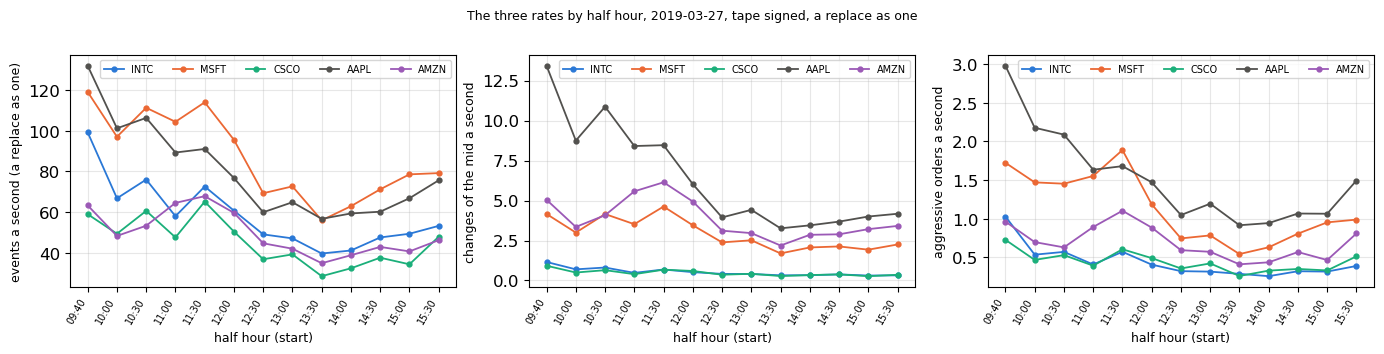

In [9]:
# Section 1: the three rates by half hour, a panel a rate, a line a stock, one y-axis a panel. The half hours are
# unequal: the first and the last are twenty minutes of the session, and the first holds the open's burst.
TAPE_PANELS = (
    ('events by block, as one', 'events a second (a replace as one)'),
    ('mid changes by block, as one', 'changes of the mid a second'),
    ('aggressive orders by block', 'aggressive orders a second'),
)


def tape_figure(results, day=DAY):
    fig, axes = plt.subplots(1, len(TAPE_PANELS), figsize=(14, 3.6))
    for ax, (key, ylabel) in zip(axes, TAPE_PANELS, strict=True):
        plot_strips(results, lambda r, key=key: r['tape'][key], ylabel, ax=ax)
        tidy_axes(ax)  # thirteen start times in a third of a page
    fig.suptitle(figure_title('The three rates by half hour', results, day), fontsize=9)
    plt.tight_layout()
    plt.show()


if need(DAY):
    tape_figure(tape_results)

**What each stock-day holds (2019-03-27).** The tables above are one row a stock for the first day, in the order INTC, MSFT, CSCO, AAPL and AMZN. NVDA and CMCSA, the exploration stocks the code was built on, are not in them. A stock-day at a time, in the tables' own terms (the hidden and unsigned shares are shares of executed shares; the time at each spread is the share of the session's once-a-second samples; the rates are a second, with a replace counted as one and as two):

- *INTC.* 8.6% hidden and 6.6% unsigned. One tick for 99.8% of the session, two ticks for 0.2%, three ticks or more for 0.0%. Events 57.540 as one and 61.302 as two, changes of the mid 0.515 and 0.515, aggressive orders 0.425.
- *MSFT.* 9.6% hidden and 6.6% unsigned. One tick 89.8%, two ticks 10.2%, three or more 0.0%. Events 86.367 and 92.887, changes of the mid 2.899 and 2.899, aggressive orders 1.121.
- *CSCO.* 11.2% hidden and 8.4% unsigned. One tick 99.6%, two ticks 0.4%, three or more 0.0%. Events 44.865 and 48.203, changes of the mid 0.463 and 0.463, aggressive orders 0.434.
- *AAPL.* 11.1% hidden and 8.3% unsigned. One tick 20.7%, two ticks 48.5%, three or more 30.7%. Events 78.733 and 84.390, changes of the mid 6.246 and 6.252, aggressive orders 1.481.
- *AMZN.* 25.6% hidden and 18.2% unsigned. One tick 0.0%, two ticks 0.0%, three or more 100.0%, with a median spread of 52 ticks and a mean of 53.30. Events 49.512 and 53.606, changes of the mid 3.808 and 3.898, aggressive orders 0.684.

The table prints one rate of aggressive orders: the frames' groups with a displayed execution (the check line under the table says each count equals them), with no "as one" and "as two". Counting a replace as two changes the events a second on every stock-day, and changes the changes of the mid a second, at the printed digits, only on AAPL (6.246 and 6.252) and AMZN (3.808 and 3.898). These are the figures each stock-day printed. They say what each day looked like in these terms and no more: no stock is labeled by a regime, no two stocks are said to differ, and no stock's rate is set beside another's.

**The half hours are unequal.** The last table of the block gives, for each stock-day, the busiest half hour's events a second over the quietest's: 2.50 (INTC), 2.13 (MSFT), 2.29 (CSCO), 2.33 (AAPL) and 1.94 (AMZN). The first half hour's (twenty minutes, from 09:40) over the median half hour's is 1.86 (INTC), 1.50 (MSFT), 1.24 (CSCO), 1.74 (AAPL) and 1.37 (AMZN). The same busiest-over-quietest ratio for changes of the mid runs from 2.73 to 4.12 and for aggressive orders from 2.69 to 4.01 (the table has each stock's). The strip of events a second by half hour, drawn in the figure, shows where they fall: the quietest half hour is the one that starts at 13:30 on all five stock-days, and the busiest is the first on INTC (99.2), MSFT (119.1) and AAPL (132.0) and the one that starts at 11:30 on CSCO (65.2) and AMZN (67.8). The block bootstrap of the later sections resamples the half hours as if they were exchangeable, and these ratios say they are not. Its standard error is therefore printed under the label "ASSUMING EXCHANGEABLE BLOCKS" and is never the uncertainty of the stock. Where a second figure is printed beside it, that figure is a different calculation over the same 13 half hours, and it is no truer. For the imbalance's lift the paired one is in section 7 (Table 7b, asked for after the run and judged by no rule).

**The conversion's checks.** The table of required counts has 16 checks a stock, and the cell's last line reads "Every one of the 80 required counts is 0 (their sum is 0)". A stock-day with a required count that is not 0 would be refused and left out of everything after it, and none was. A count of 0 is what the file's own rules require of a replayed book: every execute, cancel and delete named a live order, no book was crossed or locked, the touch was never under a dollar or off the cent grid, and every non-printing execution was paired. Beneath it:

- *What the file holds that is not an error.* Adds under a dollar: 18 (INTC), 29 (MSFT), 26 (CSCO), 64 (AAPL) and 43 (AMZN). Adds off the cent grid: 2, 5, 4, 9 and 5.
- *The premises of the reading.* A hidden trade says 'B' as its side whatever its aggressor, and the count of those that say anything else (`p_side_not_b`) and of those that name an order (`p_with_reference`) is 0 on all five. `c_price_over_a_cent`, an execution with a price more than a cent from its order's displayed price, is 0 on INTC, MSFT, CSCO and AAPL and **1 on AMZN**. The cell prints this line without a flag, and its closing sentence covers the required counts and not this one, so it is said here. Table 7g (section 7, asked for after the run and judged by no rule) lists it: the execution is at 16:00:00.770, after the frames' window of 09:30 to 16:00 and so outside the session, 3.00 cents from its order's displayed price, on 87 shares, and the table counts it as not printable (a C that is not printed as an execution, whose price reaches no figure of this notebook). None is in the session on any of the ten stock-days. Section 6 prints the same count for the second day, 15 on AAPL and 23 on AMZN, and Table 7g has them: all 15 of AAPL's are at 16:00:00.641, and AMZN's run from 09:30:00.472 (two are inside the window, none in the session) to 16:00:00.347, and all 23 are not printable. So no printable execution is more than a cent from its order's displayed price on any of the ten stock-days. What the count holds are executions that do not print.
- *What the stream did*, over the whole pass from the opening cross at 09:30:00 to 3 s past the session's end and not the session alone. One break on each stock-day, the opening cross (`break_cross` 1; `break_cross_execution` 0 and `break_halt` 0), and no crossed quote. Interleaved rows (deletions and cancels of part that lie between the executions of one aggressive order and stay inside its event): 66 (INTC), 232 (MSFT), 109 (CSCO), 34 (AAPL) and 6 (AMZN). Paired reductions (the non-printing half of a trade between two displayed orders): 27, 210, 17, 7 and 0 rows, of which 0, 3, 0, 0 and 0 are an event of their own. No hidden orphans. One event with no event before it to take its quotes from (`unknown_before`) on each of MSFT, CSCO, AAPL and AMZN, and none on INTC.

**What the checks do not show.** A count of 0 says the replayed book followed ITCH's rules at every message. It does not say the frames equal the exchange's book. Before the run that had been checked against two independent decoders on the exploration stocks only. After the first run, the review of the run, outside the notebook, decoded and replayed the raw messages of all ten stock-days with code that shares nothing with `lob.itch` and `lob.feeds`. On those 14.66 million rows the time, type and best quotes agreed at every row, and the ten levels at all 11,903 sampled rows, and the second day's five extracts are byte for byte what an independent pass over the day's file gives. That check is the review's, not the notebook's: no cell of the notebook prints it.

**What the tape is not a measure of.** The rates depend on how a replace is counted (one or two) and on how executions are grouped into aggressive orders (adjacent executions at one nanosecond with consecutive match numbers), and the printed rates are for these conventions.

**Time, memory and a warning.** The cell's time and memory lines are the fourth run's: 5.8 core-minutes and a worker peak of 8,037 MB (MSFT), against 5.8 and 6,170 MB in the first run, so a time or a memory figure is not the same from one run to the next. A joblib warning, "A worker stopped while some jobs were given to the executor", means that a worker process was restarted; in the outputs shown it is printed under the run cell of section 6 (cell 82) and not under this one, and every measurement this cell printed is the first run's to the digit.

**What this cannot show.**

- *One day of each stock.* The table describes a stock on the day named in its heading. It does not say what the stock is like on other days, labels no stock as a regime, and does not say that any two of the five stocks differ: they share the day's market factor.
- *Hidden volume is counted and not signed.* The hidden share of executed shares is the shares executed against non-displayed orders; the unsigned share is the part of it in runs with no displayed execution beside it, whose aggressor is not known. Nothing here says who the aggressor of that volume was, and no accuracy later in the notebook "against the true side" includes it.
- *Rates are for conventions.* A replace counted as one gives fewer events than as two, and a different grouping of executions (adjacent at one nanosecond, or merged within 100 microseconds) gives other counts of aggressive orders. Events a second of a real stream and events a unit of the simulator are not the same count: a unit here is a second, a unit there is the simulator's own.
- *The checks are the file's own.* A count of 0 means the replayed book followed ITCH's rules at every message (every execute, cancel and delete named a live order; no crossed or locked book). It does not mean that the frames are the exchange's book. At the freeze that had been checked against two independent decoders on the exploration stocks only; the review of the run, outside the notebook, then checked all ten stock-days (above), and no cell of the notebook prints that check.

## Section 2: The simulator's findings, on real books

**The question.** Notebook 14 measured six signals that order books are said to carry in the simulator, against truths that the simulator knows. This section asks of each finding: **does it appear on real books?** Every finding is set out the same way. The figure is a stock's on the day it is of, with its half-hour strip, the three rates beside it (events, changes of the mid and aggressive orders a second) and the convention named (the tape, and a replace counted as one). Beside it is notebook 14's figure for the simulator, quoted from its saved output with its seeds. A figure near the simulator's is a description: nothing here is called a match, and nothing says that the simulator matches a market. Where a prediction was written before any reported stock was read, its verdict for each stock is printed under the table (the rules are in the predictions cell, and the conclusions count the stocks that pass on each day). The first half of the section, which follows, is the queue imbalance and the next move, the queue race and order flow imbalance; the second half is VPIN, order-to-trade ratios and resilience.

### The queue imbalance and the next move

**What notebook 14 found** (its seeds 101 to 108). The imbalance of the top `levels` price levels of each side, (B - A) / (B + A), positive when the bid side is heavier, is read after each change of the mid at the first event that leaves the mid alone and gives a nonzero value, and its sign is scored against the direction of the next change. It is scored against two baselines, 50% and the reversal rate (predict minus the last change), and the lift is the hit rate less the better of the two. In ZI the L 1 imbalance (the queue imbalance at the touch) hit 71.1% (se 0.1) on 13,014 changes scored a run, against a reversal rate of 63.9% (se 0.1), a lift of 7.2 points (se 0.1); the lifts over the better baseline were 5.6 to 11.1 points in the five models, and 50% alone flattered them (16.9 to 21.8 points). By the spread at the reading, the one-tick hit rate was high (89.1% in ZI) but so was the reversal rate (87.0%), so the one-tick lift was small (2.2 points in ZI; 1.9 to 2.3 in the four models other than Parlour; 8.3 in Parlour) against 6.9 to 11.5 points wider. Beyond the touch, equal weights lost to the reversal baseline (below 0 in 13 of 15 cells, down to -7.5 points at L 10) and touch weights repaired that only in part (0.5 to 4.3 points).

**The reading and the baseline.** The same reading is taken from the real book, a replace counted as one change of the book, a next change within 30 seconds, sizes in shares with odd lots counted. The baseline is **taken within each spread class at the reading**, never before the classes are pooled: the reversal rate at a spread of one tick is not the reversal rate at two ticks, and a pooled lift is a mixture of the two (in the exploration, with a replace counted as one, CMCSA's pooled lift was 14.8 points where its lift over the better baseline was -0.3 points at one tick and +9.7 at two ticks), so no pooled lift is printed here as a stock's figure. A class with fewer than 200 readings is a count only.

**What the run showed about the reading.** The strict design is meant to give a reading only to an event that leaves the mid alone. A replace counted as one change of the book is handed to the studies a second time, as an event that changes nothing (its echo), and the imbalance collector does not skip it. When a replace moves the mid, the strict design can therefore take its reading from that echo, which carries the replace's own state after the change, the state that only the inclusive design is meant to read. The reviews of the run found this after the verdicts. The frozen code was left as it ran, and every figure of this section is as run. Table 7a in section 7, which was asked for after the run and is judged by no rule, prints how many readings were taken at an echo and the figures with the echo giving none.

**What the exploration stocks showed** (exploration: NVDA and CMCSA on the first day, which the code was built on, never reported as results; a replace counted as one). NVDA at L 1: 909 readings at one tick (the spread was one tick for 0.3% of the session), hit 66.0%, reversal rate 55.8%; 1,804 at two ticks, 60.6% and 49.1%; 49,760 at three ticks or more, 56.3% and 48.1%. CMCSA: 3,488 readings at one tick (99.8% of the session), 70.2% and 70.5%; 2,991 at two ticks, 59.7% and 27.2%; 7 at three or more, a count only. In the ladder exploration (section 4) the one-tick figures changed when the stream was cut to one state a millisecond, because the states they read can last under a millisecond: that is a statement about these two stocks on that day, and it is not carried over to feeds in general.

**What is run.** Nothing new: the readings are in each stock's `measure` result from section 1's run. The tables are L 1 by spread class with its binding baseline and the three rates beside it, the imbalance beyond the touch (levels 3, 5 and 10, equal and touch weights) with the share of changes dropped, and the half-hour strips with the figure that draws them. The predictions that read these tables are the hit rate, the reversal rate and the one-tick lift.

In [10]:
# Section 2, the first half (the imbalance and the next move, the queue race, order flow imbalance): what its cells
# share. Everything here is a function of a dict of measure() results by stock (a day's: measured(DAY), or
# SECOND_DAY's), so that section 6 prints the second day with the same code. Names are prefixed imb_ (the queue race's
# too) and ofi_. This cell needs the setup only; it prints one line.
IMB_SPLIT_NOTE = {  # the note notebook 14 printed before its table of a setting by the spread at the reading
    'L 1 equal': 'By the spread at the reading, L 1',
    'L 10 touch': 'By the spread at the reading, touch L 10',
}
IMB_NUMBER = re.compile(r'[+-]?[\d,]*\.?\d+(?: \([\d.]+\))?')
IMB_MODEL_ROW = re.compile(r'^(?:(\d+) units)?\s+(ZI|Hawkes ZI|MF 2008|Parlour|Informed ZI)\s+(.*)$')
IMB_RACE_ROW = re.compile(
    r'^(?:(ZI|Hawkes ZI|MF 2008|Parlour|Informed ZI)\s+)?\s*(all|one tick|two ticks|three or more)\s+(.*)$'
)
IMB_OFI_BLOCKS = (  # the heading of each block of columns of notebook 14's order-flow table, and what its cells are
    ('intervals a run', ('intervals a run', 'same-interval R2')),
    ('OFI against the next change', ('OFI against the next change',)),
    ('the last change against the next', ('the last change against the next',)),
    ('OFI beyond the last change', ('OFI beyond the last change', 'OFI against the next OFI')),
)


def imb_rates(results):
    # the three rates beside every figure of a stock (rates_beside) and the share of the session at one tick: what each
    # figure below is set beside
    one_tick = {'time at one tick': lambda r: r['tape']['time at a spread of one tick, two, three or more'][0]}
    return rates_beside(results).join(stock_table(results, one_tick))


def imb_judge(results, tests):
    # the verdict of each of the predictions `tests` on each stock, as PREDICTIONS judges it (rules written before the
    # run)
    lines = []
    for stock, r in results.items():
        for test in tests:
            verdict = PREDICTIONS[test].judge(r)
            lines.append(f'  {stock:<6} {test:<22} {verdict.status:<11} {verdict.detail}')
    if results:  # a stock-day that was refused or failed is not judged, and is said to be
        lines += [f'{line} (not judged)' for line in unrun_lines(next(iter(results.values()))['day'], results)]
    return '\n'.join(lines)


IMB_COLUMNS = (
    'n',
    'hit %',
    'reversal %',
    'lift over 50% pp',
    'lift over reversal pp',
    'lift over the better pp',
    'binds',
    'calls differ %',
    'se, blocks',
    'se, hit less day baseline',
)
IMB_FORMATS = {
    'n': ',.0f',
    'hit %': '.1f',
    'reversal %': '.1f',
    'lift over 50% pp': '+.1f',
    'lift over reversal pp': '+.1f',
    'lift over the better pp': '+.1f',
    'calls differ %': '.1f',
    'se, blocks': '.1f',
    'se, hit less day baseline': '.1f',
}


def imb_class_table(results, setting='L 1 equal'):
    # A frame, a row for each stock and spread class: the readings, the hit rate and the reversal rate (percent), the
    # lift over 50%, over the reversal rate and over the better of the two (percentage points), and which baseline binds
    # IN THE CLASS; the share of readings at which the imbalance's call and the reversal call point in different
    # directions (the hit rate and the reversal rate differ by at most that much: where it is small they are one
    # measurement read twice); where the setting has a half-hour strip, the lift's block-bootstrap standard error
    # (ASSUMING EXCHANGEABLE BLOCKS) and, in the last column, the standard error across the half hours of each half
    # hour's hit rate less the day's baseline (not the lift's: each half hour's own reversal rate is not taken). A
    # class with under MIN_READINGS readings is its count only. The pooled row is not a figure of a stock and is not
    # here.
    rows = {}
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        for name in CLASSES:
            row = classes[(classes.setting == setting) & (classes['class'] == name)].iloc[0]
            n, strip = int(row['n']), r['imbalance']['strips'].get((setting, name))
            if n < MIN_READINGS:
                rows[stock, name] = {'n': n, 'binds': 'count only'}
                continue
            rows[stock, name] = {
                'n': n,
                'hit %': 100 * row['hit'],
                'reversal %': 100 * row['reversal'],
                'lift over 50% pp': 100 * row['lift over 50%'],
                'lift over reversal pp': 100 * row['lift over reversal'],
                'lift over the better pp': 100 * row['lift over the better'],
                'binds': row['binds'],
                'calls differ %': 100 * row['calls differ'],
                'se, blocks': 100 * strip['lift se'] if strip else math.nan,
                'se, hit less day baseline': 100 * strip['lift strip se'] if strip else math.nan,
            }
    return pd.DataFrame.from_dict(rows, orient='index', columns=list(IMB_COLUMNS))


def imb_check_classes(results, setting='L 1 equal'):
    # What must hold for the class table to mean anything: the classes' readings add up to the pooled row's and their
    # hits too; the lift over the better baseline is the smaller of the lifts over each (the baseline taken in the
    # class), and 'binds' names it; each half-hour strip's readings add up to its class's.
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        sub = classes[classes.setting == setting].set_index('class')
        parts = sub.loc[list(CLASSES)]
        pooled = sub.loc['pooled']
        assert parts.n.sum() == pooled['n'], f'{stock} {setting}: the classes do not add up to the readings'
        if pooled['n'] > 0:
            for key in ('hit', 'reversal'):
                total = float((parts.n * parts[key]).fillna(0).sum())  # a class with no reading has no rate
                assert math.isclose(total, pooled['n'] * pooled[key], rel_tol=1e-9), f'{stock} {setting}: {key}'
        for name, row in parts[parts.n > 0].iterrows():
            better = min(row['lift over 50%'], row['lift over reversal'])
            assert math.isclose(row['lift over the better'], better, abs_tol=1e-12), f'{stock} {name}: baseline'
            assert row['binds'] == ('reversal rate' if row['reversal'] > 0.5 else '50%'), f'{stock} {name}: binds'
        for name in CLASSES:
            strip = r['imbalance']['strips'].get((setting, name))
            if strip is not None:
                assert sum(strip['strip']['n']) == parts.loc[name, 'n'], f'{stock} {setting} {name}: strip n'


# ---- notebook 14's saved output, read as printed (the simulator's figure beside each real one) ----
def imb_nb14_outputs(path=NB14_PATH):
    # the text of each output of notebook 14's saved cells, in order; None if the notebook or its outputs are not there
    try:
        notebook = json.loads(Path(path).read_text())
    except FileNotFoundError:
        return None
    texts = []
    for cell in notebook['cells']:
        for out in cell.get('outputs', []):
            if out.get('output_type') == 'stream':
                texts.append(''.join(out.get('text', '')))
            else:
                texts.append(''.join(out.get('data', {}).get('text/plain', '')))
    return texts or None


def imb_nb14_split(setting):
    # Notebook 14's table of a setting by the spread at the reading (one tick, wider), a row a model, as printed (mean
    # over seeds 101 to 108 and, in brackets, its standard error across them); '-' where its saved output is not there.
    note = IMB_SPLIT_NOTE[setting]
    names = ('scored a run', 'hit %', 'reversal %', 'lift pp')
    columns = pd.MultiIndex.from_tuples([(label, name) for label in ('one tick', 'wider') for name in names])
    table = pd.DataFrame(
        {m: [notebook_14_printed(m, f'{label}: {name}', after=note) for label, name in columns] for m in NB14_MODELS},
        index=columns,
    ).T
    return table.fillna('-')


def imb_nb14_ofi(texts=None):
    # Notebook 14's order-flow table, {(interval in units, model): {column: text as printed}}: the setup's reader reads
    # the first model of a group only (the interval's name is on that row alone), so each row is read here with the
    # group's.
    texts = imb_nb14_outputs() if texts is None else texts
    out = {}
    for text in texts or []:
        if 'intervals a run' not in text:
            continue
        names, interval = None, None
        for line in text.splitlines():
            line = line.rstrip().removesuffix('\\').rstrip()
            for heading, columns in IMB_OFI_BLOCKS:
                if heading in line:
                    names = columns
            row = IMB_MODEL_ROW.match(line)
            if row and names:
                interval = int(row.group(1)) if row.group(1) else interval
                values = [m.group(0) for m in IMB_NUMBER.finditer(row.group(3))]
                if len(values) == len(names):
                    out.setdefault((interval, row.group(2)), {}).update(zip(names, values, strict=True))
    return out


def imb_nb14_race(texts=None):
    # Notebook 14's queue-race table, {(model, spread class): {column: text as printed}}, pooled over its eight seeds:
    # the readings, the hit rate, the log-likelihood gain over a constant for the curve at c = 1, the gain with a fitted
    # (and a), and the fit of both (a, c). Rows are read across the three blocks of columns it printed.
    texts = imb_nb14_outputs() if texts is None else texts
    out = {}
    for text in texts or []:
        if 'scored (all seeds)' not in text:
            continue
        model = None
        for line in text.splitlines():
            row = IMB_RACE_ROW.match(line.rstrip().removesuffix('\\').rstrip())
            if not row:
                continue
            model = row.group(1) or model
            rest, cells = row.group(3), out.setdefault((model, row.group(2)), {})
            both = re.match(r'(-?[\d,]+) \(a = ([\d.]+), c = ([\d.]+)\)$', rest)
            fitted = re.match(r'(-?[\d,]+) \(c = ([\d.e+-]+)\)\s+(-?[\d,]+) \(a = ([\d.]+)\)$', rest)
            if both:
                cells.update({'both: a': both.group(2), 'both: c': both.group(3)})
            elif fitted:
                cells.update({'gain, a fitted (c = 1)': fitted.group(3), 'a (c = 1)': fitted.group(4)})
            elif len(rest.split()) == 3:
                cells.update(zip(('scored (all seeds)', 'hit %', 'gain, c = 1'), rest.split(), strict=True))
    return out


print(
    'notebook 14\'s saved output: '
    + (
        f'{len(imb_nb14_ofi())} order-flow rows and {len(imb_nb14_race())} queue-race rows read.'
        if imb_nb14_outputs()
        else 'not in this checkout (the simulator\'s figures beside each real one are left out).'
    )
)

notebook 14's saved output: 20 order-flow rows and 20 queue-race rows read.


In [11]:
# Section 2, the imbalance and the next move: the touch (L 1) by the spread at the reading, the baseline within each
# class. Needs the imb_ helpers. With the data absent it prints one line.
def imb_show_split(results, setting='L 1 equal', day=DAY, what='L 1, the queue imbalance at the touch'):
    # a setting by the spread at the reading: the stocks' table, the three rates beside it and notebook 14's table of
    # the simulator beside that
    imb_check_classes(results, setting)
    heading(
        f'{what}: the next change of the mid against the sign of the first nonzero imbalance after the last',
        results,
        day,
    )
    say(
        f'Strict design (the first event that leaves the mid alone gives the reading), a next change within '
        f'{T_MAX:.0f} '
        's, by the spread at the reading. Lifts in points over 50%, over the reversal rate (predict minus the last '
        f'change) and over the better of the two, which binds IN THE CLASS; a class under {MIN_READINGS} readings is a '
        'count only. calls differ: the share of readings at which the imbalance\'s call and the reversal call point '
        'in different directions; the hit rate and the reversal rate cannot differ by more than that, so where it is '
        'small they are one measurement read twice and the lift over the reversal rate is bounded by it. se, blocks: '
        f'the lift\'s block-bootstrap standard error ({DRAWS:,} draws, ASSUMING EXCHANGEABLE BLOCKS). se, hit less day '
        'baseline: NOT the lift\'s standard error; it is the standard error across the half hours (their sd over the '
        'root of how many) of each half hour\'s hit rate less the day\'s baseline, the better of 50% and the day\'s '
        'reversal rate (the one "binds" names). It does not take each half hour\'s own reversal rate; the paired '
        'lift\'s standard error, which does, is in section 7.'
    )
    table = imb_class_table(results, setting)
    print(shown(table, IMB_FORMATS))
    for (stock, name), n in table.n.items():
        if n < MIN_READINGS:
            print(f'  {stock}, {name}: {count_line(n)}')
    print('\nThe three rates beside (a replace as one), session:')
    print(shown(imb_rates(results), RATE_FORMATS | {'time at one tick': '.1%'}))
    say(
        f'\n{NB14_SEEDS}, {setting} by the spread at the reading, the simulator (mean over seeds, se across seeds in '
        'brackets):'
    )
    print(imb_nb14_split(setting).to_string())
    return table


if need(DAY):
    imb_results = measured(DAY)
    imb_l1 = imb_show_split(imb_results)
    print('\nThe predictions that read this table (written before the run), by stock:')
    print(imb_judge(imb_results, ('hit rate', 'reversal rate', 'one-tick lift')))


L 1, the queue imbalance at the touch: the next change of the mid against the sign of the first nonzero imbalance after
the last: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
Strict design (the first event that leaves the mid alone gives the reading), a next change within 30 s, by the spread at
the reading. Lifts in points over 50%, over the reversal rate (predict minus the last change) and over the better of the
two, which binds IN THE CLASS; a class under 200 readings is a count only. calls differ: the share of readings at which
the imbalance's call and the reversal call point in different directions; the hit rate and the reversal rate cannot
differ by more than that, so where it is small they are one measurement read twice and the lift over the reversal rate
is bounded by it. se, blocks: the lift's block-bootstrap standard error (1,000 draws, ASSUMING EXCHANGEABLE BLOCKS). se,
hit less day baseline: NOT the lift's standard error; it is the standard error

                one tick                                           wider                                    
            scored a run       hit %  reversal %    lift pp scored a run       hit %  reversal %     lift pp
ZI                 3,476  89.1 (0.2)  87.0 (0.3)  2.2 (0.1)        9,538  64.5 (0.1)  55.5 (0.1)   9.0 (0.2)
Hawkes ZI          2,936  90.1 (0.2)  88.3 (0.2)  1.9 (0.1)        8,780  65.6 (0.2)  56.3 (0.2)   9.3 (0.3)
MF 2008            1,300  84.3 (0.5)  82.0 (0.4)  2.3 (0.2)        3,443  60.3 (0.3)  53.4 (0.3)   6.9 (0.4)
Parlour            1,313  80.2 (0.3)  71.9 (0.6)  8.3 (0.4)        7,876  67.0 (0.2)  55.5 (0.2)  11.5 (0.3)
Informed ZI        3,696  90.6 (0.1)  88.5 (0.2)  2.1 (0.1)       12,615  65.7 (0.1)  56.4 (0.2)   9.3 (0.2)

The predictions that read this table (written before the run), by stock:
  INTC   hit rate               passed      one tick 62.0% of 5,780 (reversal rate 63.5%, above 50%: not judged); two ticks 60.7% of 4,855 (reversal rate 23.1%); o

**L 1 by the spread at the reading (2019-03-27).** The first table scores the sign of the imbalance at the touch against the direction of the next change of the mid, in each class of the spread at the reading, and the lift in each class is the hit rate less that class's own better baseline: 50% or the class's reversal rate, whichever is higher, which the column `binds` names. Nothing is pooled over classes. A class under 200 readings is a count only. Stock by stock, readings, hit rate, reversal rate, the lift over the better baseline and the baseline that binds:

- *INTC.* One tick: 5,780 readings, hit 62.0%, reversal rate 63.5%, lift -1.5 points, the reversal rate binds. Two ticks: 4,855, 60.7%, 23.1%, +10.7, 50% binds. Three or more: 1 reading.
- *MSFT.* One tick: 31,996, 69.1%, 69.0%, +0.0, the reversal rate binds. Two ticks: 25,071, 57.8%, 38.6%, +7.8, 50% binds. Three or more: 146 readings.
- *CSCO.* One tick: 5,151, 67.6%, 67.5%, +0.0, the reversal rate binds. Two ticks: 4,266, 55.8%, 15.5%, +5.8, 50% binds. Three or more: 8 readings.
- *AAPL.* One tick: 23,341, 59.4%, 47.5%, +9.4, 50% binds. Two ticks: 45,966, 56.7%, 46.8%, +6.7, 50% binds. Three or more: 45,177, 54.2%, 45.6%, +4.2, 50% binds.
- *AMZN.* Three or more: 67,851, 50.4%, 46.9%, +0.4, 50% binds. One tick: 40 readings. Two ticks: 33 readings.

**What the class's own baseline changed.** Against 50% alone the three one-tick classes whose reversal rate is above 50% would have read +12.0 (INTC), +19.1 (MSFT) and +17.6 points (CSCO), the table's "lift over 50%" column. Against the reversal rate they read -1.5, +0.0 and +0.0. A class whose reversal rate is above 50% is judged against the reversal rate, and where the reversal rate is above the hit rate (INTC at one tick, 63.5% against 62.0%) the lift is below 0. The column "calls differ" says how far the two rates can part: the hit rate and the reversal rate cannot differ by more than the share of readings at which the imbalance's call and the reversal call point in different directions. That share is 1.2% of MSFT's one-tick readings and 0.4% of CSCO's, so on those two classes the hit rate and the reversal rate are one measurement read twice (69.1% and 69.0%, 67.6% and 67.5%) and the lift over the reversal rate is bounded by that share. On INTC's one-tick class the calls differ at 8.9% of readings, the lift is -1.49 points (95% block-bootstrap interval -2.30 to -0.76, printed under the table), and the one-tick lift rule, which asks for the interval to lie inside -1 to +1, is not passed. On INTC, MSFT and CSCO, where one tick holds 99.8%, 89.8% and 99.6% of the time, the imbalance's one-tick hit rate is therefore not clearly above the reversal rate: 62.0% against 63.5% (INTC), 69.1% against 69.0% (MSFT) and 67.6% against 67.5% (CSCO). AAPL's one-tick reversal rate is 47.5%, below 50%, so 50% binds there and the lift over the reversal rate is the table's +11.9; one tick holds 20.7% of AAPL's time, and the three rules gated on one tick holding more than half the time (the reversal rate, the one-tick lift and the queue race) do not judge it. The table does not show that the imbalance beats the reversal rate at one tick on the three stocks that spend nearly all their time there. Section 7 (Table 7a) recomputes these readings with a replace's echo giving none, and Table 7c splits them by how long the spread state lasted; both were asked for after the run and are judged by no rule.

**The table's two standard errors.** "se, blocks" is the lift's block-bootstrap standard error (1,000 draws, assuming exchangeable half hours): 0.4 (INTC one tick), 0.1 (MSFT), 0.1 (CSCO), 0.3 (AAPL one tick). The column "se, hit less day baseline" is **not** the lift's standard error. The first run's table called it "se, strip" and its caption described it as the lift's standard error, and the review of the run showed that this was wrong: it is the standard deviation across the half hours of each half hour's hit rate less the day's baseline, over the root of how many, and it does not take each half hour's own reversal rate. The paired lift's standard error, which does, is Table 7b of section 7 (asked for after the run and judged by no rule), where the three are set side by side. The rule reads the bootstrap interval, which the relabeling does not touch.

**The simulator beside L 1 (notebook 14, seeds 101 to 108).** Notebook 14's L 1 lifts by the spread at the reading, in the last table above: in ZI 2.2 points (se 0.1) at one tick and 9.0 (se 0.2) at wider spreads. Over its five models the one-tick lift runs from 1.9 to 8.3 (Parlour) and the wider lift from 6.9 to 11.5. Its one-tick reversal rates are 71.9 to 88.5% and its one-tick hit rates 80.2 to 90.6%, so the real one-tick hit rates (59.4 to 69.1%) are far below the simulator's and the real one-tick reversal rates (47.5 to 69.0%) are below its lowest, 71.9%. Every real stock's classes are those of its own spread and not the simulator's, so these are not like for like. The simulator's ordering is a small one-tick lift, a larger lift at two ticks or more and a one-tick reversal rate above the wider classes'. In each stock's table:

- *INTC.* The ordering appeared: the one-tick lift (-1.5) is below the two-tick lift (+10.7), and the one-tick reversal rate (63.5%) is above the two-tick rate (23.1%). The one-tick lift is below the simulator's range of 1.9 to 8.3 and the two-tick lift is inside its wider range. No three-or-more class has 200 readings.
- *MSFT.* The ordering appeared: +0.0 at one tick against +7.8 at two, and a one-tick reversal rate of 69.0% against 38.6%. The one-tick lift is below the simulator's range and the two-tick lift inside its wider range, though 55.0% of MSFT's two-tick readings are in the band under 1 ms (lift +37.44) and 19.1% in spells of 100 ms or more (-3.07, interval -4.42 to -1.99; Table 7c). No three-or-more class (146 readings).
- *CSCO.* The ordering appeared: +0.0 against +5.8, and 67.5% against 15.5%. The two-tick lift is near the simulator's wider range, just under its lowest value of 6.9. No three-or-more class (8 readings).
- *AAPL.* The lifts fall from one tick to three or more (+9.4, +6.7, +4.2). AAPL's first day (6.246 changes of the mid a second) lies above the simulator's range of 1.48 to 5.06 and is not set against its ordering. The one-tick reversal rate (47.5%) is above the two-tick (46.8%) and the three-or-more (45.6%) rates by 0.7 and 1.9 points, a plain difference of the printed rates, and none is above 50%.
- *AMZN.* The one-tick and two-tick classes have 40 and 33 readings, so the ordering cannot be read. The three-or-more class has a lift of +0.4 and a reversal rate of 46.9%.

All of this is description: nothing here is called a match, and the simulator's lifts are at its own rates (the cells above print events, changes of the mid and aggressive orders a second beside the table, and section 0 prints the simulator's per unit).

**The three predictions that read this table, stock by stock** (printed under it; the rules are in the predictions cell). The five stocks share the day's market factor, so no count below is five independent results.

- *Hit rate* (above 50% in every class with 200 readings or more in which the reversal rate is 50% or less). Judged on all five and passed on all five. INTC: two ticks 60.7% of 4,855 (its one-tick class, with a reversal rate of 63.5%, is not judged). MSFT: two ticks 57.8% of 25,071 (one tick not judged, reversal rate 69.0%). CSCO: two ticks 55.8% of 4,266 (one tick not judged, reversal rate 67.5%). AAPL: one tick 59.4% of 23,341, two ticks 56.7% of 45,966 and three or more 54.2% of 45,177. AMZN: three or more 50.4% of 67,851. AMZN's verdict sits on its line: its margin line in section 6's verdict table puts 50.4% at +1.0 se above 50 (se 0.4, block bootstrap), with half hours from 47.7% to 52.2%.
- *Reversal rate* (above 50% at one tick and below 50% at two, where one tick holds more than half the time). Judged on INTC, MSFT and CSCO, and passed on all three: INTC 63.5% at one tick and 23.1% at two, MSFT 69.0% and 38.6%, CSCO 67.5% and 15.5%. Not judged on AAPL (one tick holds 20.7% of the time) and AMZN (0.0%). INTC's and CSCO's two-tick classes are read mostly in spells that end within a millisecond (Table 7c: 91.9% of the two-tick readings of each are in the band under 1 ms), so their two-tick rates describe states that do not last and not two-tick spreads that do.
- *One-tick lift* (the 95% block-bootstrap interval of the lift over the reversal rate lies inside -1 to +1 point, where one tick holds more than half the time). Judged on the same three. Passed on MSFT (+0.03 points of 31,996 readings, interval -0.10 to +0.14) and CSCO (+0.02 of 5,151, interval -0.20 to +0.26). Not passed on INTC (-1.49 of 5,780, interval -2.30 to -0.76). INTC's verdict sits on its line: the interval's upper end, -0.76, is inside the line of -1 and its lower end, -2.30, is outside it. Not judged on AAPL and AMZN. The passes of MSFT and CSCO say little about the imbalance, because on those classes the two calls differ at 1.2% and 0.4% of readings and the lift is bounded by that. Under the rule as it was first written, "within 3 points of 0", INTC's -1.5 would have been inside the rule's 3 points; the predictions cell says why the rule was changed before any reported stock was read, and section 7 (item h, asked for after the run and judged by no rule) prints what the earlier rules would have said.

In [12]:
# Section 2, the imbalance beyond the touch (levels 3, 5 and 10, equal and touch weights), and the changes of the mid
# that are dropped (no reading before the next change, or a next change more than T_MAX later). Needs the imb_ helpers.
# With the data absent it prints one line.
IMB_BEYOND = [setting for setting in SETTINGS if not setting.startswith('L 1 ')]  # L 1 equal and touch are one number
IMB_LIFT_NOTE = 'The lift in pp (over the better of the reversal rate and 50%) at every setting'
IMB_DROPPED_NOTE = 'The share of the changes of the mid dropped'


def imb_beyond_table(results):
    # A frame, a row for each stock and setting beyond L 1 and a column for each spread class: the lift over the better
    # baseline in points, and in brackets the baseline that binds in the class (rev: the reversal rate, 50: 50%) and the
    # readings; a class under MIN_READINGS readings is its count only.
    rows = {}
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        for setting in IMB_BEYOND:
            cells = {}
            for name in CLASSES:
                row = classes[(classes.setting == setting) & (classes['class'] == name)].iloc[0]
                n = int(row['n'])
                if n < MIN_READINGS:
                    cells[name] = f'n = {n:,}'
                else:
                    baseline = 'rev' if row['binds'] == 'reversal rate' else '50'
                    cells[name] = f'{100 * row["lift over the better"]:+.1f} ({baseline}, {n:,})'
            rows[stock, setting] = cells
    return pd.DataFrame.from_dict(rows, orient='index', columns=list(CLASSES))


def imb_dropped_table(results):
    # A frame, a row a stock: the share (percent) of the changes of the mid with no reading before the next change at
    # each setting (strict design), those whose next change came more than T_MAX later at L 1, and the share with no
    # reading in the inclusive design (where the change event's own state can give the reading), at L 1 and touch L 10
    rows = {}
    for stock, r in results.items():
        strict = r['imbalance']['dropped'].set_index('setting')
        inclusive = r['imbalance']['dropped, inclusive'].set_index('setting')
        row = {setting: 100 * strict.loc[setting, 'no reading'] for setting in SETTINGS}
        row[f'late (T {T_MAX:.0f}), L 1'] = 100 * strict.loc['L 1 equal', 'late']
        row['inclusive L 1'] = 100 * inclusive.loc['L 1 equal', 'no reading']
        row['inclusive touch L 10'] = 100 * inclusive.loc['L 10 touch', 'no reading']
        rows[stock] = row
    return pd.DataFrame.from_dict(rows, orient='index')


def imb_show_beyond(results, day=DAY):
    for setting in IMB_BEYOND:
        imb_check_classes(results, setting)
    heading(
        'The imbalance beyond the touch: the lift over the better baseline, by the spread at the reading', results, day
    )
    say(
        'Levels 3, 5 and 10 with equal and touch weights (L 1 equal and touch are one number: the first level\'s '
        'weight is 1). Points; in brackets the baseline that binds in the class (rev: the reversal rate, 50: 50%) and '
        f'the readings; a class under {MIN_READINGS} readings is a count only.'
    )
    print(imb_beyond_table(results).to_string())
    print('\nThe changes of the mid that are dropped (percent of the changes), by setting and design, session:')
    dropped = imb_dropped_table(results)
    print(shown(dropped, {column: '.1f' for column in dropped.columns}))
    say(
        f'\n{NB14_SEEDS}, the simulator: the lift over the better baseline at every setting, EVERY SPREAD POOLED as '
        'notebook 14 printed it (no pooled lift is printed for a stock here), and the share dropped (mean over seeds, '
        'se in brackets):'
    )
    print(nb14_table(SETTINGS, after=IMB_LIFT_NOTE).to_string())
    print(nb14_table(list(dropped.columns), after=IMB_DROPPED_NOTE).to_string())
    say(f'\n{NB14_SEEDS}, touch L 10 by the spread at the reading (the split it printed for L 1 and touch L 10 only):')
    print(imb_nb14_split('L 10 touch').to_string())


if need(DAY):
    imb_results = measured(DAY)
    imb_show_beyond(imb_results)


The imbalance beyond the touch: the lift over the better baseline, by the spread at the reading: 2019-03-27, session
09:40:00 to 15:50:00, tape signed, a replace as one.
Levels 3, 5 and 10 with equal and touch weights (L 1 equal and touch are one number: the first level's weight is 1).
Points; in brackets the baseline that binds in the class (rev: the reversal rate, 50: 50%) and the readings; a class
under 200 readings is a count only.
                            one tick          two ticks      three or more
INTC L 3 equal     -4.9 (rev, 5,780)   +9.1 (50, 4,855)              n = 1
     L 3 touch     -1.9 (rev, 5,780)  +10.6 (50, 4,855)              n = 1
     L 5 equal     -7.8 (rev, 5,780)   +9.8 (50, 4,855)              n = 1
     L 5 touch     -2.0 (rev, 5,780)  +10.8 (50, 4,855)              n = 1
     L 10 equal   -10.6 (rev, 5,780)   +7.2 (50, 4,855)              n = 1
     L 10 touch    -2.1 (rev, 5,780)  +10.7 (50, 4,855)              n = 1
MSFT L 3 equal    -4.2 (rev, 31,99

              L 1 equal   L 1 touch   L 3 equal  L 3 touch   L 5 equal  L 5 touch  L 10 equal L 10 touch
ZI            7.2 (0.1)   7.2 (0.1)  -1.2 (0.1)  1.4 (0.1)  -1.7 (0.1)  1.4 (0.1)  -2.1 (0.1)  1.4 (0.1)
Hawkes ZI     7.4 (0.2)   7.4 (0.2)  -0.0 (0.2)  3.2 (0.2)  -1.1 (0.2)  2.9 (0.2)  -1.8 (0.2)  2.9 (0.2)
MF 2008       5.6 (0.3)   5.6 (0.3)  -0.8 (0.2)  1.3 (0.2)  -0.8 (0.3)  1.7 (0.2)  -7.5 (0.1)  2.2 (0.2)
Parlour      11.1 (0.2)  11.1 (0.2)   2.1 (0.2)  4.3 (0.1)   0.1 (0.2)  3.6 (0.1)  -4.1 (0.1)  3.7 (0.2)
Informed ZI   7.7 (0.2)   7.7 (0.2)  -2.5 (0.2)  0.8 (0.2)  -3.7 (0.2)  0.5 (0.2)  -3.8 (0.2)  0.7 (0.2)


              L 1 equal   L 1 touch   L 3 equal   L 3 touch   L 5 equal   L 5 touch  L 10 equal  L 10 touch late (T 30), L 1 inclusive L 1 inclusive touch L 10
ZI           17.3 (0.1)  17.3 (0.1)   8.4 (0.1)   8.2 (0.1)   8.3 (0.1)   8.2 (0.1)   8.2 (0.1)   8.2 (0.1)    0.000 (0.000)    10.2 (0.1)            0.0 (0.0)
Hawkes ZI    19.8 (0.3)  19.8 (0.3)  10.8 (0.2)  10.6 (0.2)  10.8 (0.2)  10.6 (0.2)  10.7 (0.2)  10.6 (0.2)    0.000 (0.000)    10.9 (0.2)            0.0 (0.0)
MF 2008      18.1 (0.2)  18.1 (0.2)  12.3 (0.2)  12.0 (0.1)  12.3 (0.1)  12.0 (0.1)  12.2 (0.1)  12.0 (0.1)    0.000 (0.000)     7.7 (0.1)            0.0 (0.0)
Parlour      52.8 (0.1)  52.8 (0.1)  40.8 (0.1)  39.5 (0.1)  40.3 (0.1)  39.4 (0.1)  40.3 (0.1)  39.4 (0.1)    0.000 (0.000)    25.9 (0.1)            0.0 (0.0)
Informed ZI  20.8 (0.2)  20.8 (0.2)  10.6 (0.1)  10.4 (0.1)  10.5 (0.1)  10.4 (0.1)  10.5 (0.1)  10.4 (0.1)    0.000 (0.000)    12.0 (0.1)            0.0 (0.0)

notebook 14, seeds 101 to 108, touch L 

                one tick                                            wider                                   
            scored a run       hit %  reversal %     lift pp scored a run       hit %  reversal %    lift pp
ZI                 4,337  73.5 (0.2)  79.6 (0.3)  -6.0 (0.3)       10,112  59.9 (0.1)  55.2 (0.1)  4.7 (0.1)
Hawkes ZI          3,605  75.9 (0.2)  81.1 (0.3)  -5.2 (0.3)        9,448  61.9 (0.2)  55.9 (0.2)  6.0 (0.2)
MF 2008            1,522  73.4 (0.4)  76.4 (0.4)  -3.0 (0.3)        3,576  57.6 (0.3)  53.1 (0.3)  4.5 (0.3)
Parlour            1,993  63.1 (0.3)  64.7 (0.3)  -1.5 (0.4)        9,787  59.3 (0.1)  54.5 (0.1)  4.7 (0.2)
Informed ZI        4,803  72.1 (0.4)  80.4 (0.2)  -8.2 (0.3)       13,633  59.8 (0.1)  55.9 (0.2)  3.9 (0.2)



L 1 equal: the lift by half hour and spread class, its standard errors: 2019-03-27, session 09:40:00 to 15:50:00, tape
signed, a replace as one.
Points; the lift is the hit rate less the better of 50% and the class's reversal rate for the day, in each half hour too
(so "half hours above 0" counts against the line of the class's own lift; "above 0, own baseline" counts against each
half hour's own better baseline, a higher line on average); se, blocks: block bootstrap ASSUMING EXCHANGEABLE BLOCKS;
se, hit less day baseline: NOT the lift's standard error but the sd over the root of the half hours with readings of
each half hour's hit rate less the day's baseline (the better of 50% and the day's reversal rate), which does not take
the half hour's own reversal rate; the paired lift's standard error is in section 7.
                         n lift pp se, blocks se, hit less day baseline half hours above 0 above 0, own baseline half hours lowest pp highest pp
INTC one tick        5,780    -

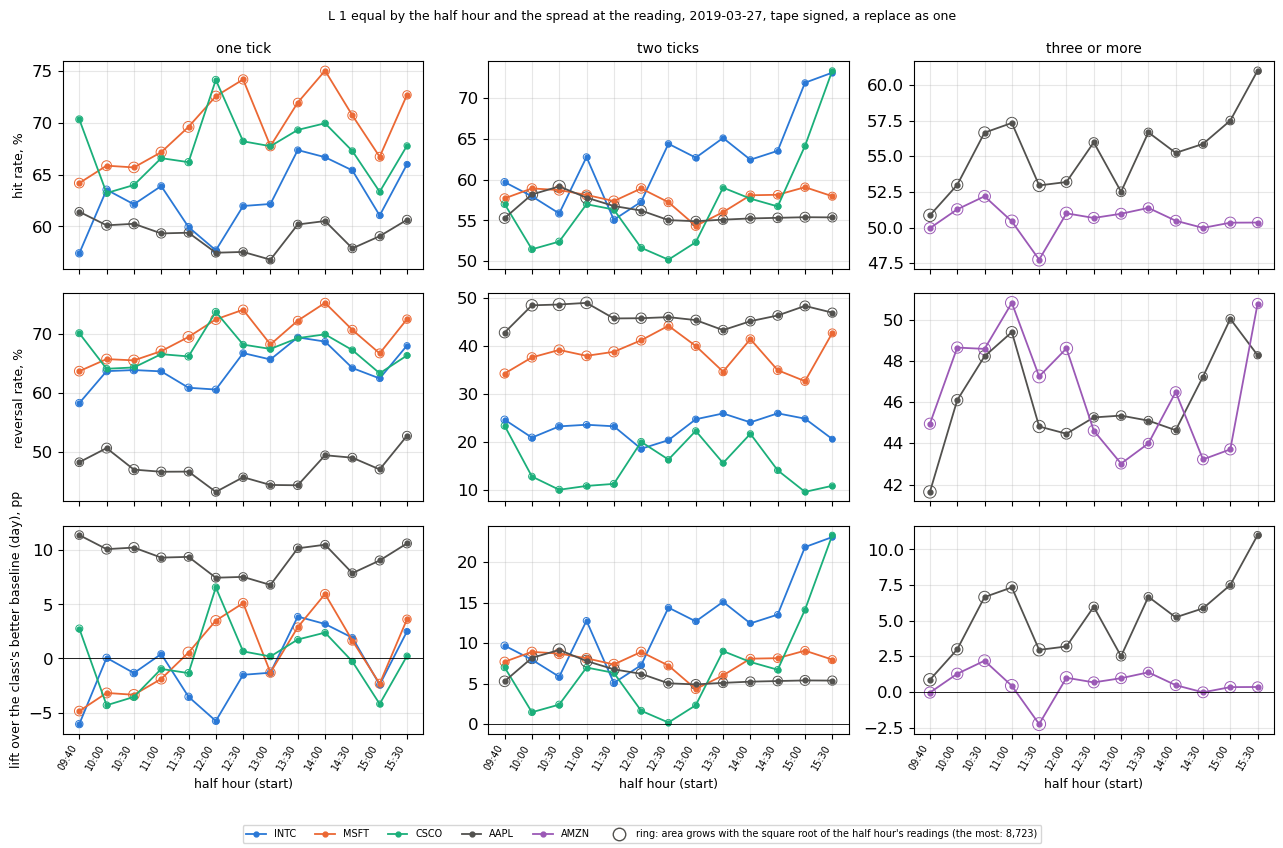

In [13]:
# Section 2, the imbalance in the half hours of the session: the strips of hit rate, reversal rate and lift, by spread
# class, with the lift's standard errors; and the figure. Needs the imb_ helpers. With the data absent it prints one
# line.
IMB_STRIPS = (  # the strip's key, its label, scale and decimals
    ('n', 'n', 1.0, 0),
    ('hit', 'hit %', 100.0, 1),
    ('reversal', 'reversal %', 100.0, 1),
    ('lift', 'lift pp', 100.0, 1),
)
IMB_STRIP_SETTINGS = ('L 1 equal', 'L 10 touch', 'L 10 equal')  # the settings that have a half-hour strip


def imb_strip(r, setting, name, key):
    # the half-hour strip of one class (n, hit, reversal, lift or lift over reversal); NaN for a class under
    # MIN_READINGS
    strip = r['imbalance']['strips'].get((setting, name))
    return strip['strip'][key] if strip else [math.nan] * len(HAVE_BLOCKS)


def imb_strip_summary(results, setting):
    # A frame, a row for each stock and class that has a strip: the class's readings and lift (points), the lift's
    # block-bootstrap standard error (ASSUMING EXCHANGEABLE BLOCKS) and the strip's (the half hours' hit rate less the
    # day's baseline), and in how many of the half hours that have readings the lift is above 0: against the class's
    # baseline for the day (the table's), and, beside it, against each half hour's own baseline.
    rows = {}
    for stock, r in results.items():
        for name in CLASSES:
            strip = r['imbalance']['strips'].get((setting, name))
            if strip is None:
                continue
            lifts = np.array(strip['strip']['lift'], dtype=float)
            lifts = lifts[np.isfinite(lifts)]
            own = np.array(strip['strip']['lift, own baseline'], dtype=float)
            own = own[np.isfinite(own)]
            rows[stock, name] = {
                'n': strip['n'],
                'lift pp': 100 * strip['lift'],
                'se, blocks': 100 * strip['lift se'],
                'se, hit less day baseline': 100 * strip['lift strip se'],
                'half hours above 0': int((lifts > 0).sum()),
                'above 0, own baseline': int((own > 0).sum()),
                'half hours': len(lifts),
                'lowest pp': 100 * lifts.min() if len(lifts) else math.nan,
                'highest pp': 100 * lifts.max() if len(lifts) else math.nan,
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def imb_strip_lines(results, setting, name):
    # the half-hour strips of one class, a line for each stock and measure, under the half hours' start times
    lines = [f'{setting}, {name}', f'{"":<15}{strip_header(6)}']
    for stock, r in results.items():
        if (setting, name) in r['imbalance']['strips']:
            for key, label, scale, digits in IMB_STRIPS:
                lines.append(f'{stock:<6}{label:<9}{strip_text(imb_strip(r, setting, name, key), digits, scale, 6)}')
    return lines if len(lines) > 2 else [f'{setting}, {name}: no stock has {MIN_READINGS} readings']


def imb_figure(results, setting='L 1 equal', day=DAY):
    # hit rate, reversal rate and the lift over the better baseline, by half hour (rows), for each spread class
    # (columns): a line a stock, one y-axis a panel; a stock with under MIN_READINGS readings in a class is not drawn
    # there. A ring round each point: its area grows with the square root of the readings the half hour's value is made
    # of (one scale in every panel), so that a rate made of a handful of readings is seen to be. One legend a figure,
    # under the panels.
    rows = (
        ('hit', 'hit rate, %', 100.0),
        ('reversal', 'reversal rate, %', 100.0),
        ('lift', 'lift over the class\'s better baseline (day), pp', 100.0),
    )
    counts = {
        name: [np.asarray(imb_strip(r, setting, name, 'n'), dtype=float) for r in results.values()] for name in CLASSES
    }
    largest = max([np.nanmax(n) for n_of in counts.values() for n in n_of if np.isfinite(n).any()] or [1.0])
    fig, axes = plt.subplots(len(rows), len(CLASSES), figsize=(13, 8.5), sharex=True)
    handles, labels = [], []
    for i, (key, ylabel, scale) in enumerate(rows):
        for j, name in enumerate(CLASSES):
            ax = axes[i, j]
            if any((setting, name) in r['imbalance']['strips'] for r in results.values()):
                plot_strips(
                    results,
                    lambda r, key=key, name=name: imb_strip(r, setting, name, key),
                    ylabel if j == 0 else '',
                    scale=scale,
                    ax=ax,
                    zero=(key == 'lift'),
                )
                if not handles:
                    handles, labels = ax.get_legend_handles_labels()
                ax.get_legend().remove()
                for line, n in zip(ax.lines, counts[name], strict=False):
                    ax.scatter(
                        line.get_xdata(),
                        line.get_ydata(),
                        s=6 + 80 * np.sqrt(np.nan_to_num(n) / largest),
                        facecolors='none',
                        edgecolors=line.get_color(),
                        linewidths=0.7,
                    )
            else:
                ax.text(
                    0.5, 0.5, f'no stock has {MIN_READINGS} readings', ha='center', transform=ax.transAxes, fontsize=8
                )
            if i == 0:
                ax.set_title(name, fontsize=10)
            if i < len(rows) - 1:
                ax.set_xlabel('')
            tidy_axes(ax)
    handles.append(plt.Line2D([], [], color=GRAY, marker='o', markerfacecolor='none', linestyle='none', markersize=9))
    labels.append(f'ring: area grows with the square root of the half hour\'s readings (the most: {largest:,.0f})')
    fig.legend(handles, labels, loc='lower center', ncol=len(labels), fontsize=7)
    fig.suptitle(figure_title(f'{setting} by the half hour and the spread at the reading', results, day), fontsize=9)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()


def imb_show_strips(results, day=DAY):
    # the strips' summary for each setting that has one, then the half-hour strips of L 1 by spread class (the figure is
    # imb_figure's)
    for setting in IMB_STRIP_SETTINGS:
        heading(f'{setting}: the lift by half hour and spread class, its standard errors', results, day)
        say(
            'Points; the lift is the hit rate less the better of 50% and the class\'s reversal rate for the day, in '
            'each half hour too (so "half hours above 0" counts against the line of the class\'s own lift; "above 0, '
            'own baseline" counts against each half hour\'s own better baseline, a higher line on average); se, '
            'blocks: block bootstrap ASSUMING EXCHANGEABLE BLOCKS; se, hit less day baseline: NOT the lift\'s '
            'standard error but the sd over the root of the half hours with readings of each half hour\'s hit rate '
            'less the day\'s baseline (the better of 50% and the day\'s reversal rate), which does not take the half '
            'hour\'s own reversal rate; the paired lift\'s standard error is in section 7.'
        )
        summary = imb_strip_summary(results, setting)
        formats = {'n': ',.0f', 'lift pp': '+.1f', 'se, blocks': '.1f', 'se, hit less day baseline': '.1f'}
        print(shown(summary, formats | {'lowest pp': '+.1f', 'highest pp': '+.1f'}))
    print()
    for name in CLASSES:
        print('\n'.join(imb_strip_lines(results, 'L 1 equal', name)))


if need(DAY):
    imb_results = measured(DAY)
    imb_show_strips(imb_results)
    imb_figure(imb_results)

**The imbalance beyond the touch (2019-03-27).** The first table gives the lift over the better baseline of the imbalance of the top 3, 5 and 10 levels, with equal weights and with touch weights, by the spread at the reading. In brackets it names the baseline that binds in the class (rev for the reversal rate, 50 for 50%) and the readings; L 1 equal and L 1 touch are one number. The table holds the figures for L 5 and every reading count; here are L 3 and L 10, in points, as equal weights then touch weights:

- *INTC* (5,780 readings at one tick, 4,855 at two, at L 3 equal). One tick, where the reversal rate binds: L 3 -4.9 and -1.9, L 10 -10.6 and -2.1. Two ticks, where 50% binds: L 3 +9.1 and +10.6, L 10 +7.2 and +10.7.
- *MSFT* (31,998 and 25,215). One tick, reversal rate: L 3 -4.2 and +0.2, L 10 -15.5 and +0.0. Two ticks, 50%: L 3 +4.3 and +6.8, L 10 +3.3 and +6.9.
- *CSCO* (5,151 and 4,266). One tick, reversal rate: L 3 -7.1 and -0.5, L 10 -16.5 and -0.8. Two ticks, 50%: L 3 +6.7 and +5.9, L 10 +4.7 and +5.8.
- *AAPL* (24,601, 47,855 and 45,915). One tick: L 3 +4.1 and +5.2, L 10 +2.2 and +4.8. Two ticks: L 3 +2.0 and +2.8, L 10 +0.4 and +2.2. Three or more: L 3 +2.0 and +2.7, L 10 +1.3 and +2.6. 50% binds in all three.
- *AMZN* (72,604 at three or more). L 3 +1.9 and +2.0, L 10 +0.3 and +2.6, 50% binding. The one-tick and two-tick classes have 45 and 37 readings, counts only.

The simulator's two orderings are equal weights below touch weights beyond L 1, and equal weights below 0 where the reversal rate binds. The first appeared in every class with 200 readings at L 3, L 5 and L 10 but one: in CSCO's two-tick class equal weights are above touch weights at L 3 (+6.7 against +5.9) and at L 5 (+5.7 against +5.6) and below at L 10 (+4.7 against +5.8). The second appeared in the three classes where the reversal rate binds (one tick on INTC, MSFT and CSCO): equal weights run from -4.2 (MSFT, L 3) to -16.5 (CSCO, L 10), and lower at every deeper level on each of the three. Where 50% binds, equal weights stay above 0 in every class, from +0.3 (AMZN, L 10) up. Notebook 14's figures are pooled over spreads, and no pooled lift is printed for a stock here. In ZI, on its seeds 101 to 108, the pooled lifts are -1.2 at L 3 equal, 1.4 at L 3 touch, -2.1 at L 10 equal and 1.4 at L 10 touch. Its touch L 10 split by spread is -6.0 at one tick and 4.7 wider in ZI, and -8.2 to -1.5 at one tick and 3.9 to 6.0 wider over its five models. The real touch L 10 at one tick is -2.1 (INTC), +0.0 (MSFT), -0.8 (CSCO) and +4.8 (AAPL): INTC's is inside the simulator's one-tick range, CSCO's is just above it and MSFT's above it, and AAPL's is far from it. At wider spreads it is +10.7, +6.9 and +5.8 (INTC, MSFT and CSCO at two ticks), +2.2 and +2.6 (AAPL at two ticks and at three or more) and +2.6 (AMZN at three or more). CSCO's is inside the simulator's wider range, INTC's and MSFT's are above it and AAPL's and AMZN's are below it. This is description, and a pooled figure and a class figure are not the same statistic.

**The changes dropped.** The second table gives the share of the changes of the mid that have no reading before the next change (percent of the changes, strict design). At L 1 it is 6.6% (INTC), 11.1% (MSFT), 7.8% (CSCO), 17.4% (AAPL) and 19.6% (AMZN), the same with touch weights. At L 10 it is 6.6 and 6.6 (INTC), 10.9 and 10.9 (MSFT), 7.8 and 7.8 (CSCO), 14.5 and 14.5 (AAPL) and 13.9 and 13.8 (AMZN), with equal and with touch weights. The share whose next change came later than the limit of 30 s is 0.3% (INTC), 0.6% (CSCO) and 0.0% on the other three. The inclusive design, which lets the change event's own state give the reading, leaves out 0.0% (INTC), 0.5% (MSFT), 0.0% (CSCO), 3.7% (AAPL) and 6.8% (AMZN) at L 1, and 0.0% on all five at touch L 10. Notebook 14's ZI leaves out 17.3% (standard error 0.1) at L 1 in the strict design and 10.2% (se 0.1) in the inclusive one; over its five models the strict share at L 1 is 17.3 to 52.8% and the inclusive 7.7 to 25.9%. So the strict design leaves out 6.6 to 19.6% of the changes at L 1, by stock, and each class's figures are those of the changes that are left: a change that is followed by the next change before any event that leaves the mid alone is not in them. The difference between the strict and the inclusive column is what the strict design gives up by refusing the change event's own state.

**The half-hour strips (L 1, equal weights).** The strip table gives, for each class with a strip, the lift in each of the 13 half hours (the half hour's hit rate less the class's own better baseline for the day), and the figure draws them with a ring round each point whose area grows with the square root of that half hour's readings (the legend under the panels reads "ring: area grows with the square root of the half hour's readings (the most: 8,723)"). For each class: the half hours above 0 of the 13 (in brackets, above 0 against each half hour's own better baseline), the lowest and the highest half-hour lift in points, and the class's lift with its block-bootstrap standard error ("se, blocks"):

- *INTC.* One tick: 6 (2), -6.1 to +3.9, lift -1.5 (se 0.4). Two ticks: 13 (13), +5.1 to +23.1, +10.7 (se 1.3).
- *MSFT.* One tick: 7 (8), -4.9 to +6.0, +0.0 (se 0.1). Two ticks: 13 (13), +4.3 to +9.1, +7.8 (se 0.3).
- *CSCO.* One tick: 7 (4), -4.3 to +6.6, +0.0 (se 0.1). Two ticks: 13 (13), +0.2 to +23.4, +5.8 (se 1.2).
- *AAPL.* One tick: 13 (13), +6.8 to +11.4, +9.4 (se 0.3). Two ticks: 13 (13), +4.9 to +9.2, +6.7 (se 0.5). Three or more: 13 (13), +0.9 to +11.0, +4.2 (se 0.8).
- *AMZN.* Three or more: 10 (8), -2.3 to +2.2, +0.4 (se 0.4).

Of these, the lifts more than twice their block-bootstrap standard error from 0 (the plain ratio of the two printed figures) are INTC's at one tick (-1.5 over 0.4, below 0) and at two ticks, MSFT's and CSCO's at two ticks and all three of AAPL's. The ones that are not are MSFT's and CSCO's at one tick (+0.0 over 0.1) and AMZN's (+0.4 over 0.4, one se). That is a statement about these 13 half hours with an assumption that they are exchangeable, and it is not a test of the stock. The table's other column, "se, hit less day baseline", is not the lift's standard error and is not read here: the first run called it "se, strip" and described it as the lift's, which the review of the run showed to be wrong, and the paired lift's standard error is Table 7b of section 7 (asked for after the run and judged by no rule).

Some half hours hold few readings, and the `n` lines of the strip say so. INTC's one-tick half hours hold from 194 readings (the last, of twenty minutes) to 742, and CSCO's from 211 (the last) to 627, so a half hour's hit rate there rests on a few hundred readings. In the two-tick class the highest half-hour lifts, +23.1 (INTC) and +23.4 (CSCO), are the last half hour's, on 160 and 184 readings. MSFT's one-tick half hours hold 1,295 to 4,133 and AAPL's 1,352 to 2,989. A single half hour's lift is read only with that in mind. The same cell prints the strips for L 10 touch and L 10 equal. At one tick L 10 equal is below 0 in all 13 half hours on INTC, MSFT and CSCO (0 of 13 above 0, the highest half hour -6.2, -13.2 and -13.1), and L 10 touch is above 0 in 3, 7 and 5 of 13.

**What this cannot show.**

- *One day of each stock, and the five stocks share the day's market factor.* The tables are a stock's figures on the day they are of. Nothing here says that two stocks differ, that a stock is of a kind (no regime labels), or what the figure is on another day; the second-day section runs the same code on the held-out day.
- *A lift within a class is a statement about that class's readings.* A change of the mid is often a change of the spread, so the classes are not independent samples of one book: a reading's class is decided by the move that preceded it. The baseline taken within the class is the better of two named baselines (50% and the reversal rate); it is not shown to be the right one, and no other baseline was tried.
- *The one-tick figures depend on states that last very little.* In the ladder exploration of the two stocks the code was built on, the one-tick imbalance readings changed when the stream was cut to one state a millisecond: they rest on states that can last under a millisecond, so a figure at one tick describes the full stream of events and is not a statement about what a feed that shows less would give. Table 7c in section 7 now measures it on the reported stocks, for the one-tick and the two-tick classes, by how long the spread state lasted. A band there is how soon the scored change came, a split on the outcome's own timing that nothing at the reading could tell, and no rule reads it.
- *A hit rate is of the next change of the mid, not of a fill.* The study says nothing about trading on the imbalance: it has no costs, no P&L and no queue position, and a next change within 30 seconds is the only horizon.
- *A strip's half hours are not exchangeable.* The first half hour holds more events a second than the median half hour (1.24 to 1.86 times, section 1), and the block bootstrap's standard error assumes they are interchangeable. It is printed as "se, blocks" and is never the uncertainty of the stock. The column "se, hit less day baseline" is a different quantity and not the lift's standard error.
- *Notebook 14's figures are of a simulator.* They are set beside the real figures to show what is being compared and with what spread of its own (seeds 101 to 108). Nothing in the section says the simulator matches a market.

### The queue race

**The question.** The curve for independent queues says that the chance the mid moves toward the heavier queue is 1/2 + (2/pi) arctan |I|, which is VisualHFT's 1/2 + arctan(c |I|) / (2 arctan c) at c = 1 (Cont and de Larrard, 2013; Avellaneda, Reed and Stoikov, 2011), where |I| is the imbalance at the touch at the reading. Does it fit the real readings, and how steep is the real hit rate in |I| in each spread class compared with the curve? The amplitude a scales what the curve adds to 1/2, so a = 1 is the curve itself and a below 1 is a flatter one.

**What notebook 14 found** (its seeds 101 to 108, fits pooled over the eight seeds). The curve at c = 1 beat a constant hit rate at one-tick spreads, by a log-likelihood of 1,391 in ZI (1,195, 468, 228 and 1,148 in the other four models), and lost to it over every spread (-8,946 in ZI). With a and c fitted, a reached its upper limit of 1.00 at one tick in all five models (c at 2.19, 2.19, 0.79, 1.86 and 2.68), and the fit with a alone gained exactly what the curve at c = 1 did, so the simulator's data at one tick are at least as steep as the curve for independent queues. At wider spreads a was an interior estimate that fell with the spread (in ZI 0.54 at two ticks and 0.31 at three or more).

**What the exploration stocks showed** (exploration: NVDA and CMCSA on the first day, never reported as results; a replace counted as one). At one tick the amplitude at c = 1 was 0.47 on NVDA (block-bootstrap upper 95% bound 0.58, 909 readings) and 0.50 on CMCSA (0.56, 3,488 readings), and the curve at c = 1 lost to a constant hit rate on both; at two ticks, 0.31 and 0.69; at three or more ticks on NVDA, 0.19. CMCSA's fit of c ran to a bound.

**What is run.** The fit of the setup cell (`race_by_class`, in each stock's `measure` result) by spread class, for the classes with 200 readings or more: the amplitude a at c = 1 by a bounded search, with its standard error and its 95th percentile (the upper bound the prediction reads) from a block bootstrap of the half hours (a fit a draw), a and c fitted together beside them with **no standard error on c** (it runs to a bound in most resamples), and the log-likelihood each version gains over a constant hit rate. The figure bins the hit rate by |I| with the curve for independent queues and the fitted amplitude. The prediction that reads this table is that, where one tick holds more than half of the time, the upper 95% bound of a at one tick is under 1 (a bound within 0.001 of 1 counts as the limit of the fit, not as under it); the simulator's value at one tick is 1.00.


The queue race: the curve for independent queues fitted to the touch imbalance, by spread class: 2019-03-27, session
09:40:00 to 15:50:00, tape signed, a replace as one.
gain: the log-likelihood the curve gains over a constant hit rate (negative: it does worse). a (c = 1): the amplitude of
1/2 + a arctan(|I|) / (2 arctan 1); se and upper 95%: its block bootstrap (200 draws, ASSUMING EXCHANGEABLE BLOCKS), the
upper bound being the 95th percentile of the draws; a, c, both: a and c fitted together (c has no standard error: it
runs to a bound in most resamples). A class under 200 readings is a count only.
                         n hit % gain, c = 1 a (c = 1)    se upper 95% gain, a fitted a, both  c, both
INTC one tick        5,780  62.0      -1,845      0.35  0.02      0.39             60    0.38     0.00
     two ticks       4,855  60.7          29      0.72  0.06      0.83             69    0.82     0.36
     three or more       1     -           -         -     -         -           

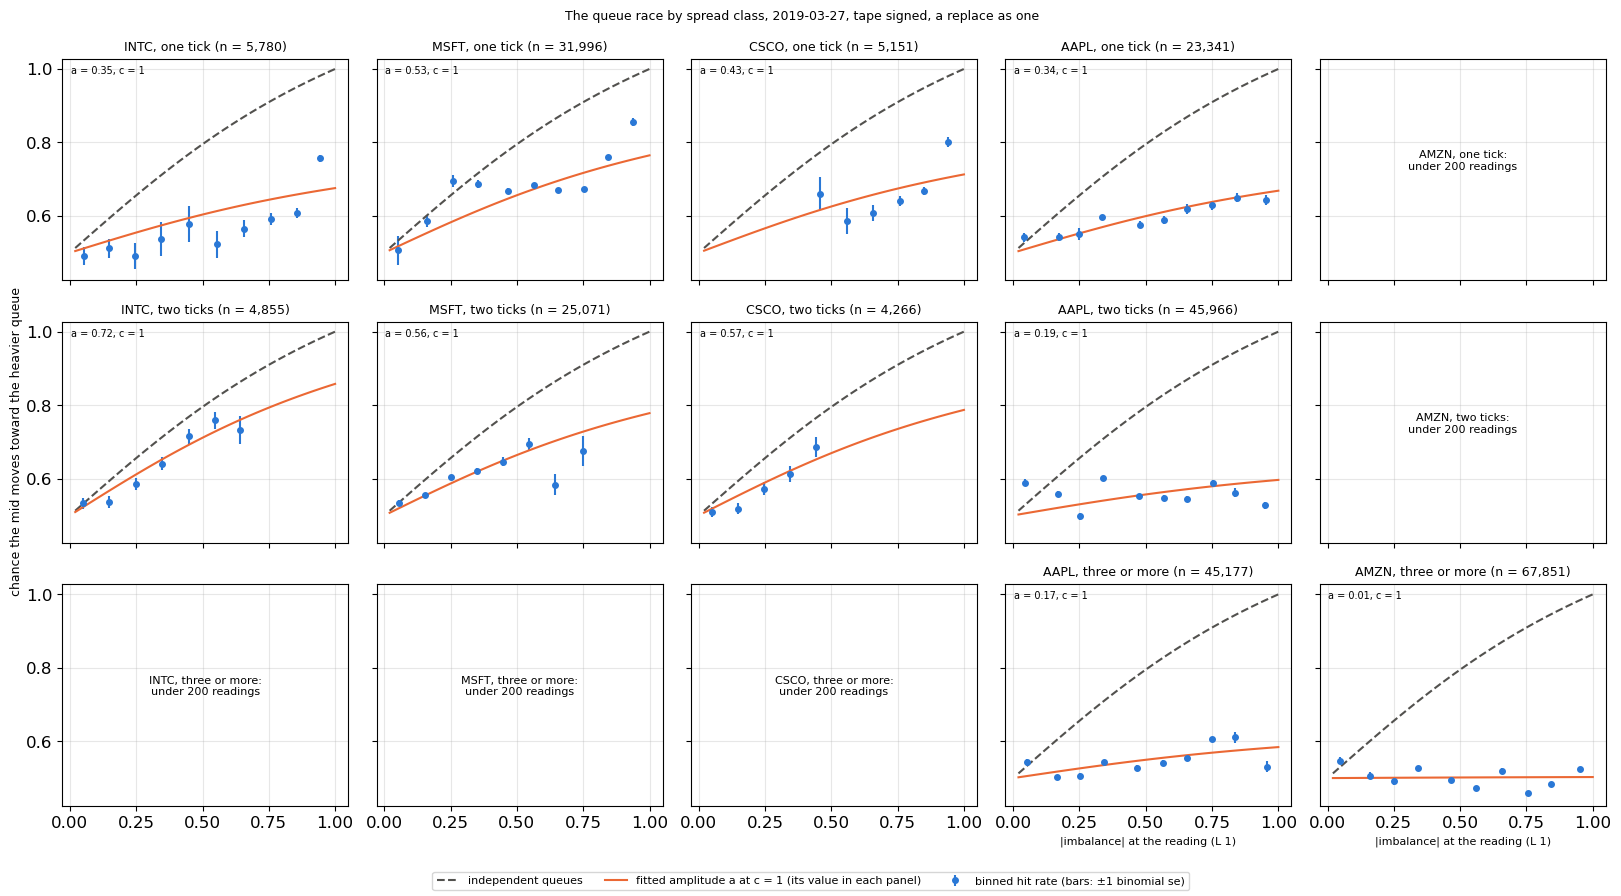

In [14]:
# Section 2, the queue race: the curve for independent queues, 1/2 + a arctan(c |I|) / (2 arctan c), fitted to the
# touch imbalance's readings by spread class; the amplitude a at c = 1 with a standard error (a block bootstrap of
# RACE_DRAWS draws, ASSUMING EXCHANGEABLE BLOCKS), c with none (it runs to a bound in most resamples). Needs the imb_
# helpers. With the data absent it prints one line.
IMB_RACE_COLUMNS = ('n', 'hit %', 'gain, c = 1', 'a (c = 1)', 'se', 'upper 95%', 'gain, a fitted', 'a, both', 'c, both')
IMB_RACE_FORMATS = {
    'n': ',.0f',
    'hit %': '.1f',
    'gain, c = 1': ',.0f',
    'a (c = 1)': '.2f',
    'se': '.2f',
    'upper 95%': '.2f',
    'gain, a fitted': ',.0f',
    'a, both': '.2f',
    'c, both': '.2f',
}
IMB_BINS = np.linspace(0, 1, 11)  # bins of |imbalance| for the figure, as notebook 14's
IMB_BIN_MIN = 100  # readings a bin needs to be drawn, as notebook 14's


def imb_race_table(results, setting='L 1 equal'):
    # A frame, a row for each stock and spread class: the readings, the hit rate, the log-likelihood the curve at c = 1
    # gains over a constant hit rate, the amplitude a with c = 1 (its block-bootstrap standard error and 95th
    # percentile, the upper bound the prediction reads), the gain with a fitted, and the fit of both (a and c, no
    # standard error for c). A class under MIN_READINGS readings is its count only.
    rows = {}
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        for name in CLASSES:
            fit = r['imbalance']['race'].get(name)
            if fit is None:
                n = int(classes[(classes.setting == setting) & (classes['class'] == name)].n.iloc[0])
                rows[stock, name] = {'n': n}
                continue
            rows[stock, name] = {
                'n': fit['n'],
                'hit %': 100 * fit['hit'],
                'gain, c = 1': fit['gain c=1'],
                'a (c = 1)': fit['a (c = 1)'],
                'se': fit['a (c = 1) se'],
                'upper 95%': fit['a (c = 1) upper 95%'],
                'gain, a fitted': fit['gain a fitted'],
                'a, both': fit['a'],
                'c, both': fit['c'],
            }
    return pd.DataFrame.from_dict(rows, orient='index', columns=list(IMB_RACE_COLUMNS))


def imb_check_race(results, setting='L 1 equal'):
    # What must hold: a class has a fit exactly where it has MIN_READINGS readings, its readings are the class table's,
    # the amplitude is in (0, 1], and a standard error is not negative
    for stock, r in results.items():
        classes = r['imbalance']['classes']
        for name in CLASSES:
            n = int(classes[(classes.setting == setting) & (classes['class'] == name)].n.iloc[0])
            fit = r['imbalance']['race'].get(name)
            assert (fit is not None) == (n >= MIN_READINGS), f'{stock} {name}: a fit and the readings disagree'
            if fit is not None:
                assert fit['n'] == n, f'{stock} {name}: the fit\'s readings are not the class\'s'
                assert 0 < fit['a (c = 1)'] <= 1 and 0 < fit['a'] <= 1, f'{stock} {name}: an amplitude outside (0, 1]'
                assert fit['a (c = 1) se'] >= 0, f'{stock} {name}: a negative standard error'


def imb_nb14_race_table(names=CLASSES):
    # notebook 14's queue-race fits of the simulator (pooled over its eight seeds, as printed), a row for each model and
    # class
    read = imb_nb14_race()
    columns = ('scored (all seeds)', 'hit %', 'gain, c = 1', 'a (c = 1)', 'both: a', 'both: c')
    rows = {
        (model, name): [read.get((model, name), {}).get(c, '-') for c in columns]
        for model in NB14_MODELS
        for name in names
    }
    return pd.DataFrame.from_dict(rows, orient='index', columns=list(columns))


def imb_race_figure(results, day=DAY, setting='L 1 equal'):
    # The hit rate against |imbalance| at the reading, binned (bins with IMB_BIN_MIN readings or more, a standard error
    # each), with the curve for independent queues (a = 1, c = 1) and the fitted amplitude at c = 1; a panel for each
    # stock and spread class that has a fit
    stocks = list(results)
    names = [name for name in CLASSES if any(name in r['imbalance']['race'] for r in results.values())]
    if not names:
        print(f'no stock has {MIN_READINGS} readings in any spread class: no figure.')
        return
    fig, axes = plt.subplots(
        len(names), len(stocks), figsize=(3.3 * len(stocks), 3.0 * len(names)), sharex=True, sharey=True, squeeze=False
    )
    grid = np.linspace(0.02, 1, 50)
    handles = None  # the legend is one for the figure, under the panels: the same three lines in every panel
    for j, stock in enumerate(stocks):
        arr = results[stock]['arrays']['scored L1']
        cls = spread_class(arr[:, 4]) if len(arr) else np.array([], int)
        for i, name in enumerate(names):
            ax = axes[i, j]
            fit = results[stock]['imbalance']['race'].get(name)
            if fit is None:
                ax.text(
                    0.5,
                    0.5,
                    f'{stock}, {name}:\nunder {MIN_READINGS} readings',
                    ha='center',
                    transform=ax.transAxes,
                    fontsize=8,
                )
                continue
            data = arr[cls == CLASSES.index(name)]
            x, hit = data[:, 1], data[:, 2]
            centers, rates, errors = [], [], []
            for low, high in zip(IMB_BINS[:-1], IMB_BINS[1:], strict=True):
                inside = (x > low) & (x <= high)
                if inside.sum() >= IMB_BIN_MIN:
                    centers.append(x[inside].mean())
                    rates.append(hit[inside].mean())
                    errors.append(math.sqrt(hit[inside].mean() * (1 - hit[inside].mean()) / inside.sum()))
            ax.errorbar(
                centers,
                rates,
                yerr=errors,
                fmt='o',
                color=BLUE,
                markersize=4,
                label='binned hit rate (bars: ±1 binomial se)',
            )
            ax.plot(grid, race_probability(grid, 1.0, 1.0), color=GRAY, linestyle='--', label='independent queues')
            ax.plot(
                grid,
                race_probability(grid, fit['a (c = 1)'], 1.0),
                color=ORANGE,
                label='fitted amplitude a at c = 1 (its value in each panel)',
            )
            ax.set_title(f'{stock}, {name} (n = {fit["n"]:,})', fontsize=9)
            ax.text(0.03, 0.97, f'a = {fit["a (c = 1)"]:.2f}, c = 1', transform=ax.transAxes, fontsize=7, va='top')
            if not centers:
                ax.text(0.5, 0.1, f'no bin has {IMB_BIN_MIN} readings', ha='center', transform=ax.transAxes, fontsize=7)
            if handles is None:
                handles, labels = ax.get_legend_handles_labels()
            if i == len(names) - 1:
                ax.set_xlabel('|imbalance| at the reading (L 1)', fontsize=8)
    fig.suptitle(figure_title('The queue race by spread class', results, day), fontsize=9)
    fig.supylabel('chance the mid moves toward the heavier queue', fontsize=9)
    fig.legend(handles, labels, loc='lower center', ncol=len(labels), fontsize=8)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()


def imb_show_race(results, day=DAY):
    imb_check_race(results)
    heading(
        'The queue race: the curve for independent queues fitted to the touch imbalance, by spread class', results, day
    )
    say(
        'gain: the log-likelihood the curve gains over a constant hit rate (negative: it does worse). a (c = 1): the '
        f'amplitude of 1/2 + a arctan(|I|) / (2 arctan 1); se and upper 95%: its block bootstrap ({RACE_DRAWS} draws, '
        'ASSUMING EXCHANGEABLE BLOCKS), the upper bound being the 95th percentile of the draws; a, c, both: a and c '
        f'fitted together (c has no standard error: it runs to a bound in most resamples). A class under '
        f'{MIN_READINGS} '
        'readings is a count only.'
    )
    table = imb_race_table(results)
    print(shown(table, IMB_RACE_FORMATS))
    say(
        f'\n{NB14_SEEDS}, the simulator: the fits it printed, pooled over its eight seeds (readings, hit rate, '
        'the gain '
        'at c = 1, a with c = 1, and a and c fitted together; an amplitude of 1.00 is the fit\'s upper limit):'
    )
    print(imb_nb14_race_table().to_string())
    print('\nThe prediction that reads this table (written before the run), by stock:')
    print(imb_judge(results, ('queue race',)))
    return table


if need(DAY):
    imb_results = measured(DAY)
    imb_race = imb_show_race(imb_results)
    imb_race_figure(imb_results)

**The queue-race table (2019-03-27).** For each class with 200 readings or more the table fits the amplitude a of 1/2 + a arctan(|I|) / (2 arctan 1) (c = 1) to the L 1 readings, gives its block-bootstrap standard error and 95th percentile (200 draws, assuming exchangeable half hours), and gives the gain in log-likelihood of the curve at c = 1 over a constant hit rate, which is negative where the curve does worse. Stock by stock, as a (se), upper 95% bound and gain at c = 1:

- *INTC.* One tick: 0.35 (se 0.02), 0.39, -1,845 (5,780 readings). Two ticks: 0.72 (se 0.06), 0.83, +29 (4,855).
- *MSFT.* One tick: 0.53 (se 0.02), 0.56, -3,815 (31,996). Two ticks: 0.56 (se 0.02), 0.59, -251 (25,071).
- *CSCO.* One tick: 0.43 (se 0.02), 0.47, -1,464 (5,151). Two ticks: 0.57 (se 0.09), 0.75, -8 (4,266).
- *AAPL.* One tick: 0.34 (se 0.01), 0.35, -3,480 (23,341). Two ticks: 0.19 (se 0.02), 0.22, -10,222 (45,966). Three or more: 0.17 (se 0.03), 0.23, -7,976 (45,177).
- *AMZN.* Three or more: 0.01 (se 0.01), 0.02, -44,919 (67,851). The one-tick and two-tick classes have 40 and 33 readings, counts only.

The gain at c = 1 is negative in every class but one, INTC's two-tick class (+29), and CSCO's two-tick class is -8. In notebook 14 (its seeds 101 to 108) the curve at c = 1 beat a constant hit rate at one tick in all five models (+228 to +1,391) and lost to it at wider spreads in every model but one (Parlour's two-tick class gained, +51). Here it loses at one tick on all four stocks with a class there. With the amplitude set free (the table's "gain, a fitted") the gain is positive, 20 to 78, in every class except AAPL's two-tick class (-110) and AMZN's (-1).

**Was the simulator's amplitude reached?** The simulator's amplitude at one tick is 1.00 in all five of its models, which is the fit's upper limit. No stock's amplitude at one tick lies at it: INTC 0.35, MSFT 0.53, CSCO 0.43 and AAPL 0.34, which is below 1 by 26.5, 21.3, 24.6 and 58.1 standard errors of the block bootstrap (the margin lines of section 6's verdict table, from a = 0.352 with se 0.024, 0.530 with 0.022, 0.426 with 0.023 and 0.337 with 0.011; AAPL's rule does not judge it). At wider spreads the simulator's amplitude is an interior estimate that falls with the spread (0.45 to 0.84 at two ticks and 0.15 to 0.59 at three or more, over its five models at c = 1; ZI 0.58 and 0.28). INTC's, MSFT's and CSCO's amplitudes at two ticks (0.72, 0.56, 0.57) are inside the first range and AAPL's (0.19) is below it. AAPL's at three or more (0.17) is inside the second range and AMZN's (0.01) is below it. This is description and not a match.

**c.** The table gives no standard error for c: it runs to a bound in most resamples. The fit with a and c together gives a c of 0.00 on INTC's and CSCO's one-tick classes, 3.18 on MSFT's and 3.07 on AAPL's, and at two ticks 0.36 (INTC), 0.00 (CSCO), 3.09 (MSFT) and 1807.48 (AAPL). A value of 0.00 or 1807.48 is the fit running to the end of c's range. These are fits and carry no uncertainty; notebook 14's fitted c at one tick (0.79 to 2.68) is also a fit.

**The prediction** (printed under the table): where one tick holds more than half of the time, the upper 95% bound of a at one tick is under 1. It is judged on INTC, MSFT and CSCO, and passed on all three: INTC a 0.352 with an upper bound of 0.3900 (5,780 readings; one tick holds 99.8% of the time), MSFT 0.530 and 0.5647 (31,996; 89.8%) and CSCO 0.426 and 0.4654 (5,151; 99.6%). It is not judged on AAPL (one tick holds 20.7% of the time) or AMZN (0.0%, and 40 one-tick readings). The three bounds, 0.39 to 0.56, are far under the line of 1, so no verdict sits on its line; a bound just under 1 would have said as much about the threshold as about the stock. What a pass says is that the one-tick hit rate rises less steeply with |I| than the curve for independent queues, on these stock-days. The three stocks share the day's market factor, so three passes are not three independent results. Section 7 (Table 7a, asked for after the run and judged by no rule) says that the race reads the same one-tick readings as the imbalance and was not refit with a replace's echo giving no reading, and prints the first day's bounds against the rule's line of 0.999.

**The figure of the binned hit rate.** Each panel bins the hit rate by |I| (bins of at least 100 readings, bars of one binomial standard error) against the curve for independent queues (dashed) and the fitted curve at c = 1 (a is in the panel). Read from the figure:

- *INTC, one tick (a = 0.35).* The bins rise from about 0.49 at the smallest |I| to about 0.61 at |I| of 0.85, irregularly, with a last bin near 0.76. All are below the curve for independent queues. They are below the fitted curve in the middle and upper bins and above it in the last.
- *MSFT, one tick (0.53).* The bins rise from about 0.51 to about 0.85. At |I| of 0.15 and 0.25 they are on or just above the curve for independent queues (about 0.59 and 0.69), then about 0.67 to 0.69 from 0.35 to 0.75, below that curve and crossing the fitted one (above it up to about 0.55, below it at 0.75), and above the fitted curve in the last two bins.
- *CSCO, one tick (0.43).* Only the bins from |I| of about 0.45 up have 100 readings. They run 0.66, 0.59, 0.61, 0.64, 0.67 and 0.80, below the curve for independent queues, above the fitted curve in the first and last bins and below it in the middle ones. They rise weakly from 0.59.
- *AAPL, one tick (0.34).* The bins sit on or near the fitted curve and rise slowly from about 0.54 to about 0.65, below the curve for independent queues except in the first bin.
- *INTC, two ticks (0.72).* The bins rise from about 0.53 to about 0.76 along the fitted curve, which is itself close to the curve for independent queues, and the last bin (about 0.73) is below the fitted curve.
- *MSFT, two ticks (0.56).* The bins follow the fitted curve up to |I| of about 0.45 (0.53 to 0.65), are above it at 0.55 (about 0.69) and below it in the last two (about 0.58 and 0.67, the last with a wide bar). They rise overall.
- *CSCO, two ticks (0.57).* Five bins, from about 0.51 to about 0.69, near the fitted curve (a little under it in the second to fourth, above it in the last), rising.
- *AAPL, two ticks (0.19).* The bins scatter between 0.50 and 0.60 around the fitted curve, with no rise in |I| (about 0.59 in the first bin, 0.50 in the third, 0.53 in the last).
- *AAPL, three or more (0.17).* The bins scatter between 0.50 and 0.61 around the fitted curve, rising weakly to about 0.61 at |I| of 0.75 to 0.85 and falling back to about 0.53 in the last.
- *AMZN, three or more (0.01).* The bins lie between about 0.46 and 0.55 around a fitted line that is flat at 0.50, with no rise in |I|.

INTC's, MSFT's and CSCO's three-or-more panels and AMZN's one-tick and two-tick panels say "under 200 readings". Nothing here says the queues are or are not independent: the fit measures how steeply the hit rate rises with |I|.

**What this cannot show.**

- *The amplitude is a steepness and not a test of independence.* A fitted a below 1 says the hit rate rises less steeply with |I| than the curve for independent queues does in that class, in that stock, on that day; it does not say why (a limit order inside the spread moves the mid whatever the queues say, and that is the mechanism notebook 14 offers for the wider spreads, not one tested here).
- *The standard error and the upper bound assume exchangeable half hours.* The bootstrap resamples the half hours with replacement, and they are not exchangeable (the first holds more events a second than the median half hour); the 95th percentile is the upper end of the resampled amplitudes and is not a confidence level for the stock.
- *c has no standard error.* It runs to a bound in most resamples, so a fitted c is a fit's value and not an estimate with an uncertainty.
- *The readings are those of the imbalance table.* The strict design, a next change within 30 seconds, sizes in shares with odd lots counted, a replace as one, and so the readings taken at a replace's echo that section 7's Table 7a counts: a different reading would be a different fit. A class with fewer than 200 readings has no fit.
- *One day of each stock; no two stocks are said to differ.*

### Order flow imbalance

**The question.** How much of the change of the mid over an interval does the interval's order flow imbalance (OFI) explain, and does an interval's flow say anything about the next interval's change that the last change does not? OFI is Cont, Kukanov and Stoikov's best-quote rule: each event that moves the touch adds or removes the shares that the best bid and ask gain or lose, summed over an interval; the fit is of the mid's change on it, and the forecast is its partial correlation with the next interval's change given the last change.

**What notebook 14 found** (its seeds 101 to 108; a pooled R2 over each run of 5,000 units). The same-interval R2 at 10 units was 0.322 (se 0.013) in ZI, 0.238, 0.495, 0.474 and 0.308 in Hawkes ZI, MF 2008, Parlour and Informed ZI, and across the five 0.250 to 0.410 at 1 unit and 0.363 to 0.768 at 50. Scored against the last change, OFI forecast almost nothing in ZI, Hawkes ZI and Parlour: its partial correlation beyond the last change at 10 units was -0.04 (se 0.01) in ZI, -0.01 in Hawkes ZI and +0.04 in Parlour, and +0.12 in MF 2008 and +0.28 in Informed ZI, where the notebook traced it to the persistence of the flow and to the informed orders; at 50 units it was positive in every model (0.07 to 0.23).

**What the exploration stocks showed** (exploration: NVDA and CMCSA on the first day, never reported as results; one increment an event). NVDA's R2 pooled over the session at 1 s was 0.234, and ten of its 22,200 seconds hold 64% of the flow's sum of squares: with them set aside the R2 was 0.550, and the median half-hour R2 was 0.549 at 1 s, 0.674 at 5 s, 0.675 at 10 s and 0.644 at 50 s (CMCSA: 0.728, 0.800, 0.822 and 0.848, with a pooled R2 of 0.693 at 1 s, ten seconds holding 8% of its sum of squares). The partial correlation beyond the last change at 1 s was positive in 13 of 13 half hours on both. So the figure of this notebook is the **median half-hour R2**, with the pooled R2, the share of the flow's sum of squares in the ten largest seconds and the R2 without them beside it, and the partial correlation beyond the last change **by half hour**.

**What is run.** Nothing new: the flow is in each stock's `measure` result. The tables are the median half-hour R2 at 1, 5, 10 and 50 s with its block-bootstrap standard error, the pooled R2 beside it, the ten largest seconds, the partial correlation beyond the last change by half hour and the R2 at 10 s by the spread at the start of the interval; the figure draws the half hours. OFI is the same on every tape (a hidden execution moves no quote), so the tape does not change it, and the table names the convention all the same. The prediction that reads these tables is that the median half-hour R2 at 10 s is above 0.50 and the partial correlation beyond the last change at 1 s is positive in 10 of the half hours or more.

In [15]:
# Section 2, order flow imbalance: the same-interval R2 of the mid's change on the interval's flow at 1, 5, 10 and 50 s.
# The FIGURE is the median of the half-hour R2s; the pooled R2, the share of the flow's sum of squares in its ten
# largest seconds and the R2 without them are beside it, because a pooled R2 can be a few seconds of the day. Needs cell
# 21. With the data absent it prints one line.
def ofi_check(results):
    # What must hold for the tables to mean anything: the median of a strip is the median half-hour R2 and its half
    # hours are the session's; the intervals fill the session; shares are shares; the 1 s pooled R2 is the same number
    # in the interval table and in the ten-largest-seconds table; "beyond" is counted in half hours that have one.
    for stock, r in results.items():
        ofi = r['ofi']
        for h in INTERVALS:
            row = ofi[h]
            assert len(row['R2 strip']) == len(row['beyond strip']) == len(HAVE_BLOCKS), f'{stock} {h} s: strips'
            assert row['intervals'] == SESSION_SECONDS // h, (
                f'{stock} {h} s: {row["intervals"]} intervals fill no session'
            )
            if np.isfinite(row['R2 strip']).any():
                assert math.isclose(float(np.nanmedian(row['R2 strip'])), row['median half-hour R2'], rel_tol=1e-9), (
                    stock
                )
            assert row['blocks with R2'] == int(np.isfinite(row['R2 strip']).sum()), (
                f'{stock} {h} s: half hours with R2'
            )
            assert row['blocks with beyond above 0'] <= int(np.isfinite(row['beyond strip']).sum()), f'{stock} {h} s'
            assert not np.isfinite(row['pooled R2']) or 0 <= row['pooled R2'] <= 1, f'{stock} {h} s: pooled R2'
        top = ofi['largest seconds']
        share = top['share of the sum of squares of the flow in the ten largest seconds']
        assert not np.isfinite(share) or 0 <= share <= 1, f'{stock}: the share of the sum of squares'
        assert math.isclose(top['pooled R2 at 1 s'], ofi[1]['pooled R2'], rel_tol=1e-9, abs_tol=1e-12), (
            f'{stock}: pooled R2'
        )


def ofi_table(results, getter, digits=3):
    # a frame of text, a row a stock and a column for each interval: getter(row of one interval) gives (value, se) or a
    # value
    def cell(row):
        got = getter(row)
        value, se = got if isinstance(got, tuple) else (got, None)
        return fmt(value, digits) if se is None else f'{fmt(value, digits)} ({fmt(se, digits)})'

    return pd.DataFrame({f'{h} s': {stock: cell(r['ofi'][h]) for stock, r in results.items()} for h in INTERVALS})


def ofi_nb14_table(column, intervals=INTERVALS):
    # notebook 14's figure for each model and interval, as printed (a pooled figure of a run of simulation time; mean
    # over seeds 101 to 108 and, in brackets, its standard error across them)
    read = imb_nb14_ofi()
    return pd.DataFrame(
        {f'{h} units': {m: read.get((h, m), {}).get(column, '-') for m in NB14_MODELS} for h in intervals}
    )


def ofi_show(results, day=DAY):
    ofi_check(results)
    heading('Order flow imbalance: the same-interval R2 of the mid\'s change on the interval\'s flow', results, day)
    say(
        'One increment an event (the best-quote rule of Cont, Kukanov and Stoikov, summed in each interval). THE '
        f'FIGURE is the median of the half-hour R2s ({len(HAVE_BLOCKS)} half hours of the session, from '
        f'{SESSION_START}), with its block-bootstrap standard error ({DRAWS:,} draws, ASSUMING EXCHANGEABLE BLOCKS) in '
        'brackets.'
    )
    print(shown(ofi_table(results, lambda o: (o['median half-hour R2'], o['median half-hour R2 se']))))
    print('\nHalf hours with an R2 (of those the session touches):')
    print(shown(ofi_table(results, lambda o: o['blocks with R2'], 0)))
    say(
        '\nBeside it, NOT a stock\'s figure: the R2 pooled over the whole session (its block-bootstrap standard error '
        'in brackets), which a few seconds of the day can make:'
    )
    print(shown(ofi_table(results, lambda o: (o['pooled R2'], o['pooled R2 se']))))
    top = stock_table(
        results,
        {
            'share of the flow\'s sum of squares in the ten largest seconds': lambda r: r['ofi']['largest seconds'][
                'share of the sum of squares of the flow in the ten largest seconds'
            ],
            'pooled R2 at 1 s': lambda r: r['ofi']['largest seconds']['pooled R2 at 1 s'],
            'R2 at 1 s without them': lambda r: r['ofi']['largest seconds'][
                'R2 at 1 s without the ten largest seconds'
            ],
            'largest |flow| in a second (shares)': lambda r: r['ofi']['largest seconds'][
                'largest |flow| in a second (shares)'
            ],
        },
    )
    print('\nThe ten largest seconds of order flow imbalance (1 s intervals, the session):')
    print(
        shown(
            top,
            {top.columns[0]: '.1%', 'pooled R2 at 1 s': '.3f', 'R2 at 1 s without them': '.3f', top.columns[3]: ',.0f'},
        )
    )
    print('\nThe three rates beside (a replace as one), session:')
    print(shown(imb_rates(results), RATE_FORMATS | {'time at one tick': '.1%'}))
    say(
        f'\n{NB14_SEEDS}, the simulator: the same-interval R2 of a run ({S0_UNITS["ofi"]:,} units after the warm-up, a '
        'pooled R2 of one run, mean over seeds with the standard error across them in brackets), by interval in units '
        'of simulation time; it is not a median of half hours:'
    )
    print(ofi_nb14_table('same-interval R2').to_string())
    print('\nThe prediction that reads these tables (written before the run), by stock:')
    print(imb_judge(results, ('order flow imbalance',)))


if need(DAY):
    imb_results = measured(DAY)
    ofi_show(imb_results)


Order flow imbalance: the same-interval R2 of the mid's change on the interval's flow: 2019-03-27, session 09:40:00 to
15:50:00, tape signed, a replace as one.
One increment an event (the best-quote rule of Cont, Kukanov and Stoikov, summed in each interval). THE FIGURE is the
median of the half-hour R2s (13 half hours of the session, from 09:40:00), with its block-bootstrap standard error
(1,000 draws, ASSUMING EXCHANGEABLE BLOCKS) in brackets.
                1 s            5 s           10 s           50 s
INTC  0.795 (0.012)  0.855 (0.008)  0.867 (0.008)  0.861 (0.033)
MSFT  0.807 (0.017)  0.896 (0.009)  0.909 (0.006)  0.911 (0.013)
CSCO  0.784 (0.016)  0.836 (0.012)  0.861 (0.013)  0.869 (0.014)
AAPL  0.783 (0.008)  0.826 (0.012)  0.828 (0.017)  0.806 (0.020)
AMZN  0.387 (0.018)  0.449 (0.028)  0.473 (0.019)  0.460 (0.045)

Half hours with an R2 (of those the session touches):
     1 s 5 s 10 s 50 s
INTC  13  13   13   13
MSFT  13  13   13   13
CSCO  13  13   13   13
AAPL  13  13

In [16]:
# Section 2, order flow imbalance beyond the last change: does an interval's flow tell the next interval's change of
# the mid anything that the interval's own change does not? The partial correlation of the flow with the next change
# given the last change, BY BLOCK (the figure is the half hours' above 0 and their values; the pooled value is beside
# it, not a stock's figure); and the R2 at the headline interval by the spread at the start of the interval. Needs the
# imb_ helpers and ofi_table. With the data absent it prints one line.
def ofi_beyond_lines(results, h):
    # the half-hour strip of "beyond the last change" at an interval, a line a stock, under the half hours' start times
    return stock_strips(results, lambda r: r['ofi'][h]['beyond strip'], 2, width=6, label=f'{h} s')


def ofi_above_zero(results, h):
    # for each stock, "k of m": the half hours at an interval with the partial correlation above 0, of those with one
    out = {}
    for stock, r in results.items():
        row = r['ofi'][h]
        out[stock] = f'{row["blocks with beyond above 0"]} of {int(np.isfinite(row["beyond strip"]).sum())}'
    return out


def ofi_spread_table(results):
    # a frame, a row a stock: R2 at the headline interval by the spread at the start of the interval, with the intervals
    # in brackets (an R2 only where there are more than 20); the class with few intervals is its count
    return pd.DataFrame(
        {
            name: {
                stock: f'{fmt(r["ofi"]["by spread"][name]["R2"], 3)} ({r["ofi"]["by spread"][name]["intervals"]:,})'
                for stock, r in results.items()
            }
            for name in CLASSES
        }
    )


def ofi_show_beyond(results, day=DAY):
    heading('Order flow imbalance beyond the last change', results, day)
    say(
        'The partial correlation of an interval\'s flow with the next interval\'s change of the mid, given the last '
        'change. The pooled value (its block-bootstrap standard error in brackets, ASSUMING EXCHANGEABLE BLOCKS) is '
        'NOT a stock\'s figure; the figure is how many half hours it is above 0, and the strip.'
    )
    print(shown(ofi_table(results, lambda o: (o['OFI beyond the last change'], o['beyond se']))))
    print('\nHalf hours with it above 0, of the half hours that have one:')
    print(shown(pd.DataFrame({f'{h} s': ofi_above_zero(results, h) for h in INTERVALS})))
    print('\nBy half hour (from the half hour that starts at):')
    for h in INTERVALS:
        print(ofi_beyond_lines(results, h))
        print()
    print('Beside it: the correlation of the flow with the next change, and of the last change with the next, pooled:')
    print(shown(ofi_table(results, lambda o: o['OFI against the next change'], 2)))
    print(shown(ofi_table(results, lambda o: o['the last change against the next'], 2)))
    print(
        f'\nR2 at {OFI_MAIN} s by the spread at the start of the interval (the intervals in brackets; no R2 for 20 or '
        'fewer):'
    )
    print(ofi_spread_table(results).to_string())
    say(
        f'\n{NB14_SEEDS}, the simulator: the partial correlation beyond the last change, a pooled figure of a run '
        '(mean '
        'over seeds, se across seeds in brackets), by interval in units of simulation time:'
    )
    print(ofi_nb14_table('OFI beyond the last change').to_string())
    print(
        '\nBeside it, notebook 14\'s forecast scored against the last change (the correlation of the flow with the '
        'next change):'
    )
    print(ofi_nb14_table('OFI against the next change').to_string())


if need(DAY):
    imb_results = measured(DAY)
    ofi_show_beyond(imb_results)


Order flow imbalance beyond the last change: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
The partial correlation of an interval's flow with the next interval's change of the mid, given the last change. The
pooled value (its block-bootstrap standard error in brackets, ASSUMING EXCHANGEABLE BLOCKS) is NOT a stock's figure; the
figure is how many half hours it is above 0, and the strip.
                1 s            5 s            10 s            50 s
INTC  0.116 (0.010)  0.101 (0.018)   0.056 (0.015)  -0.033 (0.050)
MSFT  0.138 (0.008)  0.064 (0.020)   0.043 (0.027)   0.069 (0.057)
CSCO  0.172 (0.009)  0.128 (0.012)   0.039 (0.020)  -0.052 (0.036)
AAPL  0.038 (0.010)  0.015 (0.016)  -0.004 (0.022)   0.022 (0.058)
AMZN  0.050 (0.006)  0.033 (0.029)   0.028 (0.021)   0.071 (0.042)

Half hours with it above 0, of the half hours that have one:
           1 s       5 s      10 s     50 s
INTC  13 of 13  12 of 13  12 of 13  5 of 13
MSFT  13 of 13  11 of 13  10 of

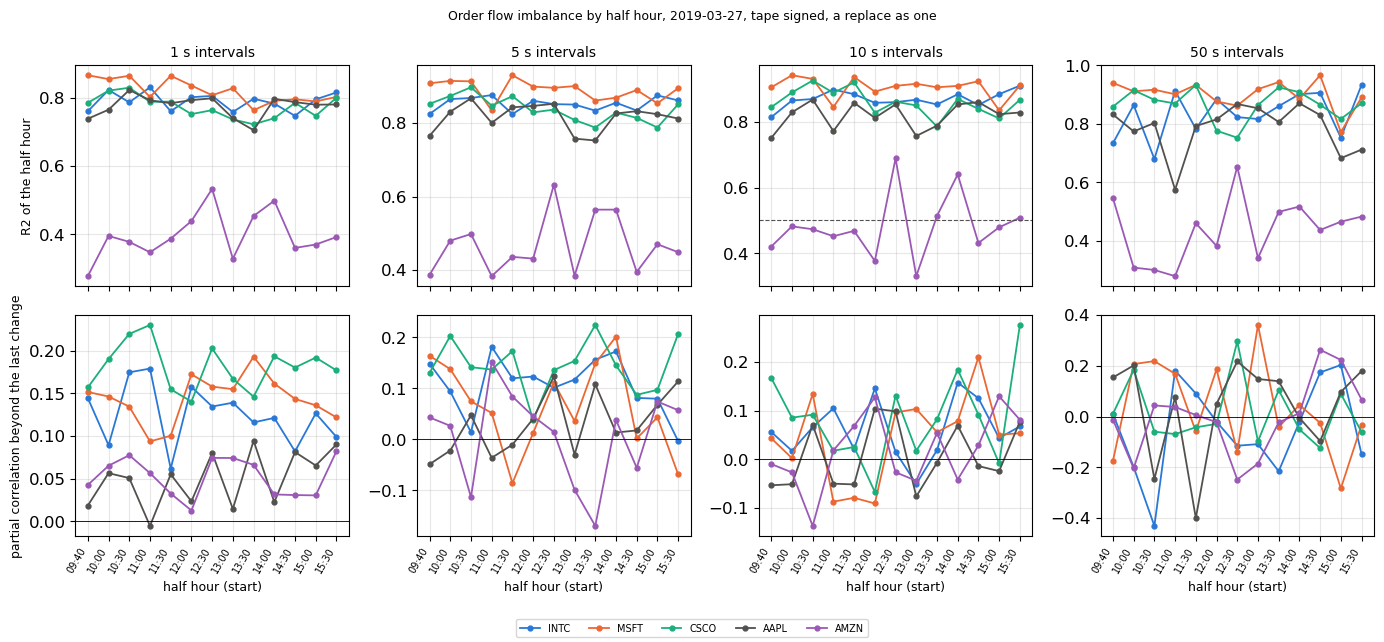

In [17]:
# Section 2, order flow imbalance by half hour: the R2 of each half hour (top) and the partial correlation beyond the
# last change (bottom), at each interval, a line a stock, one y-axis a panel. Needs the imb_ helpers. With the data
# absent it prints one line.
def ofi_figure(results, day=DAY):
    # One legend a figure, under the panels (a legend in the first panel covered the y axis label and the data).
    fig, axes = plt.subplots(2, len(INTERVALS), figsize=(14, 6.4), sharex=True)
    handles, labels = None, None
    for j, h in enumerate(INTERVALS):
        top, bottom = axes[0, j], axes[1, j]
        plot_strips(results, lambda r, h=h: r['ofi'][h]['R2 strip'], 'R2 of the half hour' if j == 0 else '', ax=top)
        plot_strips(
            results,
            lambda r, h=h: r['ofi'][h]['beyond strip'],
            'partial correlation beyond the last change' if j == 0 else '',
            ax=bottom,
            zero=True,
        )
        top.set_title(f'{h} s intervals', fontsize=10)
        if h == OFI_MAIN:
            top.axhline(
                0.5, color=GRAY, linestyle='--', linewidth=0.8
            )  # the prediction's threshold for the median half hour
        top.set_xlabel('')
        if handles is None:
            handles, labels = top.get_legend_handles_labels()
        for ax in (top, bottom):
            tidy_axes(ax)
            ax.get_legend().remove()
    fig.suptitle(figure_title('Order flow imbalance by half hour', results, day), fontsize=9)
    fig.legend(handles, labels, loc='lower center', ncol=len(labels), fontsize=7)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()


if need(DAY):
    ofi_figure(measured(DAY))

**The R2 tables (2019-03-27).** The first table gives the same-interval R2 of the mid's change on the interval's order flow imbalance (one increment an event), at 1, 5, 10 and 50 s. The figure is the median of the 13 half-hour R2s, with its block-bootstrap standard error (1,000 draws, assuming exchangeable half hours) in brackets. At 1, 5, 10 and 50 s:

- *INTC.* 0.795 (se 0.012), 0.855 (0.008), 0.867 (0.008), 0.861 (0.033).
- *MSFT.* 0.807 (se 0.017), 0.896 (0.009), 0.909 (0.006), 0.911 (0.013).
- *CSCO.* 0.784 (se 0.016), 0.836 (0.012), 0.861 (0.013), 0.869 (0.014).
- *AAPL.* 0.783 (se 0.008), 0.826 (0.012), 0.828 (0.017), 0.806 (0.020).
- *AMZN.* 0.387 (se 0.018), 0.449 (0.028), 0.473 (0.019), 0.460 (0.045).

Beside them, and **not a stock's figure**, the table prints the R2 pooled over the whole session, which a few seconds of the day can make. At 1, 5, 10 and 50 s: INTC 0.768 (0.009), 0.825 (0.009), 0.842 (0.011), 0.799 (0.024); MSFT 0.820 (0.010), 0.882 (0.010), 0.892 (0.012), 0.876 (0.017); CSCO 0.757 (0.013), 0.814 (0.017), 0.840 (0.021), 0.839 (0.021); AAPL 0.760 (0.011), 0.796 (0.015), 0.795 (0.018), 0.760 (0.021); AMZN 0.375 (0.016), 0.427 (0.017), 0.433 (0.020), 0.363 (0.033). The ten largest seconds of order flow (1 s intervals) hold 4.7% (INTC), 4.5% (MSFT), 4.4% (CSCO), 5.7% (AAPL) and 11.6% (AMZN) of the flow's sum of squares, and the R2 at 1 s without them is 0.776, 0.825, 0.757, 0.779 and 0.391, against the pooled 0.768, 0.820, 0.757, 0.760 and 0.375.

So the pooled R2 is close to the median half-hour R2 on all five stock-days and is not a few seconds of the day. At 10 s it is below the median by 0.025 (INTC), 0.017 (MSFT), 0.021 (CSCO), 0.033 (AAPL) and 0.040 (AMZN), plain differences of the printed figures, and setting the ten largest seconds aside moves the 1 s R2 by 0.000 to 0.019. That is not what the exploration stock NVDA showed (a pooled R2 of 0.234 at 1 s, ten seconds holding 64% of the sum of squares), which is why the figure is the median and not the pooled value. Neither figure is a property of the stock: each is that stock's on that day.

Notebook 14's R2 is the simulator's pooled R2 of a run of 5,000 units after the warm-up, and not a median of half hours. At 10 units it is 0.322 (se 0.013) in ZI and 0.238 to 0.495 over the five models, and at 50 units 0.363 to 0.768 (ZI 0.450, se 0.023). The real medians at 10 s are 0.867, 0.909, 0.861, 0.828 and 0.473. AMZN's is inside the simulator's range at 10 units and the other four are far above it. At 50 s the real medians are 0.861, 0.911, 0.869, 0.806 and 0.460: AMZN's is inside the simulator's range and the others are above it. This is description. The statistics are not the same, a unit is not a second, and nothing is called a match.

**The half-hour R2 strips.** The figure's top row draws each half hour's R2, and the strip itself is printed in Table 7d of section 7 (asked for after the run and judged by no rule). At 10 s, the lowest and highest half-hour R2 and the half hours they are (from Table 7d's header, the half hour that starts at the time given): INTC 0.814 (09:40) and 0.910 (15:30); MSFT 0.835 (15:00) and 0.941 (10:00); CSCO 0.785 (13:30) and 0.925 (10:30); AAPL 0.751 (09:40) and 0.867 (10:30); AMZN 0.331 (13:00) and 0.688 (12:30). INTC's and AAPL's first half hours (twenty minutes) are the lowest of their strips, and INTC's last half hour (twenty minutes) is the highest of its strip. On MSFT (0.905 first, 0.910 last, median 0.909), CSCO (0.844, 0.867, median 0.861) and AMZN (0.421, 0.508, median 0.473) neither end half hour is the lowest or the highest, and AAPL's last (0.828) is its median. AMZN's strip crosses the line of 0.50: its half hours run 0.331 to 0.688 and 4 of its 13 are above 0.50.

A half hour of 30 minutes holds 1,800, 360, 180 and 36 intervals at 1, 5, 10 and 50 s, and the first and the last, of twenty minutes, hold 1,200, 240, 120 and 24 (plain divisions). So a half hour's R2 at 50 s rests on 36 intervals, or 24 at the ends, and is noisy: the standard error of the median half-hour R2 is 0.033 (INTC), 0.013 (MSFT), 0.014 (CSCO), 0.020 (AAPL) and 0.045 (AMZN) at 50 s, against 0.008, 0.006, 0.013, 0.017 and 0.019 at 10 s.

**Beyond the last change.** The partial correlation of an interval's flow with the next interval's change of the mid, given the last change, is the only forecast statistic here. Half hours with it above 0, of the 13, at 1, 5, 10 and 50 s: INTC 13, 12, 12 and 5; MSFT 13, 11, 10 and 6; CSCO 13, 13, 11 and 5; AAPL 12, 8, 5 and 9; AMZN 13, 9, 7 and 7. The strip at 1 s runs from 0.06 to 0.18 on INTC, 0.09 to 0.19 on MSFT, 0.14 to 0.23 on CSCO, -0.01 to 0.09 on AAPL (the one half hour below 0 is the one that starts at 11:00) and 0.01 to 0.08 on AMZN. The pooled value is printed beside the strip, **not as a stock's figure**, with its block-bootstrap standard error: at 1 s 0.116 (0.010), 0.138 (0.008), 0.172 (0.009), 0.038 (0.010) and 0.050 (0.006), at 10 s 0.056 (0.015), 0.043 (0.027), 0.039 (0.020), -0.004 (0.022) and 0.028 (0.021), and at 50 s -0.033 (0.050), 0.069 (0.057), -0.052 (0.036), 0.022 (0.058) and 0.071 (0.042) (INTC, MSFT, CSCO, AAPL, AMZN; the table has 5 s).

Notebook 14's pooled values, on its seeds 101 to 108, are -0.05, -0.05, 0.05, -0.00 and -0.01 at 1 unit (ZI, Hawkes ZI, MF 2008, Parlour, Informed ZI); -0.04, -0.01, 0.12, 0.04 and 0.28 at 10 units; and 0.07 to 0.23 at 50 units. Its sign at 1 to 10 units is about 0 in ZI, Hawkes ZI and Parlour. The statistic conditions on the last second's change of the mid, as the quote rule at lag 1 does, so the simulator's sign is set against a stock only where its mid changes a second lie in the simulator's range of 1.48 to 5.06 a unit: on the first day MSFT's 2.899 and AMZN's 3.808 do, INTC's 0.515 and CSCO's 0.463 lie below it and AAPL's 6.246 above it. Stock by stock:

- *INTC.* Positive in 13, 12 and 12 of 13 half hours at 1, 5 and 10 s, with a pooled 0.116 at 1 s: the real values are positive in most half hours (INTC lies outside the simulator's range of mid changes, so its about-0 sign is not set against them).
- *MSFT.* Positive in 13, 11 and 10 of 13, pooled 0.138 at 1 s: the simulator's about-0 sign did not appear at 1 s, on a stock whose mid changes lie in its range.
- *CSCO.* Positive in 13, 13 and 11 of 13, pooled 0.172 at 1 s: positive in most half hours, and CSCO too lies outside the simulator's range, so no contrast with its sign is made.
- *AAPL.* Positive in 12 of 13 at 1 s and in 8 and 5 at 5 and 10 s; pooled 0.038, 0.015 and -0.004 at 1, 5 and 10 s, which is near 0, though 12 of 13 half hours at 1 s are positive; AAPL's first day lies above the simulator's range of mid changes and is not set against its about-0 sign.
- *AMZN.* Positive in 13 of 13 at 1 s and in 9 and 7 at 5 and 10 s; pooled 0.050, 0.033 and 0.028: small, and at the top of the simulator's 1-unit range.

At 50 s the half hours above 0 are 5, 6, 5, 9 and 7 of 13 (INTC to AMZN), so the real values are not positive in most half hours on INTC, MSFT or CSCO, and the pooled values lie between -0.052 and 0.071 against the simulator's 0.07 to 0.23 at 50 units: MSFT's (0.069) and AMZN's (0.071) are at the bottom of its range and the others below it. The tables beside print the pooled correlation of the flow with the next change, which is -0.00 to 0.06 at 1 s on the five stocks, where notebook 14's is -0.22 (ZI), -0.21, -0.08, -0.18 and -0.20 at 1 unit.

**The R2 by spread.** The last real table gives the R2 at 10 s by the spread at the start of the interval, with the intervals each class holds in brackets and no R2 for 20 or fewer. A session of 22,200 s holds 2,220 intervals of 10 s. INTC holds 2,215 of them at one tick (R2 0.843), 5 at two ticks and none at three or more. MSFT holds 1,986 at one tick (0.893) and 234 at two ticks (0.900). CSCO holds 2,214 at one tick (0.840) and 6 at two. AAPL holds 465 at one tick (0.782), 1,046 at two (0.805) and 709 at three or more (0.803). AMZN holds all 2,220 at three or more (0.433). The classes with 5 or 6 intervals have no R2. Against the pooled R2 at 10 s (0.842, 0.892, 0.840, 0.795 and 0.433), the figures of INTC, CSCO and AMZN are those of the one class they spend nearly all their time in. MSFT's two classes give 0.893 and 0.900, and AAPL's three give 0.782 to 0.805, so on these two the R2 does not move much with the class. The table cannot say whether a wide spread lowers the R2: AMZN has no interval at a narrower spread to be set against its 0.433. Each class's R2 is pooled over its intervals and is not a median of half hours, so it is read beside the pooled R2 and not beside the median.

**The prediction** (printed under the R2 tables): the median half-hour R2 at 10 s is above 0.50, and the partial correlation beyond the last change at 1 s is positive in 10 of the 13 half hours or more. It is judged on all five. It passed on INTC (median 0.867, positive in 13 of 13), MSFT (0.909, 13 of 13), CSCO (0.861, 13 of 13) and AAPL (0.828, 12 of 13), and not on AMZN (0.473, positive in 13 of 13; not met: the median above 0.50). The four passes are far above the line (+18.9 to +68.3 standard errors in the margin lines of section 6's verdict table). AMZN's verdict sits on its line: 0.473 against 0.50 is -1.4 se (se 0.019, block bootstrap, the same margin line), the median is 0.027 short of the line (a plain difference), and 4 of its 13 half hours are above 0.50. A median near 0.50 says as much about the threshold as about the stock, and AMZN's is that median. With the second day's five stock-days, which all pass (section 6), 9 of the 10 stock-days pass this rule. The five stocks share each day's market factor, so that is not ten independent results.

**What this cannot show.**

- *R2 is a same-interval fit and not a forecast.* OFI explains the interval it falls in because the flow moves the quotes that make the mid; a high R2 says nothing about predicting the next interval, and the partial correlation beyond the last change is the only forecast statistic here, with no trading rule and no costs behind it.
- *A pooled R2 can be a few seconds of the day.* That is why the figure is the median half-hour R2 and the pooled R2 is printed beside it as what it is; the ten largest seconds' share says how much of the pooled figure is theirs. On these five stock-days it is 4.4 to 11.6%.
- *Half hours are not exchangeable, and some are short.* The block bootstrap resamples them as if they were; the first and the last are twenty minutes and the first holds the open's burst. A half hour holds few intervals at 50 s (36, and 24 at the ends), so its R2 there is noisy.
- *R2 is not comparable across stocks.* The mid of a stock whose spread is one tick moves in half-tick steps and a stock with a wide spread moves it in other steps; the shares of the flow are in shares, so its scale is the stock's own. No two stocks are said to differ and no stock is labeled by regime.
- *Notebook 14's R2 is the simulator's pooled R2 of a run.* It is set beside the real median half-hour R2 to show what is being compared; they are not the same statistic and nothing is called a match.
- *Hidden executions are not in the flow.* They move no quote, so the flow is the displayed book's; the tape does not change it.

### VPIN

The first half of section 2 took the findings of notebook 14 that read prices and quotes: the queue imbalance and the next move, the queue race, order flow imbalance. The three that follow, VPIN, order-to-trade ratios and resilience, read the flow of volume and the depth of the book, and they are the findings whose simulator figures were most set by the simulator's design (one order size, one cancellation hazard, Poisson arrivals). Each is made here with the same study classes as in notebook 14, on the stream of `lob.feeds`, and is a function of a stock and a day, so that section 6 prints the same tables for the second day.

**The question.** Is the signed volume of a bucket more one-sided than random signs on the same fills would make it? VPIN is how one-sided the signed volume of a bucket is: the mean, over the last 50 buckets of V shares each, of |buy volume - sell volume| / V. It measures how often a buy follows a buy at the scale of a bucket. It is not a measure of informed trading, and nothing in this notebook says it is.

**What notebook 14 found in the simulator** (its saved output, seeds 101 to 108, the mean over seeds and its standard error across them, five models). True-side VPIN was 0.113 (se 0.001) in ZI, 0.111 (0.001) in Hawkes ZI and 0.113 (0.002) in Parlour, which is the value of independent fair-coin sides on fills of one size, sqrt(2 / (pi n)) at n = 50 fills a bucket (an identity of that simulator's equal-size market orders, not a null for any other stream), and 0.195 (0.004) in MF 2008 and 0.170 (0.003) in Informed ZI; the tick rule's VPIN was lower in every model and bulk volume classification's sat at 0.471 to 0.524 whatever the flow. The tables below print these beside the real figures.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27, on which this code and its settings were built; neither is reported as a result here, and each figure is its own stock's). VPIN with true sides was 0.400 against a fair-coin null of 0.244 (sd 0.007) on NVDA and 0.417 against 0.378 (sd 0.011) on CMCSA, so the null that the simulator's 0.113 stands for is not a number of the real stream: it depends on the fill sizes and has to be simulated on each stream's own fills. The excess over the null was +0.147 to +0.157 across 11 bucket origins on NVDA (20.1 to 23.5 null standard deviations) and +0.025 to +0.043 on CMCSA (2.3 to 4.0 null standard deviations, which is what moving where the buckets start does to a figure of a few null standard deviations). VPIN was first defined at 09:48:20 on NVDA and 09:43:40 on CMCSA (the first window of 50 buckets has to close), and an aggressive order was on the side of the one before it 77.6% and 65.7% of the time. On CMCSA the tick rule's VPIN (0.630) was above the true sides' and on NVDA (0.387) below. Bulk volume classification read 0.455 and 0.460, with the mid unchanged over 4.3% and 12.3% of the buckets.

**What is run.** `measured()` (the measurements of each stock on the day, run once for the whole notebook) gives, for each stock, VPIN's levels and nulls for the signed tape and the none tape. The tables are VPIN by the rule that signs the fills (true sides, the tick rule, the quote rule at lags 0 and 1, bulk volume classification) against its two nulls; the range of the excess across bucket origins, when VPIN is first defined and the prediction's verdict; and the half-hour strip with its figure. Each table prints the three rates (events, changes of the mid and aggressive orders a second) beside it, and the tape and the replace convention in its heading.

**How to read what is printed.**

- *Two nulls on the same fills.* The fair-coin null signs each aggressive order by a coin (all the fills of one order share its sign) and the shuffled null permutes the true signs among the signed orders (a rule's own signs among orders with as many fills); each is drawn 200 times with generator seed 1 on the fills and buckets of the level it is set against. The excess is the level less the null's mean, and "sds" is the excess in the null's standard deviations. A VPIN is never set against a formula.
- *The range across bucket origins.* The buckets start at the first fill after the calibration, so where they start is a choice: the true-side level is also computed with V fixed and the buckets starting at each minute from 09:30 to 09:40, and the range of the excess across those 11 origins is printed with every excess. An excess without its range is not a figure.
- *The tape.* "signed" is the displayed executions and the hidden ones that a displayed run signs; "none" is the displayed executions alone, beside it wherever the two differ. The hidden and the unsigned shares of the executed shares are printed beside every table (unsigned hidden volume never reaches a signed VPIN).
- *Half hours.* A strip is the thirteen half hours from 09:40 (the first and the last are twenty minutes of the session); a block bootstrap, where one is printed, resamples the half hours with replacement and ASSUMES EXCHANGEABLE BLOCKS, which they are not.
- *A figure near the simulator's is a description.* Nothing is called a match, and a real figure is never "the market's": it is one stock's on one day.

In [18]:
# VPIN, order-to-trade ratios and resilience (the cells of this part) read measured(): the measure() result of each
# stock on a day (the first call of the notebook runs them). Names this range makes start vpin_ (VPIN and what the
# three parts share), otr_ (order-to-trade ratios) and resil_ (resilience); the setup's are not assigned to. Every
# table below is a function of the results for a list of stocks and a day, so that section 6 can print the same table
# for the second day: vpin_report_levels, vpin_report_origins, vpin_report_strips, otr_report, resil_report and
# resil_report_strips each take (results, day) and print and return what they tabulate.


def vpin_origin_header():
    # the bucket origins' start times (each minute from the open), over a line of 11 values
    return ' '.join(f'{clock(60 * minute)[:5]:>7}' for minute in range(N_ORIGINS))


def vpin_clock(units):
    # a time in units as hh:mm:ss, '-' where there is none (a VPIN never defined)
    return '-' if units is None or not math.isfinite(units) else clock(units)

In [19]:
vpin_rules = (
    ('true', 'true sides'),
    ('tick', 'tick rule'),
    ('mid, lag 0', 'quote rule, lag 0'),
    ('mid, lag 1', 'quote rule, lag 1'),
    ('bvc', 'bulk volume classification'),
)


def vpin_report_levels(results, day=DAY, tapes=TAPES):
    # VPIN, by the rule that signs the fills, against its two nulls made on the same fills (never against a formula):
    # the fair-coin null signs each aggressive order by a coin (all its fills share it) and the shuffled null permutes
    # the true signs among the signed orders (a rule's own signs among the orders with as many fills); bulk volume
    # classification's null permutes its bucket changes of the mid. NULL_DRAWS draws, generator seed NULL_SEED. The
    # level
    # is the mean, over the buckets closed in the session, of the mean of the last N_BUCKETS buckets' imbalances.
    # Returns {tape: (levels frame, frame of what is beside them)}.
    out = {}
    for tape in tapes:
        rows, index, beside = [], [], {}
        for stock, result in results.items():
            v = result['vpin'][tape]
            assert v['draws'] == NULL_DRAWS, f'{stock}: the nulls were drawn {v["draws"]} times, not NULL_DRAWS'
            assert v['V'] > 0 and v['buckets'] > 0, f'{stock}: no VPIN bucket on the {tape} tape'
            for rule, label in vpin_rules:
                r = v['rules'][rule]
                if rule == 'bvc':
                    mean, sd = r['changes permuted']
                    excess, sds = r['excess over changes permuted'], r['excess over changes permuted (null sds)']
                    row = {'level': r['level'], 'fair coin (sd)': f'{mean:.3f} ({sd:.3f})'}
                    row |= {'excess over coin': excess, 'coin sds': sds, 'shuffled (sd)': '-'}
                    row |= {
                        'excess over shuffled': math.nan,
                        'shuffled sds': math.nan,
                        'level, time-weighted': math.nan,
                    }
                    label += ' (null: its bucket changes permuted)'
                else:
                    (mean, sd), (smean, ssd) = r['fair coin per order'], r['own signs permuted']
                    excess, sds = r['excess over fair coin'], r['excess over fair coin (null sds)']
                    if math.isfinite(excess):  # a stock-day with too few buckets has no level, and so no excess
                        assert math.isclose(excess, r['level'] - mean, abs_tol=1e-12), (
                            f'{stock} {rule}: excess is not level - null'
                        )
                        assert math.isclose(sds, excess / sd, rel_tol=1e-9), (
                            f'{stock} {rule}: null sds are not excess / sd'
                        )
                    row = {'level': r['level'], 'fair coin (sd)': f'{mean:.3f} ({sd:.3f})'}
                    row |= {'excess over coin': excess, 'coin sds': sds, 'shuffled (sd)': f'{smean:.3f} ({ssd:.3f})'}
                    row |= {'excess over shuffled': r['excess over permuted']}
                    row |= {
                        'shuffled sds': r['excess over permuted (null sds)'],
                        'level, time-weighted': r['level, time-weighted'],
                    }
                rows.append(row)
                index.append((stock, label))
            beside[stock] = {
                'V (shares)': v['V'],
                'buckets, since the open': v['buckets'],
                'in the session': int(np.nansum(v['blocks: buckets closed'])),
                'fills a bucket': v['fills a bucket'],
                'first defined': vpin_clock(v['first defined at']),
                'same side as the order before %': 100 * v['same side as the order before'],
                'orders that bought %': 100 * v['share of orders that bought'],
                'bvc: mid unchanged %': 100 * v['rules']['bvc']['share of buckets with the mid unchanged (session)'],
                'origin range of the excess': (
                    f'{fmt(v["origin range of the excess"][0], 3, sign=True)} to '
                    f'{fmt(v["origin range of the excess"][1], 3, sign=True)}'
                ),
            }
        levels = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'rule']))
        around = pd.DataFrame(beside).T.infer_objects().join(shares_beside(results)).join(rates_beside(results))
        heading('VPIN against its own nulls', results, day, how=convention(tape))
        note = (
            'displayed executions and the hidden ones a displayed run signs; the unsigned hidden volume never '
            'reaches it'
            if tape == TAPE
            else 'displayed executions alone; every hidden execution is left out'
        )
        print(
            f'{note}. V = {V_MEDIANS} x the median of the first {V_FILLS} fills, {N_BUCKETS} buckets a window, '
            f'bucket-weighted level over the buckets closed in the session; nulls on the same fills, {NULL_DRAWS} '
            f'draws, seed {NULL_SEED}.'
        )
        formats = {
            'level': '.3f',
            'excess over coin': '+.3f',
            'coin sds': '+.1f',
            'excess over shuffled': '+.3f',
            'shuffled sds': '+.1f',
            'level, time-weighted': '.3f',
        }
        print(shown(levels, formats))
        print('\nBeside each stock (the same tape):')
        print(
            shown(
                around,
                {
                    'V (shares)': ',.0f',
                    'buckets, since the open': ',.0f',
                    'in the session': ',.0f',
                    'fills a bucket': '.1f',
                    'same side as the order before %': '.1f',
                    'orders that bought %': '.1f',
                    'bvc: mid unchanged %': '.1f',
                    'hidden % of shares': '.2f',
                    'unsigned % of shares': '.2f',
                    'events a second': '.2f',
                    'mid changes a second': '.3f',
                    'aggressive orders a second': '.3f',
                },
            )
        )
        out[tape] = (levels, around)
    print(
        '\nThe excess is the level less the null\'s mean; "sds" is the excess in the null\'s standard deviations '
        'over its draws. The range of the excess over the 11 bucket origins is beside it: a one-number excess has an '
        'uncertainty that the null does not carry.'
    )
    return out


if need(DAY):
    vpin_levels = vpin_report_levels(measured(DAY), DAY)
    show_nb14(
        {
            'true sides': 'true: level',
            'tick rule': 'tick: level',
            'quote rule, lag 0': 'mid, lag 0: level',
            'quote rule, lag 1': 'mid, lag 1: level',
            'bulk volume classification': 'bvc: level',
        },
        'VPIN by the rule that signs the fills; the same 250 lots a bucket, 50 buckets',
    )


VPIN against its own nulls: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
displayed executions and the hidden ones a displayed run signs; the unsigned hidden volume never reaches it. V = 50 x the median of the first 200 fills, 50 buckets a window, bucket-weighted level over the buckets closed in the session; nulls on the same fills, 200 draws, seed 1.
                                                                      level fair coin (sd) excess over coin coin sds  shuffled (sd) excess over shuffled shuffled sds level, time-weighted
stock rule                                                                                                                                                                                
INTC  true sides                                                      0.374  0.330 (0.008)           +0.044     +5.3  0.328 (0.008)               +0.045         +5.5                0.367
      tick rule                                          

In [20]:
def vpin_report_origins(results, day=DAY, tapes=TAPES):
    # The range of VPIN's level and of its excess over the fair-coin null across N_ORIGINS bucket origins (V fixed,
    # buckets from the first fill at or after each minute from the open): what moving where the buckets start does,
    # which the null does not carry. With when VPIN is first defined (it is not defined at the session's start: the
    # first N_BUCKETS buckets must close), the share of the session's units at which it is, and the prediction's
    # verdict. Returns {tape: frame}.
    out = {}
    for tape in tapes:
        rows, lines = {}, {'level': [], 'null': [], 'excess': [], 'excess (null sds)': []}
        for stock, result in results.items():
            v = result['vpin'][tape]
            origins = v['origins']
            assert [o['minute'] for o in origins] == list(range(N_ORIGINS)), f'{stock}: not {N_ORIGINS} bucket origins'
            level = np.array([o.get('level', math.nan) for o in origins])
            excess = np.array([o.get('excess', math.nan) for o in origins])
            sds = np.array([o.get('excess (null sds)', math.nan) for o in origins])
            assert int(np.isfinite(excess).sum()) == v['origins computed'], (
                f'{stock}: origins computed is not its count'
            )
            assert int((excess > 0).sum()) == v['origins with an excess above 0'], (
                f'{stock}: origins above 0 miscounted'
            )
            if np.isfinite(excess).any():
                assert (np.nanmin(excess), np.nanmax(excess)) == v['origin range of the excess'], f'{stock}: range'
            first = v['first defined at']
            if tape == TAPE:  # the class's own series (the signed tape's): when it is first defined, in units
                unit = result['vpin defined']['first defined (unit)']['true']
                if math.isfinite(first):
                    assert unit == math.floor(first) + 1, (
                        f'{stock}: the series is first defined at unit {unit}, not {first}'
                    )
                defined = 100 * result['vpin defined']['defined share of the session']['true']
            else:
                defined = math.nan
            rows[stock] = {
                'level, lowest': np.nanmin(level) if np.isfinite(level).any() else math.nan,
                'level, highest': np.nanmax(level) if np.isfinite(level).any() else math.nan,
                'excess, lowest': v['origin range of the excess'][0],
                'excess, highest': v['origin range of the excess'][1],
                'null sds, lowest': np.nanmin(sds) if np.isfinite(sds).any() else math.nan,
                'null sds, highest': np.nanmax(sds) if np.isfinite(sds).any() else math.nan,
                'origins above 0': f'{v["origins with an excess above 0"]} of {v["origins computed"]}',
                'first defined': vpin_clock(first),
                'defined % of session units': defined,
            }
            for name, values in (('level', level), ('null', [o.get('null', math.nan) for o in origins])):
                lines[name].append((stock, values))
            lines['excess'].append((stock, excess))
            lines['excess (null sds)'].append((stock, sds))
        table = pd.DataFrame(rows).T.infer_objects()
        heading(
            'The range of VPIN\'s excess over its fair-coin null across bucket origins',
            results,
            day,
            how=convention(tape),
        )
        print(
            f'The true-sides VPIN, V fixed at {V_MEDIANS} x the median of the first {V_FILLS} fills, the buckets '
            f'starting at the first fill at or after each of the {N_ORIGINS} minutes from the open; {NULL_DRAWS} '
            'draws a null. "first defined" is the time the first window of buckets has closed.'
        )
        print(
            shown(
                table,
                {
                    'level, lowest': '.3f',
                    'level, highest': '.3f',
                    'excess, lowest': '+.3f',
                    'excess, highest': '+.3f',
                    'null sds, lowest': '+.1f',
                    'null sds, highest': '+.1f',
                    'defined % of session units': '.1f',
                },
            )
        )
        for name, fmt_digits in (('level', 3), ('null', 3), ('excess', 3), ('excess (null sds)', 1)):
            print(f'\n{name} by bucket origin (the minute the buckets start):')
            print(f'{"":<8}{vpin_origin_header()}')
            for stock, values in lines[name]:
                print(
                    f'{stock:<8}' + ' '.join(f'{fmt(x, fmt_digits, sign=name.startswith("excess")):>7}' for x in values)
                )
        out[tape] = table
    heading('The prediction on VPIN', results, day)
    print(f'rule: {PREDICTIONS["VPIN"].rule}.')
    for stock, result in results.items():
        verdict = PREDICTIONS['VPIN'].judge(result)
        print(f'{stock:<8}{verdict.status}: {verdict.detail}')
    return out


if need(DAY):
    vpin_origins = vpin_report_origins(measured(DAY), DAY)


The range of VPIN's excess over its fair-coin null across bucket origins: 2019-03-27, session 09:40:00 to 15:50:00, tape
signed, a replace as one.
The true-sides VPIN, V fixed at 50 x the median of the first 200 fills, the buckets starting at the first fill at or after each of the 11 minutes from the open; 200 draws a null. "first defined" is the time the first window of buckets has closed.
     level, lowest level, highest excess, lowest excess, highest null sds, lowest null sds, highest origins above 0 first defined defined % of session units
INTC         0.367          0.373         +0.035          +0.044             +4.3              +5.6        11 of 11      09:39:54                      100.0
MSFT         0.283          0.297         +0.050          +0.066             +9.1             +13.1        11 of 11      09:38:34                      100.0
CSCO         0.360          0.384         +0.040          +0.061             +4.6              +7.1        11 of 11      09:47:01     


VPIN by half hour, true sides against the fair-coin null: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a
replace as one.
Half hours by the time the buckets close; the first and the last are cut to the session. The strip's fair-coin null is the mean of 100 draws (the levels of the tables above use 200).

true sides:
stock     09:40   10:00   10:30   11:00   11:30   12:00   12:30   13:00   13:30   14:00   14:30   15:00   15:30
INTC      0.367   0.394   0.338   0.294   0.489   0.396   0.392   0.342   0.353   0.341   0.353   0.354   0.381
MSFT      0.285   0.281   0.286   0.309   0.291   0.276   0.298   0.270   0.295   0.298   0.272   0.286   0.362
CSCO      0.373   0.337   0.386   0.383   0.429   0.412   0.365   0.328   0.378   0.332   0.327   0.425   0.431
AAPL      0.475   0.473   0.440   0.454   0.480   0.407   0.465   0.408   0.428   0.428   0.423   0.416   0.468
AMZN      0.580   0.582   0.633   0.644   0.618   0.606   0.610   0.548   0.532   0.531   0.547   0.581   0.595


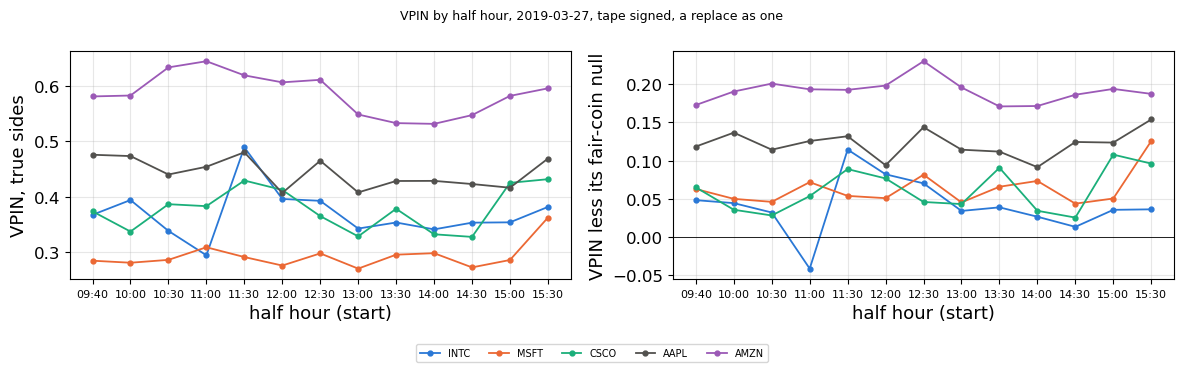

In [21]:
def vpin_report_strips(results, day=DAY):
    # VPIN by half hour on the signed tape: the true-sides level, the fair-coin null's mean (the mean over its draws of
    # the null's level in the buckets closed in the half hour: STRIP_NULL_DRAWS draws at most) and the excess, with the
    # buckets closed in each half hour (a half hour with a few buckets is a noisy value) and the strip's own standard
    # error (the standard deviation of the half-hour values over the root of how many there are). One y-axis a panel.
    # Returns the strips of each stock.
    strips = {}
    heading('VPIN by half hour, true sides against the fair-coin null', results, day)
    print(
        'Half hours by the time the buckets close; the first and the last are cut to the session. The strip\'s '
        f'fair-coin null is the mean of {STRIP_NULL_DRAWS} draws (the levels of the tables above use {NULL_DRAWS}).'
    )
    for label, key, digits, scale in (
        ('true sides', 'blocks: true', 3, 1.0),
        ('fair coin', 'blocks: fair coin mean', 3, 1.0),
        ('excess', 'blocks: excess', 3, 1.0),
        ('buckets', 'blocks: buckets closed', 0, 1.0),
    ):
        print(f'\n{label}:')
        print(stock_strips(results, lambda r, key=key: r['vpin'][TAPE][key], digits, scale, 7, 'stock'))
    for stock, result in results.items():
        v = result['vpin'][TAPE]
        strips[stock] = {key: v[key] for key in ('blocks: true', 'blocks: fair coin mean', 'blocks: excess')}
        values = np.array(v['blocks: excess'])
        assert len(values) == len(HAVE_BLOCKS), f'{stock}: not a value for each half hour of the session'
        assert np.allclose(
            values, np.array(v['blocks: true']) - np.array(v['blocks: fair coin mean']), equal_nan=True
        ), f'{stock}: the excess strip is not the true strip less the null strip'
        positive = int((values[np.isfinite(values)] > 0).sum())
        print(
            f'{stock:<8}excess above 0 in {positive} of {int(np.isfinite(values).sum())} half hours; strip se '
            f'{fmt(v["blocks: excess strip se"], 3)}; buckets closed in the session '
            f'{int(np.nansum(v["blocks: buckets closed"])):,}.'
        )
    fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.6))
    plot_strips(results, lambda r: r['vpin'][TAPE]['blocks: true'], 'VPIN, true sides', ax=axes[0])
    plot_strips(
        results, lambda r: r['vpin'][TAPE]['blocks: excess'], 'VPIN less its fair-coin null', ax=axes[1], zero=True
    )
    handles, labels = axes[0].get_legend_handles_labels()  # one legend a figure, under the panels (not over a line)
    for ax in axes:
        ax.get_legend().remove()
    fig.legend(handles, labels, loc='lower center', ncol=len(labels), fontsize=7)
    fig.suptitle(figure_title('VPIN by half hour', results, day), fontsize=9)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()
    return strips


if need(DAY):
    vpin_strips = vpin_report_strips(measured(DAY), DAY)

**VPIN against its two nulls.** The table "VPIN against its own nulls" (the signed tape, then the none tape under it) sets each stock's VPIN with true sides on 2019-03-27 against a fair-coin null drawn on the same fills (200 draws; the figure in brackets is the null's standard deviation) and against the shuffled-signs null. On the signed tape the level was 0.374 against a coin null of 0.330 (0.008) on INTC, an excess of +0.044 or +5.3 null standard deviations; 0.292 against 0.231 (0.005) on MSFT, +0.061 or +12.3; 0.382 against 0.320 (0.009) on CSCO, +0.062 or +6.9; 0.448 against 0.326 (0.004) on AAPL, +0.122 or +30.2; and 0.596 against 0.404 (0.007) on AMZN, +0.191 or +28.6. Against the shuffled-signs null, which keeps the orders' sizes and the share of signs that are buys and permutes the true signs among the signed orders, the excess was +0.045 (+5.5 null standard deviations) on INTC, +0.061 (+10.9) on MSFT, +0.060 (+7.3) on CSCO, +0.111 (+27.7) on AAPL and +0.189 (+29.1) on AMZN. That is within 0.002 of the coin's excess on four stocks and 0.011 below it on AAPL (a plain difference), where 44.6% of the orders bought and the shuffled null is 0.337 against the coin's 0.326. On the none tape, displayed executions alone, the excess over the coin null was +0.035 (+4.5) on INTC, +0.055 (+11.6) on MSFT, +0.050 (+6.1) on CSCO, +0.117 (+31.8) on AAPL and +0.204 (+30.9) on AMZN: lower than the signed tape's on four stocks and higher on AMZN, by 0.005 to 0.013 (plain differences). The excess is above 0 for every stock on both tapes and against both nulls.

What the excess is: how much more one-sided the signed volume of a bucket is than random signs on the same fills would make it. That the shuffled null, which holds the sizes and the share of buys fixed and breaks only the order of the signs, gives nearly the same excess says that the excess is how persistent the order signs are (how often a buy follows a buy), which the same-side share in the next paragraph puts in another form. It is not a measure of informed trading, and nothing here reads one. The simulator's 0.113 in ZI and Parlour (0.111 in Hawkes ZI) is sqrt(2 / (pi n)) at 50 equal-size fills a bucket, an identity of that simulator's equal-size market orders that no real stream has. The fair-coin null printed here takes its place, drawn on each stock's own fills and bucket size (V is 5,000 shares on INTC, MSFT and CSCO, 2,025 on AAPL and 450 on AMZN, at 34.7, 48.1, 37.5, 20.7 and 16.4 fills a bucket), and none of its means is 0.113. The signed tape holds the displayed executions and the hidden ones that a displayed run signs. Hidden volume was 8.64% (INTC), 9.59% (MSFT), 11.18% (CSCO), 11.15% (AAPL) and 25.57% (AMZN) of the shares executed, and 6.63%, 6.58%, 8.44%, 8.28% and 18.21% of the shares were unsigned hidden volume, which never reaches the signed tape's VPIN; the rest of the hidden volume sits inside displayed runs and takes their side. The none tape leaves every hidden execution out.

**The range over the 11 bucket origins.** The table "The range of VPIN's excess" starts the buckets at each minute from 09:30 to 09:40, with V fixed, and prints the excess at every origin. On the signed tape the excess ran from the lowest origin to the highest: +0.035 to +0.044 on INTC (+4.3 to +5.6 null standard deviations), +0.050 to +0.066 on MSFT (+9.1 to +13.1), +0.040 to +0.061 on CSCO (+4.6 to +7.1), +0.117 to +0.123 on AAPL (+28.6 to +34.1) and +0.186 to +0.192 on AMZN (+27.0 to +29.5), above 0 at 11 of 11 origins on each. An excess is one point of such a range: CSCO's +0.062 in the table above is 0.001 above the top of its range (a plain difference of +0.062 and +0.061). The VPIN prediction passed on all five stocks: the excess was above 0 at all 11 origins, and the share of aggressive orders on the side of the one before (the rule's line is 60%) was 69.2% on INTC, 66.1% on MSFT, 69.7% on CSCO, 67.1% on AAPL and 78.5% on AMZN. The verdict line's "the lowest is +X null standard deviations" is the figure of the origin with the lowest excess, and that is not always the lowest figure across the 11 origins, which is the table's "null sds, lowest". The two are the same on INTC (+4.3), MSFT (+9.1) and CSCO (+4.6) and differ on AAPL (+34.0 in the verdict, +28.6 in the table) and AMZN (+28.4 in the verdict, +27.0 in the table). The margin line under each VPIN verdict in section 6 gives its range over the 11 bucket origins (the first run's label said half hours, which was wrong).

VPIN is first defined when the first window of 50 buckets has closed. On the signed tape that was 09:39:54 on INTC, 09:38:34 on MSFT, 09:47:01 on CSCO, 09:32:27 on AAPL and 09:35:41 on AMZN, and VPIN was defined at 100.0%, 100.0%, 98.1%, 100.0% and 100.0% of the session's units. So on four stocks the first window had closed before 09:40 and on CSCO it had not until 09:47:01: VPIN is first defined at the times printed, and not at 09:40 on any stock. All five stocks passed, and they share the day's market factor, so this is one day's measurement five times and not five confirmations.

**The other rules.** The tick rule's VPIN sits above the true sides' on four stocks (INTC 0.565 against 0.374, MSFT 0.431 against 0.292, CSCO 0.545 against 0.382, AAPL 0.488 against 0.448) and below it on AMZN (0.569 against 0.596); notebook 14's was below in all five models (0.102 against 0.113 in ZI, 0.128 against 0.170 in Informed ZI). The quote rule at lag 0 is within 0.004 of the true sides' on each stock (0.378, 0.291, 0.386, 0.444 and 0.594), and the quote rule at lag 1 is above them on all five (0.446, 0.392, 0.441, 0.532 and 0.653). A rule's VPIN depends on how persistent that rule's own signs are as well as on how persistent the flow is, so a level set beside the true sides' is a statement about the rule's signs, and each rule's excess is over a null on its own signs. Bulk volume classification's level was 0.477 on INTC, 0.494 on MSFT, 0.498 on CSCO, 0.481 on AAPL and 0.453 on AMZN, against notebook 14's 0.471 to 0.524 in every model, with the mid unchanged over 10.5%, 6.0%, 12.0%, 5.6% and 5.7% of the buckets; section 3 returns to it.

**By half hour.** The strip "VPIN by half hour" (the figure under it draws the level and the excess of each stock, thirteen half hours of the signed tape; the strip's fair-coin null is the mean of 100 draws, where the tables use 200) has the excess above 0 in 12 of 13 half hours on INTC (-0.041 at 11:00, on 58 buckets, and +0.114 at 11:30, on 75) and in 13 of 13 on MSFT, CSCO, AAPL and AMZN. The strip's own standard error (se), the standard deviation of the thirteen values over the root of 13, is 0.010 on INTC, 0.006 on MSFT, 0.008 on CSCO, 0.005 on AAPL and 0.004 on AMZN. The buckets closed in the thinnest half hour were 33 on INTC (14:00), 37 on MSFT (13:30), 26 on CSCO (13:30), 116 on AAPL (13:30) and 56 on AMZN (13:30). The half hours differ in their buckets and are not exchangeable, so the strip se is the spread of one day's thirteen values and not the stock's uncertainty. No pattern across the day is claimed, and no two stocks are said to differ.

### Order-to-trade ratios

**The question.** How many messages does the book of a real stock carry for every aggressive order, in each half hour of the day, and how much of the answer is how the messages and the orders are counted? Notebook 14 measured the ratio for the model's own orders over a window of 10 units; a real book's ratio is of every participant's messages, so the two are not the same count and the simulator's figure is quoted beside the real one for what it is, and nothing is said to match.

**What is counted.** A message is an event of the stream: an add, a cancel of part of an order, a deletion, or a replace. A replace is one message of the book and two rows of the file (a deletion and a new order at one nanosecond), so the headline counts it as one message and the table prints it as two beside it (the difference is the number of replaces, which the cell asserts equals the frames' replace rows over two). A trade is an aggressive order (executions at one nanosecond with consecutive match numbers are one order); the deletions and paired reductions that an aggressive order makes inside its own event are no messages of their own. The session's ratio is a ratio of sums (all the session's messages over all its aggressive orders), and the half-hour values are the same ratio in each half hour; TTO is the shares traded over the shares ordered. Three sensitivities are printed: the grouping (the frames made with executions of one side within 100 microseconds taken as one aggressive order), the unknown tape (each hidden run that no displayed run signs counted as a message and a trade) and notebook 14's own window form (the mean over the units that have a trade in the last 10 units, with the share of units where there is none), which is not a ratio of sums.

**What notebook 14 found in the simulator** (seeds 101 to 108): 10.22 (se 0.03), 12.93 (0.17), 5.43 (0.03), 2.48 (0.00) and 8.65 (0.04) messages a trade in ZI, Hawkes ZI, MF 2008, Parlour and Informed ZI, with TTO of 0.166, 0.161, 0.274, 0.448 and 0.191, counting the model's own orders over 10 units; and a partial correlation of the ratio with the next unit's absolute change of the mid, given the last, of -0.09 to -0.24 in four models and -0.01 in MF 2008. The cell prints the ratio's figures beside the real ones.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27). With a replace as one message the session's ratio was 55.4 on NVDA and 137.8 on CMCSA (a block bootstrap standard error of 4.0 and 7.3 assuming exchangeable blocks); counting a replace as two gave 60.6 and 145.2, and the merged grouping 62.3 and 141.2 (a replace as one; these two are the exploration's counts divided, and no cell prints them), so the grouping moved the NVDA figure by about an eighth and CMCSA's by about a fortieth. The half-hour values ran from 35.1 to 76.9 on NVDA and from 88.7 to 163.5 on CMCSA. Notebook 14's window form gave 89.1 and 168.6, with no trade in the window for 9.2% and 30.7% of the units: a mean of window ratios is not the ratio of the sums, and it is undefined where a window has no trade.

**What is run.** For each stock on the day, the session table (aggressive orders, messages, replaces, the ratio a replace as one and as two with its block bootstrap and strip standard errors, TTO), the sensitivities, the three rates beside, the half-hour strips with the aggressive orders and the messages in each half hour, a figure of the ratio by half hour, and notebook 14's figures beside.


Order-to-trade ratios, messages per aggressive order: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace
as one.
The session's ratio of sums, a replace as one message and as two; "se (blocks)" is a block bootstrap over the half hours (1,000 draws) ASSUMING EXCHANGEABLE BLOCKS (they are not) and "strip se" the half-hour values' own.
     aggressive orders messages, a replace as one replaces OTR, a replace as one se (blocks) strip se OTR, a replace as two TTO, as one TTO, as two
INTC             9,445                  1,277,381   83,521                 135.2         5.7      4.7                 144.1      0.0178      0.0152
MSFT            24,879                  1,917,347  144,755                  77.1         3.6      3.7                  82.9      0.0438      0.0343
CSCO             9,632                    995,995   74,118                 103.4         2.9      2.8                 111.1      0.0305      0.0255
AAPL            32,884                  1,747,872  125,587 

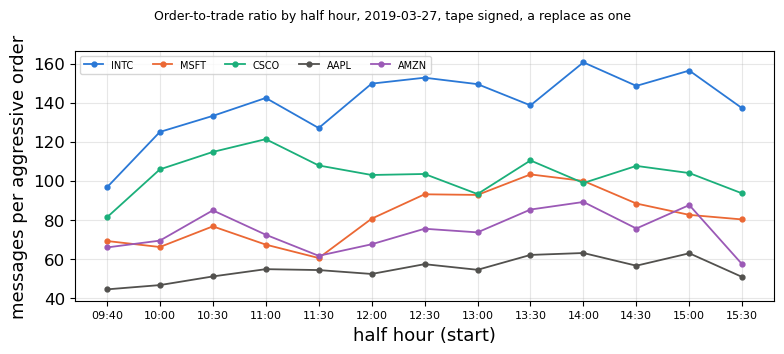


notebook 14, seeds 101 to 108, the simulator (a window of 10 units, the model's own orders only: not the same count as a real book's messages):
            OTR (messages a trade) TTO (lots traded a lot ordered)
ZI                    10.22 (0.03)                   0.166 (0.000)
Hawkes ZI             12.93 (0.17)                   0.161 (0.002)
MF 2008                5.43 (0.03)                   0.274 (0.001)
Parlour                2.48 (0.00)                   0.448 (0.000)
Informed ZI            8.65 (0.04)                   0.191 (0.001)
its three rates a unit of simulation time (seeds 1 to 8, the models' defaults; a real stock's are a second):
            events a unit mid changes a unit aggressive orders a unit
ZI                  59.80               4.06                     6.01
Hawkes ZI           59.84               3.90                     6.20
MF 2008             14.57               1.48                     2.75
Parlour             13.27               4.83                    

In [22]:
def otr_report(results, day=DAY):
    # Order-to-trade ratios: messages per aggressive order, the session's (a ratio of sums, which is not a mean of
    # ratios) and by half hour, a replace counted as one message and as two, with the grouping's sensitivity (frames
    # made with merge_within: successive same-side runs of executions within MERGE_WITHIN seconds are one aggressive
    # order) and each unsigned hidden run counted as a message and a trade (the unknown tape). A trade is an aggressive
    # order; deletions and paired reductions inside one are no messages of their own. TTO is the shares traded per
    # share ordered. Returns the session frame.
    rows, strips = {}, {}
    for stock, result in results.items():
        one, two = result['otr']['as one'], result['otr']['as two']
        merged, frames = result['merged'], result['frames']
        replaced = result['tape']['events as two'] - result['tape']['events as one']
        # a replace is two messages of the stream and one of the book: the difference is the replaces' second halves
        assert two['session']['messages'] - one['session']['messages'] == replaced == frames['replace rows'] // 2, (
            f'{stock}: a replace as two messages less a replace as one is not the replaces of the frames'
        )
        assert one['session']['trades'] == two['session']['trades'] == result['tape']['aggressive orders'], (
            f'{stock}: the trades of the order-to-trade ratio are not the aggressive orders'
        )
        for name, part in (('as one', one), ('as two', two)):
            assert sum(part['messages']) == part['session']['messages'], f'{stock}: half hours do not sum, {name}'
            assert sum(part['trades']) == part['session']['trades'], f'{stock}: half-hour trades do not sum, {name}'
            assert math.isclose(
                part['session']['otr'], part['session']['messages'] / part['session']['trades'], rel_tol=1e-12
            ), f'{stock}: the session ratio is not the ratio of its sums, {name}'
        if merged is not None:
            assert merged['aggressive orders'] <= one['session']['trades'], f'{stock}: grouping cannot add orders'
        window = result['otr']['window']
        rows[stock] = {
            'aggressive orders': one['session']['trades'],
            'messages, a replace as one': one['session']['messages'],
            'replaces': replaced,
            'OTR, a replace as one': one['session']['otr'],
            'se (blocks)': one['otr se'],
            'strip se': one['otr strip se'],
            'OTR, a replace as two': two['session']['otr'],
            'merged: as one': math.nan if merged is None else merged['otr as one']['session']['otr'],
            'merged: as two': math.nan if merged is None else merged['otr as two']['session']['otr'],
            'unknown tape: as one': result['otr']['unknown tape, as one']['otr'],
            'TTO, as one': one['session']['tto'],
            'TTO, as two': two['session']['tto'],
            'window form: OTR': window['OTR'],
            'window undefined %': 100 * window['undefined share'],
        }
        strips[stock] = {'as one': one, 'as two': two}
    table = pd.DataFrame(rows).T.infer_objects()
    heading('Order-to-trade ratios, messages per aggressive order', results, day)
    print(
        'The session\'s ratio of sums, a replace as one message and as two; "se (blocks)" is a block bootstrap over '
        f'the half hours ({DRAWS:,} draws) ASSUMING EXCHANGEABLE BLOCKS (they are not) and "strip se" the half-hour '
        'values\' own.'
    )
    print(
        shown(
            table[
                [
                    'aggressive orders',
                    'messages, a replace as one',
                    'replaces',
                    'OTR, a replace as one',
                    'se (blocks)',
                    'strip se',
                    'OTR, a replace as two',
                    'TTO, as one',
                    'TTO, as two',
                ]
            ],
            {
                'aggressive orders': ',.0f',
                'messages, a replace as one': ',.0f',
                'replaces': ',.0f',
                'OTR, a replace as one': '.1f',
                'se (blocks)': '.1f',
                'strip se': '.1f',
                'OTR, a replace as two': '.1f',
                'TTO, as one': '.4f',
                'TTO, as two': '.4f',
            },
        )
    )
    print(
        f'\nSensitivities: "merged" takes executions of one side within {1e6 * MERGE_WITHIN:.0f} microseconds as one '
        'aggressive order; "unknown tape" counts each unsigned hidden run as a message and a trade (a replace as '
        'one); "window form" is notebook 14\'s own figure (the mean over the units with a trade in the last 10 '
        'units, with the share of units where there is none), here for the comparison with the simulator: it is not '
        'the ratio of sums.'
    )
    print(
        shown(
            table[
                ['merged: as one', 'merged: as two', 'unknown tape: as one', 'window form: OTR', 'window undefined %']
            ],
            {
                'merged: as one': '.1f',
                'merged: as two': '.1f',
                'unknown tape: as one': '.1f',
                'window form: OTR': '.1f',
                'window undefined %': '.1f',
            },
        )
    )
    print('\nBeside, the three rates a second:')
    print(shown(rates_beside(results), RATE_FORMATS))
    for name, label in (('as one', 'a replace as one message'), ('as two', 'a replace as two messages')):
        print(f'\nmessages per aggressive order by half hour, {label}:')
        print(stock_strips(results, lambda r, name=name: r['otr'][name]['otr'], 1, 1.0, 7, 'stock'))
    print('\naggressive orders in each half hour:')
    print(stock_strips(results, lambda r: r['otr']['as one']['trades'], 0, 1.0, 7, 'stock'))
    print('\nmessages in each half hour, a replace as one:')
    print(stock_strips(results, lambda r: r['otr']['as one']['messages'], 0, 1.0, 8, 'stock'))
    fig, ax = plt.subplots(figsize=(8.0, 3.6))
    plot_strips(results, lambda r: r['otr']['as one']['otr'], 'messages per aggressive order', ax=ax)
    fig.suptitle(figure_title('Order-to-trade ratio by half hour', results, day), fontsize=9)
    fig.tight_layout()
    plt.show()
    return table


if need(DAY):
    otr_table = otr_report(measured(DAY), DAY)
    show_nb14(
        {
            'OTR (messages a trade)': 'OTR (messages a trade)',
            'TTO (lots traded a lot ordered)': 'TTO (lots traded a lot ordered)',
        },
        'a window of 10 units, the model\'s own orders only: not the same count as a real book\'s messages',
    )

**The session's ratio.** The table "Order-to-trade ratios" counts, for each stock on 2019-03-27 (09:40 to 15:50, the signed tape), every participant's messages (adds, cancels of part of an order, deletions and replaces) over the aggressive orders, with a replace as one message. The ratio of the session's sums was 135.2 on INTC (9,445 aggressive orders, 1,277,381 messages), 77.1 on MSFT (24,879; 1,917,347), 103.4 on CSCO (9,632; 995,995), 53.2 on AAPL (32,884; 1,747,872) and 72.4 on AMZN (15,176; 1,099,163). The block-bootstrap standard error (se) over the half hours (1,000 draws, ASSUMING EXCHANGEABLE BLOCKS, which they are not) was 5.7, 3.6, 2.9, 1.6 and 2.5, and the strip's own se (the standard deviation of the thirteen half-hour values over the root of 13) 4.7, 3.7, 2.8, 1.6 and 2.8. Counting a replace as two messages gave 144.1 on INTC, 82.9 on MSFT, 111.1 on CSCO, 57.0 on AAPL and 78.4 on AMZN; the number of replaces, which is the difference in messages, was 83,521, 144,755, 74,118, 125,587 and 90,887. The shares traded over the shares ordered (TTO) were 0.0178, 0.0438, 0.0305, 0.0364 and 0.0283 with a replace as one and 0.0152, 0.0343, 0.0255, 0.0315 and 0.0205 as two. Each figure is that stock's on that day, under one grouping and one way of counting a replace, and the block bootstrap's se is of a resampling of half hours that are not exchangeable, so it is not the stock's uncertainty.

The ratio counts every participant's messages over aggressive orders. Notebook 14's figures (10.22 messages a trade in ZI, 12.93 in Hawkes ZI, 5.43 in MF 2008, 2.48 in Parlour and 8.65 in Informed ZI) count the model's own orders over a window of 10 units, which is not the same count, so the real ratios are not set against them, and nothing is said to match.

**The sensitivities.** The table "Sensitivities" re-counts the ratio three ways. Merging the executions of one side within 100 microseconds into one aggressive order, a replace as one, gave 140.9 on INTC, 79.9 on MSFT, 108.3 on CSCO, 55.4 on AAPL and 78.2 on AMZN, higher than the session's ratio by 5.7, 2.8, 4.9, 2.2 and 5.8 (plain differences); a replace as two under the merged grouping gave 150.1, 85.9, 116.4, 59.4 and 84.7. A one-number ratio is a statement under one grouping. The unknown tape, which counts each hidden run that no displayed run signs as a message and a trade, gave 118.0, 69.0, 86.2, 47.4 and 53.6, lower by 17.2, 8.1, 17.2, 5.8 and 18.8 (plain differences). Notebook 14's own window form, the mean over the units (seconds, here) that have a trade in the last 10 units, gave 181.8 on INTC, 107.4 on MSFT, 138.9 on CSCO, 68.7 on AAPL and 113.1 on AMZN, above the ratio of sums on each stock, with no trade in the window for 15.2%, 1.9%, 15.3%, 0.2% and 10.0% of the units, where the form is undefined. It is not a ratio of sums, and it is there for the comparison with the simulator only. No cell of this notebook prints the count of aggressive orders under the merged grouping, so none is quoted.

**By half hour.** The strips "messages per aggressive order by half hour" and the figure under them show thirteen half hours of the signed tape, a replace as one. The lowest and the highest half hour were 96.6 (09:40) and 160.7 (14:00) on INTC, 60.4 (11:30) and 103.2 (13:30) on MSFT, 81.2 (09:40) and 121.3 (11:00) on CSCO, 44.3 (09:40) and 62.9 (14:00) on AAPL, and 57.1 (15:30) and 89.1 (14:00) on AMZN. The aggressive orders in the thinnest half hour were 461 on INTC (14:00), 976 on MSFT (13:30), 465 on CSCO (13:30), 1,648 on AAPL (13:30) and 737 on AMZN (13:30); INTC's highest half hour is also its thinnest, and so is MSFT's. A ratio over a few hundred orders is noisy, and the half hours are not exchangeable, so the block bootstrap's se above is read as a spread and not as the stock's uncertainty. No pattern is said to hold across stocks, and no two stocks are said to differ.

### Resilience

**The question.** When a take or a cancel leaves the depth near the touch below half its baseline, how often does the quote move away before the depth comes back, how long does the recovery take when it does, and how quickly does the quote itself come back after a take that moved it (Large's restoration)?

**What is measured.** The depth is the visible shares at the K = 3 prices from the side's best quote, a tick a cent; the baseline is the median of the once-a-unit samples over the last 100 units. An episode starts when a take or a cancel leaves that depth below 0.5 of the baseline, keeps those prices as its anchor, and ends *recovered* when the depth there is back at 0.9 of the baseline, or *abandoned* when the best quote has moved more than K ticks from the anchor or the side is empty. The onset "below the line" is the dashboard's; "crossing" counts only the falls through the line and is printed beside it. A limit order that improves the quote never starts an episode. Large's restoration is the share of the takes that moved the quote that a limit order put back within 30 seconds, and after how long. The identity (shares arrived less canceled less taken equals the change in depth over an episode) is counted, never asserted: a hidden or a priced execution takes shares that the book does not show.

**What cannot be compared.** K is fixed in ticks, so it is a different distance in each stock's spreads: a stock whose median spread is six ticks has a reach of half its spread, and one whose spread is a tick has three spreads. Every table below therefore starts with K in spreads, the number of episodes and the abandoned share, a stock's figures are its own, and no table or sentence sets one stock's resilience against another's. A half-hour strip is shown only for a half hour with 30 ended episodes or more.

**What notebook 14 found in the simulator** (seeds 101 to 108, K = 3 prices, onset below; a unit is the simulator's unit of time): the recovered share of ended episodes was 0.41 (se 0.01), 0.23 (0.02), 0.54 (0.01), 0.07 (0.00) and 0.33 (0.01) in ZI, Hawkes ZI, MF 2008, Parlour and Informed ZI, the median recovery 32.0 (1.4), 24.4 (1.1), 24.6 (1.7), 2.6 (0.1) and 18.6 (0.6) units, Large's restoration within 30 units 0.984, 0.979, 0.940, 0.974 and 0.983, the identity's largest gap 0 in every run, and the shifting-window definition (depth measured from the side's current best quote) 14.3, 7.0, 5.3, 1.3 and 11.2 times the anchored definition's episodes.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27; each stock's own figures, with K in its own spreads). On NVDA the reach was 0.50 of the median spread; there were 11,054 episodes, an abandoned share of 0.636 and a median recovery of 1.00 s, 0.00 s in the first half hour (about half of the first half hour's recovered episodes lasted under a millisecond, in a burst of a few minutes), the quote was put back within 30 s after 0.762 of the takes that moved it, 253 of the 344 episodes whose identity had a gap took a hidden or priced lot, and the shifting-window definition started 0.98 times the episodes. On CMCSA the reach was 3.00 spreads; there were 65 episodes, an abandoned share of 0.108 and a median recovery of 7.44 s, no half hour with 30 episodes (so no strip), the quote put back within 30 s after 0.756 of the takes, all 6 of the episodes with a gap took a hidden or priced lot, and the shifting-window definition started 0.92 times the episodes.

**What is run.** For each stock on the day, recovery under both onsets, restoration and the refill, the identity and the shifting-window definition, and the figures by the spread before the starting event, each with K in spreads, the episodes and the abandoned share in front, and notebook 14's figures beside; then the half-hour strips, only where a half hour has the episodes for one, and a figure with a panel for each stock that has one.

In [23]:
def resil_lead(results, onset):
    # What goes beside every resilience figure: the reach in spreads (K = RESILIENCE_TICKS ticks over the stock's median
    # spread), the number of episodes and the share of them abandoned before the depth came back
    lead = {}
    for stock, result in results.items():
        r = result['resilience'][onset]
        assert math.isclose(
            r['reach: ticks in median spreads (unit samples)'],
            RESILIENCE_TICKS / r['median spread (ticks)'],
            rel_tol=1e-12,
        ), f'{stock}: the reach in spreads is not K over the median spread'
        if r['ended']:
            assert math.isclose(r['recovered share'] + r['abandoned share'], 1.0, abs_tol=1e-12), f'{stock}: shares'
        lead[stock] = {
            'K in spreads': r['reach: ticks in median spreads (unit samples)'],
            'episodes': r['episodes'],
            'abandoned': r['abandoned share'],
        }
    return pd.DataFrame(lead).T.infer_objects()


def resil_report(results, day=DAY):
    # Resilience: episodes of depleted depth within K = RESILIENCE_TICKS ticks of the touch (depleted below 0.5 of a
    # rolling-median baseline, recovered at 0.9, each episode anchored where it began), how often the quote moves away
    # from the anchor before the depth recovers (abandoned), how long recovery takes, Large's restoration of the quote,
    # what arrives and leaves while an
    # episode is open, the identity arrived - canceled - taken = change in depth COUNTED (a hidden or priced lot taken
    # breaks it) and the shifting-window definition beside. Every table starts with K in spreads, the episodes and the
    # abandoned share. K is fixed in ticks, so it is a different distance in each stock's spreads: no two stocks'
    # figures are to be compared. Returns the frames.
    frames = {}
    boot = {stock: result['resilience bootstrap'] for stock, result in results.items()}
    for onset in ('below', 'crossing'):
        lead = resil_lead(results, onset)
        r = {stock: result['resilience'][onset] for stock, result in results.items()}
        extra = pd.DataFrame(
            {
                stock: {
                    'abandoned at once': 100 * r[stock]['abandoned at once (zero length) share'],
                    'recovered': r[stock]['recovered share'],
                    'a second': r[stock]['started a unit'],
                    'median recovery (s)': r[stock]['median recovery'],
                    'p90 (s)': r[stock]['p90 recovery'],
                }
                for stock in results
            }
        ).T
        if onset == 'below':
            extra['abandoned se'] = pd.Series({stock: boot[stock]['abandoned share se'] for stock in results})
            extra['median recovery se'] = pd.Series({stock: boot[stock]['median recovery se'] for stock in results})
        frames[onset] = lead.join(extra)
    heading('Resilience: recovery of the depth within K ticks of the touch', results, day)
    print(
        f'K = {RESILIENCE_TICKS} ticks, a tick a cent: "K in spreads" is K over the stock\'s median spread. An '
        'episode begins when a take or a cancel leaves the depth at the K prices from the side\'s best quote below '
        'half its baseline (the median of the last 100 unit samples); it keeps those prices as its anchor and ends '
        'recovered when the depth there is back at 0.9 of the baseline, or abandoned when the best quote has moved '
        'more than K ticks from the anchor or the side is empty ("abandoned at once": the share of the abandoned '
        'that ended in the instant they began). Onset "below" is the dashboard\'s; "crossing" counts only the falls '
        'through the line. The standard errors are a block bootstrap ASSUMING EXCHANGEABLE BLOCKS. Times are '
        'seconds.'
    )
    print('\nOnset below the line:')
    print(
        shown(
            frames['below'],
            {
                'K in spreads': '.2f',
                'episodes': ',.0f',
                'abandoned': '.3f',
                'abandoned at once': '.1f',
                'recovered': '.3f',
                'a second': '.4f',
                'median recovery (s)': '.2f',
                'p90 (s)': '.1f',
                'abandoned se': '.3f',
                'median recovery se': '.2f',
            },
        )
    )
    print('\nOnset crossing the line:')
    print(
        shown(
            frames['crossing'].drop(columns=['abandoned at once']),
            {
                'K in spreads': '.2f',
                'episodes': ',.0f',
                'abandoned': '.3f',
                'recovered': '.3f',
                'a second': '.4f',
                'median recovery (s)': '.2f',
                'p90 (s)': '.1f',
            },
        )
    )
    # Large's restoration, the refill and the identity, onset below
    lead, r = resil_lead(results, 'below'), {stock: result['resilience']['below'] for stock, result in results.items()}
    wanted = {
        'quote-moving takes a second': 'quote-moving takes a unit',
        'restored within 30 s': 'restored share',
        'median restoration (s)': 'median restoration',
        'restorations': 'restorations',
        'baseline depth (shares)': 'baseline depth (shares)',
        'arrived a second': 'arrived a unit of episode time',
        'canceled a second': 'canceled a unit of episode time',
        'taken a second': 'taken a unit of episode time',
        'net a second': 'net a unit',
        'median deficit': 'median deficit',
        'median gained': 'median depth gained',
    }
    refill = lead.join(pd.DataFrame({stock: {k: r[stock][v] for k, v in wanted.items()} for stock in results}).T)
    frames['refill'] = refill
    print(
        '\nLarge\'s restoration (of the takes that moved the quote, the share that a limit order put back within 30 '
        's) and what arrives, is canceled and is taken a second of episode time, in shares, over the recovered '
        'episodes:'
    )
    print(
        shown(
            refill,
            {
                'K in spreads': '.2f',
                'episodes': ',.0f',
                'abandoned': '.3f',
                'quote-moving takes a second': '.3f',
                'restored within 30 s': '.3f',
                'median restoration (s)': '.2f',
                'restorations': ',.0f',
                'baseline depth (shares)': ',.0f',
                'arrived a second': ',.1f',
                'canceled a second': ',.1f',
                'taken a second': ',.1f',
                'net a second': ',.1f',
                'median deficit': ',.0f',
                'median gained': ',.0f',
            },
        )
    )
    gap_names = {
        'episodes with a gap': 'identity: episodes with a gap',
        'share of ended': 'identity: share of ended episodes with a gap',
        'took a hidden or priced lot': 'identity: gaps in episodes that took a hidden or priced lot',
        'largest gap (shares)': 'identity: largest gap (shares)',
        'shifting-window episodes a second': 'shifting-window episodes a unit',
        'times as many': 'shifting times as many',
        'from a quote-improving arrival': 'shifting: share started by a quote-improving arrival',
    }
    gaps = lead.join(pd.DataFrame({stock: {k: r[stock][v] for k, v in gap_names.items()} for stock in results}).T)
    frames['identity'] = gaps
    for stock in results:
        assert gaps.loc[stock, 'took a hidden or priced lot'] <= gaps.loc[stock, 'episodes with a gap'], (
            f'{stock}: gaps'
        )
    print(
        '\nThe identity arrived - canceled - taken = change in depth, counted on every ended episode (it fails where '
        'a hidden or priced lot was taken, which the book does not show), and the shifting-window definition (depth '
        'measured from the side\'s current best quote), which counts episodes that the anchored definition does not:'
    )
    print(
        shown(
            gaps,
            {
                'K in spreads': '.2f',
                'episodes': ',.0f',
                'abandoned': '.3f',
                'episodes with a gap': ',.0f',
                'share of ended': '.3f',
                'took a hidden or priced lot': ',.0f',
                'largest gap (shares)': ',.0f',
                'shifting-window episodes a second': '.4f',
                'times as many': '.2f',
                'from a quote-improving arrival': '.3f',
            },
        )
    )
    # by the spread before the starting event: a class with under RESILIENCE_STRIP_MIN episodes is a count only
    rows, index = [], []
    reach = {
        0: f'{RESILIENCE_TICKS / 1:.2f}',
        1: f'{RESILIENCE_TICKS / 2:.2f}',
        2: f'at most {RESILIENCE_TICKS / 3:.2f}',
    }
    for stock in results:
        total = 0
        for k, label in enumerate(CLASSES):
            c = r[stock]['by spread: ' + label]
            total += c['episodes']
            enough = c['episodes'] >= RESILIENCE_STRIP_MIN
            rows.append(
                {
                    'K in spreads': reach[k],
                    'episodes': c['episodes'],
                    'abandoned': 1 - c['recovered share'] if enough else math.nan,
                    'median recovery (s)': c['median recovery'] if enough else math.nan,
                }
            )
            index.append((stock, label))
        assert total <= r[stock]['ended'], f'{stock}: more episodes by spread class than ended episodes'
    by_class = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'spread before']))
    frames['by spread'] = by_class
    print(
        f'\nBy the spread before the starting event (ended episodes; a class with under {RESILIENCE_STRIP_MIN} '
        'episodes is a count only):'
    )
    print(shown(by_class, {'episodes': ',.0f', 'abandoned': '.3f', 'median recovery (s)': '.2f'}))
    print(
        '\nbeside, the three rates a second (a replace as one), and the median spread in ticks the reach is measured '
        'against:'
    )
    beside = rates_beside(results).join(
        stock_table(results, {'median spread (ticks)': lambda x: x['tape']['median spread (ticks, unit samples)']})
    )
    print(shown(beside, {'events a second': '.2f', 'mid changes a second': '.3f', 'median spread (ticks)': '.1f'}))
    print(
        'K is fixed in ticks, so a stock with a wide spread has a reach of a fraction of its spread and one with a '
        f'one-cent spread has {RESILIENCE_TICKS} spreads: no figure above is to be compared between two stocks.'
    )
    return frames


if need(DAY):
    resil_tables = resil_report(measured(DAY), DAY)
    show_nb14(
        {
            'baseline depth (lots)': 'baseline depth (lots)',
            'episodes a unit': 'episodes a unit',
            'recovered share': 'recovered share',
            'median recovery (units)': 'median recovery (units)',
            '90th percentile': '90th percentile',
        },
        'onset below, K = 3 prices; a unit is the simulator\'s unit of time and a lot is 5 shares',
    )
    show_nb14(
        {
            'quote-moving takes a unit': 'quote-moving takes a unit',
            'restored within 30 units': 'restored within 30 units',
            'median restoration (units)': 'median restoration (units)',
            'crossing: recovered share': 'crossing: recovered share',
            'crossing: median recovery': 'crossing: median recovery',
            'shifting-window episodes a unit': 'shifting-window episodes a unit',
            'times as many': 'times as many',
        },
        'restoration, the crossing onset and the shifting-window definition',
    )


Resilience: recovery of the depth within K ticks of the touch: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a
replace as one.
K = 3 ticks, a tick a cent: "K in spreads" is K over the stock's median spread. An episode begins when a take or a cancel leaves the depth at the K prices from the side's best quote below half its baseline (the median of the last 100 unit samples); it keeps those prices as its anchor and ends recovered when the depth there is back at 0.9 of the baseline, or abandoned when the best quote has moved more than K ticks from the anchor or the side is empty ("abandoned at once": the share of the abandoned that ended in the instant they began). Onset "below" is the dashboard's; "crossing" counts only the falls through the line. The standard errors are a block bootstrap ASSUMING EXCHANGEABLE BLOCKS. Times are seconds.

Onset below the line:
     K in spreads episodes abandoned abandoned at once recovered a second median recovery (s) p90 (s) abandoned se median


notebook 14, seeds 101 to 108, the simulator (onset below, K = 3 prices; a unit is the simulator's unit of time and a lot is 5 shares):
            baseline depth (lots) episodes a unit recovered share median recovery (units) 90th percentile
ZI                        190 (9)   0.048 (0.001)     0.41 (0.01)              32.0 (1.4)      91.8 (4.5)
Hawkes ZI                220 (18)   0.091 (0.008)     0.23 (0.02)              24.4 (1.1)      65.0 (4.7)
MF 2008                  155 (11)   0.041 (0.001)     0.54 (0.01)              24.6 (1.7)      82.8 (4.5)
Parlour                    34 (2)   0.639 (0.006)     0.07 (0.00)               2.6 (0.1)       7.4 (0.4)
Informed ZI               202 (8)   0.083 (0.002)     0.33 (0.01)              18.6 (0.6)      58.1 (2.2)
its three rates a unit of simulation time (seeds 1 to 8, the models' defaults; a real stock's are a second):
            events a unit mid changes a unit aggressive orders a unit
ZI                  59.80               4.06    


notebook 14, seeds 101 to 108, the simulator (restoration, the crossing onset and the shifting-window definition):
            quote-moving takes a unit restored within 30 units median restoration (units) crossing: recovered share crossing: median recovery shifting-window episodes a unit times as many
ZI                        2.09 (0.01)            0.984 (0.000)                0.58 (0.00)               0.67 (0.02)                17.1 (0.8)                   0.692 (0.006)          14.3
Hawkes ZI                 1.95 (0.05)            0.979 (0.001)                0.50 (0.00)               0.55 (0.02)                14.1 (1.2)                   0.635 (0.017)           7.0
MF 2008                   0.76 (0.01)            0.940 (0.001)                1.71 (0.02)               0.66 (0.01)                17.4 (0.4)                   0.217 (0.004)           5.3
Parlour                   2.71 (0.01)            0.974 (0.001)                0.79 (0.01)               0.17 (0.00)                 


Resilience by half hour: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
A half hour is a value only where at least 30 episodes ended in it (restorations: that many quote-moving takes); the half hours from the open, the first and the last cut to the session.

INTC: K = 3.00 spreads, 66 episodes, abandoned 0.182; 0 of 13 half hours have 30 episodes or more.
episodes  09:40   10:00   10:30   11:00   11:30   12:00   12:30   13:00   13:30   14:00   14:30   15:00   15:30
INTC         19      15       6       4      11       3       3       0       1       1       1       0       2
no strip: no half hour has enough episodes.
Large's restoration (the quote put back after a take that moved it: a different count, at least 30 takes resolved in a half hour):
median s  09:40   10:00   10:30   11:00   11:30   12:00   12:30   13:00   13:30   14:00   14:30   15:00   15:30
INTC       2.02    2.52    2.03    3.28    2.00    2.86    2.77    3.64    2.82    3.05    3.50    3.62 

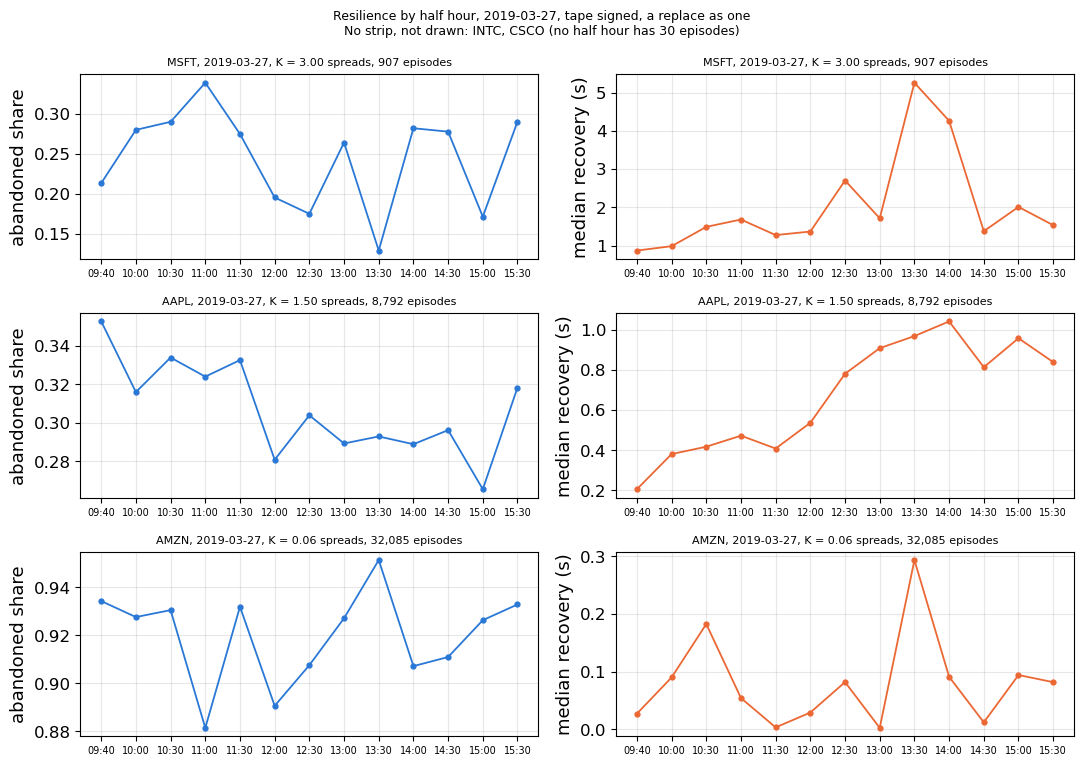

In [24]:
def resil_report_strips(results, day=DAY):
    # Resilience by half hour, only where a half hour has RESILIENCE_STRIP_MIN ended episodes or more (a restoration
    # strip where it has that many restorations): a stock with no such half hour shows its counts and no strip. Each
    # stock is its own panel with its own axis, since K is a different distance in each stock's spreads and the figures
    # are not to be compared. Returns {stock: the strips shown}.
    shown_strips = {}
    heading('Resilience by half hour', results, day)
    print(
        f'A half hour is a value only where at least {RESILIENCE_STRIP_MIN} episodes ended in it (restorations: that '
        'many quote-moving takes); the half hours from the open, the first and the last cut to the session.'
    )
    for stock, result in results.items():
        r = result['resilience']['below']
        ended = np.array(r['blocks: ended episodes'])
        abandoned, recovery = np.array(r['blocks: abandoned share']), np.array(r['blocks: median recovery'])
        assert len(ended) == len(HAVE_BLOCKS) and len(abandoned) == len(HAVE_BLOCKS), f'{stock}: a value a half hour'
        assert np.isfinite(abandoned).sum() == r['blocks with a strip'] == (ended >= RESILIENCE_STRIP_MIN).sum(), (
            f'{stock}: the abandoned strip has a value in a half hour that has under {RESILIENCE_STRIP_MIN} episodes'
        )
        assert not (np.isfinite(abandoned) & (ended < RESILIENCE_STRIP_MIN)).any(), f'{stock}: a thin half hour shown'
        assert r['strip shown'] == bool(r['blocks with a strip']), f'{stock}: strip shown is not blocks with a strip'
        print(
            f'\n{stock}: K = {fmt(r["reach: ticks in median spreads (unit samples)"], 2)} spreads, {r["episodes"]:,} '
            f'episodes, abandoned {fmt(r["abandoned share"], 3)}; {r["blocks with a strip"]} of {len(HAVE_BLOCKS)} '
            f'half hours have {RESILIENCE_STRIP_MIN} episodes or more.'
        )
        one = {stock: result}
        print(stock_strips(one, lambda x: x['resilience']['below']['blocks: ended episodes'], 0, 1.0, 7, 'episodes'))
        if r['strip shown']:
            print(
                stock_strips(one, lambda x: x['resilience']['below']['blocks: abandoned share'], 3, 1.0, 7, 'abandoned')
            )
            print(
                stock_strips(
                    one, lambda x: x['resilience']['below']['blocks: median recovery'], 2, 1.0, 7, 'recovery s'
                )
            )
            shown_strips[stock] = {'abandoned': abandoned, 'median recovery': recovery}
        else:
            print('no strip: no half hour has enough episodes.')
        restoration = r['blocks: median restoration']
        if np.isfinite(restoration).any():
            print(
                'Large\'s restoration (the quote put back after a take that moved it: a different count, at least '
                f'{RESILIENCE_STRIP_MIN} takes resolved in a half hour):'
            )
            print(
                stock_strips(
                    one, lambda x: x['resilience']['below']['blocks: median restoration'], 2, 1.0, 7, 'median s'
                )
            )
    if shown_strips:
        fig, axes = plt.subplots(len(shown_strips), 2, figsize=(11.0, 2.6 * len(shown_strips)), squeeze=False)
        x = np.arange(len(HAVE_BLOCKS))
        for row, (stock, strip) in enumerate(shown_strips.items()):
            for column, (name, label, color) in enumerate(
                (('abandoned', 'abandoned share', BLUE), ('median recovery', 'median recovery (s)', ORANGE))
            ):
                ax = axes[row, column]
                ax.plot(x, strip[name], marker='o', markersize=3.5, linewidth=1.3, color=color)
                ax.set_xticks(x, [BLOCK_LABELS[b] for b in HAVE_BLOCKS], fontsize=7)
                ax.set_ylabel(label)
                reach = results[stock]['resilience']['below']['reach: ticks in median spreads (unit samples)']
                episodes = results[stock]['resilience']['below']['episodes']
                ax.set_title(
                    f'{stock}, {day_text(day)}, K = {reach:.2f} spreads, {episodes:,} episodes'
                    + (' (exploration)' if stock in EXPLORED else ''),
                    fontsize=8,
                )
        none_shown = [stock for stock in results if stock not in shown_strips]
        note = (
            f'\nNo strip, not drawn: {", ".join(none_shown)} (no half hour has {RESILIENCE_STRIP_MIN} episodes)'
            if none_shown
            else ''
        )
        fig.suptitle(figure_title('Resilience by half hour', results, day) + note, fontsize=9)
        fig.tight_layout()
        plt.show()
    else:
        print('\nNo stock has a half hour with enough episodes: no figure.')
    return shown_strips


if need(DAY):
    resil_strips = resil_report_strips(measured(DAY), DAY)

**Recovery.** The table "Resilience: recovery of the depth within K ticks of the touch" (onset below the line, then the crossing onset) is, for each stock on 2019-03-27, what a reach of K = 3 ticks gave. The standard errors (se) are a block bootstrap ASSUMING EXCHANGEABLE BLOCKS, which the half hours are not. Each sentence below is that stock's on that day with that reach, and no two stocks' figures are set against each other.

- INTC: K was 3.00 spreads and there were 66 episodes (under 100); the abandoned share was 0.182 (se 0.040), the recovered share 0.818, the median recovery 3.58 s (se 0.63) and the 90th percentile 13.4 s; with the crossing onset there were 62 episodes, an abandoned share of 0.194, a recovered share of 0.806 and a median recovery of 3.41 s.
- MSFT: K was 3.00 spreads and there were 907 episodes; the abandoned share was 0.260 (se 0.015), the recovered share 0.740, the median recovery 1.56 s (se 0.15) and the 90th percentile 7.5 s; with the crossing onset, 884 episodes, 0.251, 0.749 and 1.54 s.
- CSCO: K was 3.00 spreads and there were 82 episodes (under 100); the abandoned share was 0.110 (se 0.026), the recovered share 0.890, the median recovery 4.06 s (se 1.01) and the 90th percentile 17.0 s; with the crossing onset, the same 82 episodes, 0.110, 0.890 and 4.06 s.
- AAPL: K was 1.50 spreads and there were 8,792 episodes; the abandoned share was 0.315 (se 0.008), the recovered share 0.685, the median recovery 0.52 s (se 0.08) and the 90th percentile 2.8 s; with the crossing onset, 7,882 episodes, 0.320, 0.680 and 0.57 s.
- AMZN: K was 0.06 spreads and there were 32,085 episodes; the abandoned share was 0.918 (se 0.006), with 72.9% of the abandoned ending in the instant they began, the recovered share 0.082, the median recovery 0.04 s (se 0.02) and the 90th percentile 1.6 s; with the crossing onset, 22,098 episodes, an abandoned share of 0.887, a recovered share of 0.113 and a median recovery of 0.03 s.

The reach is a different distance in each stock's spreads (the median spread was 1.0, 1.0, 1.0, 2.0 and 52.0 ticks), which is why the table starts with K in spreads. Notebook 14's recovered shares of 0.07 to 0.54 and median recoveries of 2.6 to 32.0 units are beside the real ones in the same table, in the simulator's unit of time and at its own reach, and nothing is called a match. INTC and CSCO have a few dozen episodes each, so their figures are the count and little else.

**Restoration and the refill.** The table of Large's restoration counts the takes that moved the quote and the share that a limit order put back within 30 s. The quote-moving takes a second were 0.207 on INTC, 0.596 on MSFT, 0.190 on CSCO, 0.965 on AAPL and 0.461 on AMZN; the share restored within 30 s was 0.770, 0.871, 0.782, 0.876 and 0.731, and the median restoration 2.63 s, 0.92 s, 2.14 s, 1.01 s and 4.20 s. Notebook 14's share restored within 30 units was 0.940 to 0.984, in the simulator's unit of time. Over the recovered episodes the table also prints what arrived, was canceled and was taken a second of episode time, in shares. On INTC 3,436.9 arrived, 2,528.8 were canceled and 124.1 were taken, a net refill of 784.0 (0.228 of the arrivals, a plain ratio); on MSFT 1,862.1, 1,359.1 and 78.9, net 424.1 (0.228); on CSCO 2,237.2, 1,633.1 and 55.5, net 548.5 (0.245); on AAPL 1,666.8, 855.8 and 61.9, net 749.1 (0.449); on AMZN 159.8, 4.0 and 0.1, net 155.7 (0.974). On every stock the shares canceled were more than the shares taken, and the net refill is what the cancels and the takes leave of the arrivals. So depth came back in these episodes through arrivals, and not all of what arrived stayed: on INTC, MSFT and CSCO the cancels removed about three quarters of the arrivals (2,528.8 of 3,436.9, 1,359.1 of 1,862.1 and 1,633.1 of 2,237.2, plain ratios of printed figures). A refill rate or a cancel rate read from these rows is what that reach gave on that day, and not a property of the stock.

**The identity and the shifting-window definition.** The identity (arrived less canceled less taken equals the change in depth) is counted on every episode and never asserted, and it fails where a hidden or priced lot was taken, which the book does not show. Notebook 14's largest gap was 0 in every run, which needs only that nothing in the simulator is hidden or priced. On INTC 9 of the 66 episodes (0.136) had a gap, 5 of them with a hidden or priced lot taken, and the largest gap was 3,300 shares; on MSFT 116 of 907 (0.128), 93 and 1,602; on CSCO 8 of 82 (0.098), 5 and 470; on AAPL 342 of 8,792 (0.039), 289 and 1,000; on AMZN 188 of 32,085 (0.006), 162 and 152. The table does not say what accounts for the gaps of the other episodes. The shifting-window definition, which measures the depth from the side's current best quote, started 0.0030 episodes a second on INTC, 0.0347 on MSFT, 0.0029 on CSCO, 0.5499 on AAPL and 0.8363 on AMZN: 1.02, 0.85, 0.79, 1.39 and 0.58 times the anchored definition's episodes, where notebook 14's multiple was 1.3 to 14.3 in its five models. Of the shifting-window episodes, 0.269 (INTC), 0.300 (MSFT), 0.246 (CSCO), 0.478 (AAPL) and 0.373 (AMZN) started at a quote-improving arrival. Nothing here says why a stock's multiple is what it is.

**By the spread before the starting event, and by half hour.** In the table by spread (a class with under 30 episodes is a count only, and K in a class is K over its spread: 3.00, 1.50 and at most 1.00 spreads), INTC's 66 episodes are all in the one-tick class, so its class figures are its day's. On MSFT the one-tick class has 884 episodes (abandoned 0.251, median recovery 1.56 s), and the two-tick (15) and three-or-more (8) classes are counts; on CSCO the one-tick class has 81 (0.099, 4.06 s) and the two-tick class 1. AAPL has 30 or more in all three: 4,827 at one tick (0.336, 0.57 s), 3,119 at two ticks (0.298, 0.52 s) and 846 at three or more (0.260, 0.34 s). AMZN has 46 at one tick (0.957, 0.00 s), 33 at two ticks (1.000, and the table prints no median) and 32,006 at three or more (0.918, 0.04 s).

The strips "Resilience by half hour" are printed for a half hour with 30 ended episodes or more: 13 of 13 on MSFT, AAPL and AMZN and 0 of 13 on INTC and CSCO, which the figure names under its title ("No strip, not drawn: INTC, CSCO"). INTC's episodes by half hour, from 09:40 to 15:30, were 19, 15, 6, 4, 11, 3, 3, 0, 1, 1, 1, 0 and 2, and CSCO's 19, 6, 14, 7, 8, 5, 1, 8, 1, 1, 3, 8 and 1. On MSFT the abandoned share ran from 0.129 (13:30) to 0.339 (11:00), the median recovery from 0.87 s (09:40) to 5.26 s (13:30) and the episodes from 31 (13:30 and 15:30) to 131 (10:30 and 11:30), so the half hour with the lowest abandoned share and the longest median recovery is one of 31 episodes. On AAPL the abandoned share ran from 0.265 (15:00) to 0.353 (09:40), the median recovery from 0.21 s (09:40) to 1.04 s (14:00), and the episodes from 245 (15:30) to 1,284 (09:40). On AMZN the abandoned share ran from 0.881 (11:00) to 0.951 (13:30), the median recovery from 0.00 s (11:30 and 13:00) to 0.29 s (13:30), and the episodes from 1,544 (13:30) to 4,246 (11:30). The median recovery of the first half hour was 0.87 s on 75 episodes (MSFT), 0.21 s on 1,284 (AAPL) and 0.03 s on 2,344 (AMZN); a median near 0 s over thousands of episodes is not a handful, but it is a median of the recovered episodes, which are 0.082 of AMZN's day, and the table does not say how they are spread in time. The strip of Large's restoration is printed for all five stocks (a different count, at least 30 takes resolved in a half hour): its median ran from 2.00 s (11:30) to 3.69 s (15:30) on INTC, 0.51 s (11:30) to 1.31 s (13:30) on MSFT, 1.43 s (09:40) to 4.08 s (15:30) on CSCO, 0.54 s (09:40) to 1.98 s (13:30) on AAPL and 2.55 s (11:30) to 7.55 s (14:00) on AMZN. The half hours are thirteen values of one day and not exchangeable, and no pattern is said to hold across stocks.

These figures are the notebook's own. The review of the run, outside the notebook, recomputed from the frames the counts of aggressive orders, of VPIN buckets and of the order-to-trade ratio by half hour, and did not recompute the resilience episodes.

**What this cannot show.**

- *Anything wider than one stock on one day.* Each figure is a stock's on 2019-03-27 (and, in section 6, on the second day). The five stocks share each day's market factor, so a spread across them is a spread and is never called a standard error, and no two stocks are said to differ. The half-hour strips are thirteen values of one day, and the block bootstrap that is printed assumes that the half hours are exchangeable, which they are not (the first has 1.24 to 1.86 times the median half hour's events a second on the reported stocks' first day, as section 1 prints): its standard error is printed with the strip's own beside it and is never the uncertainty of the stock.
- *That VPIN measures toxicity or informed trading.* It is how one-sided the signed volume of a bucket is: how often, at the scale of a bucket, a buy follows a buy. The excess over a null says that the signs are more persistent than random signs on the same fills; it does not say why, and there is no truth here to test it against (the simulator has an informed share in one model; a real day has none to read). Nothing in these cells is about the informed share, about a loss to a maker, about queue position or about P&L.
- *That an excess is a number.* A VPIN excess moves with where the buckets start (the range across 11 origins is printed with every one), with the tape (the none tape is beside the signed), with the grouping of executions into orders (the grouping changes the fair-coin null's draws as it changes the number of orders) and with the fill sizes that V is set from. VPIN is not defined at the start of the session: it is first defined after 50 buckets have closed, and the time is printed. A level is not compared with a threshold or with another stock's level.
- *Volume the tape does not sign.* The hidden executions that no displayed run signs never reach a signed VPIN, and the shares left out are printed beside every table; a VPIN with true sides is the sides that the stream gives, which for a hidden execution inside a displayed run are that run's.
- *Bulk volume classification as flow.* Its level reads changes of the mid and not signed volume (section 3 shows this beside the share of buckets whose mid did not change).
- *An order-to-trade ratio of a stock or a market.* It is messages over aggressive orders on one day, under one grouping and one way of counting a replace; it counts every participant's messages and not only the orders of any one trader, and a mean of window ratios is not the ratio of sums.
- *Resilience between stocks, or as a property of a stock.* K is fixed in ticks, so it is a different reach in each stock's spreads; the abandoned share, the recovery times and the counts of episodes are what that reach gives on that day, and a cancel rate or a refill rate read from them is not a property of the stock. Where a stock has under 30 episodes in a half hour there is no strip, and where it has a few dozen in the day (the exploration's CMCSA had 65) the day's own figures are the count and little else. The identity of arrivals, cancels, takes and the change in depth is counted and never asserted: a hidden or a priced execution takes shares that the book does not show.
- *What follows from the simulator's figures.* A real figure near the simulator's is a description, nothing is called a match, and nothing here says the simulator matches a market.

**Section 2's second half, on the first day.** Notebook 14's VPIN finding was a true-side VPIN at the fair-coin level in three of its five models and above it in two. On 2019-03-27 the true-side VPIN was above its fair-coin null at all 11 bucket origins on each of the five stocks (the excess over the 11 origins was +0.035 to +0.044 on INTC, +0.050 to +0.066 on MSFT, +0.040 to +0.061 on CSCO, +0.117 to +0.123 on AAPL and +0.186 to +0.192 on AMZN), with 69.2%, 66.1%, 69.7%, 67.1% and 78.5% of the aggressive orders on the side of the one before, so the VPIN rule passed on 5 of 5; the five share the day's market factor, so that is one day's measurement five times. The order-to-trade ratios (135.2 on INTC, 77.1 on MSFT, 103.4 on CSCO, 53.2 on AAPL and 72.4 on AMZN, a replace as one) count every participant's messages and are not the same count as notebook 14's, so they are not compared. The abandoned share of the resilience episodes was 0.182 on INTC, 0.260 on MSFT and 0.110 on CSCO at a reach of 3.00 spreads, 0.315 on AAPL at 1.50 and 0.918 on AMZN at 0.06, each that stock's with that reach, and none is set against another's. What is left to the second day: section 6 prints the same tables for 2019-07-30, where VPIN's excess is not compared in size with the first day's (V and the fills a bucket differ), and where the lowest origin's excess is +2.8 null standard deviations on INTC and +2.9 on CSCO (the margin lines of section 6), the two VPIN verdicts that sit nearest their line.

## Section 3: What is the estimator's

**The question.** A finding is the estimator's, and not a book's, when it follows from how the quantity is computed and so holds on any stream. Section 2 set real figures beside the simulator's and asked whether a simulator finding's sign or ordering appeared. This section asks which of notebook 14's findings would have appeared on whatever book the collectors were run on: a rule that is exact by construction, a measure that reads price changes and not flow, and a pairing that scores a state against a change it has already seen. Each is checked on the real stocks as an identity or a check and is not set beside the simulator as a result.

### The look-ahead trap

**What notebook 14 found.** VisualHFT's research note R-002 reported that pairing an imbalance with a bucket's open time inflated a result. Notebook 14 tested the pairing on the simulator's once-a-unit samples: the sample taken at the start of unit u is the state at the end of unit u - 1, so it can be paired with the change of the mid over unit u - 1, which it has just seen (as a join on a bucket's open time does), or with the change over unit u, which follows it (the causal pairing). Units with no change and zero readings are left out. In the simulator the pairing that looks ahead gave a sign agreement of 22.6 to 29.1% at L 1 in its five models and the causal one 67.8 to 73.3% (seeds 101 to 108; the lines are quoted below from its saved output). The sign of the bias depends on the book's queues: R-002's pairing inflated a result, and here it has the opposite sign, because (in the reviews' reading, which notebook 14 did not test) a move exposes a deep level and the end-of-unit imbalance then points back at the reversal.

**What section 2 does instead.** Its reading is the first event after a change of the mid that leaves the mid alone and gives a nonzero imbalance (notebook 14's strict design, R-001's event design), scored against the direction of the next change within 30 seconds. The reading comes before the change it is scored against, so the study does not make the trap. The inclusive design lets the change event's own state give the reading, which is a different question and drops fewer changes; it is shown beside the strict one below, and neither is the unit pairing.

**What the run showed about that paragraph.** The strict design's reading is not always from an event that leaves the mid alone. When a replace moves the mid, the stream (a replace as one) gives the replace's new order a second time, as an event that changes nothing, and the strict design as run takes a reading from that echo, which is the replace's own state after the change, the state that only the inclusive design is meant to read. By the notebook's own definition the echo should give no reading. It was found after the verdicts and left as run, and Table 7a of section 7 (asked for after the run, judged by no rule) counts the readings taken at an echo and prints the figures without them. No reading comes after the change it is scored against, so the study still does not make the trap, but the strict design below is the strict design as run.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, the first day). At L 1 the sample paired with the same unit agreed in sign on 50.4% (NVDA) and 41.3% (CMCSA) of the units with a change and a reading, and paired with the next unit on 56.8% and 83.6%.

**What is run.** Nothing new: the pairing counts (every setting; L 1 and touch-weighted L 10 are printed, as notebook 14 printed them) and the strict and inclusive designs' class tables are in each stock's `measure` result. The pairing is a property of how a sample is joined to a change, so it is true on any stream; the size of the gap between the two pairings is the book's.


The look-ahead trap: the sample of the imbalance paired with the change over the same unit and the next: 2019-03-27,
session 09:40:00 to 15:50:00, tape signed, a replace as one.
Sign agreement of the once-a-unit sample with the change of the mid, percent of the units with a change and a reading;
50% is what a sample that knows nothing gives.
                same unit: n same unit % next unit: n next unit % next minus same, pp
INTC L 1 equal         3,721        52.9        3,737        80.2                27.3
     L 10 touch        3,745        56.0        3,745        78.7                22.8
MSFT L 1 equal        10,039        42.0       10,024        67.2                25.2
     L 10 touch       10,341        44.9       10,340        65.6                20.7
CSCO L 1 equal         3,400        42.0        3,412        81.2                39.2
     L 10 touch        3,426        46.0        3,426        79.5                33.5
AAPL L 1 equal        13,895        47.2       13,881

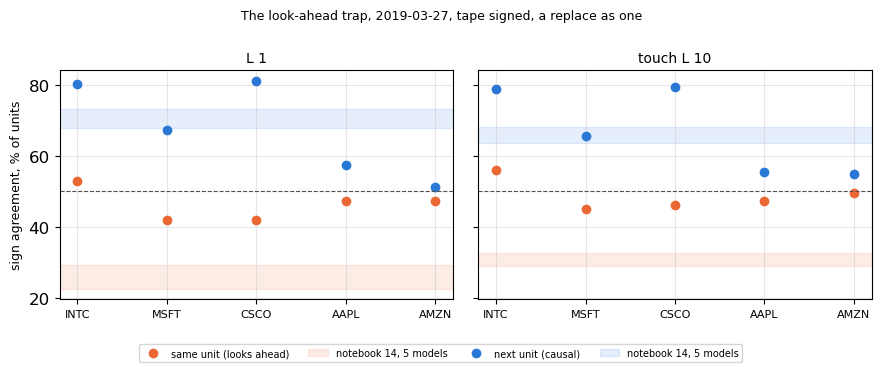

In [25]:
# Section 3, the look-ahead trap: the once-a-unit sample of the imbalance paired with the change of the mid over the
# SAME unit (the pairing that looks ahead: the sample at the start of a unit is the state at the end of the unit before,
# which it has already seen) and over the NEXT unit (the causal one); and the strict event design (the first event that
# leaves the mid alone gives the reading) beside the inclusive one. Functions of a dict of measure() results by stock.
# This cell needs the setup only (it reads notebook 14's saved output itself). With the data absent it prints one
# line.
TRAP_SETTINGS = {
    'L 1 equal': 'L 1',
    'L 10 touch': 'touch L 10',
}  # the settings notebook 14 printed, and its name for each
TRAP_PAIRINGS = (  # the pairing's key, its name, its color, and the heading of notebook 14's column (after 'L 1: ')
    ('same unit', 'same unit (looks ahead)', ORANGE, 'end of the unit against the same unit %'),
    ('next unit', 'next unit (causal)', BLUE, 'against the next unit %'),
)


def trap_table(results):
    # A frame, a row for each stock and setting: the units paired and the sign agreement (percent) of the sample with
    # the change over the same unit and over the next, and the next's lead in points
    rows = {}
    for stock, r in results.items():
        for setting in TRAP_SETTINGS:
            p = r['imbalance']['pairing'][setting]
            rows[stock, setting] = {
                'same unit: n': p['n same'],
                'same unit %': 100 * p['same unit'],
                'next unit: n': p['n next'],
                'next unit %': 100 * p['next unit'],
                'next minus same, pp': 100 * (p['next unit'] - p['same unit']),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def trap_design_table(results, setting='L 1 equal'):
    # A frame, a row for each stock and spread class: the strict design (the first event that leaves the mid alone gives
    # the reading) and the inclusive one (the change event's own state can): readings, hit rate (percent) and lift over
    # the better baseline in the class (points). A class under MIN_READINGS readings in a design is its count only.
    rows = {}
    for stock, r in results.items():
        for design, name in (('classes', 'strict'), ('inclusive', 'inclusive')):
            table = r['imbalance'][design]
            for cls in CLASSES:
                got = table[(table.setting == setting) & (table['class'] == cls)].iloc[0]
                n = int(got['n'])
                enough = n >= MIN_READINGS
                row = rows.setdefault((stock, cls), {})
                row[f'{name}: n'] = n
                row[f'{name}: hit %'] = 100 * got['hit'] if enough else math.nan
                row[f'{name}: lift pp'] = 100 * got['lift over the better'] if enough else math.nan
    return pd.DataFrame.from_dict(rows, orient='index')


def trap_nb14_pairing(path=NB14_PATH):
    # Notebook 14's table of the two pairings from its saved output, {(model, column heading): text as printed}: each
    # column is a block of lines of its own, so each row is read under the heading line above it (the setup's reader is
    # not used: it misses a heading that is one character wider than its cells). Empty if the notebook or its output is
    # not there.
    try:
        notebook = json.loads(Path(path).read_text())
    except FileNotFoundError:
        return {}
    out, row_of = {}, re.compile(r'^(ZI|Hawkes ZI|MF 2008|Parlour|Informed ZI)\s+([+-]?\d*\.?\d+ \([\d.]+\))$')
    for cell in notebook['cells']:
        for part in cell.get('outputs', []):
            text = ''.join(part.get('data', {}).get('text/plain', []))
            if 'end of the unit against the same unit %' not in text:
                continue
            column = None
            for line in text.splitlines():
                line = line.rstrip().removesuffix('\\').rstrip()
                row = row_of.match(line)
                if row and column:
                    out[row.group(1), column] = row.group(2)
                elif 'unit' in line:
                    column = line.strip()
    return out


def trap_nb14_table():
    # notebook 14's sign agreements of the two pairings, a row a model, as printed (mean over seeds 101 to 108, se in
    # brackets)
    read = trap_nb14_pairing()
    columns = [(label, key) for label in TRAP_SETTINGS.values() for key, _, _, _ in TRAP_PAIRINGS]
    text = {(label, key): text for label in TRAP_SETTINGS.values() for key, _, _, text in TRAP_PAIRINGS}
    rows = {m: [read.get((m, f'{label}: {text[label, key]}'), '-') for label, key in columns] for m in NB14_MODELS}
    return pd.DataFrame.from_dict(rows, orient='index', columns=pd.MultiIndex.from_tuples(columns))


def trap_check(results):
    # What must hold: an agreement is a share, and the class rows of each design add up to the setting's pooled row
    for stock, r in results.items():
        for setting in TRAP_SETTINGS:
            for key in ('same unit', 'next unit'):
                value = r['imbalance']['pairing'][setting][key]
                assert not np.isfinite(value) or 0 <= value <= 1, f'{stock} {setting}: {key} agreement is not a share'
        for design in ('classes', 'inclusive'):
            table = r['imbalance'][design]
            sub = table[table.setting == 'L 1 equal'].set_index('class')
            assert sub.loc[list(CLASSES)].n.sum() == sub.loc['pooled', 'n'], (
                f'{stock} {design}: the classes do not add up'
            )


def trap_figure(results, day=DAY):
    # The two pairings' sign agreement, a panel for each setting, a point a stock; the band is the range of notebook
    # 14's five models' means; the dashed line is 50%, which a sample that knows nothing would give
    fig, axes = plt.subplots(1, len(TRAP_SETTINGS), figsize=(9, 3.6), sharey=True)
    read = trap_nb14_pairing()
    stocks = list(results)
    x = np.arange(len(stocks))
    for ax, (setting, label) in zip(axes, TRAP_SETTINGS.items(), strict=True):
        for key, name, color, text in TRAP_PAIRINGS:
            values = [100 * results[s]['imbalance']['pairing'][setting][key] for s in stocks]
            ax.plot(x, values, marker='o', linestyle='none', color=color, label=name)
            sim = [printed_value(read.get((m, f'{label}: {text}'))) for m in NB14_MODELS]
            sim = [got[0] for got in sim if got is not None]
            if sim:
                ax.axhspan(min(sim), max(sim), color=color, alpha=0.12, label=f'notebook 14, {len(sim)} models')
        ax.axhline(50, color=GRAY, linestyle='--', linewidth=0.8)
        ax.set_xticks(x, stocks, fontsize=8)
        ax.set_title(label, fontsize=10)
        ax.set_ylabel('sign agreement, % of units' if ax is axes[0] else '', fontsize=9)
    handles, labels = axes[0].get_legend_handles_labels()  # one legend under the panels (not over a point)
    fig.legend(handles, labels, loc='lower center', ncol=len(labels), fontsize=7)
    fig.suptitle(figure_title('The look-ahead trap', results, day), fontsize=9)
    plt.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()


def trap_show(results, day=DAY):
    trap_check(results)
    heading(
        'The look-ahead trap: the sample of the imbalance paired with the change over the same unit and the next',
        results,
        day,
    )
    say(
        'Sign agreement of the once-a-unit sample with the change of the mid, percent of the units with a change and a '
        'reading; 50% is what a sample that knows nothing gives.'
    )
    counts, shares = ('same unit: n', 'next unit: n'), ('same unit %', 'next unit %', 'next minus same, pp')
    print(shown(trap_table(results), dict.fromkeys(counts, ',.0f') | dict.fromkeys(shares, '.1f')))
    say(f'\n{NB14_SEEDS}, the simulator, as printed (mean over seeds, se across seeds in brackets):')
    print(trap_nb14_table().to_string())
    heading(
        'The event design, L 1, by the spread at the reading: strict (the first event that leaves the mid alone gives '
        'the reading; section 2\'s) and inclusive (the change event\'s own state can)',
        results,
        day,
    )
    design = trap_design_table(results)
    formats = {c: ',.0f' if c.endswith(': n') else '.1f' for c in design.columns}
    print(shown(design, formats))
    print('\nThe share of the changes of the mid with no reading is in the table of section 2 beyond the touch.')


if need(DAY):
    trap_results = measured(DAY)
    trap_show(trap_results)
    trap_figure(trap_results)

**The two pairings.** The table "The look-ahead trap" prints, for each stock on 2019-03-27, the sign agreement of the once-a-unit sample with the change of the mid over the same unit and over the next unit, as a percent of the units with a change and a reading (50% is what a sample that knows nothing gives). At L 1 the same unit agreed on 52.9% of 3,721 units on INTC, 42.0% of 10,039 on MSFT, 42.0% of 3,400 on CSCO, 47.2% of 13,895 on AAPL and 47.4% of 11,299 on AMZN, and the next unit on 80.2% of 3,737, 67.2% of 10,024, 81.2% of 3,412, 57.5% of 13,881 and 51.3% of 11,326: gaps of 27.3, 25.2, 39.2, 10.2 and 3.9 points. At touch L 10 the same unit agreed on 56.0% of 3,745 units on INTC, 44.9% of 10,341 on MSFT, 46.0% of 3,426 on CSCO, 47.2% of 15,728 on AAPL and 49.4% of 12,395 on AMZN, and the next unit on 78.7% of 3,745, 65.6% of 10,340, 79.5% of 3,426, 55.6% of 15,727 and 55.0% of 12,395: gaps of 22.8, 20.7, 33.5, 8.4 and 5.6 points.

The pairing that looks ahead gave a different answer from the causal pairing on every stock and at both settings, with the same sign: the same unit agreed less often than the next. It fell below 50% on MSFT, CSCO, AAPL and AMZN at both L 1 and touch L 10 (AMZN's 49.4% at touch L 10 only just) and did not on INTC (52.9% and 56.0%). Notebook 14's pairing that looks ahead was below 50% in all five of its models, at 22.6 to 29.1% at L 1 against 67.8 to 73.3% for the causal one (seeds 101 to 108, from its saved output, quoted above); no real stock is as low as that at L 1, where the lowest same-unit agreement is 42.0% (MSFT and CSCO). The next unit's agreement is 51.3% on AMZN at L 1, only just above 50%. The figure draws the same agreements for the five stocks at both settings, with the range of notebook 14's five models as a band.

What the gap is: a property of the join. The sample taken at the start of unit u is the state at the end of unit u - 1, which it has already seen, so pairing it with the change over unit u - 1 asks it to call a change it has just seen. That is true on any stream, and the size of the gap is the book's: each gap above is that stock's on that day. Notebook 14 found the bias to have the opposite sign to R-002's, whose pairing inflated a result, and read the sign as depending on the book's queues, a reading it did not test and this table does not test; on these five stocks on this day the pairing that looks ahead gave the lower agreement, as it did in notebook 14. The table does not say what a data vendor's pairing would give.

**The event design.** The last table, at L 1 by the spread at the reading, sets the strict design (section 2's) beside the inclusive one: the readings, the hit rate and the lift over the better baseline, which is the better of 50% and the reversal rate, in points. Strict, then inclusive: INTC at one tick 5,780 readings and a lift of -1.5, then 5,848 and -1.0, and at two ticks 4,855 and 10.7, then 5,537 and 11.1; MSFT at one tick 31,996 and 0.0, then 32,346 and 0.1, and at two ticks 25,071 and 7.8, then 31,490 and 6.1; CSCO at one tick 5,151 and 0.0, then 5,182 and -0.0, and at two ticks 4,266 and 5.8, then 5,030 and 5.2; AAPL at one tick 23,341 and 9.4, then 24,721 and 8.0, at two ticks 45,966 and 6.7, then 52,463 and 5.0, and at three or more 45,177 and 4.2, then 56,322 and 2.9; AMZN at three or more 67,851 and 0.4, then 78,700 and 0.7. A class with under 200 readings is a count only: INTC at three or more (1 and 2 readings), MSFT at three or more (146 and 190), CSCO at three or more (8 and 9), and AMZN at one tick (40 and 50) and at two ticks (33 and 40). The inclusive design has more readings in every class: in the classes of 200 readings or more, from 31 more (CSCO at one tick) to 11,145 more (AAPL at three or more). The choice of design moved a lift by at most 1.7 points (MSFT and AAPL at two ticks). Both are plain differences of the printed figures.

Both designs take the reading before the change it is scored against, so neither makes the look-ahead trap. The strict design's reading is meant to come from an event that leaves the mid alone, with the exception named at the head of this section (a replace's echo, which Table 7a of section 7 has: asked for after the run, judged by no rule). The inclusive design is a different question, because the change event's own state can give the reading; it is not a look-ahead. At one tick on INTC, MSFT and CSCO the lift over the better baseline is between -1.5 and 0.1 points under both designs, and nothing here says the imbalance beats the reversal rate there. The two-tick figures of INTC and CSCO come mostly from states that end within a millisecond (Table 7c of section 7, asked for after the run, judged by no rule, prints the share of their two-tick readings in the band under 1 ms), so they do not describe two-tick spreads that last.

**What this cannot show.**

- *The trap is about a join, not about a stock.* The gap between the two pairings is what the join does to a sample taken at a unit's start; it is true on any stream and says nothing about how well a stock's imbalance predicts. Its size is the book's: it is printed for each stock and setting, and in the simulator it was printed for each model.
- *The two pairings score different units.* A unit with a change and a reading is paired; units with no change, and zero readings, are left out, so the agreement is of the units that moved, and the strict design's hit rate (section 2) is of changes of the mid and not of units.
- *The inclusive design is not tested for a trap.* It is shown beside the strict one to say how much the choice of which event gives the reading moves the figures; a difference between them is a difference of design.
- *One day of each stock.* No two stocks are said to differ; the figures are of that stock on that day.

### The rules that sign trades, and bulk volume classification

Section 3 asks which of notebook 14's findings are the estimator's, true of a rule on any stream, and which are the simulator's. Two sets of rules are left: the rules that give a trade its side from prices and quotes (the tick rule and the quote rule), and bulk volume classification, which gives a bucket a buy share from the change of the mid. On a real stream the true side of a displayed execution is known (it is minus the resting order's side), so each rule can be scored against it; that is what notebook 14 did against the simulator's aggressor.

**The questions.** How often is each rule right, per aggressive order, per lot and per fill, at quote lags of 0, 1 and 5 units, on each tape, by the spread at the fill, with priced executions and hidden fills shown apart and the hidden and the unsigned shares of the executed shares printed beside every accuracy? Does the quote rule at lag 0, which reads the mid just before the fill's event, have no miss at all on displayed executions at their resting price, as it must? And what does bulk volume classification's level read, beside the share of buckets whose mid did not change?

**The rules.** The tick rule signs a fill by the sign of the last change of the fill price (undefined before the first change). The quote rule at lag L signs a fill by its price against the mid that was sampled L units earlier (lag 0: the mid just before the fill's event); a fill at the mid takes the tick rule's sign, as `TradeDelta` does. Per aggressive order is the rule's sign at the order's first displayed fill against the order's aggressor (an order that sweeps several prices counts once); per lot weights each fill by the shares executed (a lot is a share on a real book); per fill counts each fill. Only displayed executions are scored, because their aggressor is known; a hidden execution inside a run of displayed executions takes the run's aggressor and is shown apart, since its side is the run's and not independent; a hidden run alone stays unsigned and is in no accuracy. The "signed" tape is the stream as it is, and the "none" tape is the same without its hidden executions, which changes the tick rule's price sequence, and with it the sign that a quote rule gives a fill at the mid; both are printed wherever the two differ.

**What notebook 14 found in the simulator** (its saved output, seeds 101 to 108, per fill, the mean over seeds and its standard error across them). The tick rule was right on 92.2 (se 0.0), 92.8 (0.1), 94.7 (0.1), 90.5 (0.1) and 90.5 (0.1)% of fills in ZI, Hawkes ZI, MF 2008, Parlour and Informed ZI; the quote rule at lag 0 on 100.0% by construction, a check and not a result; at lag 1 on 90.1, 90.2, 95.4, 86.8 and 87.5%, and at lag 5 on 77.4, 80.4, 84.8, 72.4 and 77.4%. The tick rule was above the quote rule at lag 1 in four of the five models. Per bucket of 250 lots the correlation of the tick rule's buy share with the true one was 0.79, 0.80, 0.95, 0.77 and 0.86, and of bulk volume classification's 0.45, 0.37, 0.71, 0.50 and 0.43, whose mean absolute error was 0.200 to 0.233 against the tick rule's 0.028 to 0.043; and bulk volume classification's VPIN read 0.471 to 0.524 in every model, because when its standardized change is normal, |2 Phi(x) - 1| is uniform on (0, 1) with mean one half whatever the flow.

**What the exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27; each stock's own figures). The quote rule at lag 0 read 100.00% on every one of the 20,637 (NVDA) and 15,909 (CMCSA) displayed fills at their resting price, and fell short of it only through the priced executions (98 and 358 fills, a cent off their order's price) when these were included. Per aggressive order the quote rule at lag 1 was right on 89.69% (NVDA) and 83.20% (CMCSA) against the tick rule's 87.46% and 64.14%: the order of the two rules that notebook 14 found in four of its five models was reversed on both stocks, and within NVDA it flips with the spread at the fill (the tick rule above the quote rule at lag 1 at spreads of one and two ticks, below it at three ticks or more). The hidden shares of the executed shares were 16.64% and 9.45% and the unsigned shares 11.38% and 6.53%. Bulk volume classification's level was 0.455 and 0.460, with the mid unchanged in 4.3% and 12.3% of the buckets, and its per-bucket correlation with the true buy share 0.56 and 0.58 against the tick rule's 0.87 and 0.44.

**What is run.** The accuracy per aggressive order, per lot and per fill on each tape, then the check (the quote rule at lag 0 at the resting price, asserted to have no miss at all, per fill, per lot and per order, not merely to round to 100.00%, with the misses printed and a message that says what a miss would mean) and the asserts that tie the tables' counts to the frames'. Then priced executions and hidden fills apart, the accuracy by the spread at the fill and by tape, the half-hour strips with their figure, and the verdict of the signing prediction. Then bulk volume classification's level and null beside the share of buckets whose mid did not change, and the per-bucket agreement with the true buy share.

In [26]:
# The cells of this part (signing, and bulk volume classification) read measured(): the measure() result of each stock
# on a day. Names this range makes start est_. Every table is a function of the results for a list of stocks and a
# day, so that section 6 can print it for the second day: est_report_signing, est_report_apart and est_report_bvc each
# take (results, day) and print and return what they tabulate.
est_rules = ('tick', 'quote0', 'quote1', 'quote5')  # the setup's RULES, in its order


def est_beside(results):
    # what is beside every accuracy of a stock: the hidden share of the executed shares and the unsigned share (the
    # hidden executions that no displayed run signs: never in a signed figure), and the three rates a second
    return shares_beside(results).join(rates_beside(results))


est_beside_formats = SHARE_FORMATS | RATE_FORMATS
est_class_names = {k: 'displayed, spread ' + label for k, label in enumerate(CLASSES)}


def est_check_counts(stock, result):
    # The signing tables' counts against the frames', which count the same executions another way: the displayed
    # executions of the session (and their shares) are the stream's displayed fills, the hidden fills a displayed run
    # signs are the frames' signed hidden trades, and the categories add up.
    frames = result['frames']
    for tape in TAPES:
        table = result['signing'][tape]
        fills, lots = table['fill counts'], table['lots']
        assert fills['displayed (both)'] == fills['displayed, at the resting price'] + fills['displayed, priced (C)'], (
            f'{stock} {tape}: the displayed fills are not the resting-price ones and the priced ones'
        )
        assert lots['displayed (both)'] == lots['displayed, at the resting price'] + lots['displayed, priced (C)'], (
            f'{stock} {tape}: the displayed shares are not the resting-price ones and the priced ones'
        )
        assert fills['displayed (both)'] == frames['rows by type'].get(4, 0), (
            f'{stock} {tape}: the stream\'s displayed fills are not the frames\' execution rows'
        )
        assert lots['displayed (both)'] == frames['displayed executed shares'], (
            f'{stock} {tape}: the stream\'s displayed shares are not the frames\' displayed executed shares'
        )
        signed = tape == TAPE
        assert fills['hidden, signed'] == (frames['hidden signed trades'] if signed else 0), (
            f'{stock} {tape}: the hidden fills a run signs are not the frames\' signed hidden trades'
        )
        assert lots['hidden, signed'] == (frames['hidden signed shares'] if signed else 0), (
            f'{stock} {tape}: the shares of the hidden fills a run signs are not the frames\''
        )
    check = result['signing'][TAPE]['check against TradeDelta']
    assert check, f'{stock}: no check against TradeDelta'
    for name, c in check.items():
        assert math.isclose(c['class accuracy'], c['mine'], rel_tol=1e-9) and math.isclose(
            c['class coverage'], c['mine coverage'], rel_tol=1e-9
        ), f'{stock}: {name}: TradeDelta\'s own accuracy per lot is not the numpy accuracy of this notebook'


def est_report_signing(results, day=DAY, tapes=TAPES):
    # Signing accuracy of the tick rule and the quote rule at lags 0, 1 and 5 against the aggressor, on displayed
    # executions (whose aggressor is known): per aggressive order (the rule's sign at the order's first displayed fill),
    # per lot (weighted by the shares executed: a lot is a share on a real book) and per fill, on each tape, with the
    # hidden and the unsigned shares of the executed shares beside (an accuracy never includes hidden volume, signed or
    # not: that is shown apart in the next cell). The check comes first: the quote rule at lag 0 on displayed
    # executions at their resting price must have no miss, at every count and on every tape (lag0_exact: 100.00% to two
    # decimals is not enough), and the cell stops, before it prints an accuracy, if it does. Returns {unit: frame,
    # 'check': frame}.
    frames = {}
    for stock, result in results.items():
        est_check_counts(stock, result)
    units = (('per order', 'per aggressive order'), ('per lot', 'per lot'), ('per fill', 'per fill'))
    rows, index = [], []
    for stock, result in results.items():
        for tape in tapes:
            c = result['signing'][tape]['quote0']['displayed, at the resting price']
            assert c.get('fills'), f'{stock} {tape}: no displayed execution at its resting price'
            row = {
                'fills': c['fills'],
                'orders': c['orders'],
                'shares': result['signing'][tape]['lots']['displayed, at the resting price'],
            }
            for key, unit in units:
                row[unit] = 100 * c[key]
            exact, misses = lag0_exact(c)
            row['misses (fills, orders)'] = misses.split(' and ')[0]
            rows.append(row)
            index.append((stock, tape))
            assert exact, (
                f'{stock}, tape {tape}: the quote rule at lag 0 misses on displayed executions at their resting '
                f'price ({misses}; {100 * c["per fill"]:.4f}% per fill). It reads the mid just before the fill\'s '
                'event, and a displayed execution at its resting price is at the maker\'s quote, on the right side of '
                'that mid: it cannot miss, and one miss is too many (the cell does not round to 100.00). A miss means '
                'that the conversion\'s touch, an execution\'s price or its aggressor is wrong, so that no figure of '
                'this notebook that reads a quote or a side can be relied on: stop here.'
            )
    frames['check'] = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'tape']))
    tail = est_beside(results)[['hidden % of shares', 'unsigned % of shares']]
    counts = {'per order': ('orders', 'orders'), 'per lot': ('shares', None), 'per fill': ('fills', 'fills')}
    for key, unit in units:
        rows, index = [], []
        for stock, result in results.items():
            for tape in tapes:
                table = result['signing'][tape]
                row = {RULE_NAMES[rule]: 100 * table[rule]['displayed (both)'][key] for rule in est_rules}
                base = table['tick']['displayed (both)']
                if key == 'per lot':
                    row['shares scored by the tick rule %'] = 100 * base['coverage by lots']
                    row['shares'] = table['lots']['displayed (both)']
                else:
                    row[counts[key][0]] = base[counts[key][1]]
                row |= tail.loc[stock].to_dict()
                rows.append(row)
                index.append((stock, tape))
        frames[key] = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'tape']))
        heading(
            f'Signing accuracy, {unit}, % of displayed executions', results, day, how=convention(' and '.join(tapes))
        )
        print(
            'rows: the tape the figure is on ("signed": the stream as it is; "none": the same without the hidden '
            'executions, which changes the tick rule\'s price sequence); hidden and unsigned shares are of the '
            'shares executed in the session.'
        )
        formats = {name: '.2f' for name in RULE_NAMES.values()}
        formats |= {
            'hidden % of shares': '.2f',
            'unsigned % of shares': '.2f',
            'shares scored by the tick rule %': '.2f',
        }
        print(shown(frames[key], formats | {'orders': ',.0f', 'fills': ',.0f', 'shares': ',.0f'}))
    heading(
        'The check: the quote rule at lag 0, displayed executions at their resting price',
        results,
        day,
        how=convention(' and '.join(tapes)),
    )
    print(
        'Exact by construction (the rule reads the mid just before the event and the fill is at the maker\'s price), '
        'so a check on the conversion and not a finding; the cell asserted no miss at all (not merely 100.00% to two '
        'decimals) at every count and every tape before printing any accuracy, and the misses are printed.'
    )
    print(shown(frames['check'], {'fills': ',.0f', 'orders': ',.0f', 'shares': ',.0f', **{u: '.2f' for _, u in units}}))
    print(
        '\nThe numpy accuracy per lot equals TradeDelta\'s own, rule by rule (on every signed fill of the session, '
        'an unsigned one counted wrong), and every count of the tables above equals the frames\' (execution rows, '
        'executed shares, signed hidden trades): asserted.'
    )
    print('\nbeside, hidden and unsigned shares of the executed shares and the three rates a second:')
    print(shown(est_beside(results), est_beside_formats))
    return frames


if need(DAY):
    est_signing = est_report_signing(measured(DAY), DAY)
    show_nb14(
        {RULE_NAMES[rule]: RULE_NAMES[rule] for rule in est_rules},
        'per fill, % of the fills classified; every fill is its own aggressive order there',
        after='Per fill: the share of the fills classified',
    )


Signing accuracy, per aggressive order, % of displayed executions: 2019-03-27, session 09:40:00 to 15:50:00, tape signed
and none, a replace as one.
rows: the tape the figure is on ("signed": the stream as it is; "none": the same without the hidden executions, which changes the tick rule's price sequence); hidden and unsigned shares are of the shares executed in the session.
             tick rule quote rule, lag 0 quote rule, lag 1 quote rule, lag 5  orders hidden % of shares unsigned % of shares
stock tape                                                                                                                  
INTC  signed     66.49             98.15             88.21             70.46   9,445               8.64                 6.63
      none       65.97             98.15             88.21             70.46   9,445               8.64                 6.63
MSFT  signed     67.31             98.00             77.32             61.72  24,879               9.59                 6


notebook 14, seeds 101 to 108, the simulator (per fill, % of the fills classified; every fill is its own aggressive order there):
              tick rule quote rule, lag 0 quote rule, lag 1 quote rule, lag 5
ZI           92.2 (0.0)       100.0 (0.0)        90.1 (0.1)        77.4 (0.1)
Hawkes ZI    92.8 (0.1)       100.0 (0.0)        90.2 (0.1)        80.4 (0.2)
MF 2008      94.7 (0.1)       100.0 (0.0)        95.4 (0.1)        84.8 (0.1)
Parlour      90.5 (0.1)       100.0 (0.0)        86.8 (0.0)        72.4 (0.2)
Informed ZI  90.5 (0.1)       100.0 (0.0)        87.5 (0.1)        77.4 (0.1)
its three rates a unit of simulation time (seeds 1 to 8, the models' defaults; a real stock's are a second):
            events a unit mid changes a unit aggressive orders a unit
ZI                  59.80               4.06                     6.01
Hawkes ZI           59.84               3.90                     6.20
MF 2008             14.57               1.48                     2.75
Parlour     


Accuracy of each kind of execution, apart: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
Priced executions (ITCH's C) are a cent off their order's price and are displayed, so their side is known; a hidden fill is in a signed figure only where a displayed run of the same aggressive order gives it a side, which is that run's and not independent. The unsigned hidden shares are in no row. Per aggressive order (the rule's sign at the order's first fill of the kind), per lot and per fill, % of each kind of execution.

per aggressive order:
                                                    fills  orders     shares tick rule quote rule, lag 0 quote rule, lag 1 quote rule, lag 5
stock executions                                                                                                                            
INTC  displayed, at the resting price (the check)  22,114   9,259  3,176,052     67.42            100.00             89.80             71.33
      dis

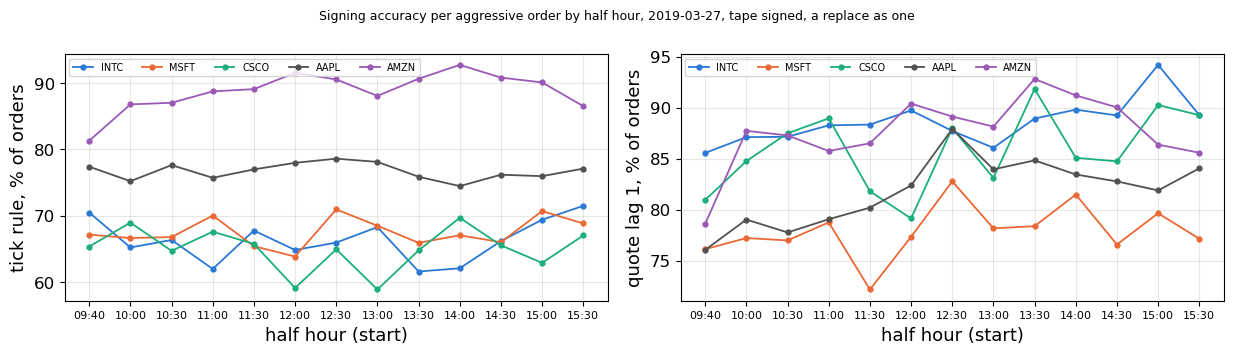


The prediction on signing: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
rule: the quote rule at lag 0 is exact (no miss at all: 100.00% is not enough) on displayed executions at their resting price, and the quote rule at lag 1 is at least as accurate per aggressive order as the tick rule.
INTC    passed: lag 0 at the resting price: 0 of 22,114 fills, 0 of 9,259 orders and 0.0000% of the lots missed; per order quote lag 1 88.21%, tick 66.49%
MSFT    passed: lag 0 at the resting price: 0 of 43,266 fills, 0 of 24,242 orders and 0.0000% of the lots missed; per order quote lag 1 77.32%, tick 67.31%
CSCO    passed: lag 0 at the resting price: 0 of 20,979 fills, 0 of 9,336 orders and 0.0000% of the lots missed; per order quote lag 1 85.22%, tick 64.87%
AAPL    passed: lag 0 at the resting price: 0 of 47,541 fills, 0 of 32,553 orders and 0.0000% of the lots missed; per order quote lag 1 80.95%, tick 76.71%
AMZN    not passed: lag 0 at the resting price: 0 of 20,280

In [27]:
est_short = {'tick': 'tick rule', 'quote1': 'quote lag 1'}  # the figure's y labels


def est_report_apart(results, day=DAY, tapes=TAPES):
    # What the main table leaves apart or splits: the priced executions (ITCH's C, a cent off their order's displayed
    # price: a rule at lag 0 reads their price against a mid that does not know it) and the hidden fills a displayed
    # run signs (their side is the run's, not independently known) each on their own; the accuracy per aggressive order
    # by the spread at the fill and by tape (a class with under MIN_READINGS orders is a count only); and by half hour.
    # With the prediction's verdict. Returns {name: frame}.
    frames = {}
    parts = (
        ('displayed, at the resting price', 'displayed, at the resting price (the check)'),
        ('displayed, priced (C)', 'displayed, priced (C)'),
        ('hidden, signed', 'hidden, signed by their run'),
    )
    formats = {name: '.2f' for name in RULE_NAMES.values()} | {'fills': ',.0f', 'orders': ',.0f', 'shares': ',.0f'}
    heading('Accuracy of each kind of execution, apart', results, day)
    print(
        'Priced executions (ITCH\'s C) are a cent off their order\'s price and are displayed, so their side is '
        'known; a hidden fill is in a signed figure only where a displayed run of the same aggressive order gives it '
        'a side, which is that run\'s and not independent. The unsigned hidden shares are in no row. Per aggressive '
        'order (the rule\'s sign at the order\'s first fill of the kind), per lot and per fill, % of each kind of '
        'execution.'
    )
    for key, unit in (('per order', 'per aggressive order'), ('per lot', 'per lot'), ('per fill', 'per fill')):
        rows, index = [], []
        for stock, result in results.items():
            table = result['signing'][TAPE]
            for kind, label in parts:
                row = {'fills': table['fill counts'][kind], 'orders': table['quote0'][kind].get('orders', 0)}
                row['shares'] = table['lots'][kind]
                for rule in est_rules:
                    row[RULE_NAMES[rule]] = 100 * table[rule][kind].get(key, math.nan)
                rows.append(row)
                index.append((stock, label))
        frames['apart ' + key] = pd.DataFrame(
            rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'executions'])
        )
        print(f'\n{unit}:')
        print(shown(frames['apart ' + key], formats))
    # by the spread at the fill, per aggressive order, on each tape
    rows, index = [], []
    for stock, result in results.items():
        for tape in tapes:
            table = result['signing'][tape]
            for k, label in enumerate(CLASSES):
                orders = table['tick'][est_class_names[k]].get('orders', 0)
                enough = orders >= MIN_READINGS
                row = {'orders': orders}
                for rule in est_rules:
                    row[RULE_NAMES[rule]] = 100 * table[rule][est_class_names[k]]['per order'] if enough else math.nan
                rows.append(row)
                index.append((stock, tape, label))
    frames['by spread'] = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'tape', 'spread']))
    heading(
        'Accuracy per aggressive order by the spread at the fill', results, day, how=convention(' and '.join(tapes))
    )
    print(
        f'Displayed executions; a spread class with under {MIN_READINGS} orders is a count only. The classes are the '
        'spread (in ticks of a cent) of the touch before the order\'s event.'
    )
    print(shown(frames['by spread'], formats))
    # by half hour, signed tape, per aggressive order
    strips = {}
    heading('Accuracy per aggressive order by half hour, displayed executions', results, day)
    for rule in est_rules:
        print(f'\n{RULE_NAMES[rule]}, % of orders:')
        print(est_strip_lines(results, rule))
        for stock, result in results.items():
            strips.setdefault(rule, {})[stock] = result['signing'][TAPE][rule]['blocks, per order']
    for stock, result in results.items():
        for rule in est_rules:
            assert len(result['signing'][TAPE][rule]['blocks, per order']) == len(HAVE_BLOCKS), (
                f'{stock}: a value a half hour'
            )
    frames['strips'] = strips
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
    for ax, rule in zip(axes, ('tick', 'quote1'), strict=True):
        plot_strips(
            results,
            lambda r, rule=rule: r['signing'][TAPE][rule]['blocks, per order'],
            f'{est_short[rule]}, % of orders',
            scale=100.0,
            ax=ax,
        )
    fig.suptitle(figure_title('Signing accuracy per aggressive order by half hour', results, day), fontsize=9)
    fig.tight_layout()
    plt.show()
    heading('The prediction on signing', results, day)
    print(f'rule: {PREDICTIONS["signing"].rule}.')
    for stock, result in results.items():
        verdict = PREDICTIONS['signing'].judge(result)
        print(f'{stock:<8}{verdict.status}: {verdict.detail}')
    return frames


def est_strip_lines(results, rule):
    # a line a stock: the rule's accuracy per aggressive order in each half hour (displayed executions, signed tape)
    return stock_strips(results, lambda r: r['signing'][TAPE][rule]['blocks, per order'], 1, 100.0, 7, 'stock')


if need(DAY):
    est_apart = est_report_apart(measured(DAY), DAY)

**The check.** The table "The check" scores the quote rule at lag 0 on the displayed executions at their resting price, per fill, per lot and per aggressive order, on the signed and the none tape. It had no miss on 2019-03-27: 0 of 22,114 fills and 0 of 9,259 orders on INTC (3,176,052 shares), 0 of 43,266 fills and 0 of 24,242 orders on MSFT (4,477,869 shares), 0 of 20,979 fills and 0 of 9,336 orders on CSCO (2,761,869), 0 of 47,541 fills and 0 of 32,553 orders on AAPL (4,626,873) and 0 of 20,280 fills and 0 of 15,126 orders on AMZN (571,413), with the same counts on both tapes and 100.00 at each of the three counts. The cell asserts no miss at all (not 100.00% to two decimals) and stops if it has one. The rule is exact by construction: it reads the mid just before the event, and a fill at its resting price is at the maker's price, on the aggressor's side of that mid. So the check is on the conversion's touch, prices and aggressors, and is not a finding. With a separate trade stream the rule would not be available at lag 0.

**The accuracies.** The table "Signing accuracy, per aggressive order" has, for each stock, the rules' accuracy on displayed executions on the signed tape, with the none tape beside it. The tick rule was right on 66.49% of INTC's 9,445 orders (65.97% on the none tape), 67.31% of MSFT's 24,879 (66.68%), 64.87% of CSCO's 9,632 (63.51%), 76.71% of AAPL's 32,884 (76.55%) and 88.67% of AMZN's 15,176 (87.75%). The quote rule at lag 0 was right on 98.15% (INTC), 98.00% (MSFT, 98.03% on the none tape), 97.10% (CSCO, 97.09%), 99.22% (AAPL) and 99.97% (AMZN), short of 100.00% only through the priced executions, which are scored apart in the next paragraph. At lag 1 it was right on 88.21% (INTC), 77.32% (MSFT, 77.30%), 85.22% (CSCO), 80.95% (AAPL) and 87.41% (AMZN), and at lag 5 on 70.46%, 61.72% (61.71%), 68.26%, 65.21% (65.20%) and 78.83%. The hidden and unsigned shares of the shares executed, beside every row, were 8.64% and 6.63% on INTC, 9.59% and 6.58% on MSFT, 11.18% and 8.44% on CSCO, 11.15% and 8.28% on AAPL, and 25.57% and 18.21% on AMZN. The same table per lot and per fill is printed under it, and the order of the tick rule and the quote rule at lag 1 is the same at all three counts on every stock (AMZN per lot: tick 88.57%, quote lag 1 86.96%; per fill: 90.99% and 90.01%). The tape moved the tick rule's accuracy per aggressive order by -0.52, -0.63, -1.36, -0.16 and -0.92 points (the none tape less the signed, plain differences) and the quote rules' by at most 0.03 points (MSFT's lag 0, 98.00% to 98.03%). The accuracy is of displayed executions, whose aggressor is known, and includes no unsigned hidden volume.

The verdict of the signing prediction (the quote rule at lag 1 at least as accurate as the tick rule per aggressive order, and no miss at lag 0) was passed on INTC (88.21% against 66.49%), MSFT (77.32% against 67.31%), CSCO (85.22% against 64.87%) and AAPL (80.95% against 76.71%), and not passed on AMZN (87.41% against 88.67%), so on 4 of the 5 stocks; they share the day's market factor, so that is one day's measurement. Quote lag 1 less the tick rule is 21.7, 10.0, 20.3, 4.2 and -1.3 points (plain differences of the printed accuracies). Notebook 14's ordering is the tick rule above the quote rule at lag 1, in four of its five models. The simulator's mid changes 1.48 to 5.06 a unit, and a real stock's figures are set against it like for like only where its mid changes a second fall in that range: MSFT's 2.899 and AMZN's 3.808 do (the rates under the tables), INTC's 0.515 and CSCO's 0.463 are below it and AAPL's 6.246 above it, and for those three stocks on this day no comparison is made. On MSFT the quote rule at lag 1 is above the tick rule by 10.0 points, the opposite of the simulator's ordering; on AMZN the tick rule is above it by 1.3 points, the simulator's ordering. AMZN's verdict sits on its line: section 6's margin line prints -1.3 points against a line of 0, -2.7 se (se 0.5, the half hours' standard deviation over the root of 13), with the half hours from -3.7 to 2.2, and, counting from the two half-hour strips taken up at the end of this note, the quote rule at lag 1 is above the tick rule in 4 of its 13 half hours. The review of the run, outside the notebook, counted the displayed fills of an order before its hidden ones and found the difference to be -0.90 on AMZN's first day. The second day's is -0.8 points, -1.4 se, in section 6. The predictions cell listed signing on a stock whose spread is mostly three ticks or more as one of its real bets and not as a near-certain pass, and it did not pass on AMZN, where 15,032 of the 15,176 orders were at a spread of three ticks or more (the table by spread, taken up in the next paragraph).

**Priced and hidden executions apart, and by the spread at the fill.** The table "Accuracy of each kind of execution, apart" scores the priced executions (ITCH's C, displayed, so their side is known) and the hidden fills (signed only where a displayed run of the same aggressive order gives them a side, which is that run's and not independent) separately. The quote rule at lag 0 was right on 8.85% of INTC's 192 priced orders (244 fills), 26.04% of MSFT's 672 (832), 10.58% of CSCO's 312 (352), 33.51% of AAPL's 385 (408) and 90.00% of AMZN's 50 (50), per aggressive order. The rule reads a priced execution's own price against a mid that does not know it, so it is not scored with the executions at their resting price. The tick rule's accuracy on the same priced orders was 20.31%, 37.65%, 34.29%, 33.77% and 22.00%. The hidden fills were right on 81.96% of INTC's 388 orders, 83.08% of MSFT's 1,058, 71.62% of CSCO's 370, 89.35% of AAPL's 1,108 and 98.60% of AMZN's 1,715 for the quote rule at lag 0, against the side their run gives. The caption of the table says a priced execution is a cent off its order's price. What the run supports is that no printable priced execution is more than a cent from its order's displayed price on any of the ten stock-days; the executions that the conversion counts as priced further away than that are not printable (Table 7g of section 7, which is where the count is read: asked for after the run, judged by no rule).

The table "Accuracy per aggressive order by the spread at the fill" gives the classes (a class of under 200 orders is a count only). On INTC the one-tick class has 9,393 orders (tick rule 66.66%, quote lag 1 88.53%) and the two-tick class 52; on CSCO the one-tick class has 9,584 (64.97% and 85.45%) and the others 47 and 1; on AMZN the three-or-more class has 15,032 (88.92% and 87.73%) and the one-tick and two-tick classes 86 and 58. Each of these three stocks has one class of 200 orders or more, so a flip with the spread could not show on it. MSFT's order of the two rules flips with the spread: at one tick (24,249 orders) the quote rule at lag 1 is above the tick rule, 78.00% against 67.61%, and at two ticks (577 orders) it is below it, 47.83% against 53.55% (54.42% on the none tape); its three-or-more class has 53. AAPL's does not flip: the quote rule at lag 1 is above the tick rule at one tick (19,042 orders, 78.32% against 73.47%), at two ticks (11,163, 84.14% against 80.11%) and at three or more (2,679, 86.34% against 85.59%), by 4.85, 4.03 and 0.75 points (plain differences). No claim is made that either rule is better in general: each is an accuracy on one stock's displayed executions on one day.

**By half hour.** The strips "Accuracy per aggressive order by half hour" and the figure under them print thirteen half hours per rule. The tick rule's lowest and highest half hour were 61.6% (13:30) and 71.5% (15:30) on INTC, 63.8% (12:00) and 70.9% (12:30) on MSFT, 58.8% (13:00) and 69.7% (14:00) on CSCO, 74.4% (14:00) and 78.6% (12:30) on AAPL, and 81.3% (09:40) and 92.7% (14:00) on AMZN. The quote rule at lag 1's were 85.6% (09:40) and 94.2% (15:00) on INTC, 72.2% (11:30) and 82.8% (12:30) on MSFT, 79.1% (12:00) and 91.8% (13:30) on CSCO, 76.1% (09:40) and 87.9% (12:30) on AAPL, and 78.6% (09:40) and 92.8% (13:30) on AMZN. The quote rule at lag 1 is above the tick rule in every half hour on INTC, MSFT and CSCO. On AAPL it is below it in the first half hour (76.1% against 77.4%) and above it in the other twelve, by as little as 0.2 points at 10:30 (77.8% against 77.6%). On AMZN the order changes through the day: the quote rule is above the tick rule at 10:00, 10:30, 13:00 and 13:30 and below it in the other nine. No pattern across the day or between stocks is claimed.

In [28]:
def est_report_bvc(results, day=DAY, tapes=TAPES):
    # Bulk volume classification: VPIN's buy share of a bucket read from the mid's change over it (Phi of the change in
    # units of the standard deviation of the last 100 buckets' changes), so that a bucket with an unchanged mid reads an
    # imbalance of exactly 0 and its level is a property of the distribution of price changes. Its level against the
    # null that permutes its bucket changes, beside the share of buckets whose mid did not change, the mean imbalance
    # over the buckets that did, and the per-bucket agreement with the true buy share (tick rule and the quote rule at
    # lag 1 beside it). Returns {'level': frame, 'agreement': frame}.
    rows, index = [], []
    for stock, result in results.items():
        for tape in tapes:
            v = result['vpin'][tape]
            b = v['rules']['bvc']
            mean, sd = b['changes permuted']
            unchanged = b['share of buckets with the mid unchanged (session)']
            moved = b['mean |2 Phi(x) - 1| over buckets with a change']
            if math.isfinite(b['level']):  # a stock-day with too few buckets has no level
                assert 0.0 <= unchanged <= 1.0 and 0.0 <= b['level'] <= 1.0, (
                    f'{stock} {tape}: bulk volume level out of range'
                )
                assert math.isclose(b['excess over changes permuted'], b['level'] - mean, abs_tol=1e-12), (
                    f'{stock}: excess'
                )
            rows.append(
                {
                    'BVC level': b['level'],
                    'null: changes permuted (sd)': f'{mean:.3f} ({sd:.3f})',
                    'excess': b['excess over changes permuted'],
                    'sds': b['excess over changes permuted (null sds)'],
                    'mid unchanged %': 100 * unchanged,
                    'mean |2 Phi - 1| where it changed': moved,
                    'x (1 - unchanged)': (1 - unchanged) * moved,
                    'true sides level': v['rules']['true']['level'],
                    'tick rule level': v['rules']['tick']['level'],
                    'buckets, since the open': v['buckets'],
                }
            )
            index.append((stock, tape))
    level = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'tape']))
    heading(
        'Bulk volume classification: its level beside the share of buckets whose mid did not change',
        results,
        day,
        how=convention(' and '.join(tapes)),
    )
    print(
        f'VPIN as the vendors read it from prices: a bucket of V = {V_MEDIANS} x the median of the first {V_FILLS} '
        f'fills, {N_BUCKETS} buckets a window, bucket-weighted over the session; the null permutes the buckets\' '
        f'changes of the mid ({NULL_DRAWS} draws, seed {NULL_SEED}), which keeps their distribution and breaks any '
        'link to the flow. "x (1 - unchanged)" is the level that the share of unchanged buckets and the mean '
        'imbalance of the others give, to the edge effects of a window.'
    )
    print(
        shown(
            level,
            {
                'BVC level': '.3f',
                'excess': '+.3f',
                'sds': '+.1f',
                'mid unchanged %': '.1f',
                'mean |2 Phi - 1| where it changed': '.3f',
                'x (1 - unchanged)': '.3f',
                'true sides level': '.3f',
                'tick rule level': '.3f',
                'buckets, since the open': ',.0f',
            },
        )
    )
    # per bucket, against the true buy share: the signed tape's buckets of the session
    rows, index = [], []
    for stock, result in results.items():
        agreement = result['bucket agreement']
        counts = {agreement[rule]['buckets'] for rule in ('tick', 'mid, lag 1', 'bvc')}
        assert len(counts) == 1, f'{stock}: the rules\' buckets are not the same buckets: {counts}'
        in_session = int(np.nansum(result['vpin'][TAPE]['blocks: buckets closed']))
        assert counts == {in_session}, (
            f'{stock}: the buckets compared per bucket are not the buckets closed in the session'
        )
        for rule, label in (
            ('tick', 'tick rule'),
            ('mid, lag 1', 'quote rule, lag 1'),
            ('bvc', 'bulk volume classification'),
        ):
            a = agreement[rule]
            rows.append(
                {
                    'buckets': a['buckets'],
                    'share: correlation': a['share correlation'],
                    'share: mean absolute error': a['share mean absolute error'],
                    'VPIN: correlation with true sides': a["VPIN correlation with the true side's"],
                }
            )
            index.append((stock, label))
    agreement = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=['stock', 'rule']))
    heading('Per bucket against the true buy share, the buckets closed in the session', results, day)
    print(
        'The inferred buy share of each bucket against the true one (over the buckets of the session): the '
        'correlation and the mean absolute error; and the correlation of each rule\'s trailing VPIN with the true '
        'sides\'. The true share is the share of the bucket\'s volume with a known aggressor; the unsigned hidden '
        'volume is in neither.'
    )
    print(
        shown(
            agreement,
            {
                'buckets': ',.0f',
                'share: correlation': '.2f',
                'share: mean absolute error': '.3f',
                'VPIN: correlation with true sides': '.2f',
            },
        )
    )
    print('\nbeside, hidden and unsigned shares of the executed shares and the three rates a second:')
    print(shown(est_beside(results), est_beside_formats))
    return {'level': level, 'agreement': agreement}


if need(DAY):
    est_bvc = est_report_bvc(measured(DAY), DAY)
    show_nb14(
        {
            'bulk volume classification: level': 'bvc: level',
            'true sides: level': 'true: level',
            'tick rule: level': 'tick: level',
        },
        'VPIN by the rule that signs the fills, 250 lots a bucket; a bulk volume level is near 0.5 whatever the flow',
    )
    show_nb14(
        {
            'tick: correlation': 'tick: correlation',
            'mid, lag 1: correlation': 'mid, lag 1: correlation',
            'bvc: correlation': 'bvc: correlation',
            'tick: mean absolute error': 'tick: mean absolute error',
            'bvc: mean absolute error': 'bvc: mean absolute error',
        },
        'per bucket of 250 lots, the inferred buy share against the true one',
    )


Bulk volume classification: its level beside the share of buckets whose mid did not change: 2019-03-27, session 09:40:00
to 15:50:00, tape signed and none, a replace as one.
VPIN as the vendors read it from prices: a bucket of V = 50 x the median of the first 200 fills, 50 buckets a window, bucket-weighted over the session; the null permutes the buckets' changes of the mid (200 draws, seed 1), which keeps their distribution and breaks any link to the flow. "x (1 - unchanged)" is the level that the share of unchanged buckets and the mean imbalance of the others give, to the edge effects of a window.
             BVC level null: changes permuted (sd)  excess   sds mid unchanged % mean |2 Phi - 1| where it changed x (1 - unchanged) true sides level tick rule level buckets, since the open
stock tape                                                                                                                                                                                   
INTC  signed 


notebook 14, seeds 101 to 108, the simulator (VPIN by the rule that signs the fills, 250 lots a bucket; a bulk volume level is near 0.5 whatever the flow):
            bulk volume classification: level true sides: level tick rule: level
ZI                              0.504 (0.004)     0.113 (0.001)    0.102 (0.001)
Hawkes ZI                       0.471 (0.002)     0.111 (0.001)    0.099 (0.001)
MF 2008                         0.524 (0.006)     0.195 (0.004)    0.183 (0.003)
Parlour                         0.492 (0.003)     0.113 (0.002)    0.103 (0.002)
Informed ZI                     0.498 (0.003)     0.170 (0.003)    0.128 (0.002)
its three rates a unit of simulation time (seeds 1 to 8, the models' defaults; a real stock's are a second):
            events a unit mid changes a unit aggressive orders a unit
ZI                  59.80               4.06                     6.01
Hawkes ZI           59.84               3.90                     6.20
MF 2008             14.57             


notebook 14, seeds 101 to 108, the simulator (per bucket of 250 lots, the inferred buy share against the true one):
            tick: correlation mid, lag 1: correlation bvc: correlation tick: mean absolute error bvc: mean absolute error
ZI                0.79 (0.00)             0.77 (0.01)      0.45 (0.01)             0.034 (0.000)            0.233 (0.002)
Hawkes ZI         0.80 (0.01)             0.75 (0.01)      0.37 (0.02)             0.033 (0.000)            0.221 (0.001)
MF 2008           0.95 (0.00)             0.96 (0.00)      0.71 (0.01)             0.028 (0.001)            0.200 (0.003)
Parlour           0.77 (0.01)             0.72 (0.01)      0.50 (0.02)             0.036 (0.001)            0.222 (0.002)
Informed ZI       0.86 (0.01)             0.82 (0.01)      0.43 (0.01)             0.043 (0.000)            0.224 (0.001)
its three rates a unit of simulation time (seeds 1 to 8, the models' defaults; a real stock's are a second):
            events a unit mid changes a un

**Bulk volume classification's level.** The table "Bulk volume classification: its level beside the share of buckets whose mid did not change" prints, for each stock on 2019-03-27 on the signed tape (the none tape under it), the level of bulk volume classification's VPIN; a null that permutes the buckets' changes of the mid (200 draws, its standard deviation in brackets), which keeps their distribution and breaks any link to the flow; the excess in null standard deviations; the share of buckets whose mid did not change; the mean imbalance over the buckets that did change; and the level that the two give together. The level was 0.477 on INTC against a null of 0.483 (0.004), an excess of -0.006 or -1.6 null standard deviations, with the mid unchanged over 10.5% of the buckets, a mean imbalance of 0.525 over the others and 0.470 for the two together. On MSFT it was 0.494 against 0.500 (0.003), -0.006 or -2.2, with 6.0%, 0.527 and 0.495; on CSCO 0.498 against 0.506 (0.004), -0.008 or -2.0, with 12.0%, 0.560 and 0.493; on AAPL 0.481 against 0.472 (0.002), +0.010 or +6.2, with 5.6%, 0.511 and 0.482 (on the none tape +0.009 or +6.6); and on AMZN 0.453 against 0.456 (0.002), -0.003 or -1.4, with 5.7%, 0.477 and 0.450. The level that the share and the mean give together is within 0.007 of the level on every stock (plain differences). Notebook 14's level was 0.471 to 0.524 in every model whatever the flow, and on these stocks it is 0.453 to 0.498.

What it shows: the level is a property of the distribution of price changes. It is within 0.010 of a null that keeps that distribution and breaks the link to the flow on every stock, so it reads about the same whatever the flow, and it is not a measure of how one-sided the flow is. A bucket whose mid did not change reads 0, so, other things equal, the level falls as more buckets have an unchanged mid; it is (to the edge effects of a window) the share of buckets whose mid changed times the mean imbalance of those. "Near its null's" is a statement about the level: AAPL's excess is +0.010 on a null standard deviation of 0.002, which is why it reads +6.2 null standard deviations, and it is not a sign of flow. The review of the run, outside the notebook, found that the excess turned negative on AAPL's first day when the session's standard deviation replaced the rolling one in the standardization, and read it as the rolling standardization meeting volatility that clusters in time. So the excess is not read as flow.

**Per bucket against the true buy share.** The table "Per bucket against the true buy share" scores each rule's buy share of a bucket against the true one (the share of the bucket's volume with a known aggressor, so unsigned hidden volume is in neither) over the buckets closed in the session, and prints the correlation of each rule's trailing VPIN with the true sides'. On INTC (655 buckets) the tick rule's correlation with the true share was 0.47 and its mean absolute error 0.230, the quote rule at lag 1's 0.64 and 0.120, and bulk volume classification's 0.53 and 0.204; the correlation of the trailing VPIN with the true sides' was 0.62, 0.77 and 0.06. On MSFT (941 buckets) the figures were 0.71 and 0.139, 0.73 and 0.118, and 0.63 and 0.184, with VPIN correlations of 0.40, 0.50 and -0.03. On CSCO (577) they were 0.47 and 0.225, 0.64 and 0.128, and 0.57 and 0.204, with 0.50, 0.54 and 0.09. On AAPL (2,374) they were 0.80 and 0.125, 0.80 and 0.132, and 0.56 and 0.210, with 0.75, 0.77 and -0.25. On AMZN (1,402) they were 0.85 and 0.097, 0.82 and 0.114, and 0.53 and 0.249, with 0.81, 0.79 and -0.43.

By the correlation with the true share, the quote rule at lag 1 tracks it best on INTC (0.64), MSFT (0.73) and CSCO (0.64), the tick rule and the quote rule at lag 1 tie on AAPL (0.80 each, with the lower error on the tick rule, 0.125 against 0.132), and the tick rule tracks it best on AMZN (0.85, error 0.097). Bulk volume classification's correlation, 0.53 to 0.63, is above the tick rule's on INTC and CSCO and below it on MSFT, AAPL and AMZN, and its trailing VPIN does not follow the true sides' on any stock (0.06, -0.03, 0.09, -0.25 and -0.43). Notebook 14's correlations were 0.77 to 0.95 for the tick rule and 0.37 to 0.71 for bulk volume classification, in buckets of 250 lots; the real ones are 0.47 to 0.85 and 0.53 to 0.63, in buckets of V shares. Each answer is a stock's on one day, and no rule is called better in general.

**What this cannot show.**

- *That a rule is better in general.* The accuracy of the tick rule and of the quote rule depends on the spread at the fill, on the tape and on the stock's own price and quote behavior (in the exploration the order of the two rules flipped with the spread within one stock). A figure here is an accuracy on one stock's displayed executions on one day, and the order of two rules on it says nothing about another stock or day.
- *Accuracy on all volume.* An accuracy is scored on displayed executions, whose aggressor is known. The hidden executions that no displayed run signs are in no accuracy (their share of the executed shares is printed beside every one), and a hidden fill inside a displayed run has that run's side, so its accuracy is against an inferred side and is shown apart. The opening and the closing crosses are outside the session.
- *That the grouping of executions into orders is given.* An aggressive order is a run of executions at one nanosecond with consecutive match numbers; where a venue sends the pieces of one order microseconds apart the count of orders, and every per-order figure, moves with the rule that joins them (the grouping sensitivity of the order-to-trade table shows the size of that on that ratio). Per lot and per fill are not per order, and a sweep of many fills counts once per order and many times per fill.
- *The quote rule at lag 0 as a finding.* It is exact by construction when the book is synchronized with the trades, which an order-by-order feed gives; a stream of trades and quotes from separate feeds, or a price-level feed, would not give it (section 4 degrades the same real stream to show how it falls). The check says that the conversion's touch, prices and aggressors are consistent, nothing more.
- *That bulk volume classification measures flow.* It reads the change of the mid over a bucket: its level is near its null's whatever the flow, it is 0 for a bucket whose mid did not change, and its agreement with the true buy share per bucket is an agreement of price changes with flow on one day.
- *Anything wider than one stock on one day, or any difference between two stocks.* The five stocks share each day's market factor, and a spread across them is a spread and not a standard error.

**Section 3's second half, on the first day.** The lag-0 check had no miss on any of the five stocks (0 of 22,114 fills on INTC, 43,266 on MSFT, 20,979 on CSCO, 47,541 on AAPL and 20,280 on AMZN), so it is a check of the conversion and not a finding. The quote rule at lag 1 was at least as accurate as the tick rule per aggressive order on 4 of the 5 stocks (INTC, MSFT, CSCO and AAPL) and not on AMZN (87.41% against 88.67%, a verdict that sits on its line), and the five share the day's market factor. It held in every spread class of 200 orders or more on INTC, CSCO and AAPL; it did not on MSFT, where it is below the tick rule at two ticks (47.83% against 53.55%), nor on AMZN, whose only class of 200 orders or more, three ticks or more, has it below (87.73% against 88.92%). Bulk volume classification's level was 0.453 to 0.498, within 0.010 of a null that permutes its changes of the mid, with the mid unchanged over 5.6% to 12.0% of the buckets: it reads price changes and not flow. The look-ahead trap of the imbalance pairing is above, at the head of this section, and section 6 prints the second day's tables of this section.

## Section 4: The ladder

Everything measured so far was measured on the exchange's own stream: every order added, canceled or executed, at the nanosecond it happened, with the true side of every trade. What is used outside an exchange is often poorer than that: a feed of price levels (one update for each price level whose size changed, not for each order), delivered in batches of real time, with the trades on a stream of their own and a clock of their own. **The question.** What does each measurement of this notebook become on the same real day seen through a poorer window? That is the third question. This section answers it for the two exploration stocks, shown as what the code was built on, and for the five reported stocks, where the ladder's prediction is judged, and it says at its end what it cannot answer.

**Why on the real book.** A degraded simulator stream is a degradation of the simulator's own events, and says nothing of what a real day's events lose. The ladder here degrades the real stream itself: the same frames of the same day, each rung a deterministic function of them, so that a figure on a rung is read against the same figure on the reference, which is the stream as the exchange gave it. A figure on a rung is **like for like** with the reference's only on the same tape (the displayed executions: no hidden execution is in any figure of this section), the same replace convention (a replace is one change of the book), the same session (09:40:00 to 15:50:00) and the same unit samples (each unit's book is sampled from the book the rung's consumer holds, and every rung has the same units). The cells assert the parts of that which a number can show.

**The rungs** (`lob.ladder`; each is a stream of events that `lob.feeds.run` takes, so the collectors of the setup cell measure it with the same code):

| Rung | What it is | What it keeps | What it loses |
|---|---|---|---|
| reference | the displayed tape, every event, a replace as one change | everything the frames show | hidden orders and executions, iceberg orders; the order of events inside one nanosecond beyond the file's |
| `levels` | one event for each price level whose size changed inside the ten levels the frames show, best price first, a trade fused with the fall of its level | the touch and the levels after every update; the trades | order identity; the grouping of the fills of one aggressive order (a sweep is several trades); the order of the updates inside one event (a rule of this rung, not a fact about any venue); anything deeper than ten levels |
| batches of 1, 50 and 100 ms | the net change of each level over each window of real time (windows start at 09:30:00), one update stamped one nanosecond before the window's end; the trades a stream of their own, one event for each aggressive order, stamped at its first fill and seeing the book of the last update stamped at or before it | the book at the end of each window; the true aggressor of every trade, the grouping of its fills and its time to the nanosecond (which a venue's trade feed may not keep) | order identity; the order of events inside a window; arrivals against cancels at a level; states shorter than a window; the link between a trade and the level change it caused; windows whose rows net to nothing |
| trades shifted by -50, +50 and +100 ms | the 100 ms batches with the trade stream stamped a constant later (earlier if negative) than the book | as the batches | the trades' place against the book, by a constant that no venue is known to have: **a bound on what an unsynchronized trade stream does, not a model of any venue** |

A shifted rung has its batch rung's book, so only its trade-side figures (the quote rule, VPIN) are computed for it and the run checks that its book side is the batch rung's. The tables list every rung for the exploration stocks; for the reported stocks they list the reference and three rungs, the batches of 1 and of 100 ms and the trades at +50 ms.

**What the run showed of the rungs' construction.** After the verdicts were read, a sweep of the library's tests found two defects with one cause in `lob.ladder`. `lob.itch` writes an execution with a price (an ITCH `C` that prints) and a displayed order executed in a cross at the execution's price, while the book falls at the level of the order, a cent away for the executions that print (Table 7i); the frozen `lob.ladder` read such a row's price as its level. On the batches, a window's net change was keyed by that price, so an order added and executed with a price inside one window did not net to nothing and the window gave an update that should not be there. On `levels`, a fill with a price was matched to the changed level nearest its price, which could leave the level it took as a cancel beside the trade. The library now reads the level from the book, and the tables below are the corrected library's. The correction moved ten counts of the reported stocks on the first day (the updates, and the windows netting to nothing, of the batch rungs of MSFT, CSCO and AAPL, each by 1 or 2) and some figures of the two exploration stocks, and no rate, lift, R2, accuracy, VPIN, share or verdict of a reported stock at any printed digit. The limitations tell the correction once in full, with every figure it moved before and after, and Table 7i in section 7 counts the rows it touches.

**What notebook 14 found in the simulator.** Notebook 14 has no ladder: its stream is one event at a time with the true side of every trade, so there is nothing to set against a rung except what its estimators read on the stream as it is. For the zero-intelligence market (`ZI`), on notebook 14's seeds 101 to 108, as it printed them: the imbalance at the touch gives a lift of 7.2 (0.1) points; order flow imbalance's same-interval R2 is 0.322 (0.005) over 1 unit and 0.322 (0.013) over 10 units; the quote rule at lag 0 is exact, 100.0 (0.0) per fill, by construction, with the tick rule at 92.2 (0.0) and the quote rule at lag 1 at 90.1 (0.1); and bulk volume classification's VPIN is 0.504 (0.004), a level that it said is the level of any flow, because |2 Phi(x) - 1| is uniform when x is standard normal whatever the flow is. These are the simulator's, from its saved output, and say nothing about a market.

**What the exploration stocks showed** (exploration: NVDA and CMCSA on 2019-03-27, which the code and its settings were built on; never results, and not read on the second day). On the displayed tape the lag-0 quote rule, exact at the resting price on the reference, read 92.4% (NVDA) and 85.0% (CMCSA) per lot on 100 ms batches, and 73.7% and 56.7% with the trades 50 ms later. The median half-hour R2 of order flow imbalance at 1 s fell on both (NVDA 0.549 to 0.464, CMCSA 0.728 to 0.509), though NVDA's pooled R2 rose (0.234 to 0.376): ten seconds of NVDA's day hold 64% of the flow's sum of squares, so the pooled R2 follows them and not the day. And the imbalance's lift at one tick on a batched rung moved with the batch length and, at some lengths, with where the grid starts. Those three findings fix how this section is written: the **median half-hour R2** is its figure for order flow imbalance and the pooled R2 only a check beside it; the lift at one tick on a batched rung is shown only as a sweep over batch length and over offsets of the grid; and the shifted rungs are named a bound wherever they appear.

**What is run.** The setup's collectors, as section 0 showed them reproduce notebook 14, over each rung: the L 1 reading of the imbalance (strict design, `T_MAX`, the baseline within each spread class, a class with under 200 readings a count only), order flow imbalance at each interval, the tick rule and the quote rule at lags 0, 1 and 5 against the true aggressor, per lot, and VPIN with true sides and with bulk volume classification, in worker processes, one for each stock. Resilience and the order-to-trade ratio are not run on a rung: a batch update's kind, side, price and size are placeholders, and a study that reads them measures nothing. In the tables below, in this order:

1. the three rates (events, changes of the mid and aggressive orders a second) and the order flow's gross size on each rung, with what each rung holds;
2. the imbalance's lift by spread class, with its half-hour strip; the one-tick lift of a batched rung is not in this table;
3. order flow imbalance: the median half-hour R2 at four intervals with the half hours in which a rung is below the reference, the pooled R2 beside it, and what the pooled R2 is made of;
4. the tick rule and the quote rule per lot on each rung, the lag-0 rule by the true spread before the order, and its half-hour strip;
5. VPIN with true sides and with bulk volume classification, and the share of buckets whose mid did not change;
6. the lift as a sweep over batch length (1, 5, 10, 25, 50, 100, 250 and 500 ms), each length on four offsets of the grid, for the exploration stocks;
7. the ladder's prediction, judged for each reported stock.

**How to read them.** Every figure names its tape and replace convention in its heading. A strip is the half hours of the session, from 09:40 (the first and the last hold twenty minutes). "Below reference" is the number of half hours in which a rung's figure is below the reference's, out of the half hours that have both. The lift's standard error is the block bootstrap of the half hours, which assumes they are exchangeable (they are not). The column printed beside it, "se pp (hit less day baseline)", is **not** the lift's standard error: it is the standard deviation, over the root of the number of half hours, of each half hour's hit rate less the day's baseline (the first run called it "se, strip" and described it as the lift's own, which the review of the run showed it is not, and the label was corrected). The paired lift's standard error is Table 7b in section 7, which was asked for after the run and judges nothing. Per-order accuracy is not shown on any rung: a feed that stamps trades to the millisecond may not give the fills of one order as one, and these rungs keep the grouping that such a feed may lose.

**The prediction** (in the predictions cell): the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the lag-0 quote rule, per lot, is lower at 100 ms than on the reference by 2 points or more. It is judged for each reported stock on each day, and the section counts the stocks that pass.

In [29]:
# Section 4, the ladder: what a price-level feed loses. Names this section makes are prefixed lad_ (LAD_ for constants,
# Lad for classes). It reads nothing from another section: it runs lob.ladder's rungs on the frames of a stock-day, in
# worker processes (run_stocks), and keeps compact figures. What the sections that read it call:
#   lad_stock(stock, day)     the reported stocks' ladder (the reference and three rungs) of one stock-day, a dict
#                             {'rungs': {rung: figures}, 'specs', 'seconds', 'peak memory (MB)'}; the second day is
#                             run_stocks(lad_stock, SECOND_DAY)
#   lad_judged(figures)       results['ladder'] for judge_all, with exactly the keys judge_ladder reads (the run cell
#                             keeps the first day's figures in lad_reported and the exploration stocks' in lad_explored)
#   lad_explore(stock, day)   the exploration stocks' ladder: every rung and the sweep over batch length
import copy

from lob import ladder as lad_lib

LAD_REFERENCE, LAD_LEVELS = 'reference', 'levels'  # the two rungs of a stream that is not batched
LAD_FIRST, LAD_LAST = LADDER_BATCHES_MS[0], LADDER_BATCHES_MS[-1]  # the batches the ladder's rule reads (1 and 100 ms)
LAD_SHIFT_ON = LAD_LAST  # a shifted rung is this batch with its trades moved: its book is that batch rung's
LAD_PLUS = [shift for shift in LADDER_SHIFTS_MS if shift > 0][0]  # the shift of the reported stocks' rung
LAD_SWEEP_MS = (1, 5, 10, 25, 50, 100, 250, 500)  # the sweep's batch lengths, ms
LAD_OFFSETS = 4  # offsets of the batch grid for each length: k / 4 of the length, k = 0 to 3
LAD_ALL = [*EXPLORED, *STOCKS]  # the stocks whose data the section needs (the smoke's are the same two)
LAD_KEPT = ('fills', 'scored', 'per fill', 'per lot', 'coverage by lots')  # what a signing row keeps (no per-order)
LAD_CATEGORIES = ('displayed (both)', 'displayed, at the resting price', 'displayed, priced (C)')
assert (LAD_FIRST, LAD_LAST) == (1, 100), 'the keys of results["ladder"] name the 1 ms and the 100 ms rungs'


def lad_name(kind, ms=None, shift=None):
    # the name of a rung in every table
    if kind in (LAD_REFERENCE, LAD_LEVELS):
        return kind
    if kind == 'batch':
        return f'batch {ms:g} ms'
    return f'batch {ms:g} ms, trades {shift:+g} ms'


def lad_specs(reported):
    # The rungs of a stock: (name, how it is made from a Day, kind, its parent). The reported stocks get the reference
    # and
    # three rungs (the batches of the first and the last length, and the last length with trades at +50 ms); the
    # exploration stocks every rung. A shifted rung has its batch rung's book: only its trades differ.
    out = [(LAD_REFERENCE, lad_lib.reference, LAD_REFERENCE, None)]
    batches_ms = (LAD_FIRST, LAD_LAST) if reported else LADDER_BATCHES_MS
    shifts = (LAD_PLUS,) if reported else LADDER_SHIFTS_MS
    if not reported:
        out.append((LAD_LEVELS, lad_lib.levels, LAD_LEVELS, None))
    for ms in batches_ms:
        out.append((lad_name('batch', ms), lambda day, ms=ms: lad_lib.batches(day, ms), 'batch', None))
    for shift in shifts:
        out.append(
            (
                lad_name('shift', LAD_SHIFT_ON, shift),
                lambda day, shift=shift: lad_lib.shifted(day, LAD_SHIFT_ON, shift),
                'shift',
                lad_name('batch', LAD_SHIFT_ON),
            )
        )
    return out


# ---- the collectors of this section: the setup's, over a rung ----
class LadHook(Hook):
    # The setup's Hook, which can leave out the trades of a batch rung. A batch rung gives its trades as events that
    # hold
    # the book the consumer has (quotes before and after are one object), not as changes of it, so a collector that
    # counts changes of the book must not read them as events that leave the mid alone.
    def __init__(self, collector, key, skip_trades=False):
        super().__init__(collector, key)
        self.skip_trades = skip_trades

    def observe(self, t, kind, side, price, size, fills, aggressor, quotes_before, quotes_after, book, own=False):
        if self.skip_trades and fills and quotes_before is quotes_after:
            return
        super().observe(t, kind, side, price, size, fills, aggressor, quotes_before, quotes_after, book, own)


class LadReading:
    # What the setup's ImbalanceCollector keeps for its first setting, L 1 (one level, equal weights), strict design:
    # the Reading and the rule that gives it, and nothing else (no unit samples, no other setting).
    def __init__(self, end=math.inf):
        self.end = end
        self.study = BookImbalance(levels=1, weighting='equal')
        self.reading = Reading(False)
        self.last_mid = None

    def on_reset(self, unit, t):
        self.study.reset(unit, t)
        self.last_mid = None
        self.reading.break_()

    def on_pre(self, warm, t, book):
        pass

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        mid = mid_of(after)
        if mid is None:
            self.last_mid = None
            self.reading.break_()
            return
        previous, self.last_mid = self.last_mid, mid
        if warm or t >= self.end:
            return
        changed = previous is not None and mid != previous
        if changed:
            self.reading.change(t, 1 if mid > previous else -1)
        if self.reading.wants(changed):
            value = self.study.compute(book)
            if value:
                self.reading.read(value, after[2] - after[0])

    def result(self):
        return np.frombuffer(self.reading.scored, dtype=np.float64).reshape(-1, 5).copy()


def lad_pass(rung, batched=False, only_reading=False):
    # One pass over a rung, as the setup's collect() makes one over the frames: the recorder, the order flow and the L 1
    # reading (or the reading alone), through lob.ladder.run_rung, which also samples every unit up to the session's end
    # from the book the consumer holds, so that every rung has the same units.
    started = time.time()
    collectors = {'reading': LadReading(U1)}
    if not only_reading:
        collectors = {'recorder': Recorder(), 'flow': FlowCollector(U1)} | collectors
    hooks = [LadHook(c, name, skip_trades=batched and name != 'recorder') for name, c in collectors.items()]
    recorder = collectors.get('recorder')
    result = lad_lib.run_rung(
        rung, StudySet(hooks, auto_sample=False), unit=UNIT, listeners=[recorder.listener] if recorder else []
    )
    scored = collectors['reading'].result()
    out = {
        'rung counts': dict(rung.counts),
        'run counts': dict(result.counts),
        'resets': hooks[0].resets,
        'imbalance': {'scored': [scored]},  # the setup's L1 is setting 0
        'reading counts': dict(collectors['reading'].reading.counts),
    }
    if recorder:
        flow, mid = collectors['flow'].units()
        out |= {'recorder': recorder.result(), 'flow': {'flow': flow, 'mid': mid, 'first': collectors['flow'].first}}
    out['seconds'] = time.time() - started
    return out


# ---- what is read of a pass ----
def lad_increments(e):
    # each event's order flow increment (the setup's ofi_increment, over the recorder's events: 0 where a side is empty)
    with np.errstate(invalid='ignore'):
        inc = (
            np.where(e['ab'] >= e['bb'], e['abq'], 0.0)
            - np.where(e['ab'] <= e['bb'], e['bbq'], 0.0)
            - np.where(e['aa'] <= e['ba'], e['aaq'], 0.0)
            + np.where(e['aa'] >= e['ba'], e['baq'], 0.0)
        )
    return np.where(np.isfinite(e['bb'] + e['ba'] + e['ab'] + e['aa']), inc, 0.0)


def lad_rates(res, batched):
    # Events, mid changes and aggressive orders a second, and the order flow's gross size (the sum of |e| a second), in
    # the
    # session, with the half-hour strips of the first two. An event is an update of the book the consumer holds: a
    # replace is one (its new order is `own`) and a batch rung's trades are not updates. On `levels` an aggressive order
    # that sweeps is several trades. The net flow of the recorder's events must equal the order flow collector's.
    e = events_of(res)
    t = e['t']
    sess = (t >= U0) & (t < U1)
    keep = e['own'] == 0
    if batched:
        keep &= e['nfills'] == 0
    mid = ((e['ab'] + e['aa']) / 2.0)[keep]
    previous = np.r_[np.nan, mid[:-1]]
    changed = np.zeros(len(t), bool)
    changed[np.flatnonzero(keep)] = np.isfinite(mid) & np.isfinite(previous) & (mid != previous)
    increment = lad_increments(e)
    aggressive = (e['nfills'] > 0) & (e['aggressor'] != 0)
    blk = block_of(t)

    def by_block(mask):
        return block_values(
            [mask[blk == b].sum() / BLOCK_SECONDS[b] if BLOCK_SECONDS[b] else math.nan for b in range(N_BLOCKS)]
        )

    net, collected = float(increment[sess].sum()), float(res['flow']['flow'][: U1 - U0].sum())
    assert math.isclose(net, collected, rel_tol=1e-9, abs_tol=1e-6), (
        f'the order flow of the recorder\'s events ({net}) is not the collector\'s ({collected})'
    )
    return {
        'events a second': float((sess & keep).sum()) / SESSION_SECONDS,
        'mid changes a second': float((changed & sess).sum()) / SESSION_SECONDS,
        'aggressive orders a second': float((aggressive & sess).sum()) / SESSION_SECONDS,
        'gross OFI a second': float(np.abs(increment[sess & keep]).sum()) / SESSION_SECONDS,
        'events by block': by_block(sess & keep),
        'mid changes by block': by_block(changed & sess),
    }


def lad_imbalance(res):
    # the L 1 reading by the spread at the reading: the class's own row (n, hit, reversal, the lifts and the baseline
    # that
    # binds), and for a class with MIN_READINGS or more the half-hour strip and the block bootstrap
    scored = res['imbalance']['scored'][L1]
    spread = spread_class(scored[:, 4]) if len(scored) else np.array([], int)
    out = {'readings': len(scored), 'changes': res['reading counts']['changes'], 'classes': {}}
    for k, name in enumerate(CLASSES):
        row = class_row(scored, spread == k)
        row['shown'] = row['n'] >= MIN_READINGS
        if row['shown']:
            row['strip'] = imbalance_strip(res, L1, 0, name)
        out['classes'][name] = row
    return out


def lad_signing(res):
    # the tick rule and the quote rule at lags 0, 1 and 5 against the true aggressor on the displayed fills, per fill
    # and
    # per lot (no per-order figure: a feed that stamps trades to the millisecond may not give an order's fills as one),
    # for the fills at their resting price, the priced ones (printable C) and both; the half-hour strip per lot
    table = signing_table(res, 'none')
    out = {
        rule: {category: {k: table[rule][category].get(k) for k in LAD_KEPT} for category in LAD_CATEGORIES}
        | {'blocks, per lot': table[rule]['blocks, per lot']}
        for rule in RULES
    }
    return out | {'lots': table['lots'], 'fill counts': table['fill counts']}


def lad_pack(res):
    # the reference's fills (price, size) with the true spread before each, in order: what a rung's fills are read
    # against
    tp = Tape(res, 'none')
    known = np.isfinite(tp.spread0)
    return {
        'price': tp.price,
        'size': tp.size,
        'class': np.where(known, spread_class(np.where(known, tp.spread0, 1.0)), -1),
    }


def lad_by_true_spread(res, pack):
    # The quote rules at lags 0 and 1, per lot, on the displayed fills in the session, by the spread before the order in
    # the reference's book (the true spread, not the stale one the rung's consumer sees): a rung's fills are the
    # reference's, in order (a shifted rung's last ones may be past the session's end).
    tp = Tape(res, 'none')
    n = min(len(tp.price), len(pack['price']))
    assert np.array_equal(tp.price[:n], pack['price'][:n]) and np.array_equal(tp.size[:n], pack['size'][:n]), (
        'the fills of the rung are not the reference\'s fills in order'
    )
    klass = np.full(len(tp.price), -1)
    klass[:n] = pack['class'][:n]
    mask = (tp.t >= U0) & (tp.t < U1) & ~tp.hidden
    out = {}
    for rule in ('quote0', 'quote1'):
        sign = tp.rule_signs(rule)
        out[rule] = {name: rule_accuracy(sign, tp.agg, tp.size, mask & (klass == k)) for k, name in enumerate(CLASSES)}
    return out


def lad_vpin(res):
    # VPIN's level with the true sides and with bulk volume classification (the setup's functions, 50 buckets, V from
    # the
    # first 200 fills) and the share of buckets, in the session, in which the mid did not change: levels only, no excess
    d = vpin_inputs(res, 'none')
    sizes = d['size']
    v = max(1.0, V_MEDIANS * float(np.median(sizes[:V_FILLS])))
    size_after, t_after = sizes[V_FILLS:], d['t'][V_FILLS:]
    edges = bucket_edges(size_after, v)
    close_t = t_after[edges[0]]
    imb_true, _ = bucket_imbalance(size_after, d['sign']['true'][V_FILLS:], v, edges)
    changes = bvc_changes(d, edges[0])
    in_session = (close_t >= U0) & (close_t < U1)
    blk = block_of(close_t)
    unchanged = [
        float((changes[(blk == b) & in_session] == 0).mean()) if ((blk == b) & in_session).any() else math.nan
        for b in range(N_BLOCKS)
    ]
    return {
        'V': v,
        'buckets': len(close_t),
        'buckets in session': int(in_session.sum()),
        'true level': vpin_level(imb_true, close_t)[0],
        'bvc level': vpin_level(bvc_imbalance(changes), close_t)[0],
        'bvc unchanged mid': float((changes[in_session] == 0).mean()) if in_session.any() else math.nan,
        'bvc unchanged strip': block_values(unchanged),
    }


def lad_signature(res):
    # what the book side of a pass is, in four numbers: a shifted rung must have its batch rung's
    flow, mid = res['flow']['flow'], res['recorder']['unit_mid']
    return (len(res['imbalance']['scored'][L1]), float(flow.sum()), float(np.abs(flow).sum()), float(np.nansum(mid)))


def lad_figures(res, kind, pack):
    # Everything the tables of this section read of one rung: rates, the lift by spread class, order flow imbalance,
    # signing, VPIN with bulk volume classification. A shifted rung keeps only its rates and its trade side (its book
    # is its batch rung's, which the run checks).
    batched = kind in ('batch', 'shift')
    out = {
        'counts': res['rung counts'],
        'seconds': res['seconds'],
        'units sampled': len(res['recorder']['unit_mid']),
        'signature': lad_signature(res),
        'rates': lad_rates(res, batched),
        'signing': lad_signing(res),
        'vpin': lad_vpin(res),
    }
    if kind != 'levels':
        out['by true spread'] = lad_by_true_spread(res, pack if pack is not None else lad_pack(res))
    if kind != 'shift':
        out['imbalance'] = lad_imbalance(res)
        out['ofi'] = ofi_summary(res)
    return out


# ---- the run of one stock-day ----
def lad_day(stock, day):
    # the frames of a stock-day as a lob.ladder Day (the book as arrays, the session's events once): the frames are
    # dropped
    messages, book, _ = frames_of(stock, day)
    out = lad_lib.Day(messages, book, origin=OPEN, end=OPEN + U1)
    del messages, book
    gc.collect()
    return out


def lad_check(figures, name, kind, parent, reference_figures):
    # What must hold between rungs for a table to mean anything: the same units sampled; the same fills, so the tick
    # rule and VPIN with true sides are the reference's on every rung that does not move trades; a shifted rung with
    # its batch rung's book.
    assert figures['units sampled'] == reference_figures['units sampled'], f'{name}: another number of units sampled'
    if kind in (LAD_LEVELS, 'batch'):
        same = reference_figures['signing']['tick']['displayed (both)']
        got = figures['signing']['tick']['displayed (both)']
        assert all(got[k] == same[k] for k in LAD_KEPT), f'{name}: the tick rule is not the reference\'s: {got} {same}'
        assert math.isclose(figures['vpin']['true level'], reference_figures['vpin']['true level'], abs_tol=1e-12), (
            f'{name}: VPIN with true sides is not the reference\'s'
        )
    if parent is not None:
        assert figures['signature'] == parent['signature'], f'{name}: its book is not its batch rung\'s'


def lad_offset_rung(day, ms, offset_ms):
    # A batch rung whose grid starts offset_ms after the origin (the unit clock stays at the origin: only the windows
    # move). lob.ladder has no offset: the rung is made on a shallow copy of the Day with its origin moved.
    if offset_ms == 0:
        return lad_lib.batches(day, ms)
    moved = copy.copy(day)
    moved.origin_ns = day.origin_ns + round(offset_ms * 1e6)
    rung = lad_lib.batches(moved, ms)
    rung.origin_ns = day.origin_ns
    return rung


def lad_sweep(day):
    # The L 1 reading by spread class on batches of every length of LAD_SWEEP_MS, each on LAD_OFFSETS offsets of the
    # grid
    assert day.table.n, 'the session has no events'  # built once: the copies of the Day share the table
    out = {}
    for ms in LAD_SWEEP_MS:
        for k in range(LAD_OFFSETS):
            offset = ms * k / LAD_OFFSETS
            res = lad_pass(lad_offset_rung(day, ms, offset), batched=True, only_reading=True)
            scored = res['imbalance']['scored'][L1]
            spread = spread_class(scored[:, 4]) if len(scored) else np.array([], int)
            out[ms, k] = {
                'offset ms': offset,
                'readings': len(scored),
                'changes': res['reading counts']['changes'],
                'updates': res['rung counts']['batches'],
                'classes': {name: class_row(scored, spread == c) for c, name in enumerate(CLASSES)},
            }
    return out


def lad_run(day, specs, sweep=False):
    # The figures of each rung in turn (the reference first: its fills are what the others are read against) and, for
    # the
    # exploration stocks, the sweep. Returns {'rungs': {name: figures}, 'sweep': ..., 'seconds': ..., 'peak memory
    # (MB)'}.
    started = time.time()
    assert day.table.n, 'the session has no events'  # the events of the reference as arrays, made once
    out, pack = {'rungs': {}}, None
    for name, make, kind, parent in specs:
        rung = make(day)
        res = lad_pass(rung, batched=kind in ('batch', 'shift'))
        out['rungs'][name] = figures = lad_figures(res, kind, pack)
        if kind == LAD_REFERENCE:
            assert figures['units sampled'] == U1, (
                f'the reference has {figures["units sampled"]} unit samples, not the {U1} of the session: '
                'the ladder\'s rungs would not be like for like'
            )
            pack = lad_pack(res)
            lad_exact, lad_misses = lag0_exact(figures['signing']['quote0']['displayed, at the resting price'])
            assert lad_exact, (
                f'the quote rule at lag 0 is not exact at the resting price ({lad_misses}): the stream is wrong and '
                'the section stops'
            )
        else:
            lad_check(figures, name, kind, out['rungs'][parent] if parent else None, out['rungs'][LAD_REFERENCE])
        del rung, res
        gc.collect()
    out['specs'] = [(name, kind, parent) for name, _, kind, parent in specs]
    if sweep:
        out['sweep'] = lad_sweep(day)
    out['seconds'] = time.time() - started
    out['peak memory (MB)'] = peak_mb()
    return out


def lad_stock(stock, day):
    # The reported stocks' ladder on a day: the reference and three rungs
    return lad_run(lad_day(stock, day), lad_specs(True))


def lad_explore(stock, day):
    # The exploration stocks' ladder: every rung, and the sweep over batch length (what the code was built on)
    return lad_run(lad_day(stock, day), lad_specs(False), sweep=True)


def lad_judged(figures):
    # what the setup's judge_ladder reads, as results['ladder'] with exactly its keys: the median half-hour R2 of order
    # flow imbalance at OFI_MAIN seconds on the reference and the 1 and 100 ms rungs, and the lag-0 quote rule per lot
    # on the reference and at 100 ms
    rungs = figures['rungs']
    first, last = lad_name('batch', LAD_FIRST), lad_name('batch', LAD_LAST)
    return {
        'median_r2_reference': rungs[LAD_REFERENCE]['ofi'][OFI_MAIN]['median half-hour R2'],
        'median_r2_1ms': rungs[first]['ofi'][OFI_MAIN]['median half-hour R2'],
        'median_r2_100ms': rungs[last]['ofi'][OFI_MAIN]['median half-hour R2'],
        'quote0_reference': rungs[LAD_REFERENCE]['signing']['quote0']['displayed (both)']['per lot'],
        'quote0_100ms': rungs[last]['signing']['quote0']['displayed (both)']['per lot'],
    }

In [30]:
# Section 4, the run. It needs the cell before it (61_a_machinery). The exploration stocks get every rung and the sweep
# over batch length; the reported stocks the reference and three rungs. Each stock is a worker (run_stocks); what comes
# back are figures, not passes. The rungs' own checks (the same units on every rung, the same fills and so the same tick
# rule and VPIN with true sides, a shifted rung's book its batch rung's, the lag-0 quote rule exact at the resting
# price)
# run in the worker and stop it with a message if they fail.
lad_explored, lad_reported = {}, {}
if need(DAY, LAD_ALL):
    lad_explored = run_stocks(lad_explore, DAY, EXPLORED)
    lad_reported = run_stocks(lad_stock, DAY, STOCKS)
    lad_rows = [row for row in RUN_LOG if row[0] in ('lad_explore', 'lad_stock')]
    print(
        f'section 4: {len(lad_rows)} stock-days run, {sum(row[3] for row in lad_rows) / 60:.1f} core-minutes, '
        f'peak memory of a worker {max(row[4] for row in lad_rows):,.0f} MB.'
    )
    for lad_function, lad_label in (('lad_explore', 'exploration'), ('lad_stock', 'reported')):
        print(
            f'  {lad_label}: '
            + '; '.join(f'{row[1]} {row[3]:.0f} s, {row[4]:,.0f} MB' for row in lad_rows if row[0] == lad_function)
        )


def lad_halves():
    # (heading, results by stock) for each half that was run: the exploration stocks (every rung) and the reported
    # stocks
    # (the reference and three rungs), each with the tape and the replace convention its figures are on. The rungs are
    # the
    # displayed tape (hidden_mode none: the displayed executions), a replace as one.
    where = f'{convention("none")}, session {SESSION_START} to {SESSION_END}, unit {UNIT:g} s'
    out = []
    if lad_explored:
        out.append((f'{EXPLORATION}, {day_text(DAY)}; {where}', lad_explored))
    if lad_reported:
        out.append((f'the reported stocks, {day_text(DAY)}; {where}', lad_reported))
    return out


def lad_book_rungs(run_out):
    # the rungs that have a book side of their own (a shifted rung has its batch rung's)
    return [name for name, kind, _ in run_out['specs'] if kind != 'shift']


def lad_below(values, base):
    # the half hours in which a figure is below the reference's, as 'k/m' of the half hours that have both
    a, b = np.asarray(values, dtype=float), np.asarray(base, dtype=float)
    both = np.isfinite(a) & np.isfinite(b)
    return f'{int((a[both] < b[both]).sum())}/{int(both.sum())}'


def lad_above(values, base):
    a, b = np.asarray(values, dtype=float), np.asarray(base, dtype=float)
    both = np.isfinite(a) & np.isfinite(b)
    return f'{int((a[both] > b[both]).sum())}/{int(both.sum())}'


def lad_strips(rows, digits, scale, width=7, label_width=34):
    # lines of half-hour values, `rows` a list of (label, strip), under the half hours' start times
    lines = [f'{"":<{label_width}}{strip_header(width)}']
    lines += [f'{label:<{label_width}}{strip_text(strip, digits, scale, width)}' for label, strip in rows]
    return '\n'.join(lines)

section 4: 7 stock-days run, 6.3 core-minutes, peak memory of a worker 4,759 MB.
  exploration: NVDA 90 s, 3,531 MB; CMCSA 77 s, 3,136 MB
  reported: INTC 38 s, 3,259 MB; MSFT 48 s, 4,759 MB; CSCO 35 s, 2,589 MB; AAPL 50 s, 4,428 MB; AMZN 39 s, 2,988 MB


In [31]:
# Section 4, table 1: what each rung holds and the three rates on it (events, changes of the mid and aggressive orders a
# second), with the order flow's gross size. Needs the ladder's machinery and run cells.
def lad_rates_table(results):
    # a row a stock and rung: the rates in the session, and in how many half hours the rung's events and mid changes a
    # second are below the reference's (the 13 half-hour values: the first and the last are twenty minutes)
    rows = {}
    for stock, run_out in results.items():
        reference_rates = run_out['rungs'][LAD_REFERENCE]['rates']
        for name in lad_book_rungs(run_out):
            rates = run_out['rungs'][name]['rates']
            rows[stock, name] = {
                'events a second': rates['events a second'],
                'mid changes a second': rates['mid changes a second'],
                'aggressive orders a second': rates['aggressive orders a second'],
                'gross OFI a second': rates['gross OFI a second'],
                'events below reference': lad_below(rates['events by block'], reference_rates['events by block']),
                'mid changes below reference': lad_below(
                    rates['mid changes by block'], reference_rates['mid changes by block']
                ),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_holds_table(results):
    # what a rung holds, from the rung's own construction: updates, the windows of a batch rung and those whose rows net
    # to
    # nothing (no update), the events `levels` split and those it could not, and the trades
    rows = {}
    for stock, run_out in results.items():
        for name in lad_book_rungs(run_out):
            counts = run_out['rungs'][name]['counts']
            rows[stock, name] = {
                'updates': counts.get(
                    'batches', counts.get('updates', counts['events'] - counts.get('replace_deletions', 0))
                ),
                'windows': counts.get('windows', math.nan),
                'windows netting to nothing': counts.get('empty_net_change', math.nan),
                'events split': counts.get('split_events', math.nan),
                'events kept whole': counts.get('fallback_events', math.nan),
                'trades': counts.get('trades', counts.get('aggressive', math.nan)),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'Rates a second on each rung, {lad_heading}.')
        print(
            'A shifted rung has its batch rung\'s book. "Aggressive orders" are the trades: on `levels` an order that '
            'sweeps is several.\n'
        )
        lad_rates_frame = lad_rates_table(lad_results)
        print(shown(lad_rates_frame, {'gross OFI a second': ',.0f'}))
        print(
            '\nWhat each rung holds, from the opening cross at 09:30 to the session\'s end (counts, not rates; '
            'a window is a batch\'s clock interval):\n'
        )
        lad_holds = lad_holds_table(lad_results)
        print(shown(lad_holds, dict.fromkeys(lad_holds.columns, ',.0f')))
        print()
        for lad_stock_name, lad_out in lad_results.items():
            lad_reference = lad_rates_frame.loc[lad_stock_name, LAD_REFERENCE]
            for lad_rung in lad_book_rungs(lad_out):
                lad_row = lad_rates_frame.loc[lad_stock_name, lad_rung]
                if lad_rung.startswith('batch'):
                    # a batch is an update of the book only if some level's size changed net: at most as many updates
                    # as events, and fewer mid changes
                    assert lad_row['events a second'] <= lad_reference['events a second'], (
                        f'{lad_stock_name} {lad_rung}: more updates than the reference has events'
                    )
                    assert lad_row['mid changes a second'] <= lad_reference['mid changes a second'], (
                        f'{lad_stock_name} {lad_rung}: more changes of the mid than the reference has'
                    )

Rates a second on each rung, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
A shifted rung has its batch rung's book. "Aggressive orders" are the trades: on `levels` an order that sweeps is several.

                   events a second mid changes a second aggressive orders a second gross OFI a second events below reference mid changes below reference
NVDA  reference             38.946                3.039                      0.703                635                   0/13                        0/13
      levels                39.392                3.079                      0.720                641                   0/13                        0/13
      batch 1 ms            14.803                2.003                      0.703                475                  13/13                       13/13
      batch 50 ms            6.902                1.130                      

**What the rungs keep of the stream's rates.** The first table prints, for each rung, the events, the changes of the mid and the aggressive orders a second over the session (09:40:00 to 15:50:00), the order flow's gross size a second, and the half hours of the 13 in which the rung's event rate and mid-change rate are below the reference's. On the reported stocks (2019-03-27) the batches of 1 ms keep 0.32 to 0.38 of the reference's events a second and the batches of 100 ms keep 0.08 to 0.12 (ratios of the printed rates: INTC 57.540 on the reference, 19.287 at 1 ms and 5.888 at 100 ms; MSFT 86.367, 27.489 and 7.163; CSCO 44.865, 14.990 and 5.159; AAPL 78.733, 29.938 and 7.877; AMZN 49.512, 16.801 and 5.791). They keep more of the changes of the mid, 0.53 to 0.67 of the reference's at 1 ms and 0.30 to 0.44 at 100 ms (INTC 0.515, 0.274 and 0.210; MSFT 2.899, 1.942 and 1.050; CSCO 0.463, 0.251 and 0.204; AAPL 6.246, 3.820 and 1.967; AMZN 3.808, 2.503 and 1.144). On every stock a longer window keeps fewer of either, and both rates are below the reference's in 13 of 13 half hours on both rungs. The exploration stocks (exploration: NVDA and CMCSA, what the code was built on, not results) have the same order: NVDA's events a second are 38.946 on the reference, 14.803 at 1 ms, 6.902 at 50 ms and 5.465 at 100 ms, and CMCSA's 36.261, 11.719, 5.457 and 4.372; their changes of the mid are 3.039, 2.003, 1.130 and 1.025, and 0.321, 0.153, 0.120 and 0.116. `levels` keeps as many or slightly more of both (exploration: NVDA 39.392 events and 3.079 mid changes a second, CMCSA 37.748 and 0.329), in 0 of 13 half hours below the reference.

The aggressive orders a second are the same on every batch rung of a stock (INTC 0.425, MSFT 1.121, CSCO 0.434, AAPL 1.481, AMZN 0.684; exploration: NVDA 0.703, CMCSA 0.263), because the trade stream is kept whole on these rungs, one event for each aggressive order. On `levels` an order that sweeps is several trades, which is why NVDA's rate there is 0.720 against 0.703 (exploration; CMCSA's is 0.264 on `levels` against 0.263 on the reference). The gross order flow a second falls with the window: INTC 13,395 on the reference, 8,226 at 1 ms and 3,509 at 100 ms; MSFT 6,028, 3,719 and 1,730; CSCO 6,484, 3,717 and 2,215; AAPL 4,038, 2,673 and 1,146; AMZN 243, 191 and 84. That follows from the construction: a batch update is the net change of each level over a window, so flow that arrives and is canceled inside a window nets out and is in no update. The table describes what these rungs hold. It does not say what any feed holds, and no direction for feeds in general is read from it.

**What an update is on each rung** (the counts table; counts from the opening cross at 09:30 to the session's end, not rates). On the reference an update is one change of the book, a replace counted once: INTC has 1,339,703 updates and 10,402 trades. On `levels` it is one change of one price level inside the ten levels the frames show (exploration: NVDA 922,361 updates against 912,126 on the reference, from 10,095 events that `levels` split; CMCSA 866,364 against 832,114, from 34,250 split). "Events kept whole" counts the construction's fallbacks, the events it could not split: 2 on NVDA and 0 on CMCSA (exploration). Its trades are 17,143 on NVDA against 16,721 and 6,408 on CMCSA against 6,390, the swept orders counted as several. On a batch rung an update is the net change of the levels over one window of real time, and a window is counted where the frames have a row in it: INTC at 1 ms has 449,621 windows, 7,117 of which net to nothing and give no update, leaving 442,504 updates (the difference of two printed counts), and at 100 ms 137,204 windows, 2,623 netting to nothing, and 134,581 updates. The table prints the same for the other four stocks (AMZN at 100 ms: 132,958 windows, 460 netting to nothing, 132,498 updates), and every batch rung of a stock holds that stock's trades (10,402 for INTC, 26,595 for MSFT, 10,330 for CSCO, 35,493 for AAPL, 15,982 for AMZN). The counts of the batch rungs and of `levels` are the corrected library's. The library before the correction printed 1 or 2 more updates and 1 or 2 fewer windows netting to nothing on the rungs of 1 and 100 ms of MSFT and CSCO and the rung of 1 ms of AAPL, and on the rungs of 1 and 50 ms of CMCSA (exploration); it printed 1 fewer trade on NVDA's `levels` and 11 fewer on CMCSA's (plain differences of the figures before and after); no count of INTC or AMZN moved, and the limitations list every figure that did.

In [32]:
# Section 4, table 2: the queue imbalance at the touch (L 1, equal weights, strict design) and the next move of the mid,
# on
# each rung, by the spread at the reading, with the baseline within each class. The lift is over the better of the
# reversal rate and 50% within the class. A class with under 200 readings is a count only. On a batched rung the one-
# tick
# lift is not a figure of this table (it is shown only as the sweep over batch length, below): the count is.
# Needs the ladder's machinery and run cells.
def lad_lift_table(results):
    # a row a stock, rung and spread class: the readings, hit and reversal rate in percent, the baseline that binds, the
    # lift in points with its block-bootstrap standard error (assuming exchangeable half hours) and the strip's (of the
    # half hours' hit rate less the day's baseline)
    rows = {}
    for stock, run_out in results.items():
        for name, kind, _ in run_out['specs']:
            if kind == 'shift':
                continue
            for spread, row in run_out['rungs'][name]['imbalance']['classes'].items():
                out = {'readings': row['n']}
                if row['shown'] and not (kind == 'batch' and spread == CLASSES[0]):
                    strip = row['strip']
                    out |= {
                        'hit %': 100 * row['hit'],
                        'reversal %': 100 * row['reversal'],
                        'baseline': row['binds'],
                        'lift pp': 100 * row['lift over the better'],
                        'se pp (blocks)': 100 * strip['lift se'],
                        'se pp (hit less day baseline)': 100 * strip['lift strip se'],
                    }
                rows[stock, name, spread] = out
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_counts_table(results):
    # the changes of the mid, the readings scored and the readings by class: what the lift rests on
    rows = {}
    for stock, run_out in results.items():
        for name in lad_book_rungs(run_out):
            im = run_out['rungs'][name]['imbalance']
            rows[stock, name] = {'changes of the mid': im['changes'], 'readings scored': im['readings']} | {
                spread: row['n'] for spread, row in im['classes'].items()
            }
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'The imbalance at the touch and the next move, by the spread at the reading, {lad_heading}.')
        print(
            'Lift: the hit rate less the better of the reversal rate and 50% within the class (points); the baseline '
            'that binds is named. Standard errors: "se pp (blocks)" is the lift\'s block bootstrap of the half hours '
            '(assumes they are exchangeable; they are not); "se pp (hit less day baseline)" is NOT the lift\'s '
            'standard error but the sd over the root of how many half hours of each half hour\'s hit rate less the '
            'day\'s baseline (the better of the reversal rate and 50% in the class; the half hour\'s own reversal '
            'rate is not taken; the paired lift\'s standard error is in section 7). A class with under '
            f'{MIN_READINGS} readings is a count; a batched rung\'s one-tick lift is not shown here.\n'
        )
        lad_counts = lad_counts_table(lad_results)
        print(shown(lad_counts, dict.fromkeys(lad_counts.columns, ',.0f')))
        print()
        lad_lift = lad_lift_table(lad_results)
        print(
            shown(
                lad_lift,
                {
                    'readings': ',.0f',
                    'hit %': '.1f',
                    'reversal %': '.1f',
                    'lift pp': '+.1f',
                    'se pp (blocks)': '.2f',
                    'se pp (hit less day baseline)': '.2f',
                },
            )
        )
        print(f'\nHalf-hour lift (points), the classes with {MIN_READINGS} readings or more:')
        lad_lines = []
        for lad_stock_name, lad_out in lad_results.items():
            for lad_rung, lad_kind, _ in lad_out['specs']:
                if lad_kind == 'shift':
                    continue
                for lad_spread, lad_row in lad_out['rungs'][lad_rung]['imbalance']['classes'].items():
                    if lad_row['shown'] and not (lad_kind == 'batch' and lad_spread == CLASSES[0]):
                        lad_lines.append(
                            (f'{lad_stock_name} {lad_spread}, {lad_rung}', lad_row['strip']['strip']['lift'])
                        )
        print(lad_strips(lad_lines, 1, 100, 6))
        print()
        for lad_stock_name, lad_out in lad_results.items():
            lad_im = lad_out['rungs'][LAD_REFERENCE]['imbalance']
            assert lad_im['readings'] == sum(row['n'] for row in lad_im['classes'].values()), (
                f'{lad_stock_name}: the readings by class do not add up to the readings scored'
            )
            if (DAY, lad_stock_name) in MEASURED:
                # The reference rung is the displayed tape (hidden_mode 'none') and section 2's pass is the signed tape,
                # whose book side is the same. The readings by class are the same up to the few aggressive orders that
                # the two streams partition differently (the worst-fill rule that says whether a trailing add is a
                # remainder: on one exploration stock one event in a million), so the counts are compared to within
                # that, not for equality, and the largest difference is printed.
                lad_section_2 = class_rows(MEASURED[DAY, lad_stock_name])
                lad_gaps = {k: lad_im['classes'][k]['n'] - int(lad_section_2[k]['n']) for k in CLASSES}
                assert all(abs(lad_gaps[k]) <= max(2, 0.001 * lad_section_2[k]['n']) for k in CLASSES), (
                    f'{lad_stock_name}: the reference rung\'s readings are not those of the main pass: {lad_gaps}'
                )
                print(
                    f'{lad_stock_name}: readings by class, the reference rung less the main pass: '
                    + ', '.join(f'{k} {lad_gaps[k]:+d}' for k in CLASSES)
                    + '.'
                )

The imbalance at the touch and the next move, by the spread at the reading, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
Lift: the hit rate less the better of the reversal rate and 50% within the class (points); the baseline that binds is named. Standard errors: "se pp (blocks)" is the lift's block bootstrap of the half hours (assumes they are exchangeable; they are not); "se pp (hit less day baseline)" is NOT the lift's standard error but the sd over the root of how many half hours of each half hour's hit rate less the day's baseline (the better of the reversal rate and 50% in the class; the half hour's own reversal rate is not taken; the paired lift's standard error is in section 7). A class with under 200 readings is a count; a batched rung's one-tick lift is not shown here.

                   changes of the mid readings scored one tick two ticks three or more
NVDA  refe

**The imbalance's lift by spread class on each rung.** The tables read the imbalance at the touch (one level, equal weights, strict design) against the next move of the mid, on the displayed tape with a replace as one, by the spread at the reading. On the reference rung the readings by class equal the main pass's on all five reported stocks (the lines under the tables print +0 for every class). A class with 200 readings or more shows its hit rate, its reversal rate, the baseline that binds and the lift, which is the hit rate less the better of the reversal rate and 50% within the class, in points. A class under 200 readings is a count and nothing else, and no pooled lift is shown or read as a stock's figure.

The two standard-error columns are not alike. "se pp (blocks)" is the lift's standard error, the block bootstrap of the half hours, which assumes they are exchangeable (they are not). "se pp (hit less day baseline)" is **not** the lift's standard error: it is the standard deviation of each half hour's hit rate less the day's baseline, over the root of the number of half hours, and it does not take the half hour's own reversal rate. Where the reversal rate binds it can sit far from the bootstrap's figure (the reference's one-tick class: MSFT 0.06 in the first column and 0.98 in the second, CSCO 0.12 and 0.85, INTC 0.40 and 0.88); where 50% binds the two are of one size (AAPL's one-tick class 0.34 and 0.40). The first run called this column "se, strip" and described it as the lift's standard error. The premise review of the run showed that it is not, and the label was corrected. The half-hour strips under the tables are on the same footing, each value being the half hour's hit rate less the day's baseline and not less that half hour's own reversal rate (MSFT's one-tick strip runs from -4.9 to +6.0 around a lift of +0.0), so a strip pictures the half hours' hit rates and not the lift's uncertainty. Section 7 has the paired lift's standard error (Table 7b) and the paired lift by half hour (Table 7d); it was asked for after the run and judges nothing.

**What the reference shows, and how the rungs compare** (reported stocks, 2019-03-27). On the reference the one-tick class gives a lift of -1.5 points on INTC (5,780 readings, hit 62.0%, reversal 63.5%, the reversal rate binding), +0.0 on MSFT (31,996 readings, hit 69.1%, reversal 69.0%) and +0.0 on CSCO (5,151 readings, hit 67.6%, reversal 67.5%), and +9.4 on AAPL (23,341 readings, hit 59.4%, reversal 47.5%, 50% binding). The two-tick classes give +10.7 (INTC, 4,855 readings), +7.8 (MSFT, 25,071), +5.8 (CSCO, 4,266) and +6.7 (AAPL, 45,966), and the three-or-more classes +4.2 on AAPL (45,177 readings) and +0.4 on AMZN (67,851 readings, hit 50.4%, reversal 46.9%); AMZN's one-tick and two-tick classes hold 40 and 33 readings, and the three-or-more classes of INTC, MSFT and CSCO hold 1, 146 and 8. These are counts. Down the ladder the readings fall with the changes of the mid, and the classes with them: INTC's changes of the mid go from 11,429 on the reference to 6,087 at 1 ms and 4,672 at 100 ms, and its readings scored from 10,636 to 5,166 and 4,393; AAPL's three classes from 23,341, 45,966 and 45,177 readings to 13,404, 25,846 and 24,120 at 1 ms and 5,481, 11,869 and 9,879 at 100 ms; AMZN's three-or-more class from 67,851 to 36,612 and 16,232. The two-tick classes of INTC, CSCO and MSFT fall furthest: INTC's from 4,855 readings to 281 at 1 ms and 58 at 100 ms, CSCO's from 4,266 to 276 and 84, and MSFT's from 25,071 to 9,334 and 3,353. Section 7's Table 7c puts the two-tick readings of INTC and CSCO on the reference in spells that mostly end within a millisecond, which is consistent with a window leaving so few of them; Table 7c is also asked for after the run and judged by no rule. The one-tick class of every batched rung is a count here, and the reported stocks have no batched one-tick lift in this section, because the sweep below is run on the exploration stocks only.

Where a class has 200 readings or more on a rung, its lift is near the reference's in some cases and far from it in others, in both directions, and the small classes carry large standard errors. AAPL's two-tick class reads +6.7 on the reference, +6.9 at 1 ms (25,846 readings, se 0.68) and +7.1 at 100 ms (11,869 readings, se 0.58), and its three-or-more class +4.2, +5.1 (se 0.64) and +6.6 (se 0.67); on the rungs the reversal rate (51.9% and 51.4% in the two-tick class) binds where 50% did on the reference. MSFT's two-tick class falls from +7.8 (se 0.34) to -0.4 (se 0.88) at 1 ms and +0.9 (se 1.10) at 100 ms: its hit rate hardly moves (57.8%, 59.0% and 57.1%) while its reversal rate rises from 38.6% to 59.3% and 56.2%. INTC's two-tick class reads +3.9 at 1 ms on 281 readings (se 5.74) against +10.7 (se 1.27) on the reference, and CSCO's +10.5 on 276 readings (se 3.26) against +5.8 (se 1.23). AMZN's three-or-more class reads +0.4 on the reference, -3.7 at 1 ms (reversal rate 53.3%, binding) and +1.0 at 100 ms. The half-hour strips of the small classes swing widely (INTC's two-tick class at 1 ms from -23.6 to +47.0, CSCO's from -20.0 to +37.5, on 281 and 276 readings), while AAPL's two-tick class, on 11,869 readings at 100 ms, stays between +5.7 and +9.1 against +4.9 to +9.2 on the reference. On the two small classes the rung's standard error is 5.74 and 3.26, against 1.27 and 1.23 on the reference. So the lift of a class shown on a rung moves with the rung in both directions, and no direction for feeds in general is read from it. (Exploration: NVDA's classes read +10.2 (909 readings), +10.6 (1,804) and +6.3 (49,760) on the reference, and the two-tick and three-or-more classes +6.8 and +6.7 at 1 ms, +7.9 and +5.6 at 50 ms and +10.1 and +5.6 at 100 ms; CMCSA's one-tick class reads -0.3 on the reference with 3,488 readings and is a count on every batched rung.)

**`levels` against the reference** (exploration: NVDA and CMCSA only; the reported stocks have no `levels` rung). `levels` keeps the touch after every update, so any difference between the two rungs is in how many readings the updates give and not in what a reading is. NVDA's one-tick and two-tick classes have the same 909 and 1,804 readings on both rungs and the three-or-more class holds 49,833 on `levels` against 49,760; CMCSA's one-tick class holds 3,488 on both and its two-tick class 2,999 against 2,991. No rate or lift of a class differs by more than 0.1 point between the two rungs (NVDA two ticks +10.6 on both, three or more +6.3 on both; CMCSA two ticks +9.8 against +9.7), and the half-hour strips differ by at most 0.5 point in a half hour (CMCSA's two-tick class at 15:30, 8.3 on `levels` against 7.8 on the reference).

**NVDA's reference rows** (exploration: 909, 1,804 and 49,760 readings) differ from the exploration's earlier counts of the same classes. Table 7a's exploration table, in section 7 (asked for after the run, judged by no rule), shows why exactly: it is the echo of a replace, the new order that `lob.feeds.run` passes a second time as an event that changes nothing, at which the collector as run took 69, 141 and 3,007 of the three classes' readings. With the echo giving no reading the same collector reads 906, 1,785 and 49,609 readings in the three classes, 3, 19 and 151 fewer, and Table 7a's lift over the reversal rate moves by +0.03, -0.33 and +0.02 points (the table on the displayed tape, the second of its two for the exploration stocks). The ladder's figures are as run, and no direction for feeds in general is claimed.

Order flow imbalance on each rung, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
The median half-hour R2 is the figure. "Below reference": in how many half hours the rung's R2 is below the reference's. Standard error: block bootstrap of the half hours (assumes they are exchangeable; they are not).

                   median R2, 1 s median R2, 5 s median R2, 10 s median R2, 50 s se, 10 s (blocks) below reference, 1 s below reference, 10 s beyond the last change > 0, 1 s
NVDA  reference             0.549          0.674           0.675           0.644             0.034                 0/13                  0/13                           13/13
      levels                0.554          0.680           0.679           0.617             0.038                 0/13                  4/13                           13/13
      batch 1 ms            0.474          0.598           0.612  

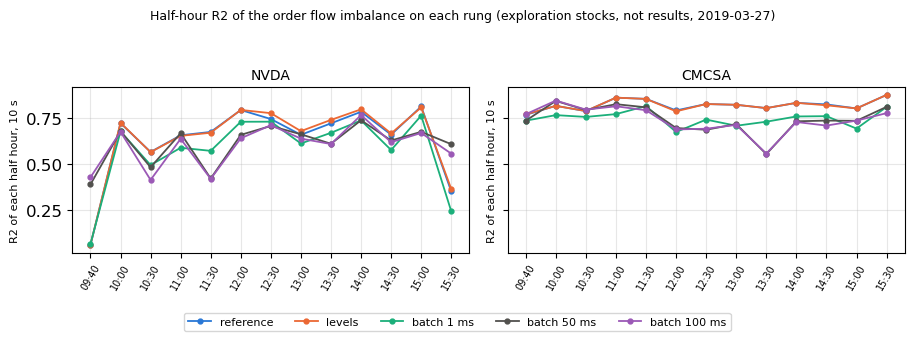

Order flow imbalance on each rung, the reported stocks, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
The median half-hour R2 is the figure. "Below reference": in how many half hours the rung's R2 is below the reference's. Standard error: block bootstrap of the half hours (assumes they are exchangeable; they are not).

                  median R2, 1 s median R2, 5 s median R2, 10 s median R2, 50 s se, 10 s (blocks) below reference, 1 s below reference, 10 s beyond the last change > 0, 1 s
INTC reference             0.795          0.855           0.867           0.861             0.008                 0/13                  0/13                           13/13
     batch 1 ms            0.695          0.778           0.810           0.855             0.010                13/13                 13/13                           13/13
     batch 100 ms          0.562          0.718           0.805           0.839             0.014                13/13       

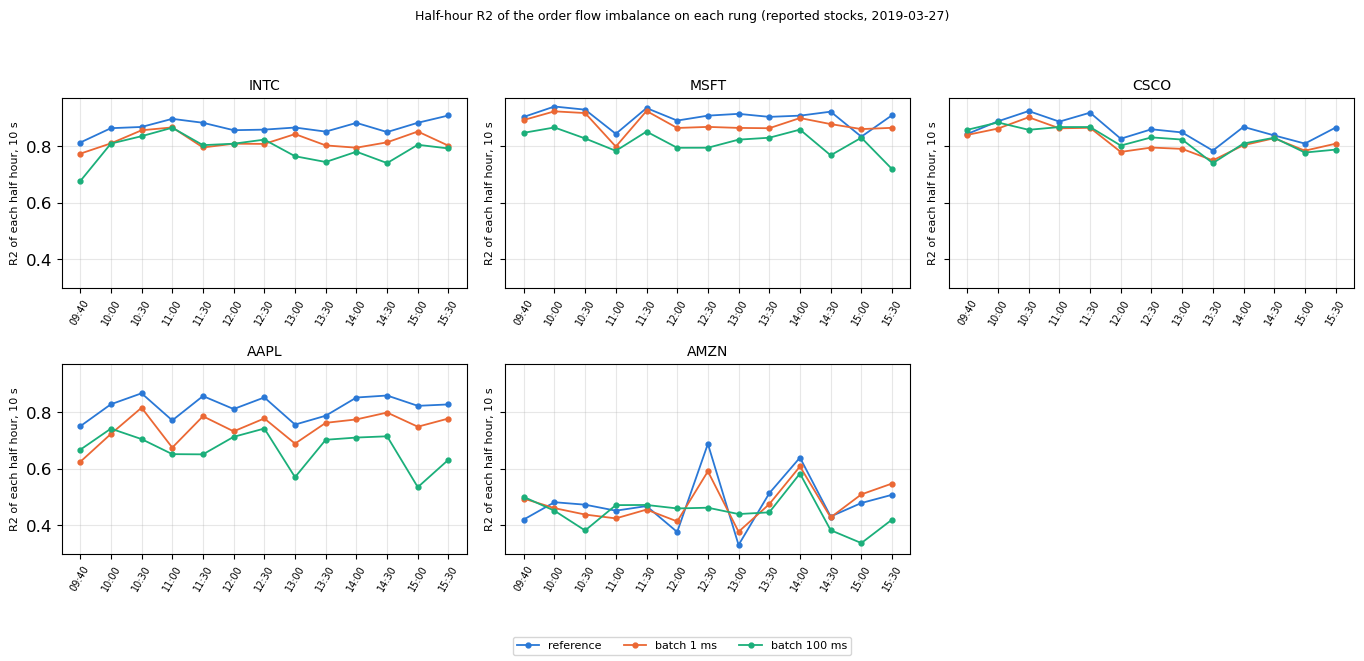

INTC: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.
MSFT: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.
CSCO: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.
AAPL: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.
AMZN: the reference rung's median half-hour R2 and the main pass's differ by at most 0.0e+00 over 4 intervals.


In [33]:
# Section 4, table 3: order flow imbalance on each rung. The figure is the median half-hour R2 of the change of the mid
# on the interval's order flow imbalance, at each interval, with the pooled R2 beside it (a check, never a stock's
# figure: ten seconds of the day can carry most of the flow's sum of squares), the half hours in which a rung's R2 is
# below the reference's, and "beyond the last change" at 1 s. Needs the ladder's machinery and run cells.
def lad_ofi_table(results):
    # a row a stock and rung: the median half-hour R2 at each interval with its block-bootstrap standard error at
    # OFI_MAIN s, the half hours in which a rung's R2 is below the reference's at the first interval and at OFI_MAIN,
    # and
    # the half hours in which the partial correlation beyond the last change at the first interval is above 0
    rows = {}
    first = INTERVALS[0]
    for stock, run_out in results.items():
        reference_ofi = run_out['rungs'][LAD_REFERENCE]['ofi']
        for name in lad_book_rungs(run_out):
            ofi = run_out['rungs'][name]['ofi']
            row = {f'median R2, {h} s': ofi[h]['median half-hour R2'] for h in INTERVALS}
            row[f'se, {OFI_MAIN} s (blocks)'] = ofi[OFI_MAIN]['median half-hour R2 se']
            for h in (first, OFI_MAIN):
                row[f'below reference, {h} s'] = lad_below(ofi[h]['R2 strip'], reference_ofi[h]['R2 strip'])
            row[f'beyond the last change > 0, {first} s'] = (
                f'{ofi[first]["blocks with beyond above 0"]}/{ofi[first]["blocks with R2"]}'
            )
            rows[stock, name] = row
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_pooled_table(results):
    # the pooled R2 (a check, not a figure of the stock) and what the pooled R2 at 1 s is made of: the share of the
    # flow's
    # sum of squares in its ten largest seconds, and the pooled R2 at 1 s without them
    rows = {}
    for stock, run_out in results.items():
        for name in lad_book_rungs(run_out):
            ofi = run_out['rungs'][name]['ofi']
            largest = ofi['largest seconds']
            rows[stock, name] = {f'pooled R2, {h} s': ofi[h]['pooled R2'] for h in INTERVALS} | {
                f'share of the sum of squares in the {TOP_SECONDS} largest seconds, 1 s': largest[
                    'share of the sum of squares of the flow in the ten largest seconds'
                ],
                f'pooled R2, 1 s, without the {TOP_SECONDS}': largest['R2 at 1 s without the ten largest seconds'],
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_plot_ofi(results, heading):
    # a panel a stock (three to a row): the half-hour R2 at OFI_MAIN s on each rung, one line a rung
    columns = min(len(results), 3)
    rows = -(-len(results) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(4.6 * columns, 3.3 * rows), sharey=True, squeeze=False)
    for ax, (stock, run_out) in zip(axes.flat, results.items(), strict=False):
        plot_strips(
            {rung: run_out['rungs'][rung] for rung in lad_book_rungs(run_out)},
            lambda figures: figures['ofi'][OFI_MAIN]['R2 strip'],
            f'R2 of each half hour, {OFI_MAIN} s',
            stock,
            ax=ax,
        )
        ax.tick_params(axis='x', labelrotation=60, labelsize=7)
        ax.set_xlabel('')
        ax.set_ylabel(ax.get_ylabel(), fontsize=8)
        handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()
    for ax in list(axes.flat)[len(results) :]:
        ax.axis('off')
    which = 'exploration stocks, not results' if heading.startswith(EXPLORATION) else 'reported stocks'
    fig.suptitle(f'Half-hour R2 of the order flow imbalance on each rung ({which}, {day_text(DAY)})', fontsize=9)
    fig.legend(handles, labels, loc='lower center', ncols=len(labels), fontsize=8)
    fig.tight_layout(rect=(0, 0.07, 1, 0.95))
    plt.show()


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'Order flow imbalance on each rung, {lad_heading}.')
        print(
            'The median half-hour R2 is the figure. "Below reference": in how many half hours the rung\'s R2 is '
            'below the reference\'s. Standard error: block bootstrap of the half hours (assumes they are '
            'exchangeable; they are not).\n'
        )
        print(shown(lad_ofi_table(lad_results)))
        print(
            '\nThe pooled R2, which is a check and not a figure of the stock, and what the pooled R2 at 1 s is made '
            'of:\n'
        )
        print(shown(lad_pooled_table(lad_results)))
        for lad_h in (INTERVALS[0], OFI_MAIN):
            print(
                f'\nHalf-hour R2 at {lad_h} s (09:40 to 15:50; the first and the last half hour hold twenty minutes):'
            )
            print(
                lad_strips(
                    [
                        (f'{lad_stock_name} {lad_rung}', lad_out['rungs'][lad_rung]['ofi'][lad_h]['R2 strip'])
                        for lad_stock_name, lad_out in lad_results.items()
                        for lad_rung in lad_book_rungs(lad_out)
                    ],
                    3,
                    1.0,
                )
            )
        print()
        lad_plot_ofi(lad_results, lad_heading)
        for lad_stock_name, lad_out in lad_results.items():
            if (DAY, lad_stock_name) in MEASURED:
                # The reference rung is the displayed tape and section 2's pass the signed tape: the order flow is the
                # same up to the few events that the two streams partition differently (a trailing add that the
                # worst-fill rule calls a remainder in one and not in the other), so the median half-hour R2 is
                # compared to within 0.001, not for equality, and the largest difference is printed.
                lad_gap = 0.0
                for lad_h in INTERVALS:
                    lad_mine = lad_out['rungs'][LAD_REFERENCE]['ofi'][lad_h]['median half-hour R2']
                    lad_main = MEASURED[DAY, lad_stock_name]['ofi'][lad_h]['median half-hour R2']
                    lad_gap = max(lad_gap, abs(lad_mine - lad_main))
                    assert math.isclose(lad_mine, lad_main, abs_tol=1e-3), (
                        f'{lad_stock_name}: the reference rung\'s median half-hour R2 at {lad_h} s is not the '
                        f'main pass\'s: {lad_mine:.4f} against {lad_main:.4f}'
                    )
                print(
                    f'{lad_stock_name}: the reference rung\'s median half-hour R2 and the main pass\'s differ by at '
                    f'most {lad_gap:.1e} over {len(INTERVALS)} intervals.'
                )
        if not SMOKE:
            for lad_stock_name, lad_out in lad_results.items():
                for lad_rung in lad_book_rungs(lad_out):
                    lad_ofi_rung = lad_out['rungs'][lad_rung]['ofi']
                    assert all(lad_ofi_rung[lad_h]['blocks with R2'] == N_BLOCKS for lad_h in INTERVALS), (
                        f'{lad_stock_name} {lad_rung}: a half hour has no R2 at some interval'
                    )

**Order flow imbalance on each rung.** The figure is the median half-hour R2 of the mid's change on the interval's order flow imbalance, at 1, 5, 10 and 50 s, with the block bootstrap's standard error at 10 s (it assumes the half hours are exchangeable; they are not) and the number of the 13 half hours in which a rung's R2 is below the reference's. The ladder's prediction reads the 10 s column. Reported stocks, 2019-03-27, the reference then 1 ms then 100 ms:

- INTC: 0.867 (se 0.008), 0.810 (0.010) and 0.805 (0.014) at 10 s; 0.795, 0.695 and 0.562 at 1 s. Both rungs are below the reference in 13 of 13 half hours at 1 s and at 10 s.
- MSFT: 0.909 (0.006), 0.869 (0.012) and 0.828 (0.015) at 10 s; 0.807, 0.739 and 0.643 at 1 s. At 1 s 13 of 13 on both rungs; at 10 s 12 of 13 at 1 ms and 13 of 13 at 100 ms.
- CSCO: 0.861 (0.013), 0.810 (0.020) and 0.831 (0.017) at 10 s; 0.784, 0.662 and 0.611 at 1 s. At 1 s 13 of 13 on both; at 10 s 13 of 13 at 1 ms and 12 of 13 at 100 ms.
- AAPL: 0.828 (0.017), 0.763 (0.019) and 0.703 (0.024) at 10 s; 0.783, 0.697 and 0.587 at 1 s. 13 of 13 on both rungs at both intervals.
- AMZN: 0.473 (0.019), 0.461 (0.024) and 0.452 (0.015) at 10 s; 0.387, 0.350 and 0.317 at 1 s. At 1 s 11 of 13 at 1 ms and 12 of 13 at 100 ms; at 10 s 8 of 13 on both.

The median is lower on both batched rungs than on the reference at each of the four intervals on every reported stock except one cell, CSCO at 100 ms and 50 s (0.882 against 0.869). At 1 s the 1 ms median lies between the reference's and the 100 ms rung's on all five stocks, so part of the drop at 100 ms is there at 1 ms and part is not. At 10 s that holds on four: CSCO's 100 ms median (0.831) is above its 1 ms median (0.810), and the verdict table below gives the share of the drop at 1 ms for each stock. AMZN's drop at 10 s, 0.473 to 0.461 to 0.452, is about the size of the bootstrap's standard errors printed with it (0.019, 0.024 and 0.015). "Beyond the last change" at 1 s is positive in 13 of 13 half hours on every rung of every stock except AAPL's reference and its 100 ms rung, which have 12 of 13. (Exploration: NVDA's median half-hour R2 at 10 s is 0.675 (se 0.034) on the reference, 0.679 on `levels`, 0.612 at 1 ms, 0.659 at 50 ms and 0.637 at 100 ms, and 0.549, 0.554, 0.474, 0.484 and 0.464 at 1 s, with 12 of 13, 9 of 13 and 11 of 13 half hours below the reference at 1 s on the three batched rungs; at 50 s the 50 ms and 100 ms medians, 0.662 and 0.651, are above the reference's 0.644. CMCSA's is 0.822 (se 0.010) at 10 s on the reference, 0.819 on `levels`, 0.756, 0.736 and 0.736 on the batched rungs, and 0.728, 0.728, 0.602, 0.526 and 0.509 at 1 s, below the reference in 13 of 13 half hours on every batched rung at 1 s.) No direction for feeds in general is read from any of these medians, which are one day's on these rungs.

**The pooled R2 and what it is made of.** The second table prints the pooled R2 over the session beside the median, the share of the flow's sum of squares that the ten largest seconds hold at 1 s, and the pooled R2 at 1 s without them. It is a check and never the ladder's evidence. On the reported stocks the ten largest seconds hold 0.029 to 0.133 of the sum of squares at 1 s on every rung (INTC 0.047 on the reference, 0.069 at 1 ms and 0.094 at 100 ms; AMZN 0.116, 0.133 and 0.112), and at 1 s the pooled R2 and the median agree on all five that both rungs are below the reference (INTC pooled 0.768, 0.662 and 0.531 against medians 0.795, 0.695 and 0.562). At the longer intervals they disagree on a few rungs, in both directions. MSFT at 1 ms and 50 s has a pooled R2 of 0.880 against the reference's 0.876, above it, with a median of 0.897 against 0.911, below it. AMZN's pooled R2 at 100 ms is 0.438 against 0.433 at 10 s and 0.437 against 0.363 at 50 s, above the reference's, while its medians (0.452 and 0.448) are below its reference's (0.473 and 0.460). CSCO at 100 ms and 50 s reads 0.838 against 0.839 pooled, below, and 0.882 against 0.869 as a median, above. The ten largest seconds' share is a 1 s figure and is small on these stocks, so the table does not say what produces these disagreements. The exploration stock that the ten seconds do explain is NVDA (exploration): the ten largest seconds hold 0.640 of its sum of squares on the reference, 0.541 at 1 ms, 0.199 at 50 ms and 0.209 at 100 ms, its pooled R2 at 1 s rises from 0.234 on the reference to 0.263, 0.389 and 0.376 on the three batched rungs while its median falls, and without those seconds the pooled R2 at 1 s is 0.550 on the reference and 0.479, 0.460 and 0.448 on the rungs, which falls as the median does. NVDA's pooled R2 stays above the reference's at 5, 10 and 50 s on every batched rung, where its medians are below at 5 and 10 s. CMCSA's (exploration) pooled R2 at 1 s falls on every rung (0.693 on the reference, 0.573, 0.509 and 0.503), and at 50 s it is above the reference's on the 50 ms and 100 ms rungs (0.786 and 0.788 against 0.741) where the medians are below (0.836 and 0.827 against 0.848), with the ten largest seconds holding 0.098 or less at 1 s.

**The figure.** The half-hour R2 at 10 s on each rung, from the strips printed above it (each point is one half hour's R2, and the median is the middle of a line's 13 points). On INTC the three lines keep their order for most of the day: the 1 ms line follows the reference's below it, and the 100 ms line is lowest at 09:40 (0.677 against 0.814) and in the afternoon (0.745 at 13:30 and 0.741 at 14:30 against 0.852 and 0.851), and is close to the 1 ms line from 10:00 to 12:30 (0.810 against 0.811 at 10:00, 0.805 against 0.796 at 11:30, 0.810 on both at 12:00). MSFT's lines move together at the reference's dip at 11:00 (0.845 on the reference, 0.799 at 1 ms, 0.784 at 100 ms); at its dip at 15:00 (0.835) the 1 ms line (0.861) is above it and the 100 ms line (0.831) is level with it, and the 100 ms line separates most at 15:30 (0.720 against 0.910). On CSCO the 100 ms line is above the reference's at 09:40 (0.859 against 0.844) and below it in the other twelve half hours, by 0.004 at 10:00 (0.885 against 0.889). AAPL's lines separate from the start and stay apart, the 100 ms line furthest below at 15:00 (0.535 against 0.823). AMZN's reference swings between 0.331 (13:00) and 0.688 (12:30), and the rungs follow it and cross it: the 1 ms line is above the reference at 09:40 (0.495 against 0.421), 12:00, 13:00, 15:00 and 15:30 and the 100 ms line at 09:40 (0.501), 11:00, 11:30, 12:00 and 13:00. (Exploration: NVDA's reference line is at 0.061 at 09:40 and 0.352 at 15:30, and the 50 ms and 100 ms lines are above it in those two half hours (0.390 and 0.429 at 09:40, 0.608 and 0.557 at 15:30) while the 1 ms line is level with it at the open (0.068) and below it at the close (0.244); CMCSA's 50 ms and 100 ms lines are above the reference's at 10:00 (0.843 and 0.845 against 0.816) and furthest below it at 13:30 (0.554 and 0.558 against 0.804).) The strips show where the rungs' lines separate from the reference's and where they do not, half hour by half hour, and they say nothing about any feed.

In [34]:
# Section 4, table 4: the tick rule and the quote rule at lags 0, 1 and 5 against the true aggressor on each rung, per
# lot,
# on the displayed executions (the rungs are the displayed tape: no hidden volume is in any figure). The trade stream
# of a batch rung is the reference's (the true aggressor, the order's fills together, the time of its first fill), so
# only what the book gives the rule differs; a shifted rung is the 100 ms batch rung with its trades moved: a bound
# on what an unsynchronized trade stream does, not a model of any venue. No per-order figure is shown (a feed that
# stamps
# trades to the millisecond may not give an order's fills as one). Needs the ladder's machinery and run cells.
LAD_RULES = {'tick': 'tick rule', **{f'quote{lag}': f'quote lag {lag}' for lag in LAGS}}  # the columns' names


def lad_signing_table(results):
    # a row a stock and rung (every rung): per lot, in percent, the tick rule and the quote rule at each lag on the
    # displayed executions; the lag-0 rule at the resting price (the check, 100.00% on the reference); and the half
    # hours
    # in which the lag-0 rule is below the reference's
    rows = {}
    for stock, run_out in results.items():
        reference = run_out['rungs'][LAD_REFERENCE]['signing']
        for name, _, _ in run_out['specs']:
            signing = run_out['rungs'][name]['signing']
            row = {LAD_RULES[rule]: 100 * signing[rule]['displayed (both)']['per lot'] for rule in RULES}
            row['lag 0 at the resting price'] = 100 * signing['quote0']['displayed, at the resting price']['per lot']
            priced = signing['quote0']['displayed, priced (C)']['per lot']
            row['lag 0 priced (C)'] = math.nan if priced is None else 100 * priced
            row['lag 0 below reference'] = lad_below(
                signing['quote0']['blocks, per lot'], reference['quote0']['blocks, per lot']
            )
            row['lag 0 coverage %'] = 100 * signing['quote0']['displayed (both)']['coverage by lots']
            rows[stock, name] = row
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_true_spread_table(results):
    # the lag-0 quote rule per lot by the spread before the order in the reference's book, with the fills it is over; a
    # class with under MIN_READINGS fills is a count only
    rows = {}
    for stock, run_out in results.items():
        for name, kind, _ in run_out['specs']:
            if kind == LAD_LEVELS:
                continue
            by_class = run_out['rungs'][name]['by true spread']['quote0']
            rows[stock, name] = {
                spread: (
                    f'{100 * by_class[spread]["per lot"]:.1f} ({by_class[spread]["fills"]:,})'
                    if by_class[spread]['fills'] >= MIN_READINGS
                    else f'{by_class[spread]["fills"]:,} fills: under {MIN_READINGS}'
                )
                for spread in CLASSES
            }
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'Signing on each rung, per lot, displayed executions, {lad_heading}.')
        print(
            'Percent of the lots whose side the rule gets right; the tick rule does not read the book. A shifted rung '
            'is the batch rung with its trades stamped a constant later or earlier: a bound on what an unsynchronized '
            'trade stream does, not a model of any venue. No per-order accuracy is shown: a feed that stamps trades '
            'to the millisecond may not give an order\'s fills as one.\n'
        )
        lad_signing_frame = lad_signing_table(lad_results)
        print(
            shown(
                lad_signing_frame,
                {c: '.2f' for c in lad_signing_frame.columns if lad_signing_frame[c].dtype.kind == 'f'},
            )
        )
        print(
            '\nThe lag-0 quote rule per lot by the spread before the order in the reference\'s book (the true spread; '
            'fills in parentheses):\n'
        )
        print(shown(lad_true_spread_table(lad_results)))
        print('\nHalf-hour lag-0 quote rule per lot (%):')
        print(
            lad_strips(
                [
                    (f'{lad_stock_name} {lad_rung}', lad_out['rungs'][lad_rung]['signing']['quote0']['blocks, per lot'])
                    for lad_stock_name, lad_out in lad_results.items()
                    for lad_rung, _, _ in lad_out['specs']
                ],
                1,
                100,
                6,
                label_width=46,
            )
        )
        print()
        for lad_stock_name, lad_out in lad_results.items():
            lad_check_row = lad_out['rungs'][LAD_REFERENCE]['signing']['quote0']['displayed, at the resting price']
            lad_exact, lad_misses = lag0_exact(lad_check_row)
            assert lad_exact, (
                f'{lad_stock_name}: the lag-0 quote rule at the resting price misses on the reference ({lad_misses})'
            )
            print(f'{lad_stock_name}: the lag-0 quote rule at the resting price on the reference: {lad_misses}.')

Signing on each rung, per lot, displayed executions, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
Percent of the lots whose side the rule gets right; the tick rule does not read the book. A shifted rung is the batch rung with its trades stamped a constant later or earlier: a bound on what an unsynchronized trade stream does, not a model of any venue. No per-order accuracy is shown: a feed that stamps trades to the millisecond may not give an order's fills as one.

                                   tick rule quote lag 0 quote lag 1 quote lag 5 lag 0 at the resting price lag 0 priced (C) lag 0 below reference lag 0 coverage %
NVDA  reference                        88.31       99.80       90.36       79.98                     100.00            61.44                  0/13           100.00
      levels                           88.31       99.80       90.36       79.98          

**The quote rule and the tick rule on each rung.** The first table gives the percent of lots (per lot only: no per-order figure is shown on any rung) whose side each rule gets right, on the displayed executions alone (tape none). The check comes first: the quote rule at lag 0 at the resting price has no miss on the reference, asserted in the cell, with the misses printed under the tables: 0 of 22,114 fills (INTC), 43,266 (MSFT), 20,979 (CSCO), 47,541 (AAPL) and 20,280 (AMZN), and 0.0000% of the lots; (exploration) 0 of 20,637 fills on NVDA and 0 of 15,909 on CMCSA. The rule reads the mid just before the event and a fill is at the maker's price, so it is exact by construction, and the check is on the conversion's touch, prices and aggressors and not a finding.

The tick rule does not read the book, so its per-lot figure is the same on every rung that keeps the trades (all of them here): INTC 66.08, MSFT 71.56, CSCO 66.35, AAPL 79.72, AMZN 87.69 (exploration: NVDA 88.31, CMCSA 62.15). The quote rule at lags 1 and 5 is the reference's to the digit on every batch rung (INTC 86.18 and 70.42, AMZN 86.96 and 79.05), and on the rung with the trades 50 ms later it moves by at most 3.6 points at lag 1 (CSCO 84.64 to 81.05) and by 0.1 or less at lag 5 (plain differences of printed figures). The lag-0 rule is the one that falls. It reads on the reference, at 1 ms and at 100 ms, 99.21, 96.97 and 90.66 on INTC; 98.85, 94.11 and 86.10 on MSFT; 98.75, 94.86 and 90.27 on CSCO; 99.55, 95.46 and 89.24 on AAPL; and 99.93, 91.43 and 89.04 on AMZN. A shifted rung is the 100 ms batch with its trades stamped 50 ms later than the book: a bound on what an unsynchronized trade stream does, by a constant that no venue is known to have, and not a feed. On it the lag-0 rule reads 56.72 (INTC), 53.98 (MSFT), 56.01 (CSCO), 64.15 (AAPL) and 70.38 (AMZN). (Exploration: NVDA's lag-0 rule reads 99.80 on the reference and `levels`, 94.43 at 1 ms, 92.67 at 50 ms, 92.37 at 100 ms, 92.11 with the trades 50 ms earlier, 73.71 with them 50 ms later and 57.42 with them 100 ms later; CMCSA's reads 98.35 on the reference and 98.32 on `levels`, and then, in the same order, 93.28, 86.67, 84.97, 82.23, 56.71 and 22.78.) The lag-0 rule is below the reference's in 13 of 13 half hours on every batch rung and every shifted rung of every stock, and, on `levels` (exploration), in 0 of 13 for NVDA and in 4 of 13 for CMCSA, where the half-hour strip's printed digit shows the difference at 11:30 (98.9 against 99.0 on the reference) and at 15:00 (99.0 against 99.2). These `levels` figures of CMCSA are the corrected library's, and the correction moved them (the limitations list them). These are the falls of these rungs on this day; no direction for feeds in general is read from them.

The "priced (C)" column is the lag-0 rule per lot on the executions that print at a price of their own, a cent off their order's price, so the rule reads that price against a mid that does not know it. On the reference it reads 7.44 (INTC), 29.89 (MSFT), 9.29 (CSCO), 33.04 (AAPL) and 86.03 (AMZN), against 98.75 to 99.93 on all the displayed executions of those stocks and 100.00 at the resting price. This table does not print how many executions that is. Section 3's table of each kind of execution apart does: 244, 832, 352, 408 and 50 fills, so AMZN's 86.03 stands on 50 fills. On the batch rungs the column does not fall as the lag-0 rule does: INTC 7.44, 10.73 at 1 ms and 9.86 at 100 ms; MSFT 29.89, 26.43 and 29.64; CSCO 9.29, 16.11 and 21.54; AAPL 33.04, 29.53 and 31.30; AMZN 86.03, 17.83 and 13.60. The column rests on at most 832 executions a stock, and no direction is read from it. Section 7's Table 7g (asked for after the run, judged by no rule) counts the executions priced more than a cent from their order's displayed price: on this day it has one, AMZN's, at 16:00:00.770, not printable and outside the frames' window, so it is in none of these figures.

**The lag-0 rule by the true spread before the order.** The second table gives the lag-0 rule per lot in each spread class of the reference's book, with the fills in parentheses and a class under 200 fills a count. The figure is by the reference's spread, the true spread before the order, and not by the stale spread that the rung's consumer sees: a class holds the fills whose true spread was that, whatever the batched book showed. On the reference it reads 99.4 on INTC's one-tick fills (22,257), 99.4 on MSFT's (42,814) and 75.4 on its two-tick fills (1,113), 98.8 on CSCO's one-tick fills (21,242), 99.7, 99.2 and 100.0 on AAPL's one-tick (26,766), two-tick (16,603) and three-or-more (4,580) fills, and 100.0 on AMZN's three-or-more fills (20,175). At 100 ms these read 90.8, 86.5 and 67.1, 90.3, 86.9, 91.8 and 93.6, and 89.7; the verdict cell's table gives each drop, 6.4 to 12.9 points in every class with 200 fills or more (INTC 8.6; MSFT 12.9 and 8.2; CSCO 8.5; AAPL 12.8, 7.3 and 6.4; AMZN 10.3). Within AAPL and within MSFT the loss is larger in the class with the narrower spread. (Exploration: NVDA's fills read 99.8, 98.1 and 100.0 in the one-tick, two-tick and three-or-more classes on the reference, 73.5, 84.9 and 97.7 at 1 ms, and 65.2, 80.8 and 96.5 at 100 ms.) What the classes show about where the rule loses is the construction's: the states that a window does not show are the ones whose spread differs from the book the rule reads, and this table, being by the true spread, does not measure that, so it is a reading of the construction and not a result.

**The half-hour strip of the lag-0 rule.** The fall is there in every half hour of every reported stock on every batch and shifted rung (13 of 13). It is largest, at 100 ms, at 13:00 on INTC (84.8 against 99.5), at 10:00 on MSFT (82.6 against 99.0) and at 09:40, the first twenty minutes, on CSCO (85.3 against 98.5), AAPL (86.2 against 99.7) and AMZN (78.9 against 100.0), and smallest at 15:30 on INTC (98.4 against 99.2), 12:30 on MSFT (90.5 against 98.1), 13:30 on CSCO (96.7 against 99.1), 12:30 on AAPL (94.3 against 99.7) and 12:00 on AMZN (93.6 against 100.0). At 1 ms the half hours with the largest fall are the same (INTC 13:00, 92.4 against 99.5; MSFT 10:00, 90.6 against 99.0; CSCO, AAPL and AMZN 09:40), and INTC's 15:30 half hour is 99.2 on both at the printed digit. (Exploration: NVDA's largest fall at 100 ms is at 12:00, 85.9 against 99.2, and CMCSA's at 10:30, 77.9 against 98.7.) The strips give where the fall is largest on this day and do not say why.

In [35]:
# Section 4, table 5: VPIN's level on each rung with the true sides and with bulk volume classification, and the share
# of
# buckets in which the mid did not change, which is what bulk volume classification reads (a bucket's change of the mid
# in
# units of its standard deviation): levels only, no excess over a null (an excess is only shown with its range over
# bucket origins, in section 2). The trade stream is the reference's on every rung that does not move trades, so VPIN
# with
# true sides is the reference's to the digit: a check. Needs the ladder's machinery and run cells.
def lad_vpin_table(results):
    # a row a stock and rung (every rung): V, the buckets closed in the session, VPIN with true sides, with bulk volume
    # classification, the share of buckets whose mid did not change, and the half hours in which that share is above
    # the reference's
    rows = {}
    for stock, run_out in results.items():
        reference = run_out['rungs'][LAD_REFERENCE]['vpin']
        for name, _, _ in run_out['specs']:
            vpin = run_out['rungs'][name]['vpin']
            rows[stock, name] = {
                'V (shares)': vpin['V'],
                'buckets in the session': vpin['buckets in session'],
                'VPIN, true sides': vpin['true level'],
                'VPIN, bulk volume': vpin['bvc level'],
                'mid unchanged in a bucket %': 100 * vpin['bvc unchanged mid'],
                'half hours above reference': lad_above(vpin['bvc unchanged strip'], reference['bvc unchanged strip']),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    for lad_heading, lad_results in lad_halves():
        print(f'VPIN and bulk volume classification on each rung, {lad_heading}.')
        print(
            'Levels over the buckets closed in the session (50 buckets, V from the first 200 fills, bucket-weighted); '
            'no excess is shown. The true sides are the reference\'s on every rung: the trades are.\n'
        )
        lad_vpin_frame = lad_vpin_table(lad_results)
        print(
            shown(
                lad_vpin_frame,
                {
                    'V (shares)': ',.0f',
                    'buckets in the session': ',.0f',
                    'VPIN, true sides': '.4f',
                    'VPIN, bulk volume': '.4f',
                    'mid unchanged in a bucket %': '.1f',
                },
            )
        )
        print('\nHalf-hour share of buckets with an unchanged mid (%):')
        print(
            lad_strips(
                [
                    (f'{lad_stock_name} {lad_rung}', lad_out['rungs'][lad_rung]['vpin']['bvc unchanged strip'])
                    for lad_stock_name, lad_out in lad_results.items()
                    for lad_rung, _, _ in lad_out['specs']
                ],
                1,
                100,
                6,
                label_width=46,
            )
        )
        print()
        for lad_stock_name, lad_out in lad_results.items():
            lad_levels = {name: f['vpin']['true level'] for name, f in lad_out['rungs'].items()}
            lad_unmoved = [name for name, kind, _ in lad_out['specs'] if kind != 'shift']
            assert all(
                math.isclose(lad_levels[name], lad_levels[LAD_REFERENCE], abs_tol=1e-12) for name in lad_unmoved
            ), f'{lad_stock_name}: VPIN with true sides differs between rungs that keep the trades: {lad_levels}'

VPIN and bulk volume classification on each rung, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.
Levels over the buckets closed in the session (50 buckets, V from the first 200 fills, bucket-weighted); no excess is shown. The true sides are the reference's on every rung: the trades are.

                                   V (shares) buckets in the session VPIN, true sides VPIN, bulk volume mid unchanged in a bucket % half hours above reference
NVDA  reference                         4,800                    358           0.3843            0.4599                         3.9                       0/13
      levels                            4,800                    358           0.3843            0.4596                         3.9                       0/13
      batch 1 ms                        4,800                    358           0.3843            0.4574                    

**VPIN and bulk volume classification on each rung.** The table gives levels only, over the buckets closed in the session, with the bucket size V (shares) and the number of buckets. It shows no excess over a null, so nothing in it says how persistent the order signs are, and VPIN is not read as informed trading; the levels are not compared across stocks either, since V differs (5,000 shares on INTC, MSFT and CSCO, 1,500 on AAPL and 475 on AMZN). VPIN with true sides is the reference's to the digit on every batch rung, which the cell asserts, because the trade stream is the reference's: INTC 0.3634 (641 buckets), MSFT 0.2810 (911), CSCO 0.3656 (560), AAPL 0.4811 (3,106) and AMZN 0.5869 (1,209). The shifted rungs move the trades and are the only rungs on which it can differ. On the reported stocks the rung with the trades 50 ms later reads the same four digits and the same V and buckets. (Exploration: on NVDA the rung with the trades 50 ms earlier reads 0.3847 on V of 4,850 and 354 buckets against 0.3843, 4,800 and 358, and on CMCSA 0.4021 against 0.4026; the rungs with the trades 50 and 100 ms later equal the reference's on both.)

Bulk volume classification reads a bucket's change of the mid in units of its standard deviation, so a bucket whose mid did not change reads as balanced. Its level on the reference, at 1 ms and at 100 ms is 0.4711, 0.4605 and 0.4482 on INTC; 0.4972, 0.4940 and 0.4938 on MSFT; 0.4997, 0.4848 and 0.4797 on CSCO; 0.4717, 0.4715 and 0.4623 on AAPL; and 0.4633, 0.4572 and 0.4510 on AMZN, so it is lower on both batch rungs than on the reference on every reported stock (the rung with the trades 50 ms later reads 0.4537, 0.4944, 0.4833, 0.4589 and 0.4488). The share of buckets whose mid did not change is on the reference 9.2% (INTC), 5.4% (MSFT), 9.3% (CSCO), 8.4% (AAPL) and 5.1% (AMZN); at 1 ms 18.3%, 10.3%, 17.7%, 9.2% and 6.5%; at 100 ms 22.2%, 10.1%, 20.7%, 12.1% and 10.3%. It is above the reference's share in 12 and 12 of the 13 half hours at 1 ms and 100 ms on INTC, 9 and 10 on MSFT, 12 and 13 on CSCO, 7 and 12 on AAPL, and 10 and 11 on AMZN. So on the reported stocks a coarser window raises the share and lowers bulk volume classification's level. The exploration stocks do not all move the same way: CMCSA's share rises with the window (12.9% on the reference, 20.7% at 1 ms, 23.5% at 50 ms and 23.9% at 100 ms) and NVDA's does not (3.9% on the reference, 3.6%, 3.6% and 4.2%). The table describes these rungs stock by stock, and no direction for feeds in general is claimed from it.

The lift over the better baseline within each spread class as a sweep over batch length, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; tape none, a replace as one, session 09:40:00 to 15:50:00.
Each batch length is run on 4 offsets of the grid; the lift is the mean over the offsets with the range in parentheses; a class with under 200 readings at some offset is a count only. Hit and reversal rates are means over the offsets. Not a statement about any feed.

NVDA:
                        one tick: readings    one tick: lift pp one tick: hit / reversal % two ticks: readings      two ticks: lift pp two ticks: hit / reversal % three or more: readings three or more: lift pp three or more: hit / reversal %
reference (every event)                909                +10.2                66.0 / 55.8               1,804                   +10.6                 60.6 / 49.1                  49,760                   +6.3                     56.3 / 48.1
1 ms 

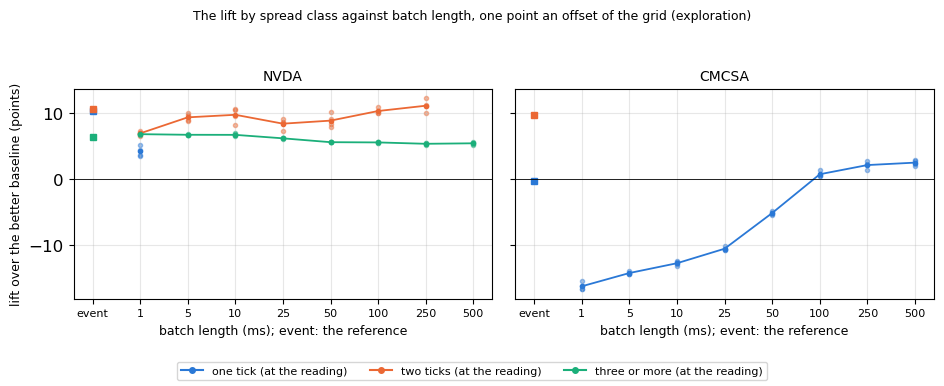

In [36]:
# Section 4, table 6 and figure: the lift as a sweep over batch length, the only way a batched one-tick lift is shown.
# The exploration stocks only (the reported stocks have three rungs, not a sweep). Each length is run on LAD_OFFSETS
# offsets of the batch grid (the windows start k / 4 of a length after 09:30:00; the unit clock does not move),
# because at some lengths the figure moves with the grid's offset: the mean over the offsets is the line, each offset
# a point, and a class is drawn at a length only if every offset has MIN_READINGS readings or more. Needs the ladder's
# machinery and run cells.
def lad_sweep_table(run_out):
    # a row a batch length (and the reference): for each spread class, the readings (the range over the offsets), the
    # lift
    # in points (the mean over the offsets and the range) and the hit and reversal rates (the means); a class under
    # MIN_READINGS readings at some offset is a count only
    rows = {}
    reference = run_out['rungs'][LAD_REFERENCE]['imbalance']['classes']
    rows['reference (every event)'] = {}
    for spread in CLASSES:
        row = reference[spread]
        rows['reference (every event)'] |= {
            f'{spread}: readings': f'{row["n"]:,}',
            f'{spread}: lift pp': f'{100 * row["lift over the better"]:+.1f}' if row['shown'] else 'count only',
            f'{spread}: hit / reversal %': f'{100 * row["hit"]:.1f} / {100 * row["reversal"]:.1f}'
            if row['shown']
            else '-',
        }
    for ms in LAD_SWEEP_MS:
        cells = {}
        for spread in CLASSES:
            offsets = [run_out['sweep'][ms, k]['classes'][spread] for k in range(LAD_OFFSETS)]
            n = [row['n'] for row in offsets]
            cells[f'{spread}: readings'] = f'{min(n):,} to {max(n):,}' if min(n) != max(n) else f'{n[0]:,}'
            if min(n) >= MIN_READINGS:
                lift = [100 * row['lift over the better'] for row in offsets]
                cells[f'{spread}: lift pp'] = f'{np.mean(lift):+.1f} ({min(lift):+.1f} to {max(lift):+.1f})'
                cells[f'{spread}: hit / reversal %'] = (
                    f'{100 * np.mean([row["hit"] for row in offsets]):.1f} / '
                    f'{100 * np.mean([row["reversal"] for row in offsets]):.1f}'
                )
            else:
                cells[f'{spread}: lift pp'] = 'count only'
                cells[f'{spread}: hit / reversal %'] = '-'
        rows[f'{ms:g} ms'] = cells
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    if lad_explored:
        print(
            f'The lift over the better baseline within each spread class as a sweep over batch length, {EXPLORATION}, '
            f'{day_text(DAY)}; {convention("none")}, session {SESSION_START} to {SESSION_END}.'
        )
        print(
            f'Each batch length is run on {LAD_OFFSETS} offsets of the grid; the lift is the mean over the offsets '
            f'with the range in parentheses; a class with under {MIN_READINGS} readings at some offset is a count '
            'only. Hit and reversal rates are means over the offsets. Not a statement about any feed.\n'
        )
        for lad_stock_name, lad_out in lad_explored.items():
            print(f'{lad_stock_name}:')
            print(lad_sweep_table(lad_out).to_string())
            print()
        lad_fig, lad_axes = plt.subplots(
            1, len(lad_explored), figsize=(4.8 * len(lad_explored), 3.8), sharey=True, squeeze=False
        )
        lad_x = np.arange(len(LAD_SWEEP_MS) + 1)
        lad_handles = {}
        for lad_ax, (lad_stock_name, lad_out) in zip(lad_axes[0], lad_explored.items(), strict=True):
            for lad_color, lad_spread in zip((BLUE, ORANGE, AQUA), CLASSES, strict=True):
                lad_ref = lad_out['rungs'][LAD_REFERENCE]['imbalance']['classes'][lad_spread]
                if lad_ref['shown']:
                    lad_ax.plot([0], [100 * lad_ref['lift over the better']], marker='s', color=lad_color, markersize=5)
                    lad_handles[lad_spread] = lad_color
                lad_means = []
                for lad_i, lad_ms in enumerate(LAD_SWEEP_MS, start=1):
                    lad_rows = [lad_out['sweep'][lad_ms, k]['classes'][lad_spread] for k in range(LAD_OFFSETS)]
                    if all(row['n'] >= MIN_READINGS for row in lad_rows):
                        lad_lifts = [100 * row['lift over the better'] for row in lad_rows]
                        lad_ax.scatter([lad_i] * len(lad_lifts), lad_lifts, s=9, color=lad_color, alpha=0.45)
                        lad_means.append((lad_i, float(np.mean(lad_lifts))))
                if lad_means:
                    lad_ax.plot(*zip(*lad_means, strict=True), color=lad_color, linewidth=1.3, marker='o', markersize=3)
                    lad_handles[lad_spread] = lad_color
            lad_ax.axhline(0, color='black', linewidth=0.6)
            lad_ax.set_xticks(lad_x, ['event'] + [f'{ms:g}' for ms in LAD_SWEEP_MS], fontsize=8)
            lad_ax.set_xlabel('batch length (ms); event: the reference', fontsize=9)
            lad_ax.set_title(lad_stock_name, fontsize=10)
        lad_axes[0][0].set_ylabel('lift over the better baseline (points)', fontsize=9)
        lad_fig.suptitle(
            'The lift by spread class against batch length, one point an offset of the grid '
            f'({EXPLORATION.split(":")[0]})',
            fontsize=9,
        )
        lad_fig.legend(
            [plt.Line2D([], [], color=color, marker='o', markersize=4) for color in lad_handles.values()],
            [f'{spread} (at the reading)' for spread in lad_handles],
            loc='lower center',
            ncols=len(lad_handles),
            fontsize=8,
        )
        lad_fig.tight_layout(rect=(0, 0.07, 1, 0.95))
        plt.show()
        for lad_stock_name, lad_out in lad_explored.items():
            lad_first = lad_out['sweep'][LAD_SWEEP_MS[0], 0]
            assert lad_first['updates'] > 0 and lad_first['readings'] > 0, (
                f'{lad_stock_name}: the finest batch has no readings'
            )
            assert all(
                lad_out['sweep'][ms, k]['offset ms'] == ms * k / LAD_OFFSETS
                for ms in LAD_SWEEP_MS
                for k in range(LAD_OFFSETS)
            ), f'{lad_stock_name}: the sweep\'s offsets are not the grid\'s fractions'
    else:
        print('no exploration stock was run, so there is no sweep.')

**The sweep over batch length** (exploration: NVDA and CMCSA on 2019-03-27, what the code was built on, not results, and not run on the reported stocks). Each batch length is run on four offsets of the grid, the windows starting 0, 1/4, 1/2 and 3/4 of a length after 09:30:00. For a class that has 200 readings or more at every offset of a length the table gives the lift as the mean over the offsets with the range in parentheses, and the hit and reversal rates as means; a class under 200 readings at some offset is a count at that length. On NVDA the one-tick class has a line at 1 ms only: +4.2 (range +3.6 to +5.2) on 215 to 232 readings, with a hit rate of 61.1% and a reversal rate of 56.9%, against +10.2 on the reference (909 readings). From 5 ms its readings are 155 to 162 and fewer (23 to 25 at 500 ms), so a stock whose one-tick class is small has no one-tick line at most lengths. NVDA's two-tick class has a line from 1 ms to 250 ms: +6.9 (+6.6 to +7.3) at 1 ms, +9.3 (+8.8 to +9.9) at 5 ms, +9.7 (+8.1 to +10.7) at 10 ms, +8.4 (+7.2 to +9.1) at 25 ms, +8.8 (+7.9 to +10.2) at 50 ms, +10.3 (+10.0 to +10.9) at 100 ms and +11.1 (+10.0 to +12.2) at 250 ms, against +10.6 on the reference, and is a count at 500 ms (158 to 169 readings). Its three-or-more class has a line at every length, +6.8, +6.7, +6.7, +6.2, +5.6, +5.6, +5.3 and +5.4 from 1 ms to 500 ms against +6.3 on the reference, with a range over the offsets of 0.6 point at most (+5.1 to +5.7 at 500 ms). So on NVDA the two-tick lift moves from +6.9 to +11.1 over the lengths and with the offset by up to 2.6 points at one length (10 ms), and the three-or-more lift moves by 1.5 points over the lengths and hardly with the offset. In the three-or-more class the reversal rate moves more than the hit rate, from 51.2% at 1 ms to 45.7% at 100 ms where the hit rate goes from 58.0% to 55.6%.

On CMCSA the one-tick class has a line at every length, from 2,683 to 2,706 readings at 1 ms to 1,883 to 1,894 at 500 ms: -16.2 (-16.6 to -15.4) at 1 ms, -14.2 at 5 ms, -12.7 at 10 ms, -10.5 at 25 ms, -5.1 at 50 ms, +0.8 (+0.4 to +1.5) at 100 ms, +2.1 at 250 ms and +2.5 (+2.0 to +2.9) at 500 ms, against -0.3 on the reference (3,488 readings). It moves by 18.7 points from 1 ms to 500 ms (a plain difference of two printed means) and the offset moves it by 1.3 points at most at any length. Here the hit rate is the one that moves, from 48.5% at 1 ms to 65.0% at 500 ms, and the reversal rate hardly (64.7% to 62.5%): the one-tick hit rate at 1 ms, 48.5%, is below a coin's. CMCSA's two-tick class is a count at every length (125 to 128 readings at 1 ms, 16 to 20 at 500 ms) and its three-or-more class holds none.

The explanation the exploration gave for the fall of the one-tick lift at the short lengths is that the reading is taken one window after the change it follows. That is the exploration's reading of it, not a result of this notebook, and the sweep does not test it. The sweep is over batch length on two stocks of one day. It is not a statement about any feed, no direction for feeds in general is claimed, and no single batched one-tick lift is a figure of this notebook.

In [37]:
# Section 4, the ladder's prediction. The rule (the predictions cell): the median half-hour R2 of the order flow
# imbalance at OFI_MAIN seconds is lower at the last batch length than on the reference, with half the drop or more
# already at the first, and the lag-0 quote rule, per lot, is lower at the last than on the reference by 2 points or
# more. It is judged for each reported stock by the setup's judge on `results['ladder']`, which lad_judged builds from
# a stock's figures; the exploration stocks are shown with the same inputs and no verdict (what the code was built on
# is not a result). Needs the ladder's machinery and run cells.
def lad_inputs_table(results, judge):
    # a row a stock: the rule's inputs and, for the reported stocks, its status. The lag-0 quote rule's level depends on
    # the spreads the stock trades at (a stock that trades at three ticks or more is read higher at every batch length),
    # so the rule reads the drop from the reference to the last batch length, and the reference's level, the level at
    # the last and the drop are printed together; lad_level_split gives the level by spread class.
    rows = {}
    for stock, run_out in results.items():
        keys = lad_judged(run_out)
        reference, first, last = keys['median_r2_reference'], keys['median_r2_1ms'], keys['median_r2_100ms']
        quote_reference = keys['quote0_reference']
        row = {
            f'median R2, {OFI_MAIN} s, reference': reference,
            f'batch {LAD_FIRST:g} ms': first,
            f'batch {LAD_LAST:g} ms': last,
            f'share of the drop at {LAD_FIRST:g} ms': (reference - first) / (reference - last)
            if reference > last
            else math.nan,
            'lag-0 quote rule, reference, per lot %': 100 * quote_reference,
            f'lag-0 quote rule at {LAD_LAST:g} ms, per lot %': 100 * keys['quote0_100ms'],
            'drop from the reference, pp': 100 * (quote_reference - keys['quote0_100ms']),
        }
        if judge:
            row['status'] = PREDICTIONS['ladder'].judge({'ladder': keys}).status
        rows[stock] = row
    return pd.DataFrame.from_dict(rows, orient='index')


def lad_level_split(results):
    # The lag-0 quote rule per lot on the reference and at the last batch length, by the spread before the order in the
    # reference's book (the true spread), with the fills in each class and the drop in points: a level depends on the
    # spreads at which the stock trades (the rule reads the drop, which is why it does not read a level), so the drop
    # is shown class by class. A class with under MIN_READINGS fills is its count only.
    last = lad_name('batch', LAD_LAST)
    rows = {}
    for stock, run_out in results.items():
        row = {}
        for spread in CLASSES:
            ref = run_out['rungs'][LAD_REFERENCE]['by true spread']['quote0'][spread]
            end = run_out['rungs'][last]['by true spread']['quote0'][spread]
            shown_class = ref['fills'] >= MIN_READINGS
            tag = {'one tick': '1', 'two ticks': '2', 'three or more': '3+'}[spread]  # the table's column heads
            row[f'{tag}: fills'] = ref['fills']
            row[f'{tag}: ref %'] = 100 * ref['per lot'] if shown_class else math.nan
            row[f'{tag}: {LAD_LAST:g} ms %'] = 100 * end['per lot'] if shown_class else math.nan
            row[f'{tag}: drop pp'] = 100 * (ref['per lot'] - end['per lot']) if shown_class else math.nan
        rows[stock] = row
    return pd.DataFrame.from_dict(rows, orient='index')


if need(DAY, LAD_ALL):
    if lad_explored:
        print(f'What the ladder\'s rule reads, {EXPLORATION}, {day_text(DAY)}; no verdict: they are not reported.\n')
        print(shown(lad_inputs_table(lad_explored, judge=False)))
        print()
    if lad_reported:
        print(f'The ladder\'s prediction on the reported stocks, {day_text(DAY)}.')
        print(f'Rule: {PREDICTIONS["ladder"].rule}.\n')
        lad_keys = {stock: lad_judged(figures) for stock, figures in lad_reported.items()}
        lad_verdicts = {
            stock: {'ladder': PREDICTIONS['ladder'].judge({'ladder': keys})} for stock, keys in lad_keys.items()
        }
        print(shown(lad_inputs_table(lad_reported, judge=True)))
        print(
            f'\nThe lag-0 quote rule per lot at the reference and at {LAD_LAST:g} ms by the spread before the order '
            '(the true spread; 1, 2 and 3+ ticks), with the fills in each class:'
        )
        lad_split = lad_level_split(lad_reported)
        print(shown(lad_split, {c: ',.0f' if 'fills' in c else '.1f' for c in lad_split.columns}))
        print()
        for lad_line in unrun_lines(DAY, lad_reported):
            print(f'{lad_line} (the ladder was not run: not judged)')
        for lad_stock_name, lad_verdict in lad_verdicts.items():
            print(f'{lad_stock_name}: {lad_verdict["ladder"].status}: {lad_verdict["ladder"].detail}')
        lad_counts = counts_of(verdict_table(lad_verdicts))
        print(
            f'\nladder: {int(lad_counts.loc["ladder", "passed"])} of {int(lad_counts.loc["ladder", "judged"])} judged '
            f'stocks pass ({int(lad_counts.loc["ladder", "stocks"])} stocks), {day_text(DAY)}.'
        )
        print(
            '\nThe median half-hour R2 is judged on the displayed tape with a replace as one, at the first and the '
            'last batch length; the pooled R2 is never the ladder\'s evidence. The shifted rungs are a bound, not '
            'a venue\'s model.'
        )

What the ladder's rule reads, exploration: this figure is from NVDA or CMCSA, which the code was built on, 2019-03-27; no verdict: they are not reported.

      median R2, 10 s, reference batch 1 ms batch 100 ms share of the drop at 1 ms lag-0 quote rule, reference, per lot % lag-0 quote rule at 100 ms, per lot % drop from the reference, pp
NVDA                       0.675      0.612        0.637                     1.673                                 99.802                                92.367                       7.434
CMCSA                      0.822      0.756        0.736                     0.767                                 98.348                                84.968                      13.380

The ladder's prediction on the reported stocks, 2019-03-27.
Rule: the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms, and the quote rule at lag 0, per lot, is lower at 100 ms than on the reference by 2 points or mo

**The ladder's prediction on the reported stocks** (2019-03-27). The rule reads the median half-hour R2 at 10 s on the reference, at 1 ms and at 100 ms, and the lag-0 quote rule per lot on the reference and at 100 ms. As the verdict table prints it, each stock reads, in that order:

- INTC: 0.867, 0.810 and 0.805, the share of the drop at 1 ms 0.919; 99.209% and 90.662%, a drop of 8.5 points. Passed.
- MSFT: 0.909, 0.869 and 0.828, share 0.493; 98.852% and 86.102%, a drop of 12.7 points. Not passed: the clause not met is half the drop or more already at 1 ms.
- CSCO: 0.861, 0.810 and 0.831, share 1.708; 98.753% and 90.271%, a drop of 8.5 points. Passed.
- AAPL: 0.828, 0.763 and 0.703, share 0.521; 99.553% and 89.236%, a drop of 10.3 points. Passed.
- AMZN: 0.473, 0.461 and 0.452, share 0.571; 99.935% and 89.036%, a drop of 10.9 points. Passed.

On all five the median half-hour R2 at 10 s is lower at 100 ms than on the reference, and the lag-0 quote rule per lot is lower at 100 ms by 8.5 to 12.7 points, far from the rule's line of 2 points. The clause "half the drop or more already at 1 ms" is not a finding either way, because three of these verdicts sit on its line. MSFT's share, 0.493, is 0.007 under the line of 0.5 and is not passed; AAPL's, 0.521, and AMZN's, 0.571, are 0.021 and 0.071 over it and pass (plain differences of printed figures). AMZN's drop at 10 s, from 0.473 to 0.452, is about the size of the bootstrap standard errors printed with those medians in the order flow table (0.019 on the reference and 0.015 at 100 ms). CSCO's share is above 1 because its median at 100 ms (0.831) is above its median at 1 ms (0.810), so the whole of its drop is already there at 1 ms and more. Section 7's Table 7e, which was asked for after the run and judges nothing, resamples the 13 half hours with replacement, jointly across the three rungs, assuming they are exchangeable (they are not): the R2 part of the rule passes in 0.33 of the resamplings for MSFT, 0.49 for AAPL and 0.41 for AMZN, and in 0.93 for INTC and 0.98 for CSCO, whose passes are not near the line. A share of resamplings is not a probability, and no rule reads it. Shares of a third to a half put these three verdicts within the noise of the half hours, and as the predictions cell said of a figure near its threshold, each is as much a statement about the threshold as about the stock. The ladder passes on 4 of 5 stocks on this day. That is a count of stocks that move together and not four independent results, and no two stocks are said to differ; the second day's count is in section 6. The prediction is about these two rungs on one exchange's order-by-order stream, and nothing in it is about any feed. The pooled R2 is not evidence in it.

Under the verdict table the quote rule per lot is split by the spread before the order, and it falls in every class with 200 fills or more at 100 ms (INTC 8.6 points in its one-tick class, MSFT 12.9 and 8.2, CSCO 8.5, AAPL 12.8, 7.3 and 6.4, AMZN 10.3 in its three-or-more class). The exploration stocks' inputs are printed above the verdict table with no verdict, and are what the rule was written from, as the predictions cell says and not as results: NVDA 0.675, 0.612 and 0.637 with a share of 1.673, and a lag-0 rule that falls from 99.802% to 92.367%, 7.434 points; CMCSA 0.822, 0.756 and 0.736 with a share of 0.767, and a fall from 98.348% to 84.968%, 13.380 points. The first three runs computed the batch rungs with the defect of `lob.ladder` that this section's head cell tells, so these verdicts were first read from figures it touched; the fourth run prints the verdict table and the inputs above it exactly as the first run printed them.

**What this cannot show.**

- *No venue's feed.* Each rung is one rule applied to one exchange's order-by-order stream. A real feed differs in every respect that these rungs fix: how a batch is cut, where it is stamped, the order of its updates, which trades it publishes and whether they carry a side, and the delay between its book and its trades. The shifted rungs move the trades by a constant that no venue is known to have: they are a bound on what an unsynchronized trade stream does. Nothing here says what any feed gives, and nothing in it is a direction for feeds in general.
- *The trade stream is kinder than a feed's may be.* On every rung the trades keep their true aggressor, the grouping of an order's fills into one order and their time to the nanosecond. The quote rule's losses here are therefore the losses of the book's staleness and of the shift alone. A feed that stamps trades to the millisecond may not give an order's fills as one (on the exploration stocks that was found to lose 30% of NVDA's aggressive orders and 23% of CMCSA's: exploration, from the ladder's diagnostics and not measured in this notebook), so no per-order accuracy is shown.
- *The displayed tape only.* Hidden executions are not in any rung, so no figure here says anything about hidden volume, the hidden share, or the signed tape of sections 1 to 3; a figure of this section is compared only with the reference rung's, which is the displayed tape.
- *Not every study.* Resilience and the order-to-trade ratio are not run on a rung (a batch update's kind, side, price and size are placeholders), and the queue race is not fitted on one.
- *One grid, one day.* The windows of a batch rung start at 09:30:00; the sweep shows that at some lengths the figure moves with the offset of the grid, for two stocks of one day, and not at which lengths it would for a stock it was not run on. A class with under 200 readings is a count, which on a stock with a wide spread leaves the one-tick lift of most batched rungs unshown.
- *One day, shared factor.* The five reported stocks share each day's market factor, so a count of stocks that pass is a count over stocks that move together and not five independent trials, no two stocks are said to differ, and a figure is that stock's on that day. The block bootstrap assumes exchangeable half hours, which the unequal half hours contradict.
- *The thresholds.* The prediction's two thresholds (a median R2 that falls, half of it by 1 ms; a lag-0 quote rule, per lot, that falls by 2 points or more from the reference to 100 ms) were chosen on two stocks; where a reported stock lies near one the verdict is as much a statement about the threshold as about the stock, and the table prints each figure beside its verdict for that reason.
- *The pooled R2 is a check.* A pooled R2 can rise under batching when a few seconds carry most of the flow's sum of squares; it is printed beside the median half-hour R2 to show that, and is never the evidence.

## Section 5: The calibration

**The question.** What must the simulator's model be to look like a real day, and does it then? `MikeFarmer2008Model` has eight parameters (`lam`, `cancel_rate`, `imbalance_offset`, `hurst`, `nu`, `loc`, `scale`, `lot_size`), and notebook 08 built an estimator for each from order-level data in LOBSTER's format. Here those estimators are pointed at a real day of each reported stock: `calibrate_lobster` reads the day's messages and book, and the fitted model is then simulated and set beside the day, fact by fact and half hour by half hour.

**This is a calibration that fails, and the section says so before it runs.** The reasons are in the model's structure and not in any one stock: the model has one order size, one cancellation hazard for every resting order, one symmetric law for the price of a new order, Poisson arrivals at a constant rate, no hidden orders and no replaces, and a stationary day, and a real order book has none of these. A fit says what the model would need to look like the day *on average*, one part at a time (arrivals, prices, signs, cancellations); it does not say that the whole looks like the day, and nothing in a maximum-likelihood fit asks the simulated book to. So the section reports, for each reported stock, which facts the fitted model reproduces and which it cannot, by how much, and why. It also says what a fitted number is not: a cancel rate is not a property of a stock (on the two exploration stocks the same day gave a cancel rate 6 to 40 times as large in a half hour fitted as a file of its own as in the day's fit, and the same half hours fitted with the day's history came out within a factor of two of it: exploration figures, not this section's), and no fitted set is offered as a preset.

**What notebook 08 found, on the model's own output.** The estimators recover known parameters from the simulator, including through LOBSTER's format and from a file that starts on a full book. Quoted from its saved output (seeds 1 to 8; the file that starts on a full book, 101 to 108), and printed again by the next cell: *"From the files, every mean estimate's 95% interval covers the true value."*, *"Noisiest relative to its value: imbalance_offset (one run's estimate scatters by about 17%)."*, and *"imbalance_offset: true 0.2; without a burn-in 0.205 (0.1896 to 0.2205), with one 0.2049"*. So an estimate of B that sits on the fit's bound on a real day is not the estimator's habit on the model's own data; whether it says more than that the day has no dependence of cancellations on the own side's share is for Table 4 below.

**What the two exploration stocks showed** (exploration: NVDA and CMCSA, 2019-03-27, what this section's code was built on; neither is a result here, and neither is read on the second day). `imbalance_offset` was at the fit's bound of 50 for the whole day and in every half hour fitted as a file, and the dashboard's range for it ends at 5; CMCSA's `nu` (0.44) and `scale` (0.07) were below the dashboard's minimums (0.5 and 0.5). The fitted model had 7.6 times (NVDA) and 8.6 times (CMCSA) the real day's aggressive orders and a book 17 to 72 times too deep on NVDA across its first ten ticks and 45 times too deep at the touch on CMCSA, whose mid did not move once in any of eight seeds over the 22,200 s of the session. The cancel rate of a half hour fitted as a file was about 40 times the day's on NVDA, while the half hours fitted with the day's history came out within a factor of two of the day's. What the model did reproduce there was the order rate (by construction) and, on NVDA, the one-second volatility within about a tenth and the order signs' autocorrelation at lags 10 and 100. These figures are the exploration's, are repeated in the predictions cell, and are what the notebook's `calibration` prediction was written from; they are not this section's results.

**What is run.** For each reported stock on the first day, in one worker a stock (`cal_calibrated`, a function of stocks and a day, so that section 6 runs the second day through it):

1. `calibrate_lobster` on the day, 09:30:00 to 16:00:00, with a burn-in of 1,800 s (notebook 08's real-data cell); and on each of the thirteen half hours from 09:30 as a file of its own (burn-in 0, so every order resting at the half hour's start is unknown to the replay); and the cancellation parameters of each half hour with the day's history replayed from the open and counted only from the half hour's start. (Table 1, Table 2.)
2. Which values sit on a bound of the fit (`b_max` 50 for B; 0.5 and 0.999 for the Hurst exponent) or outside the dashboard's ranges, read from `app/model_specs.py`. Nothing is clipped. (Table 3.)
3. B's profile log-likelihood, with the two shares that say whether a cancellation depends on the own side's share of the resting orders. (Table 4.)
4. The dropped-replace sensitivity: the day and each half hour refitted with both rows of every replace made no-ops, for every parameter and above all for `nu` and `lam`. (Table 5.) The group column, the paired reductions and the partial cancels moved no parameter by more than 0.4 percent in the exploration (as the cell's note prints it) and are not rerun; their row counts are printed.
5. How long the day's orders last, which is why the cancel rate depends on the window. (Table 6.)
6. The fitted model, with the day's fit, on the simulator's seeds 1 to 8 (`SIM_SEEDS`), a lot of 100 shares and a tick a cent, read as the real session is: the spread, the depth at the touch and near it, the one-second return's volatility, tails and clustering, the order signs' autocorrelation, and the orders, cancels and aggressive orders a second, in the thirteen half hours of the session (09:40 to 15:50, the first and the last cut to twenty minutes) and as a whole. (Tables 7 and 8, the figure of each stock, the depth profile.) Then the fitted price law against the offsets it was fitted to, which is where the model's aggressive orders come from (Table 9), and the two calibration tests (Tables 10 and 11).

**Conventions.** The calibration reads the frames' six LOBSTER columns, the displayed rows only; the hidden executions stay out of every fit and of the facts' counts (their shares of executed shares are in section 1); a replace is a deletion and a new order, as the frames have it, which is how `lam`, the price fit and the cancel count take it in notebook 08's code (the dropped-replace sensitivity is the only variant run). The comparison is like for like in lots: the model's order size is 100 shares (`CALIBRATION_LOT`) and the real depth is divided by 100 shares too, so a "lot" of depth is 100 shares on both sides, and a tick is a cent on both. The comparison is like for like in blocks: the real session's thirteen half hours and the model's, the same units. The model starts from an empty book at the real mid of 09:40 and is simulated for a warm-up of four mean lifetimes of a resting order (at least ten minutes, at most about an hour) before unit 0, so its book is the model's stationary one when the session begins. Every table's heading names the tape and the replace convention.

**Cost.** Measured at full length on the two exploration stocks, on a busy machine and one core a stock (exploration, not results): about 8 core-minutes for NVDA and 4.5 for CMCSA, almost all of it the cancellation replays (the day's fit, the profile of B, the dropped-replace refit, and one replay of the day's history for each of the thirteen half hours); the eight simulated days are about 1 and 2 core-minutes. The plan's budget for this part was about 8 core-minutes a stock-day, and the exploration's peak memory of a worker was about 2.5 GB, the stream pass of the real session. The run prints its own seconds by part and the peak memory of a worker, and the paragraph below says what it printed.

**What the run showed of the cost.** More than the plan's budget on every stock, and more memory than the exploration's. The seconds table that is printed above Table 1 (one worker a stock; its "all" column) gives 1278.9 s for INTC, 1823.1 s for MSFT, 702.9 s for CSCO, 2012.9 s for AAPL and 1213.8 s for AMZN, which are 21.3, 30.4, 11.7, 33.5 and 20.2 core-minutes a stock-day (seconds over 60), against the plan's 8: above it on all five, CSCO's the nearest. The time table that the conclusions cell prints has the five together at 117.2 core-minutes and 33.5 minutes of wall time with a worker for each stock. The line "The run so far, at section 5" (129.2 core-minutes) is a running total of the whole run at that point and is not this section's cost. The exploration's split did not carry over: the eight simulated days took 612.0 s on INTC and 600.8 s on MSFT (10.2 and 10.0 core-minutes), 275.2 s on CSCO, 229.4 s on AAPL and 87.7 s on AMZN, and not 1 to 2 core-minutes, so on INTC, MSFT and CSCO the simulations are a large part of the time and the cancellation replays are not almost all of it (on AAPL and AMZN the simulations are 229.4 s of 2012.9 s and 87.7 s of 1213.8 s). The peak memory of a worker was 3,848 MB (INTC), 5,373 MB (MSFT), 4,759 MB (CSCO), 5,414 MB (AAPL) and 4,677 MB (AMZN), and not the exploration's about 2.5 GB: the figure written before the run was too low. The times and the memory figures of this paragraph are the fourth run's and differ from the first run's (a time or a memory figure is not the same from one run to the next). Section 6 runs the second day through the same function and has its own cost.

In [38]:
# Section 5, the calibration: what it reads and how it fits. Names a cell of this section makes are prefixed cal_ (the
# setup's are shared by every cell). No market data is read here: this cell only defines. A stock-day's whole result is
# made by cal_calibration(stock, day), defined in the next cell, from the functions below.
# OrderBook and reset_order_id_counter are imported under other names because section 0's cell imports them too (the
# built notebook is linted as one file: a second import of a name its first cell has not used yet fails F811).
import inspect

from matplotlib.patches import Patch
from scipy import stats

from lob.analysis.stylized_facts import compute_acf, compute_rank_volatility_acf
from lob.book import OrderBook as CalOrderBook
from lob.calibration import fit_cancellation
from lob.feeds import Break
from lob.lobster import (
    LOBSTER_TICK,
    MESSAGE_COLUMNS,
    calibrate_lobster,
    lobster_cancellation_statistics,
    lobster_orders,
    order_offsets,
)
from lob.matching import PriceTimeEngine
from lob.models.mike_farmer import MikeFarmer2008Model
from lob.order import OrderType
from lob.order import reset_order_id_counter as cal_reset_order_ids

# ---------------------------------------------------------------------------------------------------------------------
# What the calibration is asked, in the setup's names. The dashboard's ranges are read from its model spec and nothing
# is clipped to them. The window is the day (09:30 to 16:00, unit 0 at the open); the smoke copy stops where its session
# does. The half hours are those the session touches (all thirteen in the real run).
# ---------------------------------------------------------------------------------------------------------------------
cal_spec = {param.name: (param.low, param.high) for param in MODEL_SPECS['mike_farmer_2008'].params}  # the dashboard's
cal_params = tuple(cal_spec)  # the model's eight parameters, in the order calibrate_lobster reports them
assert set(inspect.signature(MikeFarmer2008Model).parameters) == set(cal_params) | {'initial_mid'}, (
    'the model takes other parameters than the dashboard\'s spec for it lists'
)
assert inspect.signature(fit_cancellation).parameters['b_max'].default == CALIBRATION_B_MAX, (
    'calibrate_lobster fits B up to the library\'s own b_max, which is not the notebook\'s CALIBRATION_B_MAX'
)
cal_fit_bounds = {'imbalance_offset': (0.0, float(CALIBRATION_B_MAX)), 'hurst': (0.5, 0.999)}  # the fit's own bounds
cal_at_bound = 1e-3  # a fit this close to a bound of the fit is "at its bound" (the optimizer stops within 1e-6)
cal_end = U1 if SMOKE else CAL1  # the calibration's day in units from 09:30:00; the smoke copy stops with its session
cal_blocks = HAVE_BLOCKS  # the half hours of the calibration, each a file of its own: 13 from 09:30 in the real run
cal_labels = [clock(block * BLOCK)[:5] for block in cal_blocks]  # their start times, '09:30' ... '15:30'
cal_windows = [(block, max(U0, block * BLOCK), min(U1, (block + 1) * BLOCK)) for block in cal_blocks]  # facts: session
cal_session = (U0, U1)  # the session's units, where the facts are read (the opening ten minutes and the last ten out)
cal_tape = (  # named in the heading of every table: what the fits read, and how the facts count
    'fits: displayed rows only, a replace as the frames have it (a deletion and a new order); '
    f'facts: {convention(replaces_as_one=False)}'
)
cal_levels = 10  # levels of the book frame
cal_depth_ticks = 10  # ticks from the same-side best quote at which depth is read (0 is the touch)
cal_placeholder = 9e9  # lob.feeds: a price this far from 0 is LOBSTER's marker of an empty level
cal_noop = 7  # a row type that neither lobster_orders nor the cancellation replay reads
cal_b_points = (0.0, 1.0, cal_spec['imbalance_offset'][1], float(CALIBRATION_B_MAX), 4.0 * CALIBRATION_B_MAX)
cal_b_grid = np.unique(
    np.concatenate([[0.0], np.logspace(-2, 4, 61), cal_b_points, [200.0 * CALIBRATION_B_MAX]])
)  # B's profile is read on this grid, to 10,000 (200 times the bound)
cal_region = stats.chi2.ppf(0.95, 1) / 2  # the log-likelihood a 95% likelihood region reaches below the best (1.92)
cal_warm_min, cal_warm_max, cal_warm_lifetimes, cal_warm_hazard = 600.0, 4_000.0, 4.0, 0.63
cal_sign_lags = (1, 10, 100)  # lags (in orders) at which the order signs' autocorrelation is read
cal_offsets = range(-6, 12)  # offsets from the same-side best quote shown against the fitted law
cal_age_marks = (0.001, 1.0, 10.0)  # seconds: the shares of deletions within each of these ages of the order's placing
cal_notebook_08 = '08_calibration.ipynb'  # notebook 08's saved output, which the opening quotes
cal_cache = {}  # (day, stock) -> cal_calibration's result, kept by cal_calibrated()


# ---------------------------------------------------------------------------------------------------------------------
# The frames, cut at the calibration's end where a smoke copy shortens it
# ---------------------------------------------------------------------------------------------------------------------
def cal_frames(stock, day):
    # messages, book and hidden of a stock-day. At full length the frames as they are; in a smoke copy the rows before
    # the shortened day's end.
    messages, book, hidden = frames_of(stock, day)
    if cal_end >= CAL1:
        return messages, book, hidden
    stop = OPEN + cal_end
    rows = int(np.searchsorted(messages['time'].to_numpy(), stop, side='left'))
    return messages.iloc[:rows], book.iloc[:rows], hidden[hidden['time'] < stop]


def cal_block_rows(time_s, block):
    # the rows of the messages that fall in a half hour of the calibration (from 09:30:00)
    low = np.searchsorted(time_s, OPEN + block * BLOCK, side='left')
    high = np.searchsorted(time_s, OPEN + (block + 1) * BLOCK, side='left')
    return int(low), int(high)


def cal_row_counts(messages, hidden, orders):
    # rows of the frames in the calibration's day, by what the calibration does with them, and the orders they make
    kinds = messages['type'].to_numpy()
    return {
        'messages': int(len(messages)),
        'adds': int((kinds == 1).sum()),
        'deletions': int((kinds == 3).sum()),
        'partial cancels': int((kinds == 2).sum()),
        'executions': int((kinds == 4).sum()),
        'replace rows': int(messages['replace'].sum()),
        'paired reductions': int(messages['paired'].sum()),
        'hidden executions (not read)': int(len(hidden)),
        'orders': int(len(orders)),
        'orders executed in full': int(orders['price'].isna().sum()),
    }


# ---------------------------------------------------------------------------------------------------------------------
# The fits. calibrate_lobster is called as it is (notebook 08's): on the day with a burn-in, and on each half hour as a
# file of its own. The half hour with the day's history is the cancellation fit alone, from a replay of the day to the
# end of the half hour that counts only from its start (the orders, placed anywhere in the day, are the day's).
# ---------------------------------------------------------------------------------------------------------------------
def cal_half_hours(six, book, time_s, burn_in=0.0):
    # calibrate_lobster on each half hour's rows as a file of its own
    fits = []
    for block in cal_blocks:
        low, high = cal_block_rows(time_s, block)
        fits.append(calibrate_lobster(six.iloc[low:high], book.iloc[low:high], burn_in=burn_in))
    return fits


def cal_history(six, book, orders, time_s):
    # The cancellation parameters of each half hour with the day's history replayed: the replay runs from the open to
    # the half hour's end and counts only from its start, so the orders placed in earlier half hours are exposure.
    fits = []
    for block in cal_blocks:
        _, high = cal_block_rows(time_s, block)
        counted = lobster_cancellation_statistics(
            six.iloc[:high], book.iloc[:high], orders, burn_in=OPEN + block * BLOCK - time_s[0]
        )
        fits.append(
            fit_cancellation(counted, b_max=CALIBRATION_B_MAX)
            | {'n_cancels': int(len(counted['share'])), 'n_cancels_skipped': int(counted['skipped'])}
        )
    return fits


def cal_profile(counted, fitted_b):
    # B's profile log-likelihood on the grid (the cancel rate at its best for each B), from the replay's sums as
    # fit_cancellation reads them, less the best of the grid and of the fit itself; and the two shares that say whether
    # a cancellation depends on the own side's share of the resting orders at all. The log-likelihood at the fitted B
    # is computed exactly and not read off the grid: the grid's steps are 17% apart, and with hundreds of thousands of
    # cancels a profile that peaks inside the grid loses a few units of log-likelihood between its points. The shift is
    # the larger of the grid's best and the fit's value (the fit may sit between two grid points, above both), so the
    # fit's value is at most 0 and the grid's best within the bound at most 0 as well; `agrees` says the fit is, to
    # 0.001, at least as good as every grid point within the bound.
    share, w_u, w_v = counted['share'], counted['w_u'], counted['w_v']
    n = len(share)
    profile = np.array([np.log(share + b).sum() - n * math.log(w_u + b * w_v) for b in cal_b_grid])
    at_fit = float(np.log(share + fitted_b).sum() - n * math.log(w_u + fitted_b * w_v))
    shift = max(float(profile.max()), at_fit)
    profile -= shift
    at_fit -= shift
    inside = cal_b_grid[profile >= -cal_region]
    return {
        'B': cal_b_grid.tolist(),
        'log-likelihood': profile.tolist(),
        'log-likelihood at the fit': at_fit,
        'best on the grid within the bound': float(profile[cal_b_grid <= CALIBRATION_B_MAX].max()),
        'agrees': bool(at_fit >= float(profile[cal_b_grid <= CALIBRATION_B_MAX].max()) - 1e-3),
        'best B on the grid': float(cal_b_grid[profile.argmax()]),
        'region': (float(inside.min()), float(inside.max())),  # the 95% likelihood region on the grid
        'n cancels': int(n),
        'share at a cancel': float(share.mean()),  # the mean own-side share of resting orders at the cancels
        'share of exposure': float(w_u / w_v),  # the same share, weighted by the exposure the rate divides by
    }


def cal_replaces_dropped(messages):
    # The messages with every replace's two rows made no-ops (type cal_noop) and the later messages of a replaced order
    # given its first reference, so that neither row is an arrival or a cancellation and no order is left resting.
    # lob.itch's `replace` flag marks both rows of a pair (the deletion of the old reference, then the new order).
    changed = messages.copy()
    marked = changed['replace'].to_numpy(bool)
    kind = changed['type'].to_numpy(int).copy()
    order_id = changed['order_id'].to_numpy(np.int64).copy()
    rows = np.nonzero(marked)[0]
    assert len(rows) % 2 == 0 and (kind[rows[0::2]] == 3).all() and (kind[rows[1::2]] == 1).all(), (
        'the replace rows are not pairs of a deletion and a new order'
    )
    assert (rows[1::2] == rows[0::2] + 1).all(), 'the two rows of a replace are not next to each other'
    root = {}
    for deletion, new in zip(rows[0::2], rows[1::2], strict=True):
        old = int(order_id[deletion])
        root[int(order_id[new])] = root.get(old, old)
    if root:
        keys = np.array(sorted(root), dtype=np.int64)
        values = np.array([root[key] for key in keys], dtype=np.int64)
        at = np.searchsorted(keys, order_id)
        at[at == len(keys)] = 0
        order_id = np.where(keys[at] == order_id, values[at], order_id)
    kind[marked] = cal_noop
    changed['type'] = kind
    changed['order_id'] = order_id
    return changed[MESSAGE_COLUMNS]


def cal_ages(messages, stop):
    # How long the day's orders last, from the frames: the age of an order at its deletion, the orders still resting at
    # the end, and the share of the day's order-seconds that is age beyond a half hour (the exposure that the replay of
    # the whole day divides the cancellations by, which a half hour as a file does not have).
    time_s = messages['time'].to_numpy()
    kind = messages['type'].to_numpy()
    order_id = messages['order_id'].to_numpy(np.int64)
    size = messages['size'].to_numpy(np.int64)
    add = kind == 1
    placed = pd.Series(time_s[add], index=order_id[add])
    first_size = pd.Series(size[add], index=order_id[add])
    deleted = pd.Series(time_s[kind == 3], index=order_id[kind == 3])
    deleted = deleted[deleted.index.isin(placed.index)]
    reduced = pd.DataFrame({'id': order_id[(kind == 2) | (kind == 4)], 't': time_s[(kind == 2) | (kind == 4)]})
    reduced['cumulative'] = pd.Series(size[(kind == 2) | (kind == 4)]).groupby(reduced['id']).cumsum().to_numpy()
    reduced = reduced[reduced['id'].isin(placed.index)]
    gone = reduced[reduced['cumulative'] >= first_size.reindex(reduced['id']).to_numpy()]
    gone = pd.Series(gone['t'].to_numpy(), index=gone['id'].to_numpy()).groupby(level=0).min()  # the last share goes
    ends = pd.concat([deleted, gone]).groupby(level=0).min()
    age_deleted = (deleted - placed.reindex(deleted.index)).to_numpy()
    end_all = pd.Series(stop, index=placed.index)
    end_all.loc[ends.index] = ends.to_numpy()
    lifetime = (end_all - placed).to_numpy()
    return {
        'orders placed': int(len(placed)),
        'resting at the end': float((len(placed) - len(ends)) / len(placed)),
        'deletions of placed orders': int(len(deleted)),
        'deleted within': {mark: float((age_deleted <= mark).mean()) for mark in cal_age_marks},
        'median age at deletion': float(np.median(age_deleted)),
        'order-seconds beyond a half hour': float(np.clip(lifetime - BLOCK, 0, None).sum() / lifetime.sum()),
    }


def cal_price_fit(orders, fit):
    # The offset law the fit found against the offsets it was fitted to: the share of all orders at each offset from the
    # same-side best quote (positive: less aggressive; an order that executed in full shows only that its offset was at
    # most a bound, so it is counted apart), the shares at or beyond one tick inside the quote, and the orders that
    # trade
    # on arrival against the fitted law's.
    exact, bounds = order_offsets(orders)
    n = len(exact) + len(bounds)

    def cdf(k):
        return float(stats.t.cdf((k + 0.5 - fit['loc']) / fit['scale'], fit['nu']))

    return {
        'orders with a same-side quote': int(n),
        'share by offset: data (exact)': {k: float((exact == k).sum() / n) for k in cal_offsets},
        'share by offset: fitted law': {k: cdf(k) - cdf(k - 1) for k in cal_offsets},
        'executed in full (offset known only to be at most a bound)': float(len(bounds) / n),
        'share at an offset of -1 or less: data, exact': float((exact <= -1).sum() / n),
        'share at an offset of -1 or less: fitted law': cdf(-1),
        'share of orders that trade on arrival': float((orders['executed'] > 0).mean()),
    }


# ---------------------------------------------------------------------------------------------------------------------
# What the dashboard refuses, and what the fit's own bounds hold. Nothing is clipped.
# ---------------------------------------------------------------------------------------------------------------------
def cal_outside(name, value):
    # True where a value is outside the dashboard's range for the parameter
    low, high = cal_spec[name]
    return bool(value < low or value > high)


def cal_at_fit_bound(name, value):
    # True where a value sits on a bound of the fit itself (B's b_max, the Hurst exponent's 0.5 and 0.999)
    low, high = cal_fit_bounds.get(name, (math.nan, math.nan))
    return bool(abs(value - low) < cal_at_bound or abs(value - high) < cal_at_bound)

In [39]:
# Section 5, the fitted model beside the day: notebook 05's facts read the same way off the real session and off a
# simulated one, and the function that makes a whole stock-day's result. Nothing here reads market data until
# cal_calibration is called.
#
# A session is what the facts read, a unit of one second at a time (unit u is the seconds [u, u + 1) after unit 0, which
# begins at the open for the real day and after the warm-up for a simulation): the mid, the spread (ticks) and the depth
# at 0 to 9 ticks from the same-side best (shares), each from the book before the event that opens the unit, as
# lob.feeds.run takes them; the counts of events, orders (a new limit order or an aggressive order), cancels and
# aggressive orders in the unit; and the sign of every order, in time order.


def cal_new_session(n_units):
    return {
        'mid': np.full(n_units, np.nan),
        'spread': np.full(n_units, np.nan),
        'depth': np.full((n_units, 2, cal_depth_ticks), np.nan),
        'events': np.zeros(n_units),
        'orders': np.zeros(n_units),
        'cancels': np.zeros(n_units),
        'aggressive': np.zeros(n_units),
        'fills': np.zeros(n_units),
        'order_time': np.zeros(0),
        'order_sign': np.zeros(0),
    }


def cal_fill_units(sess, units, bid_price, bid_size, ask_price, ask_size):
    # The unit samples of a session from the ten best levels of each side at the given units: prices in ticks (NaN: no
    # level), sizes in shares, best first. A tick with no order has depth 0; a tick beyond the farthest of ten shown
    # levels is not observed (NaN), so a deep book is not read as an empty one.
    best_bid, best_ask = bid_price[:, 0], ask_price[:, 0]
    ok = np.isfinite(best_bid) & np.isfinite(best_ask) & (best_bid < best_ask)
    sess['mid'][units] = np.where(ok, (best_bid + best_ask) / 2, np.nan)
    sess['spread'][units] = np.where(ok, best_ask - best_bid, np.nan)
    for side, (price, size, best) in enumerate(((bid_price, bid_size, best_bid), (ask_price, ask_size, best_ask))):
        distance = np.abs(best[:, None] - price)
        present = np.isfinite(price)
        farthest = np.where(present, distance, -1).max(axis=1)  # the farthest tick that a shown level holds
        full = present.sum(axis=1) >= cal_levels
        for tick in range(cal_depth_ticks):
            depth = np.where(present & (distance == tick), size, 0).sum(axis=1).astype(float)
            depth = np.where(~full | (tick <= farthest), depth, np.nan)
            sess['depth'][units, side, tick] = np.where(ok, depth, np.nan)


def cal_real_session(messages, book, hidden, orders):
    # The real day's session from its frames: the unit samples from the book frame, the counts from the stream of
    # lob.feeds (a replace is two events here, the deletion and the new order, as the calibration counts them), and the
    # order signs from lobster_orders (the same orders the fit reads).
    n_units = int(U1)
    sess = cal_new_session(n_units)
    time_s = messages['time'].to_numpy()
    rows = np.searchsorted(time_s, OPEN + np.arange(n_units), side='left') - 1  # the last message before each unit
    units = np.nonzero(rows >= 0)[0]
    last = rows[units]
    tick = float(LOBSTER_TICK)
    columns = {}
    for name in ('bid_price', 'bid_size', 'ask_price', 'ask_size'):
        values = np.column_stack([book[f'{name}_{i}'].to_numpy(float)[last] for i in range(1, cal_levels + 1)])
        columns[name] = np.where(np.abs(values) > cal_placeholder, np.nan, values) if name.endswith('price') else values
    cal_fill_units(
        sess,
        units,
        columns['bid_price'] / tick,
        columns['bid_size'],
        columns['ask_price'] / tick,
        columns['ask_size'],
    )
    for event in lobster_events(messages, book, hidden, hidden_mode=TAPE):
        if isinstance(event, Break):
            continue
        unit = int(event.t - OPEN)
        if unit >= n_units:
            break
        if not 0 <= unit:
            continue
        sess['events'][unit] += 1
        if event.kind == CANCEL:
            sess['cancels'][unit] += 1
        else:
            sess['orders'][unit] += 1
        if event.fills:
            sess['aggressive'][unit] += 1
            sess['fills'][unit] += sum(1 for fill in event.fills if not fill.hidden)
    sess['order_time'] = orders['time'].to_numpy() - OPEN
    sess['order_sign'] = np.where(orders['side'] == 'bid', 1.0, -1.0)
    return sess


def cal_window_facts(sess, first, last):
    # The facts of the units [first, last) of a session: a dict of floats (the depth profile a list of ten)
    facts = {}
    spread = sess['spread'][first:last]
    seen = spread[np.isfinite(spread)]
    facts['units with a spread'] = float(np.isfinite(spread).mean())
    facts['spread mean (ticks)'] = float(seen.mean())
    facts['spread median (ticks)'] = float(np.median(seen)) if len(seen) else math.nan
    facts['share at one tick'] = float((seen == 1).mean())
    facts['share at 5 ticks or more'] = float((seen >= 5).mean())
    depth = sess['depth'][first:last]  # units x side x tick
    for tick in (0, 1, 3, 9):
        facts[f'depth at {tick} (lots)'] = float(np.nanmean(depth[:, :, tick])) / CALIBRATION_LOT
    facts['depth profile (lots)'] = (np.nanmean(depth, axis=(0, 1)) / CALIBRATION_LOT).tolist()
    mid = sess['mid'][first:last]
    both = np.isfinite(mid[1:]) & np.isfinite(mid[:-1])
    ret = np.log(mid[1:][both] / mid[:-1][both])
    moving = len(ret) > 2 and ret.std() > 0  # compute_acf gives ones for a constant series: undefined here
    facts['1 s return sd (bp)'] = float(ret.std() * 1e4) if len(ret) else math.nan
    facts['zero 1 s returns'] = float((ret == 0).mean()) if len(ret) else math.nan
    facts['mid changes a second'] = float((ret != 0).sum() / (last - first))  # between two 1 s samples of the mid
    facts['excess kurtosis of 1 s returns'] = float(stats.kurtosis(ret)) if moving else math.nan
    facts['rank |r| acf, lag 1'] = (
        float(compute_rank_volatility_acf(ret, 1)[1]) if moving and (ret != 0).sum() > 2 else math.nan
    )
    facts['return acf, lag 1'] = float(compute_acf(ret, 1)[1]) if moving else math.nan
    signs = sess['order_sign'][(sess['order_time'] >= first) & (sess['order_time'] < last)]
    acf = compute_acf(signs, cal_sign_lags[-1]) if len(signs) > cal_sign_lags[-1] + 1 else None
    for lag in cal_sign_lags:
        facts[f'sign acf, lag {lag}'] = float(acf[lag]) if acf is not None else math.nan
    span = last - first
    for name, key in (
        ('events a second', 'events'),
        ('orders a second', 'orders'),
        ('cancels a second', 'cancels'),
        ('aggressive orders a second', 'aggressive'),
        ('displayed fills a second', 'fills'),
    ):
        facts[name] = float(sess[key][first:last].sum() / span)
    return facts


def cal_facts_of(sess):
    # the facts of every half hour of the session (cal_windows) and of the session as a whole
    return {
        'blocks': [
            {'block': block, 'first': first, 'last': last, **cal_window_facts(sess, first, last)}
            for block, first, last in cal_windows
        ],
        'session': cal_window_facts(sess, *cal_session),
    }


def cal_warm_up(cancel_rate):
    # seconds simulated from an empty book before unit 0: four lifetimes of an order at the cancellation hazard that an
    # order at the distance it was placed has, never under ten minutes or over about an hour
    return float(min(max(cal_warm_min, cal_warm_lifetimes / (cal_warm_hazard * cancel_rate)), cal_warm_max))


def cal_simulate(params, seconds, warmup, seed, initial_mid):
    # One run of the fitted model, read as the real day is. The loop is lob.simulation.Simulation.run's (the model's
    # event, the clock set to its time, the matching engine) stopped at a time and not at a count, with the book
    # sampled at each unit's start. `seconds` of units are kept after `warmup` seconds from an empty book.
    cal_reset_order_ids()
    model = MikeFarmer2008Model(initial_mid=int(initial_mid), **params)
    book, engine = CalOrderBook(), PriceTimeEngine()
    rng = np.random.default_rng(seed)
    n_units = int(seconds)
    sess = cal_new_session(n_units)
    price = {side: np.full((n_units, cal_levels), np.nan) for side in (Side.BID, Side.ASK)}
    size = {side: np.zeros((n_units, cal_levels)) for side in (Side.BID, Side.ASK)}
    sampled = np.zeros(n_units, bool)
    order_time, order_sign = [], []
    t, next_unit = 0.0, 0
    while True:
        order = model.generate_event(book, t, rng)
        if order is None:
            continue
        t = order.timestamp
        rel = t - warmup
        if rel >= seconds:
            break
        while rel >= next_unit and next_unit < n_units:  # the units this event passes: the book as it stands, before it
            for side in (Side.BID, Side.ASK):
                for level, (level_price, level_size) in enumerate(book.depth_profile(side, cal_levels)):
                    price[side][next_unit, level], size[side][next_unit, level] = level_price, level_size
            sampled[next_unit] = True
            next_unit += 1
        if order.order_type == OrderType.CANCEL:
            if book.get_order(order.order_id) is None:
                continue
            book.cancel_order(order.order_id)
            if rel >= 0:
                sess['events'][int(rel)] += 1
                sess['cancels'][int(rel)] += 1
            continue
        fills = engine.process(book, order)
        if rel >= 0:
            unit = int(rel)
            sess['events'][unit] += 1
            sess['orders'][unit] += 1
            if fills:
                sess['aggressive'][unit] += 1
                sess['fills'][unit] += len(fills)
            order_time.append(rel)
            order_sign.append(1.0 if order.side == Side.BID else -1.0)
    units = np.nonzero(sampled)[0]
    cal_fill_units(
        sess, units, price[Side.BID][units], size[Side.BID][units], price[Side.ASK][units], size[Side.ASK][units]
    )
    sess['order_time'], sess['order_sign'] = np.array(order_time), np.array(order_sign)
    return sess


def cal_simulated_runs(fit, initial_mid):
    # The day's fit run on each of the simulator's seeds (SIM_SEEDS): a lot of CALIBRATION_LOT shares (the fit's own
    # modal size is reported beside it), a tick a cent, the units of the session and the tail the setup's passes also
    # run past it, so that the session's last unit is sampled.
    params = {name: fit[name] for name in cal_params} | {'lot_size': CALIBRATION_LOT}
    warmup = cal_warm_up(fit['cancel_rate'])
    runs = []
    for seed in SIM_SEEDS:
        started = time.time()
        sess = cal_simulate(params, U1 + BATCH_TAIL, warmup, seed, initial_mid)
        runs.append({'seed': seed, 'seconds': time.time() - started, **cal_facts_of(sess)})
    return runs, params, warmup


# ---------------------------------------------------------------------------------------------------------------------
# One stock-day, whole: the worker function of run_stocks, and the four numbers the prediction reads
# ---------------------------------------------------------------------------------------------------------------------
def cal_calibration(stock, day=DAY):
    # Everything section 5 tabulates for one stock-day, in a dict of plain numbers (see the keys below). It reads the
    # day's frames (frames_of), fits (calibrate_lobster on the day and on each half hour as a file; the cancellation
    # fit of each half hour with the day's history; B's profile; the replaces-dropped sensitivity), measures how long
    # orders last and what offset law the fit found, reads the real session's facts, and runs the day's fit on every
    # seed.
    started = time.time()
    seconds, peaks = {}, {}

    def lap(part, since):
        seconds[part] = time.time() - since
        peaks[part] = peak_mb()
        return time.time()

    t = time.time()
    messages, book, hidden = cal_frames(stock, day)
    six = messages[MESSAGE_COLUMNS]
    time_s = six['time'].to_numpy()
    orders = lobster_orders(six, book)
    t = lap('frames and orders', t)
    day_fit = calibrate_lobster(six, book, burn_in=CALIBRATION_BURN)
    t = lap('the day', t)
    half_hours = cal_half_hours(six, book, time_s)
    t = lap('half hours as files', t)
    history = cal_history(six, book, orders, time_s)
    t = lap('half hours with history', t)
    counted = lobster_cancellation_statistics(six, book, orders, burn_in=CALIBRATION_BURN)
    refit = fit_cancellation(counted, b_max=CALIBRATION_B_MAX)
    profile = cal_profile(counted, day_fit['imbalance_offset'])
    assert math.isclose(refit['cancel_rate'], day_fit['cancel_rate'], rel_tol=1e-9) and math.isclose(
        refit['imbalance_offset'], day_fit['imbalance_offset'], rel_tol=1e-9, abs_tol=1e-9
    ), f'{stock}: the profile\'s replay is not the one calibrate_lobster fitted'
    del counted
    t = lap('profile of B', t)
    dropped = cal_replaces_dropped(messages)
    dropped_day = calibrate_lobster(dropped, book, burn_in=CALIBRATION_BURN)
    dropped_half_hours = cal_half_hours(dropped, book, time_s)
    del dropped
    t = lap('replaces dropped', t)
    ages = cal_ages(messages, OPEN + cal_end)
    price_fit = cal_price_fit(orders, day_fit)
    t = lap('ages and price law', t)
    real = cal_real_session(messages, book, hidden, orders)
    initial_mid = int(round(real['mid'][U0]))
    real_facts = cal_facts_of(real)
    counts = cal_row_counts(messages, hidden, orders)
    assert counts['orders'] == counts['adds'] + counts['orders executed in full'] == day_fit['n_orders'], (
        f'{stock}: an order is an add, or an aggressive order that executed in full: the counts do not say so'
    )
    del messages, book, hidden, six, orders
    t = lap('real session', t)
    runs, params, warmup = cal_simulated_runs(day_fit, initial_mid)
    t = lap('simulations', t)
    seconds['all'] = time.time() - started
    return {
        'stock': stock,
        'day': day,
        'window': (CAL0, cal_end),
        'blocks': list(cal_blocks),
        'rows': counts,
        'day fit': day_fit,
        'half hours as files': half_hours,
        'half hours with history': history,
        'profile': profile,
        'replaces dropped': {'day': dropped_day, 'half hours': dropped_half_hours},
        'ages': ages,
        'price law': price_fit,
        'real': real_facts,
        'sim': runs,
        'sim params': params,
        'initial mid': initial_mid,
        'warm-up': warmup,
        'seconds': seconds,
        'peak memory by part (MB)': peaks,
        'peak memory (MB)': peak_mb(),
    }


def cal_summary(detail):
    # What the calibration's two tests read, from one stock-day's result. PREDICTIONS['calibration']: B at the bound
    # (and the flag that says whether B's profile agrees with the fit, which it reads too), and the fitted model's
    # aggressive orders and its depth at the touch (the session, both sides, seeds' mean) as multiples of the real
    # day's. PREDICTIONS['calibration\'s mechanism']: the fitted model's mid changes a second and its mean spread, the
    # same multiples. `cancel_ratio` (the median half-hour cancel rate, each half hour as a file, as a multiple of the
    # day's) is in no verdict: it is the estimator's window effect, and is printed as that.
    real, runs = detail['real']['session'], [run['session'] for run in detail['sim']]

    def ratio(fact):
        return float(np.mean([run[fact] for run in runs]) / real[fact]) if real[fact] > 0 else math.nan

    day = detail['day fit']
    return {
        'b_at_bound': bool(day['imbalance_offset'] >= CALIBRATION_B_MAX - cal_at_bound),
        'profile_agrees': bool(detail['profile']['agrees']),  # False: the profile on its grid disagrees with the fit
        'aggressive_ratio': ratio('aggressive orders a second'),
        'depth_ratio': ratio('depth at 0 (lots)'),
        'mid_changes_ratio': ratio('mid changes a second'),
        'spread_ratio': ratio('spread mean (ticks)'),
        'cancel_ratio': float(
            np.median([fit['cancel_rate'] for fit in detail['half hours as files']]) / day['cancel_rate']
        ),
    }


def cal_calibrated(day=DAY, stocks=None):
    # cal_calibration of each stock on a day, once: the first call runs the stocks (run_stocks) and later calls read
    # what it kept. Section 6 calls it on SECOND_DAY. A stock-day that lob.itch refused, or that failed, is not in the
    # dict (FAILED_RUNS says why), is not run again and is not replaced.
    stocks = list(STOCKS if stocks is None else stocks)
    todo = [
        stock
        for stock in stocks
        if (day, stock) not in cal_cache and ('cal_calibration', day, stock) not in FAILED_RUNS
    ]
    if todo:
        for stock, result in run_stocks(cal_calibration, day, todo).items():
            cal_cache[day, stock] = result
    return {stock: cal_cache[day, stock] for stock in stocks if (day, stock) in cal_cache}

Notebook 08, as it printed (seeds 1 to 8; the file that starts on a full book, seeds 101 to 108), on the model's own output:
  From the files, every mean estimate's 95% interval covers the true value.
  Noisiest relative to its value: imbalance_offset (one run's estimate scatters by about 17%).
  imbalance_offset: true 0.2; without a burn-in 0.205 (0.1896 to 0.2205), with one 0.2049


The run so far, at section 5 (the first day): 22 stock-days run by run_stocks, 129.2 core-minutes, peak memory of a worker 8,037 MB.

Seconds by part, one worker a stock (a simulated day: one of the 8 seeds):
     frames and orders the day half hours as files half hours with history profile of B replaces dropped ages and price law real session simulations     all a simulated day peak memory (MB)
INTC               1.8   117.5                41.0                   223.9        137.0            142.8                0.2          2.7       612.0  1278.9            76.4            3,848
MSFT               2.7   248.3                68.2                   386.9        219.4            291.9                0.4          4.5       600.8  1823.1            75.0            5,373
CSCO               1.4    80.0                27.9                   146.1         79.9             89.6                0.2          2.7       275.2   702.9            34.3            4,759
AAPL               2.6   421.1 

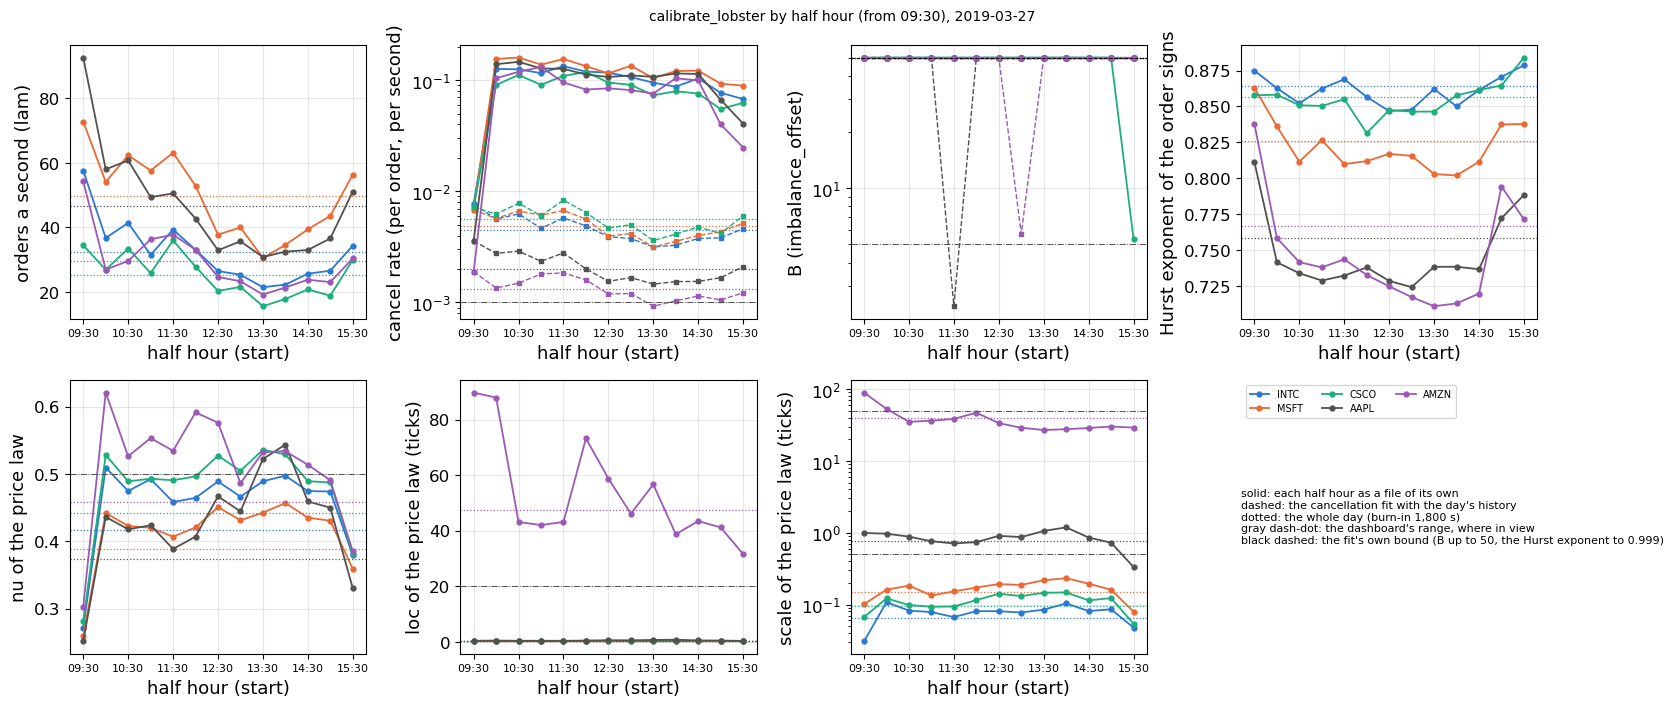

In [40]:
# 5.1 The calibration of each reported stock on the first day. Notebook 08's own figures first (no market data
# needed); then one run of cal_calibration on each stock (the slow part of this section: the cost is printed), and
# Table 1, the parameters: the whole day by calibrate_lobster, each half hour as a file of its own and with the day's
# history, what falls on the fit's bound and outside the dashboard's ranges (nothing is clipped), and Table 2, the
# cancel rate by window. Reads: cal_calibrated.


def cal_saved_text(path=cal_notebook_08):
    # what the code cells of a saved notebook printed, as saved ('' if the notebook is not there or has no output)
    try:
        notebook = json.loads(Path(path).read_text())
    except FileNotFoundError:
        return ''
    return '\n'.join(
        ''.join(output.get('text', ''))
        for cell in notebook['cells']
        if cell['cell_type'] == 'code'
        for output in cell.get('outputs', [])
        if output.get('output_type') == 'stream'
    )


def cal_heading(title, results, day=DAY):
    # a table's title with the day, the windows, the tape and the replace convention beside it (the fits read the day,
    # the facts the session), and the exploration label where it applies
    window = f'fits {clock(CAL0)} to {clock(cal_end)}, facts {SESSION_START} to {SESSION_END}'
    heading(title, results, day, how=cal_tape, window=window)


def cal_strip_lines(results, title, source, name, digits, width=7):
    # a line a stock: the whole day's value, then the half hours' (source: the half hours as files, or with history)
    lines = [f'{title:<30}{"day":>8}  ' + ' '.join(f'{label:>{width}}' for label in cal_labels)]
    for stock, detail in results.items():
        values = [fit[name] for fit in detail[source]]
        lines.append(
            f'{stock:<30}{fmt(detail["day fit"][name], digits):>8}  ' + strip_text(values, digits, width=width)
        )
    return '\n'.join(lines)


def cal_day_table(results):
    # a row a stock: calibrate_lobster's parameters for the day, and the counts they stand on
    columns = {name: (lambda detail, name=name: detail['day fit'][name]) for name in cal_params}
    columns |= {
        'orders': lambda detail: detail['day fit']['n_orders'],
        'executed in full': lambda detail: detail['day fit']['n_executed_in_full'],
        'cancels counted': lambda detail: detail['day fit']['n_cancels'],
        'cancels skipped (placed before the day)': lambda detail: detail['day fit']['n_cancels_skipped'],
    }
    return stock_table(results, columns)


def cal_cancel_table(results):
    # the cancel rate by window: the day, each half hour as a file, each half hour with the day's history
    rows = {}
    for stock, detail in results.items():
        day = detail['day fit']['cancel_rate']
        files = np.array([fit['cancel_rate'] for fit in detail['half hours as files']])
        history = np.array([fit['cancel_rate'] for fit in detail['half hours with history']])
        rows[stock] = {
            'the day': day,
            'files, median': np.median(files),
            'files, min': files.min(),
            'files, max': files.max(),
            'history, median': np.median(history),
            'history, min': history.min(),
            'history, max': history.max(),
            'files median / day': np.median(files) / day,
            'history median / day': np.median(history) / day,
        }
    return pd.DataFrame(rows).T


def cal_range_rows(results):
    # the day's and the half hours' values that sit on a bound of the fit, outside the dashboard's range or on its edge
    rows = []
    for stock, detail in results.items():
        for name in cal_params:
            low, high = cal_spec[name]
            day = detail['day fit'][name]
            files = [fit[name] for fit in detail['half hours as files']]
            history = [fit[name] for fit in detail['half hours with history'] if name in fit]
            outside = [sum(cal_outside(name, v) for v in values) for values in (files, history)]
            bound = [sum(cal_at_fit_bound(name, v) for v in values) for values in (files, history)]
            where = []
            if cal_outside(name, day):
                where.append('outside the range')
            elif day in (low, high):
                where.append('on the range\'s edge')
            if cal_at_fit_bound(name, day):
                where.append('at the fit\'s bound')
            if where or any(outside) or any(bound):
                rows.append(
                    {
                        'stock': stock,
                        'parameter': name,
                        'the day': day,
                        'dashboard range': f'{low:g} to {high:g}',
                        'where': ', '.join(where) or '-',
                        'files outside': f'{outside[0]} of {len(files)}',
                        'history outside': f'{outside[1]} of {len(history)}' if history else '-',
                        'files at the fit\'s bound': f'{bound[0]} of {len(files)}',
                        'history at the fit\'s bound': f'{bound[1]} of {len(history)}' if history else '-',
                    }
                )
    return pd.DataFrame(rows)


def cal_plot_parameters(results, day=DAY):
    # the half-hour strips of the seven fitted parameters, a line a stock (notebook 13's colors): the half hour as a
    # file solid; the cancellation parameters with the day's history dashed; the day dotted; the dashboard's range
    # (gray, dash-dot) where it is in view
    colors = [BLUE, ORANGE, AQUA, GRAY, '#9b59b6', '#c0392b', '#8c6d1f']
    panels = [
        ('lam', 'orders a second (lam)', False),
        ('cancel_rate', 'cancel rate (per order, per second)', True),
        ('imbalance_offset', 'B (imbalance_offset)', True),
        ('hurst', 'Hurst exponent of the order signs', False),
        ('nu', 'nu of the price law', False),
        ('loc', 'loc of the price law (ticks)', False),
        ('scale', 'scale of the price law (ticks)', True),
    ]
    fig, axes = plt.subplots(2, 4, figsize=(17, 7.2))
    x = np.arange(len(cal_blocks))
    for ax, (name, ylabel, log) in zip(axes.ravel(), panels, strict=False):
        for color, (stock, detail) in zip(colors, results.items(), strict=False):
            ax.plot(
                x,
                [fit[name] for fit in detail['half hours as files']],
                marker='o',
                markersize=3.5,
                linewidth=1.3,
                color=color,
                label=stock,
            )
            if name in ('cancel_rate', 'imbalance_offset'):
                ax.plot(
                    x,
                    [fit[name] for fit in detail['half hours with history']],
                    marker='s',
                    markersize=3,
                    linewidth=1.0,
                    linestyle='--',
                    color=color,
                )
            ax.axhline(detail['day fit'][name], color=color, linewidth=0.9, linestyle=':')
        if log:
            ax.set_yscale('log')
        low, high = ax.get_ylim()
        for edge in cal_spec[name]:
            if low <= edge <= high:
                ax.axhline(edge, color=GRAY, linewidth=0.7, linestyle='-.')
        if name in cal_fit_bounds:  # a bound of the fit itself, where a fit can sit on it
            for edge in cal_fit_bounds[name]:
                if low <= edge <= high:
                    ax.axhline(edge, color='black', linewidth=0.7, linestyle='--')
        ax.set_xticks(x[::2], cal_labels[::2], fontsize=8)
        ax.set_xlabel('half hour (start)')
        ax.set_ylabel(ylabel)
    axes[1, 3].axis('off')
    handles, labels = axes[0, 0].get_legend_handles_labels()  # the stocks' legend: in the empty panel, over no line
    axes[1, 3].legend(handles, labels, fontsize=7, ncols=3, loc='upper left')
    axes[1, 3].text(
        0.0,
        0.5,
        'solid: each half hour as a file of its own\ndashed: the cancellation fit with the day\'s history\n'
        'dotted: the whole day (burn-in 1,800 s)\ngray dash-dot: the dashboard\'s range, where in view\n'
        f'black dashed: the fit\'s own bound (B up to {CALIBRATION_B_MAX}, the Hurst exponent to '
        f'{cal_fit_bounds["hurst"][1]})',
        fontsize=8,
        va='center',
    )
    fig.suptitle(
        f'calibrate_lobster by half hour (from 09:30), {day_text(day)}'
        + (f'\n{EXPLORATION}' if set(results) & set(EXPLORED) else ''),
        fontsize=10,
    )
    fig.tight_layout()
    return fig


# --- notebook 08, quoted from its saved output (no market data needed)
# -------------------------------------------------
cal_quotes = (
    'From the files, every mean estimate\'s 95% interval covers the true value.',
    'Noisiest relative to its value: imbalance_offset (one run\'s estimate scatters by about 17%).',
    'imbalance_offset: true 0.2; without a burn-in 0.205 (0.1896 to 0.2205), with one 0.2049',
)
cal_printed = cal_saved_text()
if cal_printed:
    for cal_line in cal_quotes:
        assert cal_line in cal_printed, f'notebook 08 no longer prints: {cal_line}'
    print(
        'Notebook 08, as it printed (seeds 1 to 8; the file that starts on a full book, seeds 101 to 108), on the '
        'model\'s own output:'
    )
    for cal_line in cal_quotes:
        print(f'  {cal_line}')
else:
    print(f'{cal_notebook_08} has no saved output here: nothing is quoted from it.')

if need(DAY):
    cal_results = cal_calibrated(DAY)
    ran('The run so far, at section 5 (the first day): ')
    for cal_stock, cal_detail in cal_results.items():
        assert cal_detail['blocks'] == list(cal_blocks), f'{cal_stock}: the half hours are not the calibration\'s'
        for cal_source in ('half hours as files', 'half hours with history'):
            assert len(cal_detail[cal_source]) == len(cal_blocks), f'{cal_stock}: {cal_source} is not a strip'
        assert all(math.isfinite(cal_detail['day fit'][name]) for name in cal_params), (
            f'{cal_stock}: a fit is not finite'
        )
        assert 0 <= cal_detail['day fit']['imbalance_offset'] <= CALIBRATION_B_MAX + cal_at_bound, (
            f'{cal_stock}: B is outside the bounds of the fit'
        )
    if not SMOKE:
        assert list(cal_blocks) == list(range(N_BLOCKS)), 'the calibration is not the thirteen half hours from 09:30'

    cal_cost = pd.DataFrame({stock: detail['seconds'] for stock, detail in cal_results.items()}).T
    cal_cost['a simulated day'] = [
        np.mean([run['seconds'] for run in detail['sim']]) for detail in cal_results.values()
    ]
    cal_cost['peak memory (MB)'] = [detail['peak memory (MB)'] for detail in cal_results.values()]
    print(f'\nSeconds by part, one worker a stock (a simulated day: one of the {len(SIM_SEEDS)} seeds):')
    print(shown(cal_cost, {column: '.1f' for column in cal_cost.columns} | {'peak memory (MB)': ',.0f'}))

    cal_heading(
        f'Table 1. calibrate_lobster for the day ({clock(CAL0)} to {clock(cal_end)}, '
        f'burn-in {CALIBRATION_BURN:,.0f} s)',
        cal_results,
    )
    print(
        shown(
            cal_day_table(cal_results),
            {
                'lam': '.2f',
                'cancel_rate': '.5f',
                'imbalance_offset': '.2f',
                'hurst': '.3f',
                'nu': '.3f',
                'loc': '.2f',
                'scale': '.3f',
                'lot_size': 'd',
            },
        )
    )
    print(
        f'The model is run at a lot of {CALIBRATION_LOT} shares and a tick a cent; the fit\'s own modal order size is '
        'in the lot_size column.'
    )

    print(
        '\nEach half hour as a file of its own (burn-in 0, the half hour\'s own rows), from 09:30; the day beside it:'
    )
    for cal_title, cal_source, cal_name, cal_digits in (
        ('lam (orders a second)', 'half hours as files', 'lam', 2),
        ('cancel_rate, a file each', 'half hours as files', 'cancel_rate', 4),
        ('imbalance_offset, a file each', 'half hours as files', 'imbalance_offset', 2),
        ('hurst', 'half hours as files', 'hurst', 3),
        ('nu', 'half hours as files', 'nu', 2),
        ('loc (ticks)', 'half hours as files', 'loc', 2),
        ('scale (ticks)', 'half hours as files', 'scale', 2),
    ):
        print('\n' + cal_strip_lines(cal_results, cal_title, cal_source, cal_name, cal_digits))
    print(
        '\nThe cancellation fit of each half hour with the day\'s history replayed from the open, counted from its '
        'start:'
    )
    for cal_title, cal_name, cal_digits in (
        ('cancel_rate, with history', 'cancel_rate', 4),
        ('imbalance_offset, with history', 'imbalance_offset', 2),
    ):
        print('\n' + cal_strip_lines(cal_results, cal_title, 'half hours with history', cal_name, cal_digits))

    cal_heading('Table 2. The cancel rate by window (per order, per second)', cal_results)
    print(
        shown(
            cal_cancel_table(cal_results),
            {column: '.4f' for column in cal_cancel_table(cal_results).columns if '/' not in column}
            | {'files median / day': '.1f', 'history median / day': '.1f'},
        )
    )

    cal_heading(
        f'Table 3. What sits on a bound of the fit (B up to {CALIBRATION_B_MAX}, the Hurst exponent 0.5 to '
        f'{cal_fit_bounds["hurst"][1]}) or outside the dashboard\'s range or on its edge; nothing is clipped',
        cal_results,
    )
    cal_ranges = cal_range_rows(cal_results)
    if len(cal_ranges):
        print(shown(cal_ranges, {'the day': '.4g'}, index=False))
    else:
        print(
            'Every value of the day and of every half hour is inside the dashboard\'s ranges and off the fit\'s bounds.'
        )
    print('No fitted set is offered as a preset.')

    cal_fig = cal_plot_parameters(cal_results)
    plt.show()

**Table 1, the day's parameters.** `calibrate_lobster` on 09:30:00 to 16:00:00 with a burn-in of 1,800 s gives, for INTC, MSFT, CSCO, AAPL and AMZN: `lam` 32.45, 49.64, 25.33, 46.68 and 29.51 orders a second, the day's count of orders over its span; `cancel_rate` 0.00445, 0.00490, 0.00560, 0.00199 and 0.00131, a rate per order per second that Table 2 qualifies below; `imbalance_offset` 50.00 on all five, the fit's bound and not an estimate (Table 4); `hurst` 0.864, 0.826, 0.856, 0.758 and 0.767, the memory of the order signs, fitted to their autocorrelation at the first lags; `nu` 0.417, 0.389, 0.442, 0.374 and 0.459, `loc` 0.35, 0.27, 0.34, 0.45 and 47.63 ticks, and `scale` 0.064, 0.148, 0.094, 0.759 and 39.230 ticks, the shape of the law of an order's price offset from the same-side quote; and `lot_size` 100, 100, 100, 100 and 20 shares, the modal order size. They stand on 759,317, 1,161,596, 592,635, 1,092,406 and 690,600 orders, of which 10,682, 27,352, 10,849, 35,971 and 16,898 executed in full, and on 628,058, 969,447, 503,182, 853,567 and 556,860 cancels counted, with 6, 19, 6, 48 and 40 cancels skipped because the order was placed before the day. Each is what one day's order flow gave one estimator, on average over the day, and none says anything about the stock. The dashboard could not take, as Table 3 prints: `imbalance_offset` (its range is 0 to 5) and `nu` (0.5 to 10) on all five, `scale` (0.5 to 50) on INTC, MSFT and CSCO, and `loc` (-10 to 20) on AMZN. `lot_size` 100 is the dashboard's edge (1 to 100) on the other four. Table 1's "orders" and Table 5's "adds" are taken up where Table 5 is.

**The half-hour strips.** Each parameter is fitted again on each of the 13 half hours from 09:30 as a file of its own (burn-in 0), and the strips print the 13 values with the day's beside them. They are 13 values of one day. The half hours are not exchangeable, so no range of a strip is an interval, and no spread across stocks is a standard error. `lam` runs from 21.46 to 57.64 on INTC, 30.55 to 72.85 on MSFT, 15.57 to 35.99 on CSCO, 30.82 to 92.69 on AAPL and 19.20 to 54.28 on AMZN. The first half hour, which holds the opening burst, is the highest of the 13 on INTC (57.64), MSFT (72.85), AAPL (92.69) and AMZN (54.28) and not on CSCO (34.48 at 09:30 against 35.99 at 11:30). It is the outlier of other strips as well: its `nu` is the lowest of the 13 on every stock (0.27, 0.26, 0.28, 0.25 and 0.30, against 0.33 to 0.62 in the other twelve half hours of the five), and its `cancel_rate` as a file is the lowest (0.0077 on INTC against 0.0677 to 0.1338 in the other twelve, 0.0019 on AMZN against 0.0248 to 0.1316). It is also the half hour in which the file and the history strips agree (0.0077 and 0.0077 on INTC), the one where almost nothing rests from before the open (Table 1 counts 6 to 48 cancels of orders placed before the day). On AMZN `loc` runs from 31.64 to 89.72 ticks and `scale` from 26.92 to 89.16 across the half hours, and on AAPL `loc` from 0.36 to 0.79 and `scale` from 0.33 to 1.19. `imbalance_offset` as a file is 50.00 in every half hour on every stock except CSCO's 15:30 (5.36), and with history 50.00 except AAPL's 12:00 (2.34) and AMZN's 13:30 (5.69).

**Table 2, the cancel rate by window** (per order per second). For INTC the day's `cancel_rate` is 0.0044, the median half hour as a file 0.1067 (range 0.0077 to 0.1338) and the median half hour with the day's history 0.0046 (0.0032 to 0.0077), which are 24.0 and 1.0 times the day's. MSFT: 0.0049, 0.1220 (0.0068 to 0.1599) and 0.0052 (0.0032 to 0.0068), 24.9 and 1.1 times. CSCO: 0.0056, 0.0907 (0.0072 to 0.1186) and 0.0060 (0.0036 to 0.0083), 16.2 and 1.1 times. AAPL: 0.0020, 0.1126 (0.0036 to 0.1463) and 0.0020 (0.0015 to 0.0036), 56.5 and 1.0 times. AMZN: 0.0013, 0.0845 (0.0019 to 0.1316) and 0.0012 (0.0009 to 0.0019), 64.5 and 0.9 times. The first ratio is `cancel_ratio`, the estimator's window effect, which is in no verdict. A cancel rate is not a property of a stock: the same day gives these values depending on the window and on whether the history is replayed, a half hour as a file reading 16.2 to 64.5 times the day's and a half hour with the day's history reading 0.9 to 1.1 times it. No stock's cancel rate is set against another's.

**Table 3, what sits on a bound of the fit or outside the dashboard's ranges.** The day's `imbalance_offset` is 50 on every stock, the fit's bound, against the dashboard's cap of 5. As a file it is outside the dashboard's range in 13 of 13 half hours on all five and on the bound in 13 of 13 on INTC, MSFT, AAPL and AMZN and 12 of 13 on CSCO; with the day's history it is outside the range in 13 of 13 on INTC, MSFT, CSCO and AMZN and 12 of 13 on AAPL, and on the bound in 13 of 13 on INTC, MSFT and CSCO and 12 of 13 on AAPL and AMZN. The day's `nu` is outside the dashboard's range of 0.5 to 10 on every stock (0.4173, 0.3893, 0.442, 0.3741 and 0.4592), and as a file in 12, 13, 8, 11 and 4 of 13 half hours, never on a bound of the fit. The day's `scale` is outside its range of 0.5 to 50 on INTC, MSFT and CSCO (0.06415, 0.1483 and 0.09401) in 13 of 13 half hours, and inside it on AAPL (0.759, outside in 1 of 13 files) and AMZN (39.23, 2 of 13). AMZN's `loc`, 47.63 ticks, is outside its range of -10 to 20 in 13 of 13 half hours. AMZN's `cancel_rate`, 0.00131, is inside its range of 0.001 to 5, and the half hours with history are outside it in 1 of 13. `lot_size` is 100, on the dashboard's edge (1 to 100), on INTC, MSFT, CSCO and AAPL. No Hurst value, of the day or of a half hour, is listed: none sits on the fit's bound or outside the dashboard's range. Nothing was clipped. A fit that the dashboard refuses cannot be entered in it as it is, and no fitted set is offered as a preset.

INTC: the likelihood profile of B is -239.8984 at the fitted B (0 is the best) and -239.8984 at the grid's best within the bound: the fit is at least as good as every grid point.
MSFT: the likelihood profile of B is -1444.2013 at the fitted B (0 is the best) and -1444.2012 at the grid's best within the bound: the fit is at least as good as every grid point.
CSCO: the likelihood profile of B is -284.0674 at the fitted B (0 is the best) and -284.0674 at the grid's best within the bound: the fit is at least as good as every grid point.
AAPL: the likelihood profile of B is -30.0510 at the fitted B (0 is the best) and -30.0510 at the grid's best within the bound: the fit is at least as good as every grid point.
AMZN: the likelihood profile of B is -31.2235 at the fitted B (0 is the best) and -31.2235 at the grid's best within the bound: the fit is at least as good as every grid point.

Table 4. B's profile log-likelihood on the whole day (b_max 50), less its best (the grid's or the fit's): 

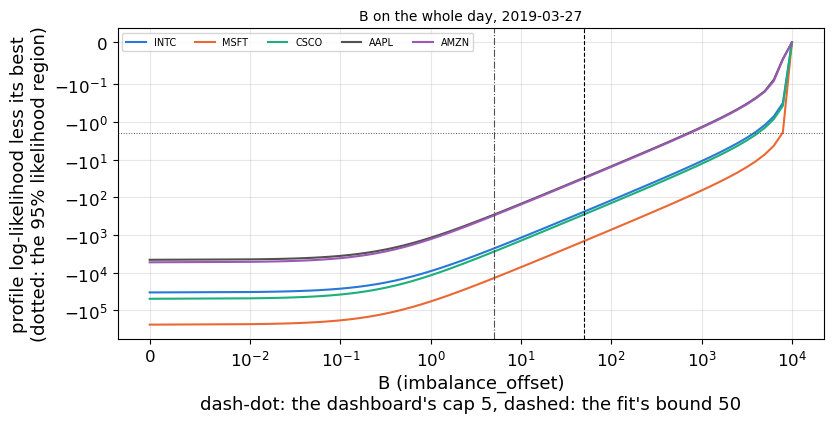


Table 5. Replaces dropped from both counts, a sensitivity of the fit: 2019-03-27, fits 09:30:00 to 16:00:00, facts
09:40:00 to 15:50:00, fits: displayed rows only, a replace as the frames have it (a deletion and a new order); facts:
tape signed, a replace as two.
What the frames hold that the sensitivities touch (rows in the calibration's day):
           adds replace pairs replace pairs over adds partial cancels paired reductions hidden executions (not read)
INTC    748,635        89,623                   12.0%           3,541                27                        2,141
MSFT  1,134,244       155,439                   13.7%           2,931               211                        4,719
CSCO    581,786        78,330                   13.5%           3,224                18                        3,111
AAPL  1,056,435       136,647                   12.9%           2,817                 7                        6,833
AMZN    673,701        97,623                   14.5%              

In [41]:
# 5.2 Why the fits come out as they do. Table 4: B's profile likelihood (b_max 50) and the two shares that say whether
# a cancellation depends on the own side's share of the resting orders; Table 5: the dropped-replace sensitivity of
# the day's fit (and of each half hour as a file), with the rows the frames hold that the calibration does not use;
# Table 6: how long orders last, which is why the cancel rate depends on the window. Reads: cal_results (kept by the
# cell before).


def cal_profile_table(results):
    # a row a stock: the profile log-likelihood of B less its best on the grid, at B of each cal_b_points and at the
    # grid's end; the 95% likelihood region on the grid; the two shares
    rows = {}
    for stock, detail in results.items():
        profile = detail['profile']
        grid, value = np.array(profile['B']), np.array(profile['log-likelihood'])
        row = {f'B = {b:g}': float(value[np.argmin(abs(grid - b))]) for b in (*cal_b_points, grid[-1])}
        row['95% region from B'], row['to B'] = profile['region']
        row['share at a cancel'], row['share of exposure'] = profile['share at a cancel'], profile['share of exposure']
        row['cancels'] = profile['n cancels']
        rows[stock] = row
    return pd.DataFrame(rows).T


def cal_plot_profile(results, day=DAY):
    # the profile log-likelihood of B on the grid, a line a stock, both axes symmetric-logarithmic (B = 0 and the
    # likelihood's best are on them); the dashboard's cap and the fit's bound marked, and where the 95% region begins
    colors = [BLUE, ORANGE, AQUA, GRAY, '#9b59b6', '#c0392b', '#8c6d1f']
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    for color, (stock, detail) in zip(colors, results.items(), strict=False):
        ax.plot(detail['profile']['B'], detail['profile']['log-likelihood'], color=color, linewidth=1.5, label=stock)
    ax.set_xscale('symlog', linthresh=float(cal_b_grid[1]))
    ax.set_yscale('symlog', linthresh=0.1)
    ax.axhline(-cal_region, color=GRAY, linewidth=0.7, linestyle=':')
    ax.axvline(cal_spec['imbalance_offset'][1], color=GRAY, linewidth=0.8, linestyle='-.')
    ax.axvline(CALIBRATION_B_MAX, color='black', linewidth=0.8, linestyle='--')
    ax.set_xlabel(
        f'B (imbalance_offset)\ndash-dot: the dashboard\'s cap {cal_spec["imbalance_offset"][1]:g}, '
        f'dashed: the fit\'s bound {CALIBRATION_B_MAX}'
    )
    ax.set_ylabel('profile log-likelihood less its best\n(dotted: the 95% likelihood region)')
    ax.set_title(
        f'B on the whole day, {day_text(day)}' + (f'\n{EXPLORATION}' if set(results) & set(EXPLORED) else ''),
        fontsize=10,
    )
    ax.legend(fontsize=7, ncols=min(len(results), 5))
    fig.tight_layout()
    return fig


def cal_rows_table(results):
    # the rows of the frames the sensitivities touch or the calibration does not read
    rows = {}
    for stock, detail in results.items():
        counts = detail['rows']
        rows[stock] = {
            'adds': counts['adds'],
            'replace pairs': counts['replace rows'] // 2,
            'replace pairs over adds': counts['replace rows'] / 2 / counts['adds'],
            'partial cancels': counts['partial cancels'],
            'paired reductions': counts['paired reductions'],
            'hidden executions (not read)': counts['hidden executions (not read)'],
        }
    return pd.DataFrame(rows).T


def cal_dropped_table(results, names=('lam', 'cancel_rate', 'hurst', 'nu', 'loc', 'scale')):
    # a row a stock and parameter: the day's value, with the replaces dropped, the shift in percent of the day's value,
    # and the shift as a share of the range of the half hours as files (and the median half hour's shift)
    rows = {}
    for stock, detail in results.items():
        base, dropped = detail['day fit'], detail['replaces dropped']['day']
        files, dropped_files = detail['half hours as files'], detail['replaces dropped']['half hours']
        for name in names:
            before = np.array([fit[name] for fit in files])
            after = np.array([fit[name] for fit in dropped_files])
            span = before.max() - before.min()
            rows[stock, name] = {
                'the day': base[name],
                'replaces dropped': dropped[name],
                'shift, % of the day': 100 * (dropped[name] / base[name] - 1),
                'range of the half hours': span,
                'day shift over range': abs(dropped[name] - base[name]) / span if span > 0 else math.nan,
                'median half-hour shift over range': abs(np.median(after - before)) / span if span > 0 else math.nan,
            }
    return pd.DataFrame(rows).T


def cal_ages_table(results):
    # how long the day's orders last, by stock
    rows = {}
    for stock, detail in results.items():
        ages = detail['ages']
        rows[stock] = {'orders placed': ages['orders placed']}
        for mark in cal_age_marks:
            rows[stock][f'deleted within {mark:g} s'] = ages['deleted within'][mark]
        rows[stock] |= {
            'median age at deletion (s)': ages['median age at deletion'],
            'still resting at the end': ages['resting at the end'],
            'order-seconds beyond a half hour': ages['order-seconds beyond a half hour'],
        }
    return pd.DataFrame(rows).T


if need(DAY):
    cal_results = cal_calibrated(DAY)
    for cal_stock, cal_detail in cal_results.items():
        # The fit's own log-likelihood (computed exactly, not read off the grid) against the grid's best within the
        # bound: a flag and not a stop, because it depends on the optimizer and a stock-day that tripped it should not
        # take the run's other cells with it. A stock-day where it is False is not judged on the calibration
        # (judge_calibration reads it through cal_summary).
        cal_profile_one = cal_detail['profile']
        print(
            f'{cal_stock}: the likelihood profile of B is {cal_profile_one["log-likelihood at the fit"]:.4f} at the '
            f'fitted B (0 is the best) and {cal_profile_one["best on the grid within the bound"]:.4f} at the grid\'s '
            'best within the bound: '
            + (
                'the fit is at least as good as every grid point.'
                if cal_profile_one['agrees']
                else 'DISAGREE: the calibration is not judged for this stock-day.'
            )
        )
        assert 0 < cal_profile_one['share at a cancel'] <= 1 and 0 < cal_profile_one['share of exposure'] <= 1, (
            f'{cal_stock}: a share of resting orders is outside (0, 1]'
        )
        assert cal_detail['rows']['replace rows'] % 2 == 0, f'{cal_stock}: the replace rows are not pairs'
        assert cal_detail['ages']['orders placed'] == cal_detail['rows']['adds'], (
            f'{cal_stock}: an add is not a placed order'
        )
        assert cal_detail['ages']['deletions of placed orders'] <= cal_detail['rows']['deletions'], (
            f'{cal_stock}: more placed orders were deleted than there are deletions'
        )

    cal_heading(
        f'Table 4. B\'s profile log-likelihood on the whole day (b_max {CALIBRATION_B_MAX}), less its best (the '
        'grid\'s or the fit\'s)',
        cal_results,
    )
    print(
        shown(
            cal_profile_table(cal_results),
            {column: '.1f' for column in cal_profile_table(cal_results).columns if column.startswith('B = ')}
            | {
                '95% region from B': '.2f',
                'to B': ',.0f',
                'share at a cancel': '.3f',
                'share of exposure': '.3f',
                'cancels': ',.0f',
            },
        )
    )
    print(
        'share at a cancel: the mean own-side share of the resting orders at each cancellation; share of exposure: '
        'the same share weighted by the exposure the cancel rate divides by. The model cancels an order faster when '
        'its own side holds more of the book (B small); the two shares are equal where it does not.'
    )
    cal_fig_profile = cal_plot_profile(cal_results)
    plt.show()

    cal_heading('Table 5. Replaces dropped from both counts, a sensitivity of the fit', cal_results)
    print('What the frames hold that the sensitivities touch (rows in the calibration\'s day):')
    print(
        shown(
            cal_rows_table(cal_results),
            {
                'adds': ',.0f',
                'replace pairs': ',.0f',
                'replace pairs over adds': '.1%',
                'partial cancels': ',.0f',
                'paired reductions': ',.0f',
                'hidden executions (not read)': ',.0f',
            },
        )
    )
    cal_table = cal_dropped_table(cal_results)
    print(
        '\nThe day and each half hour as a file, refitted with both rows of every replace made no-ops (neither is an '
        'arrival or a cancellation; the order goes on under its first reference):'
    )
    print(
        shown(
            cal_table,
            {
                'the day': '.5g',
                'replaces dropped': '.5g',
                'shift, % of the day': '+.1f',
                'range of the half hours': '.4g',
                'day shift over range': '.2f',
                'median half-hour shift over range': '.2f',
            },
        )
    )
    print(
        'Not rerun here: the group column for the aggressive orders, the paired reductions and the partial cancels '
        f'moved no parameter by more than 0.4 percent in the two exploration stocks ({EXPLORATION}); the counts above '
        'are what they act on.'
    )

    cal_heading('Table 6. How long the day\'s orders last (orders placed in the day)', cal_results)
    print(
        shown(
            cal_ages_table(cal_results),
            {f'deleted within {mark:g} s': '.1%' for mark in cal_age_marks}
            | {
                'orders placed': ',.0f',
                'median age at deletion (s)': '.2f',
                'still resting at the end': '.1%',
                'order-seconds beyond a half hour': '.1%',
            },
        )
    )
    print(
        'A half hour as a file knows only the orders placed in it and its exposure is theirs; the replay of the day '
        'divides by the exposure of every order placed so far, and the order-seconds beyond a half hour are the '
        'share of it that a half hour as a file never sees.'
    )

**Table 4, B's profile.** The profile log-likelihood of B on the whole day (`b_max` 50), less its best on the grid, reads at B = 5 (the dashboard's cap) -2278.3 on INTC, -13922.7 on MSFT, -2764.8 on CSCO, -288.2 on AAPL and -303.6 on AMZN; at B = 50 (the fit's bound) -239.9, -1444.2, -284.1, -30.1 and -31.2; and 0.0 at B = 10,000, the grid's end, on all five. The data rise toward larger B all the way to the end of the grid, so B at 50 is the bound and not an estimate, and the fit's own log-likelihood at the fitted B agrees with the grid's best within the bound on every stock (the lines printed above the table). The 95% likelihood region begins at B = 3981.07 on INTC, 7943.28 on MSFT, 5011.87 on CSCO and 794.33 on AAPL and AMZN, and runs to 10,000. The region's lower end is what the data say B is at least, on this grid, and the table says nothing of how much larger it is. Notebook 08 recovered B on the model's own output, so the estimator is not what puts it on the bound: with a true B of 0.2 it gave, from a file that starts on a full book, 0.205 (0.1896 to 0.2205) without a burn-in and 0.2049 with one, and B was the parameter whose estimate scattered most relative to its value, by about 17%. That is one true B, a small one. It shows the estimator places a small B and says nothing of a real day's. A large B means a cancellation does not depend on the own side's share of the resting orders, and the two shares beside the profile are equal where it does not: the mean own-side share at a cancel and the exposure-weighted share are 0.501 and 0.520 on INTC, 0.503 and 0.578 on MSFT, 0.503 and 0.531 on CSCO, 0.500 and 0.501 on AAPL and 0.498 and 0.501 on AMZN. They are within 0.003 of each other on AAPL and AMZN. On INTC, MSFT and CSCO they are not equal, and on all five the share at a cancel is below the share of exposure. The model's form, a hazard that rises with the own side's share when B is finite, would put the share at a cancel above the share of exposure, so the data lean the other way from the model's dependence, and the profile's rise toward larger B reflects that. What the table does not show is why the two shares differ on those three stocks.

**Table 5, the dropped-replace sensitivity.** The frames hold 89,623 replace pairs on INTC (12.0% of its adds), 155,439 on MSFT (13.7%), 78,330 on CSCO (13.5%), 136,647 on AAPL (12.9%) and 97,623 on AMZN (14.5%), and the rows that the calibration does not use or the sensitivities do not touch are 3,541, 2,931, 3,224, 2,817 and 73 partial cancels, 27, 211, 18, 7 and 0 paired reductions, and 2,141, 4,719, 3,111, 6,833 and 10,871 hidden executions. The calibration reads a replace as a deletion and a new order. With both rows of every replace made no-ops, `lam` moves by -11.8, -13.4, -13.2, -12.5 and -14.1 percent of the day's value and `cancel_rate` by -12.4, -14.3, -13.8, -13.8 and -15.6, which are 0.09 to 0.16 of the range of the half hours as files for `lam` and 0.00 to 0.01 for `cancel_rate` (the day's shift over the range), and 0.08 to 0.16 and 0.08 to 0.10 for the median half hour's shift. `nu` moves by +7.7, +23.8, +11.2, +34.5 and +38.9 percent, which is 0.14, 0.47, 0.19, 0.44 and 0.56 of the half hours' range for the day and 0.24, 0.74, 0.31, 0.93 and 1.62 of it for the median half hour. `scale` moves by +16.9, +21.9, +31.0, +6.6 and -3.6 percent, and the Hurst exponent by -2.5, -1.2, -2.4, +0.5 and -0.1 percent (the day's shift is 0.67 of the range on INTC and 0.17, 0.39, 0.05 and 0.01 on the others); `loc` moves by +0.4, -1.7, -1.4, +6.0 and +3.9 percent. As a share of the half hours' range the day's shift is largest for `nu` on MSFT (0.47), AAPL (0.44) and AMZN (0.56) and for the Hurst exponent on INTC (0.67) and CSCO (0.39). For no parameter on any stock does the day's shift exceed the range of the half hours (the largest share is 0.67, INTC's Hurst exponent), and the median half hour's shift exceeds it once, for AMZN's `nu` (1.62), with AAPL's `nu` (0.93) and INTC's Hurst exponent (0.71) the next. So a convention for replaces moves the day's `lam` and `cancel_rate` by 11.8 to 15.6 percent of their value and by less than the half hours move among themselves, and it moves the median half hour's `nu` by 0.93 and 1.62 of the half hours' range on AAPL and AMZN. The group column, the paired reductions and the partial cancels moved no parameter by more than 0.4 percent in the two exploration stocks (exploration, as the cell's note prints it), so they are not rerun here; the counts above are what they act on. Table 1's "orders" exceed Table 5's "adds" by the orders that executed in full, as the check in the session cell requires: 759,317 less 748,635 is 10,682, Table 1's "executed in full" for INTC, and the differences of the printed figures are 27,352, 10,849 and 35,971 for MSFT, CSCO and AAPL, equal to theirs. On AMZN the difference is 16,899 (690,600 less 673,701) and Table 1 prints 16,898, one apart, which the code's two definitions of "executed in full" would explain (Table 1's is the fit's count of aggressive orders whose price the data do not show; the check's counts the orders with no price in the cell's own table); that is read from the code and not checked on AMZN's data. The identity is exact on the four and is not stated as exact for AMZN's printed figures.

**Table 6, how long the day's orders last.** Of the orders placed in the day, the share deleted within 0.001 s of their placing is 27.6% (INTC), 21.9% (MSFT), 28.5% (CSCO), 9.5% (AAPL) and 15.1% (AMZN); within 1 s 66.1%, 68.2%, 61.4%, 63.1% and 65.1%; within 10 s 88.2%, 91.2%, 86.1%, 91.4% and 90.0%. The median age at deletion is 0.10, 0.16, 0.24, 0.47 and 0.30 s, the share of the day's placed orders still resting at the end is 1.5%, 1.5%, 1.3%, 3.4% and 5.3%, and the share of the day's order-seconds that is age beyond a half hour is 87.8%, 88.3%, 85.6%, 90.0% and 90.0%. This is why the cancel rate of Table 2 depends on the window. The exposure it divides by is mostly orders older than a half hour, which a half hour as a file does not know, since it knows only the orders placed in it, and a mixture of orders that leave within a millisecond and orders that rest for hours has no single hazard. Table 6 shows the mixture. It does not show that a model with more than one kind of order would fit, which would be another model.


Table 7. INTC: the fitted model beside the day, session 09:40:00 to 15:50:00, a unit of one second, depth in lots of 100
shares on both sides; the fit's modal order size is 100 shares: 2019-03-27, fits 09:30:00 to 16:00:00, facts 09:40:00 to
15:50:00, fits: displayed rows only, a replace as the frames have it (a deletion and a new order); facts: tape signed, a
replace as two.
the day's fit (calibrate_lobster, burn-in 1,800 s): lam 32.45, cancel_rate 0.004445, imbalance_offset 50, hurst 0.864, nu 0.4173, loc 0.3472, scale 0.06415, lot_size 100; initial mid 5,368 ticks, warm-up 1,428 s, seeds 1 to 8
                               real session real half hours, min to max model, mean of seeds model, seeds min to max model against real real half hours inside the model's band
spread mean (ticks)                    1.00                1.00 to 1.00                 1.00            1.00 to 1.00              x1.00                                 2 of 13
share at one tick                     99.8

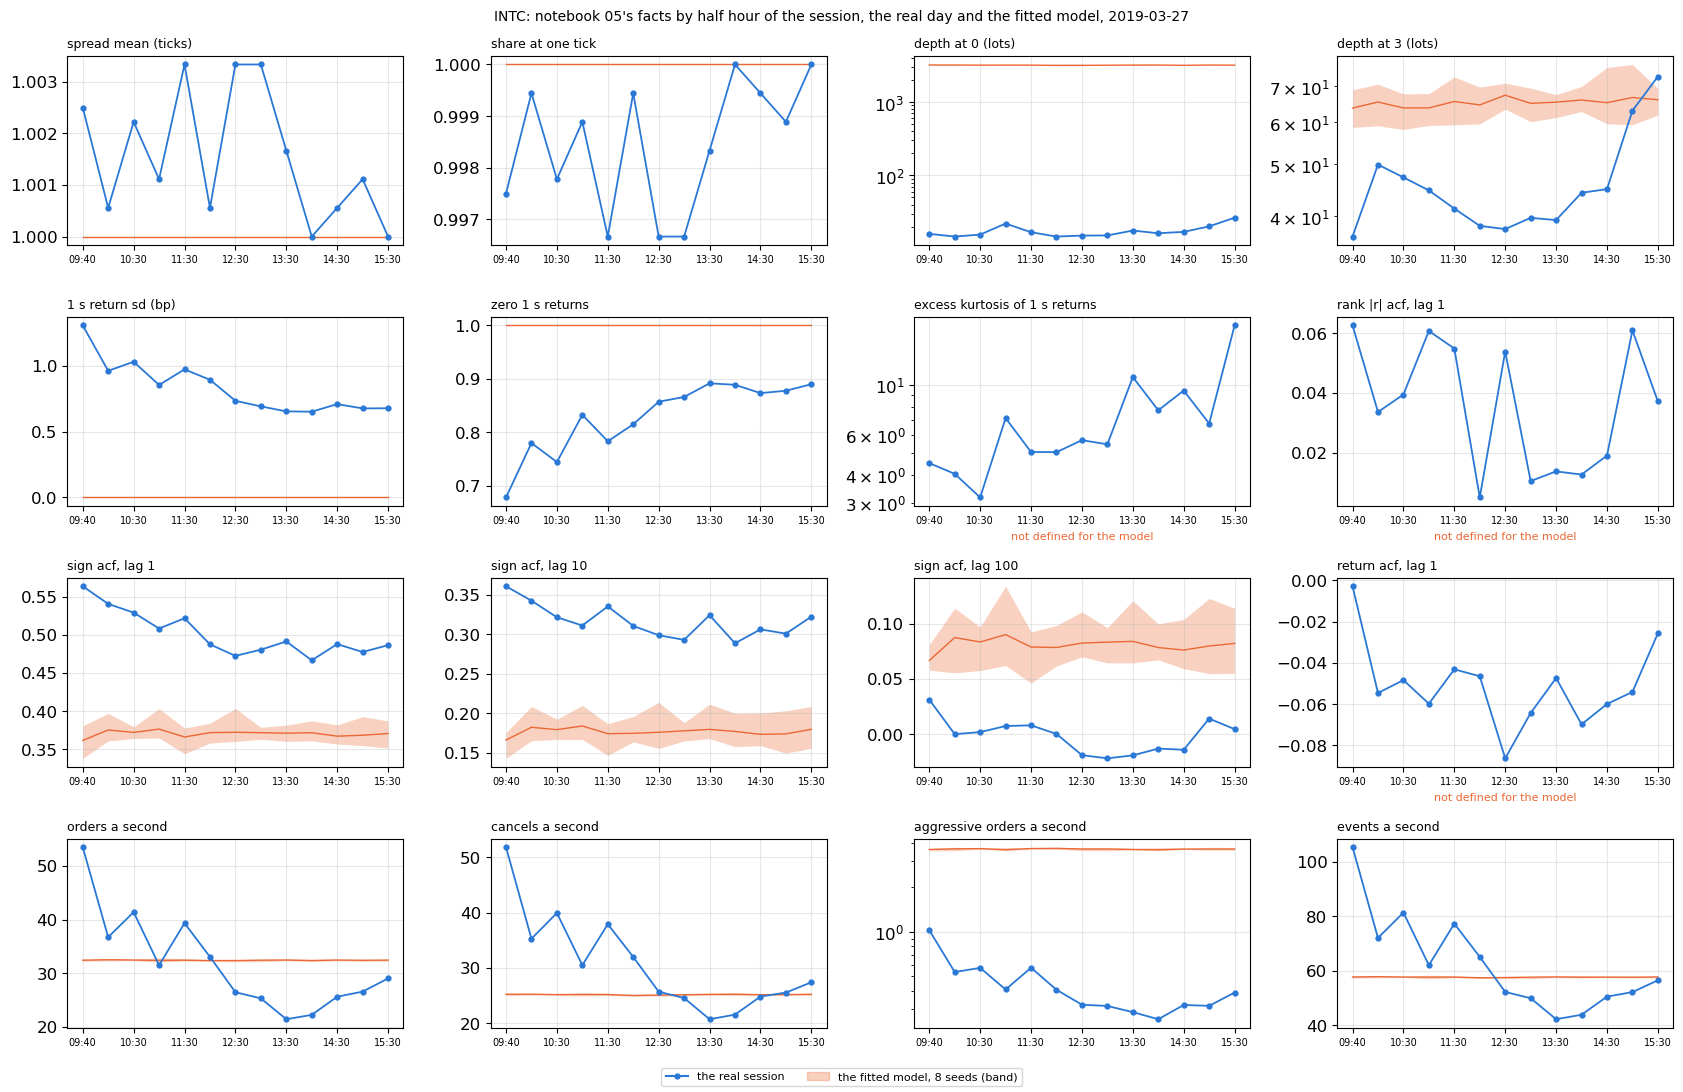

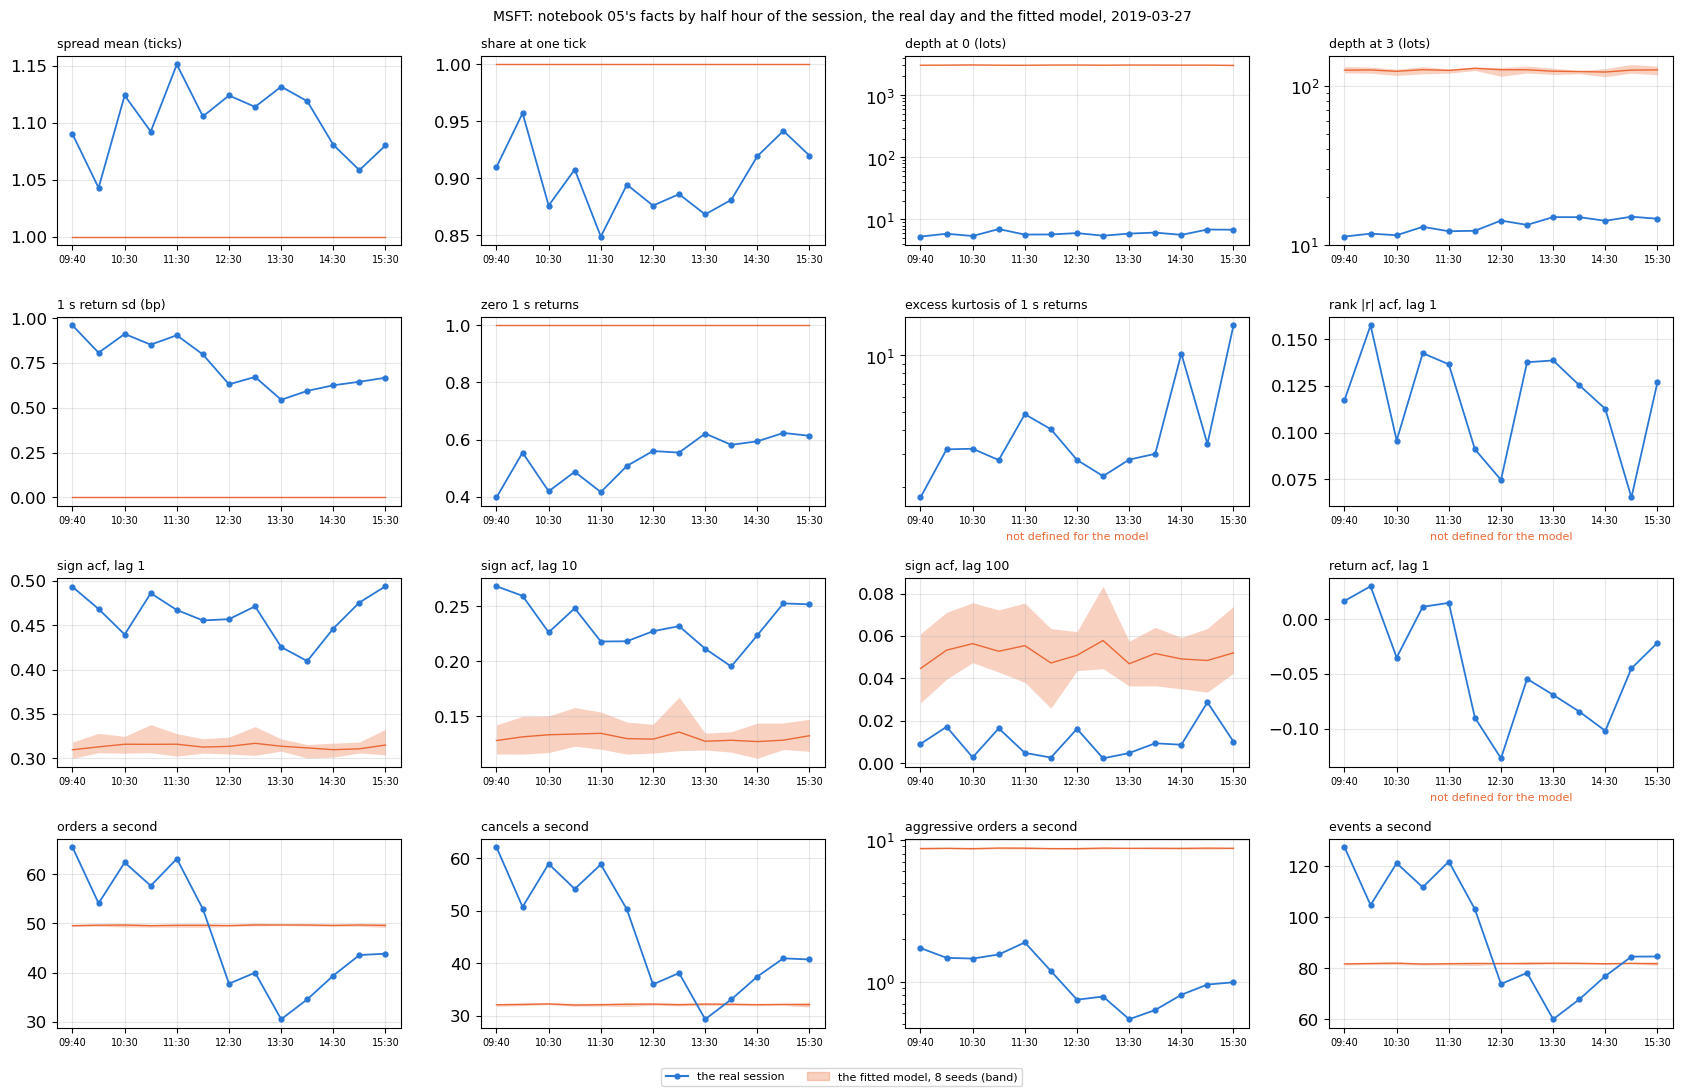

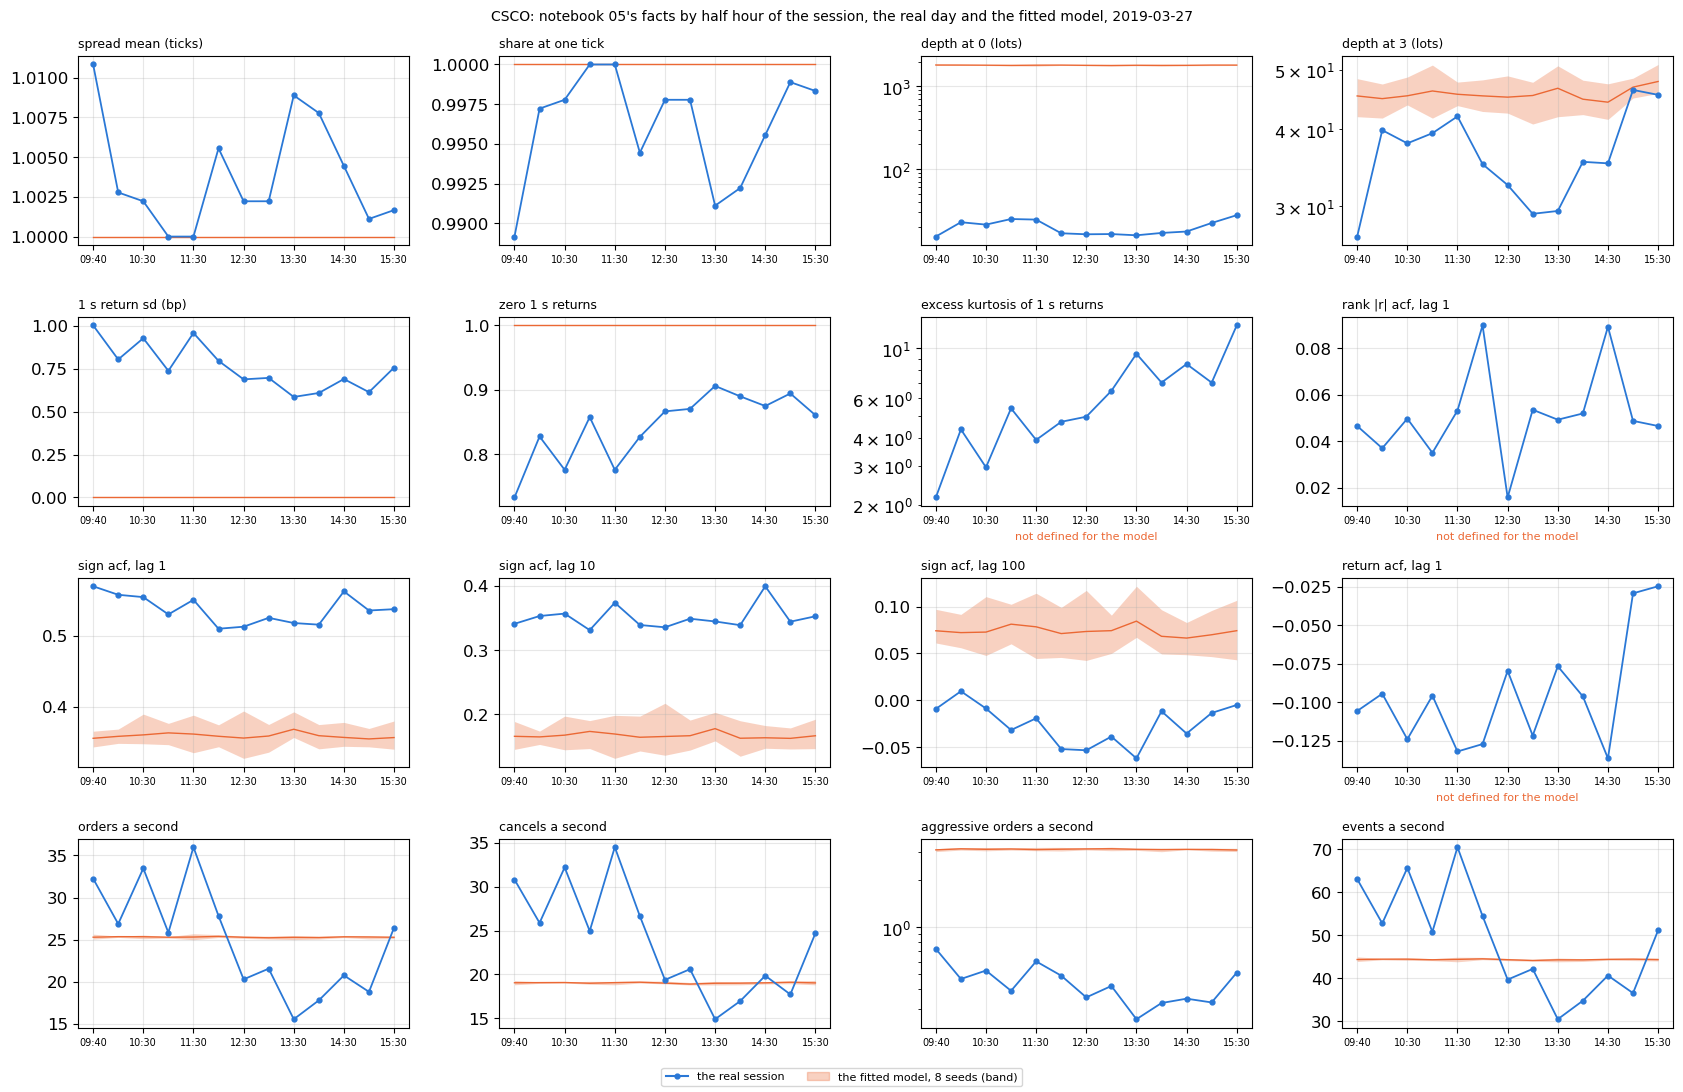

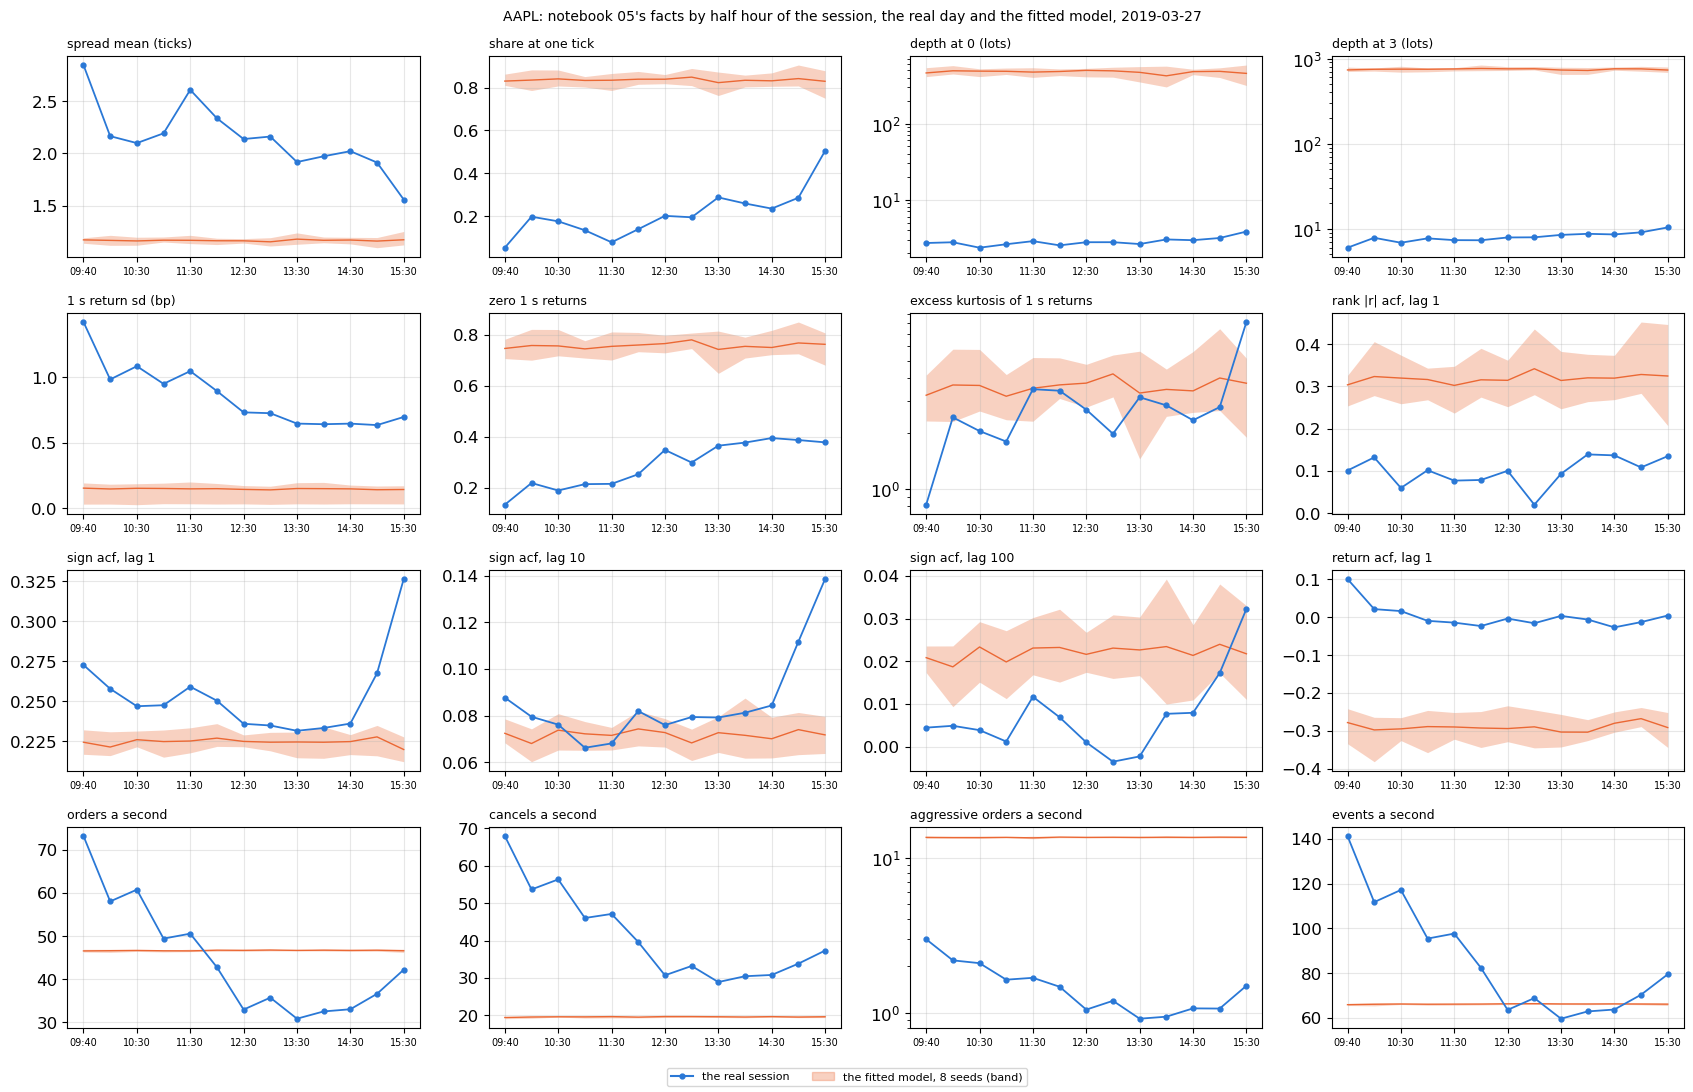

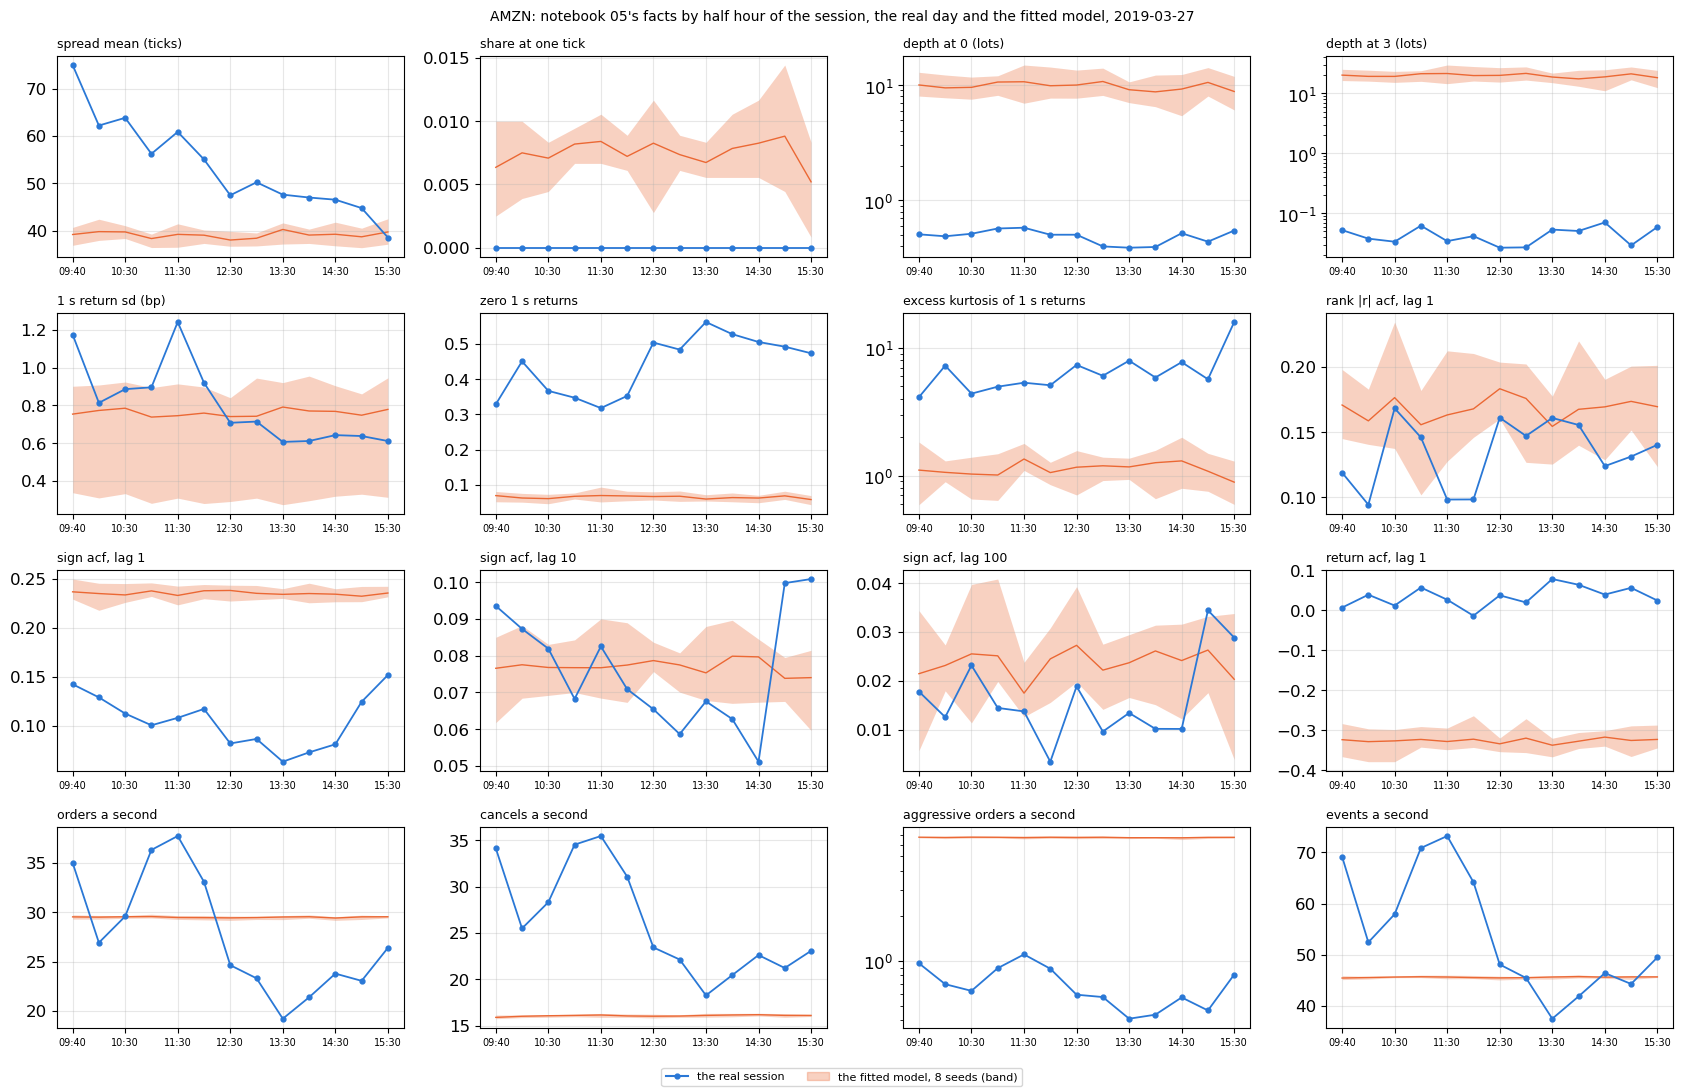

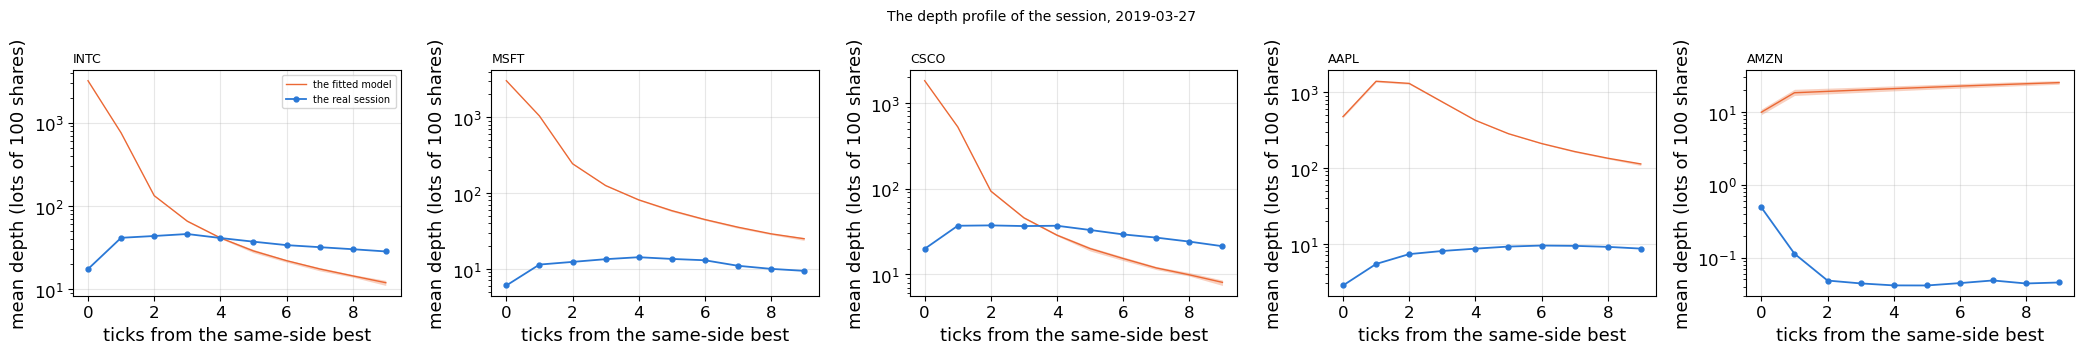


Table 9. The fitted price law against the offsets: where the model's aggressive orders come from: 2019-03-27, fits
09:30:00 to 16:00:00, facts 09:40:00 to 15:50:00, fits: displayed rows only, a replace as the frames have it (a deletion
and a new order); facts: tape signed, a replace as two.
         nu    loc   scale median spread (ticks) offset of -1 or less, data offset of -1 or less, fitted law trade on arrival, data trade on arrival, fitted model
INTC  0.417   0.35   0.064                   1.0                       2.3%                            11.2%                   1.4%                          11.2%
MSFT  0.389   0.27   0.148                   1.0                       5.4%                            17.6%                   2.3%                          17.6%
CSCO  0.442   0.34   0.094                   1.0                       2.8%                            12.4%                   1.8%                          12.4%
AAPL  0.374   0.45   0.759                   2.0       

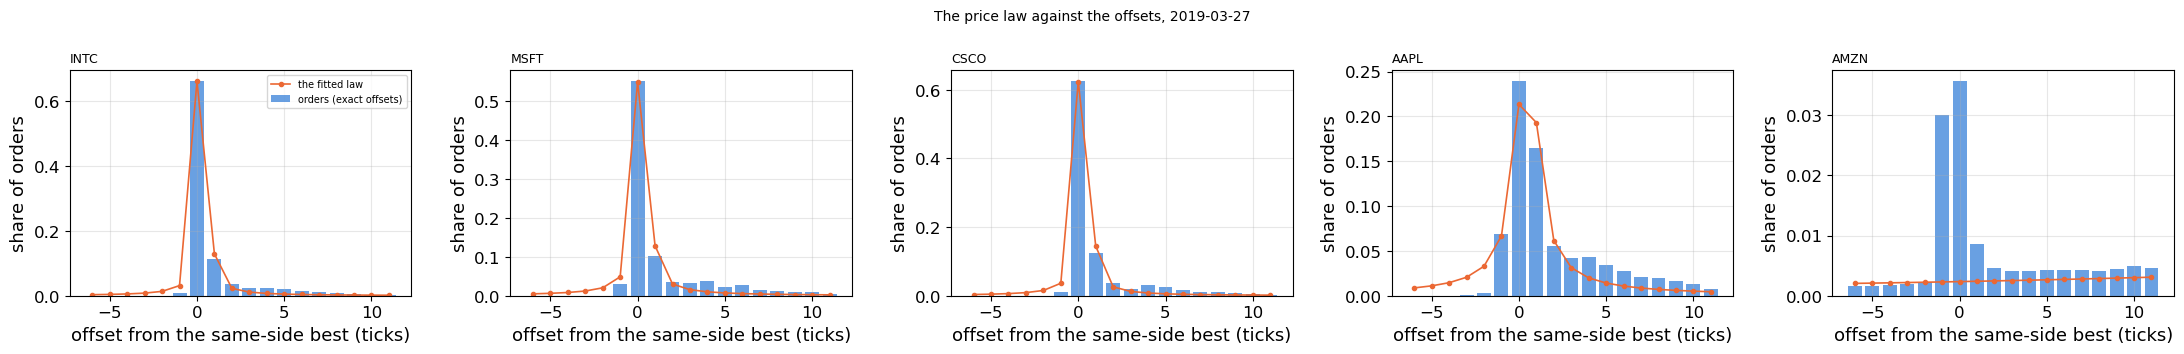


Table 10. The calibration prediction (the rule is in the predictions cell; judged through PREDICTIONS): 2019-03-27, fits
09:30:00 to 16:00:00, facts 09:40:00 to 15:50:00, fits: displayed rows only, a replace as the frames have it (a deletion
and a new order); facts: tape signed, a replace as two.
rule: the fitted B is at its bound, and the fitted model has 3 times the aggressive orders of the real day or more and 5 times its depth at the touch or more
     B at its bound aggressive orders, model over real depth at the touch, model over real cancel rate, median half hour as a file over the day (window effect, in no verdict) verdict
INTC           True                               8.56                              184.42                                                                                24.0  passed
MSFT           True                               7.78                              504.60                                                                                24.9  p

In [42]:
# 5.3 The fitted model beside the day, fact by fact and half hour by half hour. The day's fit (calibrate_lobster, burn-
# in
# 1,800 s) is run on each of the simulator's seeds (SIM_SEEDS) at a lot of CALIBRATION_LOT shares and a tick a cent, and
# read as the real session is (09:40 to 15:50, a unit of one second, depth in lots of CALIBRATION_LOT shares on both
# sides, the same half hours). Table 7 a stock: the facts, the real half hours' range against the model's; Table 8 the
# ratios side by side; Table 9 the price law against the offsets (where the aggressive orders come from); Table 10 the
# calibration prediction and Table 11 the calibration's mechanism (two of the ten tests, judged through PREDICTIONS).
# Reads: cal_results (kept by the first calibration cell).

cal_fact_rows = (  # (fact, format): notebook 05's facts, and the rates the calibration counts
    ('spread mean (ticks)', ',.2f'),
    ('share at one tick', '.1%'),
    ('share at 5 ticks or more', '.1%'),
    ('depth at 0 (lots)', ',.2f'),
    ('depth at 1 (lots)', ',.2f'),
    ('depth at 3 (lots)', ',.2f'),
    ('depth at 9 (lots)', ',.2f'),
    ('1 s return sd (bp)', '.2f'),
    ('zero 1 s returns', '.1%'),
    ('excess kurtosis of 1 s returns', '.2f'),
    ('rank |r| acf, lag 1', '.3f'),
    ('return acf, lag 1', '.3f'),
    ('sign acf, lag 1', '.3f'),
    ('sign acf, lag 10', '.3f'),
    ('sign acf, lag 100', '.3f'),
    ('orders a second', '.2f'),
    ('cancels a second', '.2f'),
    ('aggressive orders a second', '.3f'),
    ('events a second', '.2f'),
    ('mid changes a second', '.3f'),
)
# correlations: the model against the real value is a difference (a ratio of a 0 or a sign flips)
cal_difference_facts = (
    'rank |r| acf, lag 1',
    'return acf, lag 1',
    'sign acf, lag 1',
    'sign acf, lag 10',
    'sign acf, lag 100',
)
cal_log_facts = (
    'depth at 0 (lots)',
    'depth at 3 (lots)',
    'aggressive orders a second',
    'excess kurtosis of 1 s returns',
)
cal_ratio_facts = (  # the facts of Table 8, a column each
    'spread mean (ticks)',
    'depth at 0 (lots)',
    'depth at 3 (lots)',
    '1 s return sd (bp)',
    'zero 1 s returns',
    'excess kurtosis of 1 s returns',
    'rank |r| acf, lag 1',
    'sign acf, lag 1',
    'sign acf, lag 100',
    'orders a second',
    'cancels a second',
    'aggressive orders a second',
)
cal_panels = (  # the facts of the figure, a panel each; the first four rows are the book, then returns, signs, rates
    'spread mean (ticks)',
    'share at one tick',
    'depth at 0 (lots)',
    'depth at 3 (lots)',
    '1 s return sd (bp)',
    'zero 1 s returns',
    'excess kurtosis of 1 s returns',
    'rank |r| acf, lag 1',
    'sign acf, lag 1',
    'sign acf, lag 10',
    'sign acf, lag 100',
    'return acf, lag 1',
    'orders a second',
    'cancels a second',
    'aggressive orders a second',
    'events a second',
)


def cal_text(x, spec):
    # a number as text, '-' where it is not there
    return '-' if x is None or not math.isfinite(x) else format(x, spec)


def cal_range(values, spec):
    # 'min to max' of the values that are there, as text
    return f'{cal_text(np.nanmin(values), spec)} to {cal_text(np.nanmax(values), spec)}'


def cal_against(model, real, fact):
    # the model's value against the real one: a ratio for a size, a difference for a correlation (NaN if either is not
    # there, or a ratio's real value is 0)
    if fact in cal_difference_facts:
        return model - real
    return model / real if real else math.nan


def cal_against_text(value, fact):
    return (
        cal_text(value, '+.3f') if fact in cal_difference_facts else (f'x{value:.2f}' if math.isfinite(value) else '-')
    )


def cal_fact_arrays(detail, fact):
    # the real session's value, the real half hours' values, the model's session values (a seed each) and the model's
    # half-hour values (a row a seed)
    real, runs = detail['real'], detail['sim']
    return (
        real['session'][fact],
        np.array([block[fact] for block in real['blocks']], float),
        np.array([run['session'][fact] for run in runs], float),
        np.array([[block[fact] for block in run['blocks']] for run in runs], float),
    )


def cal_facts_table(detail):
    # a row a fact: the real session, the real half hours' range, the model's mean over seeds and its range, the ratio,
    # and how many of the real half hours lie inside the band the model's half hours (every seed) span
    rows = {}
    for fact, spec in cal_fact_rows:
        session, blocks, sim_session, sim_blocks = cal_fact_arrays(detail, fact)
        low, high = np.nanmin(sim_blocks), np.nanmax(sim_blocks)
        seen = np.isfinite(blocks)
        inside = int(((blocks >= low) & (blocks <= high))[seen].sum())
        mean = np.nanmean(sim_session) if np.isfinite(sim_session).any() else math.nan
        rows[fact] = {
            'real session': cal_text(session, spec),
            'real half hours, min to max': cal_range(blocks, spec),
            'model, mean of seeds': cal_text(mean, spec),
            'model, seeds min to max': cal_range(sim_session, spec),
            'model against real': cal_against_text(cal_against(mean, session, fact), fact),
            'real half hours inside the model\'s band': f'{inside} of {int(seen.sum())}',
        }
    return pd.DataFrame(rows).T


cal_strip_facts = (  # the facts whose half-hour values are printed under each Table 7
    'spread mean (ticks)',
    'depth at 0 (lots)',
    '1 s return sd (bp)',
    'sign acf, lag 1',
    'orders a second',
    'cancels a second',
    'aggressive orders a second',
)


def cal_fact_strips(detail, width=8):
    # the half-hour values of some facts, the real half hours and the model's mean over seeds, under the session's half
    # hours' start times
    lines = [f'{"":<30}{"":<7}' + ' '.join(f'{BLOCK_LABELS[block]:>{width}}' for block, _, _ in cal_windows)]
    for fact in cal_strip_facts:
        _, real, _, sim = cal_fact_arrays(detail, fact)
        spec = dict(cal_fact_rows)[fact]
        lines.append(f'{fact:<30}{"real":<7}' + ' '.join(f'{cal_text(v, spec):>{width}}' for v in real))
        lines.append(
            f'{"":<30}{"model":<7}' + ' '.join(f'{cal_text(v, spec):>{width}}' for v in np.nanmean(sim, axis=0))
        )
    return '\n'.join(lines)


def cal_ratio_table(results):
    # the model's mean over seeds against the real session, a row a stock, as text (a ratio; a difference for a
    # correlation, in the columns that say so), and (second frame) how many of the real half hours lie inside the
    # model's band
    against, inside = {}, {}
    for stock, detail in results.items():
        against[stock], inside[stock] = {}, {}
        for fact in cal_ratio_facts:
            session, blocks, sim_session, sim_blocks = cal_fact_arrays(detail, fact)
            mean = np.nanmean(sim_session) if np.isfinite(sim_session).any() else math.nan
            label = f'{fact} (difference)' if fact in cal_difference_facts else fact
            against[stock][label] = cal_text(
                cal_against(mean, session, fact), '+.3f' if 'difference' in label else '.2f'
            )
            seen = np.isfinite(blocks)
            hit = ((blocks >= np.nanmin(sim_blocks)) & (blocks <= np.nanmax(sim_blocks)))[seen].sum()
            inside[stock][fact] = f'{int(hit)}/{int(seen.sum())}'
    return pd.DataFrame(against).T, pd.DataFrame(inside).T


def cal_plot_facts(stock, detail, day=DAY):
    # the facts by half hour of the session: the real half hours (blue) and the model's, the band over seeds (orange)
    # with its mean; log axis where every value is positive and the fact is a size (depth, rates, tails)
    x = np.arange(len(cal_windows))
    fig, axes = plt.subplots(4, 4, figsize=(17, 11))
    for ax, fact in zip(axes.ravel(), cal_panels, strict=True):
        _, real, _, sim = cal_fact_arrays(detail, fact)
        ax.fill_between(x, np.nanmin(sim, axis=0), np.nanmax(sim, axis=0), color=ORANGE, alpha=0.3, linewidth=0)
        ax.plot(x, np.nanmean(sim, axis=0), color=ORANGE, linewidth=1.0)
        ax.plot(x, real, color=BLUE, marker='o', markersize=3.5, linewidth=1.3)
        positive = np.concatenate([real[np.isfinite(real)], sim[np.isfinite(sim)]])
        if fact in cal_log_facts and len(positive) and (positive > 0).all():
            ax.set_yscale('log')
        if np.isnan(sim).all():
            ax.set_xlabel('not defined for the model', color=ORANGE, fontsize=8)  # under the panel, off the real line
        ax.set_title(fact, fontsize=9, loc='left')
        ax.set_xticks(x[::2], [BLOCK_LABELS[block] for block, _, _ in cal_windows][::2], fontsize=7)
    fig.legend(  # one legend under the panels (in the first panel it covered the real line)
        handles=[
            plt.Line2D([], [], color=BLUE, marker='o', markersize=3.5, label='the real session'),
            Patch(color=ORANGE, alpha=0.3, label=f'the fitted model, {len(SIM_SEEDS)} seeds (band)'),
        ],
        loc='lower center',
        ncol=2,
        fontsize=8,
    )
    fig.suptitle(
        f'{stock}: notebook 05\'s facts by half hour of the session, the real day and the fitted model, '
        f'{day_text(day)}' + (f'\n{EXPLORATION}' if stock in EXPLORED else ''),
        fontsize=10,
    )
    fig.tight_layout(rect=(0, 0.02, 1, 1))
    return fig


def cal_plot_depth(results, day=DAY):
    # the depth profile of the session (mean depth, lots, at each tick from the same-side best), the real one against
    # the
    # band of the model's seeds, a panel a stock
    fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 3.6), squeeze=False)
    ticks = np.arange(cal_depth_ticks)
    for ax, (stock, detail) in zip(axes[0], results.items(), strict=True):
        profiles = np.array([run['session']['depth profile (lots)'] for run in detail['sim']], float)
        ax.fill_between(
            ticks, np.nanmin(profiles, axis=0), np.nanmax(profiles, axis=0), color=ORANGE, alpha=0.3, linewidth=0
        )
        ax.plot(ticks, np.nanmean(profiles, axis=0), color=ORANGE, linewidth=1.0, label='the fitted model')
        ax.plot(
            ticks,
            detail['real']['session']['depth profile (lots)'],
            color=BLUE,
            marker='o',
            markersize=3.5,
            linewidth=1.3,
            label='the real session',
        )
        ax.set_yscale('log')
        ax.set_title(stock, fontsize=9, loc='left')
        ax.set_xlabel('ticks from the same-side best')
        ax.set_ylabel(f'mean depth (lots of {CALIBRATION_LOT} shares)')
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(
        f'The depth profile of the session, {day_text(day)}'
        + (f'\n{EXPLORATION}' if set(results) & set(EXPLORED) else ''),
        fontsize=10,
    )
    fig.tight_layout()
    return fig


def cal_price_table(results):
    # a row a stock: the price law the fit found, the median spread, the share of orders at an offset of one tick inside
    # the same-side quote or more (the data's exact ones with those that executed in full, and the law's), and the
    # orders that trade on arrival (the data's, and the fitted model's in the simulation)
    rows = {}
    for stock, detail in results.items():
        law, fit = detail['price law'], detail['day fit']
        simulated = np.mean(
            [run['session']['aggressive orders a second'] / run['session']['orders a second'] for run in detail['sim']]
        )
        real = detail['real']['session']
        rows[stock] = {
            'nu': fit['nu'],
            'loc': fit['loc'],
            'scale': fit['scale'],
            'median spread (ticks)': detail['real']['session']['spread median (ticks)'],
            'offset of -1 or less, data': law['share at an offset of -1 or less: data, exact']
            + law['executed in full (offset known only to be at most a bound)'],
            'offset of -1 or less, fitted law': law['share at an offset of -1 or less: fitted law'],
            'trade on arrival, data': real['aggressive orders a second'] / real['orders a second'],
            'trade on arrival, fitted model': simulated,
        }
    return pd.DataFrame(rows).T


def cal_plot_price(results, day=DAY):
    # the share of orders at each offset from the same-side best (positive: less aggressive), the exact ones of the data
    # as bars and the fitted law as a line, a panel a stock; orders that executed in full are in no bar
    fig, axes = plt.subplots(1, len(results), figsize=(4.4 * len(results), 3.6), squeeze=False)
    for ax, (stock, detail) in zip(axes[0], results.items(), strict=True):
        law = detail['price law']
        ks = list(cal_offsets)
        ax.bar(
            ks,
            [law['share by offset: data (exact)'][k] for k in ks],
            color=BLUE,
            alpha=0.7,
            label='orders (exact offsets)',
        )
        ax.plot(
            ks,
            [law['share by offset: fitted law'][k] for k in ks],
            color=ORANGE,
            marker='o',
            markersize=3,
            linewidth=1.2,
            label='the fitted law',
        )
        ax.set_title(stock, fontsize=9, loc='left')
        ax.set_xlabel('offset from the same-side best (ticks)')
        ax.set_ylabel('share of orders')
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(
        f'The price law against the offsets, {day_text(day)}'
        + (f'\n{EXPLORATION}' if set(results) & set(EXPLORED) else ''),
        fontsize=10,
    )
    fig.tight_layout()
    return fig


def cal_mechanism_table(summaries, verdicts, measures):
    # a row a stock: the share of the time at one tick, the figure the mechanism test reads (the fitted model's mid
    # changes a second as a multiple of the real day's where one tick holds more than half the time, its mean spread
    # as a multiple of the real day's otherwise), its line, and the verdict
    rows = {}
    for stock, summary in summaries.items():
        share = one_tick_share(measures.get(stock, {}))
        one_tick = is_number(share) and share > 0.5
        rows[stock] = {
            'time at one tick %': 100 * share,
            'the figure read': 'mid changes a second' if one_tick else 'mean spread',
            'model over real': summary['mid_changes_ratio' if one_tick else 'spread_ratio'],
            'the line': 'under 0.1' if one_tick else 'within 0.8 to 1.2',
            'verdict': verdicts[stock].status,
        }
    return pd.DataFrame(rows).T


if need(DAY):
    cal_results = cal_calibrated(DAY)
    for cal_stock, cal_detail in cal_results.items():
        assert cal_detail['sim params']['lot_size'] == CALIBRATION_LOT, f'{cal_stock}: the model is not run at the lot'
        assert [run['seed'] for run in cal_detail['sim']] == list(SIM_SEEDS), f'{cal_stock}: not the simulator\'s seeds'
        for cal_facts in (cal_detail['real']['session'], *(run['session'] for run in cal_detail['sim'])):
            assert math.isclose(
                cal_facts['events a second'], cal_facts['orders a second'] + cal_facts['cancels a second'], rel_tol=1e-9
            ), f'{cal_stock}: events are not orders and cancels'
            assert cal_facts['aggressive orders a second'] <= cal_facts['orders a second'] + 1e-12, (
                f'{cal_stock}: more aggressive orders a second than orders'
            )
        for cal_run in cal_detail['sim']:
            assert [b['block'] for b in cal_run['blocks']] == [b['block'] for b in cal_detail['real']['blocks']], (
                f'{cal_stock}: the model\'s half hours are not the real ones'
            )
        if not SMOKE:
            assert len(cal_detail['real']['blocks']) == N_BLOCKS, f'{cal_stock}: not thirteen half hours of the session'

    for cal_stock, cal_detail in cal_results.items():
        cal_heading(
            f'Table 7. {cal_stock}: the fitted model beside the day, session {clock(U0)} to {clock(U1)}, a unit of '
            f'one second, depth in lots of {CALIBRATION_LOT} shares on both sides; the fit\'s modal order size is '
            f'{cal_detail["day fit"]["lot_size"]} shares',
            [cal_stock],
        )
        print(
            f'the day\'s fit (calibrate_lobster, burn-in {CALIBRATION_BURN:,.0f} s): '
            + ', '.join(f'{name} {cal_detail["day fit"][name]:.4g}' for name in cal_params)
            + f'; initial mid {cal_detail["initial mid"]:,} ticks, warm-up {cal_detail["warm-up"]:,.0f} s, '
            f'seeds {SIM_SEEDS[0]} to {SIM_SEEDS[-1]}'
        )
        print(shown(cal_facts_table(cal_detail)))
        print('\nThe half hours of the session, start times over the columns:')
        print(cal_fact_strips(cal_detail))
    print(
        '\nmid changes a second are changes of the mid between two 1 s samples, not the stream\'s changes of the mid '
        'an event (section 1 prints those); events are orders and cancels, a replace as a deletion and a new order.'
    )

    cal_ratios, cal_inside = cal_ratio_table(cal_results)
    cal_heading(
        'Table 8. The model\'s mean over seeds against the real session (a ratio; a difference for a correlation), '
        'and how many real half hours lie inside the model\'s band',
        cal_results,
    )
    print(shown(cal_ratios))
    print()
    print(shown(cal_inside))

    for cal_stock, cal_detail in cal_results.items():
        cal_fig = cal_plot_facts(cal_stock, cal_detail)
        plt.show()
    cal_fig_depth = cal_plot_depth(cal_results)
    plt.show()

    cal_heading(
        'Table 9. The fitted price law against the offsets: where the model\'s aggressive orders come from', cal_results
    )
    print(
        shown(
            cal_price_table(cal_results),
            {'nu': '.3f', 'loc': '.2f', 'scale': '.3f', 'median spread (ticks)': '.1f'}
            | {
                column: '.1%'
                for column in ('offset of -1 or less, data', 'offset of -1 or less, fitted law')
                + ('trade on arrival, data', 'trade on arrival, fitted model')
            },
        )
    )
    cal_fig_price = cal_plot_price(cal_results)
    plt.show()

    cal_summaries = {stock: cal_summary(detail) for stock, detail in cal_results.items()}
    cal_verdicts = {
        stock: PREDICTIONS['calibration'].judge({'calibration': summary}) for stock, summary in cal_summaries.items()
    }
    cal_heading(
        'Table 10. The calibration prediction (the rule is in the predictions cell; judged through PREDICTIONS)',
        cal_results,
    )
    print(f'rule: {PREDICTIONS["calibration"].rule}')
    print(
        shown(
            pd.DataFrame(
                {
                    stock: {
                        'B at its bound': str(summary['b_at_bound']),
                        'aggressive orders, model over real': cal_text(summary['aggressive_ratio'], '.2f'),
                        'depth at the touch, model over real': cal_text(summary['depth_ratio'], '.2f'),
                        'cancel rate, median half hour as a file over the day (window effect, in no verdict)': (
                            cal_text(summary['cancel_ratio'], '.1f')
                        ),
                        'verdict': cal_verdicts[stock].status,
                    }
                    for stock, summary in cal_summaries.items()
                }
            ).T
        )
    )
    for cal_stock, cal_verdict in cal_verdicts.items():
        print(f'  {cal_stock}: {cal_verdict.status}: {cal_verdict.detail}')
    cal_counts = counts_of(verdict_table({stock: {'calibration': verdict} for stock, verdict in cal_verdicts.items()}))
    cal_count = cal_counts.loc['calibration']
    print(
        f'calibration: passed on {cal_count["passed"]} of {cal_count["judged"]} '
        f'judged stocks ({cal_count["stocks"]} calibrated), day {day_text(DAY)}.'
    )
    print(
        '\nThe cancel-rate ratio above measures the estimator\'s window effect: a half hour fitted as a file of its '
        'own is read against the day\'s fit, and the half hours fitted with the day\'s history agree with the day. '
        'It is not the stock\'s cancel rate, is not read as one, and is in no verdict.'
    )

    cal_measures = measured(DAY, list(cal_results))
    cal_test = 'calibration\'s mechanism'
    cal_mechanism = {
        stock: PREDICTIONS[cal_test].judge({**cal_measures.get(stock, {}), 'calibration': summary})
        for stock, summary in cal_summaries.items()
    }
    cal_heading(
        'Table 11. The calibration\'s mechanism (the rule is in the predictions cell; judged through PREDICTIONS)',
        cal_results,
    )
    print(f'rule: {PREDICTIONS[cal_test].rule}')
    print(
        shown(
            cal_mechanism_table(cal_summaries, cal_mechanism, cal_measures),
            {'time at one tick %': '.1f', 'model over real': '.3f'},
        )
    )
    for cal_stock, cal_verdict in cal_mechanism.items():
        print(f'  {cal_stock}: {cal_verdict.status}: {cal_verdict.detail}')
    cal_count = counts_of(verdict_table({stock: {'mechanism': verdict} for stock, verdict in cal_mechanism.items()}))
    cal_count = cal_count.loc['mechanism']
    print(
        f'{cal_test}: passed on {cal_count["passed"]} of {cal_count["judged"]} '
        f'judged stocks ({cal_count["stocks"]} calibrated), day {day_text(DAY)}.'
    )

**Tables 7 and 8, fact by fact.** The fitted model, simulated on eight seeds at a lot of 100 shares and a tick a cent, is read as the real session is (09:40:00 to 15:50:00, a unit of one second, depth in lots of 100 shares on both sides). Table 7 gives each fact's real session value, the range of the real half hours, the model's mean over seeds with its range, the model against the real value (a ratio, or a difference for a correlation) and, in its last column, how many of the 13 real half hours lie inside the band that the model's half hours span; Table 8 sets the ratios and the inside counts side by side. A fact is called reproduced here only where both hold, the real session's value lying in the range of the model's seeds and the real half hours lying inside the model's band, and no more is said of it. On this day only a few facts qualify: AAPL's excess kurtosis of the 1 s return (3.68 against the model's 3.23 to 3.87, 11 of 13 half hours inside), AMZN's 1 s return sd (0.83 bp against 0.31 to 0.91, 11 of 13) and its sign autocorrelation at lag 10 (0.078 against 0.078 to 0.081, 8 of 13), and the share of time at 5 ticks or more, 0.0% on both sides on INTC, MSFT and CSCO (13 of 13), which is a fact about no spread so wide on either side. The mean spread of INTC and CSCO reads 1.00 on both sides, but only 2 of 13 real half hours are inside the model's band. Every other fact of Table 7 either has the real session's value outside the range of the model's seeds, on every stock, or is not defined for the model.

The book. The real mean spread is 1.00 (INTC), 1.10 (MSFT), 1.00 (CSCO), 2.15 (AAPL) and 53.30 ticks (AMZN) and the model's 1.00, 1.00, 1.00, 1.16 and 39.09 (×1.00, ×0.91, ×1.00, ×0.54 and ×0.73); one tick holds 99.8%, 89.8%, 99.6%, 20.7% and 0.0% of the real session and 100.0%, 100.0%, 100.0%, 83.5% and 0.8% of the model's. The depth at the touch is 17.32, 6.00, 19.84, 2.81 and 0.49 lots in the real book and 3,193.31, 3,029.83, 1,804.88, 477.74 and 9.85 in the model, which are ×184.42, ×504.60, ×90.99, ×170.10 and ×20.23, the last in lots of 100 shares, the unit the rule read (AMZN's fitted `lot_size` is 20 shares). In orders, the model's own unit, the ratios are Table 7f's, in section 7, which was asked for after the run and judges nothing. The depth profile figure gives the shape as well as the level. On INTC, MSFT and CSCO the model's profile falls steeply from the touch (INTC 3,193.31 lots at the touch, 753.08 at 1 tick, 65.31 at 3 and 11.87 at 9) where the real one is flat (17.32, 41.17, 45.73 and 28.22), so the model is too deep near the touch, too shallow at 9 ticks on INTC (×0.42) and CSCO (×0.38), and still too deep there on MSFT (×2.66). On AAPL the model's profile peaks at 1 tick (1,401.81 lots against 477.74 at the touch) while the real one rises from 2.81 at the touch to 8.62 at 9 ticks (×259.50 at 1 tick, ×93.30 at 3 and ×13.14 at 9). On AMZN the model's rises from 9.85 at the touch to 25.09 at 9 ticks while the real one falls from 0.49 to 0.05 (×161.31 at 1 tick, ×450.16 at 3 and ×551.81 at 9). No depth is reproduced: 0 of 13 real half hours are inside the model's band at every depth on every stock, except at 3 ticks on INTC (2 of 13) and CSCO (3 of 13).

Returns, signs and rates. On INTC, MSFT and CSCO the model's mid does not move in any seed: its zero 1 s returns are 100.0% (against 83.1%, 53.4% and 84.6% in the real session), its mid changes a second 0.000 (against 0.169, 0.466 and 0.154) and its 1 s return sd 0.00 bp (against 0.84, 0.75 and 0.76). The volatility, the tails and the clustering are therefore not defined for it as a figure to compare: its excess kurtosis, the rank autocorrelation of |r| and the return autocorrelation print "-". On AAPL the model's mid moves: sd 0.15 bp against 0.87 (×0.17), zero returns 75.8% against 29.2%, mid changes 0.242 a second against 0.708 (×0.34), rank |r| autocorrelation at lag 1 0.323 against 0.151 (+0.172) and return autocorrelation -0.290 against +0.012 (-0.302). On AMZN the sd is 0.76 against 0.83 (×0.92), zero returns 6.5% against 44.2% (×0.15), excess kurtosis 1.17 against 7.79 (×0.15), rank |r| autocorrelation 0.170 against 0.161 (+0.009, 10 of 13 half hours inside, the session's value just outside the seeds' range), return autocorrelation -0.326 against +0.029 (-0.355) and mid changes 0.935 a second against 0.558 (×1.67), more than the real day's. The order signs' autocorrelation, model less real, at lag 1 is -0.126 (INTC), -0.145 (MSFT), -0.171 (CSCO), -0.028 (AAPL) and +0.129 (AMZN); at lag 10 -0.131, -0.099, -0.173, -0.011 and +0.001; at lag 100 +0.093, +0.045, +0.110, +0.016 and +0.008. The model's signs are less persistent than the real ones at lags 1 and 10 on INTC, MSFT and CSCO, and more at lag 100 on all five. The order rate is ×1.04, ×1.04, ×1.03, ×1.07 and ×1.07, by construction, the fit's `lam` over the day against the session's real rate; cancels ×0.84, ×0.71, ×0.81, ×0.48 and ×0.62; aggressive orders ×8.56, ×7.78, ×7.23, ×9.14 and ×9.80; events ×0.94, ×0.88, ×0.92, ×0.78 and ×0.85. Only AMZN's orders and events a second have a real half hour inside the model's band (1 of 13 each).

**The figure of each stock, the half hours one by one.** The model's band is flat by construction, one set of parameters for the whole day, and the real day moves. The real mean spread falls through the session on AAPL, from 2.85 ticks at 09:40 to 1.56 at 15:30, and on AMZN, from 75.00 to 38.52, where the model's half hours run from 1.15 to 1.18 and from 37.99 to 40.22; on INTC, MSFT and CSCO the real half hours stay between 1.00 and 1.15 and the model's at 1.00. The real order rate is lowest in the 13:30 half hour on every stock (21.45, 30.55, 15.57, 30.81 and 19.20 a second) and highest at 09:40 on INTC (53.51), MSFT (65.50) and AAPL (73.23) and at 11:30 on CSCO (35.98) and AMZN (37.74), where the model's runs from 32.38 to 32.54 on INTC, 49.54 to 49.70 on MSFT, 25.23 to 25.40 on CSCO, 46.55 to 46.76 on AAPL and 29.42 to 29.57 on AMZN. The real 1 s return sd is highest in the first half hour on INTC (1.31), MSFT (0.96), CSCO (1.00) and AAPL (1.42) and lowest at 13:30 or 14:00 (0.65, 0.54, 0.59 and 0.64 bp), and AMZN's runs from 1.24 at 11:30 to 0.61, where the model's is 0.00 on three stocks, 0.14 to 0.15 on AAPL and 0.74 to 0.79 on AMZN. The real aggressive-order rate falls on INTC from 1.028 at 09:40 to 0.256 at 14:00 where the model's is 3.601 to 3.678, and the real sign autocorrelation at lag 1 from 0.563 to 0.467 where the model's is 0.362 to 0.377. The real depth at the touch is highest in the last half hour on INTC (26.51 lots), CSCO (27.77) and AAPL (3.81) where the model's band is flat (3,174.00 to 3,208.69 on INTC). A stationary model cannot follow any of these, and the figures show the band beside the line of the real half hours and not a fit to them.

**Table 9, the price law.** The fitted `nu`, `loc` and `scale` are 0.417, 0.35 and 0.064 on INTC, 0.389, 0.27 and 0.148 on MSFT, 0.442, 0.34 and 0.094 on CSCO, 0.374, 0.45 and 0.759 on AAPL and 0.459, 47.63 and 39.230 on AMZN, and the median spread of the session is 1.0, 1.0, 1.0, 2.0 and 52.0 ticks. The share of orders at an offset of one tick inside the same-side quote or more (an offset of -1 or less) is 2.3%, 5.4%, 2.8%, 10.5% and 9.6% in the data (the exact offsets, with the orders that executed in full) and 11.2%, 17.6%, 12.4%, 30.1% and 28.5% under the fitted law. The orders that trade on arrival are 1.4%, 2.3%, 1.8%, 3.4% and 2.5% of the data's and 11.2%, 17.6%, 12.4%, 29.0% and 22.7% of the fitted model's in the simulation. The fitted law is a rounded Student's t, one law with one tail, so its heavy tail on the passive side is an equally heavy tail on the aggressive side: it puts 11.2% to 30.1% of orders at offsets of -1 or less where the data have 2.3% to 10.5% (the figure of the law against the offsets draws the law's line over the negative offsets beside the data's bars), and that is where the model's aggressive orders come from. On INTC, MSFT and CSCO, whose median spread is one tick, the model's share of orders that trade on arrival equals the law's share at -1 or less (11.2%, 17.6% and 12.4%), and on AAPL and AMZN it is a little below (29.0% against 30.1% and 22.7% against 28.5%), where the model's spread is not always one tick.

**Table 10, the calibration prediction.** The rule reads three figures: whether the fitted B is at its bound (True on all five), the fitted model's aggressive orders over the real day's (×8.56, ×7.78, ×7.23, ×9.14 and ×9.80 on INTC to AMZN; the line is 3) and its depth at the touch over the real day's (×184.42, ×504.60, ×90.99, ×170.10 and ×20.23, AMZN's in lots of 100 shares; the line is 5). The verdict through `PREDICTIONS` is passed on each, and "calibration: passed on 5 of 5 judged stocks (5 calibrated), day 2019-03-27". AMZN's ×20.23 is in lots of 100 shares, the unit the rule read, and the depth in orders is Table 7f's in section 7, which was asked for after the run, is judged by no rule, and has no ratio set against the rule's line. The `cancel_ratio` printed beside the three, 24.0, 24.9, 16.2, 56.5 and 64.5, is the median half hour as a file over the day's, the estimator's window effect of Table 2, and is in no verdict. The prediction was written before the reported stocks were read, from the exploration (B at its bound, aggressive orders ×7.6 and ×8.6 and depth at the touch ×17.0 and ×44.7 on NVDA and CMCSA), and was called near-certain, since the exploration sat far past every line by a mechanism already known. A pass is therefore not a test of anything but the model's structure. Each of the three parts held for each stock. The five stocks share the day's market factor, so the 5 of 5 is not five independent results. Section 6 runs the same code on the second day.

**Table 11, the calibration's mechanism** (the tenth test). The rule reads the fitted model's mid changes a second over the real day's where one tick holds more than half the time (the line is under 0.1) and its mean spread over the real day's otherwise (the line is within 0.8 to 1.2). INTC: one tick holds 99.8% of the time and the mid changes read ×0.000, passed. MSFT: 89.8%, ×0.000, passed. CSCO: 99.6%, ×0.000, passed. AAPL: 20.7%, mean spread ×0.543, not passed. AMZN: 0.0%, mean spread ×0.733, not passed. The test passed on 3 of 5 stocks on this day, stocks that share the day's market factor. Written before the reported stocks were read, from the exploration, were that the fitted model's mid did not move on CMCSA, where one tick held 99.8% of the time (a ratio of 0.000), and that on NVDA, where one tick held 0.3%, the mean spread was within 20% of the real day's (×0.821); these are exploration figures and not results. Unlike the ratios above it, this is a test that can fail, and it did on two stocks. AAPL's failure is the model's: the real half hours' mean spread runs from 1.56 to 2.85 ticks and the model's from 1.15 to 1.18, so every real half hour is above every one of the model's, and one tick holds 20.7% of the real session and 83.5% of the model's. AMZN's ratio sits on its line, ×0.733 against 0.8, with a day whose spread moves through the session: the real half hours' mean spread runs from 75.00 ticks at 09:40 to 38.52 at 15:30 and the model's from 37.99 to 40.22, so the model's is near the real day's last half hour (39.70 against 38.52) and well under its first (39.16 against 75.00), and the day's ratio averages over that. That is as far as the strips go. AAPL's pass on the second day is the gate's branch and not the model's success: one tick holds 54.2% of that day, so the rule reads the model's mid changes (×0.050 in section 6's table) and not its mean spread, and the rule reads a different quantity for AAPL on each day.

**What this cannot show.**

**It is a calibration that fails, and it cannot be made to succeed by a better fit.** The fit is maximum likelihood, one part of the model at a time: the order rate from a count, the price law from the offsets of new orders, the signs' memory from their autocorrelation, the cancellation parameters from a replay of the book. Nothing in it asks the simulated book to have the real book's depth, spread or trades, so a fit that is good in each part is no promise that the parts together make the day. A fit says what the model would need to look like the day on average; it does not say that the model then does, and this section's tables are where that is checked, fact by fact. That the fitted model does or does not reproduce a fact for a stock on a day is a statement about that stock, that day and this model, and is not a statement about the simulator's models in general or about any other stock.

**Why it fails, and what each reason takes away from the comparison.**

- *One order size.* The model's orders all have `lot_size` shares, set here to 100 shares (`CALIBRATION_LOT`, the modal order size of the exploration stocks; the fit's own `lot_size` is printed in Table 1 and in the heading of each Table 7, and the model is run at 100 shares whatever it says). Real orders are odd lots, round lots and large blocks; depth in "lots of 100 shares" is a unit for comparing the two, not a claim that real orders have that size, and a book of many small orders and a book of few large ones are the same depth in this unit.
- *One cancellation hazard for every resting order.* The model cancels each order at one rate that depends on its distance from the opposite quote and on the own side's share of the book. Real orders are a mixture of orders that are deleted within a millisecond of being placed and orders that rest for hours, so the rate fitted from the cancellations divided by the exposure is a number between the two that is set by how much of each is in the window (Table 6). It is therefore **not a property of a stock**: it depends on the window, on the burn-in and on whether the history is replayed (Table 2), and no table here compares a stock's cancel rate with another's.
- *One symmetric law for prices.* A new order's price is a rounded Student's t offset from the same-side quote, with one location, one scale and one tail. A heavy tail on the passive side is a heavy tail on the aggressive side, and a stock whose spread is one tick almost all day and one whose spread is many ticks fit the same three parameters to very different things: any comparison of the fitted law across stocks is a comparison of the tick-to-spread ratio.
- *Poisson arrivals.* Orders come at a constant rate, the day's average, and independently of the book except through the signs' memory and the cancellations. The real rate changes through the day (on the reported stocks' first day the first half hour's events a second were 1.24 to 1.86 times the median half hour's, as section 1 prints), and a Poisson process has no bursts.
- *No hidden orders and no replaces.* The calibration reads displayed rows only. Trades against non-displayed orders are out of every fit and of every count here (their shares of executed shares are in section 1), and a replace is read as a deletion and a new order, which gives the model arrivals and cancellations that the market did not make as such; Table 5 shows how much the fit moves when they are left out, and that is the only variant run.
- *A stationary day.* The model has no opening, no close and no trend in its spread or its rate. The day's fit is one set of numbers for a day whose spread, rate and depth move by large factors, so the model's band in the figures is flat by construction and the real half hours are not, and a fact such as the spread's decline from the open cannot be reproduced whatever the parameters.

**What the numbers are, and are not.**

- *B at its bound is a statement about the likelihood, not a value.* `b_max` is 50, the fit's own bound; a profile that rises toward larger B means the data want more than the bound allows, and the estimate is then the bound. What the data say is at least where the 95% likelihood region begins (Table 4). The dashboard's range for B ends at 5, so a fit with B on its bound cannot be entered in the dashboard as it is, and no fitted set is offered as a preset here or clipped into the dashboard's ranges to make one.
- *A fit is of one stock on one day.* The five stocks share the day's market factor, so a similarity across stocks is not five confirmations, and the second day (section 6) repeats the measurement and is not an independent test of the model. No parameter is "the market's" and none is "the stock's"; each is what one day's order flow gave one estimator.
- *Band against band is a description.* The model's band is eight seeds of one fitted model, and the real band is thirteen half hours of one day, which are not exchangeable (the first has the opening burst); "the real half hours inside the model's band" counts, it does not test, and an interval over eight seeds is not an interval for the real value. A ratio of the model to the real session is a size, not a score, and for a correlation the table gives a difference, because a ratio of a correlation that is near 0 or changes sign says nothing.
- *A fact that is not reproduced is not explained by the table that shows it.* Each reason above is a mechanism the model lacks; the tables show that a fact is missed and by how much, and Tables 4 to 6 and 9 show the mechanisms that the data can show (B's profile, the replace sensitivity, how long orders last, where the aggressive orders come from). They do not show that removing a mechanism would fix a fact: that would be another model, or a fit by matching moments (depth, trade share) and not by likelihood, to see whether any eight values of this model reproduce the day. That is the next step and is not done here.
- *What the estimator was checked on.* Notebook 08 checked the estimators on the model's own output and on its own output in LOBSTER's format, not on a real day's order flow, whose frames here are Nasdaq's converted by `lob.itch`; a fit on real data has the model's misspecification in it, and nothing separates that from an error of the estimator except the checks above.
- *The simulation starts from an empty book.* The model is warmed up for four mean lifetimes of a resting order at its fitted cancel hazard (at least ten minutes) from the real mid at 09:40; the real day starts with a book already full and with orders placed the day before, so what the fitted model has at unit 0 is the model's stationary book and not the day's.
- *Depth is read from the ten levels of the book frame.* Displayed orders only, odd lots included, hidden liquidity not at all; a tick beyond the farthest of the ten levels is not observed and is left out on both sides, so a deep book is not read as an empty one. The depth of a stock with a wide spread at the touch is the depth of one tick of a sparse book.
- *Nothing here is about informed trading, toxicity, P&L or queue position*, and nothing about NVDA or CMCSA as a result: they are the exploration stocks, shown only where a heading labels them as exploration (section 4's and section 7's tables, and the smoke copy), never as results.

## Section 6: The second day

**The question.** Sections 1 to 5 measured the five reported stocks on 2019-03-27, the day everything was built on (through NVDA and CMCSA, the exploration stocks). Does what they found hold on a day that nobody looked at until the code was frozen? This section runs the same frozen code on the same five stocks on **2019-07-30**, and judges each of the ten tests of the predictions cell on each stock and each day, with the rules written before any reported stock was read. Nothing is retuned: no setting, no threshold and no stock is changed between the days, and NVDA and CMCSA are not read on the second day.

**What a second day can add.** Another day's order flow of the same five stocks, on a different date (four months after the first) and with a market factor of its own. A prediction that passes on a stock on both days has passed on two draws of that stock's day rather than one, and a prediction that passed on the first day and does not pass on the second was written as a finding that one day could not support. The run showed that on these two days every change between passed and not passed has one of its two verdicts on its line, or a rule that read a different quantity on each day, so none is a finding by itself (section 6 and the conclusions say which). The second day is also the first test of the freeze: the code that first read it is the code whose hash was recorded before any reported stock was converted (the last paragraph of this cell). The outputs below are not all of that code's: after the first run was read, 17 of the 50 code cells were changed, in the words of labels and in how figures are drawn, and `lob/ladder.py` was corrected (a defect in how it read an execution with a price, which changes what the library computes), and they are listed in the limitations as deviations from the frozen code. Every figure of a measurement that a frozen cell printed in the first run is printed again, the same, in the fourth run (the limitations list the four runs), whose outputs are the ones shown, except the figures the correction moved, which the limitations list one by one and none of which is a verdict or a printed figure of a measurement of the second day (the second day's cells print no count of the rungs); the times and the memory figures are the fourth run's and differ from the first's.

**What a second day cannot add.** It is another day of the same five stocks, and it is still five stocks.

- *It shares neither the first day's market factor nor its date, and it does not average them away.* Each day has its own market factor that all five stocks share, so five stocks on a day are not five independent trials, and two days are two draws of that factor and nothing more. A count of stocks that pass is a count over stocks that move together.
- *It is not a sample of days.* Two days cannot say how often a finding holds, in what regime, or on what kind of day; no regime is named for either day. "Held on both days" is a statement about these two days.
- *It is not a sample of stocks.* The five were named before their order flow was read and are five large Nasdaq stocks; nothing here says what a small or a thinly traded stock does, and no stock is said to differ from another.
- *It does not pool with the first day.* The two days are shown side by side, a figure for each, and are never averaged, pooled or tested against each other as if they were one sample.
- *A verdict is a rule on a figure.* The rules are thresholds chosen on two stocks (and the simulator); a figure near its threshold on either day is as much a statement about the threshold as about the stock, so every verdict is printed with the figures it read.

**What is run.** For the second day, in worker processes (one for each stock): `measure`, the conversion's checks, the ladder (the reference and three rungs) and the calibration with the fitted model simulated on seeds 1 to 8 (`SIM_SEEDS`) are run by the same functions as for the first day (`measured`, `tape_checks_of`, `lad_stock` and `cal_calibrated`, each a function of a stock and a day), and every table of sections 1 to 3 is printed again by the function that printed it. Nothing is measured twice: the first day's results are the ones the sections above kept. In the outputs shown the run cell of this section (cell 82) prints a joblib warning, "A worker stopped while some jobs were given to the executor": a worker process was restarted, and every figure of a measurement of the second day is the first run's to the digit. The tables that follow, in this order:

1. the verdict of each prediction on each stock on each day, with the figures it read;
2. the number of stocks that passed on the first day, on the second and on both, with how many were judged;
3. each prediction's headline figure on the first day beside the same figure on the second, a stock at a time, and a figure that draws them;
4. the second day's own tables, section by section.

A prediction is **held on both days** by a stock only where its rule passes on both; a `not passed` or a `not judged` on either day means it is not held, and a rule that does not apply to a stock on a day (the one-tick lift on a stock that spends little time at one tick) is `not judged`. Nothing is counted across predictions and no stock is ranked.

**It does not run without the data,** and the second day's file is not in the repository (`data/itch/` is ignored by git). With either day's data absent each cell of this section prints one line saying so and the notebook goes on.

**The freeze, and when the second day was first read.** On 2026-11-15 at 09:32:55 (+08:00) a combined SHA-256 of the 50 code cells and of `lob/itch.py`, `lob/feeds.py` and `lob/ladder.py` was recorded; it begins `2b220ac5`. Until then the files of the five stocks and of the second day had been held aside, and none of them had been converted or read. The first run began at 09:33:24 the same morning. It converted the second day's file and read it with the code that hash covers, byte for byte: 50 of 50 code cells ran without an error and no stock-day was refused, and every verdict in this notebook was first read from that run. The review of the run, outside the notebook, found that each of the second day's five extracts is, byte for byte, what an independent pass over the day's file gives.

In [43]:
# Section 6, the second day: what its cells share. Names are prefixed two_. It reads the first day's results that
# sections 1 to 5 kept (measured(DAY), tape_checks, lad_reported, cal_calibrated(DAY)) and calls the functions of every
# section above, each a function of a dict of results by stock and a day. Nothing here runs anything: the run is the
# next cell, and with either day's data absent every cell of this section prints the one line of need() and goes on.
TWO_SPREAD = 'time at a spread of one tick, two, three or more'
TWO_DAYS = ('first day', 'second day')


def two_ready():
    # both days' data is there (else need() prints its one line and this is False): the section compares the days
    return need(DAY) and need(SECOND_DAY)


def two_figures(day, kept=False):
    # Everything the tables of a day read, for the reported stocks: measure's result of each stock (measured(): once for
    # a stock-day), the conversion's checks, the ladder's figures (the reference and three rungs) and the calibration's
    # detail. The first day's are what sections 1 to 5 kept (kept=True); the second day's are run here by the same
    # functions, one worker for each stock. A stock-day that lob.itch refused, or that failed, is in none of them (it is
    # in FAILED_RUNS, and printed where it happened) and is never replaced.
    if kept:
        ladder = dict(lad_reported)
        todo = [s for s in STOCKS if s not in ladder and ('lad_stock', day, s) not in FAILED_RUNS]
        if todo:  # section 4 skips if an exploration stock is absent
            ladder |= run_stocks(lad_stock, day, todo)
        return {
            'measures': measured(day),
            'checks': tape_checks,
            'ladder': ladder,
            'calibration': cal_calibrated(day),
        }
    measures = measured(day)
    return {
        'measures': measures,
        'checks': run_stocks(tape_checks_of, day),
        'ladder': run_stocks(lad_stock, day),
        'calibration': cal_calibrated(day),
    }


def two_judged(figures):
    # The results that judge_all reads, for each stock of a day that has measure's result: measure's result with the
    # ladder's and the calibration's summaries added under the keys the rules read (BUILDERS.md, section 2), where
    # those ran (a test whose result is missing is 'not judged')
    out = {}
    for stock, result in figures['measures'].items():
        out[stock] = dict(result)
        if stock in figures['ladder']:
            out[stock]['ladder'] = lad_judged(figures['ladder'][stock])
        if stock in figures['calibration']:
            out[stock]['calibration'] = cal_summary(figures['calibration'][stock])
    return out


def two_verdicts(judged, day):
    # every prediction's verdict for each reported stock of a day: {stock: {test: Verdict}}; a stock-day that has no
    # result is every test 'not judged' with why (refused or failed), never replaced
    return day_verdicts(judged, day)


def two_common(first, second):
    # the stocks that have results on both days, in the order of STOCKS: what the tables set side by side
    return [stock for stock in STOCKS if stock in first and stock in second]


def two_counts(first_table, second_table):
    # A frame by test: the stocks judged and the stocks that passed on each day, and on both days (a prediction is held
    # on both days by a stock only where its rule passes on both), with which stocks held it. Counted per test; nothing
    # is counted across tests.
    first, second = counts_of(first_table), counts_of(second_table)
    held = held_on_both_days(first_table, second_table)
    out = pd.DataFrame(
        {
            'judged, first day': first['judged'],
            'passed, first day': first['passed'],
            'judged, second day': second['judged'],
            'passed, second day': second['passed'],
            'judged on both': held['judged on both'],
            'passed on both': held['passed on both'],
            'held on both days by': held['held on both days'],
        }
    )
    assert list(out.index) == list(PREDICTIONS), 'the counts are not of the ten tests, in their order'
    for column in ('passed, first day', 'judged, first day', 'passed, second day', 'judged, second day'):
        assert (out[column] >= 0).all() and (out[column] <= len(first_table.columns)).all(), column
    assert (out['passed, first day'] <= out['judged, first day']).all(), 'more stocks passed than were judged'
    assert (out['passed, second day'] <= out['judged, second day']).all(), 'more stocks passed than were judged'
    assert (out['passed on both'] <= out[['passed, first day', 'passed, second day']].min(axis=1)).all(), (
        'a prediction is held on both days by more stocks than passed on either day'
    )
    assert (out['passed on both'] <= out['judged on both']).all(), 'held on both days by a stock that was not judged'
    return out


def two_margin(label, value, line, se, strip, how, scale=1.0, digits=1, unit='half hours'):
    # One figure a rule reads, with what it is made of beyond one number: its standard error (`how` names it) and the
    # distance from the rule's line in standard errors, (figure - line) / se, and the range of its half-hour values
    # (`strip`; `unit` names what the values are: VPIN's are its bucket origins'). A figure "above 0" that sits at 0.1
    # of a standard error is not the same finding as one at 20.
    text = f'{label} {value * scale:.{digits}f} (line {line * scale:g})'
    if se is not None and math.isfinite(se) and se > 0:
        text += f': {(value - line) / se:+.1f} se, se {se * scale:.{digits}f} ({how})'
    values = [v for v in (strip or []) if math.isfinite(v)]
    if values:
        text += f'; {unit} {min(values) * scale:.{digits}f} to {max(values) * scale:.{digits}f}'
    return text


def two_margins(test, r):
    # The lines of text under a stock-day's verdict on `test`: each figure the rule reads that has a standard error or a
    # half-hour range, with its distance from the rule's line in standard errors. Block bootstrap ASSUMES EXCHANGEABLE
    # BLOCKS. None for the tests whose figures have neither (the ladder's, the calibration's).
    lines = []
    if test in ('hit rate', 'reversal rate', 'one-tick lift'):
        keys = {'hit rate': ('hit',), 'reversal rate': ('reversal',), 'one-tick lift': ('lift over reversal',)}[test]
        for name in CLASSES:
            strip = r['imbalance']['strips'].get(('L 1 equal', name))
            if strip is None or (test == 'one-tick lift' and name != 'one tick'):
                continue
            for key in keys:
                lines.append(
                    two_margin(
                        f'{name}, L 1 {key}, %'
                        if test != 'one-tick lift'
                        else f'{name}, lift over the reversal, pp (the rule reads its 95% interval against -1 and +1)',
                        strip[key],
                        0.0 if test == 'one-tick lift' else 0.5,
                        strip[key + ' se'],
                        strip['strip'][key],
                        'block bootstrap',
                        100.0,
                    )
                )
    elif test == 'queue race':
        fit = r['imbalance']['race'].get('one tick')
        if fit is not None:
            amplitude, se = fit['a (c = 1)'], fit['a (c = 1) se']
            lines.append(two_margin('amplitude a at one tick', amplitude, 1.0, se, None, 'bootstrap', digits=3))
    elif test == 'order flow imbalance':
        ten = r['ofi'][OFI_MAIN]
        lines.append(
            two_margin(
                f'median half-hour R2 at {OFI_MAIN} s',
                ten['median half-hour R2'],
                0.5,
                ten['median half-hour R2 se'],
                ten['R2 strip'],
                'block bootstrap',
                digits=3,
            )
        )
    elif test == 'VPIN':
        v = r['vpin'][TAPE]
        origins = [o for o in v['origins'] if math.isfinite(o.get('excess', math.nan))]
        if origins:
            low = min(origins, key=lambda o: o['excess'])
            lines.append(
                two_margin(
                    'lowest origin\'s excess over the fair-coin null',
                    low['excess'],
                    0.0,
                    low['null sd'],
                    [o['excess'] for o in origins],
                    'the null\'s sd',
                    digits=3,
                    unit=f'{len(origins)} bucket origins',
                )
            )
    elif test == 'signing':
        blocks = {rule: r['signing'][TAPE][rule]['blocks, per order'] for rule in ('quote1', 'tick')}
        gaps = [100 * (q - t) for q, t in zip(blocks['quote1'], blocks['tick'], strict=True)]
        finite = [g for g in gaps if math.isfinite(g)]
        se = strip_se(finite) if len(finite) > 1 else math.nan
        lines.append(
            two_margin(
                'quote lag 1 less the tick rule, per order, pp',
                two_signing(r, 'quote1') - two_signing(r, 'tick'),
                0.0,
                se,
                gaps,
                'the half hours\' sd over their root',
            )
        )
    return lines


def two_show_verdicts(first, second, judged_first=None, judged_second=None):
    # for each prediction: its rule, then each stock's status and the figures the rule read, on each day; and, where the
    # stock-days' results are given, under each verdict the figures with their standard errors or half-hour ranges and
    # their distance from the rule's line in standard errors (two_margins)
    results = {TWO_DAYS[0]: judged_first or {}, TWO_DAYS[1]: judged_second or {}}
    for test, prediction in PREDICTIONS.items():
        say(f'\n{test}: {prediction.rule}.')
        for stock in first:
            for day_name, verdicts in zip(TWO_DAYS, (first, second), strict=True):
                v = verdicts[stock][test]
                print(f'  {stock:<7}{day_name:<12}{v.status:<11}{v.detail}')
                if stock in results[day_name]:
                    for line in two_margins(test, results[day_name][stock]):
                        print(f'  {"":<7}{"":<12}{"":<11}  {line}')


# ---- the headline figures: what each prediction reads, and the other sections' figures, a stock-day at a time ----
def two_class(results, name, key, setting='L 1 equal'):
    # a figure of the L 1 imbalance in a spread class, in percent (points): NaN for a class under MIN_READINGS
    row = class_rows(results, setting).get(name)
    return math.nan if row is None or row['n'] < MIN_READINGS else 100 * row[key]


def two_race(results, key, name='one tick'):
    # a figure of the queue-race fit at one tick: NaN where the class has under MIN_READINGS readings
    fit = results['imbalance']['race'].get(name)
    return math.nan if fit is None else fit[key]


def two_signing(results, rule, kind='displayed (both)', key='per order'):
    # an accuracy of the signed tape, in percent
    return 100 * results['signing'][TAPE][rule][kind][key]


def two_vpin(results, key):
    return results['vpin'][TAPE][key]


def two_bvc(results, key):
    return results['vpin'][TAPE]['rules']['bvc'][key]


def two_resilience(results, key):
    return results['resilience']['below'][key]


def two_text(value, spec):
    # a headline figure as text: yes or no for a flag, '-' for a figure there is not
    if isinstance(value, (bool, np.bool_)):
        return 'yes' if value else 'no'
    return '-' if value is None or not math.isfinite(value) else format(value, spec)


def two_get(getter, results):
    # a headline figure of a stock-day, NaN where the stock-day has not the result it reads (a ladder or a calibration
    # that was refused or failed: it is in FAILED_RUNS, and not replaced)
    try:
        return getter(results)
    except (KeyError, TypeError):
        return math.nan


# (section, figure, format, getter, read by a prediction, the rule's line for the figure or None)
TWO_HEADLINES = (
    ('1 tape', 'events a second', ',.2f', lambda r: r['tape']['events as one a second'], True, None),
    ('1 tape', 'mid changes a second', ',.3f', lambda r: r['tape']['mid changes as one a second'], True, None),
    ('1 tape', 'aggressive orders a second', ',.3f', lambda r: r['tape']['aggressive orders a second'], True, None),
    ('1 tape', 'time at one tick, %', '.1f', lambda r: 100 * r['tape'][TWO_SPREAD][0], True, None),
    (
        '1 tape',
        'hidden, % of executed shares',
        '.1f',
        lambda r: 100 * r['frames']['hidden share of executed shares'],
        False,
        None,
    ),
    (
        '1 tape',
        'unsigned, % of executed shares',
        '.1f',
        lambda r: 100 * r['frames']['unsigned share of executed shares'],
        False,
        None,
    ),
    ('2 imbalance', 'L 1 hit rate, one tick, %', '.1f', lambda r: two_class(r, 'one tick', 'hit'), True, 50),
    ('2 imbalance', 'L 1 hit rate, two ticks, %', '.1f', lambda r: two_class(r, 'two ticks', 'hit'), True, 50),
    ('2 imbalance', 'L 1 hit rate, three or more, %', '.1f', lambda r: two_class(r, 'three or more', 'hit'), True, 50),
    ('2 imbalance', 'L 1 reversal rate, one tick, %', '.1f', lambda r: two_class(r, 'one tick', 'reversal'), True, 50),
    (
        '2 imbalance',
        'L 1 reversal rate, two ticks, %',
        '.1f',
        lambda r: two_class(r, 'two ticks', 'reversal'),
        True,
        50,
    ),
    (
        '2 imbalance',
        'L 1 lift over the better baseline, one tick, pp',
        '+.1f',
        lambda r: two_class(r, 'one tick', 'lift over the better'),
        False,
        None,
    ),
    (
        '2 imbalance',
        'L 1 lift over the reversal rate, one tick, pp',
        '+.1f',
        lambda r: two_class(r, 'one tick', 'lift over reversal'),
        True,
        0,
    ),
    (
        '2 imbalance',
        'L 1 lift over the better baseline, two ticks, pp',
        '+.1f',
        lambda r: two_class(r, 'two ticks', 'lift over the better'),
        False,
        None,
    ),
    ('2 queue race', 'amplitude a (c = 1), one tick', '.2f', lambda r: two_race(r, 'a (c = 1)'), False, None),
    ('2 queue race', 'its upper 95% bound', '.2f', lambda r: two_race(r, 'a (c = 1) upper 95%'), True, 1),
    (
        '2 order flow',
        'median half-hour R2 at 10 s',
        '.3f',
        lambda r: r['ofi'][OFI_MAIN]['median half-hour R2'],
        True,
        0.5,
    ),
    (
        '2 order flow',
        'half hours beyond the last change above 0 (1 s)',
        '.0f',
        lambda r: r['ofi'][1]['blocks with beyond above 0'],
        True,
        10,
    ),
    (
        '2 VPIN',
        'excess over the fair-coin null, lowest of 11 origins',
        '+.3f',
        lambda r: two_vpin(r, 'origin range of the excess')[0],
        True,
        0,
    ),
    (
        '2 VPIN',
        'excess over the fair-coin null, highest of 11 origins',
        '+.3f',
        lambda r: two_vpin(r, 'origin range of the excess')[1],
        False,
        None,
    ),
    (
        '2 VPIN',
        'V, shares (50 times the median of the day\'s first 200 fills: its own on each day)',
        ',.0f',
        lambda r: two_vpin(r, 'V'),
        True,  # the excess is read at this V, and V is not the same on the two days
        None,
    ),
    ('2 VPIN', 'fills a bucket', ',.1f', lambda r: two_vpin(r, 'fills a bucket'), True, None),
    (
        '2 VPIN',
        'same side as the order before, %',
        '.1f',
        lambda r: 100 * two_vpin(r, 'same side as the order before'),
        True,
        60,
    ),
    (
        '2 order-to-trade',
        'messages per aggressive order, a replace as one',
        '.1f',
        lambda r: r['otr']['as one']['session']['otr'],
        False,
        None,
    ),
    (
        '2 resilience',
        'reach, in the stock\'s own median spreads',
        '.2f',
        lambda r: two_resilience(r, 'reach: ticks in median spreads (unit samples)'),
        False,
        None,
    ),
    ('2 resilience', 'episodes', ',.0f', lambda r: two_resilience(r, 'episodes'), False, None),
    (
        '2 resilience',
        'abandoned share of ended episodes',
        '.3f',
        lambda r: two_resilience(r, 'abandoned share'),
        False,
        None,
    ),
    (
        '3 signing',
        'quote rule, lag 0, at the resting price, per fill, %',
        '.2f',
        lambda r: two_signing(r, 'quote0', 'displayed, at the resting price', 'per fill'),
        True,
        100,
    ),
    ('3 signing', 'quote rule, lag 1, per aggressive order, %', '.2f', lambda r: two_signing(r, 'quote1'), True, None),
    ('3 signing', 'tick rule, per aggressive order, %', '.2f', lambda r: two_signing(r, 'tick'), True, None),
    (
        '3 signing',
        'quote lag 1 less tick rule, per order, pp',
        '+.2f',
        lambda r: two_signing(r, 'quote1') - two_signing(r, 'tick'),
        True,
        0,
    ),
    (
        '3 trap',
        'sign agreement, same unit (looks ahead), L 1, %',
        '.1f',
        lambda r: 100 * r['imbalance']['pairing']['L 1 equal']['same unit'],
        False,
        None,
    ),
    (
        '3 trap',
        'sign agreement, next unit (causal), L 1, %',
        '.1f',
        lambda r: 100 * r['imbalance']['pairing']['L 1 equal']['next unit'],
        False,
        None,
    ),
    ('3 bulk volume', 'bulk volume classification, level', '.3f', lambda r: two_bvc(r, 'level'), False, None),
    (
        '3 bulk volume',
        'share of buckets with the mid unchanged, %',
        '.1f',
        lambda r: 100 * two_bvc(r, 'share of buckets with the mid unchanged (session)'),
        False,
        None,
    ),
    (
        '4 ladder',
        'median half-hour R2 at 10 s, reference',
        '.3f',
        lambda r: r['ladder']['median_r2_reference'],
        True,
        None,
    ),
    (
        '4 ladder',
        'median half-hour R2 at 10 s, batches of 1 ms',
        '.3f',
        lambda r: r['ladder']['median_r2_1ms'],
        True,
        None,
    ),
    (
        '4 ladder',
        'median half-hour R2 at 10 s, batches of 100 ms',
        '.3f',
        lambda r: r['ladder']['median_r2_100ms'],
        True,
        None,
    ),
    (
        '4 ladder',
        'quote rule, lag 0, per lot on the reference, %',
        '.1f',
        lambda r: 100 * r['ladder']['quote0_reference'],
        True,
        None,
    ),
    (
        '4 ladder',
        'quote rule, lag 0, per lot at 100 ms, %',
        '.1f',
        lambda r: 100 * r['ladder']['quote0_100ms'],
        True,
        None,
    ),
    (
        '4 ladder',
        'quote rule, lag 0, per lot, drop from the reference to 100 ms, pp',
        '.1f',
        lambda r: 100 * (r['ladder']['quote0_reference'] - r['ladder']['quote0_100ms']),
        True,
        2,
    ),
    ('5 calibration', 'B at its bound', '', lambda r: r['calibration']['b_at_bound'], True, None),
    (
        '5 calibration',
        'the fitted model\'s aggressive orders, times the day\'s',
        '.1f',
        lambda r: r['calibration']['aggressive_ratio'],
        True,
        3,
    ),
    (
        '5 calibration',
        'its depth at the touch, times the day\'s',
        '.1f',
        lambda r: r['calibration']['depth_ratio'],
        True,
        5,
    ),
    (
        '5 calibration',
        'its mid changes a second, times the day\'s (mechanism test)',
        '.3f',
        lambda r: r['calibration']['mid_changes_ratio'],
        True,
        0.1,
    ),
    (
        '5 calibration',
        'its mean spread, times the day\'s (mechanism test)',
        '.2f',
        lambda r: r['calibration']['spread_ratio'],
        True,
        None,
    ),
    (
        '5 calibration',
        'its median half-hour cancel rate, times the day\'s (the estimator\'s window effect, in no verdict)',
        '.1f',
        lambda r: r['calibration']['cancel_ratio'],
        False,
        None,
    ),
)
TWO_PANELS = (  # the figure of the headline figures: the panels, each a figure of TWO_HEADLINES that has a rule's line
    '2 imbalance|L 1 hit rate, two ticks, %',
    '2 imbalance|L 1 reversal rate, one tick, %',
    '2 queue race|its upper 95% bound',
    '2 order flow|median half-hour R2 at 10 s',
    '2 order flow|half hours beyond the last change above 0 (1 s)',
    '2 VPIN|excess over the fair-coin null, lowest of 11 origins',
    '2 VPIN|same side as the order before, %',
    '3 signing|quote lag 1 less tick rule, per order, pp',
    '4 ladder|quote rule, lag 0, per lot, drop from the reference to 100 ms, pp',
    '5 calibration|the fitted model\'s aggressive orders, times the day\'s',
    '5 calibration|its depth at the touch, times the day\'s',
    '5 calibration|its mid changes a second, times the day\'s (mechanism test)',
)


def two_headline_table(first, second, sections=None, read_by_a_prediction=False):
    # A frame, a row for each headline figure and a column for each stock: the first day's figure and the second's side
    # by side as 'first | second' (a figure that the day does not give is '-'). The two days are never pooled, averaged
    # or tested against each other.
    rows = {}
    for section, name, spec, getter, predicted, _ in TWO_HEADLINES:
        if (sections and section not in sections) or (read_by_a_prediction and not predicted):
            continue
        rows[section, name] = {
            stock: ' | '.join(two_text(two_get(getter, day[stock]), spec) for day in (first, second))
            for stock in two_common(first, second)
        }
    return pd.DataFrame.from_dict(rows, orient='index')


TWO_PANEL_TESTS = {  # the prediction whose verdict (as cell 83 printed it) says whether a panel's stock-day is judged
    '2 imbalance|L 1 hit rate, two ticks, %': 'hit rate',
    '2 imbalance|L 1 reversal rate, one tick, %': 'reversal rate',
    '2 queue race|its upper 95% bound': 'queue race',
    '2 order flow|median half-hour R2 at 10 s': 'order flow imbalance',
    '2 order flow|half hours beyond the last change above 0 (1 s)': 'order flow imbalance',
    '2 VPIN|excess over the fair-coin null, lowest of 11 origins': 'VPIN',
    '2 VPIN|same side as the order before, %': 'VPIN',
    '3 signing|quote lag 1 less tick rule, per order, pp': 'signing',
    '4 ladder|quote rule, lag 0, per lot, drop from the reference to 100 ms, pp': 'ladder',
    '5 calibration|the fitted model\'s aggressive orders, times the day\'s': 'calibration',
    '5 calibration|its depth at the touch, times the day\'s': 'calibration',
    '5 calibration|its mid changes a second, times the day\'s (mechanism test)': 'calibration\'s mechanism',
}


def two_figure(first, second, day_names=TWO_DAYS, verdicts=None):
    # The headline figures of the predictions, a panel for each: a point for each stock, the first day's (a circle) and
    # the second's (a square) side by side, with the line of the rule that reads it. One y-axis a panel; no figure is a
    # mean of the two days. `verdicts` (the first day's and the second's, {stock: {test: Verdict}}, as cell 83 holds
    # them) says which stock-days the rule does not judge: they are drawn hollow, from the verdict's own status. In the
    # mechanism panel a stock-day whose verdict says that the rule read the model's mean spread (where one tick holds
    # no more than half the time) is drawn as an x: its figure is not the one this panel shows, and the sentence is the
    # verdict's own, never a gate computed again. A ratio of 0 cannot be on a log axis: it is drawn at the panel's
    # floor (a triangle) with a note; the table has the 0.
    by_key = {f'{section}|{name}': (getter, line) for section, name, _, getter, _, line in TWO_HEADLINES}
    assert set(TWO_PANEL_TESTS) == set(TWO_PANELS), 'a panel has no prediction that judges it'
    fig, axes = plt.subplots(3, 4, figsize=(15, 9.0))
    stocks = two_common(first, second)
    x = np.arange(len(stocks))
    days = (
        (first, -0.12, BLUE, 'o', day_names[0]),
        (second, 0.12, ORANGE, 's', day_names[1]),
    )
    hollow_drawn = floor_drawn = spread_drawn = False
    for ax, key in zip(axes.flat, TWO_PANELS, strict=True):
        getter, line = by_key[key]
        log = 'times the day' in key
        every = [[float(two_get(getter, results[stock])) for stock in stocks] for results, *_ in days]
        positive = [v for values in every for v in values if math.isfinite(v) and v > 0] + ([line] if line else [])
        floor = min(positive) / 4 if positive else None
        for number, ((_, offset, color, marker, label), values) in enumerate(zip(days, every, strict=True)):
            ax.plot(x + offset, values, linestyle='none', marker=marker, markersize=6, color=color, label=label)
            for i, stock in enumerate(stocks):
                at_floor = log and floor is not None and values[i] == 0
                if at_floor:  # a ratio of 0: not on a log axis, so a triangle at the floor
                    ax.plot([x[i] + offset], [floor], linestyle='none', marker='v', markersize=7, color=color, zorder=4)
                    floor_drawn = True
                verdict = None if verdicts is None else verdicts[number].get(stock, {}).get(TWO_PANEL_TESTS[key])
                if verdict is not None and verdict.status == UNJUDGED and math.isfinite(values[i]):
                    ax.plot(  # the same mark again over the filled one, white inside
                        [x[i] + offset],
                        [floor if at_floor else values[i]],
                        linestyle='none',
                        marker='v' if at_floor else marker,
                        markersize=7 if at_floor else 6,
                        markerfacecolor='white',
                        markeredgecolor=color,
                        markeredgewidth=1.4,
                        zorder=5,
                    )
                    hollow_drawn = True
                if (
                    verdict is not None
                    and TWO_PANEL_TESTS[key] == 'calibration\'s mechanism'
                    and verdict.detail.startswith('the fitted model\'s mean spread')
                    and math.isfinite(values[i])
                ):  # the rule read this stock-day's mean spread, not the figure of this panel
                    spot = floor if at_floor else values[i]
                    ax.plot(  # blank the filled mark, then the x in the day's color
                        [x[i] + offset],
                        [spot],
                        linestyle='none',
                        marker='v' if at_floor else marker,
                        markersize=10,
                        color='white',
                        zorder=5,
                    )
                    ax.plot(
                        [x[i] + offset],
                        [spot],
                        linestyle='none',
                        marker='x',
                        markersize=7,
                        markeredgewidth=1.6,
                        color=color,
                        zorder=6,
                    )
                    spread_drawn = True
        if line is not None:
            ax.axhline(line, color=GRAY, linestyle='--', linewidth=0.8)
        if log:
            ax.set_yscale('log')
            if floor is not None and any(v == 0 for values in every for v in values):
                ax.set_ylim(bottom=floor / 4)  # room under the floor's marks
                ax.axhline(floor, color=GRAY, linestyle=':', linewidth=0.6)
                note = '0: drawn at the floor'
                if TWO_PANEL_TESTS[key] == 'calibration\'s mechanism':
                    note = '0 (the model\'s mid did not move in any seed):\ndrawn at the floor'
                ax.set_xlabel(note, fontsize=7)  # under the axis, where no mark is
        ax.set_xticks(x, stocks, fontsize=8)
        ax.set_title(key.split('|')[1], fontsize=8)
    handles = [
        plt.Line2D([], [], linestyle='none', marker=marker, markersize=6, color=color, label=label)
        for _, _, color, marker, label in days
    ]
    if hollow_drawn:
        handles.append(
            plt.Line2D(
                [],
                [],
                linestyle='none',
                marker='o',
                markersize=6,
                markerfacecolor='white',
                markeredgecolor=GRAY,
                label='open mark: the rule does not judge this stock-day (its verdict is "not judged")',
            )
        )
    if floor_drawn:
        handles.append(
            plt.Line2D([], [], linestyle='none', marker='v', markersize=7, color=GRAY, label='0: drawn at the floor')
        )
    if spread_drawn:
        handles.append(
            plt.Line2D(
                [],
                [],
                linestyle='none',
                marker='x',
                markersize=7,
                markeredgewidth=1.6,
                color=GRAY,
                label='x: the rule read this stock-day\'s mean spread (table), not this figure',
            )
        )
    rows = 1 if len(handles) <= 3 else 2
    fig.legend(handles=handles, loc='lower center', ncol=math.ceil(len(handles) / rows), fontsize=8)
    fig.suptitle(
        'Each prediction\'s headline figure on each day, the dashed line the rule\'s clause in that panel; a '
        'stock-day can fail a clause that is not drawn (verdict table)\n'
        f'({day_text(DAY)} and {day_text(SECOND_DAY)}; {convention()}; the figures are never pooled across days)',
        fontsize=9,
    )
    plt.tight_layout(rect=(0, 0.04 * rows, 1, 1))
    plt.show()


def two_strip_figure(first, second, day_names=TWO_DAYS):
    # The half-hour R2 of the order flow imbalance at OFI_MAIN seconds on each day, a panel for each stock (its own
    # axis), the first day's line and the second's, with the line of the prediction's threshold
    stocks = two_common(first, second)
    fig, axes = plt.subplots(1, len(stocks), figsize=(3.1 * len(stocks), 3.4), squeeze=False)
    x = np.arange(len(HAVE_BLOCKS))
    for ax, stock in zip(axes[0], stocks, strict=True):
        for results, color, label in ((first, BLUE, day_names[0]), (second, ORANGE, day_names[1])):
            ax.plot(x, results[stock]['ofi'][OFI_MAIN]['R2 strip'], marker='o', markersize=3, color=color, label=label)
        ax.axhline(0.5, color=GRAY, linestyle='--', linewidth=0.8)
        ax.set_xticks(x, [BLOCK_LABELS[b] for b in HAVE_BLOCKS], fontsize=7)
        ax.set_title(stock, fontsize=9)
        tidy_axes(ax)
    axes[0, 0].set_ylabel(f'R2 of the half hour, {OFI_MAIN} s')
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f'Half-hour R2 of order flow imbalance at {OFI_MAIN} s, a line a day; {convention()}', fontsize=9)
    plt.tight_layout()
    plt.show()

In [44]:
# Section 6, the run: the same frozen code on the five reported stocks on the second day. Needs the cell before it and
# the first day's results from sections 1 to 5. The second day is run here: measure (once for the stock-day, kept by
# measured()), the conversion's checks, the ladder's reference and three rungs, and the calibration with the fitted
# model simulated on every seed, each a function of a stock and a day run in a worker for each stock (run_stocks).
# Both days' results are then judged by judge_all, in one way. With either day's data absent this cell prints one line.
two_first, two_second, two_measures, two_judged_first, two_judged_second = {}, {}, {}, {}, {}
if two_ready():
    two_first = two_figures(DAY, kept=True)
    two_second = two_figures(SECOND_DAY)
    two_measures = two_second['measures']
    two_judged_first, two_judged_second = two_judged(two_first), two_judged(two_second)
    ran('The run so far, at section 6: ')
    for two_name, two_rows in (('first day', two_judged_first), ('second day', two_judged_second)):
        two_day = DAY if two_name == 'first day' else SECOND_DAY
        for two_stock, two_one in two_rows.items():
            assert two_one['stock'] == two_stock and two_one['day'] == two_day, (
                f'{two_stock}: a result of another stock-day'
            )
            assert two_one['session'] == (U0, U1), f'{two_stock}: measured over {two_one["session"]}, not the session'
        assert set(two_rows) <= set(STOCKS), f'the {two_name}\'s stocks are not among the reported five'
        for two_stock in STOCKS:
            if two_stock not in two_rows:  # a stock-day that was refused or failed: reported as that, not replaced
                print(f'{two_stock}, {two_name}: {stock_day_failure(two_day, two_stock) or "no result"}; not judged.')
    if not SMOKE:
        assert not set(two_judged_second) & set(EXPLORED), 'the exploration stocks are not read on the second day'
    if SMOKE and SECOND_DAY == DAY:
        # the smoke stands the first day's frames in for the second: the same code on the same frames must give the same
        # figures (the ladder was run again, the measure and the calibration are the ones that were kept)
        for two_stock, two_one in two_judged_second.items():
            if 'ladder' not in two_one or 'ladder' not in two_judged_first.get(two_stock, {}):
                continue  # a ladder that was refused or failed on a day is not compared
            for two_key, two_value in two_judged_first[two_stock]['ladder'].items():
                assert math.isclose(two_value, two_one['ladder'][two_key], rel_tol=1e-9), (two_stock, two_key)
    print(
        f'the second day, {day_text(SECOND_DAY)}: {", ".join(two_second["measures"])}; session {SESSION_START} to '
        f'{SESSION_END}, {SESSION_SECONDS:,} seconds in {len(HAVE_BLOCKS)} half hours; {convention()}.'
    )
    for two_stock, two_one in two_second['measures'].items():
        print(
            f'  {two_stock}: measure {two_one["seconds"]["all"]:.0f} s (pass {two_one["seconds"]["pass"]:.0f} s), '
            f'worker peak {two_one["peak memory (MB)"]:,.0f} MB'
        )

/Users/mengren/anaconda3/envs/lob-sim/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


The run so far, at section 6: 42 stock-days run by run_stocks, 182.0 core-minutes, peak memory of a worker 8,037 MB.
the second day, 2019-07-30: INTC, MSFT, CSCO, AAPL, AMZN; session 09:40:00 to 15:50:00, 22,200 seconds in 13 half hours; tape signed, a replace as one.
  INTC: measure 29 s (pass 12 s), worker peak 2,966 MB
  MSFT: measure 41 s (pass 20 s), worker peak 4,220 MB
  CSCO: measure 23 s (pass 9 s), worker peak 2,026 MB
  AAPL: measure 47 s (pass 23 s), worker peak 4,439 MB
  AMZN: measure 23 s (pass 9 s), worker peak 1,726 MB


In [45]:
# Section 6: every prediction's verdict on each stock on each day, and the counts. Needs this section's machinery and
# run. With the data absent it prints one line. A verdict is the rule of the predictions cell applied to the figures
# of a stock-day by judge_all, the same function for both days, with the figures it read printed beside it.
two_verdicts_first, two_verdicts_second = {}, {}
if two_ready():
    two_verdicts_first = two_verdicts(two_judged_first, DAY)
    two_verdicts_second = two_verdicts(two_judged_second, SECOND_DAY)
    two_table_first, two_table_second = verdict_table(two_verdicts_first), verdict_table(two_verdicts_second)
    heading('Every prediction on each stock, first day', two_judged_first, DAY)
    print(two_table_first.to_string())
    heading('Every prediction on each stock, second day', two_judged_second, SECOND_DAY)
    print(two_table_second.to_string())
    print('\nThe figures each rule read, stock by stock and day by day (rules as the predictions cell wrote them):')
    two_show_verdicts(two_verdicts_first, two_verdicts_second, two_judged_first, two_judged_second)
    two_held = two_counts(two_table_first, two_table_second)
    say(
        '\nStocks that passed each prediction, of those judged, on the first day, on the second and on both. A '
        'prediction is held on both days by a stock only where its rule passes on both; a stock that is not judged on '
        'a day does not hold it. Counted a prediction at a time:'
    )
    print(two_held.to_string())
    for two_name, two_one in (('first day', two_table_first), ('second day', two_table_second)):
        two_stocks = two_one.shape[1]
        assert set(two_one.to_numpy().ravel()) <= {PASSED, FAILED, UNJUDGED}, (
            f'{two_name}: a status that is not a verdict'
        )
        assert two_one.shape == (len(PREDICTIONS), two_stocks), f'{two_name}: not ten tests on every stock'


Every prediction on each stock, first day: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
                               INTC        MSFT    CSCO        AAPL        AMZN
hit rate                     passed      passed  passed      passed      passed
reversal rate                passed      passed  passed  not judged  not judged
one-tick lift            not passed      passed  passed  not judged  not judged
queue race                   passed      passed  passed  not judged  not judged
order flow imbalance         passed      passed  passed      passed  not passed
VPIN                         passed      passed  passed      passed      passed
signing                      passed      passed  passed      passed  not passed
calibration                  passed      passed  passed      passed      passed
calibration's mechanism      passed      passed  passed  not passed  not passed
ladder                       passed  not passed  passed      passed      passed

Ev


The headline figure of each prediction and the three rates, 2019-03-27 | 2019-07-30, session 09:40:00 to 15:50:00, tape
signed, a replace as one.
A cell is the first day's figure, then the second's. A figure that a day does not give (a spread class under 200
readings, a rule that does not apply) is "-". Every figure is a stock's own on the day it is of; the rates are beside
every figure, and the same stock's two days are what is compared, never two stocks. VPIN's V is 50 times the median of
each stock-day's own first 200 fills, so VPIN's levels are not comparable across the two days (V and the fills a bucket
are printed beside them); the sign of the excess over the null is, because the null uses the same fills. A stock-day
that was refused by lob.itch or failed is not in this table (it is said under the section's run and is never replaced).
                                                                                                            INTC             MSFT             CSCO

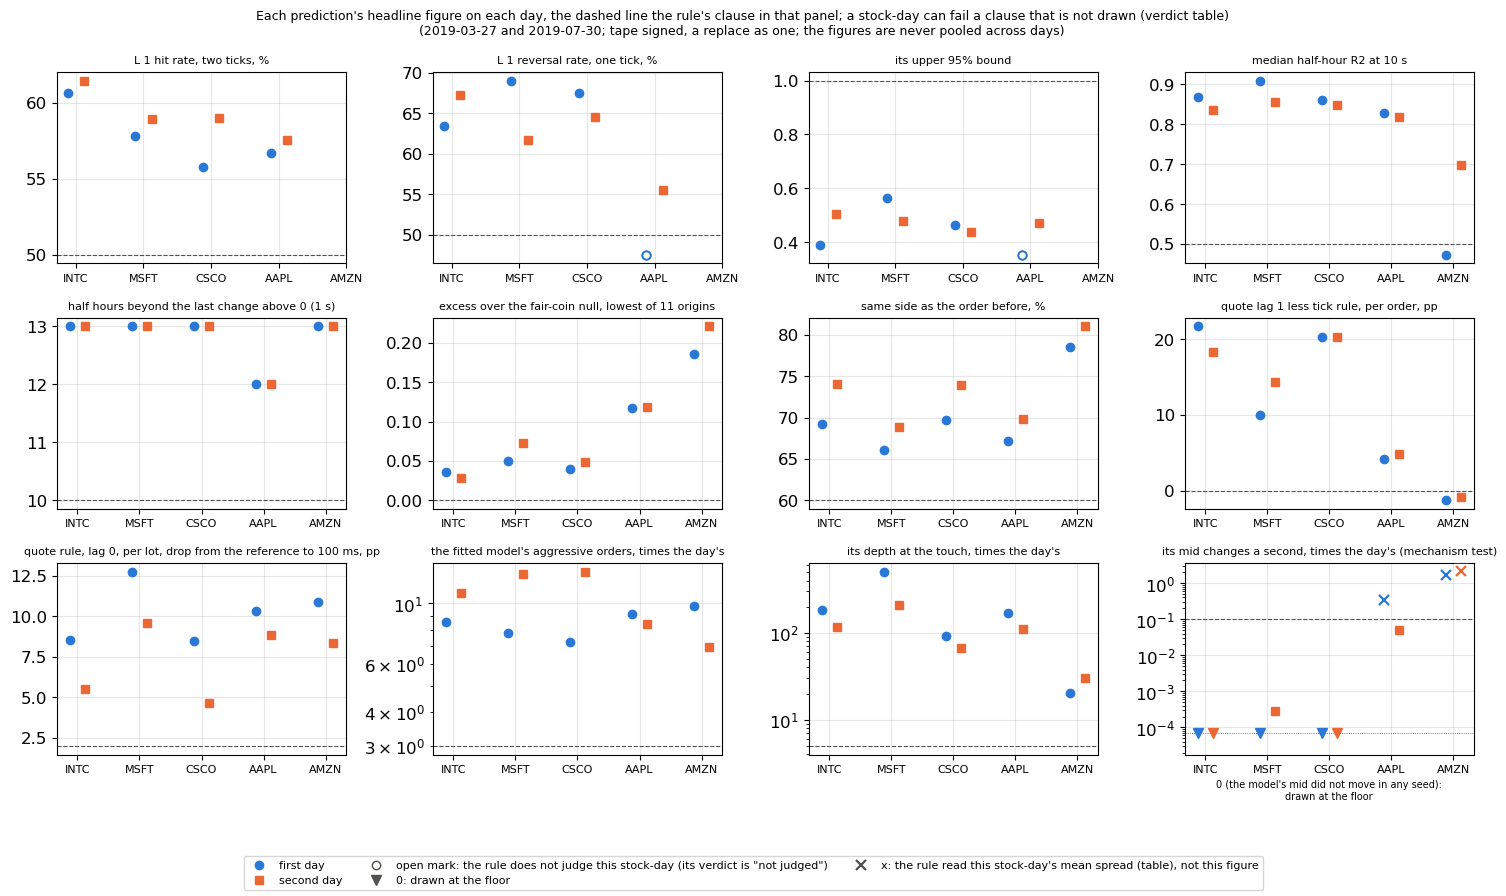

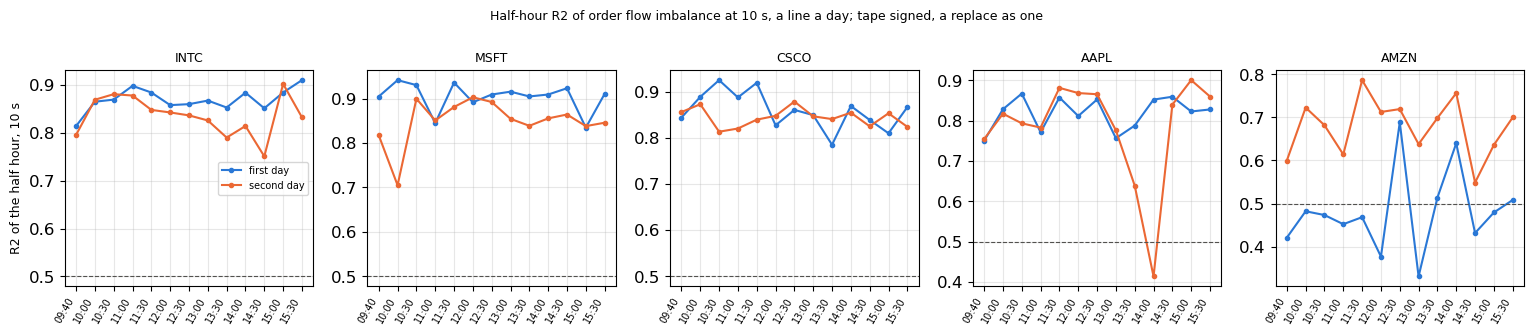

In [46]:
# Section 6: each prediction's headline figure on the first day beside the same figure on the second, and the figures
# that draw them. Needs this section's machinery, run and verdicts. With the data absent it prints one line. The two
# days are side by side and never pooled: no mean, no sum and no test across them, and nothing is retuned between
# them.
if two_ready():
    say(
        f'\nThe headline figure of each prediction and the three rates, {day_text(DAY)} | {day_text(SECOND_DAY)}, '
        f'session {SESSION_START} to {SESSION_END}, {convention()}.'
    )
    say(
        'A cell is the first day\'s figure, then the second\'s. A figure that a day does not give (a spread class '
        f'under {MIN_READINGS} readings, a rule that does not apply) is "-". Every figure is a stock\'s own on the day '
        'it is of; the rates are beside every figure, and the same stock\'s two days are what is compared, never two '
        'stocks. VPIN\'s V is 50 times the median of each stock-day\'s own first 200 fills, so VPIN\'s levels are not '
        'comparable across the two days (V and the fills a bucket are printed beside them); the sign of the excess '
        'over the null is, because the null uses the same fills. A stock-day that was refused by lob.itch or failed is '
        'not in this table (it is said under the section\'s run and is never replaced).'
    )
    print(two_headline_table(two_judged_first, two_judged_second, read_by_a_prediction=True).to_string())
    two_figure(two_judged_first, two_judged_second, verdicts=(two_verdicts_first, two_verdicts_second))
    two_strip_figure(two_judged_first, two_judged_second)

**The verdicts.** Cell 83 prints each prediction's verdict on each stock-day with the figures the rule read, and under them the number of stocks that passed it. A prediction is held on both days by a stock only where its rule passes on both; a stock that is not judged on a day does not hold it. Counted a prediction at a time, in the order of the predictions cell, with the stocks judged and passed on the first day, on the second and on both:

- *Hit rate.* 5 of 5 passed on the first day, 5 of 5 on the second, and all five hold it on both days (INTC, MSFT, CSCO, AAPL, AMZN). Two of the ten verdicts sit on their line. AMZN's first day is a class of three ticks or more with a hit rate of 50.4% on 67,851 readings (+1.0 se, se 0.4, half hours 47.7 to 52.2), and MSFT's second day rests on a class of 466 readings at 58.2% (+1.9 se, se 4.3).
- *Reversal rate.* Judged on 3 stocks on the first day and 4 on the second, passed on 3 and 4, and held on both days by INTC, MSFT and CSCO, the three judged on both. AAPL is judged on the second day only (one tick 55.5% of 25,123 readings, two ticks 47.2%), because one tick holds 20.7% of its first day and 54.2% of its second; "held on both days" is not said of AAPL. AMZN holds one tick 0.0% of both days and is not judged on either.
- *One-tick lift.* Judged on 3 stocks and then 4, passed on 2 and then 2, and held on both days by CSCO alone: +0.02 points, interval -0.20 to +0.26, on the first day and +0.26, +0.00 to +0.44, on the second. Both intervals lie inside the rule's band of -1 to +1 with room to spare (the second day's ends 0.56 inside +1, a plain difference), so neither pass sits on the rule's line. The margin line that the cell prints under this verdict measures from 0, which no rule reads: the interval beside it is what the rule read. INTC and MSFT passed on one day and not on the other, AAPL was judged on the second day only and AMZN on neither. INTC did not pass on the first day, with -1.49 points on 5,780 readings, interval -2.30 to -0.76 and the two calls differing at 8.9%, and passed on the second, with +0.16, +0.04 to +0.29, the calls differing at 0.4%; the first day's interval ends at -0.76 against the line of -1, so that verdict sits on its line. MSFT passed on the first day, with +0.03, -0.10 to +0.14, and did not pass on the second, with +1.79 on 13,119 readings, +0.19 to +3.43, the calls differing at 9.0%; the second day's interval crosses +1 as INTC's first-day interval crosses -1 (its lower end, +0.19, is inside the line and its upper end, +3.43, outside it), so that verdict sits on its line in the same way, and Table 7d's strip has the paired lift at +7.8 and +3.7 in the first two half hours and between -0.9 and +1.5 in the other eleven. AAPL was not judged on the first day and did not pass on the second, with +6.10 on 25,123 readings, +4.11 to +7.93, the calls differing at 41.4%.
- *Queue race.* Judged on 3 and then 4, passed on 3 and then 4, held on both days by INTC, MSFT and CSCO. AAPL is judged on the second day only (upper 95% bound 0.47), and AMZN on neither. The judged upper bounds run from 0.39 to 0.56 on the first day and from 0.44 to 0.50 on the second, against the rule's line of 1.
- *Order flow imbalance.* Judged on 5, passed on 4 and then 5, held on both days by INTC, MSFT, CSCO and AAPL. AMZN did not pass on the first day, with a median half-hour R2 at 10 s of 0.473 against the line of 0.50 (-1.4 se, se 0.019, half hours 0.331 to 0.688), and passed on the second, with 0.699 (+7.4 se). The first day's verdict sits on its line. The partial correlation beyond the last change at 1 s is positive in 13 of 13 half hours on every stock-day but AAPL's two (12 of 13 on each), against a line of 10.
- *VPIN.* 5 of 5 on both days, held by all five: the excess over the fair-coin null is above 0 at all 11 bucket origins on all ten stock-days, and 66.1% to 81.0% of aggressive orders are on the side of the one before, against a line of 60%. The verdict's sentence "the lowest is +X null standard deviations" gives the figure of the origin with the lowest excess. The lowest figure over the 11 origins is the column that cell 38 prints and cell 87 prints for the second day, and the two are the same on every stock-day but AAPL's and AMZN's first (+34.0 and +28.4 in the verdict, +28.6 and +27.0 in the table). The margin line's range under each verdict is over the 11 origins. The lowest origin of INTC and CSCO on the second day, +2.8 and +2.9 null standard deviations, sits close to its line of 0.
- *Signing.* Judged on 5, passed on 4 on each day, held on both days by INTC, MSFT, CSCO and AAPL. The lag-0 check had no miss on any of the ten stock-days (no miss in 8,662 to 47,541 fills a stock-day). AMZN's quote rule at lag 1 is below the tick rule on both days, 87.41% against 88.67% on the first (-1.26 points, -2.7 se) and 89.70% against 90.48% on the second (-0.78, -1.4 se); both verdicts sit on their line.
- *Calibration.* 5 of 5 on both days, held by all five. B is at its bound on all ten stock-days, the fitted model has x6.9 to x13.1 the day's aggressive orders (line 3), and its depth at the touch, read in shares at `CALIBRATION_LOT`, is x20.2 (AMZN, first day) to x504.6 (MSFT, first day) the day's (line 5). The model's own unit is the order, and the ratios in orders are section 7's Table 7f (asked for after the run, judged by no rule); AMZN's x20.2 and x30.2 are in shares, not in orders.
- *Calibration's mechanism.* Judged on 5 on each day, passed on 3 and then 5, held on both days by INTC, MSFT and CSCO, where one tick holds more than half of each day and the fitted model's mid changes a second are x0.000 the real day's (line 0.1). AAPL did not pass on the first day, with the fitted model's mean spread x0.543 the real day's (line 1 within 0.2, because one tick holds 20.7% of that day): the real half hours' spread is 1.56 to 2.85 ticks and the model's is 1.16 (seeds 1.16 to 1.17), with 83.5% of its seconds at one tick against the real day's 20.7% (cell 77's Table 7), so that failure is the model's. AAPL passed on the second day on the other branch of the rule: one tick holds 54.2% of that day, so the rule read the model's mid changes a second, x0.050 the real day's, and that pass is the gate's and not the model's success (the mean spread, which the rule did not read that day, is x0.69 the real day's). AMZN did not pass on the first day, with the mean spread x0.733, and passed on the second, with x0.914, against 0.8 to 1.2. The first day's ratio sits on its line with a day whose spread moves through the session: the real half hours run from 75.00 ticks at 09:40 to 38.52 ticks at 15:30 (mean 53.30) and the model's run from 37.99 to 40.22 (mean 39.09), as cell 77 prints them. The second day's ratio, the other verdict on that line, has no half-hour strip in the notebook.
- *Ladder.* Judged on 5, passed on 4 and then 3, held on both days by CSCO and AMZN. The quote clause (a lower lag-0 quote rule per lot at 100 ms by 2 points or more) is met on all ten stock-days, by 4.7 to 12.7 points, and the median half-hour R2 at 10 s is lower at 100 ms than on the reference on all ten. The three verdicts that do not pass are those of the clause "half the drop or more already at 1 ms". MSFT did not pass on the first day (medians 0.909, 0.869 and 0.828 for the reference, 1 ms and 100 ms; share of the drop at 1 ms 0.493) and passed on the second (0.854, 0.809 and 0.772; 0.552). INTC passed on the first day (0.867, 0.810, 0.805; 0.919) and did not on the second (0.836, 0.788, 0.719; 0.415). AAPL passed on the first (0.828, 0.763, 0.703; 0.521) and did not on the second (0.818, 0.791, 0.674; 0.184). Five verdicts of the ladder sit on the line of that clause, those of MSFT on both days, INTC's second, AAPL's first and AMZN's first (0.571); section 7's Table 7e has the shares of resampled half hours beside them, asked for after the run and judged by no rule, and the clause is not a finding either way where its verdict sits on its line. The other five are not near it: INTC's first day, CSCO's two and AMZN's second are met in 0.93 to 0.98 of the resamplings, and AAPL's second day is missed, at 0.184 of the drop at 1 ms and in 0.03 of the resamplings.

Held on both days for all five stocks: the hit rate, VPIN and the calibration. Held for some: the reversal rate and the queue race (INTC, MSFT and CSCO, the three judged on both days), the one-tick lift (CSCO of the 3 judged on both days), order flow imbalance and signing (4 of 5 each), the mechanism (3 of 5) and the ladder (2 of 5). Held for none of the stocks: no prediction. These are counts of stocks, a prediction at a time, and nothing wider. The five stocks share each day's market factor, so "5 of 5 on both days" is one measurement twice and not ten confirmations, and a prediction that nearly every liquid stock passes (the hit rate, the calibration's two ratios, an excess above 0) is not a test of notebook 14's simulator by passing. No stock is said to differ from another, and no regime is named for either day.

**The figures beside each other.** Cell 84's table gives each prediction's headline figure on the first day and then on the second (a pair "first | second"), with the three rates, and its first figure draws one clause of most of the predictions, one in each panel (the one-tick lift and the calibration's B at its bound are in the table and not drawn): a dot is the first day and a square the second, the dashed line is the rule's line in that panel, and nothing is pooled across the days. An open mark is a stock-day that the rule does not judge (its verdict is "not judged"): AAPL's first day in the reversal-rate panel and in the panel of the queue race's upper bound. In the last panel, the fitted model's mid changes a second as a multiple of the real day's against the line of 0.1, an x means that the rule read that stock-day's mean spread and not this figure (AAPL's first day and AMZN's two days; the mean spread's ratios are in the table), and a triangle at the floor of the axis is a ratio of 0 (INTC and CSCO on both days and MSFT on the first: the model's mid did not move in any seed). MSFT's second-day ratio prints as 0.000 and is drawn just above the floor, so it is not exactly 0. A panel draws one clause, and a stock-day can fail a clause that is not drawn: the ladder's three failures are of the clause of the half hours' R2, and the ladder's panel draws the quote clause. The second figure draws each half hour's R2 of order flow imbalance at 10 s, a line a day; the strips are Table 7d's in section 7. Every difference below is a plain difference of two printed figures, in the figure's own units, and the line is the rule's.

- *Hit rate, two ticks (line 50, in %).* INTC 60.7 | 61.5, MSFT 57.8 | 58.9, CSCO 55.8 | 59.0, AAPL 56.7 | 57.6: each is above the line on both days and each moved away from it, by 0.8, 1.1, 3.2 and 0.9 points. AMZN's three-or-more class, 50.4 | 54.5, moved away from the line by 4.1 points; its first day sits on the line.
- *Reversal rate, one tick (line 50, in %).* INTC 63.5 | 67.3 moved away by 3.8 points, MSFT 69.0 | 61.7 toward it by 7.3 and CSCO 67.5 | 64.5 toward it by 3.0, all above it on both days. AAPL's 47.5 (not judged) | 55.5 is the one pair where the rule is read on one day only.
- *Queue race, upper 95% bound (line 1).* INTC 0.39 | 0.50, MSFT 0.56 | 0.48, CSCO 0.47 | 0.44 and AAPL 0.35 (not judged) | 0.47. INTC's moved toward the line by 0.11, MSFT's away by 0.08 and CSCO's away by 0.03, and no stock's figure comes near the line on either day.
- *Order flow imbalance, median half-hour R2 at 10 s (line 0.50).* INTC 0.867 | 0.836, MSFT 0.909 | 0.854, CSCO 0.861 | 0.847 and AAPL 0.828 | 0.818 each moved toward the line, by 0.031, 0.055, 0.014 and 0.010, and stay far above it. AMZN's 0.473 | 0.699 moved by 0.226, from below the line to above it. The half hours beyond the last change above 0 at 1 s (line 10 of 13) are 13 | 13 for INTC, MSFT, CSCO and AMZN and 12 | 12 for AAPL.
- *VPIN, excess of the lowest of 11 origins (line 0).* INTC +0.035 | +0.028, MSFT +0.050 | +0.072, CSCO +0.040 | +0.048, AAPL +0.117 | +0.118 and AMZN +0.186 | +0.221, above 0 on both days. VPIN's size is not compared across the days: V is 50 times the median of each stock-day's own first 200 fills (V is 5,000 | 4,975 shares for INTC and 450 | 875 for AMZN, and the fills a bucket differ), and only the sign of the excess is the same quantity on both. The same-side share (line 60%) is 69.2 | 74.1, 66.1 | 68.8, 69.7 | 74.0, 67.1 | 69.8 and 78.5 | 81.0, higher on the second day for each stock, by 4.9, 2.7, 4.3, 2.7 and 2.5 points.
- *Signing, quote rule at lag 1 less the tick rule, per order (line 0, in points).* INTC +21.72 | +18.26, MSFT +10.01 | +14.35, CSCO +20.34 | +20.25, AAPL +4.24 | +4.81 and AMZN -1.26 | -0.78. INTC's moved toward the line by 3.46 points, MSFT's away from it by 4.34, CSCO's toward it by 0.09, AAPL's away from it by 0.57 and AMZN's toward it by 0.48 without crossing it; AMZN's two sit on the line, as above. The lag-0 quote rule is 100.00% on every stock-day, which is the conversion's check.
- *Ladder, drop of the lag-0 quote rule per lot from the reference to 100 ms (line 2, in points).* INTC 8.5 | 5.5, MSFT 12.7 | 9.6, CSCO 8.5 | 4.7, AAPL 10.3 | 8.8 and AMZN 10.9 | 8.3, smaller on the second day for each stock by 3.0, 3.1, 3.8, 1.5 and 2.6 points, and above the line on both days. The median R2 at 10 s at 100 ms is below the reference on all ten stock-days, by 0.02 (AMZN, first day) to 0.14 (AAPL, second day).
- *Calibration (lines 3 and 5).* The fitted model's aggressive orders, as a multiple of the day's, are 8.6 | 10.9, 7.8 | 12.8, 7.2 | 13.1, 9.1 | 8.4 and 9.8 | 6.9; its depth at the touch, in shares at `CALIBRATION_LOT`, 184.4 | 117.0, 504.6 | 207.4, 91.0 | 66.9, 170.1 | 112.0 and 20.2 | 30.2. All are above their lines on both days.
- *Mechanism.* The model's mid changes a second are x0.000 | x0.000 the real day's for INTC, MSFT and CSCO, x0.341 | x0.050 for AAPL and x1.675 | x2.129 for AMZN; the mean spread, x1.00 | x1.00, x0.91 | x0.83, x1.00 | x0.99, x0.54 | x0.69 and x0.73 | x0.91. Where the rule read the mean spread (AAPL on the first day and AMZN on both), the line is 1 within 0.2: AAPL's x0.54 on the first day is outside it, and AMZN's x0.73 | x0.91 moved by 0.18 from outside it to inside it, the first day's sitting on the line.

The three rates beside every figure, first day | second day, are events a second 57.54 | 30.91 (INTC), 86.37 | 47.47 (MSFT), 44.86 | 21.12 (CSCO), 78.73 | 48.06 (AAPL) and 49.51 | 14.52 (AMZN); mid changes a second 0.515 | 0.301, 2.899 | 1.260, 0.463 | 0.192, 6.246 | 2.763 and 3.808 | 1.913; and aggressive orders a second 0.425 | 0.310, 1.121 | 0.555, 0.434 | 0.188, 1.481 | 1.080 and 0.684 | 0.505. Each of the three rates is lower on the second day for each stock, and the second day's events a second are 0.29 (AMZN) to 0.61 (AAPL) of the first day's (ratios of two printed figures). This says that the second day was quieter, and nothing about why.

**What the second day did to the findings of sections 2 and 3.** The first day's figures suggested the signs and orderings below, and each is set beside the second day's, a stock at a time. The simulator's figures (notebook 14's five models, whose mid changes a unit run from 1.48 to 5.06) are a description of what those models give, and nothing is called a match.

- *Imbalance, hit rate by spread class.* The hit rate is above 50% in every class with 200 readings or more on all ten stock-days. At one tick it is 62.0 | 67.4 (INTC), 69.1 | 63.5 (MSFT), 67.6 | 64.8 (CSCO) and 59.4 | 61.6 (AAPL); at two ticks 60.7 | 61.5, 57.8 | 58.9, 55.8 | 59.0 and 56.7 | 57.6; at three or more 54.2 | 60.0 for AAPL, 50.4 | 54.5 for AMZN, and 58.2 for MSFT on the second day (a class of 466 readings; under 200 on the first day).
- *Imbalance, reversal rate by spread class.* At one tick it is above 50% on every judged stock-day, as the first day had it (INTC 63.5 | 67.3, MSFT 69.0 | 61.7, CSCO 67.5 | 64.5, AAPL 55.5 on the second day only), and at two ticks it is below 50% on all four stocks with a class (INTC 23.1 | 36.6, MSFT 38.6 | 40.9, CSCO 15.5 | 26.6, AAPL 46.8 | 47.2). AAPL's one-tick reversal rate is 47.5% on the first day, below 50, and 55.5% on the second, above it, with one tick held 20.7% and then 54.2% of the day: one tick is not one regime, and the rule judges AAPL on different clauses on its two days.
- *Imbalance, one-tick lift.* On INTC's second day, MSFT's first day and CSCO's two days the one-tick hit rate and reversal rate are one figure (INTC's second day 67.4% and 67.3%, MSFT's first day 69.1% and 69.0%, CSCO 67.6% and 67.5% and then 64.8% and 64.5%), the two calls differing at 0.4%, 1.2%, 0.4% and 1.9% of the readings. On INTC's first day they differ at 8.9% and the lift is -1.49 (interval -2.30 to -0.76), which the rule does not pass; on MSFT's second day the calls differ at 9.0% and the lift is +1.79 (+0.19 to +3.43), and on AAPL's at 41.4% and +6.10 (+4.11 to +7.93), and the rule passes neither (AAPL's first day, +11.9 on 23,341 readings, is not judged: one tick holds 20.7% of it). The lift is positive there. The notebook does not claim that the imbalance beats the reversal rate at one tick: where the lift is near 0 the two are one measurement read twice, and where it is not, section 7's Table 7c shows where it sits (asked for after the run, judged by no rule). AAPL's second day lies in the range of the simulator's rates (2.763 mid changes a second) and its hit rate above its reversal rate at one tick (61.6% and 55.5%, a lift of +6.1) has the ordering of the simulator's, whose one-tick lifts are +1.9 to +8.3 points on hit rates of 80.2% to 90.6%. The +6.1 is a mixture: Table 7c puts it in the readings whose scored change came within 1 ms (+32.02 on 5,996 readings, 23.9% of the class), and in the other two bands the lift is -0.15 (1 ms to under 100 ms) and -3.48 (100 ms or more), so the +6.1 is not the lift of one kind of reading (no rule reads a band). In the tables of cell 86 the column "se, hit less day baseline" is not the lift's standard error; the paired lift's is section 7's Table 7b, and the replace's echo, which the strict design reads, is its Table 7a's (both asked for after the run and judged by no rule).
- *Imbalance, two ticks.* The hit rate is above 50% and the reversal rate below it on the second day for INTC, MSFT, CSCO and AAPL, as on the first, and the lift over the reversal rate is positive on all four (+24.8, +18.0, +32.4 and +10.4 on the second day). INTC's and CSCO's two-tick figures come from spells that mostly end within a millisecond (Table 7c: the shares of two-tick readings in the band under 1 ms), and they do not describe two-tick spreads that last. MSFT's two-tick class is 55.0% and 43.3% in that band, and its readings in spells of 100 ms or more give a lift of -3.07 and -3.00.
- *Queue race.* The upper 95% bound is under 1 on every judged stock-day, as on the first day: 0.39, 0.56 and 0.47 for INTC, MSFT and CSCO then, 0.50, 0.48, 0.44 and 0.47 for INTC, MSFT, CSCO and AAPL now. The amplitude a at one tick is 0.352 | 0.453 (INTC), 0.530 | 0.447 (MSFT) and 0.426 | 0.392 (CSCO), and AAPL's 0.421 is judged on the second day only. Section 7's Table 7a prints the bounds as kept and does not refit the race; they are far from the line.
- *Order flow imbalance.* The median half-hour R2 at 10 s is above 0.50 on every stock-day but AMZN's first, and AMZN's second day is 0.699. The partial correlation beyond the last change at 1 s is positive in 13 of 13 half hours on both days for INTC, MSFT, CSCO and AMZN and in 12 of 13 for AAPL. AAPL's second-day half hours run from 0.414 to 0.901 around a median of 0.818, and the strips are Table 7d's.
- *VPIN.* The excess is above 0 at all 11 origins on each stock on the second day, +0.028 to +0.051 (INTC), +0.072 to +0.082 (MSFT), +0.048 to +0.082 (CSCO), +0.118 to +0.128 (AAPL) and +0.221 to +0.232 (AMZN), as on the first day, and the same-side share is 74.1%, 68.8%, 74.0%, 69.8% and 81.0%. VPIN is first defined at 09:51:35 for INTC and at 10:32:11 for CSCO on the second day, after the session's start at 09:40, so it is defined over 96.9% and 85.9% of that day's units (cell 87). The excess is how persistent the order signs are, with the same-side share beside it, and it is not informed trading: the excess over the null that permutes the true signs among the orders is also above 0 on the second day, +0.048, +0.073, +0.034, +0.086 and +0.217. Sizes are not compared across the days.
- *Signing.* The quote rule at lag 1 is above the tick rule on the second day for INTC (88.68% against 70.43%), MSFT (84.98% against 70.63%), CSCO (89.68% against 69.42%) and AAPL (81.86% against 77.05%), as on the first, and below it for AMZN on both days. AAPL's second day lies in the range of the simulator's rates, and there, per fill, the quote rule at lag 1 is 84.09% and the tick rule 80.38%, the opposite ordering to four of notebook 14's five models, in which the quote rule at lag 1 is below the tick rule (and above it by 0.7 in MF 2008); AMZN's second day, also in range, has them 91.55% and 92.18% per fill, the simulator's ordering by 0.63 points, a margin that sits on the rule's line as above. MSFT's second day, at 1.260 mid changes a second, lies under the simulator's range and no comparison is made. As the predictions cell cautions, where a stock's mid moves only a fraction of a change a second the quote rule at lag 1 is almost the lag-0 rule, and a contrast with the simulator measures how fast the mid moves more than anything about signing.

A figure near its rule's line is as much a statement about the line as about the stock, on either day, and none of this is a count of independent results: the five stocks share each day's market factor.


Section 1 again, the tape, on 2019-07-30.

What each stock-day holds: 2019-07-30, session 09:40:00 to 15:50:00, a replace counted as one and as two, and three
tapes, as each column says.

What the session holds (rows of the frames; events of the stream, a replace counted as one and as two):
           rows     adds part cancels deletions executions replace rows events, as one events, as two aggressive orders hidden trades unsigned runs
INTC    725,546  360,160        2,719   346,554     16,113       59,944        686,210        716,182             6,875         2,138         1,436
MSFT  1,111,908  550,079        8,656   531,402     21,771       96,624      1,053,865      1,102,177            12,316         3,564         2,750
CSCO    492,995  241,334        8,967   233,869      8,825       38,672        468,924        488,260             4,165         1,710         1,329
AAPL  1,134,362  563,056        1,332   529,104     40,870      100,608      1,066,922      1,117,226            23

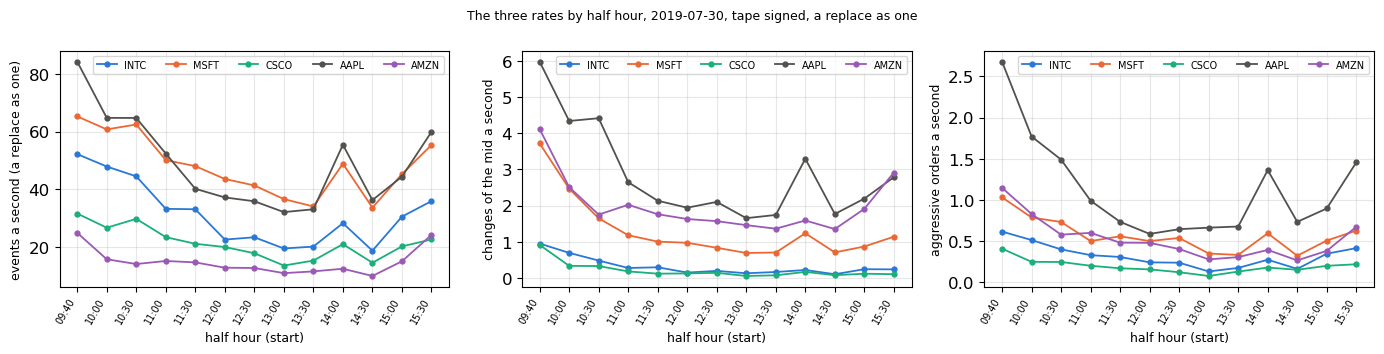


Section 2 again, the imbalance and the next move, the queue race and order flow imbalance, on 2019-07-30.

L 1, the queue imbalance at the touch: the next change of the mid against the sign of the first nonzero imbalance after
the last: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace as one.
Strict design (the first event that leaves the mid alone gives the reading), a next change within 30 s, by the spread at
the reading. Lifts in points over 50%, over the reversal rate (predict minus the last change) and over the better of the
two, which binds IN THE CLASS; a class under 200 readings is a count only. calls differ: the share of readings at which
the imbalance's call and the reversal call point in different directions; the hit rate and the reversal rate cannot
differ by more than that, so where it is small they are one measurement read twice and the lift over the reversal rate
is bounded by it. se, blocks: the lift's block-bootstrap standard error (1,000 draws, ASSUMI

                one tick                                           wider                                    
            scored a run       hit %  reversal %    lift pp scored a run       hit %  reversal %     lift pp
ZI                 3,476  89.1 (0.2)  87.0 (0.3)  2.2 (0.1)        9,538  64.5 (0.1)  55.5 (0.1)   9.0 (0.2)
Hawkes ZI          2,936  90.1 (0.2)  88.3 (0.2)  1.9 (0.1)        8,780  65.6 (0.2)  56.3 (0.2)   9.3 (0.3)
MF 2008            1,300  84.3 (0.5)  82.0 (0.4)  2.3 (0.2)        3,443  60.3 (0.3)  53.4 (0.3)   6.9 (0.4)
Parlour            1,313  80.2 (0.3)  71.9 (0.6)  8.3 (0.4)        7,876  67.0 (0.2)  55.5 (0.2)  11.5 (0.3)
Informed ZI        3,696  90.6 (0.1)  88.5 (0.2)  2.1 (0.1)       12,615  65.7 (0.1)  56.4 (0.2)   9.3 (0.2)



The imbalance beyond the touch: the lift over the better baseline, by the spread at the reading: 2019-07-30, session
09:40:00 to 15:50:00, tape signed, a replace as one.
Levels 3, 5 and 10 with equal and touch weights (L 1 equal and touch are one number: the first level's weight is 1).
Points; in brackets the baseline that binds in the class (rev: the reversal rate, 50: 50%) and the readings; a class
under 200 readings is a count only.
                           one tick          two ticks      three or more
INTC L 3 equal    -3.2 (rev, 3,145)   +7.3 (50, 2,871)              n = 2
     L 3 touch    +0.1 (rev, 3,145)  +10.2 (50, 2,871)              n = 2
     L 5 equal    -5.6 (rev, 3,145)   +5.6 (50, 2,871)              n = 2
     L 5 touch    +0.4 (rev, 3,145)  +10.3 (50, 2,871)              n = 2
     L 10 equal  -11.6 (rev, 3,145)   +6.1 (50, 2,871)              n = 2
     L 10 touch   +0.2 (rev, 3,145)  +10.5 (50, 2,871)              n = 2
MSFT L 3 equal   -1.1 (rev, 13,130)  +4.3

              L 1 equal   L 1 touch   L 3 equal  L 3 touch   L 5 equal  L 5 touch  L 10 equal L 10 touch
ZI            7.2 (0.1)   7.2 (0.1)  -1.2 (0.1)  1.4 (0.1)  -1.7 (0.1)  1.4 (0.1)  -2.1 (0.1)  1.4 (0.1)
Hawkes ZI     7.4 (0.2)   7.4 (0.2)  -0.0 (0.2)  3.2 (0.2)  -1.1 (0.2)  2.9 (0.2)  -1.8 (0.2)  2.9 (0.2)
MF 2008       5.6 (0.3)   5.6 (0.3)  -0.8 (0.2)  1.3 (0.2)  -0.8 (0.3)  1.7 (0.2)  -7.5 (0.1)  2.2 (0.2)
Parlour      11.1 (0.2)  11.1 (0.2)   2.1 (0.2)  4.3 (0.1)   0.1 (0.2)  3.6 (0.1)  -4.1 (0.1)  3.7 (0.2)
Informed ZI   7.7 (0.2)   7.7 (0.2)  -2.5 (0.2)  0.8 (0.2)  -3.7 (0.2)  0.5 (0.2)  -3.8 (0.2)  0.7 (0.2)


              L 1 equal   L 1 touch   L 3 equal   L 3 touch   L 5 equal   L 5 touch  L 10 equal  L 10 touch late (T 30), L 1 inclusive L 1 inclusive touch L 10
ZI           17.3 (0.1)  17.3 (0.1)   8.4 (0.1)   8.2 (0.1)   8.3 (0.1)   8.2 (0.1)   8.2 (0.1)   8.2 (0.1)    0.000 (0.000)    10.2 (0.1)            0.0 (0.0)
Hawkes ZI    19.8 (0.3)  19.8 (0.3)  10.8 (0.2)  10.6 (0.2)  10.8 (0.2)  10.6 (0.2)  10.7 (0.2)  10.6 (0.2)    0.000 (0.000)    10.9 (0.2)            0.0 (0.0)
MF 2008      18.1 (0.2)  18.1 (0.2)  12.3 (0.2)  12.0 (0.1)  12.3 (0.1)  12.0 (0.1)  12.2 (0.1)  12.0 (0.1)    0.000 (0.000)     7.7 (0.1)            0.0 (0.0)
Parlour      52.8 (0.1)  52.8 (0.1)  40.8 (0.1)  39.5 (0.1)  40.3 (0.1)  39.4 (0.1)  40.3 (0.1)  39.4 (0.1)    0.000 (0.000)    25.9 (0.1)            0.0 (0.0)
Informed ZI  20.8 (0.2)  20.8 (0.2)  10.6 (0.1)  10.4 (0.1)  10.5 (0.1)  10.4 (0.1)  10.5 (0.1)  10.4 (0.1)    0.000 (0.000)    12.0 (0.1)            0.0 (0.0)

notebook 14, seeds 101 to 108, touch L 

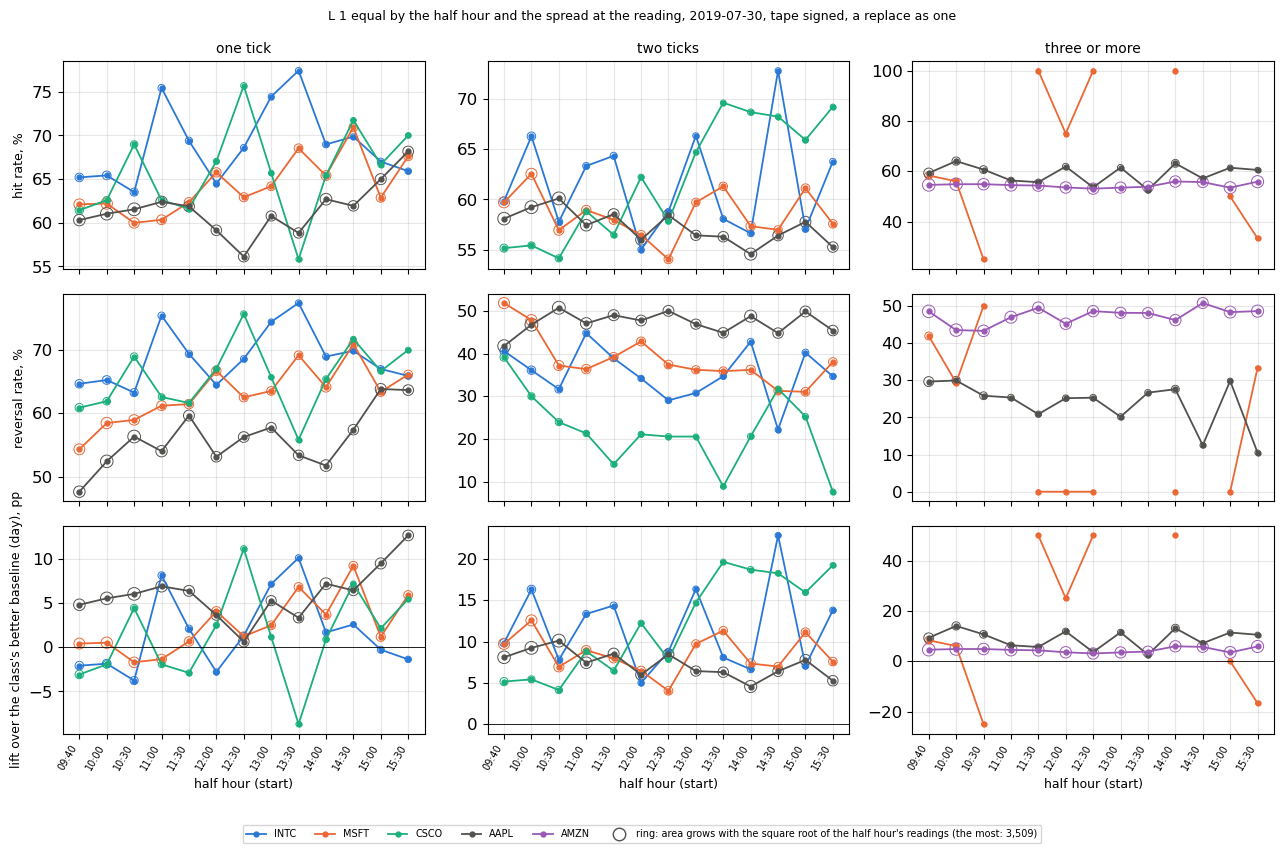


The queue race: the curve for independent queues fitted to the touch imbalance, by spread class: 2019-07-30, session
09:40:00 to 15:50:00, tape signed, a replace as one.
gain: the log-likelihood the curve gains over a constant hit rate (negative: it does worse). a (c = 1): the amplitude of
1/2 + a arctan(|I|) / (2 arctan 1); se and upper 95%: its block bootstrap (200 draws, ASSUMING EXCHANGEABLE BLOCKS), the
upper bound being the 95th percentile of the draws; a, c, both: a and c fitted together (c has no standard error: it
runs to a bound in most resamples). A class under 200 readings is a count only.
                         n hit % gain, c = 1 a (c = 1)    se upper 95% gain, a fitted a, both c, both
INTC one tick        3,145  67.4        -761      0.45  0.02      0.50             34    0.49    0.00
     two ticks       2,871  61.5          -5      0.71  0.08      0.87             18    0.54    2.71
     three or more       2     -           -         -     -         -              

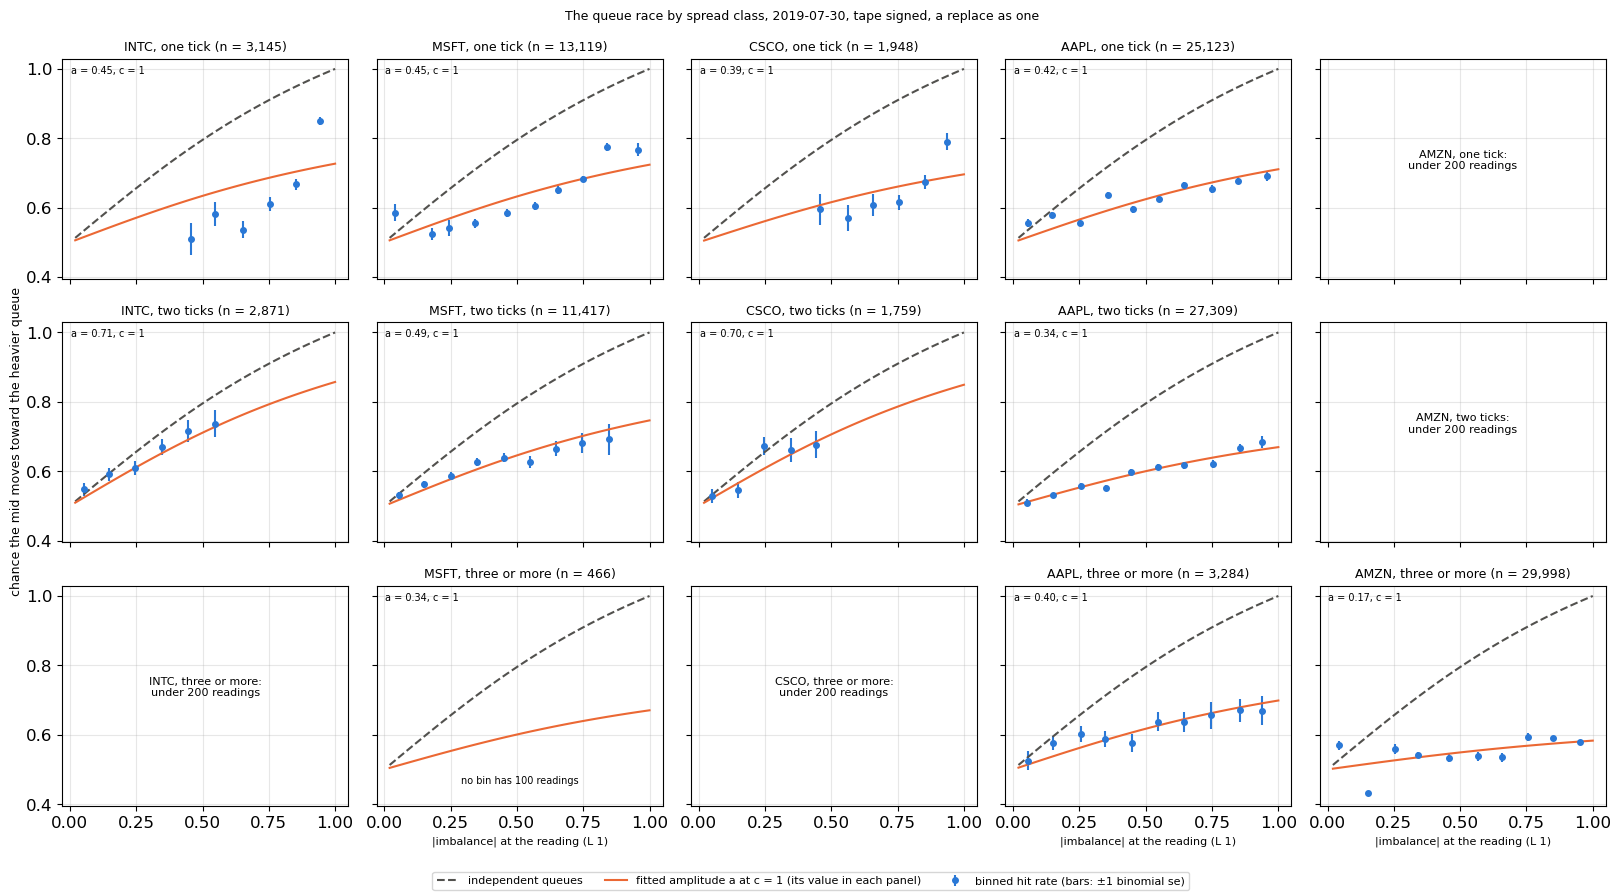


Order flow imbalance: the same-interval R2 of the mid's change on the interval's flow: 2019-07-30, session 09:40:00 to
15:50:00, tape signed, a replace as one.
One increment an event (the best-quote rule of Cont, Kukanov and Stoikov, summed in each interval). THE FIGURE is the
median of the half-hour R2s (13 half hours of the session, from 09:40:00), with its block-bootstrap standard error
(1,000 draws, ASSUMING EXCHANGEABLE BLOCKS) in brackets.
                1 s            5 s           10 s           50 s
INTC  0.717 (0.016)  0.812 (0.019)  0.836 (0.013)  0.903 (0.022)
MSFT  0.727 (0.012)  0.827 (0.016)  0.854 (0.010)  0.900 (0.024)
CSCO  0.726 (0.009)  0.812 (0.010)  0.847 (0.007)  0.895 (0.008)
AAPL  0.752 (0.020)  0.826 (0.028)  0.818 (0.029)  0.860 (0.052)
AMZN  0.577 (0.012)  0.660 (0.018)  0.699 (0.027)  0.695 (0.044)

Half hours with an R2 (of those the session touches):
     1 s 5 s 10 s 50 s
INTC  13  13   13   13
MSFT  13  13   13   13
CSCO  13  13   13   13
AAPL  13  13

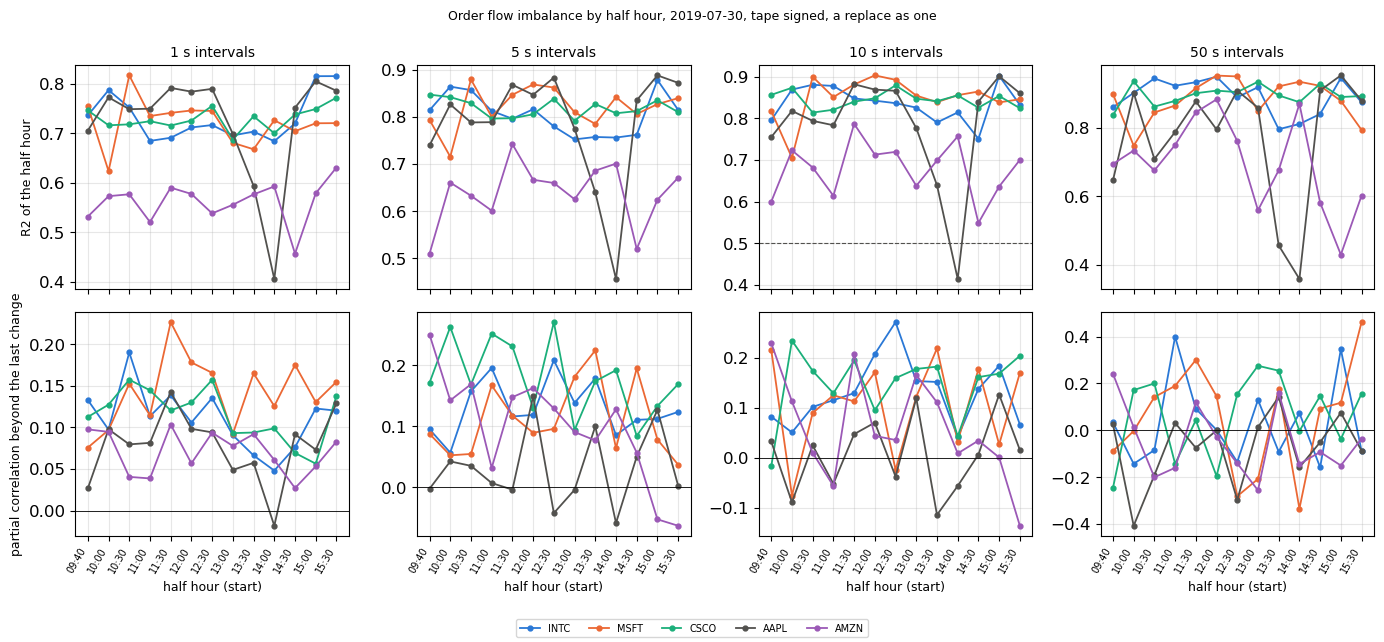

In [47]:
# Section 6: the second day's own tables, section by section, each printed by the function that printed the first
# day's (a function of a dict of results by stock and a day). This cell: the tape and the conversion's checks (section
# 1), the imbalance, the queue race and order flow imbalance (section 2's first half). Needs this section's machinery
# and run. With the data absent it prints one line.
if two_ready():
    say(f'\nSection 1 again, the tape, on {day_text(SECOND_DAY)}.')
    tape_show(two_measures, SECOND_DAY)
    tape_conversion(two_second['checks'], two_measures, SECOND_DAY)
    tape_figure(two_measures, SECOND_DAY)
    say(
        '\nSection 2 again, the imbalance and the next move, the queue race and order flow imbalance, on '
        f'{day_text(SECOND_DAY)}.'
    )
    imb_show_split(two_measures, day=SECOND_DAY)
    imb_show_beyond(two_measures, SECOND_DAY)
    imb_show_strips(two_measures, SECOND_DAY)
    imb_figure(two_measures, day=SECOND_DAY)
    imb_show_race(two_measures, SECOND_DAY)
    imb_race_figure(two_measures, SECOND_DAY)
    ofi_show(two_measures, SECOND_DAY)
    ofi_show_beyond(two_measures, SECOND_DAY)
    ofi_figure(two_measures, SECOND_DAY)


Section 2 again, VPIN, order-to-trade ratios and resilience, on 2019-07-30.

VPIN against its own nulls: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace as one.
displayed executions and the hidden ones a displayed run signs; the unsigned hidden volume never reaches it. V = 50 x the median of the first 200 fills, 50 buckets a window, bucket-weighted level over the buckets closed in the session; nulls on the same fills, 200 draws, seed 1.
                                                                      level fair coin (sd) excess over coin coin sds  shuffled (sd) excess over shuffled shuffled sds level, time-weighted
stock rule                                                                                                                                                                                
INTC  true sides                                                      0.432  0.381 (0.010)           +0.051     +5.0  0.384 (0.012)               +0.048         +4.2  

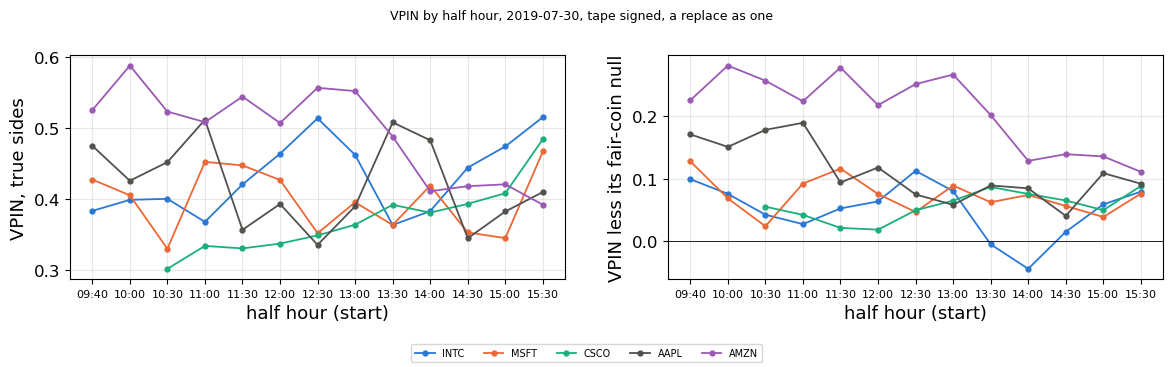


Order-to-trade ratios, messages per aggressive order: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace
as one.
The session's ratio of sums, a replace as one message and as two; "se (blocks)" is a block bootstrap over the half hours (1,000 draws) ASSUMING EXCHANGEABLE BLOCKS (they are not) and "strip se" the half-hour values' own.
     aggressive orders messages, a replace as one replaces OTR, a replace as one se (blocks) strip se OTR, a replace as two TTO, as one TTO, as two
INTC             6,875                    686,210   29,972                  99.8         3.6      4.7                 104.2      0.0359      0.0328
MSFT            12,316                  1,053,865   48,312                  85.6         3.3      3.4                  89.5      0.0348      0.0291
CSCO             4,165                    468,924   19,336                 112.6         5.5      6.7                 117.2      0.0230      0.0201
AAPL            23,971                  1,066,922   50,304 

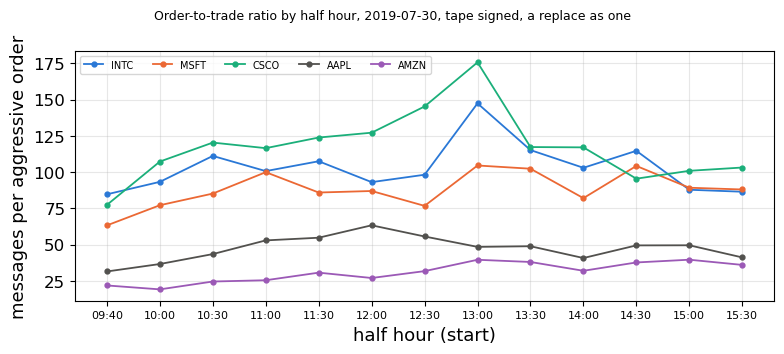


Resilience: recovery of the depth within K ticks of the touch: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a
replace as one.
K = 3 ticks, a tick a cent: "K in spreads" is K over the stock's median spread. An episode begins when a take or a cancel leaves the depth at the K prices from the side's best quote below half its baseline (the median of the last 100 unit samples); it keeps those prices as its anchor and ends recovered when the depth there is back at 0.9 of the baseline, or abandoned when the best quote has moved more than K ticks from the anchor or the side is empty ("abandoned at once": the share of the abandoned that ended in the instant they began). Onset "below" is the dashboard's; "crossing" counts only the falls through the line. The standard errors are a block bootstrap ASSUMING EXCHANGEABLE BLOCKS. Times are seconds.

Onset below the line:
     K in spreads episodes abandoned abandoned at once recovered a second median recovery (s) p90 (s) abandoned se median

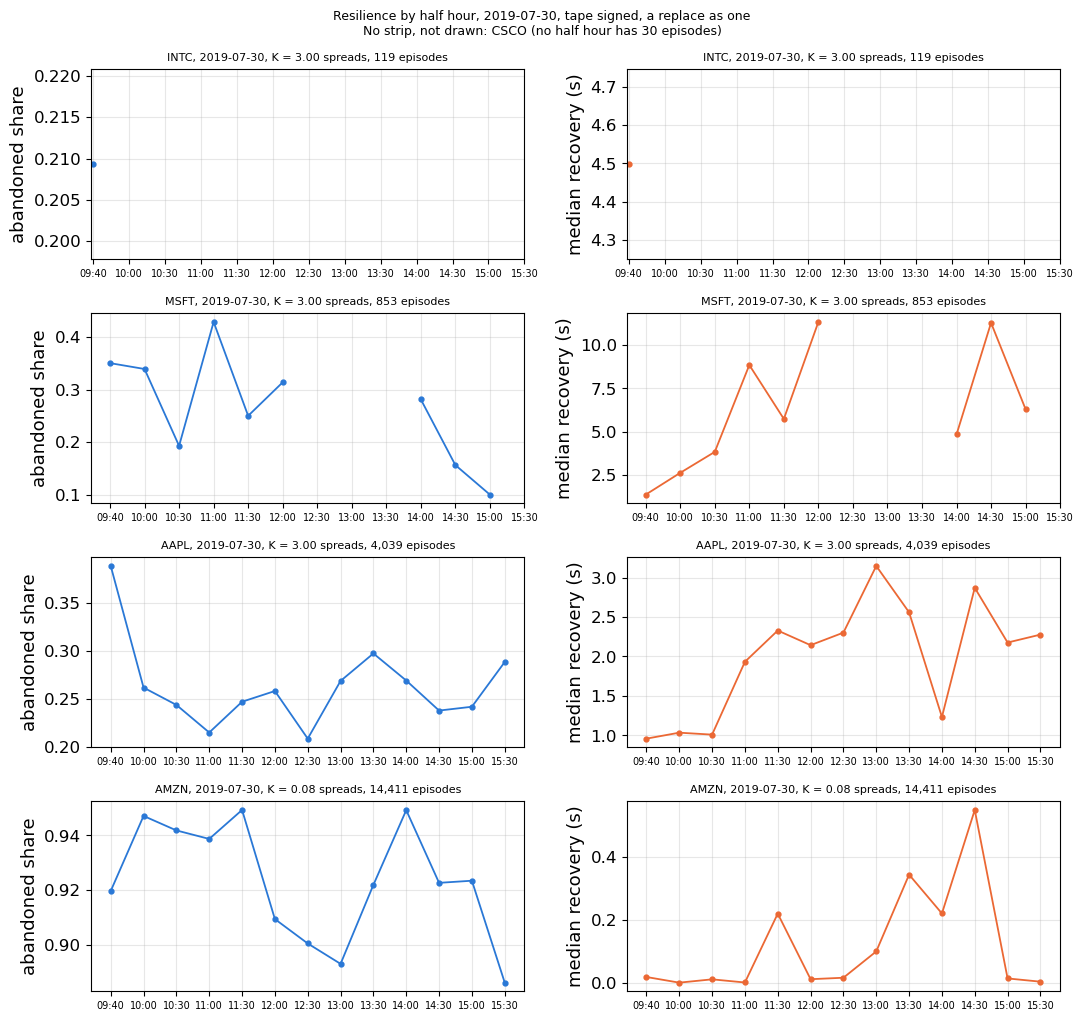


Section 3 again, what is the estimator's, on 2019-07-30.

The look-ahead trap: the sample of the imbalance paired with the change over the same unit and the next: 2019-07-30,
session 09:40:00 to 15:50:00, tape signed, a replace as one.
Sign agreement of the once-a-unit sample with the change of the mid, percent of the units with a change and a reading;
50% is what a sample that knows nothing gives.
                same unit: n same unit % next unit: n next unit % next minus same, pp
INTC L 1 equal         1,807        55.9        1,808        80.4                24.5
     L 10 touch        1,816        57.5        1,815        77.6                20.1
MSFT L 1 equal         6,895        44.4        6,922        68.6                24.2
     L 10 touch        7,122        45.0        7,121        67.7                22.7
CSCO L 1 equal         1,524        44.0        1,516        83.5                39.5
     L 10 touch        1,537        48.4        1,536        81.9                

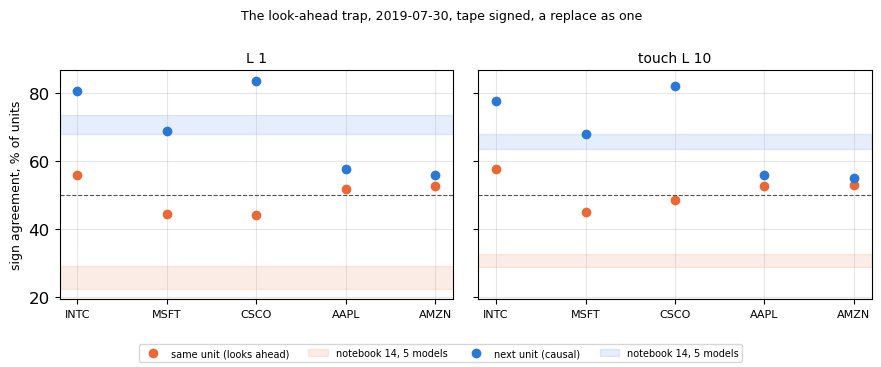


Signing accuracy, per aggressive order, % of displayed executions: 2019-07-30, session 09:40:00 to 15:50:00, tape signed
and none, a replace as one.
rows: the tape the figure is on ("signed": the stream as it is; "none": the same without the hidden executions, which changes the tick rule's price sequence); hidden and unsigned shares are of the shares executed in the session.
             tick rule quote rule, lag 0 quote rule, lag 1 quote rule, lag 5  orders hidden % of shares unsigned % of shares
stock tape                                                                                                                  
INTC  signed     70.43             97.83             88.68             76.81   6,875              10.52                 6.53
      none       69.13             97.82             88.67             76.79   6,875              10.52                 6.53
MSFT  signed     70.63             98.26             84.98             70.72  12,316              16.00                12

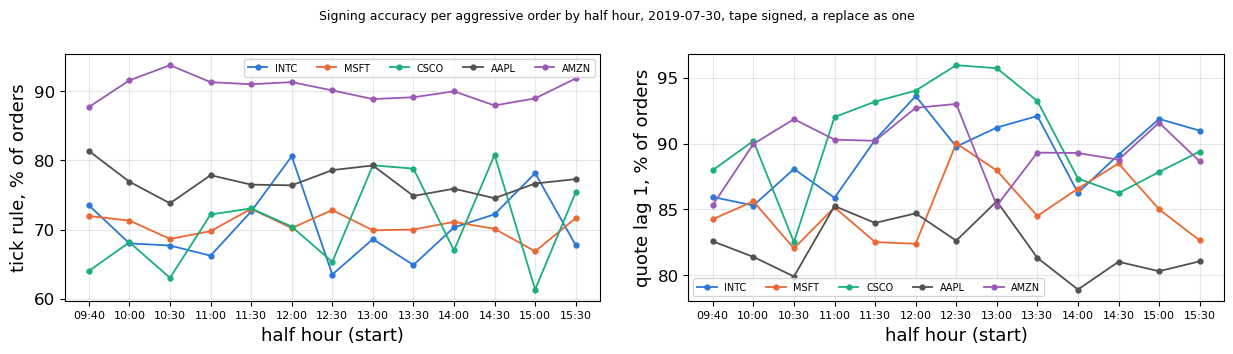


The prediction on signing: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace as one.
rule: the quote rule at lag 0 is exact (no miss at all: 100.00% is not enough) on displayed executions at their resting price, and the quote rule at lag 1 is at least as accurate per aggressive order as the tick rule.
INTC    passed: lag 0 at the resting price: 0 of 15,918 fills, 0 of 6,717 orders and 0.0000% of the lots missed; per order quote lag 1 88.68%, tick 70.43%
MSFT    passed: lag 0 at the resting price: 0 of 21,424 fills, 0 of 12,043 orders and 0.0000% of the lots missed; per order quote lag 1 84.98%, tick 70.63%
CSCO    passed: lag 0 at the resting price: 0 of 8,662 fills, 0 of 4,025 orders and 0.0000% of the lots missed; per order quote lag 1 89.68%, tick 69.42%
AAPL    passed: lag 0 at the resting price: 0 of 40,323 fills, 0 of 23,545 orders and 0.0000% of the lots missed; per order quote lag 1 81.86%, tick 77.05%
AMZN    not passed: lag 0 at the resting price: 0 of 14,251 

In [48]:
# Section 6: the second day's own tables, continued: VPIN, order-to-trade ratios and resilience (section 2's second
# half), the look-ahead trap, the rules that sign trades and bulk volume classification (section 3). Each is printed
# by the function that printed the first day's. Needs this section's machinery and run. With the data absent it prints
# one line.
if two_ready():
    say(f'\nSection 2 again, VPIN, order-to-trade ratios and resilience, on {day_text(SECOND_DAY)}.')
    vpin_report_levels(two_measures, SECOND_DAY)
    vpin_report_origins(two_measures, SECOND_DAY)
    vpin_report_strips(two_measures, SECOND_DAY)
    otr_report(two_measures, SECOND_DAY)
    resil_report(two_measures, SECOND_DAY)
    resil_report_strips(two_measures, SECOND_DAY)
    say(f'\nSection 3 again, what is the estimator\'s, on {day_text(SECOND_DAY)}.')
    trap_show(two_measures, SECOND_DAY)
    trap_figure(two_measures, SECOND_DAY)
    est_report_signing(two_measures, SECOND_DAY)
    est_report_apart(two_measures, SECOND_DAY)
    est_report_bvc(two_measures, SECOND_DAY)

In [49]:
# Section 6: the second day's own tables, continued: the ladder (section 4: the reference and three rungs, as for the
# reported stocks on the first day) and the calibration (section 5: the day's fit and the numbers its two tests read).
# The exploration's rungs and the sweep are not run on the second day, which reads the five reported stocks only. Needs
# this section's machinery and run. With the data absent it prints one line.
if two_ready():
    two_ladder = two_second['ladder']
    two_where = f'{convention("none")}, session {SESSION_START} to {SESSION_END}, unit {UNIT:g} s'
    say(
        f'\nSection 4 again, the ladder, on {day_text(SECOND_DAY)}: the reference and the rungs of {LAD_FIRST} and '
        f'{LAD_LAST} ms and of {LAD_LAST} ms with the trades {LAD_PLUS:+d} ms (a bound, not a venue\'s model); '
        f'{two_where}.'
    )
    print('\nRates a second on each rung:')
    print(shown(lad_rates_table(two_ladder), {'gross OFI a second': ',.0f'}))
    print('\nOrder flow imbalance on each rung, the median half-hour R2 (the figure) at each interval:')
    print(shown(lad_ofi_table(two_ladder)))
    print('\nThe quote rule and the tick rule per lot on each rung:')
    two_signing_frame = lad_signing_table(two_ladder)
    print(
        shown(
            two_signing_frame, {c: '.2f' for c in two_signing_frame.columns if two_signing_frame[c].dtype.kind == 'f'}
        )
    )
    print(f'\nThe ladder\'s prediction on the second day. Rule: {PREDICTIONS["ladder"].rule}.\n')
    print(shown(lad_inputs_table(two_ladder, judge=True)))
    two_cal = two_second['calibration']
    cal_heading('The calibration on the second day: calibrate_lobster for the day', two_cal, SECOND_DAY)
    print(shown(cal_day_table(two_cal)))
    cal_heading('The numbers the calibration\'s two tests read, and their verdicts', two_cal, SECOND_DAY)
    two_summary = pd.DataFrame({stock: cal_summary(detail) for stock, detail in two_cal.items()}).T
    print(
        shown(
            two_summary,
            {'b_at_bound': '', 'aggressive_ratio': '.1f', 'depth_ratio': '.1f', 'mid_changes_ratio': '.3f'}
            | {'spread_ratio': '.3f', 'cancel_ratio': '.1f'},
        )
    )
    print(
        '(cancel_ratio is the estimator\'s window effect, a half hour fitted as a file against the day\'s fit, '
        'and is in no verdict.)'
    )
    for two_test in ('calibration', 'calibration\'s mechanism'):
        print(f'\nRule: {PREDICTIONS[two_test].rule}.')
        for two_stock, two_one in two_judged_second.items():
            two_verdict = PREDICTIONS[two_test].judge(two_one)
            print(f'{two_stock:<8}{two_verdict.status}: {two_verdict.detail}')


Section 4 again, the ladder, on 2019-07-30: the reference and the rungs of 1 and 100 ms and of 100 ms with the trades
+50 ms (a bound, not a venue's model); tape none, a replace as one, session 09:40:00 to 15:50:00, unit 1 s.

Rates a second on each rung:
                  events a second mid changes a second aggressive orders a second gross OFI a second events below reference mid changes below reference
INTC reference             30.910                0.301                      0.310              3,346                   0/13                        0/13
     batch 1 ms            11.094                0.155                      0.310              1,928                  13/13                       13/13
     batch 100 ms           4.394                0.106                      0.310              1,244                  13/13                       13/13
MSFT reference             47.471                1.260                      0.555              2,360                   0/13            

**What this cannot show.**

- *That a finding is general.* Two days of five stocks are two draws of a market factor that the five stocks share. A prediction held on both days by all five stocks is a finding about these five stocks on these two days, and a count of stocks that pass is a count over stocks that move together and not five independent trials. No regime is named for either day, and no stock is said to differ from another.
- *Anything from pooling the days.* The two days are printed side by side and never averaged, summed or tested against each other: they are not one sample, and a standard error across two days would be a number about nothing. A day's own uncertainty is the thirteen half-hour values of each figure and the block bootstrap, which assumes that the half hours are exchangeable and they are not.
- *That a threshold is right.* The rules were chosen on two stocks (and the simulator) before the reported stocks were read, and were not changed for the second day. A figure near a rule's line on either day is as much a statement about the line as about the stock, and every verdict is printed with the figures it read for that reason. A `not judged` is not a pass and is not a failure: it is a rule that did not apply or a class with too few readings.
- *That every output shown is the frozen code's.* The freeze records a hash of every code cell and of `lob/itch.py`, `lob/feeds.py` and `lob/ladder.py` (the combined SHA-256 begins `2b220ac5`; recorded 2026-11-15 at 09:32:55), and the first run read the second day with that code, byte for byte. The outputs shown are the fourth run's (the limitations list the four runs), in which 17 of the 50 code cells differ from the frozen ones in the words of labels and in how figures are drawn, and `lob/ladder.py` is not the frozen file: it was corrected after the third run (its SHA-256 begins `396e314c`, the frozen file's `d7d44476`). Each change is listed in the limitations with what the first run printed or drew, and every figure of a measurement that a frozen cell printed in the first run is printed again in the fourth, except the figures the correction moved, which the limitations list one by one (none is a printed figure of a measurement of the second day, which prints no count of the rungs, and no verdict of either day moved); the times and the memory figures are the fourth run's and differ from the first's.
- *The exploration's rungs and sweep.* The second day runs the reference and three rungs of the ladder and the calibration of each reported stock; the sweep over batch length and the other rungs were run on NVDA and CMCSA only, on the first day, as what the code was built on, and are not read on the second.
- *Anything about NVDA or CMCSA.* They are not read on the second day, and nothing here is a result about them on either.

**Section 6 in short.** Of the stocks judged on both days, the hit rate was held by 5 of 5 (AMZN's first day, 50.4%, and MSFT's second, a class of 466 readings, sit on their line); the reversal rate by 3 of 3 (INTC, MSFT and CSCO; AAPL is judged on the second day only) and the queue race by 3 of 3 (upper bounds 0.39 to 0.56 on the first day and 0.44 to 0.50 on the second, against a line of 1); the one-tick lift by 1 of 3 (CSCO, +0.02 and +0.26; INTC's first day, -1.49 with interval -2.30 to -0.76, and MSFT's second, +1.79 with +0.19 to +3.43, were not passed and each sits on its line; AAPL's second day, +6.10, was not passed and its first was not judged); order flow imbalance by 4 of 5 (AMZN's first day, 0.473 against 0.50, was not passed and sits on its line); VPIN by 5 of 5 (INTC's and CSCO's second days, +2.8 and +2.9 null standard deviations at the lowest origin, sit on their line); signing by 4 of 5 (AMZN on both days, -1.26 and -0.78 points, both on their line); the calibration by 5 of 5; its mechanism by 3 of 5 (AAPL's first day, mean spread x0.543, and AMZN's first day, x0.733, were not passed; AMZN's first day sits on the band's line and so does its second day's pass, x0.914); and the ladder by 2 of 5 (CSCO and AMZN, AMZN's first day, 0.571, on the line of the clause of 1 ms; MSFT's first day and INTC's second, both on that line, and AAPL's second, firmly (0.184 of the drop at 1 ms), did not meet "half the drop or more already at 1 ms"). These are counts a prediction at a time and never across predictions, over five stocks that share each day's market factor, so two days of five stocks say what they say about these days and these stocks and nothing wider.

## Section 7: After the run

**What this section is.** Sections 1 to 6 first ran on the frozen code (the first run), and two reviews read that run before any prose was written: the premise review, which rebuilt the figures with an independent decoder (outside the notebook), and a numbers audit, which recomputed every printed figure. Neither found an error that changes a verdict, and every verdict reproduced. What they did find was a short list of measurements that no cell printed and that the prose could not do without. This section prints them. It was **asked for by the two reviews after the verdicts were read** (items a to h; item i, below, came with the correction), it **judges nothing**, and **no rule reads it**: no test of the predictions cell, no verdict, no count of stocks that passed and no headline figure of the conclusions depends on a table below. Every table's caption line, and every figure's title, says so: *after the run: asked for by the review, judged by no rule*. Item i was added with the correction of `lob/ladder.py` after the third run (the limitations list the four runs) and counts the rows that the correction touches. No review of the run asked for it: the lead added it, and its caption carries the other tables' words, "asked for by the review", in a code line that is left as run. It is judged by no rule either.

**What was chosen, and when.** None of its settings was chosen on the reported stocks; items a to h were, in the sense that they are what the two reviews found missing after the first run's verdicts were read, and item i counts what the correction touches. Its only cut points are the ladder's shortest and longest batch intervals, `LADDER_BATCHES_MS[0]` and `LADDER_BATCHES_MS[-1]` (1 ms and 100 ms), fixed before the freeze; the half hours, the readings, the bootstrap and its seed are the setup's own, and where a table repeats a figure of an earlier section it is made by the setup's own code and asserted equal to what that section kept. Its code was built and smoke-run on NVDA and CMCSA on 2019-03-27 alone (exploration, labeled so wherever it is printed, never a result) and on the simulator, and it **met the reported stocks, and the second day, only after the first run's verdicts had been read** (items a to h in the second run, item i in the fourth). A table of the exploration stocks is separate from the reported stocks' and carries the exploration label.

**What it runs.** It does not call `run_stocks`, so the conclusions' count of `run_stocks` stock-days does not include it: where it needs workers it uses joblib's `Parallel` with `WORKERS`, and it keeps and prints a log of its own (stock-days, core-minutes, the peak memory of a worker). Names it makes are prefixed `aft_`; `check_namespace()` is still clean. Where a table repeats a figure of an earlier section, the cell asserts that it equals what the earlier section kept, to the digit. There is no backtest here, so no scorecard and no signal chart.

**The nine items**, a letter each, in the order they were asked for (items a to h by the reviews, item i with the correction):

- **a. A replace counted once.** The imbalance's readings, hit rate, reversal rate and lift over the reversal rate with its 95% block-bootstrap interval, as run and with the echo of a replace giving no reading (the premise review found that the strict design reads at the echo), and whether any verdict of the hit rate, the reversal rate or the one-tick lift would differ. *Table 7a showed* that no verdict differs (15 of 15 recomputed on each day are the frozen ones), that the largest change of a lift over the reversal rate among the reported stocks is -0.21 point (MSFT, second day, three ticks or more; the exploration stock NVDA's table prints -0.33), that the largest share of a class's readings taken at an echo is 2,041 of 13,119, 15.6% (MSFT, second day, one tick; a ratio of two printed figures), and that the echo accounts for the gap between section 4's NVDA reference rows and the exploration's earlier counts.
- **b. The paired lift's standard error.** The tables' "se, hit less day baseline" (the first run's "se, strip"), the standard deviation of each half hour's hit rate less that half hour's reversal rate over the root of the number of half hours, and the block bootstrap's, for each stock-day and class (the premise review found the label of the "se, strip" column of the imbalance tables wrong). *Table 7b showed* that for the one-tick class the column printed as "se, hit less day baseline" is larger than the paired figure for INTC, MSFT and CSCO on both days (MSFT, first day, 0.98 against 0.07) and smaller for AAPL on both days (0.40 against 0.61 on the first, 0.81 against 1.04 on the second), so it is not the lift's standard error; the rule reads the bootstrap's interval, which is unchanged.
- **c. By how long the spread state lasted.** Each as-run reading placed in the spell it was taken in, in bands of under 1 ms, 1 ms to under 100 ms, and 100 ms or more, for the one-tick and the two-tick class (asked for by the premise review). A spell's end is, for almost every reading, the very change of the mid that the reading is scored against, so a band is how soon the scored change came; the cell prints that share and the spell's age at the reading, which is known at the time, beside the bands. *Table 7c showed* that for AAPL on both days and MSFT on the second, where the two calls differ often, the one-tick lift is largest in the readings whose spell lasted under 1 ms (AAPL, +28.29 on the first day and +32.02 on 5,996 readings on the second; MSFT, second day, +13.98) and is +2.44 (AAPL, first day), -3.48 (AAPL, second day) and -0.45 (MSFT, second day) in spells of 100 ms or more, that for the one-tick classes of the four stocks that have one the spell ends at the change the reading is scored against for 94.0% to 99.5% of the readings and is under 1 ms old at the reading for 94.2% to 98.7%, and that no rule reads a band.
- **d. Strips.** For each stock-day with a one-tick class of 200 readings or more, by half hour: the share of unit samples at one tick, the one-tick readings and the paired lift, and the correlation of the two strips; and the second day's half-hour R2 at 10 s, with how many are above 0.50 (asked for by the premise review and the numbers audit). *Table 7d showed* that the correlation across the 13 half hours of the share at one tick with the paired lift is -0.99, -0.89, -0.69 and -0.51 (INTC, MSFT, CSCO, AAPL) on the second day and +0.41, +0.30, +0.01 and -0.51 on the first (INTC's and CSCO's second-day paired lifts print as 0.0 from 11:00 and 10:30 on, so their correlations rest on the first few half hours), and that the second day's half-hour R2 at 10 s is above 0.50 in 13 of 13 half hours for INTC, MSFT, CSCO and AMZN and in 12 of 13 for AAPL (AMZN's first day: 4 of 13).
- **e. The ladder's first clause, by bootstrap.** The 13 half hours resampled jointly across the reference, 1 ms and 100 ms rungs: the share of resamplings in which the median R2 at 100 ms is lower than the reference's, the share in which the R2 part of the rule passes (a lower median at 100 ms with half the drop or more already at 1 ms), and that share among the resamplings that have a drop, for all ten stock-days (asked for by the premise review). A share of resamplings is not a probability and no verdict is read from it. *Table 7e showed* the share of resamplings in which the R2 part of the rule passes, beside the five verdicts that sit on the line of that clause: 0.33 and 0.34 (MSFT, first and second day), 0.14 (INTC, second day), 0.49 (AAPL, first day) and 0.41 (AMZN, first day).
- **f. The depth at the touch, in orders.** The real book's displayed orders at the best bid and at the best ask, the mean shares an order and the modal order size, beside the fitted model's, and model over real in orders (the model is fitted in orders, so this is the like-for-like unit), in shares as run (an order of `CALIBRATION_LOT` shares: what the frozen rule read) and in shares with the model's order at the fit's own lot size (not like for like) (asked for by the premise review). *Table 7f showed* that in orders the model's touch is x6.69 (AMZN, first day) to x622.84 (MSFT, first day) the real one over the ten stock-days, and that AMZN's first day is x6.69 in orders, x20.23 in the shares that the frozen rule read and x4.05 at the fit's lot, which is not like for like.
- **g. Executions priced more than a cent from their order.** For each stock-day on which the conversion's `c_price_over_a_cent` is not 0: how many, when, how far in cents, how many shares, on which side, and which printed figures read such an execution's price (asked for by the numbers audit). *Table 7g showed* that the three stock-days with a count above 0, AMZN's first day (1), AAPL's second (15) and AMZN's second (23), hold executions that do not print: 0 of 1, 0 of 15 and 0 of 23 are printable, and none lies in the session.
- **h. The rules as they were.** The six rules the lead changed before the freeze (the hit rate, the reversal rate, the one-tick lift, the queue race, the calibration and the ladder), as they were, applied to the same results: the verdicts that differ and how many stocks held each on both days (asked for by the premise review). *Item h showed* that under the earlier rules INTC's first day and MSFT's second would have passed the one-tick lift, so that three stocks (INTC, MSFT, CSCO) would have held it on both days where the frozen rule has one (CSCO), that AAPL's first day would have been not passed on the reversal rate and passed on the queue race where the frozen rules do not judge it, and that no verdict of the hit rate, the calibration or the ladder differs.
- **i. The rows that the correction of `lob/ladder.py` touches.** For each stock-day: among the frames' rows, the executions with a price and the cross executions of an order, how many the corrected library reads at another level than their price (the level the book fell at), how many the book does not place, how many of each are among the rows the ladder reads, and how far a price is from the level it took, in cents (added with the correction, after the third run). *Table 7i showed* that on each of the ten stock-days the book places every row, that on the nine stock-days with no cross execution of an order every execution with a price (62 to 979 a stock-day) is 1.00 cent from the level it took, and that AMZN's second day, which holds two cross executions of an order, has 85.00 cents as its highest distance from the level, a cross execution's (with Table 7g, which shows that no printable execution is more than a cent from its order's displayed price).

**The tables' letters.** A table is named by its item: Table 7a is item a's, 7b item b's, and so on. Every caption prints its letter at its head, from "Table 7a" to "Table 7i". Item b's is headed "The standard error of the lift over the reversal rate, three ways", item d's "The one-tick class by half hour: time at one tick, readings, paired lift", item e's "The ladder's first clause, by bootstrap" and item h's "The six rules the lead changed before the freeze, as they were". "Table 7" without a letter is section 5's table of facts (cell 77).

**What the section changed.** It changed no verdict: every verdict above this section is the frozen one, and where one of its tables repeats a figure of an earlier section the cell asserted that the two are equal.

**A check by two independent computations.** The premise review had measured several of these figures with code of its own that shares nothing with the notebook's, and section 7's tables agree with it: INTC's first-day one-tick lift is -1.49 as run and -1.47 with the echo giving no reading (Table 7a), AAPL's second-day lift in spells under 1 ms is +32.02 on 5,996 readings (Table 7c), the shares of resamplings of Table 7e are within 0.04 of the review's, and AMZN's first-day depth is x6.69 in orders, x20.23 in shares as run and x4.05 at the fit's lot (Table 7f).

**What it cost.** The cost line printed under Table 7g reads: items a, c, f and g ran 12 stock-days of their own, not through `run_stocks`, in 2.9 core-minutes, with the peak memory of a worker at 4,053 MB (a worker's lifetime peak: joblib reuses its workers). Items b, d, e and h read results that sections 2 to 6 kept, with no pass, no fit and no worker (0.1 s, 0.2 s, 0.2 s and 0.0 s). Item i read the frames of 5, 5 and 2 stock-days in the notebook's own process, with no pass, no fit and no worker (3.7 s, 1.9 s and 0.8 s). All of it is outside the conclusions' count of `run_stocks` stock-days, whose log reports 182.0 core-minutes.

In [50]:
# Section 7, "After the run": what its cells share. Names are prefixed aft_ (Aft for classes). No market data is read
# here: this cell only defines, and the cells after it run. Nothing in section 7 is chosen on a reported stock and no
# rule reads it: everything below was asked for by the two reviews of the frozen run (the premise skeptic's and the
# numbers audit's) after the verdicts were read, and its code was built on NVDA and CMCSA on 2019-03-27 alone.
#
# One pass over a stock-day (aft_pass, a worker's job) returns everything that items a, c, f and g need:
#   - the stream of lob.feeds that the main pass reads (the same frames, tape, replace convention, session and unit),
#     through the setup's Hook, `run` and the setup's own ImbalanceCollector, twice: as it ran (the strict design takes
#     a reading from the event that run() flags `own`, the echo of a replace's new order) and with that event giving no
#     reading. Nothing else is changed. Every event's time and spread are kept, so that each as-run reading can be
#     placed in the run of events over which the spread stayed what it was (item c). Studies other than the imbalance
#     are off: the pass is a fifth of the main pass.
#   - a replay of the stock's raw extract, from the start of the day, order by order (item f: the displayed orders at
#     the touch at each unit sample of the session, and the sizes of the orders placed; item g: every C message that
#     is priced more than a cent from its order's displayed price).
# It does not call run_stocks (the conclusions count run_stocks' stock-days, and that count stays the main run's): the
# workers are joblib's, WORKERS of them, and aft_log keeps this section's own stock-days, seconds and peak memory.
aft_label = 'after the run: asked for by the review, judged by no rule'
aft_ns = 1_000_000_000  # nanoseconds in a second: the clock of a spell is an integer count of them
aft_edges_ns = tuple(
    aft_ms * 1_000_000 for aft_ms in (LADDER_BATCHES_MS[0], LADDER_BATCHES_MS[-1])
)  # the cut points of a spell
aft_bands = (
    f'under {LADDER_BATCHES_MS[0]} ms',
    f'{LADDER_BATCHES_MS[0]} ms to under {LADDER_BATCHES_MS[-1]} ms',
    f'{LADDER_BATCHES_MS[-1]} ms or more',
)  # the two cut points are the ladder's shortest and longest batch intervals, fixed before the freeze
aft_empty = 9e9  # a price this far from 0 is LOBSTER's marker of an empty level (the calibration's own number)
aft_cache, aft_log = {}, []  # (day, stock) -> aft_pass's result; one (what, stock, day, seconds, peak MB) a stock-day


# ---------------------------------------------------------------------------------------------------------------------
# The imbalance collectors: the setup's, with the index of the event that gave each reading, and a variant that skips
# the echo of a replace
# ---------------------------------------------------------------------------------------------------------------------
class AftReading(Reading):
    # The setup's Reading and, for each scored reading, the index of the event that gave it (events counted from the
    # first one the collectors were given). Nothing else changes: `scored` is the setup's.
    def __init__(self, inclusive, owner):
        super().__init__(inclusive)
        self.owner = owner
        self.read_at = -1
        self.at = array('q')

    def read(self, value, spread):
        super().read(value, spread)
        self.read_at = self.owner.k

    def change(self, t, move):
        pending, scored = (self.read_at if self.reading is not None else -1), len(self.scored)
        super().change(t, move)
        if len(self.scored) > scored:
            self.at.append(pending)


class AftImbalance(ImbalanceCollector):
    # The setup's ImbalanceCollector. With skip_echo an event that lob.feeds.run flags `own` (the new order of a replace
    # passed a second time, as an event that changes nothing) is not given to the readings, and nothing else changes:
    # the unit samples still see it, and it moves no mid. `k` counts the events given to observe, echoes included.
    def __init__(self, end=math.inf, skip_echo=False):
        super().__init__(end)
        self.skip_echo = skip_echo
        self.k = -1
        self.readings = [AftReading(inclusive, self) for inclusive in (False, True) for _ in CONFIGS]

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        self.k += 1
        if own and self.skip_echo:
            return
        super().observe(warm, t, kind, side, price, size, fills, aggressor, before, after, book, own)


class AftCollector:
    # Both variants of the imbalance collector, and the time (nanoseconds from the open) and the spread (ticks, after
    # the event; NaN where a side is empty) of every event, echoes included, for the spells, and whether the event is
    # an echo (`own`).
    def __init__(self, end=math.inf):
        self.as_run, self.no_echo = AftImbalance(end), AftImbalance(end, skip_echo=True)
        self.t_ns, self.spread, self.is_echo = array('q'), array('d'), array('b')
        self.echoes = 0

    def on_reset(self, unit, t):
        self.as_run.on_reset(unit, t)
        self.no_echo.on_reset(unit, t)

    def on_pre(self, warm, t, book):
        self.as_run.on_pre(warm, t, book)
        self.no_echo.on_pre(warm, t, book)

    def observe(self, warm, t, kind, side, price, size, fills, aggressor, before, after, book, own=False):
        self.t_ns.append(round(t * aft_ns))
        self.spread.append(math.nan if after[0] is None or after[2] is None else after[2] - after[0])
        self.is_echo.append(bool(own))
        self.echoes += bool(own)
        self.as_run.observe(warm, t, kind, side, price, size, fills, aggressor, before, after, book, own)
        self.no_echo.observe(warm, t, kind, side, price, size, fills, aggressor, before, after, book, own)


# ---------------------------------------------------------------------------------------------------------------------
# What is read of the readings: the setup's own figures, and the spell each reading was taken in
# ---------------------------------------------------------------------------------------------------------------------
def aft_classes(scored):
    # The setup's class table of the strict readings of the eight settings (imbalance_classes), and the setup's block
    # bootstrap of L 1's classes with MIN_READINGS or more (imbalance_strip): what measure() keeps under
    # results['imbalance']['classes'] and ['strips'], made of the readings given.
    res = {'imbalance': {'scored': scored}}
    classes = imbalance_classes(res)
    strips = {}
    for name in CLASSES:
        row = classes[(classes.setting == SETTINGS[L1]) & (classes['class'] == name)].iloc[0]
        if row['n'] >= MIN_READINGS:
            strips[name] = imbalance_strip(res, L1, 0, name)
    return classes, strips


def aft_row(classes, name):
    # the strict-design row of a spread class of 'L 1 equal' in a class table
    return classes[(classes.setting == SETTINGS[L1]) & (classes['class'] == name)].iloc[0]


def aft_same(left, right, where):
    # two figures of the same kind are equal: numbers to 1e-12 (NaN with NaN), arrays element by element, mappings and
    # lists by their parts, anything else exactly
    if isinstance(left, dict):
        assert left.keys() == right.keys(), f'{where}: not the same keys'
        for key in left:
            aft_same(left[key], right[key], f'{where}[{key}]')
    elif isinstance(left, (list, tuple)):
        assert len(left) == len(right), f'{where}: not the same length'
        for i, (x, y) in enumerate(zip(left, right, strict=True)):
            aft_same(x, y, f'{where}[{i}]')
    elif isinstance(left, np.ndarray):
        assert left.shape == right.shape and np.allclose(left, right, rtol=0, atol=1e-12, equal_nan=True), where
    elif is_number(left) or is_number(right) or isinstance(left, float):
        assert np.isclose(left, right, rtol=0, atol=1e-12, equal_nan=True), f'{where}: {left} is not {right}'
    else:
        assert left == right, f'{where}: {left} is not {right}'


def aft_judgeable(main, classes, strips):
    # `main` (measure's result of a stock-day) with the imbalance figures given in place of its own: what the frozen
    # judges of the hit rate, the reversal rate and the one-tick lift read (the class table of 'L 1 equal', its strips
    # and the share of the time at one tick, which is the main pass's and is not touched).
    return {
        **main,
        'imbalance': {'classes': classes, 'strips': {(SETTINGS[L1], name): s for name, s in strips.items()}},
    }


def aft_spells(t_ns, spread, at):
    # The spell each reading was taken in. A spell is a run of consecutive events over which the spread, in ticks, after
    # the event stays what it was; an event after which a side is empty is skipped (a break in the mid, no spread), as
    # the skeptic's regime.py skipped it. A spell begins at its first event and ends at the first event of the next
    # spell (at the last event of the stream for the last spell, which has no end: `last`), so its end comes AFTER a
    # reading taken inside it, and is very often the change of the mid the reading is scored against (item c prints
    # how often). `at` is the index of the event that gave each reading; times are nanoseconds.
    valid = np.flatnonzero(np.isfinite(spread))
    if len(valid) == 0 or len(at) == 0:
        empty = np.zeros(0, np.int64)
        return {'start ns': empty, 'end ns': empty, 'last': np.zeros(0, bool), 'spread': np.zeros(0), 'spells': 0}
    s = spread[valid]
    new = np.r_[True, s[1:] != s[:-1]]
    first = np.flatnonzero(new)
    which = np.cumsum(new) - 1
    start = t_ns[valid[first]]
    end = np.r_[start[1:], t_ns[valid[-1]]]
    position = np.full(len(spread), -1, dtype=np.int64)
    position[valid] = np.arange(len(valid))
    assert (position[at] >= 0).all(), 'a reading was taken at an event that has no spread'
    spell = which[position[at]]
    return {
        'start ns': start[spell],
        'end ns': end[spell],
        'last': spell == len(first) - 1,
        'spread': s[first][spell],
        'spells': int(len(first)),
    }


def aft_subset_figures(arr):
    # Hit rate, reversal rate, the lift over the reversal rate and the share of readings where the imbalance's call and
    # the reversal call differ, of the scored rows `arr` (t of the scored change, |I|, hit, reversal, spread), and for
    # MIN_READINGS or more readings the block bootstrap of the lift over the reversal rate by the setup's own half hours
    # (block_of the scored change's time, the setup's block_bootstrap, BOOT_SEED, DRAWS draws), made as imbalance_strip
    # makes it. ASSUMES EXCHANGEABLE BLOCKS.
    out = {'n': int(len(arr))}
    if len(arr) == 0:
        return out
    hit, reversal = float(arr[:, 2].mean()), float(arr[:, 3].mean())
    out |= {'hit': hit, 'reversal': reversal, 'lift': hit - reversal, 'differ': float((arr[:, 2] != arr[:, 3]).mean())}
    if len(arr) >= MIN_READINGS:
        blk = block_of(arr[:, 0])
        series = [
            (int((blk == b).sum()), float(arr[blk == b, 2].sum()), float(arr[blk == b, 3].sum())) for b in HAVE_BLOCKS
        ]

        def over_reversal(items):
            n = sum(i[0] for i in items)
            return math.nan if n == 0 else sum(i[1] for i in items) / n - sum(i[2] for i in items) / n

        out['se'], out['low'], out['high'] = block_bootstrap(series, over_reversal)
    return out


# ---------------------------------------------------------------------------------------------------------------------
# The stream: the main pass's, with the two variants and the spells
# ---------------------------------------------------------------------------------------------------------------------
def aft_stream(frames, tape):
    # One pass of AftCollector over the stream lob.feeds makes of the frames, as collect() makes it (to BATCH_TAIL
    # seconds past the session's end, a replace as REPLACES_AS_ONE says), and what is read of it.
    from itertools import takewhile

    started = time.time()
    messages, book, hidden = frames
    collector = AftCollector(U1)
    hook = Hook(collector, 'aft')
    end_t = OPEN + U1 + BATCH_TAIL
    run(
        takewhile(lambda event: event.t < end_t, lobster_events(messages, book, hidden, hidden_mode=tape)),
        StudySet([hook], auto_sample=False),
        unit=UNIT,
        origin=OPEN,
        replaces_as_one=REPLACES_AS_ONE,
    )
    t_ns = np.frombuffer(collector.t_ns, dtype=np.int64).copy()
    spread = np.frombuffer(collector.spread, dtype=np.float64).copy()
    assert collector.as_run.k == collector.no_echo.k == len(t_ns) - 1, 'the two variants did not see the same events'
    results = {'as run': collector.as_run.result(), 'no echo': collector.no_echo.result()}
    variants = {}
    for name, res in results.items():
        classes, strips = aft_classes(res['scored'])
        variants[name] = {'classes': classes, 'strips': strips, 'scored L1': res['scored'][L1]}
    variants['as run']['scored touch L10'] = results['as run']['scored'][L10_TOUCH]
    at = np.frombuffer(collector.as_run.readings[L1].at, dtype=np.int64).copy()
    spells = aft_spells(t_ns, spread, at)
    is_echo = np.frombuffer(collector.is_echo, dtype=np.int8).astype(bool)
    spells |= {'scored': results['as run']['scored'][L1], 'read ns': t_ns[at], 'at echo': is_echo[at]}
    assert len(at) == len(spells['scored']), 'a reading without the index of its event'
    assert (spells['spread'] == spells['scored'][:, 4]).all(), 'a reading\'s spread is not its spell\'s'
    return {
        'tape': tape,
        'variants': variants,
        'spells': spells,
        'events': int(len(t_ns)),
        'echoes': int(collector.echoes),
        'seconds': time.time() - started,
    }


# ---------------------------------------------------------------------------------------------------------------------
# The replay: the stock's raw extract, order by order, from the start of the day
# ---------------------------------------------------------------------------------------------------------------------
def aft_replay(frames, raw, over=itch.CENT):
    # The displayed orders at the touch at each unit sample of the session, and the C messages priced more than `over`
    # (ITCH price units; itch.CENT is a cent) from their order's displayed price, by replaying `raw` (lob.itch's
    # read_messages of the extract: the frames start at the open with no row for an order placed before it, so the
    # orders resting at the touch cannot be counted from the frames alone) with the rules of lob.itch's own replay: A
    # and F add an order, U replaces one (the new order has its own reference and size), E, C and X take shares out of
    # an order (cut to what is left), D deletes the rest, and nothing else touches a displayed order. The unit samples
    # are the calibration's (cal_real_session): the book frame after the last message before the unit's start, the units
    # of the session with a touch that is not crossed. The best prices and the shares at them come from the book frame,
    # and the replay's own shares at them must be the frame's (`mismatches`).
    messages, book, _ = frames
    time_s = messages['time'].to_numpy()
    last = np.searchsorted(time_s, OPEN + np.arange(U1), side='left') - 1  # the last message before each unit
    units = np.arange(U0, U1)
    row = np.maximum(last[units], 0)

    def column(name):
        values = book[name].to_numpy(float)[row]
        return np.where(np.abs(values) > aft_empty, np.nan, values) if name.endswith('price') else values

    bid_price, bid_size, ask_price, ask_size = (
        column(n) for n in ('bid_price_1', 'bid_size_1', 'ask_price_1', 'ask_size_1')
    )
    ok = (last[units] >= 0) & np.isfinite(bid_price) & np.isfinite(ask_price) & (bid_price < ask_price)
    ns = raw['ns'].to_numpy()
    cut = np.searchsorted(
        ns, (int(OPEN) + units) * aft_ns, side='left'
    )  # the first message at or after each unit's start
    kinds, refs, news = raw['type'].tolist(), raw['ref'].tolist(), raw['new_ref'].tolist()
    sides, shares, prices = raw['side'].tolist(), raw['shares'].tolist(), raw['price'].tolist()
    printable, stamps = raw['printable'].tolist(), ns.tolist()
    session_lo, session_hi = int(OPEN + U0) * aft_ns, int(OPEN + U1) * aft_ns
    orders = {}  # reference -> [side (+1 bid, -1 ask), price, shares left]
    levels = {1: {}, -1: {}}  # side -> price -> [shares, orders]
    sizes, far, totals = array('q'), [], [0]  # sizes of the orders placed in the session; the C messages over `over`

    def put(side, price, amount):
        level = levels[side].get(price)
        if level is None:
            levels[side][price] = [amount, 1]
        else:
            level[0] += amount
            level[1] += 1

    def take(order, amount):
        level = levels[order[0]][order[1]]
        level[0] -= amount
        order[2] -= amount
        if order[2] == 0:
            level[1] -= 1
        if level[1] == 0:
            del levels[order[0]][order[1]]

    def replay(lo, hi):
        for i in range(lo, hi):
            kind, ref, amount = kinds[i], refs[i], shares[i]
            if kind == 'A' or kind == 'F':
                if ref not in orders and amount > 0:
                    orders[ref] = [sides[i], prices[i], amount]
                    put(sides[i], prices[i], amount)
                    if session_lo <= stamps[i] < session_hi:
                        sizes.append(amount)
            elif kind == 'U':
                old, new = orders.get(ref), news[i]
                if old is not None and new not in orders:
                    take(old, old[2])
                    del orders[ref]
                    if amount > 0:
                        orders[new] = [old[0], prices[i], amount]
                        put(old[0], prices[i], amount)
                        if session_lo <= stamps[i] < session_hi:
                            sizes.append(amount)
            elif kind == 'D':
                old = orders.pop(ref, None)
                if old is not None:
                    take(old, old[2])
            elif kind == 'E' or kind == 'C' or kind == 'X':
                order = orders.get(ref)
                if order is None:
                    continue
                if kind == 'C':
                    totals[0] += 1
                    if abs(prices[i] - order[1]) > over:
                        far.append(
                            (stamps[i], printable[i] == 'Y', amount, abs(prices[i] - order[1]), order[0], order[1])
                        )
                if amount > 0:
                    take(order, min(amount, order[2]))
                    if order[2] == 0:
                        del orders[ref]

    n_ok = int(ok.sum())
    at = {'orders': np.zeros((n_ok, 2)), 'shares': np.zeros((n_ok, 2)), 'frame shares': np.zeros((n_ok, 2))}
    replay(0, int(cut[0]))
    filled = 0
    for j in range(len(units)):
        if j:
            replay(int(cut[j - 1]), int(cut[j]))
        if ok[j]:
            bid = levels[1].get(int(bid_price[j]), (0, 0))
            ask = levels[-1].get(int(ask_price[j]), (0, 0))
            at['orders'][filled] = (bid[1], ask[1])
            at['shares'][filled] = (bid[0], ask[0])
            at['frame shares'][filled] = (bid_size[j], ask_size[j])
            filled += 1
    replay(int(cut[-1]), len(kinds))
    placed = np.frombuffer(sizes, dtype=np.int64)
    counts = np.bincount(placed) if len(placed) else np.zeros(1, np.int64)
    top = np.argsort(-counts, kind='stable')[:5]
    far = np.array(far, dtype=float).reshape(-1, 6)
    return {
        'touch': {
            'units': units[ok],
            **at,
            'mismatches': int((at['shares'] != at['frame shares']).any(axis=1).sum()),
            'orders placed': int(len(placed)),
            'modal size': int(counts.argmax()),
            'modal share': float(counts.max() / len(placed)) if len(placed) else math.nan,
            'sizes, most often': [(int(s), float(counts[s] / len(placed))) for s in top if counts[s]],
            'median size': float(np.median(placed)) if len(placed) else math.nan,
            'mean size': float(placed.mean()) if len(placed) else math.nan,
        },
        'cprice': {
            'c messages': totals[0],
            'over': over,
            'rows': far,
        },  # (ns, printable, shares, distance, side, price)
    }


# ---------------------------------------------------------------------------------------------------------------------
# One stock-day, and the section's runs
# ---------------------------------------------------------------------------------------------------------------------
def aft_pass(stock, day, tapes=(TAPE,), over=itch.CENT):
    # Everything items a, c, f and g read of one stock-day: the stream (aft_stream) on each tape asked for, and the
    # replay of the raw extract (aft_replay; None if the extract is not there) with the conversion's own count of the C
    # messages over a cent beside it. A function of (stock, day) in a worker, through timed_call.
    started = time.time()
    frames = frames_of(stock, day)
    out, seconds = {'stock': stock, 'day': day, 'streams': {}}, {'frames': time.time() - started}
    t = time.time()
    for tape in tapes:
        out['streams'][tape] = aft_stream(frames, tape)
    seconds['streams'] = time.time() - t
    t = time.time()
    path = raw_path(stock, day)
    out |= aft_replay(frames, itch.read_messages(path), over) if path.exists() else {'touch': None, 'cprice': None}
    seconds['replay'] = time.time() - t
    out['conversion count'] = conversion_checks(stock, day)['c_price_over_a_cent'] if path.exists() else None
    del frames
    gc.collect()
    out['seconds'] = seconds | {'all': time.time() - started}
    out['peak memory (MB)'] = peak_mb()
    return out


def aft_job(stock, day):
    # the pass of one stock-day as the section runs it: the exploration stocks on both tapes (the main pass's, and the
    # ladder's reference rung's, which has none of the hidden executions), the reported stocks on the main pass's
    return aft_pass(stock, day, (TAPE, 'none') if stock in EXPLORED else (TAPE,))


def aft_passed(day, stocks):
    # aft_job of each stock on a day, once: the first call runs the stocks that are not kept (in WORKERS joblib workers,
    # one stock each, and not through run_stocks), later calls read what is kept. A stock-day that lob.itch refused or
    # that failed is left out, is noted in FAILED_RUNS (so the headings say so) and is never replaced.
    stocks = list(stocks)
    todo = [s for s in stocks if (day, s) not in aft_cache and ('aft_pass', day, s) not in FAILED_RUNS]
    if todo:
        try:
            ensure_raw(todo, day, force=day_file(day).exists())
        except itch.ItchError as error:
            for stock in todo:
                FAILED_RUNS['aft_pass', day, stock] = f'refused: {str(error)[:400]}'
            todo = []
        workers = min(len(todo), WORKERS)
        if workers <= 1:
            done = [timed_call(aft_job, stock, day) for stock in todo]
        else:
            done = Parallel(n_jobs=workers)(delayed(timed_call)(aft_job, stock, day) for stock in todo)
        for stock, result, seconds, peak in done:
            if run_failure(result):
                FAILED_RUNS['aft_pass', day, stock] = run_failure(result)
                print(f'{stock}, {day_text(day)}: aft_pass {run_failure(result)}. Reported as that; not replaced.')
                continue
            aft_cache[day, stock] = result
            aft_log.append(('aft_pass', stock, day, seconds, peak))
    return {s: aft_cache[day, s] for s in stocks if (day, s) in aft_cache}


def aft_ran(label=''):
    # what section 7 has run: stock-days, core-minutes and the peak memory of the largest worker, from its own log
    if not aft_log:
        print(f'{label}section 7 has run nothing.')
        return
    say(
        f'{label}{len(aft_log)} stock-days run by section 7 (not through run_stocks), '
        f'{sum(row[3] for row in aft_log) / 60:.1f} core-minutes, peak memory of a worker '
        f'{max(row[4] for row in aft_log):,.0f} MB (a worker\'s lifetime peak: joblib reuses its workers).'
    )
    each = '; '.join(f'{row[1]} {day_text(row[2])} {row[3]:.0f} s, {row[4]:,.0f} MB' for row in aft_log)
    print(textwrap.fill(each, width=TEXT_WIDTH, initial_indent='  ', subsequent_indent='  '))

In [51]:
# Section 7, item a: a replace counted once. lob.feeds.run, with a replace as one change, passes the new order of a
# replace a second time as an event that changes nothing (`own`), and the imbalance collector takes a reading from it
# when the replace has moved the mid (the strict design means to read only an event that leaves the mid alone, and a
# replace's new order is the state the replace itself made). The frozen run kept that, and this cell measures it: for
# each stock-day and spread class with MIN_READINGS readings or more, the readings, hit rate, reversal rate, the lift
# over the reversal rate and its 95% block-bootstrap interval (1) as run and (2) with an event that run() flags `own`
# giving no reading (the setup's own collector with that one event skipped, and nothing else changed); and whether the
# frozen judges of the hit rate, the reversal rate and the one-tick lift, given (2)'s figures, return any verdict
# other than the frozen one. (1) is asserted to be the main pass's figures: the readings exactly, the rates to 1e-12.
# Needs 89_t1_after_machinery and, for the main pass's figures, what sections 2 and 6 kept in MEASURED. Section 7 is
# judged by no rule and nothing in it was chosen on a reported stock. This cell runs the passes of every item of the
# section (aft_passed: joblib workers, not run_stocks); the last cell of the section prints what they cost.
aft_a_tests = ('hit rate', 'reversal rate', 'one-tick lift')  # the tests that read the imbalance's classes at L 1 equal


def aft_a_check(stock, day, stream, main):
    # (1), as run, is the main pass's: every setting's class table (the readings exactly, the rates to 1e-12), the
    # readings of L 1 and of touch L 10 as arrays, the strips of L 1 with their bootstrap, and the frozen judges'
    # verdicts
    run, where = stream['variants']['as run'], f'{stock}, {day_text(day)}'
    frame, kept = run['classes'], main['imbalance']['classes']
    assert (frame['setting'].to_numpy() == kept['setting'].to_numpy()).all(), f'{where}: not the same rows'
    assert (frame['class'].to_numpy() == kept['class'].to_numpy()).all(), f'{where}: not the same classes'
    assert (frame['n'].to_numpy() == kept['n'].to_numpy()).all(), f'{where}: not the same readings'
    for column in ('hit', 'reversal', 'lift over 50%', 'lift over reversal', 'lift over the better', 'calls differ'):
        aft_same(frame[column].to_numpy(float), kept[column].to_numpy(float), f'{where}, {column}')
    assert np.array_equal(run['scored L1'], main['arrays']['scored L1']), (
        f'{where}: L 1\'s readings are not the main pass\'s'
    )
    assert np.array_equal(run['scored touch L10'], main['arrays']['scored touch L10']), (
        f'{where}: touch L 10\'s readings are not the main pass\'s'
    )
    strips = {name: s for (setting, name), s in main['imbalance']['strips'].items() if setting == SETTINGS[L1]}
    assert strips.keys() == run['strips'].keys(), f'{where}: not the same classes with a strip'
    for name, strip in strips.items():
        aft_same(run['strips'][name], strip, f'{where}, {name} strip')
    as_run = aft_judgeable(main, frame, run['strips'])
    for test in aft_a_tests:
        frozen, again = PREDICTIONS[test].judge(main), PREDICTIONS[test].judge(as_run)
        assert (frozen.status, frozen.detail) == (again.status, again.detail), (
            f'{where}: {test}: the frozen verdict moved'
        )
    return len(frame)


def aft_a_tables(results, tape):
    # Two frames and the counts of classes too small to show: a row a stock and spread class with MIN_READINGS or more
    # readings as run. First the readings and the rates, then the lift over the reversal rate and its 95% interval; (1)
    # as run, (2) the echo gives no reading.
    rates, lifts, counts, echoes = {}, {}, [], []
    for stock, result in results.items():
        stream = result['streams'][tape]
        echoes.append(f'{stock}: {stream["events"]:,} events given, {stream["echoes"]:,} of them echoes')
        run, none = stream['variants']['as run'], stream['variants']['no echo']
        spells = stream['spells']
        for k, name in enumerate(CLASSES):
            one, two = aft_row(run['classes'], name), aft_row(none['classes'], name)
            in_class = spread_class(spells['scored'][:, 4]) == k
            at_echo = int(spells['at echo'][in_class].sum())  # of (1)'s readings, those taken at an echo
            if one['n'] < MIN_READINGS:
                counts.append(f'{stock} {name}: {count_line(int(one["n"]))} (without the echo, {int(two["n"]):,})')
                continue
            interval = {
                key: (strips[name]['lift over reversal 95%'] if name in strips else (math.nan, math.nan))
                for key, strips in (('1', run['strips']), ('2', none['strips']))
            }
            rates[stock, name] = {
                'readings (1)': int(one['n']),
                'readings (2)': int(two['n']),
                'at an echo (1)': at_echo,
                '(1) less (2)': int(one['n'] - two['n']),
                'hit % (1)': 100 * one['hit'],
                'hit % (2)': 100 * two['hit'],
                'reversal % (1)': 100 * one['reversal'],
                'reversal % (2)': 100 * two['reversal'],
            }
            lifts[stock, name] = {
                'lift pp (1)': 100 * one['lift over reversal'],
                'low (1)': 100 * interval['1'][0],
                'high (1)': 100 * interval['1'][1],
                'lift pp (2)': 100 * two['lift over reversal'],
                'low (2)': 100 * interval['2'][0],
                'high (2)': 100 * interval['2'][1],
                'lift (2) less (1)': 100 * (two['lift over reversal'] - one['lift over reversal']),
            }
    return (
        pd.DataFrame.from_dict(rates, orient='index'),
        pd.DataFrame.from_dict(lifts, orient='index'),
        counts,
        echoes,
    )


def aft_a_show(results, tape, day, how):
    # the two frames of aft_a_tables, with the caption line, what each column is, and the counts
    rates, lifts, counts, echoes = aft_a_tables(results, tape)
    heading(
        'Table 7a. A replace counted once: the imbalance at the touch (L 1, equal weights, strict design) and the '
        'next move of the mid, by the spread at the reading, as run (1) and with the echo of a replace giving no '
        f'reading (2) [{aft_label}]',
        results,
        day=day,
        how=how,
    )
    say(
        'The echo is the new order of a replace, which lob.feeds.run passes a second time as an event that changes '
        'nothing (`own`) when a replace is one change of the book. (2) is the setup\'s imbalance collector with that '
        'one event skipped and nothing else changed; (1) is the frozen collector. "at an echo (1)" is how many '
        'of (1)\'s readings were taken at an echo; "(1) less (2)" is the net difference in readings, smaller than '
        'that because, with the echo giving no reading, a later event can give one in its place. Hit and reversal '
        'rates in percent of the readings; the lift over the reversal rate in points, with the 95% interval of the '
        f'block bootstrap of the half hours ({DRAWS:,} draws, generator seed {BOOT_SEED}; assumes exchangeable half '
        f'hours, which they are not). A class with under {MIN_READINGS} readings as run is a count.'
    )
    print('\n'.join(echoes) + '\n')
    if len(rates):
        print(shown(rates, {'hit % (1)': '.2f', 'hit % (2)': '.2f', 'reversal % (1)': '.2f', 'reversal % (2)': '.2f'}))
        print()
        print(shown(lifts, dict.fromkeys(lifts.columns, '+.2f')))
    for line in counts:
        print(line)


def aft_a_verdicts(results, main, day):
    # the frozen judges of the hit rate, the reversal rate and the one-tick lift, on (2)'s figures and on the frozen
    # ones, a row a stock and test; and the verdicts that differ, with the figures each read
    rows, differing = {}, []
    for stock, result in results.items():
        if stock not in main:
            continue
        stream = result['streams'][TAPE]
        none = stream['variants']['no echo']
        again = aft_judgeable(main[stock], none['classes'], none['strips'])
        for test in aft_a_tests:
            frozen, other = PREDICTIONS[test].judge(main[stock]), PREDICTIONS[test].judge(again)
            rows[stock, test] = {'frozen': frozen.status, 'echo gives no reading': other.status}
            if frozen.status != other.status:
                differing.append((stock, test, frozen, other))
    if not rows:
        return None
    print(f'\nThe frozen judges, on (2)\'s figures against the frozen verdicts, {day_text(day)}:')
    print(
        '(The frozen verdict is the notebook\'s whichever way (2) falls: (2) is printed beside it and judges '
        'nothing.)'
    )
    print(shown(pd.DataFrame.from_dict(rows, orient='index')))
    if differing:
        print(f'{len(differing)} of {len(rows)} verdicts differ:')
        for stock, test, frozen, other in differing:
            print(
                f'  {stock}, {test}: frozen {frozen.status} ({frozen.detail}); echo gives no reading {other.status} '
                f'({other.detail})'
            )
    else:
        print(f'No verdict differs: {len(rows)} of {len(rows)} are the frozen verdict.')
    return len(differing)


def aft_a_race(main, day):
    # The queue race reads the same one-tick readings. It is not recomputed here (it needs a refit of the amplitude and
    # a bootstrap of it, which this section does not run): the upper 95% bounds of the amplitude a at one tick that
    # sections 2 and 6 kept are printed, beside the rule's line (RACE_LIMIT), so that the table's scope is said.
    bounds = {
        stock: result['imbalance']['race']['one tick']['a (c = 1) upper 95%']
        for stock, result in main.items()
        if 'one tick' in result['imbalance']['race']
    }
    if bounds:
        say(
            '\nThe queue race reads the same one-tick readings and is not recomputed here. Its upper 95% bound of the '
            f'amplitude a at one tick as sections 2 and 6 kept it, {day_text(day)}, against the rule\'s line of '
            f'{RACE_LIMIT:g}: ' + ', '.join(f'{stock} {fmt(bound, 3)}' for stock, bound in bounds.items()) + '.'
        )


aft_a_days = ((DAY, 'first day'), (SECOND_DAY, 'second day'))
aft_a_main = {}  # what section 2 and section 6 kept: (day, stock) -> measure's result
aft_a_differing = {}
for aft_day, aft_day_name in aft_a_days:
    if not need(aft_day):
        continue
    aft_main = {aft_s: MEASURED[aft_day, aft_s] for aft_s in STOCKS if (aft_day, aft_s) in MEASURED}
    aft_results = aft_passed(aft_day, STOCKS)
    aft_checked = 0
    for aft_stock, aft_result in aft_results.items():
        if aft_stock in aft_main:
            aft_checked += aft_a_check(aft_stock, aft_day, aft_result['streams'][TAPE], aft_main[aft_stock])
    aft_a_main[aft_day] = aft_main
    say(
        f'\nSection 7, item a, the reported stocks, the {aft_day_name}. (1) as run is the main pass\'s, asserted: '
        f'{len(aft_main)} of {len(aft_results)} stock-days compared with what measure() kept, {aft_checked:,} rows of '
        'class tables of the eight settings equal (readings exactly, rates to 1e-12), L 1\'s and touch L 10\'s '
        'readings equal as arrays, L 1\'s strips and bootstrap equal, and the frozen judges give the frozen verdicts '
        'on (1).'
    )
    aft_a_show(aft_results, TAPE, aft_day, convention())
    aft_a_differing[aft_day] = aft_a_verdicts(aft_results, aft_main, aft_day)
    aft_a_race(aft_main, aft_day)
if need(DAY, EXPLORED):
    say('\nSection 7, item a, the exploration stocks (what this code was built on; not results).')
    aft_results = aft_passed(DAY, EXPLORED)
    for aft_tape in (TAPE, 'none'):
        aft_how = convention(aft_tape) + (
            '' if aft_tape == TAPE else ' (section 4\'s reference rung: the displayed executions alone)'
        )
        aft_a_show(aft_results, aft_tape, DAY, aft_how)
    for aft_stock, aft_result in aft_results.items():
        # section 4's reference rung is this pass on the displayed tape; the counts of its classes are asserted equal
        aft_ladder = globals().get('lad_explored', {}).get(aft_stock)
        if aft_ladder is not None:
            aft_kept = aft_ladder['rungs'][LAD_REFERENCE]['imbalance']['classes']
            aft_run = aft_result['streams']['none']['variants']['as run']['classes']
            for aft_name in CLASSES:
                aft_row_run = aft_row(aft_run, aft_name)
                assert int(aft_row_run['n']) == aft_kept[aft_name]['n'], f'{aft_stock}: not section 4\'s reference rung'
                aft_same(float(aft_row_run['hit']), aft_kept[aft_name]['hit'], f'{aft_stock} {aft_name} hit')
                aft_same(
                    float(aft_row_run['reversal']), aft_kept[aft_name]['reversal'], f'{aft_stock} {aft_name} reversal'
                )
            print(
                f'{aft_stock}: (1) on the displayed tape is section 4\'s reference rung (readings, hit and reversal '
                f'rates).'
            )
        aft_main_explored = MEASURED.get((DAY, aft_stock))
        if aft_main_explored is not None:
            aft_a_check(aft_stock, DAY, aft_result['streams'][TAPE], aft_main_explored)
            print(f'{aft_stock}: (1) on the main pass\'s tape is what measure() kept.')


Section 7, item a, the reported stocks, the first day. (1) as run is the main pass's, asserted: 5 of 5 stock-days
compared with what measure() kept, 160 rows of class tables of the eight settings equal (readings exactly, rates to
1e-12), L 1's and touch L 10's readings equal as arrays, L 1's strips and bootstrap equal, and the frozen judges give
the frozen verdicts on (1).

Table 7a. A replace counted once: the imbalance at the touch (L 1, equal weights, strict design) and the next move of
the mid, by the spread at the reading, as run (1) and with the echo of a replace giving no reading (2) [after the run:
asked for by the review, judged by no rule]: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
The echo is the new order of a replace, which lob.feeds.run passes a second time as an event that changes nothing
(`own`) when a replace is one change of the book. (2) is the setup's imbalance collector with that one event skipped and
nothing else changed; (1) is the


Section 7, item a, the reported stocks, the second day. (1) as run is the main pass's, asserted: 5 of 5 stock-days
compared with what measure() kept, 160 rows of class tables of the eight settings equal (readings exactly, rates to
1e-12), L 1's and touch L 10's readings equal as arrays, L 1's strips and bootstrap equal, and the frozen judges give
the frozen verdicts on (1).

Table 7a. A replace counted once: the imbalance at the touch (L 1, equal weights, strict design) and the next move of
the mid, by the spread at the reading, as run (1) and with the echo of a replace giving no reading (2) [after the run:
asked for by the review, judged by no rule]: 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace as one.
The echo is the new order of a replace, which lob.feeds.run passes a second time as an event that changes nothing
(`own`) when a replace is one change of the book. (2) is the setup's imbalance collector with that one event skipped and
nothing else changed; (1) is th


Table 7a. A replace counted once: the imbalance at the touch (L 1, equal weights, strict design) and the next move of
the mid, by the spread at the reading, as run (1) and with the echo of a replace giving no reading (2) [after the run:
asked for by the review, judged by no rule]: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
[exploration: this figure is from NVDA or CMCSA, which the code was built on]
The echo is the new order of a replace, which lob.feeds.run passes a second time as an event that changes nothing
(`own`) when a replace is one change of the book. (2) is the setup's imbalance collector with that one event skipped and
nothing else changed; (1) is the frozen collector. "at an echo (1)" is how many of (1)'s readings were taken at an echo;
"(1) less (2)" is the net difference in readings, smaller than that because, with the echo giving no reading, a later
event can give one in its place. Hit and reversal rates in percent of the readings; the lift

**What Table 7a shows.** A replace is two messages and one change of the book. `lob.feeds.run` gives a replace as one change and then passes the replace's new order a second time, the echo, as an event that changes nothing. The notebook's own definition of the strict design is that only an event that leaves the mid alone gives a reading, and that a replace is one change of the book, so by that definition the echo should give no reading. The run showed that the frozen collector does take readings at it, when a replace moves the mid. For each stock-day and spread class with 200 readings or more the table gives the readings, the hit rate, the reversal rate and the lift over the reversal rate with its 95% block-bootstrap interval, as run (1) and with the echo giving no reading (2). The column "at an echo (1)" is how many of (1)'s readings were taken at an echo. The column "(1) less (2)" is the net difference in readings: it is smaller than the first, because with the echo giving no reading a later event can give one in its place, so it is not the count of readings that came from the echo. The last column is the change of the lift in points.

- *Readings taken at an echo.* In the one-tick class they are 2.9% to 9.1% of the class on the first day (INTC 169 of 5,780 readings, MSFT 2,920 of 31,996) and 2.4% to 15.6% on the second (CSCO 46 of 1,948, MSFT 2,041 of 13,119), as ratios of two printed figures; the largest share is MSFT's second day. In the two-tick class they are 0.1% to 2.9% (CSCO's first day 3 of 4,266, AAPL's first day 1,330 of 45,966).
- *The net difference in readings.* It is 0 to 75 readings in the one-tick class (INTC and CSCO 0 on both days, AAPL 73 and 75) and 0 to 54 in the two-tick class (AAPL's first day 54, INTC's and CSCO's second day 0). AMZN's class of three ticks or more has the largest, 811 readings of 67,851 on the first day and 295 of 29,998 on the second.
- *The change of the lift.* The largest in the one-tick class is +0.13 point (MSFT, second day: +1.79 as run, +1.92 without the echo), then +0.10 (AAPL, first day); in the two-tick class it is -0.06 (CSCO, second day). Across all the classes shown for the reported stocks the largest is -0.21 point (MSFT, second day, three ticks or more, 466 readings: +19.31 and +19.10), and then -0.14 (AMZN, first day, three ticks or more).
- *The intervals.* Every interval keeps its place against 0 (wholly above it, wholly below it or across it) except INTC's one-tick lift on the second day, +0.04 to +0.29 as run and -0.05 to +0.44 with the echo giving no reading, which then includes 0. The one-tick intervals that lie inside -1 to +1 point as run (INTC's second day, MSFT's first, CSCO's two days) still do, and those that do not (INTC's first day, -2.30 to -0.76 and then -2.27 to -0.76; MSFT's second, +0.19 to +3.43 and then +0.21 to +3.71; AAPL's second, +4.11 to +7.93 and then +3.99 to +7.92) still do not.

**The verdicts, once for each day.** The cell applies the frozen judges (the hit rate, the reversal rate and the one-tick lift) to (2)'s figures, and nothing else moves. It prints "No verdict differs: 15 of 15 are the frozen verdict" under the first day's table and the same line under the second day's. The frozen verdict is the notebook's whichever way (2) falls: (2) is printed beside it and judges nothing. The queue race reads the same one-tick readings and is not recomputed here, and nor are the inclusive design or the other settings of the imbalance. The cell prints the race's upper 95% bound as sections 2 and 6 kept it, against the rule's line of 0.999: on the first day INTC 0.390, MSFT 0.565, CSCO 0.465 and AAPL 0.354 (AAPL's first day is not judged on the race), and on the second INTC 0.503, MSFT 0.480, CSCO 0.437 and AAPL 0.473. It does not refit the race, and those bounds are far from the line. The as-run column (1) is the main pass's to the digit, and the cell asserts it: the readings exactly, the rates to 1e-12, the arrays of L 1's and touch L 10's readings, L 1's strips and their bootstrap, and the frozen verdicts on (1). The frozen verdicts stand either way; this section judges nothing.

**The exploration table (NVDA and CMCSA on 2019-03-27; exploration, never a result).** It is printed on the main pass's tape and on the displayed tape, which is section 4's reference rung, and the two give the same readings and rates. NVDA's reference rows in section 4, as run, are 909, 1,804 and 49,760 readings at one tick, two ticks and three or more. With the echo giving no reading (column (2)) they are 906, 1,785 and 49,609: the counts of the exploration's own run before the library changed, which the numbers audit, outside the notebook, found differing from section 4's. So the echo accounts for the gap, exactly, in the readings. The net differences are 3, 19 and 151 readings, and the readings taken at an echo are 69, 141 and 3,007. CMCSA's two classes that are shown have the same readings in (1) and (2), 3,488 and 2,991, so the net difference is 0; the readings taken at an echo are 190 and 2, so the echo did give readings in CMCSA's classes, and with the echo giving no reading each class has as many readings as before. The cell asserts that (1) on the displayed tape is section 4's reference rung (readings, hit and reversal rates) for NVDA and for CMCSA. No direction is claimed for feeds in general.

**What this cannot show.** Which of the two collectors is right, or that the frozen figures are wrong: (2) is the setup's collector with one event skipped and nothing else changed, it is not the inclusive design, and the frozen verdicts and every figure above this section stay as they ran, except the figures that the correction of `lob/ladder.py` moved (the limitations list them); and nothing about any other study that is given the echo (order flow imbalance, resilience, the order-to-trade ratio, VPIN), which this table does not examine.

In [52]:
# Section 7, after the run, item b: the standard error of the lift over the reversal rate, three ways. For each stock-
# day and spread class of the touch imbalance (L 1, strict design) with 200 readings or more: the tables' "se, hit
# less day baseline" (the first run called it "se, strip": each half hour's hit rate less the day's baseline, the sd
# of those over the root of the half hours that have readings; cells 22 and 86), the same sd of the half hours' PAIRED
# lift (each half hour's hit rate less that same half hour's reversal rate), and the block bootstrap's standard error
# of the lift (the half hours resampled with replacement: the resampling that the one-tick lift's 95% interval reads).
# It reads what sections 2 and 6 kept (cells 21, 22, 82 and 83: the half-hour strips of each stock-day, and the
# verdicts) and runs no pass and no fit. Everything printed here was asked for by the review after the verdicts were
# read, and no rule reads it. With the data absent it prints one line.
aft_b_started = time.time()
aft_b_label = 'after the run: asked for by the review, judged by no rule'


def aft_b_same(a, b):
    # equal to the digits kept: both not numbers (a bootstrap with under ten usable draws), or close
    return (math.isnan(a) and math.isnan(b)) or math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-12)


def aft_b_row(strip, verdict):
    # The three standard errors of one class's lift over the reversal rate (points), from its half-hour strip. The
    # bootstrap is run again here by the setup's block_bootstrap on the half hours' own counts (readings, hits and
    # reversals), as imbalance_strip resamples them, and must give the figures the pass kept (the standard error,
    # and the 2.5th and 97.5th percentiles that the one-tick lift's rule reads), which the verdict printed to two
    # decimals.
    parts = {
        key: np.asarray(strip['strip'][key], dtype=float) for key in ('n', 'hit', 'reversal', 'lift over reversal')
    }
    assert strip['n'] >= MIN_READINGS, 'a strip is kept only for a class with MIN_READINGS readings or more'
    assert int(parts['n'].sum()) == strip['n'], 'the half hours\' readings do not add up to the class\'s'
    # the tables' "se, hit less day baseline" ("se, strip" in the first run): each half hour's hit rate less the
    # DAY's baseline (the sd does not see the constant)
    table_se = strip_se(parts['hit'] - strip['reversal'])
    assert math.isclose(table_se, strip['lift strip se'], rel_tol=1e-9, abs_tol=1e-12), (
        'not the tables\' "se, hit less day baseline"'
    )
    paired = parts['lift over reversal']
    assert np.allclose(paired, parts['hit'] - parts['reversal'], equal_nan=True), 'a half hour\'s paired lift'
    counts = zip(
        parts['n'], np.nan_to_num(parts['hit']) * parts['n'], np.nan_to_num(parts['reversal']) * parts['n'], strict=True
    )

    def lift_of(items):
        n = sum(item[0] for item in items)
        return math.nan if n == 0 else (sum(item[1] for item in items) - sum(item[2] for item in items)) / n

    boot_se, low, high = block_bootstrap(list(counts), lift_of)
    assert aft_b_same(boot_se, strip['lift over reversal se']), 'the bootstrap\'s standard error is not the pass\''
    assert aft_b_same(low, strip['lift over reversal 95%'][0]), 'the 2.5th percentile is not the pass\''
    assert aft_b_same(high, strip['lift over reversal 95%'][1]), 'the 97.5th percentile is not the pass\''
    if verdict is not None and verdict.status != UNJUDGED and 'interval' in verdict.detail:
        # the one-tick lift's verdict printed this interval, to two decimals
        assert f'interval {100 * low:+.2f} to {100 * high:+.2f}' in verdict.detail, (
            'not the interval the verdict printed'
        )
    paired_se = strip_se(paired)
    return {
        'n': strip['n'],
        'half hours': int(np.isfinite(paired).sum()),
        'lift pp': 100 * strip['lift over reversal'],
        'se, hit less day baseline': 100 * table_se,
        'se, paired strip': 100 * paired_se,
        'se, bootstrap': 100 * boot_se,
        '2.5%': 100 * low,
        '97.5%': 100 * high,
        'paired / baseline': paired_se / table_se if table_se > 0 else math.nan,
        'bootstrap / paired': boot_se / paired_se if paired_se > 0 else math.nan,
    }


def aft_b_table(judged, verdicts):
    # a row a stock and spread class that has a strip (200 readings or more); the stocks that have none are listed
    rows, none = {}, []
    for stock, r in judged.items():
        found = False
        for name in CLASSES:
            strip = r['imbalance']['strips'].get(('L 1 equal', name))
            if strip is not None:
                found = True
                verdict = verdicts.get(stock, {}).get('one-tick lift') if name == CLASSES[0] else None
                rows[stock, name] = aft_b_row(strip, verdict)
        if not found:
            none.append(stock)
    return pd.DataFrame.from_dict(rows, orient='index') if rows else pd.DataFrame(), none


aft_b_formats = {
    'n': ',.0f',
    'half hours': '.0f',
    'lift pp': '+.2f',
    'se, hit less day baseline': '.2f',
    'se, paired strip': '.2f',
    'se, bootstrap': '.2f',
    '2.5%': '+.2f',
    '97.5%': '+.2f',
    'paired / baseline': '.2f',
    'bootstrap / paired': '.2f',
}


def aft_b_show(judged, verdicts, day):
    heading(
        f'Table 7b. The standard error of the lift over the reversal rate, three ways ({aft_b_label})', judged, day
    )
    say(
        f'L 1, strict design, by the spread at the reading; a class under {MIN_READINGS} readings is not here. '
        'Lift and standard errors in points. '
        'se, hit less day baseline: the column that the tables of sections 2, 4 and 6 print under that label (the '
        'first run called it "se, strip" and described it as the lift\'s standard error, which it is not): each '
        'half hour\'s hit rate less the DAY\'s baseline, the sd of those over the root of the half hours that have '
        'readings. '
        'se, paired strip: the sd over the root of the half hours of the PAIRED lift, each half hour\'s hit rate '
        'less that same half hour\'s reversal rate, both from the half hour\'s own counts. '
        f'se, bootstrap: the half hours resampled with replacement ({DRAWS:,} draws, seed {BOOT_SEED}, '
        'ASSUMING EXCHANGEABLE BLOCKS), the resampling whose 2.5% and 97.5% percentiles (the columns beside it) '
        'are the one-tick lift\'s interval; it is run again here on the half hours\' counts and asserted equal '
        'to the figures the main pass kept. paired / baseline: the paired sd over the root, over the first.'
    )
    table, none = aft_b_table(judged, verdicts)
    if len(table):
        print(shown(table, aft_b_formats))
    for stock in none:
        print(f'  {stock}: no spread class has {MIN_READINGS} readings')
    if judged:
        print(f'\nThe three rates beside (a replace as one), session ({aft_b_label}):')
        print(shown(imb_rates(judged), RATE_FORMATS | {'time at one tick': '.1%'}))
    return table


if two_ready():
    aft_b_first = aft_b_show(two_judged_first, two_verdicts_first, DAY)
    aft_b_second = aft_b_show(two_judged_second, two_verdicts_second, SECOND_DAY)
    aft_b_seconds = time.time() - aft_b_started
    aft_b_days = len(two_judged_first) + len(two_judged_second)
    print(
        f'\n(item b read {aft_b_days} stock-days that sections 2 and 6 kept: no pass, no fit, no worker; '
        f'{aft_b_seconds:.1f} s, peak memory of this process {peak_mb():,.0f} MB.)'
    )


Table 7b. The standard error of the lift over the reversal rate, three ways (after the run: asked for by the review,
judged by no rule): 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
L 1, strict design, by the spread at the reading; a class under 200 readings is not here. Lift and standard errors in
points. se, hit less day baseline: the column that the tables of sections 2, 4 and 6 print under that label (the first
run called it "se, strip" and described it as the lift's standard error, which it is not): each half hour's hit rate
less the DAY's baseline, the sd of those over the root of the half hours that have readings. se, paired strip: the sd
over the root of the half hours of the PAIRED lift, each half hour's hit rate less that same half hour's reversal rate,
both from the half hour's own counts. se, bootstrap: the half hours resampled with replacement (1,000 draws, seed 1,
ASSUMING EXCHANGEABLE BLOCKS), the resampling whose 2.5% and 97.5% percentiles (

**What Table 7b shows.** The table gives the lift over the reversal rate three ways, a table a day and a row for each stock and spread class with 200 readings or more, in points. It has three columns of standard error, and they are three different statistics.

- *se, hit less day baseline* is the standard deviation over the root of the number of half hours of each half hour's hit rate less the day's baseline, the better of 50% and the day's reversal rate. It is the column that the tables of sections 2, 4 and 6 print under that label. The first run printed it as "se, strip", and the captions of cells 22, 64 and 86 described it as a standard error of the lift beside the block bootstrap's ("the strip's own"). The run showed that this was wrong: it is not the lift's standard error, because it takes the day's baseline in every half hour and not that half hour's own reversal rate.
- *se, paired strip* is the standard deviation over the root of the number of half hours of the paired lift, each half hour's hit rate less that same half hour's reversal rate, both from the half hour's own counts.
- *se, bootstrap* is the standard error of the lift from the block bootstrap of the half hours (`DRAWS` draws, seed `BOOT_SEED`), the resampling whose 2.5% and 97.5% percentiles, printed beside it, are the interval that the one-tick lift's rule reads. The cell asserts that it equals what the main pass kept and what the verdict printed.

For the one-tick class, "paired / baseline" is the paired figure over the baseline one and "bootstrap / paired" is the bootstrap's over the paired. On the first day the three figures are 0.88, 0.44 and 0.40 for INTC (paired / baseline 0.50, bootstrap / paired 0.90), 0.98, 0.07 and 0.06 for MSFT (0.07 and 0.91), 0.85, 0.14 and 0.12 for CSCO (0.17 and 0.85) and 0.40, 0.61 and 0.57 for AAPL (1.52 and 0.94). On the second day they are 1.23, 0.04 and 0.07 for INTC (0.04 and 1.62), 0.90, 0.66 and 0.88 for MSFT (0.73 and 1.34), 1.43, 0.06 and 0.12 for CSCO (0.05 and 1.89) and 0.81, 1.04 and 1.00 for AAPL (1.28 and 0.96). The baseline figure is larger than the paired one for INTC, MSFT and CSCO on both days, and it is the smaller for AAPL on both. Each is the stock-day's own figure, and no stock is said to differ from another. The two-tick and three-or-more classes have their rows in the table.

**What the table does not change.** It is the correction of the first run's captions, and nothing else: the relabeling of the column to "se, hit less day baseline" is among the listed deviations, in which its words changed and no number did. No rule reads any of the three standard errors. The one-tick lift's rule reads the bootstrap's interval against -1 and +1 point, and a verdict that sits on its line is reported as that. The one-tick verdicts, with the interval beside each, are these:

- First day: INTC, -1.49 (-2.30 to -0.76), not passed, and its interval ends at -0.76 against the line of -1, so the verdict sits on its line; MSFT, +0.03 (-0.10 to +0.14), passed; CSCO, +0.02 (-0.20 to +0.26), passed; AAPL, +11.88 (+10.68 to +12.80), not judged, because one tick holds 20.7% of the day.
- Second day: INTC, +0.16 (+0.04 to +0.29), passed; MSFT, +1.79 (+0.19 to +3.43), not passed, and its interval's lower end is inside the line of +1 and its upper end outside it, so the verdict sits on its line as INTC's first day does; CSCO, +0.26 (+0.00 to +0.44), passed, its interval ending 0.56 inside +1 (a plain difference), so the pass is not near the rule's line; AAPL, +6.10 (+4.11 to +7.93), not passed.
- AMZN holds one tick 0.0% of both days, and its one-tick class has 40 and 53 readings, so it has no one-tick lift.

**What this cannot show.** The three columns are three descriptions of how much the half hours differ, none of them a test and none of them chosen before the verdicts were read. The block bootstrap assumes that the thirteen half hours are exchangeable, which the unequal half hours contradict, and thirteen values are a coarse base for a standard error: a half hour with few readings counts as much as one with many in the strip's two columns (they are unweighted means over half hours) and the class's lift, which the bootstrap resamples, is weighted by readings, so the strips' standard errors are the standard errors of a different statistic than the class's lift. The paired column removes the part of a half hour's variation that the hit rate and the reversal rate share, and it describes the half hours, not the lift of a day that has not happened.

In [53]:
# Section 7, item c: by how long the spread state lasted. Every as-run reading of L 1 (equal weights, strict design)
# is placed in the spell it was taken in. A spell is the run of consecutive events over which the spread, in ticks,
# after the event stayed what it was (the events the collectors are given, a replace's echo among them; an event after
# which a side is empty is skipped), and its length is its end less its start, in nanoseconds: its start is its first
# event, its end the first event of the next spell (the last event of the stream for a spell still open when the
# stream ends, which is counted and said). The end of a spell comes AFTER a reading taken in it, and for almost every
# reading it is the very change of the mid that the reading is scored against: a band is then how soon the scored
# change came, a split on the outcome's own timing, and nothing a trader could have used. The spell's age at the
# reading (the reading's time less the spell's start), which is known at the time, is printed beside it, with the share
# of readings whose spell ends at the change scored. Bands: under the ladder's shortest batch interval, from that
# to under its longest, that or more (LADDER_BATCHES_MS[0] and [-1], fixed before the freeze). For the one-tick and
# the two-tick class of each stock-day: the readings and their share, the hit rate, the reversal rate, the lift over
# the reversal rate (with its 95% block-bootstrap interval where the band has MIN_READINGS or more, by the setup's own
# half hours) and the share of the readings in which the imbalance's call and the reversal call differ. The reported
# stocks on both days, the exploration stocks in a table of their own. Judged by no rule. Needs 89_t1_after_machinery
# (the passes are kept by aft_passed).
aft_c_classes = CLASSES[:2]  # the one-tick and the two-tick class


def aft_c_bands(stream):
    # the band (0, 1, 2) of each as-run reading of L 1: by the length of the spell it was taken in
    spells = stream['spells']
    return np.searchsorted(aft_edges_ns, spells['end ns'] - spells['start ns'], side='right')


def aft_c_table(stream, stock):
    # rows: spread class, band. The readings, their share of the class, hit %, reversal %, the lift over the reversal
    # rate in points with its 95% interval (where there are MIN_READINGS or more), the share where the calls differ. The
    # bands of a class add up to it, and the three bands taken together reproduce the class's own figures (asserted).
    scored, band = stream['spells']['scored'], aft_c_bands(stream)
    rows = {}
    for k, name in enumerate(aft_c_classes):
        in_class = spread_class(scored[:, 4]) == k
        whole = aft_subset_figures(scored[in_class])
        assert whole['n'] == sum(int((in_class & (band == b)).sum()) for b in range(len(aft_bands))), (
            f'{stock}: the bands do not add up to the {name} class'
        )
        row = aft_row(stream['variants']['as run']['classes'], name)
        assert whole['n'] == row['n'], f'{stock}: the {name} class is not the as-run class'
        if whole['n']:
            aft_same(whole['lift'], float(row['lift over reversal']), f'{stock} {name} lift')
            if name in stream['variants']['as run']['strips']:
                strip = stream['variants']['as run']['strips'][name]
                aft_same((whole['low'], whole['high']), strip['lift over reversal 95%'], f'{stock} {name} interval')
        for b, label in enumerate(aft_bands):
            fig = aft_subset_figures(scored[in_class & (band == b)])
            rows[name, label] = {
                'readings': fig['n'],
                'share %': 100 * fig['n'] / whole['n'] if whole['n'] else math.nan,
                'hit %': 100 * fig.get('hit', math.nan),
                'reversal %': 100 * fig.get('reversal', math.nan),
                'lift pp': 100 * fig.get('lift', math.nan),
                'low': 100 * fig.get('low', math.nan),
                'high': 100 * fig.get('high', math.nan),
                'calls differ %': 100 * fig.get('differ', math.nan),
            }
    return pd.DataFrame.from_dict(rows, orient='index')


def aft_c_timing(stream):
    # For each class: how many readings, the share whose spell ends at the change the reading is scored against (the
    # spell's end equals the scored change's time, to the nanosecond), and the spell's age at the reading (the
    # reading's time less the spell's start): the share under the shortest band's edge and the median, in
    # milliseconds.
    spells = stream['spells']
    scored = spells['scored']
    ends = spells['end ns'] == np.round(scored[:, 0] * aft_ns).astype(np.int64)
    age_ms = (spells['read ns'] - spells['start ns']) / 1e6
    assert (age_ms >= 0).all(), 'a reading taken before its spell began'
    out = {}
    for k, name in enumerate(aft_c_classes):
        in_class = spread_class(scored[:, 4]) == k
        n = int(in_class.sum())
        out[name] = {
            'n': n,
            'ends': 100 * float(ends[in_class].mean()) if n else math.nan,
            'young': 100 * float((age_ms[in_class] < aft_edges_ns[0] / 1e6).mean()) if n else math.nan,
            'median': float(np.median(age_ms[in_class])) if n else math.nan,
        }
    return out


def aft_c_show(results, tape, day):
    # a table a stock-day, with the caption line over all of them; `low` and `high` are the 95% interval of the lift
    heading(
        'Table 7c. The imbalance at the touch (L 1, equal weights, strict design) and the next move of the mid, by '
        f'the spread at the reading and by how long that spread state lasted, as run [{aft_label}]',
        results,
        day=day,
        how=convention(tape),
    )
    say(
        'A spell is the run of events over which the spread, in ticks, after the event stays what it was (the events '
        'the collectors are given, a replace\'s echo among them; an event after which a side is empty is skipped); its '
        'length is its end less its start, and its end is the first event of the next spell, so it comes after the '
        'reading. For the share of readings printed under each stock\'s table, the spell ends at the change of the '
        'mid that the reading is scored against: the band is then how soon the scored change came, a split on the '
        'outcome\'s own timing, and nothing a trader could have used. The spell\'s age at the reading, which is known '
        'at the time, is printed beside that share. No rule reads a band, and the one-tick lift\'s line of -1 to +1 '
        'point is not applied to a band\'s interval. '
        f'Bands: {aft_bands[0]}, {aft_bands[1]}, {aft_bands[2]} (the ladder\'s shortest and longest batch intervals). '
        'Rates in percent of the band\'s readings; lift over the reversal rate in points, with the 95% interval of the '
        f'block bootstrap of the half hours ({DRAWS:,} draws, seed {BOOT_SEED}; assumes exchangeable half hours) where '
        f'the band has {MIN_READINGS} readings or more; "calls differ" is the share of readings in which the '
        'imbalance\'s call and the reversal call point in different directions.'
    )
    for stock, result in results.items():
        stream = result['streams'][tape]
        table = aft_c_table(stream, stock)
        spells = stream['spells']
        open_at_end = int(spells['last'].sum())
        say(
            f'\n{stock}: {stream["events"]:,} events in {spells["spells"]:,} spells; {len(spells["scored"]):,} '
            f'readings, {open_at_end:,} of them in the spell still open when the stream ended (its end is then the '
            'last event).'
        )
        print(
            shown(
                table,
                {
                    'share %': '.1f',
                    'hit %': '.1f',
                    'reversal %': '.1f',
                    'lift pp': '+.2f',
                    'low': '+.2f',
                    'high': '+.2f',
                }
                | {'calls differ %': '.1f'},
            )
        )
        for name, row in aft_c_timing(stream).items():
            print(f'  {name}: the spell ends at the change scored for {row["ends"]:.1f}% of {row["n"]:,} readings;')
            print(
                f'  {name}: its age at the reading is under {LADDER_BATCHES_MS[0]} ms for {row["young"]:.1f}% '
                f'(median {row["median"]:.3f} ms)'
            )
        for (name, label), row in table.iterrows():
            if 0 < row['readings'] < MIN_READINGS:
                print(f'  {name}, {label}: {count_line(int(row["readings"]))} (rates shown, no interval)')


for aft_day, aft_day_name in ((DAY, 'first day'), (SECOND_DAY, 'second day')):
    if need(aft_day):
        say(f'\nSection 7, item c, the reported stocks, the {aft_day_name}.')
        aft_c_show(aft_passed(aft_day, STOCKS), TAPE, aft_day)
if need(DAY, EXPLORED):
    say('\nSection 7, item c, the exploration stocks (what this code was built on; not results).')
    aft_c_show(aft_passed(DAY, EXPLORED), TAPE, DAY)


Section 7, item c, the reported stocks, the first day.

Table 7c. The imbalance at the touch (L 1, equal weights, strict design) and the next move of the mid, by the spread at
the reading and by how long that spread state lasted, as run [after the run: asked for by the review, judged by no
rule]: 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
A spell is the run of events over which the spread, in ticks, after the event stays what it was (the events the
collectors are given, a replace's echo among them; an event after which a side is empty is skipped); its length is its
end less its start, and its end is the first event of the next spell, so it comes after the reading. For the share of
readings printed under each stock's table, the spell ends at the change of the mid that the reading is scored against:
the band is then how soon the scored change came, a split on the outcome's own timing, and nothing a trader could have
used. The spell's age at the reading, whi

  one tick: the spell ends at the change scored for 94.0% of 5,780 readings;
  one tick: its age at the reading is under 1 ms for 94.2% (median 0.004 ms)
  two ticks: the spell ends at the change scored for 100.0% of 4,855 readings;
  two ticks: its age at the reading is under 1 ms for 100.0% (median 0.015 ms)
  two ticks, 100 ms or more: 87 readings: under 200, not shown (rates shown, no interval)



MSFT: 2,148,936 events in 67,718 spells; 57,213 readings, 0 of them in the spell still open when the stream ended (its
end is then the last event).
                               readings share % hit % reversal % lift pp     low    high calls differ %
one tick  under 1 ms              3,803    11.9  84.1       83.0   +1.10   +0.51   +1.74            2.2
          1 ms to under 100 ms    9,650    30.2  75.5       75.6   -0.10   -0.34   +0.10            1.3
          100 ms or more         18,543    58.0  62.6       62.8   -0.11   -0.19   -0.05            0.9
two ticks under 1 ms             13,800    55.0  58.0       20.5  +37.44  +35.76  +38.99           56.3
          1 ms to under 100 ms    6,484    25.9  58.7       61.7   -2.99   -5.76   -0.68           32.4
          100 ms or more          4,787    19.1  56.2       59.2   -3.07   -4.42   -1.99           28.7
  one tick: the spell ends at the change scored for 98.0% of 31,996 readings;
  one tick: its age at the reading is under 1


INTC: 777,202 events in 8,771 spells; 6,018 readings, 0 of them in the spell still open when the stream ended (its end
is then the last event).
                               readings share % hit % reversal % lift pp     low    high calls differ %
one tick  under 1 ms                610    19.4  95.9       95.7   +0.16   +0.00   +0.45            0.2
          1 ms to under 100 ms      370    11.8  70.3       70.0   +0.27   +0.00   +0.59            0.3
          100 ms or more          2,165    68.8  58.9       58.8   +0.14   +0.00   +0.27            0.5
two ticks under 1 ms              2,488    86.7  62.3       31.4  +30.83  +25.74  +35.71           68.4
          1 ms to under 100 ms      218     7.6  56.0       72.0  -16.06  -34.60   -8.74           45.4
          100 ms or more            165     5.7  57.0       68.5  -11.52       -       -           49.1
  one tick: the spell ends at the change scored for 97.9% of 3,145 readings;
  one tick: its age at the reading is under 1 ms f


MSFT: 1,166,996 events in 33,740 spells; 25,002 readings, 0 of them in the spell still open when the stream ended (its
end is then the last event).
                               readings share % hit % reversal % lift pp     low    high calls differ %
one tick  under 1 ms              1,881    14.3  72.8       58.9  +13.98   +2.66  +20.72           17.4
          1 ms to under 100 ms    3,400    25.9  68.6       68.4   +0.21   -0.70   +1.44           11.4
          100 ms or more          7,838    59.7  59.0       59.4   -0.45   -0.86   -0.04            5.9
two ticks under 1 ms              4,943    43.3  62.9       20.0  +42.89  +38.53  +47.02           62.5
          1 ms to under 100 ms    1,972    17.3  57.8       54.2   +3.65   +0.45   +7.40           40.7
          100 ms or more          4,502    39.4  55.0       58.0   -3.00   -5.30   -1.15           37.1
  one tick: the spell ends at the change scored for 98.6% of 13,119 readings;
  one tick: its age at the reading is under 1


CSCO: 516,064 events in 6,244 spells; 3,710 readings, 0 of them in the spell still open when the stream ended (its end
is then the last event).
                               readings share % hit % reversal % lift pp     low    high calls differ %
one tick  under 1 ms                127     6.5  91.3       89.8   +1.57       -       -            3.1
          1 ms to under 100 ms      175     9.0  72.0       69.7   +2.29       -       -            4.6
          100 ms or more          1,646    84.5  62.0       62.0   -0.06   -0.14   +0.00            1.5
two ticks under 1 ms              1,360    77.3  60.2       17.3  +42.94  +37.76  +50.10           60.4
          1 ms to under 100 ms      207    11.8  54.1       59.4   -5.31  -12.72   +7.05           40.1
          100 ms or more            192    10.9  55.7       57.3   -1.56       -       -           34.9
  one tick: the spell ends at the change scored for 97.7% of 1,948 readings;
  one tick: its age at the reading is under 1 ms f


CMCSA: 877,523 events in 8,045 spells; 6,486 readings, 0 of them in the spell still open when the stream ended (its end
is then the last event).
                               readings share % hit % reversal % lift pp     low    high calls differ %
one tick  under 1 ms                499    14.3  98.2       98.2   +0.00   +0.00   +0.00            0.0
          1 ms to under 100 ms      323     9.3  79.6       78.3   +1.24   +0.27   +2.71            1.2
          100 ms or more          2,666    76.4  63.9       64.4   -0.49   -0.76   -0.27            0.8
two ticks under 1 ms              2,815    94.1  60.4       25.3  +35.10  +31.98  +38.12           67.1
          1 ms to under 100 ms      133     4.4  52.6       55.6   -3.01       -       -           66.2
          100 ms or more             43     1.4  41.9       65.1  -23.26       -       -           46.5
  one tick: the spell ends at the change scored for 95.0% of 3,488 readings;
  one tick: its age at the reading is under 1 ms 

**What a spell is.** A spell is the run of events over which the spread, in ticks, after the event stays what it was (the events the collectors are given, a replace's echo among them; an event after which a side is empty is skipped). Its length is its end less its start, and its end is the first event of the next spell, so it comes after the reading. The bands are under 1 ms, 1 ms to under 100 ms and 100 ms or more, the ladder's shortest and longest batch intervals, fixed before the freeze. For the share of readings that the cell prints under each stock's table, the spell ends at the change of the mid that the reading is scored against: for the one-tick classes of the four stocks that have one it is 94.0% to 99.5% of the readings, and for their two-tick classes 100.0%. So a band is how soon the scored change came, a split on the outcome's own timing, and nothing a trader could have known or used. The spell's age at the reading, which is known at the time, is the other line the cell prints. It is under 1 ms for 94.2% to 98.7% of the one-tick readings (the median age is 0.003 to 0.031 ms) and for 91.6% to 100.0% of the two-tick readings, so the bands cannot be told apart when the reading is taken. No reading on any of the ten stock-days was in the spell still open when the stream ended. No rule reads a band, and a band's interval is not set against the one-tick lift's line of -1 to +1 point; an interval of +0.00 to +0.00, which is what a band gets where the two calls never differ, is not a pass.

**What Table 7c shows.** For the one-tick and the two-tick class of each stock-day the table splits the as-run readings of L 1 by the band of the spell they were taken in. It gives the readings and their share of the class, the hit rate, the reversal rate, the lift over the reversal rate (with its 95% block-bootstrap interval where the band has 200 readings or more) and the share of readings in which the imbalance's call and the reversal call differ. The one-tick class, with the shares in the three bands, the lift under 1 ms and at 100 ms or more, the share where the calls differ in the three bands, and the two lines under the table (the spell ends at the change scored; under 1 ms old, with the median age):

- *First day.* INTC (5,780 readings): shares 9.6%, 7.1% and 83.3%; lift -0.90 (-1.90 to +0.00) and -1.60 (-2.47 to -0.78); calls differ at 1.6%, 5.4% and 10.0%; 94.0% and 94.2% (0.004 ms). MSFT (31,996): 11.9%, 30.2% and 58.0%; +1.10 (+0.51 to +1.74) and -0.11 (-0.19 to -0.05); 2.2%, 1.3% and 0.9%; 98.0% and 97.6% (0.010 ms). CSCO (5,151): 6.8%, 5.4% and 87.8%; +0.57 (+0.00 to +1.57) and -0.07 (-0.28 to +0.14); 0.6%, 0.7% and 0.3%; 95.9% and 95.8% (0.003 ms). AAPL (23,341): 31.3%, 36.0% and 32.7%; +28.29 (+26.71 to +29.80) and +2.44 (+1.16 to +3.71); 43.4%, 40.0% and 38.3%; 96.7% and 95.3% (0.031 ms).
- *Second day.* INTC (3,145): 19.4%, 11.8% and 68.8%; +0.16 (+0.00 to +0.45) and +0.14 (+0.00 to +0.27); 0.2%, 0.3% and 0.5%; 97.9% and 98.0% (0.006 ms). MSFT (13,119): 14.3%, 25.9% and 59.7%; +13.98 (+2.66 to +20.72) and -0.45 (-0.86 to -0.04); 17.4%, 11.4% and 5.9%; 98.6% and 98.1% (0.012 ms). CSCO (1,948): 6.5%, 9.0% and 84.5%; +1.57 (127 readings, so no interval) and -0.06 (-0.14 to +0.00); 3.1%, 4.6% and 1.5%; 97.7% and 96.4% (0.006 ms). AAPL (25,123): 23.9%, 33.4% and 42.7%; +32.02 (+28.00 to +35.67) and -3.48 (-4.25 to -2.76); 49.9%, 40.3% and 37.5%; 99.5% and 98.7% (0.029 ms).
- *AMZN* has 40 and 53 one-tick readings and 33 and 34 two-tick readings, so its bands are counts and rates only.

The two-tick class, first day then second: the share of its readings in the band under 1 ms is 91.9% and 86.7% for INTC, 55.0% and 43.3% for MSFT, 91.9% and 77.3% for CSCO and 33.4% and 28.4% for AAPL, with the two calls differing at 63.4% and 68.4%, 56.3% and 62.5%, 58.4% and 60.4% and 42.6% and 56.5% there. The lift in that band is +41.17 and +30.83 (INTC), +37.44 and +42.89 (MSFT), +42.51 and +42.94 (CSCO) and +24.76 and +38.02 (AAPL). In the band of 100 ms or more the share of the readings is 1.8% and 5.7% for INTC, 19.1% and 39.4% for MSFT, 2.5% and 10.9% for CSCO and 35.2% and 43.5% for AAPL, and the lift is -9.20 and -11.52 for INTC (87 and 165 readings, so no interval), -3.07 (-4.42 to -1.99) and -3.00 (-5.30 to -1.15) for MSFT, +7.48 and -1.56 for CSCO (107 and 192 readings, no interval) and +1.75 (+1.15 to +2.39) and -4.66 (-6.59 to -2.57) for AAPL.

**How the bands bear on the verdicts that read these classes.** The hit rate and the reversal rate read the one-tick and the two-tick class, and the one-tick lift reads the one-tick class, stock-day by stock-day and no more:

- *Where the readings sit.* On no reported stock-day whose one-tick class has 200 readings or more do most of the one-tick readings sit in the band under 1 ms; the largest share there is AAPL's 31.3% on the first day. Most of INTC's, MSFT's and CSCO's sit in the band of 100 ms or more (INTC 83.3% and 68.8%, MSFT 58.0% and 59.7%, CSCO 87.8% and 84.5%), and AAPL's are spread over the three bands. AMZN's one-tick classes are 40 and 53 readings, shown as counts only, and 38 of the 40 (95.0%) and 51 of the 53 (96.2%) are in the band under 1 ms; its two-tick classes, 33 and 34 readings, have 32 (97.0%) and 30 (88.2%) there. In the two-tick class most of INTC's and CSCO's readings, and MSFT's on the first day (55.0%), sit in the band under 1 ms, and MSFT's second day has 43.3% there and 39.4% in the band of 100 ms or more. The two-tick figures of INTC and CSCO that the hit rate and the reversal rate read therefore come from spells that mostly end within a millisecond, and they do not describe two-tick spreads that last.
- *The sign of the lift in the bands.* INTC's first day is negative in all three bands (-0.90, -0.98 and -1.60), and most of its readings, 83.3%, are in the band of 100 ms or more, where the lift is -1.60 (-2.47 to -0.78); INTC's second day is positive in all three (+0.16, +0.27 and +0.14). MSFT's first day is +1.10, -0.10 and -0.11, and CSCO's +0.57, +0.72 and -0.07. MSFT's second day is +13.98, +0.21 (-0.70 to +1.44) and -0.45 (-0.86 to -0.04), and AAPL's second day +32.02, -0.15 (-2.15 to +1.79) and -3.48 (-4.25 to -2.76); AAPL's first day is positive in all three (+28.29, +6.17 and +2.44). Of CSCO's second day only the band of 100 ms or more has 200 readings.
- *Where the positive lift sits.* For AAPL on both days and MSFT on the second, where the two calls differ often, the positive lift is largest in the readings whose spell lasted under 1 ms. It is not so on every stock-day: on INTC's second day and CSCO's first no band's lift is above +0.72, and the largest is in the band from 1 ms to under 100 ms (+0.27 and +0.72).
- *What this does not say.* The table does not say that AAPL's second-day failure comes from fleeting states: the band of 100 ms or more holds 42.7% of its readings and gives -3.48 (-4.25 to -2.76), a negative lift whose interval does not reach 0, beside +32.02 under 1 ms. For MSFT's second day the band of 100 ms or more gives -0.45 (-0.86 to -0.04) and the band under 1 ms +13.98. No rule reads a band.
- *One measurement read twice.* The lift over the reversal rate cannot exceed in absolute value the share of readings in which the two calls differ, so a band where that share is small has one measurement read twice. The bands of INTC's second day (0.2%, 0.3% and 0.5%), CSCO's first day (0.6%, 0.7% and 0.3%) and the longest band of CSCO's second (1.5%) are of that kind, and so are MSFT's first-day bands (2.2%, 1.3% and 0.9%).

The exploration stocks have a table of their own, labeled as exploration, and it is not a result. NVDA, whose one-tick class is rare, has 909 one-tick readings, of which 588 (64.7%), 223 (24.5%) and 98 (10.8%) are in the three bands, with a lift of +15.48 (+10.19 to +20.63) under 1 ms, -1.35 (-12.87 to +9.63) from 1 ms to under 100 ms and +5.10 at 100 ms or more (98 readings, no interval).

**What this cannot show.** Anything a trader could have used: the length of a spell is known only after it ends, and for the share of readings printed it is the timing of the very change the reading is scored against, so it cannot say that a state lasting under 1 ms could be told at the reading, nor that a stock-day would pass without such states, nor that a stock-day's failure comes from fleeting states (the band of 100 ms or more is a row of its own, and for AAPL's second day it is -3.48). It cannot say why a band's lift differs from another's, since the cut points are two numbers fixed before the freeze and not a regime or a model, nor that a spell is a state of the market rather than the spread's run of events. The bands of a class with under 200 readings are counts and rates only, with no interval.


Table 7d. The one-tick class by half hour: time at one tick, readings, paired lift (after the run: asked for by the
review, judged by no rule): 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
L 1, strict design, one tick at the reading. share at one tick: the share of the half hour's unit samples at one tick
(the session's own share is the weighted mean of these, asserted); one-tick readings: the half hour's; paired lift: the
half hour's hit rate less that half hour's reversal rate, in points. The correlation is across the half hours that have
a lift, of the share strip with the lift strip (Pearson; under three half hours it is not defined), a description of the
half hours and not a test.
     time at one tick one-tick readings lift over reversal pp half hours share, lowest half hour share, highest half hour correlation, share and lift
INTC            99.8%             5,780                 -1.49         13                   99.7%                   100.0%     

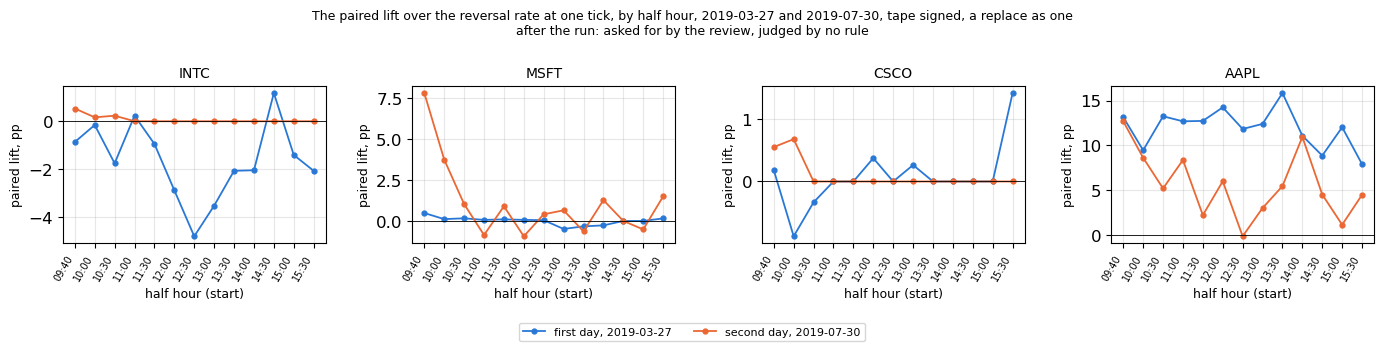


Table 7d, continued. Half-hour R2 of the order flow imbalance at 10 s, the first day (after the run: asked for by the
review, judged by no rule): 2019-03-27, session 09:40:00 to 15:50:00, tape signed, a replace as one.
The main pass's half-hour strip, which the order flow imbalance verdict reads (the signed tape; cell 65 prints the first
day's strip on the ladder's reference rung, the displayed tape, which differs from it by at most what cell 65 printed).
The median is asserted equal to the median the verdict printed. The first and the last half hour hold twenty minutes of
the session.
     median half-hour R2 half hours above 0.50 half hours with an R2 lowest highest
INTC               0.867                    13                    13  0.814   0.910
MSFT               0.909                    13                    13  0.835   0.941
CSCO               0.861                    13                    13  0.785   0.925
AAPL               0.828                    13                    13  

In [54]:
# Section 7, after the run, item d: the half hours of the one-tick class. For each stock-day with 200 one-tick
# readings or more (L 1, strict design): by half hour, the share of the unit samples at one tick, the one-tick
# readings and the paired lift (each half hour's hit rate less that same half hour's reversal rate), and the
# correlation across the half hours of the share strip with the lift strip; one figure, a panel a stock, the lift
# against the half hour on the first and the second day. Then the half-hour R2 of order flow imbalance at 10 s, the
# second day's (the first day's is printed on the ladder's reference in cell 65), with the half hours above 0.50, and
# the median asserted equal to the figure the order flow imbalance verdict printed. It reads what sections 2 and 6
# kept (cells 82 and 83) and runs no pass and no fit. Everything printed here was asked for by the review after the
# verdicts were read, and no rule reads it. Needs cell 62 for lad_strips. With the data absent it prints one line.
aft_d_started = time.time()
aft_d_label = 'after the run: asked for by the review, judged by no rule'
aft_d_spread = 'time at a spread of one tick, two, three or more'


def aft_d_share_strip(r):
    # The share of the unit samples at one tick in each half hour. A unit sample is the book at the start of the
    # unit, and the session's are those of units U0 to U1 - 1 (the same samples as the session's own share, which
    # the half hours' shares, weighted by the seconds each has in the session, must give back: asserted).
    spread = np.asarray(r['arrays']['unit_spread'], dtype=float)[: U1 - U0]
    blocks = block_of(U0 + np.arange(len(spread)))
    assert len(spread) == U1 - U0, 'the unit samples are not those of the session'
    share = [float((spread[blocks == b] == 1).mean()) if (blocks == b).any() else math.nan for b in HAVE_BLOCKS]
    weights = np.array([BLOCK_SECONDS[b] for b in HAVE_BLOCKS], dtype=float)
    session = float(np.nansum(np.array(share) * weights) / weights.sum())
    assert math.isclose(session, r['tape'][aft_d_spread][0], rel_tol=1e-9, abs_tol=1e-12), 'the session\'s share'
    return share


def aft_d_strips(r):
    # the three strips of a stock-day's one-tick class and their correlation; None for a stock-day with no such
    # class
    strip = r['imbalance']['strips'].get(('L 1 equal', CLASSES[0]))
    if strip is None:
        return None
    assert strip['n'] >= MIN_READINGS, 'a strip is kept only for a class with MIN_READINGS readings or more'
    share = aft_d_share_strip(r)
    lift = list(strip['strip']['lift over reversal'])
    assert len(share) == len(lift) == len(HAVE_BLOCKS), 'a strip with another number of half hours'
    return {
        'share': share,
        'readings': list(strip['strip']['n']),
        'lift': lift,
        'correlation': correlation(np.array(share, dtype=float), np.array(lift, dtype=float)),
        'half hours': int(np.isfinite(lift).sum()),
        'class lift': strip['lift over reversal'],
        'n': strip['n'],
    }


def aft_d_found(judged):
    # {stock: strips} for the stocks of a day that have a one-tick class of 200 readings or more
    out = {stock: aft_d_strips(r) for stock, r in judged.items()}
    return {stock: strips for stock, strips in out.items() if strips is not None}


def aft_d_summary(judged, found):
    # a row a stock-day: how much of the session it spends at one tick, the class's readings and lift, and the
    # correlation across the half hours of the share strip with the lift strip (-: under three half hours with
    # both)
    rows = {}
    for stock, strips in found.items():
        share = np.array(strips['share'], dtype=float)
        rows[stock] = {
            'time at one tick': judged[stock]['tape'][aft_d_spread][0],
            'one-tick readings': strips['n'],
            'lift over reversal pp': 100 * strips['class lift'],
            'half hours': strips['half hours'],
            'share, lowest half hour': np.nanmin(share),
            'share, highest half hour': np.nanmax(share),
            'correlation, share and lift': strips['correlation'],
        }
    return pd.DataFrame.from_dict(rows, orient='index')


def aft_d_lines(found):
    # the strips, a block of three lines a stock, under the half hours' start times
    lines = [f'{"":<24}{strip_header(6)}']
    for stock, strips in found.items():
        for label, key, digits, scale in (
            ('share at one tick %', 'share', 1, 100.0),
            ('one-tick readings', 'readings', 0, 1.0),
            ('paired lift pp', 'lift', 1, 100.0),
        ):
            lines.append(f'{stock:<6}{label:<18}{strip_text(strips[key], digits, scale, 6)}')
    return '\n'.join(lines)


def aft_d_figure(found_first, found_second, judged):
    # a panel a stock: the paired lift against the half hour, on each day that has a one-tick class of 200
    # readings or more; one y-axis a panel, each on its own scale (the stocks' lifts differ widely), the legend below
    # the axes
    stocks = [stock for stock in judged if stock in found_first or stock in found_second]
    if not stocks:
        print(f'No stock has {MIN_READINGS} one-tick readings on either day: no figure.')
        return
    set_style()
    columns = min(len(stocks), 5)
    rows = -(-len(stocks) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3.5 * columns, 3.4 * rows), sharey=False, squeeze=False)
    x = np.arange(len(HAVE_BLOCKS))
    for ax, stock in zip(axes.flat, stocks, strict=False):
        missing = []
        for color, name, found, day in (
            (BLUE, 'first day', found_first, DAY),
            (ORANGE, 'second day', found_second, SECOND_DAY),
        ):
            if stock in found:
                ax.plot(
                    x,
                    100 * np.array(found[stock]['lift'], dtype=float),
                    marker='o',
                    markersize=3.5,
                    linewidth=1.3,
                    color=color,
                    label=f'{name}, {day_text(day)}',
                )
            else:
                missing.append(name)
        ax.axhline(0, color='black', linewidth=0.6)
        ax.set_xticks(x, [BLOCK_LABELS[b] for b in HAVE_BLOCKS], fontsize=8)
        ax.set_xlabel('half hour (start)')
        ax.set_ylabel('paired lift, pp', fontsize=8)  # a long label sets the panel's height: the title has the rest
        note = f'\nno one-tick class of {MIN_READINGS} readings on the {" or ".join(missing)}' if missing else ''
        ax.set_title(stock + note, fontsize=9 if missing else 10)
        tidy_axes(ax)
    for ax in list(axes.flat)[len(stocks) :]:
        ax.axis('off')
    handles = {}
    for ax in axes.flat:
        for handle, label in zip(*ax.get_legend_handles_labels(), strict=True):
            handles.setdefault(label, handle)
    note = exploration_label(judged)
    days = f'{day_text(DAY)} and {day_text(SECOND_DAY)}'
    fig.suptitle(
        f'The paired lift over the reversal rate at one tick, by half hour, {days}, {convention()}\n{aft_d_label}'
        + (f'\n{note}' if note else ''),
        fontsize=9,
    )
    fig.legend(list(handles.values()), list(handles), loc='lower center', ncols=max(len(handles), 1), fontsize=8)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()


def aft_d_r2(judged, verdicts):
    # the half-hour R2 of order flow imbalance at OFI_MAIN s of each stock of a day (the main pass's, which the
    # verdict reads), its median, and the half hours above 0.50; the median must be the figure the verdict printed
    rows, strips = {}, []
    for stock, r in judged.items():
        ten = r['ofi'][OFI_MAIN]
        strip = np.array(ten['R2 strip'], dtype=float)
        median = float(np.nanmedian(strip))
        assert math.isclose(median, ten['median half-hour R2'], rel_tol=1e-12, abs_tol=1e-12), 'the median of the strip'
        verdict = verdicts.get(stock, {}).get('order flow imbalance')
        if verdict is not None and verdict.status != UNJUDGED:
            assert f'median half-hour R2 at {OFI_MAIN} s {median:.3f};' in verdict.detail, (
                f'{stock}: the strip\'s median is not the figure the verdict printed: {verdict.detail}'
            )
        finite = strip[np.isfinite(strip)]
        rows[stock] = {
            'median half-hour R2': median,
            'half hours above 0.50': int((finite > 0.5).sum()),
            'half hours with an R2': len(finite),
            'lowest': float(finite.min()) if len(finite) else math.nan,
            'highest': float(finite.max()) if len(finite) else math.nan,
        }
        strips.append((stock, list(strip)))
    return pd.DataFrame.from_dict(rows, orient='index'), strips


def aft_d_show_r2(judged, verdicts, day, name):
    heading(
        f'Table 7d, continued. Half-hour R2 of the order flow imbalance at {OFI_MAIN} s, the {name} ({aft_d_label})',
        judged,
        day,
    )
    say(
        'The main pass\'s half-hour strip, which the order flow imbalance verdict reads (the signed tape; cell 65 '
        'prints the first day\'s strip on the ladder\'s reference rung, the displayed tape, which differs from it by '
        'at most what cell 65 printed). The median is asserted equal to the median the verdict printed. The first and '
        'the last half hour hold twenty minutes of the session.'
    )
    table, strips = aft_d_r2(judged, verdicts)
    print(shown(table, {'median half-hour R2': '.3f', 'lowest': '.3f', 'highest': '.3f'}))
    print()
    print(lad_strips(strips, 3, 1.0))


def aft_d_show(found, judged, day, name):
    heading(
        f'Table 7d. The one-tick class by half hour: time at one tick, readings, paired lift ({aft_d_label})',
        judged,
        day,
    )
    say(
        'L 1, strict design, one tick at the reading. share at one tick: the share of the half hour\'s unit samples at '
        'one tick (the session\'s own share is the weighted mean of these, asserted); one-tick readings: the half '
        'hour\'s; paired lift: the half hour\'s hit rate less that half hour\'s reversal rate, in points. The '
        'correlation is across the half hours that have a lift, of the share strip with the lift strip (Pearson; '
        'under three half hours it is not defined), a description of the half hours and not a test.'
    )
    if not found:
        print(f'No stock has {MIN_READINGS} one-tick readings on the {name}.')
        return
    print(
        shown(
            aft_d_summary(judged, found),
            {
                'time at one tick': '.1%',
                'one-tick readings': ',.0f',
                'lift over reversal pp': '+.2f',
                'half hours': '.0f',
                'share, lowest half hour': '.1%',
                'share, highest half hour': '.1%',
                'correlation, share and lift': '+.2f',
            },
        )
    )
    print()
    print(aft_d_lines(found))
    print(f'\nThe three rates beside (a replace as one), session ({aft_d_label}):')
    print(shown(imb_rates({stock: judged[stock] for stock in found}), RATE_FORMATS | {'time at one tick': '.1%'}))


if two_ready():
    aft_d_found_first, aft_d_found_second = aft_d_found(two_judged_first), aft_d_found(two_judged_second)
    aft_d_show(aft_d_found_first, two_judged_first, DAY, 'first day')
    aft_d_show(aft_d_found_second, two_judged_second, SECOND_DAY, 'second day')
    aft_d_figure(aft_d_found_first, aft_d_found_second, {**two_judged_first, **two_judged_second})
    aft_d_show_r2(two_judged_first, two_verdicts_first, DAY, 'first day')
    aft_d_show_r2(two_judged_second, two_verdicts_second, SECOND_DAY, 'second day')
    aft_d_seconds = time.time() - aft_d_started
    aft_d_days = len(two_judged_first) + len(two_judged_second)
    print(
        f'\n(item d read {aft_d_days} stock-days that sections 2 and 6 kept: no pass, no fit, no worker; '
        f'{aft_d_seconds:.1f} s, peak memory of this process {peak_mb():,.0f} MB.)'
    )

**What the first two tables and the figure show.** For each stock-day with 200 one-tick readings or more (INTC, MSFT, CSCO and AAPL on both days) the tables give a block of three strips by half hour: the share of the half hour's unit samples at one tick, the half hour's one-tick readings, and the half hour's paired lift, its hit rate less that same half hour's reversal rate, in points. The summary table adds the correlation across the half hours of the share strip with the lift strip (the column "correlation, share and lift"), one figure a stock-day, over 13 half hours on all eight. The figure is a panel a stock with one line a day, the paired lift by half hour. No half hour is picked by eye: the figures below are the lowest and the highest share, the first half hour's readings and lift beside the day's, and the correlation.

- *First day.* INTC: share at one tick 99.7% to 100.0%; 695 of the day's 5,780 one-tick readings in the first half hour; paired lift -0.9 in the first half hour beside -1.49 for the day; correlation +0.41. MSFT: 84.9% to 95.7%; 2,487 of 31,996; +0.5 beside +0.03; +0.30. CSCO: 98.9% to 100.0%; 549 of 5,151; +0.2 beside +0.02; +0.01. AAPL: 5.2% to 50.4%; 1,490 of 23,341; +13.2 beside +11.88; -0.51.
- *Second day.* INTC: 96.3% to 100.0%; 566 of 3,145; +0.5 beside +0.16; -0.99. MSFT: 46.1% to 89.6%; 1,668 of 13,119; +7.8 beside +1.79; -0.89. CSCO: 92.1% to 100.0%; 542 of 1,948; +0.6 beside +0.26; -0.69. AAPL: 37.9% to 73.7%; 2,159 of 25,123; +12.7 beside +6.10; -0.51.

The first half hour's lift beside the day's, for each stock on each day, is the first point of each line in the figure: INTC -0.9 and +0.5 beside -1.49 and +0.16, MSFT +0.5 and +7.8 beside +0.03 and +1.79, CSCO +0.2 and +0.6 beside +0.02 and +0.26, and AAPL +13.2 and +12.7 beside +11.88 and +6.10. On the second day the lowest share at one tick is the first half hour's for all four stocks (96.3%, 46.1%, 92.1% and 37.9%). The second day's correlation is negative on all four, and on the first day it is +0.41 and +0.30 for INTC and MSFT, +0.01 for CSCO and -0.51 for AAPL. INTC's and CSCO's second-day paired lifts print as 0.0 from the 11:00 and the 10:30 half hours on, so their correlations rest on the first few half hours. The correlation is a description of the half hours, not a test.

**The second day's half-hour R2 at 10 s (the last two tables).** The second day's strip is printed for each stock as cell 65 prints the first day's, with the median, the half hours above 0.50 of the half hours that have an R2, and the lowest and the highest half hour; the first day's, from the main pass, is printed with it. The median printed here is the figure that the order flow imbalance verdict printed, and the cell asserts it. Cell 65's first-day strip is the ladder's reference rung on the displayed tape, and these are the main pass's on the signed tape, which differ by the few events that the two streams partition differently, as cell 65 printed. The half hours above 0.50, first day then second, are 13 and 13 for INTC, MSFT and CSCO, 13 and 12 for AAPL and 4 and 13 for AMZN, of 13 half hours with an R2 in every case. The second day's lowest and highest half hours are 0.751 and 0.902 for INTC, 0.705 and 0.903 for MSFT, 0.814 and 0.879 for CSCO, 0.414 and 0.901 for AAPL and 0.549 and 0.786 for AMZN; AAPL's lowest, 0.414, is the 14:00 half hour and the only half hour of the second day below 0.50. A half hour above or below 0.50 is a count of half hours, and the verdict reads the median: 0.867 | 0.836, 0.909 | 0.854, 0.861 | 0.847, 0.828 | 0.818 and 0.473 | 0.699, first day | second day.

**What this cannot show.** The correlation is across thirteen pairs of half hours (fewer where a half hour has no one-tick reading), so it cannot be told from no correlation by any rule here, and it is a description of those half hours, not a test and not a cause: the share of the time at one tick and the lift both move with the time of day (the opening half hour above all), and the share is of unit samples (seconds) while the lift is of readings (events), which weight the half hour differently. A half hour with few one-tick readings has a noisy lift, and the strip does not carry its count into the correlation. A panel is one stock's own two days; no two stocks are compared, and the first day's figures of a stock are not evidence about the second.

In [55]:
# Section 7, after the run, item e: the ladder's first clause, by bootstrap. From each stock-day's half-hour R2 of
# order flow imbalance at 10 s on the reference and on the rungs of 1 and 100 ms (the strips cells 65 and 88 hold),
# the half hours are resampled jointly across the three rungs (the same draw of half hours for all three, DRAWS draws,
# a generator seeded as the setup's bootstraps are), the three medians are recomputed for each draw, and three shares
# of the draws are printed: the 100 ms median below the reference's, the R2 part of the frozen ladder rule passing
# (which is "lower at 100 ms and half the drop or more already at 1 ms", asserted draw by draw, so a draw with no drop
# does not pass), and that second share among the draws that have a drop. The as-run medians are asserted equal to what
# cells 69 and 88 printed. The columns are named from LAD_FIRST and LAD_LAST (1 ms and 100 ms). It
# reads what sections 4 and 6 kept (cells 62 and 82: lad_reported, lad_explored and the second day's ladder) and runs
# no pass and no fit. Everything printed here was asked for by the review after the verdicts were read, and no rule
# reads it. Needs cells 61 and 69 for lad_name and lad_inputs_table. With the data absent it prints one line.
aft_e_started = time.time()
aft_e_label = 'after the run: asked for by the review, judged by no rule'
aft_e_rungs = (LAD_REFERENCE, lad_name('batch', LAD_FIRST), lad_name('batch', LAD_LAST))  # reference, 1 ms, 100 ms
aft_e_first, aft_e_last = f'{LAD_FIRST:g} ms', f'{LAD_LAST:g} ms'  # what the columns of the rungs are called


def aft_e_strips(run_out):
    # the half-hour R2 at OFI_MAIN s of a stock-day on the three rungs: an array of three rows, a column a half
    # hour
    return np.array([run_out['rungs'][rung]['ofi'][OFI_MAIN]['R2 strip'] for rung in aft_e_rungs], dtype=float)


def aft_e_r2_part(reference, first, last):
    # The R2 part of the frozen ladder rule on three medians: the setup's judge_ladder, whose quote clause is
    # given a drop that passes it (the reference at 100% and 100 ms at 0%), so that its status is the status of
    # the rule's R2 clauses alone.
    ladder = {
        'median_r2_reference': float(reference),
        'median_r2_1ms': float(first),
        'median_r2_100ms': float(last),
        'quote0_reference': 1.0,
        'quote0_100ms': 0.0,
    }
    return PREDICTIONS['ladder'].judge({'ladder': ladder}).status == PASSED


def aft_e_draws(strips):
    # The half hours that every rung has, resampled with replacement and jointly: DRAWS draws of k half hours (the
    # same indices for the three rungs), from a generator seeded with BOOT_SEED and drawn as block_bootstrap draws
    # (one integers(0, k, size=k) a draw), so that a rung's own standard error of its median is the spread of its
    # column of medians. Returns the medians of each draw (a row a draw: reference, 1 ms, 100 ms) and k.
    kept = strips[:, np.isfinite(strips).all(axis=0)]
    k = kept.shape[1]
    if k == 0:
        return np.full((DRAWS, len(aft_e_rungs)), math.nan), 0
    rng = np.random.default_rng(BOOT_SEED)
    return np.array([np.median(kept[:, rng.integers(0, k, size=k)], axis=1) for _ in range(DRAWS)]), k


def aft_e_row(run_out):
    strips = aft_e_strips(run_out)
    ref, first, last = (float(np.nanmedian(row)) for row in strips)
    draws, k = aft_e_draws(strips)
    reference, one, hundred = draws.T
    lower = hundred < reference
    # half the drop or more already at 1 ms, counting a draw with no drop as not passing
    half = lower & ((reference - one) >= 0.5 * (reference - hundred))
    rule = np.array([aft_e_r2_part(*medians) for medians in draws]) if k else np.zeros(DRAWS, dtype=bool)
    assert (rule == half).all(), 'the frozen rule\'s R2 part is not "lower at 100 ms, and half the drop at 1 ms"'
    own = [np.isfinite(row).sum() for row in strips]
    if k and all(count == k for count in own):  # every rung resampled its own half hours: its own se is reproduced
        for medians, rung in zip(draws.T, aft_e_rungs, strict=True):
            kept = run_out['rungs'][rung]['ofi'][OFI_MAIN]['median half-hour R2 se']
            assert math.isclose(float(medians.std(ddof=1)), kept, rel_tol=1e-9, abs_tol=1e-12), (
                f'{rung}: the resampled medians\' sd is not the pass\'s "median half-hour R2 se"'
            )
    drops = int(lower.sum())
    return {
        'half hours': k,
        'median R2, ref.': ref,
        aft_e_first: first,
        aft_e_last: last,
        f'drop at {aft_e_first}': (ref - first) / (ref - last) if ref > last else math.nan,
        'as run': 'passed' if aft_e_r2_part(ref, first, last) else 'not passed',
        f'{aft_e_last} lower': float(lower.mean()),
        'R2 part passes': float(rule.mean()),
        'half the drop, of a drop': float(half.sum() / drops) if drops else math.nan,
    }


def aft_e_table(results):
    # a row a stock-day; the as-run medians are asserted equal to the figures of cells 69 and 88
    # (lad_inputs_table)
    table = pd.DataFrame.from_dict({stock: aft_e_row(run_out) for stock, run_out in results.items()}, orient='index')
    inputs = lad_inputs_table(results, judge=False)
    for column, kept in (
        ('median R2, ref.', f'median R2, {OFI_MAIN} s, reference'),
        (aft_e_first, f'batch {LAD_FIRST:g} ms'),
        (aft_e_last, f'batch {LAD_LAST:g} ms'),
    ):
        for stock in table.index:
            assert math.isclose(table.loc[stock, column], inputs.loc[stock, kept], rel_tol=1e-12, abs_tol=1e-12), (
                f'{stock}: {column} is not what the ladder\'s table printed'
            )
    return table


aft_e_formats = {
    'half hours': '.0f',
    'median R2, ref.': '.3f',
    aft_e_first: '.3f',
    aft_e_last: '.3f',
    f'drop at {aft_e_first}': '.2f',
    f'{aft_e_last} lower': '.2f',
    'R2 part passes': '.2f',
    'half the drop, of a drop': '.2f',
}


def aft_e_show(title, results, day):
    heading(f'Table 7e. {title} ({aft_e_label})', results, day, how=f'{convention("none")}, unit {UNIT:g} s')
    print(shown(aft_e_table(results), aft_e_formats))


def aft_e_groups():
    # the stock-days the sections above kept a ladder for: the reported stocks on each day, the exploration stocks
    # apart
    groups = []
    if lad_reported:
        groups.append(('The ladder\'s first clause, by bootstrap, the reported stocks, first day', lad_reported, DAY))
    if two_second.get('ladder'):
        groups.append(
            (
                'The ladder\'s first clause, by bootstrap, the reported stocks, second day',
                two_second['ladder'],
                SECOND_DAY,
            )
        )
    if lad_explored:
        groups.append(
            ('The ladder\'s first clause, by bootstrap, the exploration stocks (not results)', lad_explored, DAY)
        )
    return groups


if need(DAY, LAD_ALL):
    say(
        f'\nThe ladder\'s first clause (the median half-hour R2 of the order flow imbalance at {OFI_MAIN} s is lower '
        f'at {aft_e_last} than on the reference, with half the drop or more already at {aft_e_first}) as a '
        'bootstrap. The half hours that the three rungs have are resampled with replacement, jointly (one draw of '
        f'half hours for all three rungs), {DRAWS:,} draws, seed {BOOT_SEED}, ASSUMING EXCHANGEABLE BLOCKS; the three '
        'medians are recomputed in each draw. As run: the three medians (asserted equal to the figures of cells 69 and '
        f'88), the share of the drop that is at {aft_e_first} ("drop at {aft_e_first}") and whether the R2 part '
        'of the rule passed. Columns of shares of the draws, none of them a probability and none read by a rule: '
        f'"{aft_e_last} lower", the median at {aft_e_last} is below the reference\'s; "R2 part passes", the R2 part '
        'of the frozen ladder rule passes in the draw (the setup\'s own judge, its quote clause fed a drop that '
        f'passes), which is a lower median at {aft_e_last} with half the drop or more already at {aft_e_first}, so a '
        'draw with no drop does not pass; "half the drop, of a drop", the draws that pass as a share of the draws '
        f'in which the median at {aft_e_last} is lower (the draws that have a drop). The rule\'s verdict is not '
        'repeated here.'
    )
    for aft_e_title, aft_e_results, aft_e_day in aft_e_groups():
        aft_e_show(aft_e_title, aft_e_results, aft_e_day)
    print(
        f'\n(item e read {len(lad_reported) + len(two_second.get("ladder", {})) + len(lad_explored)} stock-days\' '
        f'ladders that sections 4 and 6 kept: no pass, no fit, no worker; {time.time() - aft_e_started:.1f} s, '
        f'peak memory of this process {peak_mb():,.0f} MB.)'
    )


The ladder's first clause (the median half-hour R2 of the order flow imbalance at 10 s is lower at 100 ms than on the
reference, with half the drop or more already at 1 ms) as a bootstrap. The half hours that the three rungs have are
resampled with replacement, jointly (one draw of half hours for all three rungs), 1,000 draws, seed 1, ASSUMING
EXCHANGEABLE BLOCKS; the three medians are recomputed in each draw. As run: the three medians (asserted equal to the
figures of cells 69 and 88), the share of the drop that is at 1 ms ("drop at 1 ms") and whether the R2 part of the rule
passed. Columns of shares of the draws, none of them a probability and none read by a rule: "100 ms lower", the median
at 100 ms is below the reference's; "R2 part passes", the R2 part of the frozen ladder rule passes in the draw (the
setup's own judge, its quote clause fed a drop that passes), which is a lower median at 100 ms with half the drop or
more already at 1 ms, so a draw with no drop does not pass; "hal

     half hours median R2, ref.   1 ms 100 ms drop at 1 ms      as run 100 ms lower R2 part passes half the drop, of a drop
INTC         13           0.867  0.810  0.805         0.92      passed         1.00           0.93                     0.93
MSFT         13           0.909  0.869  0.828         0.49  not passed         1.00           0.33                     0.33
CSCO         13           0.861  0.810  0.831         1.71      passed         0.98           0.98                     1.00
AAPL         13           0.828  0.763  0.703         0.52      passed         1.00           0.49                     0.49
AMZN         13           0.473  0.461  0.452         0.57      passed         0.83           0.41                     0.49

Table 7e. The ladder's first clause, by bootstrap, the reported stocks, second day (after the run: asked for by the
review, judged by no rule): 2019-07-30, session 09:40:00 to 15:50:00, tape none, a replace as one, unit 1 s.
     half hours median R2, ref

      half hours median R2, ref.   1 ms 100 ms drop at 1 ms  as run 100 ms lower R2 part passes half the drop, of a drop
NVDA          13           0.675  0.612  0.637         1.67  passed         1.00           0.89                     0.89
CMCSA         13           0.822  0.756  0.736         0.77  passed         1.00           1.00                     1.00

(item e read 12 stock-days' ladders that sections 4 and 6 kept: no pass, no fit, no worker; 0.2 s, peak memory of this process 752 MB.)


**What the table shows.** The ladder's first clause is that the median half-hour R2 of order flow imbalance at 10 s is lower at 100 ms than on the reference, with half the drop or more already at 1 ms. The table resamples the 13 half hours with replacement, jointly across the reference, 1 ms and 100 ms rungs (one draw of half hours for all three), 1,000 draws with the setup's seed, and recomputes the three medians in each draw. A rung's own standard error of its median is reproduced by it, which the cell asserts where all thirteen half hours are present on the three rungs. For each stock-day it gives the three medians as run (asserted equal to the figures of cells 69 and 88), the share of the drop that is at 1 ms as run (the column "drop at 1 ms"), the as-run verdict of that clause, and three shares of the draws. "100 ms lower" is the share in which the median at 100 ms is below the reference's. "R2 part passes" is the share in which the R2 part of the frozen ladder rule passes, a lower median at 100 ms with half the drop or more already at 1 ms, so that a draw with no drop does not pass; the cell asserts it draw by draw. "Half the drop, of a drop" is the draws that pass as a share of the draws that have a drop. None of the three is a probability, and none is read by a rule. The medians, the share of the drop at 1 ms, the as-run clause and the three shares, stock-day by stock-day (reference, 1 ms, 100 ms; drop at 1 ms; the three shares):

- *First day.* INTC: 0.867, 0.810, 0.805; 0.92, passed; 1.00, 0.93, 0.93. MSFT: 0.909, 0.869, 0.828; 0.49, not passed; 1.00, 0.33, 0.33. CSCO: 0.861, 0.810, 0.831; 1.71, passed; 0.98, 0.98, 1.00. AAPL: 0.828, 0.763, 0.703; 0.52, passed; 1.00, 0.49, 0.49. AMZN: 0.473, 0.461, 0.452; 0.57, passed; 0.83, 0.41, 0.49.
- *Second day.* INTC: 0.836, 0.788, 0.719; 0.41, not passed; 1.00, 0.14, 0.14. MSFT: 0.854, 0.809, 0.772; 0.55, passed; 1.00, 0.34, 0.34. CSCO: 0.847, 0.786, 0.762; 0.72, passed; 1.00, 0.93, 0.93. AAPL: 0.818, 0.791, 0.674; 0.18, not passed; 1.00, 0.03, 0.03. AMZN: 0.699, 0.573, 0.561; 0.91, passed; 1.00, 0.94, 0.94.
- *Exploration* (NVDA and CMCSA on the first day, in a table of their own and labeled; not results): NVDA 0.675, 0.612, 0.637; 1.67, passed; 1.00, 0.89, 0.89. CMCSA 0.822, 0.756, 0.736; 0.77, passed; 1.00, 1.00, 1.00.

Five verdicts sit on the line of the clause "half the drop or more already at 1 ms": MSFT's first day (0.49) and second (0.55), AAPL's first (0.52), AMZN's first (0.57) and INTC's second (0.41). The clause was met in 0.33, 0.34, 0.49 and 0.41 of the draws for the first four. A clause met in a third to a half of the resamplings sits within the half hours' noise of its line, and the verdict then says as much about the threshold as about the stock, as the predictions cell warned of any figure near its line. INTC's second day is on the line by its as-run share of the drop, with the clause met in 0.14 of the draws. AMZN's first day has the median at 100 ms below the reference's in 0.83 of the draws (the medians are 0.473 and 0.452). The clause is met in 0.93 to 0.98 of the draws for INTC's first day, CSCO's two days and AMZN's second, and in 0.03 for AAPL's second. Each share is read beside its stock-day's verdict, and no stock-day is counted by its share. These are each stock-day's own figures, and no stock is said to differ from another.

**What the table does not change.** The ladder's verdicts stay as the frozen rule gave them, and no draw is a verdict. The quote clause (the lag-0 quote rule per lot, a drop of 2 points or more) is not resampled and is not part of this table; its figures are in the ladder's table (cells 69 and 88), and it is met on all ten stock-days.

**What this cannot show.** A share of the draws is not a probability, a p-value or a chance that the clause holds, on this day, on another day or for another stock, and a share under one half does not mean that a clause "probably fails": it is the share of resamplings in which the clause would be met if the thirteen half hours of this stock-day were drawn again with replacement, assuming that they are exchangeable, which the unequal half hours contradict, and thirteen values can move a median by a whole half hour's value in one draw. The resampling keeps what is shared by the three rungs within a half hour and loses the order of the half hours. It uses the R2 at 10 s only and the two rungs the rule reads (1 ms and 100 ms), so it says nothing of the other rungs or of any feed, and the thresholds are the frozen rule's and were not changed to suit it. The exploration stocks' rows are what the code was built on and are not results.

In [56]:
# Section 7, item f: the depth at the touch, counted in orders. Section 5 reads the depth at the touch in lots of
# CALIBRATION_LOT shares, and the fitted model has one order size, so a real book whose orders are not that size is
# read in a unit it does not have. Here the real side is counted in orders, at each unit sample of the session that
# the calibration's facts use (the book after the last message before the unit's start, the units of the session whose
# touch is not crossed): the displayed orders at the best bid and at the best ask, the mean shares an order there
# (shares over orders, summed over the samples), and the modal displayed order size among the orders placed in the
# session. The orders come from a replay of the stock's raw extract from the start of the day (aft_replay: the frames
# start at the open with no row for an order placed before it), and the replay's shares at the touch are asserted to
# be the book frame's at every sample. The model's side is read from what section 5 holds (cal_cache: the depth at 0
# in lots of the fitted model on seeds SIM_SEEDS, every order one lot of CALIBRATION_LOT shares, so lots are orders;
# the fit's own lot_size); no fit is rerun. Model over real in three units: orders; shares as run (the model's order
# is CALIBRATION_LOT shares: what the frozen rule read); shares with the model's order at the fit's own lot_size (not
# like for like: the fit counts one model order per real order, so orders are the like-for-like unit). Asserted: orders
# times the mean shares an order is the real depth in shares that section 5's Table 7 prints. Judged by no rule. Needs
# 89_t1_after_machinery and, for the model, the calibration cells (71 to 77); a stock-day with no calibration kept has
# its real side only.


def aft_f_real(touch):
    # the real side of one stock-day from the replay's samples: orders at each side's touch, shares an order, the sizes
    # of the orders placed
    orders, shares = touch['orders'], touch['shares']
    n = len(orders)
    return {
        'units': n,
        'orders, bid': float(orders[:, 0].mean()),
        'orders, ask': float(orders[:, 1].mean()),
        'orders a side': float(orders.sum() / (2 * n)),
        'shares a side': float(shares.sum() / (2 * n)),
        'shares an order': float(shares.sum() / orders.sum()),
        'modal add': touch['modal size'],
        'at modal %': 100 * touch['modal share'],
        'adds': touch['orders placed'],
    }


def aft_f_strip(touch):
    # orders a side at the touch in each half hour of the session, as the half-hour strip beside the session's figure
    blk = block_of(touch['units'])
    return [
        float(touch['orders'][blk == b].sum() / (2 * (blk == b).sum())) if (blk == b).any() else math.nan
        for b in HAVE_BLOCKS
    ]


def aft_f_model(detail, real):
    # the model's side and model over real in three units, from a calibration kept by section 5. The model's order is
    # one lot, so its depth at the touch in lots is its orders; shares as run are those lots at CALIBRATION_LOT shares,
    # and the same orders at the fit's own lot_size are the shares of the third unit.
    orders = float(np.mean([run['session']['depth at 0 (lots)'] for run in detail['sim']]))
    fit_lot = detail['day fit']['lot_size']
    return {
        'model orders': orders,
        'x orders': orders / real['orders a side'],
        'model lot': CALIBRATION_LOT,
        'x shares as run': orders * CALIBRATION_LOT / real['shares a side'],
        'fit lot': fit_lot,
        'x shares at fit lot': orders * fit_lot / real['shares a side'],
    }


def aft_f_check(stock, day, touch, real, detail):
    # the replay is the book frame at every sample, and orders times shares an order is the depth in shares that section
    # 5's Table 7 prints for the real session (the session and each half hour), and the ratio in shares as run is
    # cal_summary's depth_ratio
    where = f'{stock}, {day_text(day)}'
    assert touch['mismatches'] == 0, (
        f'{where}: the replay\'s shares at the touch are not the book frame\'s at {touch["mismatches"]} units'
    )
    assert math.isclose(real['orders a side'] * real['shares an order'], real['shares a side'], rel_tol=1e-12), where
    if detail is None:
        return False
    session = detail['real']['session']['depth at 0 (lots)'] * CALIBRATION_LOT
    product = real['orders a side'] * real['shares an order']
    assert math.isclose(product, session, rel_tol=1e-9), (
        f'{where}: orders times shares an order is {product}, the real depth at 0 is {session} shares'
    )
    blk = block_of(touch['units'])
    for kept in detail['real']['blocks']:
        m = blk == kept['block']
        if m.any():
            shares = touch['shares'][m].sum() / (2 * m.sum())
            assert math.isclose(shares, kept['depth at 0 (lots)'] * CALIBRATION_LOT, rel_tol=1e-9), (
                f'{where}: half hour {kept["block"]}: {shares} shares, the real depth at 0 is '
                f'{kept["depth at 0 (lots)"] * CALIBRATION_LOT}'
            )
    model = aft_f_model(detail, real)
    assert math.isclose(model['x shares as run'], cal_summary(detail)['depth_ratio'], rel_tol=1e-9), (
        f'{where}: the ratio in shares as run is not section 5\'s depth_ratio'
    )
    assert detail['sim params']['lot_size'] == CALIBRATION_LOT, f'{where}: the model\'s order is not one lot'
    return True


def aft_f_show(results, day):
    # two frames (the real side; model over real in three units) and the half-hour strips, with the caption line
    real, models, strips, notes, compared = {}, {}, {}, [], 0
    for stock, result in results.items():
        touch = result['touch']
        if touch is None:
            notes.append(f'{stock}: the raw extract is not there; not counted.')
            continue
        real[stock] = aft_f_real(touch)
        detail = cal_cache.get((day, stock)) if 'cal_cache' in globals() else None
        compared += aft_f_check(stock, day, touch, real[stock], detail)
        strips[stock] = {'real': aft_f_strip(touch), 'model': [math.nan] * len(HAVE_BLOCKS)}
        if detail is not None:
            models[stock] = aft_f_model(detail, real[stock])
            strips[stock]['model'] = np.mean(
                [[block['depth at 0 (lots)'] for block in run['blocks']] for run in detail['sim']], axis=0
            ).tolist()
        else:
            notes.append(
                f'{stock}: no calibration kept for this stock-day (section 5 did not run it); the real side only.'
            )
        notes.append(
            f'{stock}: {touch["orders placed"]:,} orders placed in the session; sizes placed most often: '
            + ', '.join(f'{size} ({100 * share:.1f}%)' for size, share in touch['sizes, most often'][:3])
            + f'; median {touch["median size"]:g}, mean {touch["mean size"]:.1f}.'
        )
    heading(
        f'Table 7f. The depth at the touch counted in orders: the real book at each unit sample of the session '
        f'({UNIT:g} s), displayed orders [{aft_label}]',
        results,
        day=day,
        how='the book frame\'s touch and the orders of a replay of the raw extract, a replace as the frames have it',
    )
    say(
        'Orders at the best bid and at the best ask, averaged over the unit samples; shares an order is the shares at '
        'the touch over the orders there, summed over both sides and every sample; the modal size is the most frequent '
        'size among the orders placed in the session, the adds (a replace\'s new order included). The replay\'s shares '
        'at the touch equal the book frame\'s at every unit sample of every stock-day here, '
        f'{sum(len(r["touch"]["units"]) for r in results.values() if r["touch"]):,} in all (asserted).'
    )
    if real:
        print(
            shown(
                pd.DataFrame(real).T,
                {'units': ',.0f', 'adds': ',.0f', 'modal add': ',.0f', 'at modal %': '.1f', 'orders, bid': '.2f'}
                | {'orders, ask': '.2f', 'orders a side': '.2f', 'shares a side': ',.1f', 'shares an order': '.1f'},
            )
        )
    if models:
        heading(
            f'Table 7f, continued. The fitted model over the real book in three units [{aft_label}]',
            {stock: None for stock in models},
            day=day,
            how=f'the fitted model, seeds {SIM_SEEDS[0]} to {SIM_SEEDS[-1]}, depth in lots of {CALIBRATION_LOT} shares',
        )
        say(
            'The model is fitted in orders (one model order for each real order, and every model order is one lot), so '
            'its depth at the touch in lots is its orders a side (mean over the seeds), and "x orders", model over '
            'real in orders, is the like-for-like comparison. "x shares as run" is model over real in shares with the '
            f'model\'s order at CALIBRATION_LOT shares ("model lot", {CALIBRATION_LOT}): what the frozen rule read '
            '(section 5\'s depth ratio). "x shares at fit lot" is model over real in shares with the model\'s order at '
            'the fit\'s own lot_size ("fit lot": the modal size of the orders the fit read, over the whole day): it '
            'sets the day\'s modal add against the mean resting order at the touch, and is NOT like for like. A ratio '
            'above 1 is a model book deeper than the real one in that unit; no ratio of this table is set against a '
            'rule\'s line.'
        )
        print(
            shown(
                pd.DataFrame(models).T,
                {'model orders': '.2f', 'x orders': '.2f', 'model lot': ',.0f', 'x shares as run': '.2f'}
                | {'fit lot': ',.0f', 'x shares at fit lot': '.2f'},
            )
        )
    for line in notes:
        say(line)
    if strips:
        print('\nOrders a side at the touch by half hour of the session (real; the fitted model, mean over seeds):')
        print(stock_strips(strips, lambda r: r['real'], 2, 1.0, 7, 'real'))
        if models:
            print(stock_strips({stock: strips[stock] for stock in models}, lambda r: r['model'], 2, 1.0, 7, 'model'))
    return compared


for aft_day, aft_day_name in ((DAY, 'first day'), (SECOND_DAY, 'second day')):
    if need(aft_day):
        say(f'\nSection 7, item f, the reported stocks, the {aft_day_name}.')
        aft_f_compared = aft_f_show(aft_passed(aft_day, STOCKS), aft_day)
        print(f'{aft_f_compared} stock-days compared with the calibration\'s own depth at the touch (asserted equal).')
if need(DAY, EXPLORED):
    say('\nSection 7, item f, the exploration stocks (what this code was built on; not results).')
    aft_f_show(aft_passed(DAY, EXPLORED), DAY)


Section 7, item f, the reported stocks, the first day.

Table 7f. The depth at the touch counted in orders: the real book at each unit sample of the session (1 s), displayed
orders [after the run: asked for by the review, judged by no rule]: 2019-03-27, session 09:40:00 to 15:50:00, the book
frame's touch and the orders of a replay of the raw extract, a replace as the frames have it.
Orders at the best bid and at the best ask, averaged over the unit samples; shares an order is the shares at the touch
over the orders there, summed over both sides and every sample; the modal size is the most frequent size among the
orders placed in the session, the adds (a replace's new order included). The replay's shares at the touch equal the book
frame's at every unit sample of every stock-day here, 111,000 in all (asserted).
       units orders, bid orders, ask orders a side shares a side shares an order modal add at modal %       adds
INTC  22,200        9.80       10.31         10.05       1,731.

**What Table 7f shows.** The real book's displayed orders at the best bid and at the best ask, averaged over the unit samples of the session, the shares an order there, the modal size of the orders placed in the session and the share of orders placed at it, beside the fitted model's: its orders at the touch a side (its depth at 0 in lots, every model order being one lot of 100 shares) and the model over the real one in three units. The model is fitted in orders, one model order for each real order, so the like-for-like unit is orders. "x orders" is model over real in orders. "x shares as run" is model over real in shares with the model's order at `CALIBRATION_LOT` shares, which is what the frozen calibration test read, and it is section 5's depth ratio. "x shares at fit lot" is model over real in shares with the model's order at the fit's own `lot_size`, the modal size of the orders over the whole day; it sets the day's modal add against the mean resting order at the touch and is not like for like, and it is not the model's figure. In orders, the model's unit, the model's touch is x N the real one; the rule read shares. No ratio of the table is set against the rule's line, and the table prints no verdict. For each stock-day, the real orders a side and shares an order, the model's orders a side, and the ratios in orders and in shares as run:

- *First day.* INTC: 10.05 orders of 172.3 shares, model 3,193.31, x317.68 in orders and x184.42 in shares as run. MSFT: 4.86 of 123.4, model 3,029.83, x622.84 and x504.60. CSCO: 10.31 of 192.3, model 1,804.88, x174.99 and x90.99. AAPL: 2.28 of 123.2, model 477.74, x209.60 and x170.10. AMZN: 1.47 of 33.1, model 9.85, x6.69 and x20.23; the modal order placed is 20 shares (42.1%), and the ratio in shares at the fit's lot of 20 is x4.05.
- *Second day.* INTC: 10.68 orders of 205.0 shares, model 2,561.50, x239.84 and x117.02. MSFT: 4.96 of 120.0, model 1,234.75, x248.93 and x207.42. CSCO: 8.79 of 189.7, model 1,116.18, x126.95 and x66.94. AAPL: 3.19 of 106.7, model 381.99, x119.57 and x112.03. AMZN: 1.32 of 54.4, model 21.74, x16.42 and x30.21; the modal order placed is 100 shares (55.8%), the fit's lot is 100, and the third ratio is the second.

AMZN's first day is the stock-day where the unit matters most: in orders the model's touch is x6.69 the real one, in shares as run x20.23 (the model's order counted as 100 shares against the real order's 33.1) and at the fit's lot x4.05. The frozen calibration test read x20.23, and none of the three is set against its line here.

**The identities the cell asserts.** Orders times the mean shares an order is the real depth at the touch in shares that Table 7 of section 5 printed, to rounding, for the session and for each half hour, and the replay's shares at the touch are the book frame's at every unit sample (111,000 samples in each day's table, 44,400 in the exploration's). The ratio in shares as run is section 5's depth ratio, for the five stock-days of each day that have a calibration. The orders come from a replay of the stock's raw extract from the start of the day, because the frames start at the open and hold no row for an order placed before it.

**The half-hour strip under the table.** The real orders a side at the touch move over the day: on the first day INTC's run from 8.46 to 14.40, MSFT's from 4.29 to 6.68, CSCO's from 8.25 to 14.03 and AAPL's from 1.91 to 2.92, and AMZN's stay between 1.36 and 1.74; on the second day INTC's run from 5.51 to 15.37, MSFT's from 2.91 to 6.14, CSCO's from 3.80 to 13.85, AAPL's from 2.73 to 5.53 and AMZN's between 1.19 and 1.43. For INTC, MSFT, CSCO and AAPL on both days the highest real count is in the last half hour. The model's count shows no such movement, and stays within these ranges on every stock-day but one: INTC's is 3,174.00 to 3,208.69 on the first day and 2,532.49 to 2,578.65 on the second, MSFT's 2,999.65 to 3,052.26 and 1,210.64 to 1,256.39, CSCO's 1,791.42 to 1,816.96 and 1,110.90 to 1,122.07, AAPL's 423.76 to 499.84 and 363.25 to 397.97, and AMZN's first day 8.76 to 10.77. AMZN's second day is the exception: its model count is 4.13 to 4.64 in ten half hours and 122.79 (09:40), 105.01 (11:30) and 56.29 (15:30) in three. Nothing is said here about why.

**The exploration stocks** (a separate table, labeled; no calibration was run for them in this notebook, so only the real side is shown, and it is not a result). NVDA's touch holds few orders, 1.87 a side at 101.2 shares an order, with 84.7% of its 473,321 orders placed at the modal size of 100 shares; CMCSA's holds many, 10.10 a side at 181.2 shares an order, with 53.5% of its 427,707 orders at 100 shares.

**What this cannot show.** That the model should be fitted at the real order size, or that any one unit is the right one: the section reports the same depth in three units and the ratio depends on the unit (the orders are the like-for-like one, and no ratio here is a verdict or is set against a line); the fit's `lot_size` is the modal size of the orders over the whole day and not the size of an order at the touch; a mean number of orders is not their distribution; and nothing here changes the frozen calibration verdict.

In [57]:
# Section 7, item g: executions priced more than a cent from their order. lob.itch counts, over the whole file, every
# C message (an execution with price) whose price is more than a cent (itch.CENT, 100 ITCH units) from its order's
# displayed price, and reports it as `c_price_over_a_cent` beside the conversion's other counts, as something that
# would break a premise of the reading (the conversion expects a C a cent off). The frozen run printed the count and
# did not say what the C messages are. For each stock-day whose count is not 0, from the same C messages (the replay
# of the raw extract that item f makes: aft_replay): how many, how many in the session and in 09:30 to 16:00, the
# times of the first and the last, the distance from the order's displayed price in cents (lowest, median, highest),
# the shares, and the side of the resting order. The replay's count is asserted to be the conversion's. A stock-day
# whose count is 0 gets one line. Judged by no rule. Needs 89_t1_after_machinery. The last cell of the section prints
# what its passes cost.


def aft_g_clock(ns):
    # nanoseconds after midnight as hh:mm:ss.mmm
    seconds, fraction = divmod(int(ns), aft_ns)
    return f'{seconds // 3_600:02d}:{seconds % 3_600 // 60:02d}:{seconds % 60:02d}.{fraction // 1_000_000:03d}'


def aft_g_row(rows, count):
    # one stock-day's C messages over a cent as a row of figures: rows are (ns, printable, shares, distance in ITCH
    # units, side of the order, the order's displayed price)
    ns, printable, shares, distance, side = rows[:, 0], rows[:, 1] > 0, rows[:, 2], rows[:, 3] / itch.CENT, rows[:, 4]
    window = (ns >= int(OPEN) * aft_ns) & (ns < int(CLOSE) * aft_ns)
    session = (ns >= int(OPEN + U0) * aft_ns) & (ns < int(OPEN + U1) * aft_ns)
    return {
        'conversion count': count,
        f'in {clock(0)[:5]} to {clock(CAL1)[:5]}': int(window.sum()),
        f'in the session {clock(U0)[:5]} to {clock(U1)[:5]}': int(session.sum()),
        'first': aft_g_clock(ns.min()),
        'last': aft_g_clock(ns.max()),
        'cents, lowest': float(distance.min()),
        'cents, median': float(np.median(distance)),
        'cents, highest': float(distance.max()),
        'shares': int(shares.sum()),
        'shares, median': float(np.median(shares)),
        'resting bids': int((side > 0).sum()),
        'resting asks': int((side < 0).sum()),
        'printable (Y)': int(printable.sum()),
        'not printable (N)': int((~printable).sum()),
    }


def aft_g_show(day, results):
    # a line for each stock-day whose count is 0, and for the others the caption, what reads a price, and a table
    lines, table = [], {}
    for stock, result in results.items():
        count, price = result['conversion count'], result['cprice']
        if price is None:
            lines.append(f'{stock}, {day_text(day)}: the raw extract is not there; the C messages are not counted.')
            continue
        if price['over'] == itch.CENT:
            assert len(price['rows']) == count, (
                f'{stock}, {day_text(day)}: the replay finds {len(price["rows"])} C messages over a cent, the '
                f'conversion counted {count}'
            )
        if count == 0:
            lines.append(
                f'{stock}, {day_text(day)}: c_price_over_a_cent is 0 ({price["c messages"]:,} C messages in the file, '
                f'none priced more than a cent from its order\'s displayed price); nothing to tabulate [{aft_label}].'
            )
        else:
            table[stock] = aft_g_row(price['rows'], count)
    if table:
        heading(
            f'Table 7g. Executions priced more than a cent from their order\'s displayed price (the conversion\'s '
            f'c_price_over_a_cent) [{aft_label}]',
            {stock: results[stock] for stock in table},
            day=day,
            how='the C messages of the raw extract, no tape and no replace convention',
            window='the whole file, with counts inside the frames\' window and the session',
        )
        say(
            'The count is lob.itch\'s: every C of the whole file, printable or not, whose price is more than a cent '
            f'({itch.CENT} ITCH units) from the displayed price of the order it names. In the frames a printable C is '
            'a type 4 row with `priced` True and its own `price`, and the order\'s displayed price is the `price` of '
            'the order\'s add (a type 1 row, or the replay\'s for an order placed before the open).'
        )
        say(
            'Which printed figures read such an execution\'s price. A printable C (printable Y) is a displayed '
            'execution at its own price: a type 4 row of the frames with `priced` True, whose `price` is the '
            'execution\'s and whose book reduction is at the order\'s displayed price. Its price is read by the tick '
            'rule (the change from the fill before), by the quote rules at lags 0, 1 and 5 (the fill\'s price against '
            'the mid), by VPIN\'s tick and mid rules, and by the signing table\'s category "displayed, priced (C)" and '
            'the categories that contain it ("displayed (both)", "all signed fills"). It is not read by the book '
            '(imbalance, order flow imbalance, resilience, the spread and the mid move at the order\'s displayed '
            'price), by the aggressor (the resting order\'s side), by VPIN with the true sides, or by any count of '
            'events, messages, trades and aggressive orders. A C that is not printable (N) is the other half of a '
            'trade between two displayed orders, written at its order\'s displayed price and never an execution, or a '
            'cross (a type 6 row): its price reaches no figure. A C outside the frames\' window (09:30 to 16:00) is in '
            'the count and in no frame.'
        )
        frame = pd.DataFrame(table).T
        print(shown(frame[list(frame.columns[:5])]))
        print()
        print(
            shown(
                frame[list(frame.columns[5:])],
                {'cents, lowest': '.2f', 'cents, median': '.2f', 'cents, highest': '.2f', 'shares': ',.0f'}
                | {'shares, median': ',.0f'},
            )
        )
    for line in lines:
        say(line)


for aft_day, aft_day_name in ((DAY, 'first day'), (SECOND_DAY, 'second day')):
    if need(aft_day):
        say(f'\nSection 7, item g, the reported stocks, the {aft_day_name}.')
        aft_g_show(aft_day, aft_passed(aft_day, STOCKS))
if need(DAY, EXPLORED):
    say('\nSection 7, item g, the exploration stocks (what this code was built on; not results).')
    aft_g_show(DAY, aft_passed(DAY, EXPLORED))
aft_ran('Section 7, items a, c, f and g: ')


Section 7, item g, the reported stocks, the first day.

Table 7g. Executions priced more than a cent from their order's displayed price (the conversion's c_price_over_a_cent)
[after the run: asked for by the review, judged by no rule]: 2019-03-27, the whole file, with counts inside the frames'
window and the session, the C messages of the raw extract, no tape and no replace convention.
The count is lob.itch's: every C of the whole file, printable or not, whose price is more than a cent (100 ITCH units)
from the displayed price of the order it names. In the frames a printable C is a type 4 row with `priced` True and its
own `price`, and the order's displayed price is the `price` of the order's add (a type 1 row, or the replay's for an
order placed before the open).
Which printed figures read such an execution's price. A printable C (printable Y) is a displayed execution at its own
price: a type 4 row of the frames with `priced` True, whose `price` is the execution's and whose book redu

**What Table 7g shows.** The conversion's `c_price_over_a_cent` counts, over the whole file, every C message (an execution with a price) whose price is more than a cent (100 ITCH units) from the displayed price of the order it names, printable or not. Section 1's conversion cell prints the count under "premises", and its closing line "Every one of the 80 required counts is 0" does not cover it; the count is 1, 15 and 23 on three stock-days and 0 on the other seven. The table is for those three and for no other stock-day. For each it gives how many such executions there are, how many are inside 09:30 to 16:00 and inside the session 09:40 to 15:50, the times of the first and the last, the distance from the order's displayed price in cents (lowest, median, highest), the shares (total and median), the side of the resting order, and how many are printable (Y) and how many not (N). The replay's count is the conversion's, and the cell asserts it.

- *AMZN, first day: 1.* It is at 16:00:00.770, outside 09:30 to 16:00 and outside the session; 3.00 cents from its order's displayed price; 87 shares; a resting bid. 0 printable, 1 not printable.
- *AAPL, second day: 15.* All 15 are at 16:00:00.641, outside 09:30 to 16:00 and outside the session; 2.00, 6.00 and 7.00 cents (lowest, median, highest); 9,874 shares, median 670; all resting bids. 0 printable, 15 not printable.
- *AMZN, second day: 23.* 2 are inside 09:30 to 16:00 and none inside the session; the first is at 09:30:00.472 and the last at 16:00:00.347; 2.00, 47.00 and 85.00 cents; 3,590 shares, median 100; all resting bids (23 bids, 0 asks). 0 printable, 23 not printable.

Every other stock-day gets one line that says its count is 0 and how many C messages its file holds (INTC 311, MSFT 1,190, CSCO 439 and AAPL 508 on the first day; INTC 290, MSFT 678 and CSCO 201 on the second; the exploration's NVDA 143 and CMCSA 476), none of them priced more than a cent from its order's displayed price.

**Which printed figures read such an execution's price.** A printable C (printable Y) is a displayed execution at its own price. Its price is read by the tick rule, by the quote rules at lags 0, 1 and 5, by VPIN's tick and mid rules, and by the signing table's category "displayed, priced (C)" and the categories that contain it ("displayed (both)", "all signed fills"). It is not read by the book (the imbalance, order flow imbalance, resilience, the spread and the mid move at the order's displayed price), by the aggressor (the resting order's side), by VPIN with the true sides, or by any count of events, messages, trades and aggressive orders. A C that is not printable (N) is the other half of a trade between two displayed orders, written at its order's displayed price and never an execution, or a cross; it never is a fill, and its price reaches no figure. On the three stock-days of the table, 0 of 1, 0 of 15 and 0 of 23 of the executions are printable, so none of their prices reaches a printed figure.

**The sentence about a cent.** The title cell and the notes of sections 1 and 3 say that an execution with a price is a cent off its order's displayed price. The table shows where that holds: on the stock-days with a count of 0, which are seven reported stock-days and the two exploration stocks, no execution was priced more than a cent from its order's displayed price, and on the three stock-days of this table some were, none of them printable. So for the executions that print, none is more than a cent away on any of the ten stock-days, and the sentence is true of printable executions and of no other. The count is reported beside the conversion's required counts and is not one of them; this table is where it is read.

**What this cannot show.** That any figure moved, or did not: no figure is recomputed without these executions; and whether such a price is an error in the data or a real execution priced inside a sub-cent increment: the cell counts and describes them, it does not decide.

In [58]:
# Section 7, after the run, item h: the rules as they were before the lead's changes. Six rules were changed before
# the freeze (and before any reported stock or the second day was read): hit rate, reversal rate, one-tick lift, queue
# race, calibration and ladder (the ladder's quote clause among them). Each earlier rule is written here as a function
# that reads the result a frozen judge reads (their texts are the ones the predictions cell quotes as "Was", and the
# code is the setup cell's before the change, in final/rules_applied.md), applied to every stock-day the sections
# above judged.
# Printed: the verdicts that differ, with the figure, and for each of the six tests the count held on both days under
# the earlier rule and under the frozen one. The mechanism test was new (the tenth) and is left out. This describes
# what the changes did, was made after the verdicts were read, and judges nothing: the frozen rules are the
# notebook's. It reads what sections 4 to 6 kept (cells 82 and 83) and runs no pass and no fit. With the data absent
# it prints one line.
aft_h_started = time.time()
aft_h_label = 'after the run: asked for by the review, judged by no rule'
aft_h_lift_band = 3.0  # the earlier one-tick lift: within this many points of 0
aft_h_quote_line = 0.95  # the earlier ladder: the lag-0 quote rule per lot at 100 ms under this
aft_h_cancel = 5  # the earlier calibration: the median half-hour cancel rate this many times the day's or more


def aft_h_hit_rate(results):
    # the hit rate is above 50% in every spread class with 200 readings or more
    rows = [row for row in class_rows(results).values() if row['n'] >= MIN_READINGS]
    if not rows:
        return Verdict(UNJUDGED, f'no spread class has {MIN_READINGS} readings')
    detail = '; '.join(
        f'{row["class"]} {100 * row["hit"]:.1f}% of {int(row["n"]):,} (reversal rate {100 * row["reversal"]:.1f}%)'
        for row in rows
    )
    clauses = [(f'{row["class"]} above 50%', row['hit'] > 0.5) for row in rows]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'{detail}; {at_one_tick(results)}{not_met(clauses)}',
    )


def aft_h_reversal_rate(results):
    # the reversal rate is above 50% at one tick; and below 50% at two ticks where the stock spends more than half
    # its time at one tick
    rows, share = class_rows(results), one_tick_share(results)
    one, two = rows['one tick'], rows['two ticks']
    parts, detail = [], [at_one_tick(results)]
    if one['n'] >= MIN_READINGS:
        parts.append(('one tick above 50%', one['reversal'] > 0.5))
        detail.insert(0, f'one tick {100 * one["reversal"]:.1f}% of {int(one["n"]):,}')
    if share > 0.5:
        if two['n'] >= MIN_READINGS:
            parts.append(('two ticks below 50%', two['reversal'] < 0.5))
            detail.insert(-1, f'two ticks {100 * two["reversal"]:.1f}% of {int(two["n"]):,}')
        else:
            detail.insert(-1, f'two ticks has {int(two["n"])} readings, so that part is not judged')
            if parts and not all(held for _, held in parts):  # a part that has failed is not undone by one not judged
                return Verdict(FAILED, '; '.join(detail) + not_met(parts))
            return Verdict(UNJUDGED, '; '.join(detail))
    if not parts:
        return Verdict(UNJUDGED, f'one tick has {int(one["n"])} readings; {at_one_tick(results)}')
    return Verdict(PASSED if all(held for _, held in parts) else FAILED, '; '.join(detail) + not_met(parts))


def aft_h_one_tick_lift(results):
    # where one tick holds most of the time, the lift over the reversal rate at one tick is within 3 points of 0
    share, one = one_tick_share(results), class_rows(results)['one tick']
    if share <= 0.5:
        return Verdict(UNJUDGED, f'not applicable: {at_one_tick(results)}')
    if one['n'] < MIN_READINGS:
        return Verdict(UNJUDGED, f'one tick has {int(one["n"])} readings')
    lift = 100 * one['lift over reversal']
    differ = one.get('calls differ')
    calls = '' if differ is None or not math.isfinite(differ) else f'; the two calls differ at {100 * differ:.1f}%'
    return Verdict(
        PASSED if abs(lift) < aft_h_lift_band else FAILED,
        f'lift over the reversal rate {lift:+.1f} points of {int(one["n"]):,}{calls}; {at_one_tick(results)}',
    )


def aft_h_queue_race(results):
    # the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bound within 0.001 of 1 counts
    # as the limit of the fit, not as under it)
    fit = results['imbalance']['race'].get('one tick')
    if fit is None:
        return Verdict(UNJUDGED, f'one tick has under {MIN_READINGS} readings')
    bound = fit['a (c = 1) upper 95%']
    if not math.isfinite(bound):
        return Verdict(UNJUDGED, f'no draw of the bootstrap had a one-tick reading; {at_one_tick(results)}')
    return Verdict(
        PASSED if bound < RACE_LIMIT else FAILED,
        f'a {fit["a (c = 1)"]:.3f}, upper 95% bound {bound:.4f}, n {fit["n"]:,}; {at_one_tick(results)}',
    )


def aft_h_calibration(results):
    # the fitted B is at its bound, the fitted model has 3 times the aggressive orders of the real day or more and
    # 5 times its depth at the touch or more, and its median half-hour cancel rate is 5 times the day's or more
    cal = results.get('calibration')
    if not cal:
        return Verdict(UNJUDGED, 'no calibration result')
    if not cal.get('profile_agrees', True):
        return Verdict(UNJUDGED, 'the likelihood profile of B on its grid does not agree with the fitted B')
    clauses = [
        ('B at its bound', cal['b_at_bound']),
        ('aggressive orders 3 times the day\'s or more', cal['aggressive_ratio'] >= 3),
        ('depth at the touch 5 times the day\'s or more', cal['depth_ratio'] >= 5),
        ('median half-hour cancel rate 5 times the day\'s or more', cal['cancel_ratio'] >= aft_h_cancel),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'B at its bound {cal["b_at_bound"]}; aggressive orders x{cal["aggressive_ratio"]:.1f}, '
        f'depth at the touch x{cal["depth_ratio"]:.1f}, median half-hour cancel rate x{cal["cancel_ratio"]:.1f} '
        f'(the estimator\'s window effect, not the stock\'s){not_met(clauses)}',
    )


def aft_h_ladder(results):
    # the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already
    # at 1 ms, and the quote rule at lag 0 is under 95% per lot at 100 ms
    ladder = results.get('ladder')
    if not ladder:
        return Verdict(UNJUDGED, 'no ladder result')
    ref, one, hundred = ladder['median_r2_reference'], ladder['median_r2_1ms'], ladder['median_r2_100ms']
    clauses = [
        ('R2 lower at 100 ms than on the reference', hundred < ref),
        ('half the drop or more already at 1 ms', (ref - one) >= 0.5 * (ref - hundred)),
        ('quote rule at lag 0 under 95% at 100 ms', ladder['quote0_100ms'] < aft_h_quote_line),
    ]
    return Verdict(
        PASSED if all(held for _, held in clauses) else FAILED,
        f'median R2: reference {ref:.3f}, 1 ms {one:.3f}, 100 ms {hundred:.3f}; quote rule at lag 0 '
        f'at 100 ms, per lot, {100 * ladder["quote0_100ms"]:.1f}%{not_met(clauses)}',
    )


aft_h_earlier = {  # the test: (the rule as the predictions cell quotes it as "Was", the function)
    'hit rate': ('the hit rate is above 50% in every spread class with 200 readings or more', aft_h_hit_rate),
    'reversal rate': (
        'the reversal rate is above 50% at one tick; and below 50% at two ticks where the stock spends more than half '
        'its time at one tick',
        aft_h_reversal_rate,
    ),
    'one-tick lift': (
        'where one tick holds most of the time, the lift over the reversal rate at one tick is within 3 points of 0',
        aft_h_one_tick_lift,
    ),
    'queue race': (
        'the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bound within 0.001 of 1 counts as '
        'the limit of the fit, not as under it)',
        aft_h_queue_race,
    ),
    'calibration': (
        'the fitted B is at its bound, the fitted model has 3 times the aggressive orders of the real day or more and '
        '5 times its depth at the touch or more, and its median half-hour cancel rate is 5 times the day\'s or more',
        aft_h_calibration,
    ),
    'ladder': (
        'the median half-hour R2 at 10 s is lower at 100 ms than on the reference, with half the drop or more already '
        'at 1 ms, and the quote rule at lag 0 is under 95% per lot at 100 ms',
        aft_h_ladder,
    ),
}


def aft_h_apply(function, results):
    # an earlier rule on one stock-day; a figure it reads that is not there is not judged, as the frozen rules do
    try:
        return function(results)
    except (KeyError, IndexError, TypeError, ValueError) as error:
        return Verdict(UNJUDGED, f'a figure the earlier rule reads is not there ({type(error).__name__}: {error})')


def aft_h_earlier_by_stock(judged, frozen):
    # {stock: {test: Verdict}} under the earlier rules, for each stock of `frozen` (the verdicts cell 83 kept); a
    # stock-day with no result is not judged under either, for the reason that the frozen verdict gives
    out = {}
    for stock, verdicts in frozen.items():
        if stock in judged:
            out[stock] = {test: aft_h_apply(function, judged[stock]) for test, (_, function) in aft_h_earlier.items()}
        else:
            out[stock] = {test: Verdict(UNJUDGED, verdicts[test].detail) for test in aft_h_earlier}
    return out


def aft_h_figure(test, results):
    # the figure the two rules read differently, in words
    rows, share = class_rows(results), one_tick_share(results)
    time_at_one = f'one tick holds {fmt(share, 1, 100)}% of the time'
    if test == 'hit rate':
        left_out = [
            f'{name} hit {fmt(row["hit"], 1, 100)}%, reversal {fmt(row["reversal"], 1, 100)}% of {count_of(row):,}'
            for name, row in rows.items()
            if count_of(row) >= MIN_READINGS and is_number(row['reversal']) and row['reversal'] > 0.5
        ]
        return '; '.join(left_out) if left_out else 'no class has a reversal rate above 50%'
    if test == 'reversal rate':
        one, two = rows.get('one tick'), rows.get('two ticks')
        return (
            f'one tick reversal {fmt(number(one, "reversal"), 1, 100)}% of {count_of(one):,}, two ticks '
            f'{fmt(number(two, "reversal"), 1, 100)}% of {count_of(two):,}; {time_at_one}'
        )
    if test == 'one-tick lift':
        one = rows.get('one tick')
        interval = (
            results['imbalance'].get('strips', {}).get(('L 1 equal', 'one tick'), {}).get('lift over reversal 95%')
        )
        text = f'lift {fmt(number(one, "lift over reversal"), 2, 100, True)} points of {count_of(one):,}'
        if interval is not None and all(is_number(end) for end in interval):
            text += f', 95% interval {100 * interval[0]:+.2f} to {100 * interval[1]:+.2f}'
        return f'{text}; {time_at_one}'
    if test == 'queue race':
        fit = results['imbalance']['race'].get('one tick') or {}
        return f'upper 95% bound {fmt(number(fit, "a (c = 1) upper 95%"), 4)}, n {count_of(fit):,}; {time_at_one}'
    cal, ladder = results.get('calibration') or {}, results.get('ladder') or {}
    if test == 'calibration':
        return (
            f'cancel rate x{fmt(number(cal, "cancel_ratio"), 1)}, '
            f'aggressive orders x{fmt(number(cal, "aggressive_ratio"), 1)}, depth x{fmt(number(cal, "depth_ratio"), 1)}'
        )
    drop = 100 * (number(ladder, 'quote0_reference') - number(ladder, 'quote0_100ms'))
    return f'quote rule at 100 ms {fmt(number(ladder, "quote0_100ms"), 1, 100)}%, a drop of {fmt(drop, 1)} points'


def aft_h_differences(days):
    # one row for each test, stock and day on which the earlier and the frozen verdict differ
    rows = []
    for day, judged, frozen, earlier in days:
        for stock, verdicts in frozen.items():
            for test in aft_h_earlier:
                before, now = earlier[stock][test], verdicts[test]
                if before.status != now.status:
                    figure = aft_h_figure(test, judged[stock]) if stock in judged else 'no result'
                    rows.append((test, stock, day_text(day), figure, before, now))
    return rows


def aft_h_print_differences(rows):
    if not rows:
        print('No verdict differs between the earlier rules and the frozen ones on any stock-day.')
        return
    widths = [max(len(str(row[i])) for row in rows + [('test', 'stock', 'day', 'the figure')]) for i in range(4)]
    head = ('test', 'stock', 'day', 'the figure')
    print('  '.join(f'{text:<{width}}' for text, width in zip(head, widths, strict=True)) + '  earlier        frozen')
    for test, stock, day, figure, before, now in rows:
        cells = '  '.join(f'{text:<{width}}' for text, width in zip((test, stock, day, figure), widths, strict=True))
        print(f'{cells}  {before.status:<13}  {now.status}')
    print('\nWhat each rule read, where the verdicts differ:')
    for test, stock, day, _, before, now in rows:
        print(f'  {test}, {stock}, {day}')
        print(f'    earlier {before.status}: {before.detail}')
        print(f'    frozen  {now.status}: {now.detail}')


def aft_h_counts(first, second, earlier_first, earlier_second):
    # per test, the stocks that passed on the first day, on the second and on both, of those judged on both days,
    # under the earlier rule and under the frozen one (held_on_both_days, the setup's own count)
    tests = list(aft_h_earlier)
    frozen_tables = [verdict_table(by_stock).loc[tests] for by_stock in (first, second)]
    earlier_tables = [verdict_table(by_stock).loc[tests] for by_stock in (earlier_first, earlier_second)]
    out = pd.DataFrame(index=tests)
    for name, counts in (
        ('earlier', held_on_both_days(*earlier_tables)),
        ('frozen', held_on_both_days(*frozen_tables)),
    ):
        out[f'{name}: day 1, day 2, both of judged on both'] = [
            f'{row["passed day 1"]}, {row["passed day 2"]}, {row["passed on both"]} of {row["judged on both"]}'
            for _, row in counts.iterrows()
        ]
        out[f'{name} held by'] = counts['held on both days'].replace('', '-')
    return out


def aft_h_show(first, second):
    judged = {**two_judged_first, **two_judged_second}
    label = exploration_label(judged)
    say(
        f'\nTable 7h. The six rules the lead changed before the freeze, as they were, and the frozen ones, on the same '
        f'results: '
        f'{day_text(DAY)} and {day_text(SECOND_DAY)}, session {SESSION_START} to {SESSION_END}, {convention()} '
        f'({aft_h_label}). This describes what the changes did, and was made after the verdicts were read: the frozen '
        'rules are the notebook\'s, and nothing here is a result. The calibration\'s mechanism was new (the tenth '
        'test) and is left out.'
    )
    if label:
        print(f'[{label}]')
    print('\nThe rules as they were (the texts the predictions cell quotes as "Was"):')
    for test, (text, _) in aft_h_earlier.items():
        say(f'  {test}: {text}.', width=TEXT_WIDTH)
    earlier_first = aft_h_earlier_by_stock(two_judged_first, first)
    earlier_second = aft_h_earlier_by_stock(two_judged_second, second)
    for by_stock in (earlier_first, earlier_second):
        assert all(v.status in (PASSED, FAILED, UNJUDGED) for verdicts in by_stock.values() for v in verdicts.values())
    print(f'\nThe stock-days on which the verdict differs ({aft_h_label}):')
    rows = aft_h_differences(
        [(DAY, two_judged_first, first, earlier_first), (SECOND_DAY, two_judged_second, second, earlier_second)]
    )
    aft_h_print_differences(rows)
    say(
        '\nFor each of these six tests, the stocks that passed on the first day, on the second and on both days, of '
        'those judged on both days, and which held it on both, under the earlier rule and under the frozen one '
        f'(held_on_both_days, a test at a time: nothing is counted across tests; {aft_h_label}):'
    )
    print(shown(aft_h_counts(first, second, earlier_first, earlier_second)))
    return rows


if two_ready():
    aft_h_rows = aft_h_show(two_verdicts_first, two_verdicts_second)
    aft_h_seconds = time.time() - aft_h_started
    aft_h_days = len(two_judged_first) + len(two_judged_second)
    print(
        f'\n(item h read {aft_h_days} stock-days that sections 2 to 6 kept: no pass, no fit, no worker; '
        f'{aft_h_seconds:.1f} s, peak memory of this process {peak_mb():,.0f} MB.)'
    )


Table 7h. The six rules the lead changed before the freeze, as they were, and the frozen ones, on the same results:
2019-03-27 and 2019-07-30, session 09:40:00 to 15:50:00, tape signed, a replace as one (after the run: asked for by the
review, judged by no rule). This describes what the changes did, and was made after the verdicts were read: the frozen
rules are the notebook's, and nothing here is a result. The calibration's mechanism was new (the tenth test) and is left
out.

The rules as they were (the texts the predictions cell quotes as "Was"):
hit rate: the hit rate is above 50% in every spread class with 200 readings or more.
reversal rate: the reversal rate is above 50% at one tick; and below 50% at two ticks where the stock spends more than
half its time at one tick.
one-tick lift: where one tick holds most of the time, the lift over the reversal rate at one tick is within 3 points of
0.
queue race: the upper 95% bound of the queue race amplitude a at one tick is under 1 (a bo


The stock-days on which the verdict differs (after the run: asked for by the review, judged by no rule):
test           stock  day         the figure                                                                                      earlier        frozen
one-tick lift  INTC   2019-03-27  lift -1.49 points of 5,780, 95% interval -2.30 to -0.76; one tick holds 99.8% of the time       passed         not passed
reversal rate  AAPL   2019-03-27  one tick reversal 47.5% of 23,341, two ticks 46.8% of 45,966; one tick holds 20.7% of the time  not passed     not judged
queue race     AAPL   2019-03-27  upper 95% bound 0.3536, n 23,341; one tick holds 20.7% of the time                              passed         not judged
one-tick lift  MSFT   2019-07-30  lift +1.79 points of 13,119, 95% interval +0.19 to +3.43; one tick holds 79.9% of the time      passed         not passed

What each rule read, where the verdicts differ:
  one-tick lift, INTC, 2019-03-27
    earlier passed: lift over the r

**What the section is.** Six rules were changed before the freeze (the hit rate, the reversal rate, the one-tick lift, the queue race, the calibration and the ladder, whose quote clause is one of them), and the table above lists the texts of the rules as they were, as the predictions cell quotes them under "Was". The changes were made before any reported stock or anything of the second day had been read, on the judgment reader's advice and from the two exploration stocks (and the simulator). This section applies the earlier rules to the reported stocks after the verdicts were read, as a description of what the changes did. The frozen rules are the notebook's, and nothing in this section is a result. The calibration's mechanism was new, the tenth test, and is left out.

**The stock-days whose verdict differs.** Four rows, each one rule of the six, with the reason the predictions cell gave for the change:

- *One-tick lift, INTC, first day.* The earlier rule ("within 3 points of 0") passed it: -1.5 points on 5,780 readings, the two calls differing at 8.9%, and one tick holding 99.8% of the time. The frozen rule (the 95% interval inside -1 to +1 point) does not: -1.49, interval -2.30 to -0.76. The predictions cell's reason for the change is that "within 3 points" was a band of 25.6 standard errors (the lift's block standard error at one tick was 0.117 points on the exploration's CMCSA) that also held the simulator's own 1.9 to 2.3 points at one tick, so a pass would not have separated a real book from the simulator.
- *One-tick lift, MSFT, second day.* The earlier rule passed it with +1.8 points on 13,119 readings, the calls differing at 9.0% and one tick holding 79.9% of the time; the frozen rule does not, with +1.79, interval +0.19 to +3.43. The reason is the same.
- *Reversal rate, AAPL, first day.* This is the one-tick gate. The earlier rule did not pass it: the one-tick reversal rate was 47.5% on 23,341 readings (not above 50%) and the two-tick 46.8% on 45,966, with one tick holding 20.7% of the time. The frozen rule does not judge it, because one tick holds less than half of the day. The predictions cell's reason is that a class of fleeting states passed the one-tick part (the exploration's NVDA: 909 one-tick readings from 0.27% of its seconds).
- *Queue race, AAPL, first day.* This is the same gate. The earlier rule passed it, with amplitude a 0.337 and upper 95% bound 0.3536 on 23,341 readings, and the frozen rule does not judge it. The reason is that a bound over a class of fleeting states says nothing about a stock that is mostly not at one tick (the exploration's NVDA: an upper bound of 0.58 from 909 readings).

By test, one stock-day differs for the reversal rate and one for the queue race, and two for the one-tick lift (INTC's first day and MSFT's second). The hit rate (the baseline within the class), the calibration (the cancel-rate clause) and the ladder (a line of 95% against a drop of 2 points) have no row, so their verdicts are the same under both rules. The earlier ladder line of 95% is nearest on CSCO's second day, at 94.0% per lot at 100 ms, 1.0 point under it (a plain difference).

**The counts held on both days, a test at a time** (the stocks that passed on the first day, on the second and on both, of those judged on both days, then which held it, under the earlier rule and under the frozen one):

- *Hit rate.* Earlier 5, 5 and 5 of 5 (INTC, MSFT, CSCO, AAPL, AMZN); frozen 5, 5 and 5 of 5, the same five.
- *Reversal rate.* Earlier 3, 4 and 3 of 4 (INTC, MSFT, CSCO); frozen 3, 4 and 3 of 3, the same three. Under the earlier rule AAPL was judged on both days and did not pass the first.
- *One-tick lift.* Earlier 3, 3 and 3 of 3 (INTC, MSFT, CSCO); frozen 2, 2 and 1 of 3 (CSCO).
- *Queue race.* Earlier 4, 4 and 4 of 4 (INTC, MSFT, CSCO, AAPL); frozen 3, 4 and 3 of 3 (INTC, MSFT, CSCO).
- *Calibration.* Earlier 5, 5 and 5 of 5; frozen 5, 5 and 5 of 5, the same five.
- *Ladder.* Earlier 4, 3 and 2 of 5 (CSCO, AMZN); frozen 4, 3 and 2 of 5, the same two.

A count under the earlier rule is the count the notebook would have printed had the earlier rule been kept, and it is not what the notebook reports. No count is made across tests, and no stock is ranked.

**What this cannot show.** It cannot show that the earlier rules were worse or better: both were set before the reported stocks were read, on two stocks, and the judgment reader's reasons for each change are the exploration's (the predictions cell's "Changes made before the freeze"). It is not a test of the changes, and the earlier verdicts are not the notebook's. It leaves the mechanism test out because there is no earlier rule for it. A verdict that differs differs by a threshold or a gate, so a row says what a line or a gate does to one stock-day and nothing about the stock.

In [59]:
# Section 7, item i: the rows that the correction of lob/ladder.py touches. lob.itch writes an execution with price (a
# printable C: the frames' rows of type 4 with `priced`) and a displayed order executed in a cross (a row of type 6
# with an order) at the EXECUTION's price, while the book falls at the ORDER's level. As first built and run,
# lob.ladder read such a row's price as its level: a batch's net change was keyed by it, and a fill of the levels rung
# was matched by it. The corrected file reads the level from the book (Day.level: the level of the row's side whose
# size fell by the row's size). This cell counts, for each stock-day, among the rows of the frames (09:30 to 16:00)
# and among those the ladder reads (from the open to the session's end): the executions with price, the cross
# executions of an order, how many of them the book places at another level than their own price (the rows whose key
# the correction changed), and how many the book does not place (the first row of the frames, or a row at which the
# ten levels shown do not change: such a row keeps its own price, as first built). It reads the frames and builds a
# lob.ladder Day for each stock-day in this process, one at a time. Judged by no rule. Needs 61_a_machinery (lad_lib)
# and 89_t1_after_machinery (aft_label).


def aft_i_count(stock, day):
    # the counts of one stock-day; its frames and its Day are dropped before the next
    messages, book, _ = frames_of(stock, day)
    priced = messages['priced'].to_numpy(bool)
    made = lad_lib.Day(messages, book, origin=OPEN, end=OPEN + U1)
    del messages, book
    execs = (made.kind == 4) & priced
    cross = (made.kind == 6) & (made.order_id != 0)
    special = execs | cross
    moved = special & (made.level != made.price)
    rows = made.rows
    quiet = np.ones(len(made.kind), bool)  # a row at which none of the ten levels shown changes, and the first row
    for values in (rows.bid_price, rows.bid_size, rows.ask_price, rows.ask_size):
        same = (values[1:] == values[:-1]) | (np.isnan(values[1:]) & np.isnan(values[:-1]))
        quiet[1:] &= same.all(axis=1)
    unplaced = special & quiet
    read = np.arange(len(made.kind)) < made.n  # the rows the ladder reads: from the open to the session's end
    assert not (made.level != made.price)[~special].any(), f'{stock}: a row that is neither kind has another level'
    out = {
        'rows': len(made.kind),
        'executions with price': int(execs.sum()),
        'cross executions of an order': int(cross.sum()),
        'at another level than their price': int(moved.sum()),
        'not placed by the book': int(unplaced.sum()),
        'read by the ladder': int((special & read).sum()),
        'of those, at another level': int((moved & read).sum()),
        'of those, not placed': int((unplaced & read).sum()),
        'cents from the level, lowest': math.nan,
        'cents from the level, highest': math.nan,
    }
    if moved.any():
        cents = np.abs(made.level[moved] - made.price[moved]) / made.tick  # a tick is a cent
        out['cents from the level, lowest'] = float(cents.min())
        out['cents from the level, highest'] = float(cents.max())
    del made, rows
    gc.collect()
    return out


def aft_i_show(stocks, day):
    aft_i_started = time.perf_counter()
    table = {stock: aft_i_count(stock, day) for stock in stocks}
    heading(
        f'Table 7i. The rows that the correction of lob/ladder.py touches [{aft_label}]',
        table,
        day=day,
        window='the frames, 09:30:00 to 16:00:00, and the rows the ladder reads (to the session\'s end)',
        how='the frames\' rows, no tape and no replace convention',
    )
    say(
        'An execution with price (type 4, priced) and a displayed order executed in a cross (type 6 with an order) are '
        'written at the execution\'s price; the book falls at the order\'s level. "at another level than their price": '
        'the rows that the corrected lob.ladder keys and matches at the level the book fell at (Day.level), where the '
        'file as first built and run used the row\'s own price. "not placed by the book": the first row of the frames, '
        'or a row at which the ten levels shown do not change; such a row keeps its own price, as first built. "cents '
        'from the level": how far such a row\'s price is from the level it took, in ticks of a cent. No row that is '
        'neither kind has another level than its price (asserted). What the correction changed in the figures of '
        'sections 4 and 6 is in the limitations, figure by figure; this table is the count of rows behind it.'
    )
    formats = {name: ',.0f' for name in next(iter(table.values()))}
    formats |= {'cents from the level, lowest': '.2f', 'cents from the level, highest': '.2f'}
    frame = pd.DataFrame(table).T
    names = list(frame.columns)
    print(shown(frame[names[:5]], formats))  # among the rows of the frames
    print(shown(frame[names[5:]], formats))  # among the rows the ladder reads, and how far the price is from the level
    print(
        f'(item i read {len(table)} stock-days\' frames in this process: no pass, no fit, no worker; '
        f'{time.perf_counter() - aft_i_started:.1f} s.)'
    )


for aft_day, aft_day_name in ((DAY, 'first day'), (SECOND_DAY, 'second day')):
    if need(aft_day):
        say(f'\nSection 7, item i, the reported stocks, the {aft_day_name}.')
        aft_i_show(STOCKS, aft_day)
if need(DAY, EXPLORED):
    say('\nSection 7, item i, the exploration stocks (what this code was built on; not results).')
    aft_i_show(EXPLORED, DAY)


Section 7, item i, the reported stocks, the first day.



Table 7i. The rows that the correction of lob/ladder.py touches [after the run: asked for by the review, judged by no
rule]: 2019-03-27, the frames, 09:30:00 to 16:00:00, and the rows the ladder reads (to the session's end), the frames'
rows, no tape and no replace convention.
An execution with price (type 4, priced) and a displayed order executed in a cross (type 6 with an order) are written at
the execution's price; the book falls at the order's level. "at another level than their price": the rows that the
corrected lob.ladder keys and matches at the level the book fell at (Day.level), where the file as first built and run
used the row's own price. "not placed by the book": the first row of the frames, or a row at which the ten levels shown
do not change; such a row keeps its own price, as first built. "cents from the level": how far such a row's price is
from the level it took, in ticks of a cent. No row that is neither kind has another level than its price (asserted).
What the cor


Table 7i. The rows that the correction of lob/ladder.py touches [after the run: asked for by the review, judged by no
rule]: 2019-07-30, the frames, 09:30:00 to 16:00:00, and the rows the ladder reads (to the session's end), the frames'
rows, no tape and no replace convention.
An execution with price (type 4, priced) and a displayed order executed in a cross (type 6 with an order) are written at
the execution's price; the book falls at the order's level. "at another level than their price": the rows that the
corrected lob.ladder keys and matches at the level the book fell at (Day.level), where the file as first built and run
used the row's own price. "not placed by the book": the first row of the frames, or a row at which the ten levels shown
do not change; such a row keeps its own price, as first built. "cents from the level": how far such a row's price is
from the level it took, in ticks of a cent. No row that is neither kind has another level than its price (asserted).
What the cor


Table 7i. The rows that the correction of lob/ladder.py touches [after the run: asked for by the review, judged by no
rule]: 2019-03-27, the frames, 09:30:00 to 16:00:00, and the rows the ladder reads (to the session's end), the frames'
rows, no tape and no replace convention.
[exploration: this figure is from NVDA or CMCSA, which the code was built on]
An execution with price (type 4, priced) and a displayed order executed in a cross (type 6 with an order) are written at
the execution's price; the book falls at the order's level. "at another level than their price": the rows that the
corrected lob.ladder keys and matches at the level the book fell at (Day.level), where the file as first built and run
used the row's own price. "not placed by the book": the first row of the frames, or a row at which the ten levels shown
do not change; such a row keeps its own price, as first built. "cents from the level": how far such a row's price is
from the level it took, in ticks of a cent. No row 

**What Table 7i shows.** `lob.itch` writes an execution with a price (a printable `C`) and a displayed order executed in a cross at the execution's price, while the book falls at the level of the order. As first built and run, `lob.ladder` read such a row's price as its level, so a batch's net change was keyed, and a fill of the `levels` rung matched, by the row's price. A mechanical sweep of the library's tests and a reading of the code found it, on the two exploration stocks, after the verdicts were read and by nobody who had opened a reported stock's data for it. The corrected file reads the level from the book: the level of the row's side whose size fell by the row's size (`Day.level`). The table counts, for each stock-day, the rows behind the correction: among the frames' rows (09:30:00 to 16:00:00) the executions with a price and the cross executions of an order, how many of them the corrected file reads at another level than their price, and how many the book does not place (the first row of the frames, or a row at which the ten levels shown do not change: such a row keeps its own price); then how many of those rows are among the rows the ladder reads (from the open to the session's end), how many of these are at another level, and the lowest and the highest distance in cents between a row's price and the level it took. Judged by no rule.

| Stock | Day | Executions with price | Cross executions of an order | At another level than their price | Not placed by the book | Read by the ladder, of those | At another level, of those | Cents from the level, lowest | Cents from the level, highest |
|---|---|---|---|---|---|---|---|---|---|
| INTC | first day, 2019-03-27 | 284 | 0 | 284 | 0 | 277 | 277 | 1.00 | 1.00 |
| MSFT | first day, 2019-03-27 | 979 | 0 | 979 | 0 | 875 | 875 | 1.00 | 1.00 |
| CSCO | first day, 2019-03-27 | 421 | 0 | 421 | 0 | 381 | 381 | 1.00 | 1.00 |
| AAPL | first day, 2019-03-27 | 500 | 0 | 500 | 0 | 451 | 451 | 1.00 | 1.00 |
| AMZN | first day, 2019-03-27 | 62 | 0 | 62 | 0 | 52 | 52 | 1.00 | 1.00 |
| INTC | second day, 2019-07-30 | 286 | 0 | 286 | 0 | 218 | 218 | 1.00 | 1.00 |
| MSFT | second day, 2019-07-30 | 667 | 0 | 667 | 0 | 388 | 388 | 1.00 | 1.00 |
| CSCO | second day, 2019-07-30 | 194 | 0 | 194 | 0 | 171 | 171 | 1.00 | 1.00 |
| AAPL | second day, 2019-07-30 | 623 | 0 | 623 | 0 | 585 | 585 | 1.00 | 1.00 |
| AMZN | second day, 2019-07-30 | 69 | 2 | 71 | 0 | 70 | 70 | 1.00 | 85.00 |
| NVDA | exploration, 2019-03-27 | 143 | 0 | 143 | 0 | 120 | 120 | 1.00 | 1.00 |
| CMCSA | exploration, 2019-03-27 | 451 | 1 | 451 | 0 | 410 | 409 | 1.00 | 1.00 |

On each of the ten stock-days the book places every row (0 not placed). On the nine stock-days with no cross execution of an order the lowest and the highest distance are both 1.00 cent: each execution with a price is exactly one cent from the level it took. AMZN's second day holds two cross executions of an order, and its distances run from 1.00 to 85.00 cents over its 71 rows at another level; no execution with a price is more than a cent from its order's displayed price (Table 7g), so the 85.00 is a cross execution's, whose price is the cross's and not the order's. The table prints the lowest and the highest only, so the other cross execution's distance is not printed. On the exploration stocks (not results) NVDA has 143 executions with a price and no cross execution, and CMCSA 451 and one cross execution: 451 of its rows are at another level, all at 1.00 cent, none is not placed, and one row of the two kinds is placed by the book at its own price; the table does not say which row that is.

What the correction changed in the notebook's figures is listed in the limitations, figure by figure: ten printed counts of the reported stocks, the updates and the windows netting to nothing of the batch rungs of MSFT, CSCO and AAPL on the first day, each by 1 or 2, figures of the exploration stocks' `levels` and batch rungs (counts, and on `levels` a rate and accuracies), and no verdict.

**The table's caption, read with the limitations.** The caption is a code line, left as run, and two of its phrases need this. It carries the other tables' words, "asked for by the review", and no review of the run asked for item i: the lead added it with the correction. And it says that what the correction changed "in the figures of sections 4 and 6" is in the limitations: the limitations list printed figures of section 4 only, because no printed figure of a measurement of section 6 differs. The second day's cells print the rungs' rates and no count of updates or of windows, and this table counts, on the second day, 70 (AMZN) to 585 (AAPL) rows a stock-day that the ladder reads at another level than their price, so whether the second day's counts moved is not printed.

**What this cannot show.** The table counts rows. It does not show which windows or events changed (the limitations list the printed figures that did), and no figure is recomputed here. A row the book does not place keeps its own price, so the correction does not reach it; there is none on these stock-days. It says nothing of a stock or a day that the notebook does not read.

**What section 7 cannot show.**

- *Anything chosen before the verdicts were read.* Every table and figure of section 7 was asked for after the verdicts of sections 1 to 6 were known (items a to h by the two reviews, item i with the correction of `lob/ladder.py`). None of them is a prediction, and none was written before the first run; each caption says "after the run: asked for by the review, judged by no rule" (item i's too, in the others' words, though no review of the run asked for it). The two cut points that the section uses (the ladder's shortest and longest batch intervals, 1 ms and 100 ms) were fixed before the freeze, in the ladder's own rules, and the section's code was built and smoke-run on the two exploration stocks only. A figure that looks like a finding here is a description of these ten stock-days and is not held to a rule.
- *A band is how soon the scored change came.* The split of the readings by how long the spread state lasted (item c) puts each reading in the spell it was taken in, and a spell's length is its end less its start. The end comes after the reading and, for the share of readings that the cell prints under each table (94.0% to 99.5% of the one-tick readings and 100.0% of the two-tick readings of the four stocks that have a class), it is the very change of the mid that the reading is scored against, so a band is the timing of the outcome itself and cannot be read as something a trader knows at the time. The spell's age at the reading, which is known at the time, is under 1 ms for 94.2% to 98.7% of the one-tick readings, so the bands cannot be told apart when the reading is taken. The split describes where the lift lies. It does not say that a state of that length could be told at the reading, that a stock-day would pass without such states, or that a stock-day's failure comes from fleeting states (AAPL's second day gives -3.48, interval -4.25 to -2.76, in the readings of spells of 100 ms or more), and no rule's line, the one-tick lift's -1 to +1 point, is applied to a band's interval.
- *A fine resolution from thirteen half hours.* Every bootstrap of this section resamples thirteen half hours, the first and the last of which hold twenty minutes of the session, assuming that they are exchangeable, which the unequal half hours contradict. A draw can move a median by a whole half hour's value, so a share of the draws is a coarse description of how much one day's half hours could move a figure, and not a probability, a p-value or the chance that it holds on another day or for another stock. The paired standard error and the strips' correlations rest on the same thirteen values.
- *A test.* Nothing in section 7 is a test. No rule reads a figure of it; no verdict, no count of stocks that passed and no count of tests held on both days changes because of it, and the conclusions' counts are the frozen verdicts'. The rules as they were before the lead's changes are shown as a description of what the changes did and are not the notebook's. The exploration stocks' rows, where there are any, are what the code was built on, in a table of their own and labeled, and are not results.

## Section 8: Conclusions and limitations

The cell below prints, from what the sections above kept, the notebook's headline figures section by section (each stock's figure on the first day beside the same stock's on the second, never pooled), then every prediction's verdict on each stock and each day, then the figures each rule read with a margin line under each verdict (the figure, the rule's line, the distance in standard errors and the range of the half hours, or, for VPIN, of the 11 bucket origins), then the counts of stocks that passed on the first day, on the second and on both, a test at a time, and then the time and memory of each part of the run. It calls `check_namespace()` first: a cell that had assigned to a name of the setup cell would have changed what every figure above was computed with, and the notebook stops there and says so. It reads nothing of section 7: no test, no verdict, no count and no headline figure of this section depends on a table of section 7, which judges nothing. The time and memory table is of the functions that `run_stocks` ran, and section 7 keeps a log of its own.

The conclusions that follow are written after the run, from these printed figures and from the sections above, and say what the notebook may say about these five stocks on these two days and what it may not say about a market. They take the four questions in order, then the ten tests a test at a time (never a count across tests, and a verdict that sits on its line said to sit on its line), then what the second day added, what section 7 changed in how the verdicts are read, and what is open. The limitations follow. Most of them hold whatever the figures turned out to be; the deviations from the frozen code and the replace's echo are what the run showed, and are written after it.

In [60]:
# Section 8, what the notebook left, in one place. Needs the whole notebook before it: section 6's cells (81 to 83) and,
# through them, the first day's results of sections 1 to 5. Prints, in this order: the namespace check; the notebook's
# headline figures section by section, each stock's figure on the first day beside its figure on the second (never
# pooled); every prediction with its verdict on each stock and each day, and the counts; and the time and memory each
# part of the run took. Names this cell makes are prefixed end_. With either day's data absent it prints one line.
if two_ready():
    print(check_namespace())

    # 1. the headline figures, section by section
    say(
        f'\nThe headline figures, a section at a time: {day_text(DAY)} | {day_text(SECOND_DAY)} in each cell, session '
        f'{SESSION_START} to {SESSION_END}, {convention()}. The days are side by side and are never averaged.'
    )
    for end_section in dict.fromkeys(row[0] for row in TWO_HEADLINES):
        print(f'\nSection {end_section}:')
        print(two_headline_table(two_judged_first, two_judged_second, sections=(end_section,)).droplevel(0).to_string())
        if end_section == '2 resilience':
            print(
                '  K is fixed in ticks, a different reach in each stock\'s spreads: no stock\'s figure is set against '
                'another\'s.'
            )

    # 2. every prediction, a stock and a day, and the counts
    say('\nEvery prediction: its verdict on each stock and each day (P passed, F not passed, - not judged).')
    end_marks = {PASSED: 'P', FAILED: 'F', UNJUDGED: '-'}
    end_grid = pd.DataFrame(
        {
            (stock, name): table[stock].map(end_marks)
            for stock in two_table_first.columns
            for name, table in (('first day', two_table_first), ('second day', two_table_second))
        }
    )
    print(end_grid.to_string())
    say('\nThe figures each rule read, stock by stock and day by day:')
    two_show_verdicts(two_verdicts_first, two_verdicts_second, two_judged_first, two_judged_second)
    say('\nStocks that passed, of those judged, on the first day, on the second and on both (held on both days):')
    print(two_held.to_string())

    # 3. the time and memory of each part
    end_log = pd.DataFrame(RUN_LOG, columns=['part', 'stock', 'day', 'seconds', 'peak MB'])
    end_wall = pd.DataFrame(WALL_LOG, columns=['part', 'day', 'stocks', 'workers', 'wall seconds'])
    end_parts = (
        end_log.groupby(['part', 'day'])
        .agg(
            **{
                'stock-days': ('stock', 'count'),
                'core-minutes': ('seconds', lambda x: x.sum() / 60),
                'peak MB': ('peak MB', 'max'),
            }
        )
        .join(end_wall.groupby(['part', 'day']).agg(**{'wall minutes': ('wall seconds', lambda x: x.sum() / 60)}))
    )
    end_parts.index = end_parts.index.map(lambda key: (key[0], day_text(key[1])))
    say(f'\nThe time and the memory of each part of the run (run_stocks: a worker for each stock, {WORKERS} at once):')
    print(shown(end_parts, {'core-minutes': '.1f', 'wall minutes': '.1f', 'peak MB': ',.0f'}))
    print(
        f'\nIn all: {end_log.seconds.sum() / 60:.1f} core-minutes and {end_wall["wall seconds"].sum() / 60:.1f} '
        f'minutes of wall time in run_stocks; the largest worker peaked at {end_log["peak MB"].max():,.0f} MB, so '
        f'{WORKERS} workers at once hold about {WORKERS * end_log["peak MB"].max() / 1e3:,.1f} GB. (Section 0\'s '
        'eight runs of the simulator are not in this log, which is of the functions that run_stocks ran.)'
    )
    end_seconds = pd.DataFrame(
        {(day_text(day), stock): result['seconds'] for (day, stock), result in MEASURED.items()}
    ).T
    say('\nSeconds of each part of measure (frames, the pass, the studies, the grouping sensitivity), a stock-day:')
    print(shown(end_seconds, dict.fromkeys(end_seconds.columns, '.1f')))

291 names of the setup cell are as it defined them.

The headline figures, a section at a time: 2019-03-27 | 2019-07-30 in each cell, session 09:40:00 to 15:50:00, tape
signed, a replace as one. The days are side by side and are never averaged.

Section 1 tape:
                                         INTC           MSFT           CSCO           AAPL           AMZN
events a second                 57.54 | 30.91  86.37 | 47.47  44.86 | 21.12  78.73 | 48.06  49.51 | 14.52
mid changes a second            0.515 | 0.301  2.899 | 1.260  0.463 | 0.192  6.246 | 2.763  3.808 | 1.913
aggressive orders a second      0.425 | 0.310  1.121 | 0.555  0.434 | 0.188  1.481 | 1.080  0.684 | 0.505
time at one tick, %               99.8 | 99.5    89.8 | 79.9    99.6 | 99.2    20.7 | 54.2      0.0 | 0.0
hidden, % of executed shares       8.6 | 10.5     9.6 | 16.0    11.2 | 15.5    11.1 | 14.5    25.6 | 26.3
unsigned, % of executed shares      6.6 | 6.5     6.6 | 12.6     8.4 | 12.8     8.3 | 10.0    18.2 | 1

### Conclusions

Every figure below is one stock's on one day, quoted as the cells above print it, and where both days are given it reads first day | second day (2019-03-27 | 2019-07-30). The five stocks share each day's market factor: no count of stocks is five independent results, no spread across stocks is a standard error, and no two stocks are said to differ. NVDA and CMCSA are the exploration stocks and are never a result. A verdict that sits on its line is said to sit on it, and a figure near its line says as much about the line as about the stock.

#### The four questions

**1. Which of notebook 14's findings are the simulator's, and do they appear on real books?** (Section 2.)

*The imbalance and the next move.* Notebook 14's ordering was a small one-tick lift, a larger lift at two ticks or more and a one-tick reversal rate above the wider classes'. On INTC, MSFT and CSCO, which hold one tick for 79.9 to 99.8% of the session, it appears on both days in the classes as a whole. The lift over the better baseline is -1.5 | +0.2, +0.0 | +1.8 and +0.0 | +0.3 points at one tick against +10.7 | +11.5, +7.8 | +8.9 and +5.8 | +9.0 at two, and the reversal rate is 63.5 | 67.3, 69.0 | 61.7 and 67.5 | 64.5% at one tick against 23.1 | 36.6, 38.6 | 40.9 and 15.5 | 26.6% at two. On all three the larger two-tick lift sits in readings whose scored change came within 1 ms (91.9 | 86.7% of INTC's two-tick readings, 91.9 | 77.3% of CSCO's and 55.0 | 43.3% of MSFT's are in that band), and MSFT's two-tick readings in spells of 100 ms or more give -3.07 | -3.00 (Table 7c). The three stocks' one-tick lifts are under the simulator's lowest, 1.9 points, and the real one-tick hit rates (59.4 to 69.1% on the first day and 61.6 to 67.4% on the second) are far below the simulator's 80.2 to 90.6%. On MSFT's first day, on CSCO's two days and on INTC's second the one-tick hit rate and reversal rate are one measurement read twice (the two calls differ at 1.2%, 0.4%, 1.9% and 0.4% of the readings), so the notebook does not say that the imbalance beats the reversal rate at one tick. On INTC's first day the calls differ at 8.9% and the lift is -1.49 points (interval -2.30 to -0.76). AAPL holds one tick for 20.7 | 54.2% of the session. Its lifts fall from one tick to three or more on the first day (+9.4, +6.7 and +4.2); AAPL's first day (6.246 changes of the mid a second) lies above the simulator's range of 1.48 to 5.06 and is not set against its ordering. Its second-day one-tick lift (+6.1) is in the simulator's range of rates, on a hit rate (61.6%) far under the simulator's, and it is a mixture: Table 7c puts it in the readings whose scored change came within 1 ms (+32.02, 23.9% of the class), while the lift is -0.15 in the band of 1 ms to under 100 ms and -3.48 (-4.25 to -2.76) at 100 ms or more, and no rule reads a band. Beyond the touch, on the first day, equal weights lost to touch weights in every class with 200 readings or more but one (CSCO's two-tick class) and were below 0 in the three classes where the reversal rate binds, as the simulator's were.

*The queue race.* The simulator's amplitude at one tick reached the fit's limit of 1.00 in all five models. The real amplitude is 0.35 | 0.45 (INTC), 0.53 | 0.45 (MSFT), 0.43 | 0.39 (CSCO) and 0.42 on AAPL's second day (0.34 on its first, not judged), and no upper 95% bound is above 0.56. The predictions cell called the rule near-certain on a stock that sits at one tick, so its pass is not a test of notebook 14's finding. What it says is that the one-tick hit rate rises less steeply with the imbalance than the curve for independent queues, on these stock-days.

*Order flow imbalance.* Notebook 14's pooled R2 at 10 units was 0.238 to 0.495 (0.322 in ZI), and its partial correlation beyond the last change was about 0 at 1 to 10 units in ZI, Hawkes ZI and Parlour. The real median half-hour R2 at 10 s is 0.818 to 0.909 on eight stock-days and 0.473 | 0.699 on AMZN, which is not the same statistic (a unit is not a second) and is not called a match. The partial correlation beyond the last change at 1 s is positive in 13 of 13 half hours on INTC, MSFT, CSCO and AMZN on both days, and in 12 of 13 on AAPL on both days (on AAPL's first day in 8 and 5 of 13 at 5 and 10 s). It reads the last second's change of the mid, as the quote rule at lag 1 does, so it is set against the simulator only where a stock-day's mid changes a second lie in the simulator's range of 1.48 to 5.06: on MSFT's first day it is positive in 13 of 13 half hours (pooled 0.138) where the simulator's was about 0 in three models, on AMZN's two days positive in 13 of 13 (a first-day pooled 0.050, at the top of the simulator's 1-unit range) and on AAPL's second day in 12 of 13. INTC, CSCO, MSFT's second day and AAPL's first lie outside that range and are not set against it. The pass of the R2 rule is near-certain on a stock that sits at one tick and is not a test of notebook 14.

*VPIN.* Notebook 14's true-side VPIN sat at the fair-coin level of that simulator's equal-size fills in three of its five models and above it in two. On every one of the ten stock-days the true-side VPIN is above a fair-coin null drawn on its own fills at all 11 bucket origins, and 66.1 to 81.0% of aggressive orders are on the side of the one before. The excess is how persistent the order signs are, and not informed trading: on the first day the null that permutes the true signs among the orders gives an excess within 0.002 of the coin's on four stocks and 0.011 below it on AAPL. Its size is not compared across the days (V and the fills a bucket differ). The rule is near-certain, so its pass is not a test of notebook 14.

*Order-to-trade ratios and resilience.* No simulator figure counts the same thing. The real ratio is every participant's messages over aggressive orders, a replace as one (28.8 to 135.2 over the ten stock-days), and notebook 14's counts the model's own orders over 10 units (2.48 to 12.93), so the notebook sets none against the other. The abandoned share of resilience episodes is 0.110 to 0.926 over the ten stock-days, each at that stock's own reach in spreads and set against no other stock's. The review of the run did not recompute the resilience episodes.

**2. Which are the estimator's, true on any stream?** (Section 3.)

*The quote rule at lag 0* had no miss at the resting price on any stock-day (0 of 8,662 to 0 of 47,541 fills). It is exact by construction, so the check says that the conversion's touch, prices and aggressors are consistent and is evidence of nothing else. *The look-ahead trap*: that the two pairings differ is a property of a join, and which agrees more, and by how much, is the book's. On all ten stock-days the sample paired with the change it has just seen agrees in sign less often than the sample paired with the next unit's change: 52.9 | 55.9% against 80.2 | 80.4% on INTC, 42.0 | 44.4% against 67.2 | 68.6% on MSFT, 42.0 | 44.0% against 81.2 | 83.5% on CSCO, 47.2 | 51.8% against 57.5 | 57.6% on AAPL and 47.4 | 52.8% against 51.3 | 55.9% on AMZN. Notebook 14's five models gave 22.6 to 29.1% against 67.8 to 73.3%, and the size of the gap is each book's. *Bulk volume classification* reads the changes of the mid and not the flow: its level is 0.416 to 0.498 over the ten stock-days against notebook 14's 0.471 to 0.524 in every model, and on the first day it is within 0.010 of a null that keeps the distribution of the mid's changes and breaks any link to the flow, with the mid unchanged over 5.6 to 12.0% of the buckets; on the second day its excess over that null runs from -0.039 (CSCO) to +0.018 (MSFT, +5.5 null standard deviations). Its excess over that null is not read as flow (the review of the run, outside the notebook, found it turned negative when the session's standard deviation replaced the rolling one).

*The part of signing that is the simulator's.* In four of notebook 14's five models the tick rule was above the quote rule at lag 1. That is set against a real stock-day only where its mid changes a second lie in the simulator's range of 1.48 to 5.06: MSFT's first day, AAPL's second and AMZN's two. On MSFT's first day the quote rule at lag 1 is above the tick rule by +10.01 points and on AAPL's second day by +4.81, the opposite of the simulator's ordering. On AMZN the tick rule is above it on both days (-1.26 and -0.78 points), the simulator's ordering, and both verdicts sit on their line. INTC, CSCO, AAPL's first day and MSFT's second lie outside the range, and no comparison is made.

**3. What does a price-level feed lose?** (Section 4.) On these five stocks on these two days, with the reference the exchange's own stream and each rung a deterministic degradation of it, the quote rule at lag 0, per lot, which is 98.6 to 100.0% on the reference, is lower at 100 ms by 8.5 | 5.5 points (INTC), 12.7 | 9.6 (MSFT), 8.5 | 4.7 (CSCO), 10.3 | 8.8 (AAPL) and 10.9 | 8.3 (AMZN). On the first day it is lower in every spread class with 200 fills or more, by 6.4 to 12.9 points. The median half-hour R2 of order flow imbalance at 10 s is lower at 100 ms on all ten stock-days (INTC 0.867 to 0.805 and 0.836 to 0.719, MSFT 0.909 to 0.828 and 0.854 to 0.772, CSCO 0.861 to 0.831 and 0.847 to 0.762, AAPL 0.828 to 0.703 and 0.818 to 0.674, AMZN 0.473 to 0.452 and 0.699 to 0.561), and AMZN's first-day drop is about the size of the standard errors printed with its medians. The clause "half the drop or more already at 1 ms" is not a finding either way where its verdict sits on its line, which five do (Table 7e). The other five are not near it: four are met firmly (INTC's first day, CSCO's two and AMZN's second, in 0.93 to 0.98 of Table 7e's resamplings) and AAPL's second day misses firmly, at 0.184 of the drop at 1 ms, met in 0.03 of the resamplings (the ladder was one of the predictions cell's real bets). With the trades 50 ms later than the book the lag-0 rule reads 53.98 to 70.38% on the first day, which is a bound on what an unsynchronized trade stream does and not a model of any feed. The reported stocks have no batched one-tick lift, because the sweep over batch length was run on NVDA and CMCSA, which are not results, and on the first day the lift of a class on a rung moves with the rung in both directions: MSFT's two-tick class falls from +7.8 on the reference to -0.4 at 1 ms, where AAPL's reads +6.7, +6.9 and +7.1 on the reference, at 1 ms and at 100 ms. No direction for feeds in general is claimed. The correction of `lob/ladder.py` moved ten counts of the first day's batch rungs (the updates, and the windows netting to nothing, of MSFT, CSCO and AAPL, each by 1 or 2) and none of the figures above at any printed digit; the tables are the corrected library's, and the limitations list every figure it moved.

**4. What must the simulator's model be to look like a real day, and does it then?** (Section 5.) It does not look like a real day, and the notebook says why. The fit is one part at a time, and nothing in it asks the simulated book to have the day's depth, spread or trades. The fitted `imbalance_offset` is at the fit's bound of 50 on all ten stock-days (the dashboard's range ends at 5), the fitted model has x6.9 to x13.1 the day's aggressive orders, and its depth at the touch is x20.2 to x504.6 the day's in shares at the lot of 100 shares (in orders, the model's own unit, x6.69 to x622.84: Table 7f). Its mid does not move in any seed on INTC and CSCO on either day and on MSFT's first. Of the facts that section 5's Table 7 prints, only a few are reproduced on the first day (AAPL's excess kurtosis of the 1 s return, AMZN's 1 s return standard deviation and its sign autocorrelation at lag 10, and the share of time at 5 ticks or more on INTC, MSFT and CSCO), and that is not the model fitting the returns: AAPL's model 1 s return standard deviation is x0.17 the real one, and AMZN's zero 1 s returns are 6.5% of the model's seconds against 44.2% of the real day's. The order rate matches by construction, and no depth is reproduced. The model lacks what a real day has: one order size, one cancellation hazard (on the first day the day's `cancel_rate` of 0.00131 to 0.00560 per order per second is not a property of a stock, since a half hour fitted as a file reads 16.2 to 64.5 times it and one fitted with the day's history 0.9 to 1.1 times; on the second day the file ratios run from 21.3 to 64.8), one symmetric price law whose heavy tail on the passive side is an equally heavy tail on the aggressive side (on the first day 11.2 to 30.1% of orders at an offset of -1 or less under the fitted law against 2.3 to 10.5% in the data), Poisson arrivals, no hidden orders or replaces, and a stationary day. Tables 6 and 9 show two of these at work (the orders' lifetimes and the price law), and no table shows that adding any of them would reproduce a fact. No fitted set is offered as a preset, and the dashboard could not take them as they are.

#### The ten tests, a test at a time

Each line gives the stocks judged and passed on the first day, on the second and on both, and never a count across tests. The table of the cell above has them with the stocks that held each test on both days.

- **Hit rate** (above 50% in every class with 200 readings or more whose reversal rate is 50% or less). Passed 5 of 5 on the first day and 5 of 5 on the second, and held on both days by all five. On INTC, MSFT and CSCO the one-tick class has a reversal rate above 50% on both days, so it is not judged and the rule reads the two-tick class (60.7 | 61.5%, 57.8 | 58.9% and 55.8 | 59.0%), which on INTC and CSCO is read mostly in spells that end within a millisecond (Table 7c: 91.9% and 91.9% of the two-tick readings on the first day and 86.7% and 77.3% on the second), and on MSFT's 55.0% and 43.3% of them are in that band. Two verdicts sit on their line: AMZN's first day, 50.4% of 67,851 readings (+1.0 se, se 0.4, half hours 47.7 to 52.2), and MSFT's second, whose class of three ticks or more has 466 readings at 58.2% (+1.9 se, se 4.3, half hours 25.0 to 100.0). It says that the imbalance's hit rate is above 50% in every class the rule judges, on all ten stock-days.
- **Reversal rate** (above 50% at one tick and below 50% at two, where one tick holds more than half of the session). Judged on 3 stocks on the first day and 4 on the second, passed on 3 and 4, and held on both days by INTC, MSFT and CSCO, the three judged on both. AAPL is not judged on the first day, because one tick holds 20.7% of it, and passes on the second (55.5% at one tick, 47.2% at two, one tick 54.2%): the rule judges it on different clauses on its two days, and "held on both days" is not said of it. AMZN is not judged on either day (one tick holds 0.0%). The simulator's ordering of the two classes appears on the three stocks. INTC's and CSCO's two-tick rates (23.1 | 36.6% and 15.5 | 26.6%) come from spells that mostly end within a millisecond, so they describe states that do not last and not two-tick spreads that do; MSFT's (38.6 | 40.9%) come from such spells in 55.0 | 43.3% of its two-tick readings, and its two-tick readings in spells of 100 ms or more give a lift of -3.07 | -3.00 (Table 7c).
- **One-tick lift** (the 95% block-bootstrap interval of the lift over the reversal rate lies inside -1 to +1 point, where one tick holds more than half of the session). Judged on 3 stocks on the first day and 4 on the second, passed on 2 and 2, and held on both days by CSCO alone (1 of the 3 judged on both). The first day: MSFT +0.03 points (-0.10 to +0.14), CSCO +0.02 (-0.20 to +0.26), INTC -1.49 (-2.30 to -0.76, not passed), AAPL not judged. The second day: INTC +0.16 (+0.04 to +0.29), CSCO +0.26 (+0.00 to +0.44), MSFT +1.79 (+0.19 to +3.43, not passed) and AAPL +6.10 (+4.11 to +7.93, not passed). INTC's first-day verdict sits on its line: the interval's upper end, -0.76, is inside the line of -1 and its lower end, -2.30, is outside it. MSFT's second-day verdict sits on its line in the same way: its interval's lower end, +0.19, is inside the line of +1 and its upper end, +3.43, is outside it, and Table 7d's strip has the paired lift at +7.8 and +3.7 in the first two half hours and between -0.9 and +1.5 in the other eleven. The passes of MSFT's first day, CSCO's two days and INTC's second say little about the imbalance, because the two calls differ at 0.4% to 1.9% of the readings there and the lift is bounded by that share. CSCO's second-day interval ends 0.56 inside +1 (a plain difference), so that pass is not near the rule's line. Where the calls differ often (MSFT's second day at 9.0% and AAPL's at 41.4%) the lift is positive, and Table 7c shows where it sits (below). The notebook does not claim that the imbalance beats the reversal rate at one tick, and it does not say that MSFT's +1.79 matches the simulator's 1.9 to 2.3.
- **Queue race** (the upper 95% bound of the amplitude at one tick is under 1, where one tick holds more than half of the session). Judged on 3 and 4, passed on 3 and 4, held on both days by INTC, MSFT and CSCO. The upper bounds are 0.39, 0.56 and 0.47 on the first day and 0.50, 0.48, 0.44 and 0.47 (INTC, MSFT, CSCO, AAPL) on the second, against a line of 1, so no verdict sits near it. AAPL's first day is not judged (one tick holds 20.7%) and AMZN's two are not. A near-certain rule: its pass is not a test of notebook 14's finding.
- **Order flow imbalance** (the median half-hour R2 at 10 s above 0.50, and the partial correlation beyond the last change at 1 s positive in 10 of 13 half hours or more). Judged on 5 and 5, passed on 4 and 5, held on both days by INTC, MSFT, CSCO and AAPL. AMZN's first day did not pass and sits on its line: 0.473 against 0.50 (-1.4 se, se 0.019, half hours 0.331 to 0.688, 4 of the 13 above 0.50). Its second day is 0.699 (+7.4 se). The other eight stock-days are 0.818 to 0.909, far above the line. The partial correlation is positive in 13 of 13 half hours on eight stock-days and in 12 of 13 on AAPL's two. The predictions cell listed this rule, on a stock whose spread is mostly three ticks or more, among its real bets, and AMZN did not pass it on the first day. For the stocks that sit at one tick it is near-certain and not a test of notebook 14.
- **VPIN** (the excess over the fair-coin null above 0 at all 11 bucket origins, and more than 60% of aggressive orders on the side of the one before). Passed 5 of 5 on each day, held by all five. The lowest origin's excess is +0.035 | +0.028 (INTC), +0.050 | +0.072 (MSFT), +0.040 | +0.048 (CSCO), +0.117 | +0.118 (AAPL) and +0.186 | +0.221 (AMZN). The two verdicts that sit on their line are INTC's and CSCO's second days, at +2.8 and +2.9 null standard deviations at the lowest origin, and the lowest figure over the 11 origins runs from +2.8 (INTC, second day) to +28.6 (AAPL, first day). The verdict's own sentence prints +34.0 for AAPL's first day and +28.4 for AMZN's, which is the figure of the origin with the lowest excess and not the lowest over the origins (+28.6 and +27.0). VPIN is first defined at the times section 2 prints and not at 09:40 (CSCO's first window closes at 09:47:01 on the first day and 10:32:11 on the second, and INTC's at 09:51:35 on the second). It is how persistent the order signs are, and not informed trading.
- **Signing** (the quote rule at lag 0 exact at the resting price, and the quote rule at lag 1 at least as accurate per aggressive order as the tick rule). Judged on 5 and 5, passed on 4 and 4, held on both days by INTC, MSFT, CSCO and AAPL. The lag-0 check had no miss on any stock-day. The quote rule at lag 1 less the tick rule is +21.72 | +18.26 points (INTC), +10.01 | +14.35 (MSFT), +20.34 | +20.25 (CSCO) and +4.24 | +4.81 (AAPL). AMZN did not pass on either day, and both verdicts sit on their line: -1.26 points (-2.7 se, half hours -3.7 to 2.2) on the first day and -0.78 (-1.4 se, half hours -3.6 to 2.9) on the second. The predictions cell listed signing on a stock whose spread is mostly three ticks or more among its real bets, and called the signing rules near-certain on the stocks that sit at one tick, where the quote rule at lag 1 is almost the lag-0 rule, so those passes (INTC, MSFT, CSCO) are not tests of notebook 14. Against the simulator, see the second question.
- **Calibration** (the fitted B at its bound, x3 the day's aggressive orders or more and x5 its depth at the touch or more). Passed 5 of 5 on each day, held by all five. B is at its bound on all ten, the aggressive orders are x6.9 to x13.1 and the depth at the touch x20.2 to x504.6 in shares at the lot of 100 shares. AMZN's x20.2 | x30.2 are in shares and not in orders (x6.69 | x16.42 in orders, Table 7f, which is set against no line). A near-certain rule that describes the model's structure and predicts nothing beyond it.
- **Calibration's mechanism** (where one tick holds more than half of the session, the fitted model's mid changes a second under 0.1 of the day's, and otherwise its mean spread within 20% of the day's). Judged on 5 and 5, passed on 3 and 5, held on both days by INTC, MSFT and CSCO, where the model's mid changes are x0.000 the day's. AAPL's first day did not pass (mean spread x0.543, line 1 within 0.2) and the failure is the model's: the real half hours' mean spread runs from 1.56 to 2.85 ticks and the model's from 1.15 to 1.18, with 20.7% of the real session at one tick and 83.5% of the model's. AAPL's second-day pass is the gate's branch and not the model's success: one tick holds 54.2% of that day, so the rule read the mid changes (x0.050) and not the mean spread. AMZN's two ratios sit on the band's line: x0.733 on the first day, under 0.8, and x0.914 on the second, 0.114 over it (a plain difference). The first day's has a day whose mean spread moves through the session (the real half hours run from 75.00 ticks at 09:40 to 38.52 at 15:30, the model's from 37.99 to 40.22), and the second day's ratio has no half-hour strip in the notebook.
- **Ladder** (the median half-hour R2 at 10 s lower at 100 ms with half the drop or more already at 1 ms, and the quote rule at lag 0, per lot, lower at 100 ms by 2 points or more). Judged on 5 and 5, passed on 4 and 3, held on both days by CSCO and AMZN. The quote clause is met on all ten stock-days, by 4.7 to 12.7 points, and the median R2 is lower at 100 ms on all ten. The three verdicts that do not pass are of the clause "half the drop or more already at 1 ms": MSFT's first day (share of the drop at 1 ms 0.493), INTC's second (0.415) and AAPL's second (0.184). Five verdicts sit on that clause's line, MSFT's two days, INTC's second, AAPL's first (0.521) and AMZN's first (0.571), with the shares of resamplings of Table 7e beside them (0.33, 0.34, 0.14, 0.49 and 0.41), which no rule reads and which are not probabilities. The other five are not near that line: INTC's first day, CSCO's two and AMZN's second are met in 0.93 to 0.98 of the resamplings, and AAPL's second day is missed, at 0.184 of the drop and 0.03 of the resamplings. The correction of `lob/ladder.py` changed none of these figures or verdicts at any printed digit (the ten counts it moved are in the limitations).

#### What the second day added

The second day is the first test of the freeze, and it repeated much of the first. The hit rate, VPIN and the calibration were held on both days by all five stocks, the reversal rate and the queue race by the three stocks judged on both, and order flow imbalance and signing by four. The VPIN excess was above 0 at every origin again, with the same-side share higher on the second day for each stock (69.2 | 74.1%, 66.1 | 68.8%, 69.7 | 74.0%, 67.1 | 69.8% and 78.5 | 81.0%). The quote rule at lag 0 lost points at 100 ms again, and AMZN's quote rule at lag 1 was below the tick rule on both days, both verdicts on their line (-1.26 and -0.78 points).

It also changed several verdicts between passed and not passed, and no change is a finding by itself: in each, the verdict of one of the two days sits on its line, or the rule read a different quantity on each day. INTC's one-tick lift did not pass on the first day (on its line, its interval ending at -0.76 against -1) and passed on the second, and MSFT's passed on the first and did not on the second (on its line, its interval crossing +1), so the lift is held on both days by CSCO alone. AMZN's order flow imbalance passed on the second day (0.699) after missing its line on the first (0.473, on its line). The mechanism passed on AAPL and AMZN on the second day after failing on the first: AAPL's through the gate's other branch, so the rule read a different quantity on each day, and AMZN's two ratios (x0.733 and x0.914) both sit on the band's line. The ladder failed on one stock on the first day (MSFT) and on two on the second (INTC and AAPL), each on the clause of 1 ms: MSFT's two days, INTC's second and AAPL's first sit on that clause's line, and AAPL's second-day miss (0.184 of the drop at 1 ms, met in 0.03 of Table 7e's resamplings) is a firm one after a first-day pass on the line. AAPL's one tick held 20.7% of its first day and 54.2% of its second, so its gated rules (the reversal rate, the one-tick lift, the queue race and the mechanism's branch) are judged on the second day only, and on different clauses on its two days. The second day was also quieter: its events a second are 0.29 (AMZN) to 0.61 (AAPL) of the first day's (ratios of two printed figures), which says that the second day was quieter and nothing about why.

A prediction held on both days is a statement about these two days. Two days are two draws of a market factor that the five stocks share, so "5 of 5 on both days" is one measurement twice and not ten confirmations, and the second day is not an independent test of the model or of the simulator.

#### What section 7 changed in how the verdicts should be read

Section 7 was asked for after the verdicts were read (items a to h by the reviews, item i with the correction of `lob/ladder.py`) and judges nothing. It changed no verdict, and every verdict above is the frozen one. It changed how some should be read.

- *The imbalance's readings and the echo.* The strict design reads at a replace's echo when the replace moves the mid. With the echo giving no reading, 15 of 15 verdicts of the hit rate, the reversal rate and the one-tick lift recomputed on each day are the frozen ones, the largest change of a lift among the reported stocks is -0.21 point (MSFT, second day, three ticks or more) and the largest share of a class's readings taken at an echo is 2,041 of 13,119, 15.6% (MSFT, second day, one tick). INTC's second-day one-tick interval, +0.04 to +0.29 as run, becomes -0.05 to +0.44 and then includes 0, and it stays inside -1 to +1. The queue race was not refit.
- *The lift's standard error.* The column "se, hit less day baseline" is not the lift's standard error, and the one-tick rule reads the block bootstrap's interval, which is unchanged. For the one-tick class that column is larger than the paired figure on INTC, MSFT and CSCO on both days and smaller on AAPL (Table 7b).
- *Where the positive one-tick lift sits.* For AAPL on both days and MSFT on the second, where the calls differ often, the lift is largest in readings whose spell ended within 1 ms: +28.29 (first) and +32.02 on 5,996 readings (second) on AAPL, +13.98 on MSFT's second. A band is how soon the scored change came, a split on the outcome's own timing that nothing at the reading could tell, and no rule reads it. It does not say that AAPL's second-day failure comes from fleeting states: its readings in spells of 100 ms or more, 42.7% of them, give -3.48 (-4.25 to -2.76) beside +32.02 under 1 ms, and MSFT's second day gives -0.45 (-0.86 to -0.04) at 100 ms or more and +13.98 under 1 ms.
- *The ladder's 1 ms clause.* A verdict met in a third to a half of the resamplings of the half hours sits within their noise of its line, and each share is read beside its verdict and counted for none.
- *The depth at the touch.* The like-for-like unit is orders: AMZN's first day is x6.69 in orders, x20.23 in the shares the frozen rule read and x4.05 at the fit's lot, which is not like for like and not the model's figure. No ratio of Table 7f is set against the rule's line.
- *Executions priced away.* The three stock-days with `c_price_over_a_cent` above 0 (AMZN's first, 1; AAPL's second, 15; AMZN's second, 23) hold executions that do not print, none in the session, so no printed figure reads their price.
- *The ladder's correction.* After the third run `lob/ladder.py` was corrected (an execution with a price was read at its own price where the book falls at the level of its order). It moved ten printed counts of the reported stocks on the first day (the updates, and the windows netting to nothing, of the batch rungs of MSFT, CSCO and AAPL, each by 1 or 2) and some figures of the exploration stocks, and no rate, lift, R2, accuracy, VPIN, share or verdict of a reported stock at any printed digit; no printed figure of a measurement of the second day differs, and the second day prints no count of the rungs. The first three runs computed the batch rungs with the defect, so the ladder's verdicts were first read from figures it touched, and the fourth run prints the ladder's verdict table as the first run did. Table 7i counts the rows it touches: the book places every one, on the nine reported stock-days with no cross execution of an order every execution with a price is 1.00 cent from the level it took, and AMZN's second day has 85.00 cents as its highest distance (a cross execution's, with Table 7g). The limitations tell it once in full and list every figure it moved.
- *The rules as they were.* Under the rules before the freeze INTC's first day and MSFT's second would have passed the one-tick lift and three stocks (INTC, MSFT, CSCO) would have held it on both days where the frozen rule has one (CSCO). That is a description, and the frozen rules are the notebook's. The rule was changed before any reported stock was read, because its band of 3 points also held the simulator's own 1.9 to 2.3 points at one tick and so could not separate a real book from the simulator (section 7's item h and the predictions cell give the reason).
- *The strips.* The correlation across the 13 half hours of the share of time at one tick with the paired lift is -0.99, -0.89, -0.69 and -0.51 (INTC, MSFT, CSCO, AAPL) on the second day and +0.41, +0.30, +0.01 and -0.51 on the first, a description of the half hours and not a test (INTC's and CSCO's second-day paired lifts print as 0.0 from 11:00 and 10:30 on, so their correlations rest on the first few half hours). The second day's half-hour R2 at 10 s is above 0.50 in 13 of 13 half hours for INTC, MSFT, CSCO and AMZN and in 12 of 13 for AAPL (AMZN's first day: 4 of 13).

#### What is open

- Whether the imbalance beats the reversal rate at one tick. Where the calls differ at 0.4% to 1.9% of the readings the question cannot be asked of these data, and where they differ more the lift is -1.49 (INTC, first day), +1.79 (MSFT, second) and +6.10 (AAPL, second), with the sign and the size moving with how soon the scored change came. The notebook does not say why.
- What the replace's echo does to the studies other than the three whose verdicts were recomputed (order flow imbalance, resilience, the order-to-trade ratio and VPIN), which section 7 does not examine, and to the queue race, which it does not refit.
- Whether any eight values of the fitted model reproduce the day: a fit by matching moments (depth, trade share) and not by likelihood is the next step and is not done here.
- What a feed loses beyond these rungs: any real feed, the sweep over batch length on the reported stocks, and per-order accuracy, which no rung shows.
- Whether AMZN's quote rule at lag 1 and its tick rule differ at all on these days (both differences sit on their line, -1.26 and -0.78 points), and what AMZN's first-day median R2 of 0.473 against 0.50 (-1.4 se) says beyond its place against the line. The notebook labels no stock by regime and explains neither.
- Whether a `C` priced away from its order is an error in the data or an execution priced inside a sub-cent increment. The cell counts and describes them and does not decide.
- Whether `lob/ladder.py` has another defect: its review after the third run is by reading and by the sweeps of its tests, and is not exhaustive.
- Other days and other stocks.

#### What the notebook may not say, and what the run cost

It may not say that the simulator matches a market, that two stocks differ, that a pooled figure is a stock's, that VPIN is informed trading, that a verdict that sits on its line is a finding, that any count of stocks is five independent results or any count is across tests, or anything about NVDA or CMCSA as a result. The limitations carry the full list. As the cell above prints it, the run took 182.0 core-minutes and 54.3 minutes of wall time in `run_stocks`: the calibration is most of it, 117.2 core-minutes in 33.5 minutes of wall time on the first day and 47.8 in 15.4 on the second, and the largest worker peaked at 8,037 MB (the first day's `measure`), so five workers at once hold about 40.2 GB. These are the fourth run's figures, and a worker process was restarted in it (the joblib warning is printed under cell 82, section 6's run): the first run's cost line read 160.1 core-minutes, 47.7 minutes of wall time and a largest worker of 6,244 MB (31.2 GB for five), so a time or a memory figure is not the same from one run to the next. Section 7 ran 12 stock-days of its own in 2.9 core-minutes, with a worker peak of 4,053 MB.

### Limitations

Most of these do not depend on the outputs above and hold whatever the figures turned out to be. Any entry that names the run's figures, the review of the run or section 7 was written after the run, and so were the paragraphs after the bullets (the deviations from the frozen code, the correction of `lob/ladder.py`, section 7, how the runs were compared, the replace's echo and the list of what the conclusions may not say); each says what the run showed.

- *One day, and then one more.* Everything in sections 1 to 5 is five stocks on one day, 2019-03-27, section 6 is the same five stocks on one more, 2019-07-30, and section 7 reads both. Two days are two draws of the market's day; they say nothing about how often a finding holds, in what kind of market, or on any other day, and no regime is named for either. The second day was quieter (its events a second are 0.29 to 0.61 of the first day's), which says nothing about why. A prediction held on both days is a statement about these two days.
- *Five stocks that share a day's market factor.* The five stocks were named before their order flow was read, and they are five large Nasdaq stocks that move together within a day. A count of stocks that pass is not a count of independent trials, a spread across stocks is a spread and is never called a standard error, and no two stocks are said to differ. Nothing is said about a small or a thinly traded stock, or about any stock outside the five.
- *Half-hour blocks that are not exchangeable.* The uncertainty within a day is the thirteen half-hour values of each figure and a block bootstrap of the half hours. The bootstrap assumes the half hours are exchangeable, and they are not: the first holds the open's burst, at 1.24 to 1.86 times the median half hour's events a second on the reported stocks' first day, and the first and last half hours of the session are twenty minutes. Its standard error is never the uncertainty of a stock. Where another standard error is printed beside it, it is a different calculation over the same thirteen values, and for the imbalance's lift the column "se, hit less day baseline" is **not** the lift's standard error: the first run called it "se, strip" and its captions said it was, and the review of the run showed that it is not (Table 7b has the paired lift's). Thirteen values are a coarse base for any of them.
- *Hidden volume is counted and not signed.* Trades against non-displayed orders carry a side byte that is not the aggressor's, so a hidden execution inside a displayed run takes that run's aggressor and a run of hidden executions alone stays unsigned. The hidden and the unsigned shares of the executed shares are printed beside every flow figure, no accuracy "against the true side" includes unsigned volume, and nothing here says who the aggressor of that volume was.
- *Executions that do not print.* The conversion counts, over the whole file, the `C` messages priced more than a cent from the displayed price of their order (`c_price_over_a_cent`). It is 0 on seven of the ten stock-days and 1 (AMZN, first day, at 16:00:00.770), 15 (AAPL, second day, all at 16:00:00.641) and 23 (AMZN, second day, from 09:30:00.472 to 16:00:00.347, two of them inside 09:30 to 16:00) on the other three. Table 7g in section 7 shows that 0 of the 1, 0 of the 15 and 0 of the 23 are printable and that none is in the session, so no printed figure reads their price. The count is not one of the required counts: the conversion's closing line, "Every one of the 80 required counts is 0", does not cover it, and the premises line prints it without a flag. The notebook's statement that an execution with a price is a cent off its order's displayed price holds of printable executions and of no other. Whether such a price is an error in the data or an execution priced inside a sub-cent increment, the cell counts and describes and does not decide.
- *The reach of resilience is fixed in ticks.* K is three ticks, a different distance in each stock's own spreads, so resilience figures are each stock's own with its reach in spreads printed beside them; no resilience figure is compared between stocks, and a cancel rate or a refill rate read from them is not a property of a stock. The review of the run recomputed the counts of aggressive orders, of VPIN buckets and of the order-to-trade ratio by half hour, and did not recompute the resilience episodes.
- *A calibration of one model.* Section 5 fits one model, `MikeFarmer2008Model`, to a day of each stock by maximum likelihood one part at a time, and reports where the fitted model fails: it has one order size, one cancellation hazard, one symmetric price law, Poisson arrivals, no hidden orders or replaces, and a stationary day. It says what that model would need to look like the day on average and not that any model looks like a real day; a fit at its bound is a statement about the likelihood and not a value; the depth at the touch is read in shares at the lot of 100 shares for the rule, and in orders, the model's own unit, the ratio is Table 7f's, which no rule reads; and no fitted set is offered as a preset.
- *What the ladder is and is not.* Section 4 degrades one exchange's order-by-order stream by deterministic rules (one event a changed level, batches of 1, 50 and 100 ms, trades shifted by a constant) and measures the same collectors on each. It is not a model of any venue's feed: the trades keep their true aggressor, grouping and nanosecond time on every rung, the shifted rungs are a bound and not a model, only the displayed tape is read, resilience and the order-to-trade ratio are not run on a rung, and the sweep over batch length is shown for the two exploration stocks only. Nothing in it is a direction for feeds in general, and no batched one-tick lift is a figure of any feed.
- *Thresholds chosen on two stocks.* The ten rules of the predictions cell were written from NVDA, CMCSA and the simulator before the reported stocks were read (six were changed on the judgment reader's advice before the freeze, and the tenth test was added then; that cell lists them); they are not shown to be the right thresholds, and a figure near one on a stock is as much a statement about the threshold as about the stock. The verdicts that sit on their line, as the run left them, are the ladder's of MSFT's two days, INTC's second, AAPL's first and AMZN's first (the clause of 1 ms); order flow imbalance's of AMZN's first day (0.473 against 0.50); signing's of AMZN on both days; the hit rate's of AMZN's first day (50.4%) and of MSFT's second (a class of 466 readings); the mechanism's of AMZN on both days (x0.733 and x0.914 against 0.8 to 1.2); the one-tick lift's of INTC's first day (its interval ends at -0.76 against -1) and of MSFT's second (its interval, +0.19 to +3.43, begins inside +1 and ends outside it, as INTC's first-day interval crosses -1); and VPIN's lowest origin on INTC's and CSCO's second days (+2.8 and +2.9 null standard deviations). None of these is a finding either way. The ladder's clause of 1 ms has five other stock-days that are not near its line: four are met firmly (INTC's first day, CSCO's two and AMZN's second, in 0.93 to 0.98 of Table 7e's resamplings) and AAPL's second day is missed firmly, at 0.184 of the drop at 1 ms, met in 0.03 of the resamplings.
- *The simulator is not shown to match a market.* Notebook 14's figures are set beside the real ones to show what is compared and with what spread of its own; a figure near the simulator's is a description, and the section 0 reproduction shows that the imbalance, order flow imbalance and signing collectors give notebook 14's own figures on the simulator's own stream (28 figures equal to the digits it printed; VPIN, resilience and the order-to-trade ratio are not reproduced there), not that either describes a market.
- *A measurement and not a strategy.* There is no backtest, no cost model, no P&L and no queue position here, and nothing is said about toxicity against a truth or the informed share; VPIN measures how often a buy follows a buy at the scale of a bucket.
- *What checks the conversion, and what does not.* Before the freeze the touch after every message was compared with two decoders written separately from `lob.itch`: it agrees across the three at every row of NVDA and, on CMCSA, across `lob.itch` and one other, and both are exploration stocks. After the first run the review of the run, outside the notebook, decoded and replayed the raw messages of all ten stock-days with code that shares nothing with `lob.itch` and `lob.feeds`: on those 14.66 million rows the time, type and best quotes agreed at every row and the ten levels at all 11,903 sampled rows, and the second day's five extracts are byte for byte what an independent pass over the day's file gives. That check is the review's, and no cell of the notebook prints it. What the notebook prints is the conversion's own counts (every one of the 80 required counts is 0 on each day), which say the replayed book followed ITCH's rules and not that it is the exchange's book.
- *What the review of the run found that no cell prints.* Four of its figures are quoted in the prose as the review's, outside the notebook: the decoder check above; that the numbers audit found 100 of 100 verdicts the same when it re-applied each rule's text to the printed figures; that bulk volume classification's excess over its null turned negative when the session's standard deviation replaced the rolling one (so the excess is not read as flow); and that the first-day signing difference of AMZN, the quote rule at lag 1 less the tick rule, was -0.90 points with an order's displayed fills counted before its hidden ones. No cell prints them and none is a figure of the notebook.
- *Downloaded data is untrusted input.* The notebook hands paths to `lob.itch`, which validates; no cell evaluates anything from a file, and the data is not in the repository.
- *A stock-day that is refused is reported, not replaced.* `lob.itch` refuses a stock-day it cannot read as a book (a halt, a broken trade, an unpaired non-printing execution, a touch off the cent grid), and a stock-day can fail in the notebook's own run. Either is printed with its reason, is `not judged` on every test, and is left out of every table; no other stock or day stands in for it, and the other stocks are judged as written. None was refused or failed in the outputs shown: all ten stock-days are judged.
- *The cancel-rate ratio is the estimator's window.* Section 5 prints it, and it is in no verdict: it compares a half hour fitted as a file of its own with the day's fit, says what that estimator does with a window, and says nothing about a stock's cancel rate.

**Deviations from the frozen code.** The code was frozen on 2026-11-15 at 09:32:55 (+08:00); the combined SHA-256 of the 50 code cells and of `lob/itch.py`, `lob/feeds.py` and `lob/ladder.py` begins `2b220ac5`. Until then the five reported stocks and the second day had been held aside, unconverted and unread. The first run read both days on that code: 50 of 50 code cells ran without an error and no stock-day was refused, and **every verdict of this notebook was first read from it and is the notebook's**. Two reviews of that run, outside the notebook, found no error that changes a verdict: the premise review decoded and replayed the raw messages with code of its own and reproduced every verdict, and the numbers audit re-applied each rule's text to the printed figures and found 100 of 100 verdicts the same. What they found was sentences that were wrong, figures that no cell printed and drawings that misled. After them the notebook's code was changed in the way listed below and in no other, and the library's `lob/ladder.py` was corrected once, which is told after the list. In the notebook's cells no line that reads data, computes a figure or judges a rule was changed: every collector, pass, bootstrap and fit, and every function of `PREDICTIONS` are as frozen, and the predictions cell is byte for byte as it was; `lob/itch.py` and `lob/feeds.py` are as frozen, and `lob/ladder.py` is not. **17 of the 50 frozen code cells were changed**, in the words of labels and in how figures are drawn, and the other 33 are byte for byte as frozen. An audit classified every changed line and found none that computes, selects or judges, and a second judgment review read the changes before they ran and its findings were applied. Each changed cell, with what the first run printed or drew there:

- *Cells 21, 22, 25 and 64, the imbalance's label.* The first run printed the column "se, strip" (and "se pp (strip)" in the ladder's table) and its captions described it as the lift's standard error beside the block bootstrap's ("the strip's own"). It is not the lift's standard error. It is now "se, hit less day baseline", the captions say what it is, and no number changed.
- *Cell 25, the strips' figure.* Each panel kept its own legend (the first covered a point), and a half-hour rate made of a handful of readings looked like any other. There is now one legend under the panels and a ring round each point whose area grows with the square root of the half hour's readings (its legend says "ring: area grows with the square root of the half hour's readings (the most: N)", words that were changed once more after the second run to say what the code draws).
- *Cell 28, the queue race's figure.* A legend over the binned points in each panel, with the label "a = 0.35, c = 1". There is now one legend under the panels, the amplitude as text in each panel, and a panel with no bin of 100 readings says so.
- *Cells 33, 39 and 51, legends.* In the order flow figure the first panel's five-column legend sat on the y label and the data; in the VPIN figure a legend in each panel covered the top of AMZN's line and INTC's lowest point; in the look-ahead figure a legend covered INTC's next-unit point at about 80%. Each now has one legend under the panels.
- *Cell 46, the resilience strips.* INTC and CSCO have no strip and were absent from the first run's figure without a word. The figure's title now names them.
- *Cell 65, order flow on the rungs.* The y label read "median half-hour R2 at 10 s" on a figure where each point is one half hour's R2. It now reads "R2 of each half hour, 10 s".
- *Cells 73, 75 and 77, the calibration's figures.* The first run's figures carried no date in their titles; the stocks' legend of the parameters' figure sat over AAPL's first point; the profile figure's x label ran to the figure's edge; the facts figure printed "not defined for the model" over the real line in three panels and had its legend over the real line; and the depth and price figures had no title. Each now carries the date, and the label or the legend sits where no point is. Cell 73's run-summary line, "Section 5, the first day: ", is a running total of the whole run at that point and not the section's cost, and it now reads "The run so far, at section 5 (the first day): ".
- *Cell 81, the second day's machinery.* The VPIN margin line ended "half hours 0.035 to 0.044", where the range is over the 11 bucket origins; it now ends "11 bucket origins". In the headline figure the first run drew a stock-day that a rule does not judge as if it were judged (AAPL's first-day reversal rate under its line of 50 and its upper bound), left out every ratio of 0 on the mechanism panel's log axis (five of the ten points), and drew the model's mid-change ratio for the three stock-days whose verdict read the mean spread (AAPL's first day and AMZN's two) as if it were what the rule judged. A stock-day that is not judged is now an open mark, a ratio of 0 a triangle at the floor of the axis with a note (in the second run the note sat inside the panel on two of the floor's marks; since the third it is the panel's x label, under the axis), and a stock-day whose verdict read the mean spread an x, and the legend and the title say so. The last of these was added after the second judgment review.
- *Cell 82, the second day's run.* Its run-summary line said "Section 6: " for the running total of the whole run so far (42 stock-days). It now says "The run so far, at section 6: ".
- *Cell 84, the headline figures.* It passes the verdicts to the drawing function of cell 81 and changes nothing else.
- *Cell 90, a comment.* A comment called the conclusions "Section 7". It now says "Section 8". Nothing the cell prints changed.

**The correction of `lob/ladder.py`** (after the third run). This is a deviation of another kind than the 17 cells above: they changed labels and drawing, and this changes what the library computes, so some printed figures moved. The lead made it because a library with a known defect should not be kept, ran the notebook a fourth time, and lists below every printed figure that moved.

*How it was found.* A mechanical sweep of the library's tests flipped every comparison, operator and constant of `lob/ladder.py` one at a time and ran `tests/test_ladder.py` against each; its triage, and a judgment review of the triage, found the defects. The sweep ran on the library's own tests, and the triage and the review of it used NVDA and CMCSA only: nobody opened a reported stock's data for any of it, and it was not found from any figure of this notebook.

*What was wrong.* `lob.itch` writes an execution with a price (an ITCH `C` that prints) and a displayed order executed in a cross at the execution's price, while the book falls at the level of the order. As frozen, `lob.ladder` read such a row's price as its level. That one cause had two effects. (A) In the batches a window's net change of each level was keyed by that price, so an order added and then executed with a price inside one window did not net to nothing, and the window counted as an update that should not be there; a change could also be netted against another level's. (B) On the `levels` rung a fill with a price was matched to the changed level nearest the fill's price, which could leave the level it had taken as a cancel beside the trade, something the function's own description rules out.

*What the correction does.* The level is read from the book (the level of the row's side whose size fell by the row's size, kept in a new array, `Day.level`); the batches key their net change by it, and `levels` matches a fill with a price by it. A row whose level the book does not show keeps its own price (none on the ten stock-days: Table 7i). `lob/itch.py` and `lob/feeds.py` are as frozen. The first eight characters of the SHA-256 of `lob/ladder.py` are `d7d44476` as frozen and `396e314c` corrected.

*How it was checked.* On NVDA and CMCSA (2019-03-27), by the fixer and again by a judgment review with code of its own: every item of every rung that differs between the frozen file and the corrected one holds a priced or cross row, and an independent count keyed by the book's level equals the corrected file on every window, while one keyed by the row's own price equals the frozen file. No item was compared on a reported stock: what shows the correction there is the fourth run's figures against the third's and the counts of Table 7i. `tests/test_ladder.py` had 34 tests at the freeze and has 58 now. Whether `lob/ladder.py` has another defect is not settled: the review of the rest of the file after the third run is by reading and by the sweeps of its tests, and is not exhaustive.

*Every printed figure it moved*, before (the third run) and after (the fourth), copied from the cells' output under the names the cells print. The reported stocks' ten counts come first, from the counts table of cell 63; the exploration stocks' (NVDA and CMCSA, what the code was built on, not results) follow.

| Stock (first day, 2019-03-27) | Rung | Figure (the cell's column) | Before | After |
|---|---|---|---|---|
| MSFT | batch 1 ms | updates | 629,875 | 629,874 |
| MSFT | batch 1 ms | windows netting to nothing | 4,964 | 4,965 |
| MSFT | batch 100 ms | updates | 163,327 | 163,326 |
| MSFT | batch 100 ms | windows netting to nothing | 2,224 | 2,225 |
| CSCO | batch 1 ms | updates | 341,948 | 341,947 |
| CSCO | batch 1 ms | windows netting to nothing | 3,734 | 3,735 |
| CSCO | batch 100 ms | updates | 117,707 | 117,705 |
| CSCO | batch 100 ms | windows netting to nothing | 1,688 | 1,690 |
| AAPL | batch 1 ms | updates | 692,262 | 692,260 |
| AAPL | batch 1 ms | windows netting to nothing | 4,782 | 4,784 |

| Exploration stock (first day) | Rung | Figure (the cell's column) | Before | After |
|---|---|---|---|---|
| NVDA | levels | trades (counts table, cell 63) | 17,142 | 17,143 |
| CMCSA | levels | trades (counts table, cell 63) | 6,397 | 6,408 |
| CMCSA | levels | aggressive orders a second (rates table, cell 63) | 0.263 | 0.264 |
| CMCSA | batch 1 ms | updates; windows netting to nothing (cell 63) | 266,441; 3,828 | 266,439; 3,830 |
| CMCSA | batch 50 ms | updates; windows netting to nothing (cell 63) | 123,980; 2,785 | 123,979; 2,786 |
| CMCSA | levels | quote lag 0, per lot, % (signing table, cell 66) | 98.35 | 98.32 |
| CMCSA | levels | lag 0 priced (C), % (signing table, cell 66) | 12.90 | 11.45 |
| CMCSA | levels | lag 0 below reference, half hours (signing table, cell 66) | 0/13 | 4/13 |
| CMCSA | levels | half-hour strip of the lag-0 rule, 11:30 and 15:00, % (cell 66) | 99.0 and 99.2 | 98.9 and 99.0 |

INTC's and AMZN's counts did not move. The ten counts differ from their old figures by 1 or 2 (plain differences of the figures before and after). **No rate, lift, R2, accuracy, VPIN, share or verdict of a reported stock differs at any printed digit, on either day, and no printed figure of a measurement of the second day differs.** The second day's cells print the rungs' rates and no count of updates or of windows, and Table 7i counts 70 (AMZN) to 585 (AAPL) rows a stock-day there that the corrected library reads at another level than their price, so whether the second day's counts moved is not printed; Table 7i's caption names section 6, where no printed figure moved. Besides times and memory figures, nothing in sections 1, 2, 3, 5 or 6 differs, and neither does any of Tables 7a to 7h (Table 7e's inputs, the ladder's medians, are the same); Table 7i is new. Between the third run and the fourth, 12 printed lines of two cells differ besides times and memory figures (ten in cell 63 and two in cell 66), and no image. The first three runs computed the batch rungs and `levels` with the defect, so the ladder's verdicts were first read from figures it touched; the fourth run prints the ladder's verdict table (cell 69), the exploration inputs above it and the sweep over batch length (cell 68) exactly as the first run printed them.

*Why the replace's echo was left as run while this was corrected.* Correcting the echo would move the exploration figures on which the rules' thresholds were set (NVDA's reference rows of 909, 1,804 and 49,760 readings become 906, 1,785 and 49,609, Table 7a) and every figure of the imbalance in sections 2, 4 and 6, so its effect is measured beside the frozen figures in Table 7a and the echo is not corrected. The correction of `lob/ladder.py` leaves the exploration inputs of the ladder's rule as they were: the review of the correction ran section 4's code on NVDA and CMCSA under the frozen file and the corrected one before the fourth run, and the printed figures that differ are those listed above, none of them an input of the ladder's verdict table (cell 69) or of the sweep (cell 68), which the third run and the fourth print the same. The decision to correct it was made before the fourth run began, and with it the rule for what the notebook would do if a ladder verdict changed under the corrected file: print the corrected verdict and state the first run's beside it. None changed. In the fourth run the correction moved ten printed counts of the reported stocks and no rate, lift, R2, accuracy or verdict of a reported stock at any printed digit. The correction is told here once, and the title cell, sections 4, 6 and 7 and the conclusions point to it.

**Section 7, "After the run", was added** (10 code cells now, 9 when it was added): nine measurements, eight that the reviews asked for after the verdicts were read and one (item i, Table 7i) added with the correction of `lob/ladder.py`, which counts the rows it touches. It judges nothing, no rule reads it, no verdict or count of this notebook depends on it, and every table and figure of it says so. Its code was built and smoke-run on NVDA and CMCSA and on the simulator, and it first met the reported stocks and the second day after the first run's verdicts had been read (items a to h in the second run, item i in the fourth).

**The four runs, and how they were compared.** There were four runs, and **the outputs shown are the fourth's**. (1) The first, 09:33:24 to 10:21:46 (48 minutes), read both days on the frozen code, and every verdict was first read from it. (2) The second, 12:12:16 to 12:59:17 (47 minutes), ran after the 17 cells were changed in labels and drawing and section 7 (items a to h) was added. (3) The third, 14:40:50 to 15:37:57 (57 minutes; the machine was shared with a sweep of the tests), ran after two of the 17 cells were changed again in drawing and wording, four of section 7's captions were lettered and its one figure was drawn as one row of panels. (4) The fourth, 17:17:35 to 18:13:58 (56 minutes), ran after the correction of `lob/ladder.py`, with item i (Table 7i) added.

The outputs of the first run were compared with those of the fourth, cell by cell and line by line, outside the notebook, with one script. Of the 4,544 lines that the 50 frozen cells printed in the first run, 285 differ: 168 only in column width (a longer heading re-pads a table); 60 are the label lines listed above (the only numbers they add are "50%", "7" and "11", from the new wording); 43 hold a time or a memory figure; 2 are a joblib warning, "A worker stopped while some jobs were given to the executor" (a worker process was restarted), that the fourth run printed under the cell that runs section 6 (cell 82) and the first did not print; and 12 are the correction's, the rows of the tables above. No other line differs. The time and memory figures that differ include cell 11's (5.8 core-minutes and a worker peak of 6,170 MB in the first run, 5.8 and 8,037 MB in the fourth) and the run's total in the conclusions' cost line (160.1 core-minutes, 47.7 minutes of wall time and a largest worker of 6,244 MB in the first run, 182.0, 54.3 and 8,037 MB in the fourth). **Every figure of a measurement that a frozen cell printed in the first run is printed the same in the fourth, except the figures the correction of `lob/ladder.py` moved, which are listed above, and the times and the memory figures are the fourth run's and differ from the first's.** Every figure that no changed drawing function draws is the same image, byte for byte (cells 86 and 87 were not changed, but they call the changed drawing functions of cells 25, 28, 33, 39, 46 and 51). Section 7's figures agree with the premise review's own computations, made with code that shares nothing with the notebook's: INTC's first-day one-tick lift is -1.49 as run and -1.47 with the echo giving no reading, AAPL's second-day lift in spells under 1 ms is +32.02 on 5,996 readings, the shares of Table 7e are within 0.04 of the review's, and AMZN's first-day depth is x6.69 in orders, x20.23 in shares as run and x4.05 at the fit's lot. The third run against the fourth differs in the correction's 12 lines, in times and memory figures and in Table 7i, which is new; no image differs, no printed figure of a measurement of the second day differs, and the joblib warning is under cell 82 in both. The second run against the third differed only in times and memory figures, in the joblib warning (printed under cell 11 in the second run and under cell 82 in the third) and in the four captions that gained their letters, and every figure of a measurement, section 7's included, was the same. **The outputs shown are the fourth run's.** The first run's notebook and the reviews are kept with the project's records, outside the notebook (HANDOFF.md, section 3W.14).

**The replace's echo.** `lob.feeds.run` gives a replace as one change of the book and then passes the replace's new order a second time, the echo, as an event that changes nothing. The notebook's own definition of the strict design is that only an event that leaves the mid alone gives a reading and that a replace is one change of the book, so by that definition the echo should give no reading. The imbalance collector does not skip it. When a replace moves the mid, the strict design therefore takes its reading from the echo, which carries the replace's own state after the change, the state that only the inclusive design is meant to read. The departure is that the frozen collector reads at an echo where the definition gives no reading, and the effect on a lift goes both ways. The simulator has no replace, so section 0 could not see it. The reviews found it after the verdicts, and the frozen code was left as it ran, so **every figure of sections 1 to 6 reads at the echo as it did in the first run** (the correction of `lob/ladder.py`, told above, moved ten printed counts of the reported stocks in section 4 and some figures of the exploration stocks, and no rate, lift, R2, accuracy, VPIN, share or verdict of a reported stock at any printed digit). Table 7a measures it. With the echo giving no reading, 15 of 15 verdicts of the three rules recomputed (the hit rate, the reversal rate and the one-tick lift) on each day are the frozen ones. The largest share of a class's readings taken at an echo is 2,041 of 13,119, 15.6% (MSFT, second day, one tick), and the largest net difference in readings is 811 of 67,851 (AMZN, first day, three ticks or more). The largest change of a lift among the reported stocks is -0.21 point (MSFT, second day, three ticks or more: +19.31 as run and +19.10 without the echo), and the largest in a one-tick class is +0.13 point (MSFT, second day: +1.79 and +1.92). INTC's second-day one-tick interval, +0.04 to +0.29 as run, becomes -0.05 to +0.44 and includes 0, and no other interval changes its place against 0. Not recomputed: the queue race (it reads the same one-tick readings, and its upper bounds as Table 7a prints them, 0.354 to 0.565 over the two days, are far from its line of 0.999), the inclusive design, the other settings of the imbalance, and every other study that is given the echo (order flow imbalance, resilience, the order-to-trade ratio and VPIN). The rules' thresholds were set on exploration figures that include the echo: NVDA's reference rows of 909, 1,804 and 49,760 readings are 906, 1,785 and 49,609 with the echo giving no reading, which are the exploration's own earlier counts, so the echo accounts for the gap exactly in the readings. No direction is claimed for feeds in general.

- *What the conclusions may not say, whatever the run prints.* (1) That the hit rate, the reversal rate and the lift at one tick are separate confirmations, or that the imbalance beats the reversal rate at one tick: at one tick they are one measurement read three ways, and where the two calls differ the lift is -1.49 (INTC, first day), +1.79 (MSFT, second) and +6.10 (AAPL, second), with no cause shown. (2) Any count across predictions, "5 of 5 on both days" as ten confirmations, or "held on both days" of AAPL for a rule gated on one tick (one tick holds 20.7 | 54.2% of its two days). (3) That the pass of a near-certain rule tests notebook 14: the queue race's a under 1, the VPIN excess, order flow imbalance and the signing rules on stocks at one tick, and the calibration's ratios. (4) That the simulator was wrong about signing on a stock whose mid changes a second lie outside the simulator's range (section 0 prints the simulator's rates a unit). (5) Any one-tick verdict as describing a stock that is at one tick less than half the time: it describes those states only. (6) A cancel-rate ratio as the stock's, the calibration as having predicted anything beyond the model's structure, AMZN's depth as "x20" without its unit, a ratio of Table 7f set against a rule's line, or "x4.05" as the model's. (7) A VPIN pass without its null standard deviations, VPIN levels or the excess's size compared across days (V and the fills a bucket differ), or VPIN as informed trading. (8) The ladder's sweep as a result on the five (it is the exploration stocks'), a batched one-tick lift as a figure of any feed, the clause "half the drop or more already at 1 ms" as a finding where its verdict sits on its line, or any direction for feeds in general. (9) The lag-0 check as evidence of anything except the conversion. (10) That AAPL's second-day one-tick failure comes from fleeting states, that a band of Table 7c is something known at the reading, or a share of resamplings as a probability. (11) "se, hit less day baseline" as the lift's uncertainty, or a pooled figure as a stock's. (12) That bulk volume classification's excess is flow. (13) That a count of 0 in the conversion says the frames are the exchange's book. (14) That any two stocks differ, that the simulator matches a market, or anything about NVDA or CMCSA as a result.